# Notebook 02: Data Collection

## Execution Guidance

This notebook documents the collection process for the 2026 study.

It includes website requests, manual evidence capture,
unsuccessful access attempts and updates to saved datasets.

Some cells intentionally stop when a source or record already
exists. Others require manual browser interaction or saved
evidence files.

Do not use Run All on this collection history.

To reproduce the analysis using the collected snapshot,
start with Notebook 03 and the supplied raw datasets,
reference registers and evidence files.

Run individual collection cells only when intentionally
collecting or reviewing evidence. Inspect their inputs and
existing records before execution.

Saved errors describe earlier collection attempts. They do
not automatically invalidate records collected successfully
in later steps.

Collection remains partial. Coverage and remaining requirements
are documented in references/collection_coverage_register.csv.

## Purpose

Collect traceable evidence for the research questions established
in Notebook 01.

## Research Alignment

This notebook supports RQ01 through RQ10 by establishing consistent
collection fields and recording the sources behind each observation.

Collection will proceed in stages:

1. Assess the available 2024 baseline.
2. Verify competitor identities and official websites.
3. Collect branch, product, pricing, and promotional information.
4. Collect customer reviews and store observations.
5. Collect franchise offers and commercial developments.

## Current Step

Establish project paths and create the evidence register.

## Expected Result

A reusable source register that links collected observations
to their supporting evidence.

An empty register represents a collection template.
It does not represent completed research.

## 1. Establish Project Paths

### Purpose

Locate the project folders consistently when Jupyter starts from
either the project root or the notebooks folder.

### Explanation

Path.cwd identifies the current working directory.

If the current directory is notebooks, its parent directory is
used as the project root.

All subsequent file paths are built from this project root.

### Expected Result

The project root points to bfc_compcheck_2026.
The raw data and references folders exist.

In [1]:
from pathlib import Path
import pandas as pd

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

if not (project_root / "notebooks").is_dir():
    raise FileNotFoundError(
        "Open Jupyter from the project root or its notebooks folder."
    )

raw_data_path = project_root / "data" / "raw"
references_path = project_root / "references"

raw_data_path.mkdir(parents=True, exist_ok=True)
references_path.mkdir(parents=True, exist_ok=True)

print("Project root:", project_root)
print("Raw data folder:", raw_data_path)
print("References folder:", references_path)

Project root: /Users/jannoelvero/Documents/bfc_compcheck_2026
Raw data folder: /Users/jannoelvero/Documents/bfc_compcheck_2026/data/raw
References folder: /Users/jannoelvero/Documents/bfc_compcheck_2026/references


## 2. Evidence Register

### Purpose

Maintain a traceable record of sources used throughout the project.

### Observation Unit

One row represents one source item or captured version of a source.

A website checked on different dates may require separate records
when its contents change.

### Fields

| Column | Definition |
| :--- | :--- |
| source_id | Unique source identifier such as SRC0001 |
| brand_id | Brand identifier, left empty for sources covering several brands |
| branch_id | Branch identifier where applicable |
| research_question_ids | Relevant question IDs separated by semicolons |
| source_type | Website, menu, review platform, announcement, visit, or other source |
| source_title | Descriptive title |
| source_url | Original source link where available |
| published_date | Publication date where available |
| effective_date | Date the information applies from, where known |
| collected_date | Date the source was accessed or captured |
| evidence_file | Project relative path to supporting evidence |
| evidence_basis | Company statement, customer opinion, direct observation, or other basis |
| verification_status | Pending, verified, conflicting, or unavailable |
| access_status | Accessible, restricted, or unavailable |
| historical_period | Historical, current, or undetermined |
| notes | Limitations and clarification |

### Date Rule

Use YYYY-MM-DD for complete dates.

Leave unknown dates empty. Record partial dates in notes rather
than inventing a day or month.

### Verification Rule

Verified means the recorded information matches the cited evidence.

It does not mean a customer allegation or company performance
claim has been independently proven.

In [2]:
source_columns = [
    "source_id",
    "brand_id",
    "branch_id",
    "research_question_ids",
    "source_type",
    "source_title",
    "source_url",
    "published_date",
    "effective_date",
    "collected_date",
    "evidence_file",
    "evidence_basis",
    "verification_status",
    "access_status",
    "historical_period",
    "notes",
]

source_register_path = references_path / "source_register.csv"

if source_register_path.exists():
    source_register = pd.read_csv(
        source_register_path,
        dtype="string",
    )
    print("Loaded existing source register.")
else:
    source_register = pd.DataFrame(columns=source_columns)
    source_register.to_csv(source_register_path, index=False)
    print("Created empty source register.")

print("Number of source records:", len(source_register))
source_register.head()

Loaded existing source register.
Number of source records: 80


,source_id,brand_id,branch_id,research_question_ids,source_type,source_title,source_url,published_date,effective_date,collected_date,evidence_file,evidence_basis,verification_status,access_status,historical_period,notes
0,SRC0001,BFC001,<NA>,RQ08;RQ10,Official website,"But First, Coffee franchise page",https://butfirstcoffee.ph/franchise/,<NA>,<NA>,2026-10-23,references/website_evidence/20261023_084143/SR...,Company statement,Verified,Accessible,Current,Publishes Philippine franchise inquiry and sto...
1,SRC0002,BFC002,<NA>,RQ08;RQ10,Official website,PICKUP COFFEE franchise page,https://pickup-coffee.com/franchise,<NA>,<NA>,2026-10-23,references/website_evidence/20261023_084143/SR...,Company statement,Verified,Accessible,Current,Publishes Philippine franchise inquiry and sto...
2,SRC0003,BFC003,<NA>,RQ08;RQ10,Official website,Juan Cafe about page,https://juancafe.ph/about-us/,<NA>,<NA>,2026-10-23,references/website_evidence/20261023_084143/SR...,Company statement,Verified,Accessible,Current,Names Top Juan Franchising Inc. and promotes f...
3,SRC0004,BFC006,<NA>,RQ07;RQ08;RQ10,Official website,Macao Imperial Tea brand page,https://fredleygroup.com/macao-imperial-tea/,<NA>,<NA>,2026-10-23,references/website_evidence/20261023_085626/SR...,Company statement,Verified,Accessible,Current,Full sentence inspected: company states its fi...
4,SRC0005,BFC006,<NA>,RQ08;RQ10,Official website,Fredley Group franchise contact page,https://fredleygroup.com/contact-us/,<NA>,<NA>,2026-10-23,references/website_evidence/20261023_085626/SR...,Company statement,Verified,Accessible,Current,Inspected group franchise inquiry and contact ...


## 3. Business Implication

The evidence register allows BFC to trace findings back to their
sources and distinguish historical evidence from current observations.

It also helps prevent unsupported claims from entering the
management report.

## Current Step

Establish project paths and the evidence register, then build
the competitor master template for the 2026 baseline.

## Historical Evidence Limitation

The original 2024 competitor review is unavailable.

The reported review date is background information supplied by
management. It is not an analytical baseline.

Historical observations will be collected only where reliable,
dated evidence is accessible.

## Next Step

Create the competitor master collection template and begin
verifying brands and official websites.

## 4. Competitor Master

### Purpose

Create a consistent directory of BFC and candidate competitors.

### Research Alignment

This table supports RQ01 through RQ10 by providing the brand
identifiers used across pricing, reviews, branches, promotions,
and franchise datasets.

### Observation Unit

One row represents one brand operating in the Philippine market.

The operator and franchise position are recorded separately
because a global franchise program does not automatically establish
franchise availability in the Philippines.

### Collection Rules

1. Include BFC as the reference brand.
2. Assign a permanent brand_id to each brand.
3. Verify Philippine operations and official websites.
4. Record global founding year and Philippine entry year separately.
5. Leave unsupported information empty.
6. Link verified information to source IDs in the evidence register.
7. Preserve excluded candidates with an explanation.
8. Do not interpret this candidate list as a verified market census.

### Expected Result

A candidate directory ready for verification.

No prices, founding dates, branch counts, or franchise claims
will be entered without supporting evidence.

## 5. Competitor Master Data Dictionary

| Column | Definition |
| :--- | :--- |
| brand_id | Permanent unique brand identifier |
| brand_name | Standard brand name |
| operator_name | Verified Philippine operator |
| comparison_role | Reference brand or candidate competitor |
| primary_category | Coffee, alternative beverages, or food and beverages |
| customer_competitor | Yes, no, or pending |
| franchise_investment_competitor | Yes, no, or pending |
| official_website | Verified official website |
| global_founding_year | Verified global founding year |
| ph_start_year | Verified start of Philippine operations |
| price_positioning | Classification assigned later using documented price evidence |
| ph_franchise_status | Verified Philippine franchise position |
| geographic_coverage | Verified geographic presence |
| source_ids | Supporting source IDs separated by semicolons |
| verification_status | Pending, partial, verified, or conflicting |
| inclusion_status | Reference, candidate, included, or excluded |
| inclusion_reason | Reason for inclusion or exclusion |
| last_verified_date | Date of the latest verification |
| notes | Qualifications and evidence gaps |

### Identifier Rule

Use brand_id when connecting datasets.

Do not change an identifier when correcting a brand name.

### Verification Rule

A brand may be partially verified when its website and Philippine
presence are confirmed but other fields remain unresolved.

In [3]:
competitor_columns = [
    "brand_id",
    "brand_name",
    "operator_name",
    "comparison_role",
    "primary_category",
    "customer_competitor",
    "franchise_investment_competitor",
    "official_website",
    "global_founding_year",
    "ph_start_year",
    "price_positioning",
    "ph_franchise_status",
    "geographic_coverage",
    "source_ids",
    "verification_status",
    "inclusion_status",
    "inclusion_reason",
    "last_verified_date",
    "notes",
]

competitor_master_path = raw_data_path / "competitor_master.csv"

## 6. Initial Candidate List

### Purpose

Start with the brands identified during project planning.

This list is provisional. It will be expanded or narrowed using
verified Philippine presence and relevance to BFC.

### Candidate Selection

Candidates include coffee chains, alternative beverage brands,
and food concepts relevant to beverage or snack purchases.

Franchise investment relevance will be assessed separately.

### Limitation

The planning list is not evidence of current branch coverage,
pricing, or franchise availability.

All external brand details require verification.

In [4]:
candidate_data = [
    ["BFC001", "But First, Coffee"],
    ["BFC002", "PICKUP COFFEE"],
    ["BFC003", "Juan Café"],
    ["BFC004", "TOMO Coffee"],
    ["BFC005", "TOMORO COFFEE"],
    ["BFC006", "Macao Imperial Tea"],
    ["BFC007", "Black Scoop Cafe"],
    ["BFC008", "Kurimi Milk Tea Bar"],
    ["BFC009", "Dunkin'"],
    ["BFC010", "Figaro Coffee"],
    ["BFC011", "Bo's Coffee"],
    ["BFC012", "Farron Café"],
    ["BFC013", "Chatime"],
    ["BFC014", "Gong cha"],
    ["BFC015", "Famous Belgian Waffles"],
    ["BFC016", "Fruitas"],
    ["BFC017", "Potato Corner"],
    ["BFC018", "BigBrew"],
    ["BFC019", "Moonleaf"],
    ["BFC020", "Coffee First"],
    ["BFC021", "ZUS Coffee"],
    ["BFC022", "Starbucks"],
    ["BFC023", "The Coffee Bean & Tea Leaf"],
]

if competitor_master_path.exists():
    competitor_master = pd.read_csv(
        competitor_master_path,
        dtype="string",
    )
    print("Loaded existing competitor master.")
else:
    competitor_master = pd.DataFrame(
        candidate_data,
        columns=["brand_id", "brand_name"],
    )

    competitor_master = competitor_master.reindex(
        columns=competitor_columns,
    ).astype("string")

    competitor_master["comparison_role"] = "Candidate competitor"
    competitor_master["customer_competitor"] = "Pending"
    competitor_master["franchise_investment_competitor"] = "Pending"
    competitor_master["verification_status"] = "Pending"
    competitor_master["inclusion_status"] = "Candidate"

    bfc_row = competitor_master["brand_id"] == "BFC001"

    competitor_master.loc[bfc_row, "comparison_role"] = "Reference brand"
    competitor_master.loc[bfc_row, "inclusion_status"] = "Reference"
    competitor_master.loc[bfc_row, "inclusion_reason"] = (
        "BFC is the reference brand for the study."
    )

    competitor_master.to_csv(
        competitor_master_path,
        index=False,
    )

    print("Created candidate competitor master.")

print("Number of brands:", len(competitor_master))

competitor_master[
    [
        "brand_id",
        "brand_name",
        "comparison_role",
        "verification_status",
        "inclusion_status",
    ]
]

Loaded existing competitor master.
Number of brands: 23


,brand_id,brand_name,comparison_role,verification_status,inclusion_status
0,BFC001,"But First, Coffee",Reference brand,Partial,Reference
1,BFC002,PICKUP COFFEE,Candidate competitor,Partial,Included
2,BFC003,Juan Café,Candidate competitor,Partial,Included
3,BFC004,TOMO Coffee,Candidate competitor,Pending,Candidate
4,BFC005,TOMORO COFFEE,Candidate competitor,Partial,Candidate
5,BFC006,Macao Imperial Tea,Candidate competitor,Partial,Included
6,BFC007,Black Scoop Cafe,Candidate competitor,Partial,Included
7,BFC008,Kurimi Milk Tea Bar,Candidate competitor,Partial,Included
8,BFC009,Dunkin',Candidate competitor,Partial,Included
9,BFC010,Figaro Coffee,Candidate competitor,Partial,Included


## 7. Check the Collection Structure

### Purpose

Confirm that required columns and unique brand identifiers
are present before collecting evidence.

### Expected Result

No missing columns, missing identifiers, duplicate identifiers,
or duplicate brand names.

These checks validate the table structure.
They do not verify the factual accuracy of brand information.

In [5]:
missing_columns = pd.Index(competitor_columns).difference(
    competitor_master.columns
)

print("Missing columns:", missing_columns.tolist())

print(
    "Missing brand IDs:",
    competitor_master["brand_id"].isna().sum(),
)

print(
    "Duplicate brand IDs:",
    competitor_master["brand_id"].duplicated().sum(),
)

print(
    "Duplicate brand names:",
    competitor_master["brand_name"].str.strip().str.casefold()
    .duplicated().sum(),
)

Missing columns: []
Missing brand IDs: 0
Duplicate brand IDs: 0
Duplicate brand names: 0


## 8. Current Findings and Business Implication

### Current Findings

A provisional candidate directory has been established.

No external brand information has been verified in this step.

### Business Implication

Permanent brand identifiers will allow consistent comparisons
across datasets without relying on variations in brand names.

Candidate screening will help focus research on brands relevant
to BFC customers and potential franchise investors.

### Limitations

The candidate list may omit relevant national or regional brands.

Price positioning, operating age, geographic coverage, and franchise
availability remain unverified.

The original 2024 review is unavailable.

### Next Step

Verify BFC and the first group of candidate competitors.

Record supporting evidence in source_register.csv before updating
verified fields in competitor_master.csv.

## 9. First Website Verification Batch

### Purpose

Begin the 2026 baseline using official company information.

### Research Alignment

RQ08: Compare Philippine franchise offers.

RQ10: Establish dated observations for future comparison.

### Sources Reviewed

| Source ID | Brand | Official page |
| :--- | :--- | :--- |
| SRC0001 | But First, Coffee | https://butfirstcoffee.ph/franchise/ |
| SRC0002 | PICKUP COFFEE | https://pickup-coffee.com/franchise |
| SRC0003 | Juan Café | https://juancafe.ph/about-us/ |

### Collection Date

23 October 2026.

This date records the research check. It does not establish when
the underlying company information was originally published.

### Verification Scope

The pages support brand identity and published franchise offers.

They do not independently verify profitability, payback,
product quality, or the current operating status of every branch.

The evidence_file field remains empty because local copies
have not yet been saved.

### Access Limitation

TOMO Coffee's about page could not be retrieved during this check.

Its existing candidate record remains pending.
An access error does not establish that the business has closed.

In [6]:
new_sources = pd.DataFrame([
    {
        "source_id": "SRC0001",
        "brand_id": "BFC001",
        "research_question_ids": "RQ08;RQ10",
        "source_type": "Official website",
        "source_title": "But First, Coffee franchise page",
        "source_url": "https://butfirstcoffee.ph/franchise/",
        "collected_date": "2026-10-23",
        "evidence_basis": "Company statement",
        "verification_status": "Verified",
        "access_status": "Accessible",
        "historical_period": "Current",
        "notes": (
            "Publishes Philippine franchise inquiry and store formats. "
            "No local evidence copy saved."
        ),
    },
    {
        "source_id": "SRC0002",
        "brand_id": "BFC002",
        "research_question_ids": "RQ08;RQ10",
        "source_type": "Official website",
        "source_title": "PICKUP COFFEE franchise page",
        "source_url": "https://pickup-coffee.com/franchise",
        "collected_date": "2026-10-23",
        "evidence_basis": "Company statement",
        "verification_status": "Verified",
        "access_status": "Accessible",
        "historical_period": "Current",
        "notes": (
            "Publishes Philippine franchise inquiry and store formats. "
            "Performance claims are company statements. "
            "No local evidence copy saved."
        ),
    },
    {
        "source_id": "SRC0003",
        "brand_id": "BFC003",
        "research_question_ids": "RQ08;RQ10",
        "source_type": "Official website",
        "source_title": "Juan Cafe about page",
        "source_url": "https://juancafe.ph/about-us/",
        "collected_date": "2026-10-23",
        "evidence_basis": "Company statement",
        "verification_status": "Verified",
        "access_status": "Accessible",
        "historical_period": "Current",
        "notes": (
            "Names Top Juan Franchising Inc. and promotes franchising. "
            "No local evidence copy saved."
        ),
    },
])

new_sources = new_sources.reindex(columns=source_columns)

existing_source_ids = source_register["source_id"]

sources_to_add = new_sources[
    ~new_sources["source_id"].isin(existing_source_ids)
]

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)

print("Sources added:", len(sources_to_add))
print("Total sources:", len(source_register))

source_register[
    ["source_id", "brand_id", "source_title", "collected_date"]
]

Sources added: 0
Total sources: 80


,source_id,brand_id,source_title,collected_date
0,SRC0001,BFC001,"But First, Coffee franchise page",2026-10-23
1,SRC0002,BFC002,PICKUP COFFEE franchise page,2026-10-23
2,SRC0003,BFC003,Juan Cafe about page,2026-10-23
3,SRC0004,BFC006,Macao Imperial Tea brand page,2026-10-23
4,SRC0005,BFC006,Fredley Group franchise contact page,2026-10-23
...,...,...,...,...
75,SRC0076,BFC015,Famous Belgian Waffles franchise package page,2026-10-23
76,SRC0077,BFC006,Macao selected official branch listings,2026-10-23
77,SRC0078,BFC021,ZUS University Mall Taft official branch page,2026-10-23
78,SRC0079,BFC002,PICKUP selected official store listing,2026-10-23


## 10. Update Supported Competitor Fields

### Purpose

Transfer supported information into the competitor master.

### Explanation

Only fields supported by the reviewed sources are updated.

The overall verification status remains Partial because pricing,
geographic coverage, operating age, and other fields still require
additional research.

Competitor inclusion is an analytical selection based on relevance
to the research scope. It is separate from source verification.

### Expected Result

BFC remains the reference brand.

PICKUP COFFEE and Juan Café become included competitors.

Unsupported fields remain empty or Pending.

In [27]:
brand_updates = [
    {
        "brand_id": "BFC001",
        "primary_category": "Coffee",
        "official_website": "https://butfirstcoffee.ph/",
        "ph_franchise_status": "Published Philippine franchise inquiry",
        "source_ids": "SRC0001",
        "verification_status": "Partial",
        "last_verified_date": "2026-10-23",
    },
    {
        "brand_id": "BFC002",
        "primary_category": "Coffee",
        "customer_competitor": "Yes",
        "franchise_investment_competitor": "Yes",
        "official_website": "https://pickup-coffee.com/",
        "ph_franchise_status": "Published Philippine franchise inquiry",
        "source_ids": "SRC0002",
        "verification_status": "Partial",
        "inclusion_status": "Included",
        "inclusion_reason": (
            "Coffee offer and Philippine franchise recruitment "
            "are relevant to the study."
        ),
        "last_verified_date": "2026-10-23",
    },
    {
        "brand_id": "BFC003",
        "operator_name": "Top Juan Franchising Inc.",
        "primary_category": "Coffee and alternative beverages",
        "customer_competitor": "Yes",
        "franchise_investment_competitor": "Yes",
        "official_website": "https://juancafe.ph/",
        "ph_franchise_status": "Published Philippine franchise offer",
        "source_ids": "SRC0003",
        "verification_status": "Partial",
        "inclusion_status": "Included",
        "inclusion_reason": (
            "Coffee, milk tea, and franchise offers "
            "are relevant to the study."
        ),
        "last_verified_date": "2026-10-23",
    },
]

for update in brand_updates:
    brand_row = competitor_master["brand_id"] == update["brand_id"]

    for column, value in update.items():
        competitor_master.loc[brand_row, column] = value

competitor_master.to_csv(competitor_master_path, index=False)

competitor_master.loc[
    competitor_master["brand_id"].isin(
        ["BFC001", "BFC002", "BFC003"]
    ),
    [
        "brand_id",
        "brand_name",
        "official_website",
        "ph_franchise_status",
        "verification_status",
        "source_ids",
    ],
]

,brand_id,brand_name,official_website,ph_franchise_status,verification_status,source_ids
0,BFC001,"But First, Coffee",https://butfirstcoffee.ph/,Published Philippine franchise inquiry,Partial,SRC0001
1,BFC002,PICKUP COFFEE,https://pickup-coffee.com/,Published Philippine franchise inquiry,Partial,SRC0002
2,BFC003,Juan Café,https://juancafe.ph/,Published Philippine franchise offer,Partial,SRC0003


## 11. Initial Findings

### Supported Observations

1. BFC publishes a Philippine franchise inquiry.
2. PICKUP COFFEE publishes a Philippine franchise inquiry.
3. Juan Café promotes a franchise model and identifies
   Top Juan Franchising Inc. as its operator.

### Business Implication

PICKUP COFFEE and Juan Café warrant comparison as alternatives
for both beverage customers and prospective franchise investors.

Their published offers justify further research.
They do not establish superior investment returns or customer value.

### Limitations

Only selected company pages have been reviewed.

No investment package comparison, price audit, branch census,
or customer review analysis has been completed.

Local evidence copies remain outstanding.

These observations establish part of the 2026 baseline.
They do not demonstrate changes since 2024.

### Next Step

Preserve dated source copies and continue verifying the remaining
candidate brands before collecting detailed comparison data.

## 12. Preserve Website Evidence

### Purpose

Save dated website copies so future analysts can inspect the
material collected for the 2026 baseline.

### Research Alignment

RQ08: Evidence supporting published franchise offers.

RQ10: Dated evidence for future comparisons.

### Method

Download the three source pages and save their HTML files.

Record the capture time, requested URL, final URL, response status,
and local file location in a separate capture log.

The original source register collection dates remain unchanged.

### Expected Result

Three HTML files and a capture log, subject to website access.

### Limitation

A successful download does not guarantee that all page content
was captured.

Content loaded through JavaScript, images, and external files
may be missing. Downloaded pages require inspection before
being accepted as usable evidence.

In [28]:
import requests
from datetime import datetime
from zoneinfo import ZoneInfo

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_date = capture_time.strftime("%Y-%m-%d")
capture_label = capture_time.strftime("%Y%m%d_%H%M%S")

evidence_path = references_path / "website_evidence" / capture_label
evidence_path.mkdir(parents=True, exist_ok=True)

batch_sources = source_register[
    source_register["source_id"].isin(
        ["SRC0001", "SRC0002", "SRC0003"]
    )
]

capture_records = []

for _, source in batch_sources.iterrows():
    source_id = source["source_id"]
    source_url = source["source_url"]
    html_path = evidence_path / f"{source_id}.html"

    record = {
        "source_id": source_id,
        "captured_at": capture_time.isoformat(),
        "requested_url": source_url,
        "final_url": "",
        "http_status": "",
        "evidence_file": "",
        "capture_status": "Failed",
        "inspection_status": "Not inspected",
        "notes": "",
    }

    try:
        response = requests.get(source_url, timeout=30)

        record["final_url"] = response.url
        record["http_status"] = response.status_code

        response.raise_for_status()

        content_type = response.headers.get("Content-Type", "")

        if "text/html" in content_type.lower():
            html_path.write_bytes(response.content)

            record["evidence_file"] = html_path.relative_to(
                project_root
            ).as_posix()

            record["capture_status"] = "Downloaded"
        else:
            record["notes"] = (
                f"Expected HTML but received: {content_type}"
            )

    except requests.RequestException as error:
        record["notes"] = str(error)

    capture_records.append(record)

capture_log = pd.DataFrame(capture_records)

capture_log_path = evidence_path / "capture_log.csv"
capture_log.to_csv(capture_log_path, index=False)

capture_log[
    [
        "source_id",
        "http_status",
        "capture_status",
        "inspection_status",
        "evidence_file",
        "notes",
    ]
]

,source_id,http_status,capture_status,inspection_status,evidence_file,notes
0,SRC0001,200,Downloaded,Not inspected,references/website_evidence/20261023_182125/SR...,
1,SRC0002,200,Downloaded,Not inspected,references/website_evidence/20261023_182125/SR...,
2,SRC0003,200,Downloaded,Not inspected,references/website_evidence/20261023_182125/SR...,


## 13. Evidence Inspection

### Purpose

Check whether downloaded files contain the information used
in our brand records.

### Inspection Checklist

1. Confirm the page belongs to the expected brand.
2. Check for an error page, access challenge, or login screen.
3. Locate the franchise information.
4. Confirm the relevant wording is present.
5. Record missing content or unexpected redirects.

A Downloaded status means the file was retrieved.
It does not mean its contents have passed inspection.

### Business Implication

Preserved and inspected evidence improves the traceability
of BFC's competitor findings.

### Current Limitation

Evidence files should not be linked as accepted supporting
material until their contents have been inspected.

## 14. Inspect Downloaded Website Content

### Purpose

Check that each saved file contains the expected brand and
relevant franchise information.

### Research Alignment

RQ08: Published franchise offers.

RQ10: Traceable evidence for the 2026 baseline.

### Method

Extract readable text from the saved HTML.

Display the page title and excerpts containing the word franchise.

### Expected Result

Each file contains recognizable brand information and relevant
franchise wording.

### Limitation

Keyword matches help locate information but do not automatically
confirm that the page supports our recorded observations.

The displayed text must be reviewed before accepting the evidence.

In [29]:
from bs4 import BeautifulSoup

for _, record in capture_log.iterrows():
    if record["capture_status"] != "Downloaded":
        continue

    html_path = project_root / record["evidence_file"]

    soup = BeautifulSoup(
        html_path.read_bytes(),
        "html.parser",
    )

    page_title = (
        soup.title.get_text(strip=True)
        if soup.title
        else "No page title"
    )

    for element in soup(["script", "style", "noscript"]):
        element.decompose()

    page_text = soup.get_text(separator="\n", strip=True)

    text_path = html_path.with_suffix(".txt")
    text_path.write_text(page_text, encoding="utf-8")

    text_lines = page_text.splitlines()

    franchise_lines = [
        line for line in text_lines
        if "franchise" in line.lower()
    ]

    print("\nSource:", record["source_id"])
    print("Page title:", page_title)
    print("Final URL:", record["final_url"])
    print("Text characters:", len(page_text))
    print("Franchise excerpts:")

    for line in franchise_lines[:10]:
        print(line)

    print("Full text file:", text_path)


Source: SRC0001
Page title: Franchise - But First, Coffee Philippines
Final URL: https://butfirstcoffee.ph/franchise/
Text characters: 5105
Franchise excerpts:
Franchise - But First, Coffee Philippines
Franchise
coffee shop franchise journey
Own a But First, Coffee franchise and bring one of the Philippines’ growing homegrown coffee brands to your community.
Fill in the form below, our franchise experts will be in touch.
Why Franchise with But First, Coffee?
We have helped aspiring entrepreneurs turn passion for coffee into a business by giving our franchise partners the opportunity to operate under an established homegrown coffee brand  with a proven concept, effective system, ongoing support and expert guidance across store construction, branch operations, staff training, marketing and promotions, supply chain, human resource management and business compliance.
, a global leader in franchise development and consulting, But First, Coffee is built on proven franchising principles, pro

## 15. Record Evidence Inspection Results

### Purpose

Record the inspection outcome and connect accepted HTML captures
to the source register.

### Findings

The saved pages contain recognizable brand information and
published franchise wording for BFC, PICKUP COFFEE, and Juan Café.

### Verification Scope

These captures support the existence of published franchise offers.

This inspection does not verify investment returns, branch counts,
service quality, or contractual terms.

Juan Café's operator name was not included in the displayed
excerpts and requires a separate content check.

### Business Implication

The evidence supports including PICKUP COFFEE and Juan Café
in the franchise comparison.

It does not establish which franchise provides better value.

### Expected Result

The capture log records a limited inspection outcome.

Each source record links to its saved HTML file.

Brand verification remains Partial.

In [30]:
accepted_source_ids = ["SRC0001", "SRC0002", "SRC0003"]

for source_id in accepted_source_ids:
    capture_row = capture_log["source_id"] == source_id
    source_row = source_register["source_id"] == source_id

    evidence_file = capture_log.loc[
        capture_row, "evidence_file"
    ].iloc[0]

    capture_log.loc[capture_row, "inspection_status"] = (
        "Accepted for published franchise information"
    )

    capture_log.loc[capture_row, "notes"] = (
        "Brand and franchise wording reviewed. "
        "Other claims were not assessed in this inspection."
    )

    source_register.loc[source_row, "evidence_file"] = evidence_file

capture_log.to_csv(capture_log_path, index=False)
source_register.to_csv(source_register_path, index=False)

source_register.loc[
    source_register["source_id"].isin(accepted_source_ids),
    ["source_id", "brand_id", "evidence_file", "verification_status"],
]

,source_id,brand_id,evidence_file,verification_status
0,SRC0001,BFC001,references/website_evidence/20261023_182125/SR...,Verified
1,SRC0002,BFC002,references/website_evidence/20261023_182125/SR...,Verified
2,SRC0003,BFC003,references/website_evidence/20261023_182125/SR...,Verified


## 16. Evidence Checkpoint

### Completed

1. Three official source pages were downloaded.
2. Readable text copies were created.
3. Brand identity and franchise wording were inspected.
4. Accepted HTML captures were linked to the evidence register.

### Outstanding

1. Inspect support for other populated fields.
2. Continue verifying the remaining candidate brands.
3. Collect detailed franchise packages separately.
4. Collect pricing, reviews, promotions, and store observations.

### Alignment Check

RQ08 has initial evidence of published franchise offers.

RQ10 has dated captures for the 2026 baseline.

No comparison with 2024 has been established.

## 17. Verify Juan Café's Operator Name

### Purpose

Check whether the saved official page supports the operator name
already entered in the competitor master.

### Research Alignment

RQ08: Identify the company associated with the franchise offer.

### Method

Display text lines containing the proposed operator name.

### Expected Result

An explicit statement connecting Juan Café with
Top Juan Franchising Inc.

A keyword match locates the evidence.
The wording must be reviewed before confirming the field.

In [31]:
juan_source = source_register.loc[
    source_register["source_id"] == "SRC0003"
].iloc[0]

juan_html_path = project_root / juan_source["evidence_file"]
juan_text_path = juan_html_path.with_suffix(".txt")

juan_text = juan_text_path.read_text(encoding="utf-8")

operator_lines = [
    line for line in juan_text.splitlines()
    if "top juan" in line.lower()
]

print("Source:", juan_source["source_id"])
print("Recorded operator: Top Juan Franchising Inc.")
print("Supporting excerpts:")

if operator_lines:
    for line in operator_lines:
        print(line)
else:
    print("No matching operator statement found.")

Source: SRC0003
Recorded operator: Top Juan Franchising Inc.
Supporting excerpts:
Juan Café is a brand created in 2022 which owned by Top Juan Franchising Inc., with an objective to serve milk tea, coffe, frappe and fruit tea.


## 18. Check Source References

### Purpose

Confirm that source IDs used in the competitor master exist
in the evidence register.

### Expected Result

No duplicate source IDs and no missing source references.

### Limitation

A valid source reference confirms that a record exists.
It does not prove that the source supports every populated field.

In [32]:
print(
    "Duplicate source IDs:",
    source_register["source_id"].duplicated().sum(),
)

used_source_ids = (
    competitor_master["source_ids"]
    .dropna()
    .str.split(";")
    .explode()
    .str.strip()
)

used_source_ids = used_source_ids[used_source_ids != ""]

missing_source_ids = used_source_ids[
    ~used_source_ids.isin(source_register["source_id"])
].unique()

print("Missing source references:", missing_source_ids.tolist())

competitor_master.loc[
    competitor_master["brand_id"].isin(
        ["BFC001", "BFC002", "BFC003"]
    ),
    [
        "brand_id",
        "brand_name",
        "operator_name",
        "verification_status",
        "source_ids",
    ],
]

Duplicate source IDs: 0
Missing source references: []


,brand_id,brand_name,operator_name,verification_status,source_ids
0,BFC001,"But First, Coffee",<NA>,Partial,SRC0001
1,BFC002,PICKUP COFFEE,<NA>,Partial,SRC0002
2,BFC003,Juan Café,Top Juan Franchising Inc.,Partial,SRC0003


## 19. Inspect Operator Information

### Purpose

Find statements identifying the companies behind the first
three brands.

### Research Alignment

RQ08: Identify the company associated with each franchise offer.

### Method

Search the saved page text for possible company names.

Display matching lines for manual inspection.

### Expected Result

Relevant company statements where available.

### Limitations

A company name in a copyright notice does not automatically
establish that it is the Philippine operator or contracting entity.

No operator field will be updated automatically.

Missing matches will remain an evidence gap.

In [33]:
operator_keywords = [
    "top juan",
    "inc.",
    "incorporated",
    "corporation",
    "operated by",
    "owned by",
]

operator_sources = source_register[
    source_register["source_id"].isin(
        ["SRC0001", "SRC0002", "SRC0003"]
    )
]

for _, source in operator_sources.iterrows():
    html_path = project_root / source["evidence_file"]
    text_path = html_path.with_suffix(".txt")

    page_text = text_path.read_text(encoding="utf-8")

    print("\nSource:", source["source_id"])
    print("Brand ID:", source["brand_id"])

    matching_lines = []

    for line in page_text.splitlines():
        if any(keyword in line.lower() for keyword in operator_keywords):
            matching_lines.append(line)

    if matching_lines:
        for line in matching_lines:
            print(line)
    else:
        print("No operator statement located using these keywords.")


Source: SRC0001
Brand ID: BFC001
But First, Coffee Inc. © Copyright 2026

Source: SRC0002
Brand ID: BFC002
No operator statement located using these keywords.

Source: SRC0003
Brand ID: BFC003
Juan Café is a brand created in 2022 which owned by Top Juan Franchising Inc., with an objective to serve milk tea, coffe, frappe and fruit tea.


## 20. Operator Verification Findings

### Purpose

Record conclusions from the operator evidence inspection.

### Research Alignment

RQ08: Identify the company associated with the franchise offer.

### Findings

SRC0003 explicitly identifies Top Juan Franchising Inc.
as the owner of Juan Café.

SRC0001 names But First, Coffee Inc. in a copyright notice.
This alone does not establish its operating or contracting role.

No operator statement was located in SRC0002 using the selected
keywords. This does not establish that the information is absent
from other official sources.

### Business Implication

Company roles must be established before comparing franchise
agreements and support responsibilities.

### Limitation

The ownership statement does not independently verify the legal
entity that signs each franchise agreement.

All three brand records remain partially verified.

In [34]:
juan_row = competitor_master["brand_id"] == "BFC003"

competitor_master.loc[
    juan_row, "operator_name"
] = "Top Juan Franchising Inc."

operator_notes = {
    "BFC001": (
        "SRC0001 names But First, Coffee Inc. in a copyright notice. "
        "Operating and contracting roles remain unconfirmed."
    ),
    "BFC002": (
        "No operator statement located in the inspected SRC0002 text. "
        "Additional official evidence is required."
    ),
    "BFC003": (
        "SRC0003 explicitly names Top Juan Franchising Inc. as owner. "
        "Franchise contracting entity has not been separately verified."
    ),
}

for brand_id, note in operator_notes.items():
    brand_row = competitor_master["brand_id"] == brand_id

    existing_note = competitor_master.loc[
        brand_row, "notes"
    ].iloc[0]

    if pd.isna(existing_note) or existing_note == "":
        updated_note = note
    elif note in existing_note:
        updated_note = existing_note
    else:
        updated_note = existing_note + " | " + note

    competitor_master.loc[brand_row, "notes"] = updated_note

competitor_master.to_csv(competitor_master_path, index=False)

competitor_master.loc[
    competitor_master["brand_id"].isin(operator_notes),
    [
        "brand_id",
        "brand_name",
        "operator_name",
        "verification_status",
        "notes",
    ],
]

,brand_id,brand_name,operator_name,verification_status,notes
0,BFC001,"But First, Coffee",<NA>,Partial,"SRC0001 names But First, Coffee Inc. in a copy..."
1,BFC002,PICKUP COFFEE,<NA>,Partial,No operator statement located in the inspected...
2,BFC003,Juan Café,Top Juan Franchising Inc.,Partial,SRC0003 explicitly names Top Juan Franchising ...


## 21. Second Website Verification Batch

### Purpose

Assess official website evidence for TOMO Coffee,
TOMORO COFFEE, and Macao Imperial Tea.

### Research Alignment

RQ07: Published geographic presence.

RQ08: Philippine franchise information.

RQ10: Establish the 2026 baseline.

### Findings

TOMO Coffee

Direct retrieval of the homepage and About page failed.
Search indexed official text mentions establishment in 2021.
This requires a usable source capture before acceptance.

TOMORO COFFEE

The Philippine website requires JavaScript.

Indexed terms identify an application provider, but this does
not establish the franchise operating or contracting entity.

Current franchise availability remains unresolved.

Macao Imperial Tea

Fredley's official brand page states that the first Philippine
store opened in 2017.

It lists locations in Luzon, Visayas, and Mindanao.

Fredley's contact page invites franchise inquiries.

The brand page's franchise link redirected to a recruitment page.

### Business Implication

Macao Imperial Tea merits further comparison for beverage
customers and franchise investment.

Website access limitations for TOMO and TOMORO are research gaps.
They do not establish business closure or franchise unavailability.

### Limitations

Published branch listings are not a verified active branch census.

Fredley Group of Companies is a group identity.
The exact franchise contracting entity remains unconfirmed.

Local evidence captures for this batch are outstanding.

### Next Step

Capture and inspect the Macao brand page and Fredley contact page.

Keep unresolved TOMO and TOMORO fields pending.

## 22. Register Macao Imperial Tea Sources

### Purpose

Record the official pages supporting Macao Imperial Tea's
published Philippine history, locations, and franchise inquiry.

### Research Alignment

RQ07: Published geographic presence.

RQ08: Franchise information.

RQ10: Establish the 2026 baseline.

### Sources

SRC0004: Macao Imperial Tea brand page.

SRC0005: Fredley Group franchise contact page.

### Expected Result

Two additional source records.

Local evidence files remain empty until downloaded and inspected.

The contact page offers a group franchise inquiry.
It does not establish package availability for every brand or territory.

In [35]:
macao_sources = pd.DataFrame([
    {
        "source_id": "SRC0004",
        "brand_id": "BFC006",
        "research_question_ids": "RQ07;RQ08;RQ10",
        "source_type": "Official website",
        "source_title": "Macao Imperial Tea brand page",
        "source_url": "https://fredleygroup.com/macao-imperial-tea/",
        "collected_date": "2026-10-23",
        "evidence_basis": "Company statement",
        "verification_status": "Pending",
        "access_status": "Accessible",
        "historical_period": "Current",
        "notes": (
            "Research check located a stated Philippine opening year "
            "of 2017 and branch listings. "
            "Local capture and inspection pending. "
            "The listed franchise link redirected to recruitment."
        ),
    },
    {
        "source_id": "SRC0005",
        "brand_id": "BFC006",
        "research_question_ids": "RQ08;RQ10",
        "source_type": "Official website",
        "source_title": "Fredley Group franchise contact page",
        "source_url": "https://fredleygroup.com/contact-us/",
        "collected_date": "2026-10-23",
        "evidence_basis": "Company statement",
        "verification_status": "Pending",
        "access_status": "Accessible",
        "historical_period": "Current",
        "notes": (
            "Group franchise inquiry page. "
            "Brand and territory availability require confirmation. "
            "Local capture and inspection pending."
        ),
    },
])

macao_sources = macao_sources.reindex(columns=source_columns)

sources_to_add = macao_sources[
    ~macao_sources["source_id"].isin(source_register["source_id"])
]

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)

print("Sources added:", len(sources_to_add))
print("Total sources:", len(source_register))

source_register.loc[
    source_register["source_id"].isin(["SRC0004", "SRC0005"]),
    ["source_id", "brand_id", "source_title", "verification_status"],
]

Sources added: 0
Total sources: 80


,source_id,brand_id,source_title,verification_status
3,SRC0004,BFC006,Macao Imperial Tea brand page,Verified
4,SRC0005,BFC006,Fredley Group franchise contact page,Verified


In [36]:
capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S")

evidence_path = references_path / "website_evidence" / capture_label
evidence_path.mkdir(parents=True, exist_ok=True)

batch_sources = source_register[
    source_register["source_id"].isin(["SRC0004", "SRC0005"])
]

capture_records = []

for _, source in batch_sources.iterrows():
    html_path = evidence_path / f"{source['source_id']}.html"

    record = {
        "source_id": source["source_id"],
        "captured_at": capture_time.isoformat(),
        "requested_url": source["source_url"],
        "final_url": "",
        "http_status": "",
        "evidence_file": "",
        "capture_status": "Failed",
        "inspection_status": "Not inspected",
        "notes": "",
    }

    try:
        response = requests.get(source["source_url"], timeout=30)

        record["final_url"] = response.url
        record["http_status"] = response.status_code

        response.raise_for_status()

        content_type = response.headers.get("Content-Type", "")

        if "text/html" in content_type.lower():
            html_path.write_bytes(response.content)

            record["evidence_file"] = html_path.relative_to(
                project_root
            ).as_posix()

            record["capture_status"] = "Downloaded"
        else:
            record["notes"] = (
                f"Expected HTML but received: {content_type}"
            )

    except requests.RequestException as error:
        record["notes"] = str(error)

    capture_records.append(record)

capture_log = pd.DataFrame(capture_records)

capture_log_path = evidence_path / "capture_log.csv"
capture_log.to_csv(capture_log_path, index=False)

capture_log[
    [
        "source_id",
        "http_status",
        "capture_status",
        "inspection_status",
        "final_url",
        "notes",
    ]
]

,source_id,http_status,capture_status,inspection_status,final_url,notes
0,SRC0004,200,Downloaded,Not inspected,https://fredleygroup.com/macao-imperial-tea/,
1,SRC0005,200,Downloaded,Not inspected,https://fredleygroup.com/contact-us/,


## 23. Inspect Macao Imperial Tea Evidence

### Purpose

Check whether the saved pages support the published Philippine
opening year, geographic listings, and franchise inquiry.

### Research Alignment

RQ07: Published geographic presence.

RQ08: Franchise information.

RQ10: Establish the 2026 baseline.

### Expected Result

SRC0004 contains Macao Imperial Tea information, the stated
2017 Philippine opening, and geographic branch headings.

SRC0005 contains Fredley's franchise inquiry information.

### Limitations

Branch listings do not establish that every listed store
is currently operating.

A group franchise inquiry does not confirm availability
for a particular brand, package, or territory.

In [37]:
inspection_keywords = [
    "macao",
    "2017",
    "luzon",
    "visayas",
    "mindanao",
    "franchise",
    "fredley",
]

for _, record in capture_log.iterrows():
    if record["capture_status"] != "Downloaded":
        continue

    html_path = project_root / record["evidence_file"]

    soup = BeautifulSoup(
        html_path.read_bytes(),
        "html.parser",
    )

    page_title = (
        soup.title.get_text(strip=True)
        if soup.title
        else "No page title"
    )

    for element in soup(["script", "style", "noscript"]):
        element.decompose()

    page_text = soup.get_text(separator="\n", strip=True)

    text_path = html_path.with_suffix(".txt")
    text_path.write_text(page_text, encoding="utf-8")

    print("\nSource:", record["source_id"])
    print("Page title:", page_title)
    print("Final URL:", record["final_url"])
    print("Text characters:", len(page_text))
    print("Relevant excerpts:")

    for line in page_text.splitlines():
        if any(
            keyword in line.lower()
            for keyword in inspection_keywords
        ):
            print(line)


Source: SRC0004
Page title: Macao Imperial Tea - FGC
Final URL: https://fredleygroup.com/macao-imperial-tea/
Text characters: 12137
Relevant excerpts:
Macao Imperial Tea - FGC
–    Macao Imperial Tea
Fredley Elite
Franchise
Macao Imperial Tea
Macao Imperial Tea is one of the fastest-growing
in 2017. Genuine, memorable, and special - this is
what Macao Imperial Tea brings in each and every cup.
​https://fredleygroup.com/macao-imperial-tea
​​​@MacaoImperialTeaPH
​@macaoimperialteaph
Franchise with Us
Luzon (North/Central/South)
Luzon
Luzon
Luzon
Luzon
Luzon
Luzon
Luzon
Luzon
Luzon
Luzon
Luzon
Luzon
Luzon
Luzon
Luzon
KM36 South Luzon Expressway Southbound, Mamplasan, City of Biñan, Laguna
Luzon
Luzon
Luzon
Luzon
Luzon
Luzon
Luzon
Luzon
Luzon
Luzon
Luzon
Luzon
Luzon
Luzon
Luzon
Luzon
Luzon
Luzon
Luzon
Luzon
Luzon
Luzon
Luzon
Luzon
Luzon
Visayas
Visayas
Visayas
Visayas
Visayas
Visayas
Visayas
Visayas
Visayas
Visayas
Visayas
Visayas
Visayas
Visayas
Mindanao
Mindanao
Mindanao
Mindanao
Mindan

In [38]:
macao_capture = capture_log.loc[
    capture_log["source_id"] == "SRC0004"
].iloc[0]

macao_html_path = project_root / macao_capture["evidence_file"]

soup = BeautifulSoup(
    macao_html_path.read_bytes(),
    "html.parser",
)

for element in soup(["script", "style", "noscript"]):
    element.decompose()

continuous_text = soup.get_text(separator=" ", strip=True)
continuous_text = " ".join(continuous_text.split())

year_position = continuous_text.find("2017")

if year_position >= 0:
    print(
        continuous_text[
            max(0, year_position - 300):year_position + 200
        ]
    )
else:
    print("2017 was not found.")

– NYFD – Liang – Happy Truck – Mitasu Yakiniku – 11 Bakes – 107 Co-working by MIT Store Locator Fredley Elite Franchise Events Careers – Head Office – Branch Press CSR Macao Imperial Tea Macao Imperial Tea is one of the fastest-growing cafe chains in the Philippines since its first store opening in 2017. Genuine, memorable, and special - this is what Macao Imperial Tea brings in each and every cup. ​https://fredleygroup.com/macao-imperial-tea ​​​@MacaoImperialTeaPH ​@macaoimperialteaph ​​Reader'


## 24. Macao Evidence Findings

### Supported Observations

SRC0004 lists Macao Imperial Tea locations under Luzon,
Visayas, and Mindanao headings and promotes franchising.

SRC0005 provides a Fredley Group franchise inquiry contact.

### Business Implication

Macao Imperial Tea is relevant to the customer and franchise
investment comparisons.

### Limitations

Listed locations have not been independently confirmed as operating.

Current package and territory availability remain unconfirmed.

The exact legal operating and franchise contracting entities
have not been established.

The Philippine start year awaits inspection of the complete sentence.

In [39]:
accepted_source_ids = ["SRC0004", "SRC0005"]

for source_id in accepted_source_ids:
    capture_row = capture_log["source_id"] == source_id
    source_row = source_register["source_id"] == source_id

    evidence_file = capture_log.loc[
        capture_row, "evidence_file"
    ].iloc[0]

    capture_log.loc[capture_row, "inspection_status"] = (
        "Accepted for listed presence and franchise inquiry"
        if source_id == "SRC0004"
        else "Accepted for group franchise inquiry"
    )

    source_register.loc[source_row, "evidence_file"] = evidence_file
    source_register.loc[source_row, "verification_status"] = "Verified"

source_register.loc[
    source_register["source_id"] == "SRC0004", "notes"
] = (
    "Inspected brand information, geographic headings, and franchise wording. "
    "Branch operating status is unconfirmed. "
    "The 2017 statement requires full sentence inspection. "
    "The brand page franchise link redirected to recruitment."
)

source_register.loc[
    source_register["source_id"] == "SRC0005", "notes"
] = (
    "Inspected group franchise inquiry and contact information. "
    "Specific package and territory availability are unconfirmed."
)

macao_row = competitor_master["brand_id"] == "BFC006"

macao_updates = {
    "primary_category": "Alternative beverages",
    "customer_competitor": "Yes",
    "franchise_investment_competitor": "Yes",
    "official_website": "https://fredleygroup.com/macao-imperial-tea/",
    "ph_franchise_status": (
        "Published franchise promotion with group inquiry contact"
    ),
    "geographic_coverage": (
        "Published listings in Luzon, Visayas, and Mindanao"
    ),
    "source_ids": "SRC0004;SRC0005",
    "verification_status": "Partial",
    "inclusion_status": "Included",
    "inclusion_reason": (
        "Beverage offer and published franchise promotion "
        "are relevant to the study."
    ),
    "last_verified_date": "2026-10-23",
}

for column, value in macao_updates.items():
    competitor_master.loc[macao_row, column] = value

capture_log.to_csv(capture_log_path, index=False)
source_register.to_csv(source_register_path, index=False)
competitor_master.to_csv(competitor_master_path, index=False)

competitor_master.loc[
    macao_row,
    [
        "brand_id",
        "brand_name",
        "ph_start_year",
        "ph_franchise_status",
        "verification_status",
        "source_ids",
    ],
]

,brand_id,brand_name,ph_start_year,ph_franchise_status,verification_status,source_ids
5,BFC006,Macao Imperial Tea,2017,Published franchise promotion with group inqui...,Partial,SRC0004;SRC0005


## 25. Confirm Philippine Start Year

### Finding

SRC0004 states that Macao Imperial Tea opened its first
Philippine store in 2017.

Record ph_start_year as 2017 based on this company statement.

### Business Implication

The brand can be included in the operating age comparison.

### Limitation

The exact opening date has not been established.
The statement does not independently verify growth performance.

Overall brand verification remains Partial.

In [40]:
macao_row = competitor_master["brand_id"] == "BFC006"

competitor_master.loc[macao_row, "ph_start_year"] = "2017"

source_register.loc[
    source_register["source_id"] == "SRC0004", "notes"
] = (
    "Full sentence inspected: company states its first Philippine "
    "store opened in 2017. Geographic listings and franchise "
    "promotion inspected. Branch operating status is unconfirmed. "
    "Growth claim not independently verified. "
    "The franchise link redirected to recruitment."
)

competitor_master.to_csv(competitor_master_path, index=False)
source_register.to_csv(source_register_path, index=False)

competitor_master.loc[
    macao_row,
    [
        "brand_id",
        "brand_name",
        "ph_start_year",
        "verification_status",
        "source_ids",
    ],
]

,brand_id,brand_name,ph_start_year,verification_status,source_ids
5,BFC006,Macao Imperial Tea,2017,Partial,SRC0004;SRC0005


## 26. Investigate TOMO and TOMORO Website Access

### Purpose

Determine whether official website content can be captured
using the project's existing collection method.

### Research Alignment

RQ08: Philippine franchise information.

RQ10: Establish the 2026 baseline.

### Sources to Check

SRC0006: TOMO Coffee About page.

SRC0007: TOMORO COFFEE Philippine homepage.

SRC0008: TOMORO COFFEE Philippine terms page.

### Expected Result

Capture accessible pages and inspect their readable content.

### Limitations

HTTP status 200 does not establish usable evidence.

A JavaScript instruction page may download successfully
without containing the information needed.

An access failure does not establish business closure.

No company identity or franchise field will be updated
until the relevant wording is inspected.

In [41]:
website_candidates = pd.DataFrame(
    [
        [
            "SRC0006",
            "BFC004",
            "TOMO Coffee About page",
            "https://tomocoffee.ph/about/",
        ],
        [
            "SRC0007",
            "BFC005",
            "TOMORO COFFEE Philippine homepage",
            "https://www.tomoro-coffee.ph/",
        ],
        [
            "SRC0008",
            "BFC005",
            "TOMORO COFFEE Philippine terms page",
            "https://www.tomoro-coffee.ph/services",
        ],
    ],
    columns=[
        "source_id",
        "brand_id",
        "source_title",
        "source_url",
    ],
)

website_candidates = website_candidates.reindex(
    columns=source_columns
)

website_candidates["research_question_ids"] = "RQ08;RQ10"
website_candidates["source_type"] = "Official website candidate"
website_candidates["verification_status"] = "Pending"
website_candidates["historical_period"] = "Undetermined"
website_candidates["notes"] = (
    "Registered for access testing. Content inspection pending."
)

sources_to_add = website_candidates[
    ~website_candidates["source_id"].isin(
        source_register["source_id"]
    )
]

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)

print("Sources added:", len(sources_to_add))
print("Total sources:", len(source_register))

Sources added: 0
Total sources: 80


In [42]:
batch_sources = source_register[
    source_register["source_id"].isin(
        ["SRC0006", "SRC0007", "SRC0008"]
    )
]

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S")

evidence_path = references_path / "website_evidence" / capture_label
evidence_path.mkdir(parents=True, exist_ok=True)

capture_records = []

for _, source in batch_sources.iterrows():
    html_path = evidence_path / f"{source['source_id']}.html"

    record = {
        "source_id": source["source_id"],
        "captured_at": capture_time.isoformat(),
        "requested_url": source["source_url"],
        "final_url": "",
        "http_status": "",
        "evidence_file": "",
        "capture_status": "Failed",
        "inspection_status": "Not inspected",
        "notes": "",
    }

    try:
        response = requests.get(source["source_url"], timeout=30)

        record["final_url"] = response.url
        record["http_status"] = response.status_code

        response.raise_for_status()

        content_type = response.headers.get("Content-Type", "")

        if "text/html" in content_type.lower():
            html_path.write_bytes(response.content)

            record["evidence_file"] = html_path.relative_to(
                project_root
            ).as_posix()

            record["capture_status"] = "Downloaded"
        else:
            record["notes"] = (
                f"Expected HTML but received: {content_type}"
            )

    except requests.RequestException as error:
        record["notes"] = str(error)

    capture_records.append(record)

capture_log = pd.DataFrame(capture_records)

capture_log_path = evidence_path / "capture_log.csv"
capture_log.to_csv(capture_log_path, index=False)

capture_log[
    [
        "source_id",
        "http_status",
        "capture_status",
        "final_url",
        "notes",
    ]
]

,source_id,http_status,capture_status,final_url,notes
0,SRC0006,,Failed,,"HTTPSConnectionPool(host='tomocoffee.ph', port..."
1,SRC0007,200,Downloaded,https://www.tomoro-coffee.ph/,
2,SRC0008,200,Downloaded,https://www.tomoro-coffee.ph/services,


In [43]:
for _, record in capture_log.iterrows():
    print("\nSource:", record["source_id"])
    print("HTTP status:", record["http_status"])
    print("Final URL:", record["final_url"])

    if record["capture_status"] != "Downloaded":
        print("Capture issue:", record["notes"])
        continue

    html_path = project_root / record["evidence_file"]

    soup = BeautifulSoup(
        html_path.read_bytes(),
        "html.parser",
    )

    page_title = (
        soup.title.get_text(strip=True)
        if soup.title
        else "No page title"
    )

    for element in soup(["script", "style", "noscript"]):
        element.decompose()

    page_text = soup.get_text(separator=" ", strip=True)
    page_text = " ".join(page_text.split())

    text_path = html_path.with_suffix(".txt")
    text_path.write_text(page_text, encoding="utf-8")

    print("Page title:", page_title)
    print("Text characters:", len(page_text))
    print("Content preview:")
    print(page_text[:2500])


Source: SRC0006
HTTP status: 
Final URL: 
Capture issue: HTTPSConnectionPool(host='tomocoffee.ph', port=443): Max retries exceeded with url: /about/ (Caused by NameResolutionError("HTTPSConnection(host='tomocoffee.ph', port=443): Failed to resolve 'tomocoffee.ph' ([Errno 8] nodename nor servname provided, or not known)"))

Source: SRC0007
HTTP status: 200
Final URL: https://www.tomoro-coffee.ph/
Page title: TOMORO COFFEE
Text characters: 13
Content preview:
TOMORO COFFEE

Source: SRC0008
HTTP status: 200
Final URL: https://www.tomoro-coffee.ph/services
Page title: TOMORO COFFEE
Text characters: 13
Content preview:
TOMORO COFFEE


## 27. Website Access Findings

### Purpose

Document collection limitations without treating missing
content as a business finding.

### Research Alignment

RQ08: Franchise information.

RQ10: Establish a traceable 2026 baseline.

### Findings

SRC0006 failed because the collection environment could not
resolve tomocoffee.ph.

SRC0007 and SRC0008 returned HTML, but text extraction
produced only the TOMORO COFFEE title.

### Interpretation

The current requests and BeautifulSoup method did not obtain
substantive evidence for these sources.

The TOMORO results are consistent with pages requiring browser
rendering, but browser inspection is needed to confirm this.

### Business Implication

No operator, franchise availability, or operating status
conclusion can be drawn from these collection results.

### Next Step

Inspect the URLs in a regular browser.

Preserve relevant rendered content where accessible.
Record any continued access limitation.

In [44]:
batch_source_ids = ["SRC0006", "SRC0007", "SRC0008"]

for _, record in capture_log.iterrows():
    source_id = record["source_id"]

    if source_id not in batch_source_ids:
        continue

    source_row = source_register["source_id"] == source_id
    capture_row = capture_log["source_id"] == source_id

    source_register.loc[source_row, "collected_date"] = (
        record["captured_at"][:10]
    )

    source_register.loc[source_row, "verification_status"] = "Pending"

    if source_id == "SRC0006":
        source_register.loc[source_row, "access_status"] = "Unavailable"

        source_register.loc[source_row, "notes"] = (
            "Access attempt failed because the collection environment "
            "could not resolve the domain. Business status unknown."
        )

        capture_log.loc[capture_row, "inspection_status"] = (
            "No content available for inspection"
        )

    else:
        source_register.loc[source_row, "access_status"] = "Restricted"

        source_register.loc[source_row, "evidence_file"] = (
            record["evidence_file"]
        )

        source_register.loc[source_row, "notes"] = (
            "HTML downloaded, but extracted text contains only "
            "the brand title. Browser inspection required. "
            "Saved file is an access artifact, not accepted evidence."
        )

        capture_log.loc[capture_row, "inspection_status"] = (
            "Insufficient substantive content"
        )

source_register.to_csv(source_register_path, index=False)
capture_log.to_csv(capture_log_path, index=False)

source_register.loc[
    source_register["source_id"].isin(batch_source_ids),
    [
        "source_id",
        "access_status",
        "verification_status",
        "notes",
    ],
]

,source_id,access_status,verification_status,notes
5,SRC0006,Unavailable,Pending,Access attempt failed because the collection e...
6,SRC0007,Restricted,Pending,"HTML downloaded, but extracted text contains o..."
7,SRC0008,Restricted,Pending,"HTML downloaded, but extracted text contains o..."


## 29. TOMORO Terms Inspection

### Purpose

Inspect user supplied browser text from the TOMORO terms page.

### Research Alignment

RQ03: Published references to promotional benefits.

RQ06: Published ordering channels.

RQ08: Company role and unresolved franchise information.

RQ10: Establish the 2026 baseline.

### Findings

The supplied text names TOMORO Coffee Philippines Inc.
as the application provider.

It describes pickup and delivery ordering and refers to
points, vouchers, and promotional benefits.

### Business Implication

TOMORO merits further assessment for digital ordering
and promotional experience.

### Limitations

Published features have not been tested.

The text does not establish the store operator or franchise
contracting entity.

Current franchise availability and exact reward mechanics
remain unresolved.

### Collection Method

Continue with manual observation or authorized access
for application information.

In [45]:
tomoro_row = competitor_master["brand_id"] == "BFC005"

tomoro_note = (
    "User supplied SRC0008 browser text names "
    "TOMORO Coffee Philippines Inc. as application provider. "
    "Store operator and franchise contracting entity remain unresolved. "
    "Terms describe pickup, delivery, and promotional benefits. "
    "Features have not been tested."
)

existing_note = competitor_master.loc[
    tomoro_row, "notes"
].iloc[0]

if pd.isna(existing_note) or existing_note == "":
    competitor_master.loc[tomoro_row, "notes"] = tomoro_note
elif tomoro_note not in existing_note:
    competitor_master.loc[tomoro_row, "notes"] = (
        existing_note + " | " + tomoro_note
    )

competitor_master.loc[tomoro_row, "verification_status"] = "Partial"

competitor_master.to_csv(competitor_master_path, index=False)

competitor_master.loc[
    tomoro_row,
    [
        "brand_id",
        "brand_name",
        "operator_name",
        "ph_franchise_status",
        "verification_status",
        "notes",
    ],
]

,brand_id,brand_name,operator_name,ph_franchise_status,verification_status,notes
4,BFC005,TOMORO COFFEE,<NA>,<NA>,Partial,User supplied SRC0008 browser text names TOMOR...


In [46]:
tomoro_text_path = (
    references_path
    / "website_evidence"
    / "manual_20261023"
    / "SRC0008_browser.txt"
)

tomoro_text_path.parent.mkdir(parents=True, exist_ok=True)

browser_text = """
PASTE THE COMPLETE TOMORO TERMS TEXT HERE
"""

if "TOMORO Coffee Philippines Inc. provides the Application" not in browser_text:
    raise ValueError(
        "Replace the placeholder with the complete browser text."
    )

if tomoro_text_path.exists():
    print("File already exists. Existing content preserved.")
else:
    tomoro_text_path.write_text(
        browser_text.strip(),
        encoding="utf-8",
    )
    print("Saved:", tomoro_text_path)

print("File exists:", tomoro_text_path.exists())

ValueError: Replace the placeholder with the complete browser text.

In [47]:
tomoro_text_path = (
    references_path
    / "website_evidence"
    / "manual_20261023"
    / "SRC0008_browser.txt"
)

tomoro_text = tomoro_text_path.read_text(encoding="utf-8")

provider_statement = (
    "TOMORO Coffee Philippines Inc. provides the Application"
)

if provider_statement not in tomoro_text:
    raise ValueError(
        "The expected application provider statement was not found. "
        "Check the saved text before updating the register."
    )

source_row = source_register["source_id"] == "SRC0008"

source_register.loc[source_row, "evidence_file"] = (
    tomoro_text_path.relative_to(project_root).as_posix()
)

source_register.loc[source_row, "source_type"] = (
    "Official website text supplied through manual browser collection"
)

source_register.loc[source_row, "access_status"] = "Accessible"
source_register.loc[source_row, "verification_status"] = "Verified"
source_register.loc[source_row, "historical_period"] = "Current"

source_register.loc[source_row, "research_question_ids"] = (
    "RQ03;RQ06;RQ08;RQ10"
)

source_register.loc[source_row, "notes"] = (
    "User supplied browser text inspected. Application provider "
    "statement and published ordering features supported. "
    "Features not tested. Store operator and franchise entity unresolved. "
    "Earlier HTML capture retained in its original capture folder."
)

source_register.to_csv(source_register_path, index=False)

source_register.loc[
    source_row,
    ["source_id", "evidence_file", "access_status", "verification_status"],
]

,source_id,evidence_file,access_status,verification_status
7,SRC0008,references/website_evidence/manual_20261023/SR...,Accessible,Verified


In [48]:
print("File exists:", tomoro_text_path.exists())

tomoro_text = tomoro_text_path.read_text(encoding="utf-8")

print("Text characters:", len(tomoro_text))
print(tomoro_text[:1200])

File exists: True
Text characters: 20409
Terms of Service  Welcome to the TOMORO COFFEE Application ("Application"), where users of the Application ("Users") can place orders for products under TOMORO COFFEE to purchase products through the Application ("Service"). TOMORO COFFEE aims to provide Users with the best possible service through application, and hopes that by using the Application, Users can experience a simple way to obtain and enjoy products comfortably.  About the Application  TOMORO Coffee Philippines Inc. provides the Application by the Terms of Service. Please carefully read the Terms of Service and agree to the Privacy Policy before using the application's services. it may impact the user's obligations and rights under relevant law.  By registering and/or using the Application, Users are deemed to have read, understood, comprehended, and agreed to TOMORO COFFEE Application's Terms in TOMORO Application. Additional Terms and Conditions will apply if there are difference

In [49]:
search_folders = [
    project_root,
    Path.home() / "Downloads",
]

matching_files = []

for folder in search_folders:
    if folder.exists():
        for file_path in folder.rglob("*.txt"):
            if (
                "pasted text" in file_path.name.lower()
                or "src0008" in file_path.name.lower()
            ):
                matching_files.append(file_path)

if matching_files:
    for file_path in matching_files:
        print(file_path)
else:
    print("No matching text file found in the project or Downloads.")

/Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/20261023_181947/SRC0008.txt
/Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/20261023_182136/SRC0008.txt
/Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/manual_20261023/SRC0008_browser.txt
/Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/20261023_090435/SRC0008.txt


In [54]:
existing_text_path = (
    references_path
    / "website_evidence"
    / "20261023_090435"
    / "SRC0008.txt"
)

existing_text = existing_text_path.read_text(encoding="utf-8")

print("Text characters:", len(existing_text))
print(existing_text[:500])

Text characters: 13
TOMORO COFFEE


## 30. Manual Evidence Capture Completed

### Finding

The TOMORO terms text was saved and linked to SRC0008.

### Business Implication

The source supports further comparison of published digital
ordering and promotional features under RQ03 and RQ06.

### Limitations

The application provider is identified.

Store operator, franchise contracting entity, current franchise
availability, and actual feature performance remain unresolved.

## 31. Third Competitor Collection Batch

### Purpose

Collect official website evidence for Black Scoop Cafe,
Kurimi Milk Tea Bar, and Dunkin'.

### Research Alignment

RQ02: Products and categories.

RQ04: Published café design concepts.

RQ07: Published branch information.

RQ08: Franchise information where explicitly provided.

RQ10: Establish the 2026 baseline.

### Sources

SRC0009: Black Scoop Cafe About page.
SRC0010: Kurimi Milk Tea Bar homepage.
SRC0011: Dunkin' Philippine homepage.

### Expected Result

Source records followed by dated website captures.

### Limitations

Design descriptions are company statements, not branch observations.

Navigation labels alone do not confirm an available franchise offer.

Published locations require further checks before being counted
as operating branches.

A website access failure does not establish business closure.

In [55]:
new_sources = pd.DataFrame(
    [
        [
            "SRC0009",
            "BFC007",
            "Black Scoop Cafe About page",
            "https://www.blackscoopcafe.com/about-us/",
        ],
        [
            "SRC0010",
            "BFC008",
            "Kurimi Milk Tea Bar homepage",
            "https://kurimimilkteabar.com/",
        ],
        [
            "SRC0011",
            "BFC009",
            "Dunkin Philippine homepage",
            "https://www.dunkin.com.ph/",
        ],
    ],
    columns=[
        "source_id",
        "brand_id",
        "source_title",
        "source_url",
    ],
)

new_sources = new_sources.reindex(columns=source_columns)

new_sources["research_question_ids"] = "RQ02;RQ04;RQ07;RQ08;RQ10"
new_sources["source_type"] = "Official website candidate"
new_sources["verification_status"] = "Pending"
new_sources["historical_period"] = "Undetermined"
new_sources["notes"] = (
    "Registered for collection. Local capture and inspection pending."
)

sources_to_add = new_sources[
    ~new_sources["source_id"].isin(source_register["source_id"])
]

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)

print("Sources added:", len(sources_to_add))
print("Total sources:", len(source_register))

Sources added: 0
Total sources: 80


In [56]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo

import pandas as pd
import requests
from bs4 import BeautifulSoup
from IPython.display import display


# 1. Locate the project

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"
source_register_path = references_path / "source_register.csv"

if not source_register_path.exists():
    raise FileNotFoundError(
        "Source register not found. "
        "Start Jupyter from bfc_compcheck_2026 or its notebooks folder."
    )


# 2. Load the saved source register

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

batch_source_ids = ["SRC0009", "SRC0010", "SRC0011"]

batch_sources = source_register[
    source_register["source_id"].isin(batch_source_ids)
].copy()

if len(batch_sources) != 3:
    raise ValueError(
        "Expected three source records. "
        "Check SRC0009, SRC0010, and SRC0011 in the source register."
    )

if batch_sources["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found in this batch.")

if batch_sources["source_url"].isna().any():
    raise ValueError("A source URL is missing.")

print("Sources selected:")
display(
    batch_sources[
        ["source_id", "source_title", "source_url"]
    ]
)


# 3. Create a separate evidence folder for this run

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

evidence_path = (
    references_path / "website_evidence" / capture_label
)

evidence_path.mkdir(parents=True, exist_ok=True)

capture_records = []


# 4. Download and inspect each page

for _, source in batch_sources.iterrows():
    source_id = source["source_id"]
    source_url = source["source_url"]

    html_path = evidence_path / f"{source_id}.html"
    text_path = evidence_path / f"{source_id}.txt"

    record = {
        "source_id": source_id,
        "captured_at": "",
        "requested_url": source_url,
        "final_url": "",
        "http_status": "",
        "evidence_file": "",
        "capture_status": "Failed",
        "inspection_status": "Not inspected",
        "notes": "",
    }

    record["captured_at"] = datetime.now(
        ZoneInfo("Asia/Manila")
    ).isoformat()

    print("\nSource:", source_id)
    print("Requested URL:", source_url)

    try:
        response = requests.get(
            source_url,
            timeout=30,
        )

        record["final_url"] = response.url
        record["http_status"] = response.status_code

        print("HTTP status:", response.status_code)
        print("Final URL:", response.url)

        response.raise_for_status()

        content_type = response.headers.get(
            "Content-Type", ""
        )

        if "text/html" not in content_type.lower():
            record["notes"] = (
                f"Expected HTML but received: {content_type}"
            )
            print("Capture issue:", record["notes"])

        else:
            html_path.write_bytes(response.content)

            record["evidence_file"] = (
                html_path.relative_to(project_root).as_posix()
            )
            record["capture_status"] = "Downloaded"

            soup = BeautifulSoup(
                response.content,
                "html.parser",
            )

            page_title = (
                soup.title.get_text(strip=True)
                if soup.title
                else "No page title"
            )

            for element in soup(["script", "style", "noscript"]):
                element.decompose()

            page_text = soup.get_text(
                separator=" ",
                strip=True,
            )

            page_text = " ".join(page_text.split())

            text_path.write_text(
                page_text,
                encoding="utf-8",
            )

            print("Page title:", page_title)
            print("Text characters:", len(page_text))
            print("Content preview:")
            print(page_text[:2500])

    except requests.RequestException as error:
        record["notes"] = str(error)
        print("Capture issue:", error)

    capture_records.append(record)


# 5. Save this batch's capture log

capture_log = pd.DataFrame(capture_records)

capture_log_path = evidence_path / "capture_log.csv"

capture_log.to_csv(
    capture_log_path,
    index=False,
)

print("\nCapture summary:")

display(
    capture_log[
        [
            "source_id",
            "http_status",
            "capture_status",
            "inspection_status",
            "final_url",
            "notes",
        ]
    ]
)

print("Capture log saved:", capture_log_path)

Sources selected:


,source_id,source_title,source_url
8,SRC0009,Black Scoop Cafe About page,https://www.blackscoopcafe.com/about-us/
9,SRC0010,Kurimi Milk Tea Bar homepage,https://kurimimilkteabar.com/
10,SRC0011,Dunkin Philippine homepage,https://www.dunkin.com.ph/



Source: SRC0009
Requested URL: https://www.blackscoopcafe.com/about-us/
HTTP status: 406
Final URL: https://www.blackscoopcafe.com/about-us/
Capture issue: 406 Client Error: Not Acceptable for url: https://www.blackscoopcafe.com/about-us/

Source: SRC0010
Requested URL: https://kurimimilkteabar.com/
HTTP status: 200
Final URL: https://kurimimilkteabar.com/
Page title: Home - Kurimi Milk Tea Bar
Text characters: 3307
Content preview:
Home - Kurimi Milk Tea Bar Skip to content Home Our Company Our Concept Our Products Our Stores Franchise Opportunities Contact Us Menu Home Our Company Our Concept Our Products Our Stores Franchise Opportunities Contact Us Refresh yourself with kurimi Kurimi Milk Tea Bar was conceptualized and developed to cater the cravings of the tea-happy generation. We serve our Premium Milk Teas crafted with the traditional Taiwanese brewed tea, blended with our signature Japanese and Authentic Asian flavors. Milkin Group of Companies The Holding Company and the cong

,source_id,http_status,capture_status,inspection_status,final_url,notes
0,SRC0009,406,Failed,Not inspected,https://www.blackscoopcafe.com/about-us/,406 Client Error: Not Acceptable for url: http...
1,SRC0010,200,Downloaded,Not inspected,https://kurimimilkteabar.com/,
2,SRC0011,,Failed,Not inspected,,"HTTPSConnectionPool(host='www.dunkin.com.ph', ..."


Capture log saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/20261023_182312_345647/capture_log.csv


## 32. Third Batch Findings

### Research Alignment

RQ02: Kurimi's published milk tea offer.

RQ04: Published monochrome store design concept.

RQ07: Published Philippine geographic listings.

RQ08: Franchise information requires further inspection.

### Findings

SRC0010 contains readable Kurimi brand content.

It describes a monochrome store concept and lists Philippine
locations across Luzon, Visayas, and Mindanao.

A Franchise Opportunities section is present, but package
availability and terms have not been inspected.

### Collection Limitations

SRC0009 returned HTTP 406.

SRC0011 failed certificate verification.

These failures do not establish business closure.

### Business Implication

Kurimi is relevant to the alternative beverage and café design
comparisons.

Published design descriptions require branch observation
before assessing actual customer experience.

### Unresolved Fields

Kurimi's founding year, legal operator, franchise contracting
entity, and current franchise availability remain unresolved.

In [57]:
# Record access and inspection outcomes

batch_source_ids = ["SRC0009", "SRC0010", "SRC0011"]

for _, record in capture_log.iterrows():
    source_id = record["source_id"]

    if source_id not in batch_source_ids:
        continue

    source_row = source_register["source_id"] == source_id
    capture_row = capture_log["source_id"] == source_id

    source_register.loc[source_row, "collected_date"] = (
        record["captured_at"][:10]
    )

    if source_id == "SRC0010":
        source_register.loc[source_row, "evidence_file"] = (
            record["evidence_file"]
        )
        source_register.loc[source_row, "source_type"] = "Official website"
        source_register.loc[source_row, "access_status"] = "Accessible"
        source_register.loc[source_row, "verification_status"] = "Verified"
        source_register.loc[source_row, "historical_period"] = "Current"
        source_register.loc[source_row, "notes"] = (
            "Inspected milk tea offer, monochrome design description, "
            "and geographic listings. Franchise section present; "
            "availability and terms not inspected. "
            "Frascu Ventures Corp. appears as contact entity. "
            "Founding year and operating entity remain unresolved."
        )

        capture_log.loc[capture_row, "inspection_status"] = (
            "Accepted for product, design, and listed presence"
        )

    else:
        source_register.loc[source_row, "verification_status"] = "Pending"

        if source_id == "SRC0009":
            source_register.loc[source_row, "access_status"] = "Restricted"
            source_register.loc[source_row, "notes"] = (
                "Python request returned HTTP 406. "
                "Reason not established. Browser inspection required."
            )
        else:
            source_register.loc[source_row, "access_status"] = "Unavailable"
            source_register.loc[source_row, "notes"] = (
                "Python request failed certificate verification. "
                "Browser inspection required. Business status unknown."
            )

        capture_log.loc[capture_row, "inspection_status"] = (
            "No page content captured"
        )


# Update only supported Kurimi fields

kurimi_row = competitor_master["brand_id"] == "BFC008"

kurimi_updates = {
    "primary_category": "Alternative beverages",
    "customer_competitor": "Yes",
    "official_website": "https://kurimimilkteabar.com/",
    "geographic_coverage": (
        "Published listings in Luzon, Visayas, and Mindanao"
    ),
    "source_ids": "SRC0010",
    "verification_status": "Partial",
    "inclusion_status": "Included",
    "inclusion_reason": (
        "Milk tea offer and published store concept "
        "are relevant to the study."
    ),
    "last_verified_date": capture_log.loc[
        capture_log["source_id"] == "SRC0010",
        "captured_at",
    ].iloc[0][:10],
}

for column, value in kurimi_updates.items():
    competitor_master.loc[kurimi_row, column] = value


# Save the updated records

source_register.to_csv(source_register_path, index=False)
competitor_master.to_csv(competitor_master_path, index=False)
capture_log.to_csv(capture_log_path, index=False)

display(
    source_register.loc[
        source_register["source_id"].isin(batch_source_ids),
        ["source_id", "access_status", "verification_status"],
    ]
)

display(
    competitor_master.loc[
        kurimi_row,
        [
            "brand_id",
            "brand_name",
            "ph_start_year",
            "operator_name",
            "verification_status",
            "source_ids",
        ],
    ]
)

,source_id,access_status,verification_status
8,SRC0009,Restricted,Pending
9,SRC0010,Accessible,Verified
10,SRC0011,Unavailable,Pending


,brand_id,brand_name,ph_start_year,operator_name,verification_status,source_ids
7,BFC008,Kurimi Milk Tea Bar,<NA>,<NA>,Partial,SRC0010


## 33. Black Scoop Browser Inspection

### Purpose

Inspect manually supplied official website text.

### Research Alignment

RQ02: Coffee, tea, and ice cream offer.

RQ07: Published Philippine branch listings.

RQ10: Establish the 2026 baseline.

### Findings

The About page describes the brand's product categories
and lists Philippine branch locations.

### Data Quality Issues

The SM Marikina listing repeats the Fairview Terraces address.

Several operating hours require clarification.

Repeated branch labels must be checked before counting locations.

### Business Implication

Black Scoop is relevant to the customer comparison.

Published branch information requires validation before
mapping or calculating network size.

### Limitations

Company claims about quality, supply consistency, and customer
satisfaction are not independently verified.

Founding year, legal operator, and franchise availability
remain unresolved.

### Next Step

Preserve the supplied text as manual evidence.
Collect Dunkin's menu through browser PDF or screenshots.

In [60]:
black_scoop_text_path = (
    references_path
    / "website_evidence"
    / "manual_20261023"
    / "SRC0009_browser.txt"
)

browser_text = input("Paste the Black Scoop About page text: ")

if (
    "Black Scoop" not in browser_text
    or "Maginhawa" not in browser_text
):
    print("Not saved. The expected brand and branch text were not found.")

else:
    black_scoop_text_path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    if black_scoop_text_path.exists():
        print("Existing file preserved:", black_scoop_text_path)
    else:
        black_scoop_text_path.write_text(
            browser_text,
            encoding="utf-8",
        )
        print("Saved:", black_scoop_text_path)

    print(
        "Saved text characters:",
        len(black_scoop_text_path.read_text(encoding="utf-8")),
    )

Paste the Black Scoop About page text:  


Not saved. The expected brand and branch text were not found.


## 34. Black Scoop Evidence Accepted

### Purpose

Link the saved browser text to its source record.

### Findings

The supplied text supports coffee, tea, ice cream, and
published Philippine branch listings.

### Business Implication

Include Black Scoop in the customer competitor comparison.

### Limitations

Founding year, legal operator, and Philippine franchise
availability remain unresolved.

Branch addresses, repeated labels, and operating hours
require validation before use in geographic analysis.

The source is verified for the inspected statements.
Overall brand verification remains Partial.

In [61]:
# Locate and check the saved evidence

black_scoop_text_path = (
    references_path
    / "website_evidence"
    / "manual_20261023"
    / "SRC0009_browser.txt"
)

black_scoop_text = black_scoop_text_path.read_text(
    encoding="utf-8"
)

if (
    "Black Scoop" not in black_scoop_text
    or "Maginhawa" not in black_scoop_text
):
    raise ValueError(
        "Expected brand and branch information was not found."
    )


# Update the source record

source_row = source_register["source_id"] == "SRC0009"

source_register.loc[source_row, "evidence_file"] = (
    black_scoop_text_path.relative_to(project_root).as_posix()
)

source_register.loc[source_row, "source_type"] = (
    "Official website text supplied through manual browser collection"
)

source_register.loc[source_row, "access_status"] = "Accessible"
source_register.loc[source_row, "verification_status"] = "Verified"
source_register.loc[source_row, "historical_period"] = "Current"
source_register.loc[source_row, "research_question_ids"] = (
    "RQ02;RQ07;RQ10"
)

source_register.loc[source_row, "notes"] = (
    "Manual browser text inspected and saved. "
    "Supports product categories and published branch listings. "
    "SM Marikina repeats the Fairview Terraces address. "
    "Repeated branch labels and operating hours require validation. "
    "Earlier Python request returned HTTP 406."
)


# Update supported competitor fields

black_scoop_row = competitor_master["brand_id"] == "BFC007"

brand_updates = {
    "primary_category": "Coffee and alternative beverages",
    "customer_competitor": "Yes",
    "official_website": "https://www.blackscoopcafe.com/",
    "geographic_coverage": (
        "Published Philippine listings include Luzon and Iloilo"
    ),
    "source_ids": "SRC0009",
    "verification_status": "Partial",
    "inclusion_status": "Included",
    "inclusion_reason": (
        "Coffee, tea, and ice cream offers "
        "are relevant to the customer comparison."
    ),
    "last_verified_date": "2026-10-23",
}

for column, value in brand_updates.items():
    competitor_master.loc[black_scoop_row, column] = value


# Save both datasets

source_register.to_csv(source_register_path, index=False)
competitor_master.to_csv(competitor_master_path, index=False)

display(
    competitor_master.loc[
        black_scoop_row,
        [
            "brand_id",
            "brand_name",
            "ph_start_year",
            "operator_name",
            "ph_franchise_status",
            "verification_status",
            "source_ids",
        ],
    ]
)

,brand_id,brand_name,ph_start_year,operator_name,ph_franchise_status,verification_status,source_ids
6,BFC007,Black Scoop Cafe,<NA>,<NA>,<NA>,Partial,SRC0009


## 35. Dunkin Menu Collection

### Purpose

Capture the official menu through manual browser collection.

### Research Alignment

RQ01: Pricing where displayed.

RQ02: Products and categories.

RQ10: Establish the 2026 baseline.

### Method

Save a browser PDF of the menu.

If menu content is missing from the PDF, capture screenshots
of the relevant sections instead.

### Expected Result

Readable evidence showing product names and any displayed prices.

### Limitations

Do not infer prices from product images.

Record missing sizes, prices, branch details, and channel
information as unavailable.

A website menu does not establish availability at every branch.

In [62]:
dunkin_evidence_path = (
    references_path
    / "website_evidence"
    / "manual_20261023"
)

dunkin_evidence_path.mkdir(parents=True, exist_ok=True)

print("Save Dunkin evidence in:")
print(dunkin_evidence_path)

Save Dunkin evidence in:
/Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/manual_20261023


In [63]:
dunkin_menu_source = pd.DataFrame([
    {
        "source_id": "SRC0012",
        "brand_id": "BFC009",
        "research_question_ids": "RQ01;RQ02;RQ10",
        "source_type": "Official website candidate",
        "source_title": "Dunkin Philippine menu",
        "source_url": "https://www.dunkin.com.ph/menu",
        "verification_status": "Pending",
        "historical_period": "Undetermined",
        "notes": (
            "Manual browser capture planned. "
            "Saved evidence and content inspection pending."
        ),
    }
])

dunkin_menu_source = dunkin_menu_source.reindex(
    columns=source_columns
)

sources_to_add = dunkin_menu_source[
    ~dunkin_menu_source["source_id"].isin(
        source_register["source_id"]
    )
]

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)

print("Sources added:", len(sources_to_add))
print("Total sources:", len(source_register))

print("\nMenu evidence files found:")

menu_files = sorted(
    dunkin_evidence_path.glob("SRC0012*")
)

if menu_files:
    for file_path in menu_files:
        print(file_path.name)
else:
    print("No menu evidence files saved in this folder yet.")

Sources added: 0
Total sources: 80

Menu evidence files found:
SRC0012_menu.pdf


In [64]:
menu_files = sorted(
    dunkin_evidence_path.glob("SRC0012*")
)

if menu_files:
    for file_path in menu_files:
        print(file_path.name)
else:
    print("No evidence file found yet.")

SRC0012_menu.pdf


## 36. Dunkin Menu PDF Inspection

### Research Alignment

RQ02: Published product categories.

RQ08: Published Philippine licensee identity.

RQ10: Dated evidence for the 2026 baseline.

### Findings

The captured menu displays six categories:

1. Donuts
2. Beverages
3. Cool Combos and Shareables
4. Bundles
5. Sandwiches
6. Grab and Go

The footer identifies Golden Donuts, Inc. as the authorized
licensee of Dunkin' Philippines.

### Business Implication

Dunkin' is relevant to comparisons of coffee, snacks,
sandwiches, and combination purchases.

### Limitations

The PDF is a menu overview rather than a complete product list.

No prices or serving sizes were identified.

The licensee statement does not establish the contracting
entity for an individual franchise agreement.

A franchise navigation link does not confirm package availability.

In [65]:
dunkin_pdf_path = (
    references_path
    / "website_evidence"
    / "manual_20261023"
    / "SRC0012_menu.pdf"
)

if not dunkin_pdf_path.is_file():
    print("No updates saved.")
    print("Save the inspected PDF at:")
    print(dunkin_pdf_path)

else:
    source_row = source_register["source_id"] == "SRC0012"

    source_register.loc[source_row, "evidence_file"] = (
        dunkin_pdf_path.relative_to(project_root).as_posix()
    )

    source_register.loc[source_row, "source_type"] = (
        "Official website browser PDF"
    )
    source_register.loc[source_row, "collected_date"] = "2026-10-23"
    source_register.loc[source_row, "access_status"] = "Accessible"
    source_register.loc[source_row, "verification_status"] = "Verified"
    source_register.loc[source_row, "historical_period"] = "Current"
    source_register.loc[source_row, "research_question_ids"] = (
        "RQ02;RQ08;RQ10"
    )
    source_register.loc[source_row, "notes"] = (
        "Three page PDF inspected. Supports menu categories and "
        "Golden Donuts, Inc. as authorized Philippine licensee. "
        "No prices or serving sizes identified. "
        "Franchise availability remains unresolved."
    )

    dunkin_row = competitor_master["brand_id"] == "BFC009"

    dunkin_updates = {
        "primary_category": "Coffee and food",
        "customer_competitor": "Yes",
        "official_website": "https://www.dunkin.com.ph/",
        "source_ids": "SRC0012",
        "verification_status": "Partial",
        "inclusion_status": "Included",
        "inclusion_reason": (
            "Beverage, snack, sandwich, and combination categories "
            "are relevant to the customer comparison."
        ),
        "last_verified_date": "2026-10-23",
    }

    for column, value in dunkin_updates.items():
        competitor_master.loc[dunkin_row, column] = value

    licensee_note = (
        "SRC0012 identifies Golden Donuts, Inc. as authorized "
        "Philippine licensee. Franchise contracting entity unresolved."
    )

    existing_note = competitor_master.loc[
        dunkin_row, "notes"
    ].iloc[0]

    if pd.isna(existing_note) or existing_note == "":
        competitor_master.loc[dunkin_row, "notes"] = licensee_note
    elif licensee_note not in existing_note:
        competitor_master.loc[dunkin_row, "notes"] = (
            existing_note + " | " + licensee_note
        )

    source_register.to_csv(source_register_path, index=False)
    competitor_master.to_csv(competitor_master_path, index=False)

    print("Dunkin evidence linked and supported fields saved.")

    display(
        competitor_master.loc[
            dunkin_row,
            [
                "brand_id",
                "brand_name",
                "operator_name",
                "verification_status",
                "source_ids",
                "notes",
            ],
        ]
    )

Dunkin evidence linked and supported fields saved.


,brand_id,brand_name,operator_name,verification_status,source_ids,notes
8,BFC009,Dunkin',<NA>,Partial,SRC0012,"SRC0012 identifies Golden Donuts, Inc. as auth..."


In [66]:
from pathlib import Path
import shutil

dunkin_folder = (
    references_path
    / "website_evidence"
    / "manual_20261023"
)

dunkin_pdf_path = dunkin_folder / "SRC0012_menu.pdf"

print("Checking folder:", dunkin_folder)

if not dunkin_folder.is_dir():
    print("The expected folder was not found.")

elif dunkin_pdf_path.is_file():
    print("The required file already exists:", dunkin_pdf_path.name)

else:
    pdf_files = [
        file_path
        for file_path in dunkin_folder.iterdir()
        if file_path.is_file()
        and file_path.suffix.lower() == ".pdf"
    ]

    print("\nPDF files found:")

    for file_path in pdf_files:
        print(repr(file_path.name))

    matching_files = [
        file_path
        for file_path in pdf_files
        if "dunkin" in file_path.name.lower()
    ]

    if len(matching_files) == 1:
        shutil.copy2(matching_files[0], dunkin_pdf_path)
        print("\nCreated:", dunkin_pdf_path.name)

    elif len(matching_files) > 1:
        print("\nSeveral Dunkin PDFs found. No file was copied.")

    else:
        print("\nNo PDF with Dunkin in its filename was found.")

print("\nRequired file exists:", dunkin_pdf_path.is_file())

Checking folder: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/manual_20261023
The required file already exists: SRC0012_menu.pdf

Required file exists: True


In [67]:
from pathlib import Path

search_folders = [
    project_root,
    Path.home() / "Downloads",
    Path.home() / "Desktop",
]

matching_files = []

for folder in search_folders:
    if folder.exists():
        for file_path in folder.rglob("*"):
            if (
                file_path.is_file()
                and file_path.suffix.lower() == ".pdf"
                and (
                    "src0012" in file_path.name.lower()
                    or "dunkin" in file_path.name.lower()
                )
            ):
                matching_files.append(file_path)

if matching_files:
    print("Matching PDFs:")
    for file_path in matching_files:
        print(file_path)
else:
    print("No matching PDF found in the searched folders.")

Matching PDFs:
/Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/manual_20261023/SRC0012_menu.pdf
/Users/jannoelvero/Desktop/SRC0012_menu.pdf


In [68]:
print("Kernel is responding.")
print("Project folder:", project_root)

Kernel is responding.
Project folder: /Users/jannoelvero/Documents/bfc_compcheck_2026


In [69]:
dunkin_pdf_path = (
    references_path
    / "website_evidence"
    / "manual_20261023"
    / "SRC0012_menu.pdf"
)

print("File exists:", dunkin_pdf_path.is_file())

File exists: True


In [70]:
from pathlib import Path

actual_path_text = input("Paste the PDF path copied from Finder: ")

actual_pdf_path = Path(
    actual_path_text.strip().strip('"').strip("'")
)

print("Actual path:", actual_pdf_path)
print("File exists:", actual_pdf_path.is_file())
print("Expected path:", dunkin_pdf_path)

KeyboardInterrupt: Interrupted by user

In [ ]:
print("Files in the evidence folder:")

for file_path in dunkin_pdf_path.parent.iterdir():
    print(repr(file_path.name))

print("\nExpected PDF found:", dunkin_pdf_path.is_file())

In [ ]:
print("Expected PDF found:", dunkin_pdf_path.is_file())

In [ ]:
import subprocess

dunkin_pdf_path.parent.mkdir(parents=True, exist_ok=True)

subprocess.run(
    ["open", str(dunkin_pdf_path.parent)],
    check=True,
)

In [ ]:
print("Folder contents:")

for file_path in dunkin_pdf_path.parent.iterdir():
    print(repr(file_path.name))

print("\nExpected PDF found:", dunkin_pdf_path.is_file())

In [ ]:
import pandas as pd
from IPython.display import display

# Load the latest saved records

source_register_path = references_path / "source_register.csv"
competitor_master_path = project_root / "data" / "raw" / "competitor_master.csv"

source_register = pd.read_csv(source_register_path, dtype="string")
competitor_master = pd.read_csv(competitor_master_path, dtype="string")

source_row = source_register["source_id"] == "SRC0012"
dunkin_row = competitor_master["brand_id"] == "BFC009"

# Check the evidence and record IDs before updating

if not dunkin_pdf_path.is_file():
    raise FileNotFoundError("The Dunkin PDF is missing.")

if source_row.sum() != 1 or dunkin_row.sum() != 1:
    raise ValueError("Expected one SRC0012 record and one BFC009 record.")

# Link the inspected PDF

source_updates = {
    "evidence_file": dunkin_pdf_path.relative_to(project_root).as_posix(),
    "source_type": "Official website browser PDF",
    "collected_date": "2026-10-23",
    "access_status": "Accessible",
    "verification_status": "Verified",
    "historical_period": "Current",
    "research_question_ids": "RQ02;RQ08;RQ10",
    "notes": (
        "Inspected three page menu PDF. Supports product categories "
        "and Golden Donuts, Inc. as authorized Philippine licensee. "
        "No prices or serving sizes identified. "
        "Franchise availability remains unresolved."
    ),
}

for column, value in source_updates.items():
    source_register.loc[source_row, column] = value

# Update supported brand fields

brand_updates = {
    "primary_category": "Coffee and food",
    "customer_competitor": "Yes",
    "official_website": "https://www.dunkin.com.ph/",
    "verification_status": "Partial",
    "inclusion_status": "Included",
    "inclusion_reason": (
        "Beverage, snack, sandwich, and combination categories "
        "are relevant to the customer comparison."
    ),
    "last_verified_date": "2026-10-23",
}

for column, value in brand_updates.items():
    competitor_master.loc[dunkin_row, column] = value

# Preserve existing source references

existing_sources = competitor_master.loc[dunkin_row, "source_ids"].iloc[0]

if pd.isna(existing_sources) or existing_sources == "":
    competitor_master.loc[dunkin_row, "source_ids"] = "SRC0012"
elif "SRC0012" not in existing_sources.split(";"):
    competitor_master.loc[dunkin_row, "source_ids"] = (
        existing_sources + ";SRC0012"
    )

licensee_note = (
    "SRC0012 identifies Golden Donuts, Inc. as authorized "
    "Philippine licensee. Franchise contracting entity unresolved."
)

existing_note = competitor_master.loc[dunkin_row, "notes"].iloc[0]

if pd.isna(existing_note) or existing_note == "":
    competitor_master.loc[dunkin_row, "notes"] = licensee_note
elif licensee_note not in existing_note:
    competitor_master.loc[dunkin_row, "notes"] = (
        existing_note + " | " + licensee_note
    )

# Save the updates

source_register.to_csv(source_register_path, index=False)
competitor_master.to_csv(competitor_master_path, index=False)

display(
    source_register.loc[
        source_row,
        ["source_id", "evidence_file", "verification_status"],
    ]
)

display(
    competitor_master.loc[
        dunkin_row,
        ["brand_id", "brand_name", "verification_status", "source_ids"],
    ]
)

## 37. Collection Checkpoint

### Purpose

Review collection coverage and confirm that verified sources
have accessible evidence files.

### Research Alignment

Supports all research questions by checking evidence traceability.

### Checks

1. Duplicate brand and source identifiers
2. Brand source references missing from the register
3. Verified sources without accessible evidence files
4. Brands still awaiting verification

### Expected Result

Unique identifiers, valid source references, and accessible
evidence for verified sources.

### Business Implication

Incomplete collection must remain visible so that later comparisons
do not treat missing information as an absence of competitor activity.

### Limitation

These checks assess record consistency and file availability.
They do not independently validate the contents of each source.

In [ ]:
from pathlib import Path
import pandas as pd
from IPython.display import display

# Locate the project

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"

source_register_path = references_path / "source_register.csv"
competitor_master_path = (
    project_root / "data" / "raw" / "competitor_master.csv"
)

# Load saved records

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

competitor_master = pd.read_csv(
    competitor_master_path,
    dtype="string",
)

# Check identifiers

print("Total brands:", len(competitor_master))
print("Total sources:", len(source_register))

print(
    "Duplicate brand IDs:",
    competitor_master["brand_id"].duplicated().sum(),
)

print(
    "Duplicate source IDs:",
    source_register["source_id"].duplicated().sum(),
)

# Check source references used by brands

used_source_ids = (
    competitor_master["source_ids"]
    .dropna()
    .str.split(";")
    .explode()
    .str.strip()
)

used_source_ids = used_source_ids[used_source_ids != ""]

missing_source_ids = used_source_ids[
    ~used_source_ids.isin(source_register["source_id"])
].unique()

print("Missing source references:", missing_source_ids.tolist())

# Check evidence files for verified sources

verified_sources = source_register[
    source_register["verification_status"] == "Verified"
].copy()

evidence_checks = []

for _, source in verified_sources.iterrows():
    evidence_file = source["evidence_file"]

    file_exists = False

    if pd.notna(evidence_file) and evidence_file.strip() != "":
        file_exists = (
            project_root / evidence_file
        ).is_file()

    evidence_checks.append({
        "source_id": source["source_id"],
        "brand_id": source["brand_id"],
        "evidence_file": evidence_file,
        "file_exists": file_exists,
    })

evidence_check = pd.DataFrame(
    evidence_checks,
    columns=[
        "source_id",
        "brand_id",
        "evidence_file",
        "file_exists",
    ],
)

print("\nVerified source evidence:")
display(evidence_check)

# Review collection progress

print("\nBrand verification counts:")
display(
    competitor_master["verification_status"]
    .value_counts(dropna=False)
    .rename_axis("verification_status")
    .reset_index(name="number_of_brands")
)

print("\nBrands awaiting verification:")
display(
    competitor_master.loc[
        competitor_master["verification_status"].fillna("Pending")
        == "Pending",
        ["brand_id", "brand_name", "inclusion_status"],
    ]
)

## 38. Collection Checkpoint Results

### Findings

The saved datasets contain 23 brands and 12 source records.

Nine sources are marked Verified, and all nine have accessible
evidence files.

No duplicate identifiers or missing brand source references
were detected.

Eight brands are partially verified.
Fifteen brands remain pending.

### Business Implication

The evidence structure is consistent enough to continue collection.

Current coverage is incomplete and does not support market
rankings or conclusions about competitor superiority.

### Next Step

Collect official website evidence for Figaro Coffee,
Bo's Coffee, and Farron Café.

In [ ]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo

import pandas as pd
import requests
from bs4 import BeautifulSoup
from IPython.display import display


# 1. Locate the project and load the source register

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"
source_register_path = references_path / "source_register.csv"

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

source_columns = source_register.columns.tolist()


# 2. Register the next three source candidates

new_sources = pd.DataFrame(
    [
        [
            "SRC0013",
            "BFC010",
            "Figaro Coffee brand history",
            "https://figarocoffee.com/brand/",
        ],
        [
            "SRC0014",
            "BFC011",
            "Bo's Coffee franchise page",
            "https://www.boscoffee.com/pages/franchise",
        ],
        [
            "SRC0015",
            "BFC012",
            "Farron Cafe website",
            "https://www.farroncafe.com.ph/",
        ],
    ],
    columns=[
        "source_id",
        "brand_id",
        "source_title",
        "source_url",
    ],
)

new_sources = new_sources.reindex(columns=source_columns)

new_sources["research_question_ids"] = "RQ08;RQ10"
new_sources["source_type"] = "Official website candidate"
new_sources["verification_status"] = "Pending"
new_sources["historical_period"] = "Undetermined"
new_sources["notes"] = (
    "Registered for collection. Content inspection pending."
)

sources_to_add = new_sources[
    ~new_sources["source_id"].isin(source_register["source_id"])
]

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)

print("Sources added:", len(sources_to_add))
print("Total sources:", len(source_register))


# 3. Select this batch

batch_source_ids = ["SRC0013", "SRC0014", "SRC0015"]

batch_sources = source_register[
    source_register["source_id"].isin(batch_source_ids)
].copy()

if len(batch_sources) != 3:
    raise ValueError("Expected three source records for this batch.")

if batch_sources["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found in this batch.")

if batch_sources["source_url"].isna().any():
    raise ValueError("A source URL is missing.")


# 4. Create a dated capture folder

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

evidence_path = (
    references_path / "website_evidence" / capture_label
)

evidence_path.mkdir(parents=True, exist_ok=True)

capture_records = []


# 5. Download pages and display readable previews

for _, source in batch_sources.iterrows():
    source_id = source["source_id"]
    source_url = source["source_url"]

    html_path = evidence_path / f"{source_id}.html"
    text_path = evidence_path / f"{source_id}.txt"

    record = {
        "source_id": source_id,
        "captured_at": datetime.now(
            ZoneInfo("Asia/Manila")
        ).isoformat(),
        "requested_url": source_url,
        "final_url": "",
        "http_status": "",
        "evidence_file": "",
        "capture_status": "Failed",
        "inspection_status": "Not inspected",
        "notes": "",
    }

    print("\nSource:", source_id)
    print("Requested URL:", source_url)

    try:
        response = requests.get(source_url, timeout=30)

        record["final_url"] = response.url
        record["http_status"] = response.status_code

        print("HTTP status:", response.status_code)
        print("Final URL:", response.url)

        response.raise_for_status()

        content_type = response.headers.get("Content-Type", "")

        if "text/html" in content_type.lower():
            html_path.write_bytes(response.content)

            record["evidence_file"] = (
                html_path.relative_to(project_root).as_posix()
            )
            record["capture_status"] = "Downloaded"

            soup = BeautifulSoup(
                response.content,
                "html.parser",
            )

            page_title = (
                soup.title.get_text(strip=True)
                if soup.title
                else "No page title"
            )

            for element in soup(["script", "style", "noscript"]):
                element.decompose()

            page_text = soup.get_text(separator=" ", strip=True)
            page_text = " ".join(page_text.split())

            text_path.write_text(page_text, encoding="utf-8")

            print("Page title:", page_title)
            print("Text characters:", len(page_text))
            print("Content preview:")
            print(page_text[:3500])

        else:
            record["notes"] = (
                f"Expected HTML but received: {content_type}"
            )
            print("Capture issue:", record["notes"])

    except requests.RequestException as error:
        record["notes"] = str(error)
        print("Capture issue:", error)

    capture_records.append(record)


# 6. Save the capture log

capture_log = pd.DataFrame(capture_records)
capture_log_path = evidence_path / "capture_log.csv"

capture_log.to_csv(capture_log_path, index=False)

print("\nCapture summary:")

display(
    capture_log[
        [
            "source_id",
            "http_status",
            "capture_status",
            "inspection_status",
            "final_url",
            "notes",
        ]
    ]
)

print("Capture log saved:", capture_log_path)

## 39. Figaro, Bo's Coffee, and Farron Findings

### Research Alignment

RQ08: Published franchise model and recruitment.

RQ10: Establish the 2026 baseline and record sourced history.

### Findings

Figaro's brand history states it was founded in 1993
and opened its first kiosk in Makati in November 1993.

It describes an established franchise business model.
Current franchise recruitment requires separate confirmation.

Bo's Coffee explicitly invites Philippine franchise inquiries
and describes setup, operations, training, and marketing support.

Farron's requested website URL returned HTTP 404.

### Business Implication

Figaro and Bo's are relevant customer competitors.

Bo's also has a published Philippine franchise invitation.

### Limitations

Worldwide outlet claims are not Philippine branch counts.

Published support does not establish actual franchisee experience.

The rounded Bo's anniversary statement is insufficient for
recording an exact founding year.

Farron's failed URL does not establish business closure.

In [ ]:
# Check that the current capture log contains the correct batch

batch_source_ids = ["SRC0013", "SRC0014", "SRC0015"]

if set(capture_log["source_id"]) != set(batch_source_ids):
    raise ValueError(
        "The capture log is not for SRC0013 through SRC0015."
    )

accepted_ids = ["SRC0013", "SRC0014"]

for source_id in accepted_ids:
    capture_row = capture_log["source_id"] == source_id
    record = capture_log.loc[capture_row].iloc[0]

    if record["capture_status"] != "Downloaded":
        raise ValueError(f"{source_id} was not downloaded.")

    evidence_file = project_root / record["evidence_file"]

    if not evidence_file.is_file():
        raise FileNotFoundError(f"Evidence missing for {source_id}.")


# Update source records and capture inspection results

source_notes = {
    "SRC0013": (
        "Inspected brand history: founded in 1993; first kiosk "
        "in Makati in November 1993. Established franchise model "
        "described. Current franchise availability unconfirmed. "
        "Worldwide outlet figure is not a Philippine count."
    ),
    "SRC0014": (
        "Inspected explicit Philippine franchise invitation and "
        "published support descriptions. Founding year, investment, "
        "and operating entity unresolved. Worldwide store claim "
        "is not a Philippine count."
    ),
    "SRC0015": (
        "Requested URL returned HTTP 404. Current official website "
        "and business status remain unresolved."
    ),
}

for _, record in capture_log.iterrows():
    source_id = record["source_id"]
    source_row = source_register["source_id"] == source_id
    capture_row = capture_log["source_id"] == source_id

    source_register.loc[source_row, "collected_date"] = (
        record["captured_at"][:10]
    )
    source_register.loc[source_row, "notes"] = source_notes[source_id]

    if source_id in accepted_ids:
        source_register.loc[source_row, "evidence_file"] = (
            record["evidence_file"]
        )
        source_register.loc[source_row, "source_type"] = "Official website"
        source_register.loc[source_row, "access_status"] = "Accessible"
        source_register.loc[source_row, "verification_status"] = "Verified"
        source_register.loc[source_row, "historical_period"] = "Current"

        capture_log.loc[capture_row, "inspection_status"] = (
            "Accepted for inspected statements"
        )
    else:
        source_register.loc[source_row, "access_status"] = "Unavailable"
        source_register.loc[source_row, "verification_status"] = "Pending"

        capture_log.loc[capture_row, "inspection_status"] = (
            "No page content captured"
        )


# Update supported brand fields

brand_updates = [
    {
        "brand_id": "BFC010",
        "primary_category": "Coffee",
        "customer_competitor": "Yes",
        "official_website": "https://figarocoffee.com/",
        "global_founding_year": "1993",
        "ph_start_year": "1993",
        "ph_franchise_status": (
            "Established model described; current availability unconfirmed"
        ),
        "verification_status": "Partial",
        "inclusion_status": "Included",
        "inclusion_reason": (
            "Published coffee offer is relevant to the customer comparison."
        ),
    },
    {
        "brand_id": "BFC011",
        "primary_category": "Coffee",
        "customer_competitor": "Yes",
        "franchise_investment_competitor": "Yes",
        "official_website": "https://www.boscoffee.com/",
        "ph_franchise_status": "Published Philippine franchise invitation",
        "verification_status": "Partial",
        "inclusion_status": "Included",
        "inclusion_reason": (
            "Coffee offer and Philippine franchise recruitment "
            "are relevant to the study."
        ),
    },
]

brand_sources = {
    "BFC010": "SRC0013",
    "BFC011": "SRC0014",
}

for update in brand_updates:
    brand_id = update["brand_id"]
    brand_row = competitor_master["brand_id"] == brand_id
    source_id = brand_sources[brand_id]

    for column, value in update.items():
        competitor_master.loc[brand_row, column] = value

    existing_sources = competitor_master.loc[
        brand_row, "source_ids"
    ].iloc[0]

    if pd.isna(existing_sources) or existing_sources == "":
        competitor_master.loc[brand_row, "source_ids"] = source_id
    elif source_id not in existing_sources.split(";"):
        competitor_master.loc[brand_row, "source_ids"] = (
            existing_sources + ";" + source_id
        )

    competitor_master.loc[brand_row, "last_verified_date"] = (
        capture_log.loc[
            capture_log["source_id"] == source_id,
            "captured_at",
        ].iloc[0][:10]
    )


# Save records

source_register.to_csv(source_register_path, index=False)
competitor_master.to_csv(competitor_master_path, index=False)
capture_log.to_csv(capture_log_path, index=False)

display(
    competitor_master.loc[
        competitor_master["brand_id"].isin(
            ["BFC010", "BFC011", "BFC012"]
        ),
        [
            "brand_id",
            "brand_name",
            "ph_start_year",
            "ph_franchise_status",
            "verification_status",
            "source_ids",
        ],
    ]
)

## 40. Chatime and Gong cha Collection

### Purpose

Collect official Philippine website evidence for two
alternative beverage competitors.

### Research Alignment

RQ02: Products and categories.

RQ08: Philippine franchise information.

RQ10: Establish the 2026 baseline.

### Sources

SRC0016: Chatime Philippine franchise page.

SRC0017: Gong cha Philippine homepage.

SRC0018: Gong cha Philippine brand history.

### Expected Result

Dated captures and readable previews for inspection.

### Limitations

A global franchise program does not establish Philippine
franchise availability.

A homepage link alone does not confirm current packages
or available territories.

No competitor fields will be updated until the captured
content is inspected.

In [ ]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo

import pandas as pd
import requests
from bs4 import BeautifulSoup
from IPython.display import display


# 1. Locate the project

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"
source_register_path = references_path / "source_register.csv"

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

source_columns = source_register.columns.tolist()


# 2. Register source candidates

new_sources = pd.DataFrame(
    [
        [
            "SRC0016",
            "BFC013",
            "Chatime Philippine franchise page",
            "https://chatime.com.ph/chatime-franchise/",
        ],
        [
            "SRC0017",
            "BFC014",
            "Gong cha Philippine homepage",
            "https://gongcha.ph/",
        ],
        [
            "SRC0018",
            "BFC014",
            "Gong cha Philippine brand history",
            "https://gongcha.ph/our-story/",
        ],
    ],
    columns=[
        "source_id",
        "brand_id",
        "source_title",
        "source_url",
    ],
)

new_sources = new_sources.reindex(columns=source_columns)

new_sources["research_question_ids"] = "RQ02;RQ08;RQ10"
new_sources["source_type"] = "Official website candidate"
new_sources["verification_status"] = "Pending"
new_sources["historical_period"] = "Undetermined"
new_sources["notes"] = (
    "Registered for collection. Content inspection pending."
)

sources_to_add = new_sources[
    ~new_sources["source_id"].isin(source_register["source_id"])
]

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)

print("Sources added:", len(sources_to_add))
print("Total sources:", len(source_register))


# 3. Select and validate this batch

batch_source_ids = ["SRC0016", "SRC0017", "SRC0018"]

batch_sources = source_register[
    source_register["source_id"].isin(batch_source_ids)
].copy()

if len(batch_sources) != 3:
    raise ValueError("Expected three source records.")

if batch_sources["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found.")

if batch_sources["source_url"].isna().any():
    raise ValueError("A source URL is missing.")


# 4. Create a capture folder

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

evidence_path = (
    references_path / "website_evidence" / capture_label
)

evidence_path.mkdir(parents=True, exist_ok=True)

capture_records = []


# 5. Download and preview each page

for _, source in batch_sources.iterrows():
    source_id = source["source_id"]
    source_url = source["source_url"]

    html_path = evidence_path / f"{source_id}.html"
    text_path = evidence_path / f"{source_id}.txt"

    record = {
        "source_id": source_id,
        "captured_at": datetime.now(
            ZoneInfo("Asia/Manila")
        ).isoformat(),
        "requested_url": source_url,
        "final_url": "",
        "http_status": "",
        "evidence_file": "",
        "capture_status": "Failed",
        "inspection_status": "Not inspected",
        "notes": "",
    }

    print("\nSource:", source_id)
    print("Requested URL:", source_url)

    try:
        response = requests.get(source_url, timeout=30)

        record["final_url"] = response.url
        record["http_status"] = response.status_code

        print("HTTP status:", response.status_code)
        print("Final URL:", response.url)

        response.raise_for_status()

        content_type = response.headers.get("Content-Type", "")

        if "text/html" in content_type.lower():
            html_path.write_bytes(response.content)

            record["evidence_file"] = (
                html_path.relative_to(project_root).as_posix()
            )
            record["capture_status"] = "Downloaded"

            soup = BeautifulSoup(
                response.content,
                "html.parser",
            )

            page_title = (
                soup.title.get_text(strip=True)
                if soup.title
                else "No page title"
            )

            for element in soup(["script", "style", "noscript"]):
                element.decompose()

            page_text = soup.get_text(separator=" ", strip=True)
            page_text = " ".join(page_text.split())

            text_path.write_text(page_text, encoding="utf-8")

            print("Page title:", page_title)
            print("Text characters:", len(page_text))
            print("Content preview:")
            print(page_text[:4500])

        else:
            record["notes"] = (
                f"Expected HTML but received: {content_type}"
            )
            print("Capture issue:", record["notes"])

    except requests.RequestException as error:
        record["notes"] = str(error)
        print("Capture issue:", error)

    capture_records.append(record)


# 6. Save the capture log

capture_log = pd.DataFrame(capture_records)
capture_log_path = evidence_path / "capture_log.csv"

capture_log.to_csv(capture_log_path, index=False)

print("\nCapture summary:")

display(
    capture_log[
        [
            "source_id",
            "http_status",
            "capture_status",
            "inspection_status",
            "final_url",
            "notes",
        ]
    ]
)

print("Capture log saved:", capture_log_path)

## 41. Chatime and Gong cha Findings

### Research Alignment

RQ08: Published franchise inquiry and franchise navigation.

RQ10: Establish the 2026 baseline and sourced brand history.

RQ09: Published party booking offer for further investigation.

### Findings

Chatime's Philippine page explicitly invites franchise inquiries.

Gong cha's official history identifies 2006 as the global
brand founding year.

The Gong cha homepage displays franchise navigation,
party booking, and merchandise content.

### Business Implication

Chatime is relevant to both customer and franchise comparisons.

Gong cha is relevant to alternative beverage competition.
Its party offer warrants further commercial research.

### Limitations

The 2011 statement concerns Korean market development.
It does not establish the Philippine start year.

Franchise links alone do not confirm current package availability.

Visible merchandise content does not establish an active promotion.

Global store counts and historical statements must not be
treated as current Philippine network figures.

In [ ]:
# Validate the batch before updating records

batch_source_ids = ["SRC0016", "SRC0017", "SRC0018"]

if set(capture_log["source_id"]) != set(batch_source_ids):
    raise ValueError("The capture log does not match this batch.")

if capture_log["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found in the capture log.")

for _, record in capture_log.iterrows():
    if record["capture_status"] != "Downloaded":
        raise ValueError(
            f"{record['source_id']} was not downloaded."
        )

    if not (project_root / record["evidence_file"]).is_file():
        raise FileNotFoundError(
            f"Evidence missing for {record['source_id']}."
        )


# Record the scope of source verification

source_notes = {
    "SRC0016": (
        "Inspected explicit Philippine franchise inquiry. "
        "Operator, Philippine start year, investment terms, "
        "and territory availability remain unresolved."
    ),
    "SRC0017": (
        "Inspected Philippine homepage with franchise navigation, "
        "party booking, and merchandise content. "
        "Current franchise availability and campaign validity "
        "are not established."
    ),
    "SRC0018": (
        "Inspected global founding statement: 2006. "
        "The 2011 passage concerns Korean market development. "
        "Philippine start year remains unresolved. "
        "Global store count is not a current Philippine count."
    ),
}

source_questions = {
    "SRC0016": "RQ08;RQ10",
    "SRC0017": "RQ08;RQ09;RQ10",
    "SRC0018": "RQ10",
}

for _, record in capture_log.iterrows():
    source_id = record["source_id"]
    source_row = source_register["source_id"] == source_id
    capture_row = capture_log["source_id"] == source_id

    source_register.loc[source_row, "evidence_file"] = (
        record["evidence_file"]
    )
    source_register.loc[source_row, "collected_date"] = (
        record["captured_at"][:10]
    )
    source_register.loc[source_row, "source_type"] = "Official website"
    source_register.loc[source_row, "access_status"] = "Accessible"
    source_register.loc[source_row, "verification_status"] = "Verified"
    source_register.loc[source_row, "historical_period"] = "Current"
    source_register.loc[source_row, "research_question_ids"] = (
        source_questions[source_id]
    )
    source_register.loc[source_row, "notes"] = source_notes[source_id]

    capture_log.loc[capture_row, "inspection_status"] = (
        "Accepted for inspected statements"
    )


# Update supported brand fields

brand_updates = [
    {
        "brand_id": "BFC013",
        "primary_category": "Alternative beverages",
        "customer_competitor": "Yes",
        "franchise_investment_competitor": "Yes",
        "official_website": "https://chatime.com.ph/",
        "ph_franchise_status": "Published Philippine franchise inquiry",
        "verification_status": "Partial",
        "inclusion_status": "Included",
        "inclusion_reason": (
            "Tea brand with published Philippine franchise recruitment."
        ),
    },
    {
        "brand_id": "BFC014",
        "primary_category": "Alternative beverages",
        "customer_competitor": "Yes",
        "official_website": "https://gongcha.ph/",
        "global_founding_year": "2006",
        "ph_franchise_status": (
            "Franchise links displayed; current availability unconfirmed"
        ),
        "verification_status": "Partial",
        "inclusion_status": "Included",
        "inclusion_reason": (
            "Published tea offer is relevant to the customer comparison."
        ),
    },
]

brand_sources = {
    "BFC013": ["SRC0016"],
    "BFC014": ["SRC0017", "SRC0018"],
}

for update in brand_updates:
    brand_id = update["brand_id"]
    brand_row = competitor_master["brand_id"] == brand_id

    for column, value in update.items():
        competitor_master.loc[brand_row, column] = value

    existing_sources = competitor_master.loc[
        brand_row, "source_ids"
    ].iloc[0]

    if pd.isna(existing_sources) or existing_sources == "":
        source_list = []
    else:
        source_list = existing_sources.split(";")

    for source_id in brand_sources[brand_id]:
        if source_id not in source_list:
            source_list.append(source_id)

    competitor_master.loc[brand_row, "source_ids"] = ";".join(
        source_list
    )

    competitor_master.loc[brand_row, "last_verified_date"] = (
        capture_log.loc[
            capture_log["source_id"].isin(brand_sources[brand_id]),
            "captured_at",
        ].str[:10].max()
    )


# Save updates

source_register.to_csv(source_register_path, index=False)
competitor_master.to_csv(competitor_master_path, index=False)
capture_log.to_csv(capture_log_path, index=False)

display(
    competitor_master.loc[
        competitor_master["brand_id"].isin(["BFC013", "BFC014"]),
        [
            "brand_id",
            "brand_name",
            "global_founding_year",
            "ph_start_year",
            "ph_franchise_status",
            "verification_status",
            "source_ids",
        ],
    ]
)

## 42. Food and Refreshment Competitor Collection

### Purpose

Collect official website evidence for competitors relevant
to snacks, refreshments, combination purchases, and franchise
investment.

### Research Alignment

RQ02: Products and categories.

RQ08: Published franchise opportunities.

RQ10: Establish the 2026 baseline.

### Sources

SRC0019: Famous Belgian Waffles homepage.

SRC0020: Fruitas franchise application page.

SRC0021: Potato Corner Philippine franchise page.

### Expected Result

Dated captures and readable previews for inspection.

### Limitations

A group application page may not establish availability
for every brand in its portfolio.

Published franchise information does not establish investment
performance or available territories.

No brand fields will be updated before inspecting the evidence.

In [71]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo

import pandas as pd
import requests
from bs4 import BeautifulSoup
from IPython.display import display


# 1. Locate the project and load saved sources

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"
source_register_path = references_path / "source_register.csv"

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

source_columns = source_register.columns.tolist()


# 2. Register the source candidates

new_sources = pd.DataFrame(
    [
        [
            "SRC0019",
            "BFC015",
            "Famous Belgian Waffles homepage",
            "https://famousbelgianwaffles.com/",
        ],
        [
            "SRC0020",
            "BFC016",
            "Fruitas franchise application",
            "https://fruitasholdings.com/franchisee-application/",
        ],
        [
            "SRC0021",
            "BFC017",
            "Potato Corner Philippine franchising",
            "https://potatocorner.com/franchising/philippines/",
        ],
    ],
    columns=[
        "source_id",
        "brand_id",
        "source_title",
        "source_url",
    ],
)

new_sources = new_sources.reindex(columns=source_columns)

new_sources["research_question_ids"] = "RQ02;RQ08;RQ10"
new_sources["source_type"] = "Official website candidate"
new_sources["verification_status"] = "Pending"
new_sources["historical_period"] = "Undetermined"
new_sources["notes"] = (
    "Registered for collection. Content inspection pending."
)

sources_to_add = new_sources[
    ~new_sources["source_id"].isin(source_register["source_id"])
]

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)

print("Sources added:", len(sources_to_add))
print("Total sources:", len(source_register))


# 3. Select and validate the batch

batch_source_ids = ["SRC0019", "SRC0020", "SRC0021"]

batch_sources = source_register[
    source_register["source_id"].isin(batch_source_ids)
].copy()

if len(batch_sources) != 3:
    raise ValueError("Expected three source records.")

if batch_sources["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found.")

if batch_sources["source_url"].isna().any():
    raise ValueError("A source URL is missing.")


# 4. Create a separate evidence folder

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

evidence_path = (
    references_path / "website_evidence" / capture_label
)

evidence_path.mkdir(parents=True, exist_ok=True)

capture_records = []


# 5. Download and preview each page

for _, source in batch_sources.iterrows():
    source_id = source["source_id"]
    source_url = source["source_url"]

    html_path = evidence_path / f"{source_id}.html"
    text_path = evidence_path / f"{source_id}.txt"

    record = {
        "source_id": source_id,
        "captured_at": datetime.now(
            ZoneInfo("Asia/Manila")
        ).isoformat(),
        "requested_url": source_url,
        "final_url": "",
        "http_status": "",
        "evidence_file": "",
        "capture_status": "Failed",
        "inspection_status": "Not inspected",
        "notes": "",
    }

    print("\nSource:", source_id)
    print("Requested URL:", source_url)

    try:
        response = requests.get(source_url, timeout=30)

        record["final_url"] = response.url
        record["http_status"] = response.status_code

        print("HTTP status:", response.status_code)
        print("Final URL:", response.url)

        response.raise_for_status()

        content_type = response.headers.get("Content-Type", "")

        if "text/html" in content_type.lower():
            html_path.write_bytes(response.content)

            record["evidence_file"] = (
                html_path.relative_to(project_root).as_posix()
            )
            record["capture_status"] = "Downloaded"

            soup = BeautifulSoup(
                response.content,
                "html.parser",
            )

            page_title = (
                soup.title.get_text(strip=True)
                if soup.title
                else "No page title"
            )

            for element in soup(["script", "style", "noscript"]):
                element.decompose()

            page_text = soup.get_text(separator=" ", strip=True)
            page_text = " ".join(page_text.split())

            text_path.write_text(page_text, encoding="utf-8")

            print("Page title:", page_title)
            print("Text characters:", len(page_text))
            print("Content preview:")
            print(page_text[:5000])

        else:
            record["notes"] = (
                f"Expected HTML but received: {content_type}"
            )
            print("Capture issue:", record["notes"])

    except requests.RequestException as error:
        record["notes"] = str(error)
        print("Capture issue:", error)

    capture_records.append(record)


# 6. Save the capture log

capture_log = pd.DataFrame(capture_records)
capture_log_path = evidence_path / "capture_log.csv"

capture_log.to_csv(capture_log_path, index=False)

print("\nCapture summary:")

display(
    capture_log[
        [
            "source_id",
            "http_status",
            "capture_status",
            "inspection_status",
            "final_url",
            "notes",
        ]
    ]
)

print("Capture log saved:", capture_log_path)

Sources added: 0
Total sources: 80

Source: SRC0019
Requested URL: https://famousbelgianwaffles.com/
HTTP status: 200
Final URL: https://famousbelgianwaffles.com/
Page title: Home - Famous Belgian Waffles
Text characters: 2852
Content preview:
Home - Famous Belgian Waffles Home Products Opportunity Franchise With Us Become a Supplier Partner Careers Party & Events About Contact Us → Menu Home Products Opportunity Franchise With Us Become a Supplier Partner Careers Party & Events About Contact Us → Freshly Made. Warmly Served. Loved Since 2012. Taste the waffle sandwich that started it all! Become a Local Franchise Partner → Launch an International Franchise → Freshly Made. Warmly Served. Loved Since 2012. Taste the waffle sandwich that started it all! Become a Local Franchise Partner → Launch an International Franchise → Famous Belgian Waffles Café A Fresh New Space for Waffle Lovers Step into a whole new waffle experience. Famous Belgian Waffles Café blends the warmth of a coffee shop

,source_id,http_status,capture_status,inspection_status,final_url,notes
0,SRC0019,200,Downloaded,Not inspected,https://famousbelgianwaffles.com/,
1,SRC0020,200,Downloaded,Not inspected,https://fruitasholdings.com/franchisee-applica...,
2,SRC0021,200,Downloaded,Not inspected,https://potatocorner.com/franchising/philippines/,


Capture log saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/20261023_182404_020071/capture_log.csv


## 43. Food and Refreshment Batch Findings

### Research Alignment

RQ08: Published Philippine franchise recruitment.

RQ10: Establish the 2026 baseline.

RQ04: Published café format for further investigation.

### Findings

Famous Belgian Waffles invites local franchise partners
and describes a café format.

Fruitas is explicitly selectable in the group franchise
application form.

Potato Corner publishes Philippine franchise inquiries
and frequently asked questions.

### Business Implication

All three brands are relevant alternatives for franchise investors.

Famous Belgian Waffles also warrants further assessment
of its café format and food purchase occasions.

### Limitations

The Famous Belgian Waffles homepage states Since 2012.
The exact founding context requires further verification.

The Fruitas application does not establish the legal
contracting entity or available territories.

Potato Corner's performance figures are company claims,
not independently verified outcomes.

Its stated franchise fee is not the total investment.

Product, pricing, and branch comparisons require additional evidence.

In [72]:
# 1. Validate this capture batch

batch_source_ids = ["SRC0019", "SRC0020", "SRC0021"]

if set(capture_log["source_id"]) != set(batch_source_ids):
    raise ValueError("The capture log does not match this batch.")

if capture_log["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found.")

for _, record in capture_log.iterrows():
    if record["capture_status"] != "Downloaded":
        raise ValueError(
            f"{record['source_id']} was not downloaded."
        )

    if not (project_root / record["evidence_file"]).is_file():
        raise FileNotFoundError(
            f"Evidence missing for {record['source_id']}."
        )


# 2. Record source findings

source_notes = {
    "SRC0019": (
        "Inspected local franchise invitation and café description. "
        "Homepage states Since 2012; exact founding context unresolved. "
        "Package terms and available territories not established."
    ),
    "SRC0020": (
        "Inspected franchise application with Fruitas explicitly "
        "listed as a selectable brand. Legal contracting entity, "
        "investment terms, and territory availability unresolved."
    ),
    "SRC0021": (
        "Inspected Philippine franchise inquiry and FAQ. "
        "Fee, renewal, royalty, space, and timing statements "
        "are published company information. "
        "Return, cost, and margin claims not independently verified. "
        "Stated franchise fee is not total investment."
    ),
}

source_questions = {
    "SRC0019": "RQ04;RQ08;RQ10",
    "SRC0020": "RQ08;RQ10",
    "SRC0021": "RQ08;RQ10",
}

for _, record in capture_log.iterrows():
    source_id = record["source_id"]
    source_row = source_register["source_id"] == source_id
    capture_row = capture_log["source_id"] == source_id

    source_register.loc[source_row, "evidence_file"] = (
        record["evidence_file"]
    )
    source_register.loc[source_row, "collected_date"] = (
        record["captured_at"][:10]
    )
    source_register.loc[source_row, "source_type"] = "Official website"
    source_register.loc[source_row, "access_status"] = "Accessible"
    source_register.loc[source_row, "verification_status"] = "Verified"
    source_register.loc[source_row, "historical_period"] = "Current"
    source_register.loc[source_row, "research_question_ids"] = (
        source_questions[source_id]
    )
    source_register.loc[source_row, "notes"] = source_notes[source_id]

    capture_log.loc[capture_row, "inspection_status"] = (
        "Accepted for inspected statements"
    )


# 3. Update supported brand fields

brand_updates = [
    {
        "brand_id": "BFC015",
        "customer_competitor": "Yes",
        "official_website": "https://famousbelgianwaffles.com/",
        "inclusion_reason": (
            "Published waffle and café offer, plus local "
            "franchise recruitment, are relevant to the study."
        ),
    },
    {
        "brand_id": "BFC016",
        "official_website": "https://fruitasholdings.com/",
        "inclusion_reason": (
            "Fruitas is explicitly selectable in the published "
            "franchise application."
        ),
    },
    {
        "brand_id": "BFC017",
        "official_website": "https://potatocorner.com/",
        "inclusion_reason": (
            "Published Philippine franchise offer is relevant "
            "to the investment comparison."
        ),
    },
]

brand_sources = {
    "BFC015": "SRC0019",
    "BFC016": "SRC0020",
    "BFC017": "SRC0021",
}

for update in brand_updates:
    brand_id = update["brand_id"]
    brand_row = competitor_master["brand_id"] == brand_id
    source_id = brand_sources[brand_id]

    for column, value in update.items():
        competitor_master.loc[brand_row, column] = value

    competitor_master.loc[
        brand_row, "franchise_investment_competitor"
    ] = "Yes"

    competitor_master.loc[brand_row, "ph_franchise_status"] = (
        "Published Philippine franchise recruitment"
    )
    competitor_master.loc[brand_row, "verification_status"] = "Partial"
    competitor_master.loc[brand_row, "inclusion_status"] = "Included"

    existing_sources = competitor_master.loc[
        brand_row, "source_ids"
    ].iloc[0]

    if pd.isna(existing_sources) or existing_sources == "":
        competitor_master.loc[brand_row, "source_ids"] = source_id
    elif source_id not in existing_sources.split(";"):
        competitor_master.loc[brand_row, "source_ids"] = (
            existing_sources + ";" + source_id
        )

    competitor_master.loc[brand_row, "last_verified_date"] = (
        capture_log.loc[
            capture_log["source_id"] == source_id,
            "captured_at",
        ].iloc[0][:10]
    )


# 4. Save and display results

source_register.to_csv(source_register_path, index=False)
competitor_master.to_csv(competitor_master_path, index=False)
capture_log.to_csv(capture_log_path, index=False)

display(
    competitor_master.loc[
        competitor_master["brand_id"].isin(brand_sources),
        [
            "brand_id",
            "brand_name",
            "ph_start_year",
            "ph_franchise_status",
            "verification_status",
            "source_ids",
        ],
    ]
)

,brand_id,brand_name,ph_start_year,ph_franchise_status,verification_status,source_ids
14,BFC015,Famous Belgian Waffles,<NA>,Published Philippine franchise recruitment,Partial,SRC0019
15,BFC016,Fruitas,<NA>,Published Philippine franchise recruitment,Partial,SRC0020
16,BFC017,Potato Corner,<NA>,Published Philippine franchise recruitment,Partial,SRC0021


## 44. BigBrew, Moonleaf, and Coffee First Collection

### Purpose

Collect website evidence for three candidate beverage competitors.

### Research Alignment

RQ02: Published products and categories.

RQ08: Philippine franchise information.

RQ10: Establish the 2026 baseline.

### Sources

SRC0022: BigBrew homepage.
SRC0023: Moonleaf franchise page.
SRC0024: Coffee First franchise page.

### Expected Result

Dated captures and readable previews for inspection.

### Limitations

Website descriptions are company statements.

Franchise promotion does not establish investment performance
or territory availability.

No founding years, operator identities, or competitor fields
will be updated until the relevant wording is inspected.

In [73]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo

import pandas as pd
import requests
from bs4 import BeautifulSoup
from IPython.display import display


# 1. Locate the project and load sources

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"
source_register_path = references_path / "source_register.csv"

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

source_columns = source_register.columns.tolist()


# 2. Register source candidates

new_sources = pd.DataFrame(
    [
        [
            "SRC0022",
            "BFC018",
            "BigBrew homepage",
            "https://bigbrew.com.ph/",
        ],
        [
            "SRC0023",
            "BFC019",
            "Moonleaf franchise page",
            "https://www.moonleaf.ph/franchising",
        ],
        [
            "SRC0024",
            "BFC020",
            "Coffee First franchise page",
            "https://www.coffeefirst.ph/franchise",
        ],
    ],
    columns=[
        "source_id",
        "brand_id",
        "source_title",
        "source_url",
    ],
)

new_sources = new_sources.reindex(columns=source_columns)

new_sources["research_question_ids"] = "RQ02;RQ08;RQ10"
new_sources["source_type"] = "Official website candidate"
new_sources["verification_status"] = "Pending"
new_sources["historical_period"] = "Undetermined"
new_sources["notes"] = (
    "Registered for collection. Content inspection pending."
)

sources_to_add = new_sources[
    ~new_sources["source_id"].isin(source_register["source_id"])
]

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)

print("Sources added:", len(sources_to_add))
print("Total sources:", len(source_register))


# 3. Select and validate the batch

batch_source_ids = ["SRC0022", "SRC0023", "SRC0024"]

batch_sources = source_register[
    source_register["source_id"].isin(batch_source_ids)
].copy()

if len(batch_sources) != 3:
    raise ValueError("Expected three source records.")

if batch_sources["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found.")

if batch_sources["source_url"].isna().any():
    raise ValueError("A source URL is missing.")


# 4. Create a dated evidence folder

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

evidence_path = (
    references_path / "website_evidence" / capture_label
)

evidence_path.mkdir(parents=True, exist_ok=True)

capture_records = []


# 5. Download and preview pages

for _, source in batch_sources.iterrows():
    source_id = source["source_id"]
    source_url = source["source_url"]

    html_path = evidence_path / f"{source_id}.html"
    text_path = evidence_path / f"{source_id}.txt"

    record = {
        "source_id": source_id,
        "captured_at": datetime.now(
            ZoneInfo("Asia/Manila")
        ).isoformat(),
        "requested_url": source_url,
        "final_url": "",
        "http_status": "",
        "evidence_file": "",
        "capture_status": "Failed",
        "inspection_status": "Not inspected",
        "notes": "",
    }

    print("\nSource:", source_id)
    print("Requested URL:", source_url)

    try:
        response = requests.get(source_url, timeout=30)

        record["final_url"] = response.url
        record["http_status"] = response.status_code

        print("HTTP status:", response.status_code)
        print("Final URL:", response.url)

        response.raise_for_status()

        content_type = response.headers.get("Content-Type", "")

        if "text/html" in content_type.lower():
            html_path.write_bytes(response.content)

            record["evidence_file"] = (
                html_path.relative_to(project_root).as_posix()
            )
            record["capture_status"] = "Downloaded"

            soup = BeautifulSoup(
                response.content,
                "html.parser",
            )

            page_title = (
                soup.title.get_text(strip=True)
                if soup.title
                else "No page title"
            )

            for element in soup(["script", "style", "noscript"]):
                element.decompose()

            page_text = soup.get_text(separator=" ", strip=True)
            page_text = " ".join(page_text.split())

            text_path.write_text(page_text, encoding="utf-8")

            print("Page title:", page_title)
            print("Text characters:", len(page_text))
            print("Content preview:")
            print(page_text[:5000])

        else:
            record["notes"] = (
                f"Expected HTML but received: {content_type}"
            )
            print("Capture issue:", record["notes"])

    except requests.RequestException as error:
        record["notes"] = str(error)
        print("Capture issue:", error)

    capture_records.append(record)


# 6. Save the capture log

capture_log = pd.DataFrame(capture_records)
capture_log_path = evidence_path / "capture_log.csv"

capture_log.to_csv(capture_log_path, index=False)

print("\nCapture summary:")

display(
    capture_log[
        [
            "source_id",
            "http_status",
            "capture_status",
            "inspection_status",
            "final_url",
            "notes",
        ]
    ]
)

print("Capture log saved:", capture_log_path)

Sources added: 0
Total sources: 80

Source: SRC0022
Requested URL: https://bigbrew.com.ph/
HTTP status: 200
Final URL: https://bigbrew.com.ph/
Page title: Home | Bigbrew Food and Beverage House Inc.
Text characters: 494
Content preview:
Home | Bigbrew Food and Beverage House Inc. Home Products Be a Franchisee News & Articles Careers Contact Us Smart Franchise Eco-System READY TO SIP INTO YOUR FUTURE? Scale your business with the country's fastest-growing beverage franchise. Smart operational blueprints matched with award-winning premium flavors. Be A Franchisee Read Reviews Bigbrew Food and Beverages Inc. Home Our Products Be A Franchisee News Careers Contact © 2026 Bigbrew Food and Beverages Inc. All Systems Operational.

Source: SRC0023
Requested URL: https://www.moonleaf.ph/franchising
HTTP status: 200
Final URL: https://www.moonleaf.ph/franchising
Page title: Franchising | Milk Tea Philippines | Moonleaf Tea Shop | Franchise
Text characters: 2300
Content preview:
Franchising | Milk

,source_id,http_status,capture_status,inspection_status,final_url,notes
0,SRC0022,200,Downloaded,Not inspected,https://bigbrew.com.ph/,
1,SRC0023,200,Downloaded,Not inspected,https://www.moonleaf.ph/franchising,
2,SRC0024,200,Downloaded,Not inspected,https://www.coffeefirst.ph/franchise,


Capture log saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/20261023_182409_409145/capture_log.csv


## 45. BigBrew, Moonleaf, and Coffee First Findings

### Research Alignment

RQ08: Published franchise recruitment and support.

RQ10: Establish the 2026 baseline.

### Findings

BigBrew promotes a beverage franchise.

Moonleaf explicitly states that its shops are operated by
Emerald Leaf Franchising Corporation or its franchisees.

Coffee First invites Philippine franchise inquiries and
describes training, marketing, design, and operating support.

### Business Implication

All three warrant inclusion in the franchise investment comparison.

Moonleaf's delivery integration and support descriptions provide
specific items for later comparison with BFC.

### Limitations

BigBrew's page title and footer use different company names.
The exact operating entity requires clarification.

Moonleaf's profit, income, sales, and return statements are
company claims, not independently verified results.

Moonleaf's stated years of expertise do not establish a founding
year without a reliable reference date.

Coffee First's copyright notice does not establish the operator.
Its investment requirements are not published on this page.

Published support does not establish actual franchisee experience.

In [74]:
# 1. Validate the current capture batch

batch_source_ids = ["SRC0022", "SRC0023", "SRC0024"]

if set(capture_log["source_id"]) != set(batch_source_ids):
    raise ValueError("The capture log does not match this batch.")

if capture_log["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found.")

for _, record in capture_log.iterrows():
    if record["capture_status"] != "Downloaded":
        raise ValueError(
            f"{record['source_id']} was not downloaded."
        )

    if not (project_root / record["evidence_file"]).is_file():
        raise FileNotFoundError(
            f"Evidence missing for {record['source_id']}."
        )


# 2. Save source inspection findings

source_notes = {
    "SRC0022": (
        "Inspected published beverage franchise promotion. "
        "Page title and footer use different company names. "
        "Operator unresolved. Growth and award claims not verified."
    ),
    "SRC0023": (
        "Inspected franchise offer and explicit operating arrangement: "
        "Emerald Leaf Franchising Corporation or its franchisees. "
        "Performance figures are company claims with unclear periods. "
        "Years of expertise do not establish a founding year."
    ),
    "SRC0024": (
        "Inspected Philippine franchise inquiry and support descriptions. "
        "Investment available by inquiry and subject to evaluation. "
        "First Food Group Corp. appears in copyright wording only; "
        "operating and contracting roles remain unresolved."
    ),
}

for _, record in capture_log.iterrows():
    source_id = record["source_id"]
    source_row = source_register["source_id"] == source_id
    capture_row = capture_log["source_id"] == source_id

    source_register.loc[source_row, "evidence_file"] = (
        record["evidence_file"]
    )
    source_register.loc[source_row, "collected_date"] = (
        record["captured_at"][:10]
    )
    source_register.loc[source_row, "source_type"] = "Official website"
    source_register.loc[source_row, "access_status"] = "Accessible"
    source_register.loc[source_row, "verification_status"] = "Verified"
    source_register.loc[source_row, "historical_period"] = "Current"
    source_register.loc[source_row, "research_question_ids"] = "RQ08;RQ10"
    source_register.loc[source_row, "notes"] = source_notes[source_id]

    capture_log.loc[capture_row, "inspection_status"] = (
        "Accepted for inspected statements"
    )


# 3. Update supported competitor fields

brand_updates = [
    {
        "brand_id": "BFC018",
        "official_website": "https://bigbrew.com.ph/",
        "ph_franchise_status": "Published beverage franchise promotion",
    },
    {
        "brand_id": "BFC019",
        "operator_name": "Emerald Leaf Franchising Corporation",
        "primary_category": "Alternative beverages",
        "customer_competitor": "Yes",
        "official_website": "https://www.moonleaf.ph/",
        "ph_franchise_status": "Published Philippine franchise inquiry",
    },
    {
        "brand_id": "BFC020",
        "primary_category": "Coffee",
        "customer_competitor": "Yes",
        "official_website": "https://www.coffeefirst.ph/",
        "ph_franchise_status": "Published Philippine franchise inquiry",
    },
]

brand_sources = {
    "BFC018": "SRC0022",
    "BFC019": "SRC0023",
    "BFC020": "SRC0024",
}

for update in brand_updates:
    brand_id = update["brand_id"]
    brand_row = competitor_master["brand_id"] == brand_id
    source_id = brand_sources[brand_id]

    for column, value in update.items():
        competitor_master.loc[brand_row, column] = value

    competitor_master.loc[
        brand_row, "franchise_investment_competitor"
    ] = "Yes"

    competitor_master.loc[brand_row, "verification_status"] = "Partial"
    competitor_master.loc[brand_row, "inclusion_status"] = "Included"
    competitor_master.loc[brand_row, "inclusion_reason"] = (
        "Published beverage franchise recruitment "
        "is relevant to the investment comparison."
    )

    existing_sources = competitor_master.loc[
        brand_row, "source_ids"
    ].iloc[0]

    if pd.isna(existing_sources) or existing_sources == "":
        competitor_master.loc[brand_row, "source_ids"] = source_id
    elif source_id not in existing_sources.split(";"):
        competitor_master.loc[brand_row, "source_ids"] = (
            existing_sources + ";" + source_id
        )

    existing_note = competitor_master.loc[brand_row, "notes"].iloc[0]
    new_note = source_notes[source_id]

    if pd.isna(existing_note) or existing_note == "":
        competitor_master.loc[brand_row, "notes"] = new_note
    elif new_note not in existing_note:
        competitor_master.loc[brand_row, "notes"] = (
            existing_note + " | " + new_note
        )

    competitor_master.loc[brand_row, "last_verified_date"] = (
        capture_log.loc[
            capture_log["source_id"] == source_id,
            "captured_at",
        ].iloc[0][:10]
    )


# 4. Save and display results

source_register.to_csv(source_register_path, index=False)
competitor_master.to_csv(competitor_master_path, index=False)
capture_log.to_csv(capture_log_path, index=False)

display(
    competitor_master.loc[
        competitor_master["brand_id"].isin(brand_sources),
        [
            "brand_id",
            "brand_name",
            "operator_name",
            "ph_start_year",
            "ph_franchise_status",
            "verification_status",
            "source_ids",
        ],
    ]
)

,brand_id,brand_name,operator_name,ph_start_year,ph_franchise_status,verification_status,source_ids
17,BFC018,BigBrew,<NA>,<NA>,Published beverage franchise promotion,Partial,SRC0022
18,BFC019,Moonleaf,Emerald Leaf Franchising Corporation,<NA>,Published Philippine franchise inquiry,Partial,SRC0023
19,BFC020,Coffee First,<NA>,<NA>,Published Philippine franchise inquiry,Partial,SRC0024


## 46. Coffee Chain Website Collection

### Purpose

Collect official Philippine website evidence for three
candidate coffee competitors.

### Research Alignment

RQ02: Products and categories where described.

RQ08: Franchise information where explicitly stated.

RQ10: Establish the 2026 baseline and sourced history.

### Sources

SRC0025: ZUS Coffee Philippine homepage.
SRC0026: ZUS Coffee Philippine FAQ.
SRC0027: Starbucks Philippines About page.
SRC0028: The Coffee Bean & Tea Leaf Philippine homepage.

### Expected Result

Dated captures and readable previews for inspection.

### Limitations

Customer competition and franchise investment competition
will be assessed separately.

A global franchise program does not establish Philippine availability.

FAQ statements must be interpreted using the market named
in the wording, even when displayed on a Philippine website.

Missing franchise information does not establish that a brand
does not franchise.

In [75]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo

import pandas as pd
import requests
from bs4 import BeautifulSoup
from IPython.display import display


# 1. Locate the project and load saved sources

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"
source_register_path = references_path / "source_register.csv"

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

source_columns = source_register.columns.tolist()


# 2. Register source candidates

new_sources = pd.DataFrame(
    [
        [
            "SRC0025",
            "BFC021",
            "ZUS Coffee Philippine homepage",
            "https://zuscoffee.ph/",
        ],
        [
            "SRC0026",
            "BFC021",
            "ZUS Coffee Philippine FAQ",
            "https://zuscoffee.ph/faq/",
        ],
        [
            "SRC0027",
            "BFC022",
            "Starbucks Philippines About page",
            "https://starbucks.ph/about-us",
        ],
        [
            "SRC0028",
            "BFC023",
            "Coffee Bean and Tea Leaf Philippine homepage",
            "https://www.coffeebean.com.ph/",
        ],
    ],
    columns=[
        "source_id",
        "brand_id",
        "source_title",
        "source_url",
    ],
)

new_sources = new_sources.reindex(columns=source_columns)

new_sources["research_question_ids"] = "RQ02;RQ08;RQ10"
new_sources["source_type"] = "Official website candidate"
new_sources["verification_status"] = "Pending"
new_sources["historical_period"] = "Undetermined"
new_sources["notes"] = (
    "Registered for collection. Content inspection pending."
)

sources_to_add = new_sources[
    ~new_sources["source_id"].isin(source_register["source_id"])
]

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)

print("Sources added:", len(sources_to_add))
print("Total sources:", len(source_register))


# 3. Select and validate this batch

batch_source_ids = [
    "SRC0025",
    "SRC0026",
    "SRC0027",
    "SRC0028",
]

batch_sources = source_register[
    source_register["source_id"].isin(batch_source_ids)
].copy()

if len(batch_sources) != 4:
    raise ValueError("Expected four source records.")

if batch_sources["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found.")

if batch_sources["source_url"].isna().any():
    raise ValueError("A source URL is missing.")


# 4. Create a separate capture folder

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

evidence_path = (
    references_path / "website_evidence" / capture_label
)

evidence_path.mkdir(parents=True, exist_ok=True)

capture_records = []


# 5. Download and preview pages

for _, source in batch_sources.iterrows():
    source_id = source["source_id"]
    source_url = source["source_url"]

    html_path = evidence_path / f"{source_id}.html"
    text_path = evidence_path / f"{source_id}.txt"

    record = {
        "source_id": source_id,
        "captured_at": datetime.now(
            ZoneInfo("Asia/Manila")
        ).isoformat(),
        "requested_url": source_url,
        "final_url": "",
        "http_status": "",
        "evidence_file": "",
        "capture_status": "Failed",
        "inspection_status": "Not inspected",
        "notes": "",
    }

    print("\nSource:", source_id)
    print("Requested URL:", source_url)

    try:
        response = requests.get(source_url, timeout=30)

        record["final_url"] = response.url
        record["http_status"] = response.status_code

        print("HTTP status:", response.status_code)
        print("Final URL:", response.url)

        response.raise_for_status()

        content_type = response.headers.get("Content-Type", "")

        if "text/html" in content_type.lower():
            html_path.write_bytes(response.content)

            record["evidence_file"] = (
                html_path.relative_to(project_root).as_posix()
            )
            record["capture_status"] = "Downloaded"

            soup = BeautifulSoup(
                response.content,
                "html.parser",
            )

            page_title = (
                soup.title.get_text(strip=True)
                if soup.title
                else "No page title"
            )

            for element in soup(["script", "style", "noscript"]):
                element.decompose()

            page_text = soup.get_text(separator=" ", strip=True)
            page_text = " ".join(page_text.split())

            text_path.write_text(page_text, encoding="utf-8")

            print("Page title:", page_title)
            print("Text characters:", len(page_text))
            print("Content preview:")
            print(page_text[:6000])

        else:
            record["notes"] = (
                f"Expected HTML but received: {content_type}"
            )
            print("Capture issue:", record["notes"])

    except requests.RequestException as error:
        record["notes"] = str(error)
        print("Capture issue:", error)

    capture_records.append(record)


# 6. Save the capture log

capture_log = pd.DataFrame(capture_records)
capture_log_path = evidence_path / "capture_log.csv"

capture_log.to_csv(capture_log_path, index=False)

print("\nCapture summary:")

display(
    capture_log[
        [
            "source_id",
            "http_status",
            "capture_status",
            "inspection_status",
            "final_url",
            "notes",
        ]
    ]
)

print("Capture log saved:", capture_log_path)

Sources added: 0
Total sources: 80

Source: SRC0025
Requested URL: https://zuscoffee.ph/
HTTP status: 200
Final URL: https://zuscoffee.ph/
Page title: Home - ZUS Coffee
Text characters: 1887
Content preview:
Home - ZUS Coffee Skip to content Our Story Menu ZUS App Careers Menu Our Story Menu ZUS App Careers Find a Store Contact Us Menu Find a Store Contact Us Search Search Search Search Our Story Menu ZUS App Careers Find a Store Contact Us Menu Our Story Menu ZUS App Careers Find a Store Contact Us Home Home a Necessity, not a Luxury For many, coffee is a daily need. Specialty coffee, however, is often seen as a luxury. We started ZUS Coffee to change this perception. Get ZUSsed! Get ZUSsed! REDEFINING DAILY NECESSITY Mabuhay, Philippines! ZUS Coffee is thrilled to bring our specialty coffee straight to your cups. We believe that premium coffee should be accessible to everyone, and we’re committed to delivering exceptional quality at an affordable price. Handa ka na ba for the ultimat

,source_id,http_status,capture_status,inspection_status,final_url,notes
0,SRC0025,200,Downloaded,Not inspected,https://zuscoffee.ph/,
1,SRC0026,200,Downloaded,Not inspected,https://zuscoffee.ph/faq/,
2,SRC0027,200,Downloaded,Not inspected,https://starbucks.ph/about-us,
3,SRC0028,200,Downloaded,Not inspected,https://www.coffeebean.com.ph/,


Capture log saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/20261023_182410_662368/capture_log.csv


## 47. ZUS, Starbucks, and CBTL Findings

### Research Alignment

RQ02: Published coffee and beverage offers.

RQ03: Published promotional content for later investigation.

RQ06: Published ordering channels.

RQ08: Assess the scope of franchise statements.

RQ10: Establish the 2026 baseline and sourced history.

### Findings

ZUS's Philippine homepage describes its coffee offer and
advertises an introductory application promotion.

Its FAQ describes application ordering, pickup, and delivery.

The franchise answer explicitly concerns Malaysia.
Philippine franchise policy remains unresolved.

Starbucks states that its first global store opened in 1971
and its first Philippine branch opened on 4 December 1997.

CBTL's Philippine homepage describes coffee and tea offers
and displays rewards and promotional navigation.

### Business Implication

All three brands are relevant customer competitors.

Published application and reward features warrant further
comparison with BFC's customer journey.

### Limitations

Published positioning does not establish actual prices or quality.

Promotional eligibility and current availability require
inspection of the complete terms.

ZUSPRESSO PHILIPPINES INC. appears in the website footer.
Its specific operating or contracting role remains unconfirmed.

Copyright entities do not automatically establish local operators.

Historical executive titles and worldwide store counts on
brand history pages must not be treated as current facts.

Philippine franchise availability remains unresolved
for all three brands.

In [76]:
# 1. Validate the current capture batch

batch_source_ids = [
    "SRC0025",
    "SRC0026",
    "SRC0027",
    "SRC0028",
]

if set(capture_log["source_id"]) != set(batch_source_ids):
    raise ValueError("The capture log does not match this batch.")

if capture_log["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found.")

for _, record in capture_log.iterrows():
    if record["capture_status"] != "Downloaded":
        raise ValueError(
            f"{record['source_id']} was not downloaded."
        )

    if not (project_root / record["evidence_file"]).is_file():
        raise FileNotFoundError(
            f"Evidence missing for {record['source_id']}."
        )


# 2. Record source inspection findings

source_notes = {
    "SRC0025": (
        "Inspected Philippine coffee positioning and introductory "
        "application promotion. Complete promotional terms not assessed. "
        "ZUSPRESSO PHILIPPINES INC. appears in footer; role unresolved."
    ),
    "SRC0026": (
        "Inspected published application ordering, pickup, and delivery. "
        "Franchise answer explicitly concerns Malaysia and cannot "
        "establish Philippine policy. Features not tested."
    ),
    "SRC0027": (
        "Inspected global opening year 1971 and Philippine opening "
        "date 4 December 1997. Historical executive titles and global "
        "store figures not accepted as current facts. "
        "Philippine franchise availability unresolved."
    ),
    "SRC0028": (
        "Inspected Philippine coffee and tea offer, rewards, and "
        "promotional navigation. Detailed terms not assessed. "
        "Founding dates, local operator, and franchise availability "
        "remain unresolved."
    ),
}

source_questions = {
    "SRC0025": "RQ02;RQ03;RQ10",
    "SRC0026": "RQ02;RQ06;RQ08;RQ10",
    "SRC0027": "RQ02;RQ10",
    "SRC0028": "RQ02;RQ10",
}

for _, record in capture_log.iterrows():
    source_id = record["source_id"]
    source_row = source_register["source_id"] == source_id
    capture_row = capture_log["source_id"] == source_id

    source_register.loc[source_row, "evidence_file"] = (
        record["evidence_file"]
    )
    source_register.loc[source_row, "collected_date"] = (
        record["captured_at"][:10]
    )
    source_register.loc[source_row, "source_type"] = "Official website"
    source_register.loc[source_row, "access_status"] = "Accessible"
    source_register.loc[source_row, "verification_status"] = "Verified"
    source_register.loc[source_row, "historical_period"] = "Current"
    source_register.loc[source_row, "research_question_ids"] = (
        source_questions[source_id]
    )
    source_register.loc[source_row, "notes"] = source_notes[source_id]

    capture_log.loc[capture_row, "inspection_status"] = (
        "Accepted for inspected statements"
    )


# 3. Update supported competitor fields

brand_updates = [
    {
        "brand_id": "BFC021",
        "official_website": "https://zuscoffee.ph/",
        "ph_franchise_status": (
            "Unresolved; inspected FAQ answer concerns Malaysia"
        ),
    },
    {
        "brand_id": "BFC022",
        "official_website": "https://starbucks.ph/",
        "global_founding_year": "1971",
        "ph_start_year": "1997",
    },
    {
        "brand_id": "BFC023",
        "official_website": "https://www.coffeebean.com.ph/",
    },
]

brand_sources = {
    "BFC021": ["SRC0025", "SRC0026"],
    "BFC022": ["SRC0027"],
    "BFC023": ["SRC0028"],
}

brand_notes = {
    "BFC021": (
        "Philippine franchise policy unresolved. FAQ answer concerns "
        "Malaysia. Footer company role unconfirmed. "
        "Application features and promotional terms require testing."
    ),
    "BFC022": (
        "Published Philippine opening: 4 December 1997. "
        "Philippine franchise availability and operator unresolved."
    ),
    "BFC023": (
        "Coffee and tea offer supported. Founding dates, "
        "Philippine operator, and franchise availability unresolved."
    ),
}

for update in brand_updates:
    brand_id = update["brand_id"]
    brand_row = competitor_master["brand_id"] == brand_id

    for column, value in update.items():
        competitor_master.loc[brand_row, column] = value

    competitor_master.loc[brand_row, "primary_category"] = "Coffee"
    competitor_master.loc[brand_row, "customer_competitor"] = "Yes"
    competitor_master.loc[brand_row, "verification_status"] = "Partial"
    competitor_master.loc[brand_row, "inclusion_status"] = "Included"
    competitor_master.loc[brand_row, "inclusion_reason"] = (
        "Published Philippine coffee offer is relevant "
        "to the customer comparison."
    )

    existing_sources = competitor_master.loc[
        brand_row, "source_ids"
    ].iloc[0]

    if pd.isna(existing_sources) or existing_sources == "":
        source_list = []
    else:
        source_list = existing_sources.split(";")

    for source_id in brand_sources[brand_id]:
        if source_id not in source_list:
            source_list.append(source_id)

    competitor_master.loc[brand_row, "source_ids"] = ";".join(
        source_list
    )

    existing_note = competitor_master.loc[brand_row, "notes"].iloc[0]
    new_note = brand_notes[brand_id]

    if pd.isna(existing_note) or existing_note == "":
        competitor_master.loc[brand_row, "notes"] = new_note
    elif new_note not in existing_note:
        competitor_master.loc[brand_row, "notes"] = (
            existing_note + " | " + new_note
        )

    competitor_master.loc[brand_row, "last_verified_date"] = (
        capture_log.loc[
            capture_log["source_id"].isin(brand_sources[brand_id]),
            "captured_at",
        ].str[:10].max()
    )


# 4. Save and display results

source_register.to_csv(source_register_path, index=False)
competitor_master.to_csv(competitor_master_path, index=False)
capture_log.to_csv(capture_log_path, index=False)

display(
    competitor_master.loc[
        competitor_master["brand_id"].isin(brand_sources),
        [
            "brand_id",
            "brand_name",
            "global_founding_year",
            "ph_start_year",
            "ph_franchise_status",
            "verification_status",
            "source_ids",
        ],
    ]
)

,brand_id,brand_name,global_founding_year,ph_start_year,ph_franchise_status,verification_status,source_ids
20,BFC021,ZUS Coffee,<NA>,<NA>,Unresolved; inspected FAQ answer concerns Mala...,Partial,SRC0025;SRC0026
21,BFC022,Starbucks,1971,1997,<NA>,Partial,SRC0027
22,BFC023,The Coffee Bean & Tea Leaf,<NA>,<NA>,<NA>,Partial,SRC0028


## 48. Collection Coverage and Research Alignment

### Purpose

Review completed website screening and identify the data
still needed to answer Notebook 01's research questions.

### Expected Result

A summary of brand and source verification, evidence file checks,
and a research coverage checklist.

### Interpretation

Partial brand verification means selected information is supported.
It does not mean the competitor assessment is complete.

Verified source status applies only to the statements documented
in the source notes.

### Business Implication

Coverage gaps must be resolved or explicitly disclosed before
making recommendations or ranking competitors.

In [77]:
from pathlib import Path

import pandas as pd
from IPython.display import display


# 1. Locate the project

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"

source_register_path = references_path / "source_register.csv"
competitor_master_path = (
    project_root / "data" / "raw" / "competitor_master.csv"
)


# 2. Load the latest saved records

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

competitor_master = pd.read_csv(
    competitor_master_path,
    dtype="string",
)

print("Total brands:", len(competitor_master))
print("Total sources:", len(source_register))


# 3. Check identifier consistency

print(
    "\nDuplicate brand IDs:",
    competitor_master["brand_id"].duplicated().sum(),
)

print(
    "Duplicate source IDs:",
    source_register["source_id"].duplicated().sum(),
)

used_source_ids = (
    competitor_master["source_ids"]
    .dropna()
    .str.split(";")
    .explode()
    .str.strip()
)

used_source_ids = used_source_ids[used_source_ids != ""]

missing_source_ids = used_source_ids[
    ~used_source_ids.isin(source_register["source_id"])
].unique()

print("Missing source references:", missing_source_ids.tolist())


# 4. Check verified evidence files

verified_sources = source_register[
    source_register["verification_status"] == "Verified"
]

evidence_checks = []

for _, source in verified_sources.iterrows():
    evidence_file = source["evidence_file"]
    file_exists = False

    if pd.notna(evidence_file) and evidence_file.strip() != "":
        file_exists = (
            project_root / evidence_file
        ).is_file()

    evidence_checks.append({
        "source_id": source["source_id"],
        "brand_id": source["brand_id"],
        "file_exists": file_exists,
    })

evidence_check = pd.DataFrame(
    evidence_checks,
    columns=["source_id", "brand_id", "file_exists"],
)

print("\nVerified source evidence:")
display(evidence_check)


# 5. Summarize verification progress

print("\nBrand verification:")
display(
    competitor_master["verification_status"]
    .value_counts(dropna=False)
    .rename_axis("verification_status")
    .reset_index(name="number_of_brands")
)

print("\nSources awaiting verification:")
display(
    source_register.loc[
        source_register["verification_status"].fillna("Pending")
        != "Verified",
        [
            "source_id",
            "brand_id",
            "source_title",
            "access_status",
            "verification_status",
        ],
    ]
)

print("\nBrands awaiting initial verification:")
display(
    competitor_master.loc[
        competitor_master["verification_status"].fillna("Pending")
        == "Pending",
        ["brand_id", "brand_name"],
    ]
)


# 6. Display the research coverage checklist
# This is a planning assessment, not an automatic completeness score.

research_coverage = pd.DataFrame(
    [
        [
            "RQ01",
            "Pricing and value",
            "Not yet systematically collected",
            "Comparable products, sizes, prices, channels, and dates",
        ],
        [
            "RQ02",
            "Products and food",
            "Selected website descriptions",
            "Structured product and category observations",
        ],
        [
            "RQ03",
            "Promotions and loyalty",
            "Selected promotional references",
            "Complete mechanics, eligibility, dates, and reward rules",
        ],
        [
            "RQ04",
            "Design and store experience",
            "Selected company descriptions",
            "Comparable branch visits and dated visual evidence",
        ],
        [
            "RQ05",
            "Customer feedback",
            "Not yet systematically collected",
            "Review sampling plan and platform observations",
        ],
        [
            "RQ06",
            "Ordering and delivery",
            "Selected published features",
            "Documented channel observations and customer journeys",
        ],
        [
            "RQ07",
            "Branch network",
            "Selected published listings",
            "Validated branch records and operating status",
        ],
        [
            "RQ08",
            "Franchise comparison",
            "Initial offer screening",
            "Comparable packages, fees, inclusions, and support",
        ],
        [
            "RQ09",
            "Other commercial offers",
            "Selected website references",
            "Detailed event, corporate, and supply offers",
        ],
        [
            "RQ10",
            "Baseline and historical changes",
            "Dated sources collected",
            "Structured observations and comparable historical evidence",
        ],
    ],
    columns=[
        "research_question_id",
        "research_area",
        "current_coverage",
        "remaining_requirement",
    ],
)

print("\nAlignment with Notebook 01:")
display(research_coverage)

Total brands: 23
Total sources: 80

Duplicate brand IDs: 0
Duplicate source IDs: 0
Missing source references: []

Verified source evidence:


,source_id,brand_id,file_exists
0,SRC0001,BFC001,True
1,SRC0002,BFC002,True
2,SRC0003,BFC003,True
3,SRC0004,BFC006,True
4,SRC0005,BFC006,True
...,...,...,...
70,SRC0076,BFC015,True
71,SRC0077,BFC006,True
72,SRC0078,BFC021,True
73,SRC0079,BFC002,True



Brand verification:


,verification_status,number_of_brands
0,Partial,22
1,Pending,1



Sources awaiting verification:


,source_id,brand_id,source_title,access_status,verification_status
5,SRC0006,BFC004,TOMO Coffee About page,Unavailable,Pending
6,SRC0007,BFC005,TOMORO COFFEE Philippine homepage,Restricted,Pending
10,SRC0011,BFC009,Dunkin Philippine homepage,Unavailable,Pending
14,SRC0015,BFC012,Farron Cafe website,Unavailable,Pending
34,SRC0035,BFC021,ZUS Coffee Philippine menu,<NA>,Pending



Brands awaiting initial verification:


,brand_id,brand_name
3,BFC004,TOMO Coffee



Alignment with Notebook 01:


,research_question_id,research_area,current_coverage,remaining_requirement
0,RQ01,Pricing and value,Not yet systematically collected,"Comparable products, sizes, prices, channels, ..."
1,RQ02,Products and food,Selected website descriptions,Structured product and category observations
2,RQ03,Promotions and loyalty,Selected promotional references,"Complete mechanics, eligibility, dates, and re..."
3,RQ04,Design and store experience,Selected company descriptions,Comparable branch visits and dated visual evid...
4,RQ05,Customer feedback,Not yet systematically collected,Review sampling plan and platform observations
5,RQ06,Ordering and delivery,Selected published features,Documented channel observations and customer j...
6,RQ07,Branch network,Selected published listings,Validated branch records and operating status
7,RQ08,Franchise comparison,Initial offer screening,"Comparable packages, fees, inclusions, and sup..."
8,RQ09,Other commercial offers,Selected website references,"Detailed event, corporate, and supply offers"
9,RQ10,Baseline and historical changes,Dated sources collected,Structured observations and comparable histori...


## 49. Menu and Pricing Collection Rules

### Purpose

Collect comparable product observations for pricing
and menu analysis.

### Research Alignment

RQ01: Pricing and value.

RQ02: Products and food categories.

RQ10: Establish a dated 2026 baseline.

### Observation Unit

One row represents one product variant, at one observed price,
through one channel, for one location or stated geographic scope,
on one observation date.

Different sizes, temperatures, channels, or dates require
separate observations.

### Collection Rules

1. Begin with BFC and direct coffee competitors.
2. Record product names and size labels exactly as displayed.
3. Enter volume only when explicitly stated.
4. Record regular and promotional prices separately.
5. Keep delivery charges separate from product prices.
6. Identify the branch where applicable.
7. If no branch is identified, document the source scope.
8. Use PHP for Philippine prices.
9. Link every observation to its source ID.
10. Leave unavailable information empty rather than entering zero.
11. Preserve earlier observations when prices change.
12. Do not assume products are equivalent because their names match.

### Initial Beverage Comparison Basket

Collect these products where offered:

1. Americano
2. Cafe latte
3. Spanish latte

Separate hot and iced variants.

Additional drinks and food categories will be collected separately.
A missing basket item does not mean a brand has an incomplete menu.

### Expected Result

A structured dataset ready for evidence based collection.

### Business Implication

Consistent observations will allow BFC to compare similar
purchases without confusing product, size, or channel differences.

### Limitations

Website prices may differ from branch and delivery prices.

Price alone does not establish product quality or customer value.

Cup capacity must not be treated as verified beverage volume.

## 50. Menu and Pricing Data Dictionary

| Column | Definition |
| :--- | :--- |
| observation_id | Unique observation identifier such as MNU0001 |
| brand_id | Brand identifier from the competitor master |
| branch_id | Branch identifier where applicable |
| source_id | Supporting evidence register identifier |
| observed_date | Date the menu or price was observed |
| channel | Store, official website, official app, GrabFood, or Foodpanda |
| location_scope | Branch, city, or scope stated by the source |
| product_name | Name exactly as displayed |
| product_category | Coffee, tea, alternative beverage, food, or other |
| comparison_group | Comparable product family where justified |
| temperature | Hot, iced, blended, or not stated |
| size_label | Size exactly as displayed |
| volume_ml | Explicitly stated volume in milliliters |
| regular_price_php | Explicitly displayed regular product price |
| promo_price_php | Explicitly displayed promotional product price |
| availability_status | Available, sold out, listed, or not stated |
| notes | Ingredients, conditions, uncertainty, and qualifications |

### Important Distinction

A product listed online is not automatically confirmed
as available for purchase at a particular branch.

An observation with missing price information may support
menu coverage analysis but cannot support price comparisons.

In [78]:
from pathlib import Path
import pandas as pd
from IPython.display import display


# Locate the project

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

raw_data_path = project_root / "data" / "raw"
raw_data_path.mkdir(parents=True, exist_ok=True)

menu_pricing_path = raw_data_path / "menu_pricing.csv"


# Define collection fields

menu_columns = [
    "observation_id",
    "brand_id",
    "branch_id",
    "source_id",
    "observed_date",
    "channel",
    "location_scope",
    "product_name",
    "product_category",
    "comparison_group",
    "temperature",
    "size_label",
    "volume_ml",
    "regular_price_php",
    "promo_price_php",
    "availability_status",
    "notes",
]


# Create or load the dataset

if menu_pricing_path.exists():
    menu_pricing = pd.read_csv(
        menu_pricing_path,
        dtype="string",
    )
    print("Loaded existing menu and pricing dataset.")

else:
    menu_pricing = pd.DataFrame(columns=menu_columns)

    menu_pricing.to_csv(
        menu_pricing_path,
        index=False,
    )

    print("Created empty menu and pricing dataset.")


# Check the structure

missing_columns = pd.Index(menu_columns).difference(
    menu_pricing.columns
)

print("Missing columns:", missing_columns.tolist())
print("Number of observations:", len(menu_pricing))
print("Saved location:", menu_pricing_path)

display(menu_pricing.head())

Loaded existing menu and pricing dataset.
Missing columns: []
Number of observations: 97
Saved location: /Users/jannoelvero/Documents/bfc_compcheck_2026/data/raw/menu_pricing.csv


,observation_id,brand_id,branch_id,source_id,observed_date,channel,location_scope,product_name,product_category,comparison_group,temperature,size_label,volume_ml,regular_price_php,promo_price_php,availability_status,notes,displayed_price_php,price_basis
0,MNU0001,BFC001,<NA>,SRC0029,2026-10-23,Official website,Not stated in captured text,Americano,Coffee,Americano,Not stated,<NA>,<NA>,<NA>,<NA>,Listed,"User supplied browser text. Branch, order type...",110,Product card
1,MNU0002,BFC001,<NA>,SRC0029,2026-10-23,Official website,Not stated in captured text,Cafe Latte,Coffee,Cafe latte,Not stated,<NA>,<NA>,<NA>,<NA>,Listed,"User supplied browser text. Branch, order type...",130,Product card
2,MNU0003,BFC001,<NA>,SRC0029,2026-10-23,Official website,Not stated in captured text,Spanish Latte,Coffee,Spanish latte,Not stated,<NA>,<NA>,<NA>,<NA>,Listed,"User supplied browser text. Branch, order type...",130,Product card
3,MNU0004,BFC001,<NA>,SRC0030,2026-10-23,Official website,Not stated in captured text,Americano,Coffee,Americano,Hot,12oz,<NA>,<NA>,<NA>,Listed,Branch and selected order type unresolved. Reg...,110,Explicit variant
4,MNU0005,BFC001,<NA>,SRC0030,2026-10-23,Official website,Not stated in captured text,Americano,Coffee,Americano,Hot,16oz,<NA>,<NA>,<NA>,Listed,Branch and selected order type unresolved. Reg...,120,Explicit variant


## 51. BFC Reference Menu Collection

### Purpose

Collect BFC product and price evidence before comparing competitors.

### Research Alignment

RQ01: Pricing and value.
RQ02: Products and categories.
RQ10: Establish the 2026 baseline.

### Source

SRC0029: BFC official ordering website.

### Collection Rules

Record the selected branch, order type, product, temperature,
size, and displayed price.

Do not treat a general homepage price message as a product price.

If branch selection is required, record the selected branch.
Do not assume its prices apply nationwide.

### Expected Result

A source capture for inspection.

The menu dataset remains unchanged until product details
and their applicable scope are verified.

In [79]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo

import pandas as pd
import requests
from bs4 import BeautifulSoup
from IPython.display import display


# 1. Locate the project and load the source register

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"
source_register_path = references_path / "source_register.csv"

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

source_columns = source_register.columns.tolist()


# 2. Register the ordering website

new_source = pd.DataFrame([
    {
        "source_id": "SRC0029",
        "brand_id": "BFC001",
        "research_question_ids": "RQ01;RQ02;RQ10",
        "source_type": "Official website candidate",
        "source_title": "BFC official ordering website",
        "source_url": "https://order.butfirstcoffee.ph/",
        "verification_status": "Pending",
        "historical_period": "Undetermined",
        "notes": (
            "Linked from BFC official homepage. "
            "Menu, prices, branch scope, and order type "
            "require inspection."
        ),
    }
])

new_source = new_source.reindex(columns=source_columns)

sources_to_add = new_source[
    ~new_source["source_id"].isin(source_register["source_id"])
]

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)

print("Sources added:", len(sources_to_add))
print("Total sources:", len(source_register))


# 3. Create a dated evidence folder

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

evidence_path = (
    references_path / "website_evidence" / capture_label
)

evidence_path.mkdir(parents=True, exist_ok=True)

html_path = evidence_path / "SRC0029.html"
text_path = evidence_path / "SRC0029.txt"

record = {
    "source_id": "SRC0029",
    "captured_at": capture_time.isoformat(),
    "requested_url": "https://order.butfirstcoffee.ph/",
    "final_url": "",
    "http_status": "",
    "evidence_file": "",
    "capture_status": "Failed",
    "inspection_status": "Not inspected",
    "notes": "",
}


# 4. Download and preview the page

try:
    response = requests.get(
        record["requested_url"],
        timeout=30,
    )

    record["final_url"] = response.url
    record["http_status"] = response.status_code

    print("HTTP status:", response.status_code)
    print("Final URL:", response.url)

    response.raise_for_status()

    content_type = response.headers.get("Content-Type", "")

    if "text/html" in content_type.lower():
        html_path.write_bytes(response.content)

        record["evidence_file"] = (
            html_path.relative_to(project_root).as_posix()
        )
        record["capture_status"] = "Downloaded"

        soup = BeautifulSoup(response.content, "html.parser")

        page_title = (
            soup.title.get_text(strip=True)
            if soup.title
            else "No page title"
        )

        for element in soup(["script", "style", "noscript"]):
            element.decompose()

        page_text = soup.get_text(separator=" ", strip=True)
        page_text = " ".join(page_text.split())

        text_path.write_text(page_text, encoding="utf-8")

        print("Page title:", page_title)
        print("Text characters:", len(page_text))
        print("Content preview:")
        print(page_text[:5000])

    else:
        record["notes"] = (
            f"Expected HTML but received: {content_type}"
        )
        print("Capture issue:", record["notes"])

except requests.RequestException as error:
    record["notes"] = str(error)
    print("Capture issue:", error)


# 5. Save the capture log

capture_log = pd.DataFrame([record])
capture_log_path = evidence_path / "capture_log.csv"

capture_log.to_csv(capture_log_path, index=False)

display(capture_log)

print("Capture log saved:", capture_log_path)

Sources added: 0
Total sources: 80
HTTP status: 200
Final URL: https://order.butfirstcoffee.ph/
Page title: But First, Coffee
Text characters: 17
Content preview:
But First, Coffee


,source_id,captured_at,requested_url,final_url,http_status,evidence_file,capture_status,inspection_status,notes
0,SRC0029,2026-10-23T18:24:12.354789+08:00,https://order.butfirstcoffee.ph/,https://order.butfirstcoffee.ph/,200,references/website_evidence/20261023_182412_35...,Downloaded,Not inspected,


Capture log saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/20261023_182412_354789/capture_log.csv


## 52. BFC Ordering Page Capture Limitation

### Finding

SRC0029 returned HTTP 200, but extracted text contains
only the brand title.

### Interpretation

The current collection method did not retrieve menu content.
Browser inspection is required.

### Business Implication

No product prices can be entered from this capture.

### Next Step

Open the ordering page in a browser and document the selected
branch, order type, product variants, and displayed prices.

Source verification remains Pending.

In [80]:
source_row = source_register["source_id"] == "SRC0029"
capture_row = capture_log["source_id"] == "SRC0029"

record = capture_log.loc[capture_row].iloc[0]

source_register.loc[source_row, "collected_date"] = (
    record["captured_at"][:10]
)

source_register.loc[source_row, "evidence_file"] = (
    record["evidence_file"]
)

source_register.loc[source_row, "access_status"] = "Restricted"
source_register.loc[source_row, "verification_status"] = "Pending"

source_register.loc[source_row, "notes"] = (
    "HTML downloaded, but extracted text contains only the brand title. "
    "Current Python method did not retrieve menu content. "
    "Saved HTML is an access artifact, not accepted menu evidence. "
    "Browser inspection required."
)

capture_log.loc[capture_row, "inspection_status"] = (
    "Insufficient substantive content"
)

source_register.to_csv(source_register_path, index=False)
capture_log.to_csv(capture_log_path, index=False)

print("Capture limitation recorded. No menu observations added.")

Capture limitation recorded. No menu observations added.


## 53. First BFC Menu Observations

### Research Alignment

RQ01: Displayed product prices.

RQ02: Product and variant coverage.

RQ10: Establish the 2026 baseline.

### Findings

The supplied browser text contains product card prices
and detailed options for Brewed.

The Brewed size section is explicitly labelled Iced.

### Collection Qualifications

The selected branch and order type are not identified.

Americano, Cafe Latte, and Spanish Latte card prices
do not identify size or temperature.

The text does not explicitly classify prices as regular
or promotional.

### Schema Clarification

Add displayed_price_php to preserve observed prices without
assuming their regular or promotional status.

Add price_basis to distinguish product card prices
from explicit variant prices.

Existing regular_price_php and promo_price_php remain unchanged.

### Business Implication

The observations can establish published menu coverage.

Only sufficiently specified products should enter comparable
price analysis. Current observations do not establish nationwide
or store counter prices.

In [81]:
menu_pricing_path = (
    project_root / "data" / "raw" / "menu_pricing.csv"
)

menu_pricing = pd.read_csv(
    menu_pricing_path,
    dtype="string",
)

new_columns = [
    "displayed_price_php",
    "price_basis",
]

for column in new_columns:
    if column not in menu_pricing.columns:
        menu_pricing[column] = pd.NA

menu_columns = menu_pricing.columns.tolist()

menu_pricing.to_csv(menu_pricing_path, index=False)

print("Menu observations:", len(menu_pricing))
print("New fields available:")
print(new_columns)

Menu observations: 97
New fields available:
['displayed_price_php', 'price_basis']


In [83]:
bfc_menu_text_path = (
    references_path
    / "website_evidence"
    / "manual_20261023"
    / "SRC0029_browser.txt"
)

browser_text = input("Paste the BFC menu text: ")

required_terms = ["Americano", "Spanish Latte", "12oz", "16oz"]

if not all(term in browser_text for term in required_terms):
    print("Not saved. Expected menu details were not found.")

else:
    bfc_menu_text_path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    if bfc_menu_text_path.exists():
        print("Existing evidence preserved:", bfc_menu_text_path)
    else:
        bfc_menu_text_path.write_text(
            browser_text,
            encoding="utf-8",
        )
        print("Saved:", bfc_menu_text_path)

    print(
        "Saved text characters:",
        len(bfc_menu_text_path.read_text(encoding="utf-8")),
    )

Paste the BFC menu text:  


Not saved. Expected menu details were not found.


In [84]:
from datetime import datetime
from zoneinfo import ZoneInfo

# Reuse browser_text from the input you just completed

required_terms = ["Americano", "Cafe Latte", "Spanish Latte"]

if not all(term in browser_text for term in required_terms):
    print("Not saved. Expected product names were not found.")

else:
    capture_label = datetime.now(
        ZoneInfo("Asia/Manila")
    ).strftime("%Y%m%d_%H%M%S_%f")

    manual_evidence_path = (
        references_path
        / "website_evidence"
        / "manual_20261023"
    )

    manual_evidence_path.mkdir(parents=True, exist_ok=True)

    bfc_menu_text_path = (
        manual_evidence_path
        / f"SRC0029_browser_cards_{capture_label}.txt"
    )

    bfc_menu_text_path.write_text(
        browser_text.strip(),
        encoding="utf-8",
    )

    print("Saved:", bfc_menu_text_path)
    print("Text characters:", len(browser_text.strip()))
    print("Evidence scope: Product cards only")

Not saved. Expected product names were not found.


## 54. BFC Product Card Evidence

### Finding

The captured text contains product names and displayed card prices.

Americano is displayed at PHP 110.
Cafe Latte and Spanish Latte are displayed at PHP 130 each.

### Limitations

Size, temperature, selected branch, and order type
are not established by this capture.

Regular or promotional price classification remains unresolved.

Previously supplied Brewed variant details are separate observations
and are not included in this saved product card capture.

### Business Implication

These prices support preliminary menu documentation.

They must not yet be treated as equivalent serving comparisons
or nationwide branch prices.

## 55. First BFC Product Card Records

### Purpose

Record the displayed prices for the initial comparison basket.

### Research Alignment

RQ01: Pricing and value.
RQ02: Product coverage.
RQ10: Establish the 2026 baseline.

### Observations

Americano: PHP 110.
Cafe Latte: PHP 130.
Spanish Latte: PHP 130.

### Qualifications

These are product card prices.

Branch, order type, temperature, and size are not established.

Regular and promotional price classifications remain unresolved.

### Business Implication

These records document the published offer.

They are not ready for equivalent serving price comparisons.

In [85]:
from pathlib import Path
import pandas as pd
from IPython.display import display


# 1. Locate project files

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"
raw_data_path = project_root / "data" / "raw"

source_register_path = references_path / "source_register.csv"
menu_pricing_path = raw_data_path / "menu_pricing.csv"


# 2. Check the evidence path created by the previous cell

if "bfc_menu_text_path" not in globals():
    raise ValueError(
        "Run the previous evidence saving cell first."
    )

bfc_menu_text_path = Path(bfc_menu_text_path)

if not bfc_menu_text_path.is_file():
    raise FileNotFoundError(
        "The saved BFC browser text was not found. "
        "Run the evidence saving cell first."
    )

saved_text = bfc_menu_text_path.read_text(encoding="utf-8")

required_terms = ["Americano", "Cafe Latte", "Spanish Latte"]

if not all(term in saved_text for term in required_terms):
    raise ValueError(
        "The saved evidence does not contain the expected products."
    )


# 3. Load saved datasets

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

menu_pricing = pd.read_csv(
    menu_pricing_path,
    dtype="string",
)

source_row = source_register["source_id"] == "SRC0029"

if source_row.sum() != 1:
    raise ValueError("Expected exactly one SRC0029 record.")

if menu_pricing["observation_id"].duplicated().any():
    raise ValueError("Duplicate menu observation IDs already exist.")

for column in ["displayed_price_php", "price_basis"]:
    if column not in menu_pricing.columns:
        menu_pricing[column] = pd.NA

menu_columns = menu_pricing.columns.tolist()


# 4. Prepare product card observations

new_observations = pd.DataFrame(
    [
        ["MNU0001", "Americano", "Americano", "110"],
        ["MNU0002", "Cafe Latte", "Cafe latte", "130"],
        ["MNU0003", "Spanish Latte", "Spanish latte", "130"],
    ],
    columns=[
        "observation_id",
        "product_name",
        "comparison_group",
        "displayed_price_php",
    ],
)

new_observations = new_observations.reindex(
    columns=menu_columns
).astype("string")

new_observations["brand_id"] = "BFC001"
new_observations["source_id"] = "SRC0029"
new_observations["observed_date"] = "2026-10-23"
new_observations["channel"] = "Official website"
new_observations["location_scope"] = (
    "Not stated in captured text"
)
new_observations["product_category"] = "Coffee"
new_observations["temperature"] = "Not stated"
new_observations["price_basis"] = "Product card"
new_observations["availability_status"] = "Listed"
new_observations["notes"] = (
    "User supplied browser text. Branch, order type, "
    "size, and temperature unresolved. "
    "Regular or promotional classification not established."
)

observations_to_add = new_observations[
    ~new_observations["observation_id"].isin(
        menu_pricing["observation_id"]
    )
]

menu_pricing = pd.concat(
    [menu_pricing, observations_to_add],
    ignore_index=True,
)


# 5. Link the inspected manual evidence

source_register.loc[source_row, "evidence_file"] = (
    bfc_menu_text_path.relative_to(project_root).as_posix()
)

source_register.loc[source_row, "source_type"] = (
    "Official website text supplied through manual browser collection"
)

source_register.loc[source_row, "access_status"] = "Accessible"
source_register.loc[source_row, "verification_status"] = "Verified"
source_register.loc[source_row, "historical_period"] = "Current"

source_register.loc[source_row, "notes"] = (
    "Manual browser product card text inspected. "
    "Supports displayed prices: Americano PHP 110, "
    "Cafe Latte PHP 130, Spanish Latte PHP 130. "
    "Size, temperature, branch, and order type unresolved. "
    "Regular or promotional price status unresolved. "
    "Earlier HTML capture remains in its original folder."
)


# 6. Save and display results

source_register.to_csv(source_register_path, index=False)
menu_pricing.to_csv(menu_pricing_path, index=False)

print("Observations added:", len(observations_to_add))
print("Total menu observations:", len(menu_pricing))

display(
    menu_pricing.loc[
        menu_pricing["observation_id"].isin(
            ["MNU0001", "MNU0002", "MNU0003"]
        ),
        [
            "observation_id",
            "product_name",
            "temperature",
            "size_label",
            "displayed_price_php",
            "price_basis",
            "source_id",
        ],
    ]
)

FileNotFoundError: The saved BFC browser text was not found. Run the evidence saving cell first.

## 56. BFC Americano Variant Evidence

### Purpose

Record explicit serving types, sizes, and displayed prices.

### Research Alignment

RQ01: Product pricing.
RQ02: Variant coverage.
RQ10: Establish the 2026 baseline.

### Findings

The supplied text shows seven priced Americano variants.

Hot Jar is explicitly marked Not Available.

Iced 1L and Bottle 1 Liter have different displayed prices
and must remain separate observations.

### Business Implication

Variant prices provide a stronger comparison basis than
product card prices.

The difference between the two liter options requires clarification
before interpreting value.

### Limitations

Branch, selected order type, and regular or promotional
price classification remain unresolved.

Size labels describe the published offer and do not establish
actual beverage yield.

General promotional banners do not establish product specific terms.

## 56. BFC Americano Variant Evidence

### Purpose

Record explicit serving types, sizes, and displayed prices.

### Research Alignment

RQ01: Product pricing.
RQ02: Variant coverage.
RQ10: Establish the 2026 baseline.

### Findings

The supplied text shows seven priced Americano variants.

Hot Jar is explicitly marked Not Available.

Iced 1L and Bottle 1 Liter have different displayed prices
and must remain separate observations.

### Business Implication

Variant prices provide a stronger comparison basis than
product card prices.

The difference between the two liter options requires clarification
before interpreting value.

### Limitations

Branch, selected order type, and regular or promotional
price classification remain unresolved.

Size labels describe the published offer and do not establish
actual beverage yield.

General promotional banners do not establish product specific terms.

In [87]:
from datetime import datetime
from zoneinfo import ZoneInfo

americano_text = input("Paste the complete Americano variant text: ")

required_terms = ["Americano", "12oz", "16oz", "470"]

if not all(term in americano_text for term in required_terms):
    print("Not saved. Expected Americano details were not found.")

else:
    capture_label = datetime.now(
        ZoneInfo("Asia/Manila")
    ).strftime("%Y%m%d_%H%M%S_%f")

    americano_evidence_path = (
        references_path
        / "website_evidence"
        / "manual_20261023"
        / f"SRC0030_americano_{capture_label}.txt"
    )

    americano_evidence_path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    americano_evidence_path.write_text(
        americano_text.strip(),
        encoding="utf-8",
    )

    print("Saved:", americano_evidence_path)
    print("Text characters:", len(americano_text.strip()))

Paste the complete Americano variant text:  


Not saved. Expected Americano details were not found.


In [ ]:
# Check the saved evidence

In [88]:
from pathlib import Path
import pandas as pd
from IPython.display import display


# 1. Locate project files

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"
raw_data_path = project_root / "data" / "raw"

source_register_path = references_path / "source_register.csv"
menu_pricing_path = raw_data_path / "menu_pricing.csv"

americano_evidence_path = (
    references_path
    / "website_evidence"
    / "manual_20261023"
    / "SRC0030_americano_20261023_122147_077586.txt"
)


# 2. Check saved evidence

if not americano_evidence_path.is_file():
    raise FileNotFoundError(
        "The saved Americano evidence file was not found."
    )

saved_text = americano_evidence_path.read_text(encoding="utf-8")

required_terms = [
    "Americano",
    "12oz",
    "16oz",
    "470",
    "Not Available",
]

if not all(term in saved_text for term in required_terms):
    raise ValueError("Expected Americano details were not found.")


# 3. Load existing datasets

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

menu_pricing = pd.read_csv(
    menu_pricing_path,
    dtype="string",
)

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found.")

if menu_pricing["observation_id"].duplicated().any():
    raise ValueError("Duplicate menu observation IDs found.")

for column in ["displayed_price_php", "price_basis"]:
    if column not in menu_pricing.columns:
        menu_pricing[column] = pd.NA

source_columns = source_register.columns.tolist()
menu_columns = menu_pricing.columns.tolist()


# 4. Prepare the source record

new_source = pd.DataFrame([
    {
        "source_id": "SRC0030",
        "brand_id": "BFC001",
        "research_question_ids": "RQ01;RQ02;RQ10",
        "source_type": (
            "Official website text supplied through "
            "manual browser collection"
        ),
        "source_title": "BFC Americano serving and size options",
        "source_url": "https://order.butfirstcoffee.ph/",
        "collected_date": "2026-10-23",
        "evidence_file": americano_evidence_path.relative_to(
            project_root
        ).as_posix(),
        "evidence_basis": "Company statement",
        "verification_status": "Verified",
        "access_status": "Accessible",
        "historical_period": "Current",
        "notes": (
            "User supplied text inspected. Seven priced variants "
            "and unavailable Hot Jar option. Branch and selected "
            "order type unresolved. Iced and Bottle liter options "
            "are separate observations."
        ),
    }
]).reindex(columns=source_columns)

sources_to_add = new_source[
    ~new_source["source_id"].isin(source_register["source_id"])
]


# 5. Prepare the eight observations

new_observations = pd.DataFrame(
    [
        ["MNU0004", "Hot", "12oz", "110", "Listed"],
        ["MNU0005", "Hot", "16oz", "120", "Listed"],
        ["MNU0006", "Iced", "1L", "199", "Listed"],
        ["MNU0007", "Iced", "Jar", "165", "Listed"],
        ["MNU0008", "Iced", "12oz", "110", "Listed"],
        ["MNU0009", "Iced", "16oz", "120", "Listed"],
        ["MNU0010", "Not stated", "1 Liter", "470", "Listed"],
        ["MNU0011", "Hot", "Jar", pd.NA, "Unavailable"],
    ],
    columns=[
        "observation_id",
        "temperature",
        "size_label",
        "displayed_price_php",
        "availability_status",
    ],
)

new_observations = new_observations.reindex(
    columns=menu_columns
).astype("string")

new_observations["brand_id"] = "BFC001"
new_observations["source_id"] = "SRC0030"
new_observations["observed_date"] = "2026-10-23"
new_observations["channel"] = "Official website"
new_observations["location_scope"] = "Not stated in captured text"
new_observations["product_name"] = "Americano"
new_observations["product_category"] = "Coffee"
new_observations["comparison_group"] = "Americano"
new_observations["price_basis"] = "Explicit variant"

new_observations["notes"] = (
    "Branch and selected order type unresolved. "
    "Regular or promotional classification not established. "
    "Size labels preserved without volume conversion."
)

bottle_row = new_observations["observation_id"] == "MNU0010"

new_observations.loc[bottle_row, "notes"] = (
    "Serving type labelled Bottle. Temperature not stated. "
    "Distinct from Iced 1L. Branch and selected order type "
    "unresolved. Regular or promotional classification unknown."
)

unavailable_row = new_observations["observation_id"] == "MNU0011"

new_observations.loc[unavailable_row, "notes"] = (
    "Hot Jar explicitly marked Not Available. "
    "No price recorded. Branch and selected order type unresolved."
)

observations_to_add = new_observations[
    ~new_observations["observation_id"].isin(
        menu_pricing["observation_id"]
    )
]


# 6. Append new records without duplicating IDs

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

menu_pricing = pd.concat(
    [menu_pricing, observations_to_add],
    ignore_index=True,
)


# 7. Save both datasets

source_register.to_csv(source_register_path, index=False)
menu_pricing.to_csv(menu_pricing_path, index=False)

print("Sources added:", len(sources_to_add))
print("Observations added:", len(observations_to_add))
print("Total menu observations:", len(menu_pricing))

display(
    menu_pricing.loc[
        menu_pricing["source_id"] == "SRC0030",
        [
            "observation_id",
            "product_name",
            "temperature",
            "size_label",
            "displayed_price_php",
            "availability_status",
            "source_id",
        ],
    ]
)

Sources added: 0
Observations added: 0
Total menu observations: 97


,observation_id,product_name,temperature,size_label,displayed_price_php,availability_status,source_id
3,MNU0004,Americano,Hot,12oz,110,Listed,SRC0030
4,MNU0005,Americano,Hot,16oz,120,Listed,SRC0030
5,MNU0006,Americano,Iced,1L,199,Listed,SRC0030
6,MNU0007,Americano,Iced,Jar,165,Listed,SRC0030
7,MNU0008,Americano,Iced,12oz,110,Listed,SRC0030
8,MNU0009,Americano,Iced,16oz,120,Listed,SRC0030
9,MNU0010,Americano,Not stated,1 Liter,470,Listed,SRC0030
10,MNU0011,Americano,Hot,Jar,<NA>,Unavailable,SRC0030


## 57. BFC Cafe Latte Variant Collection

### Purpose

Record explicit Cafe Latte serving options and displayed prices.

### Research Alignment

RQ01: Pricing and value.
RQ02: Variant coverage.
RQ10: Establish the 2026 baseline.

### Findings

Six priced variants are displayed.

Hot Jar is explicitly marked Not Available.

Bottle appears in the serving selector, but its variant
details have not been captured.

### Business Implication

The records support future comparisons by product and size.

They do not establish nationwide pricing or equivalent
beverage yield.

### Limitations

Branch and selected pickup or delivery mode remain unresolved.

Regular or promotional price classification is not established.

The general jar banner is not used to assign product volume.

In [89]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo

import pandas as pd
from IPython.display import display


# 1. Locate the project and load saved datasets

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"

source_register_path = references_path / "source_register.csv"
menu_pricing_path = (
    project_root / "data" / "raw" / "menu_pricing.csv"
)

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

menu_pricing = pd.read_csv(
    menu_pricing_path,
    dtype="string",
)

source_columns = source_register.columns.tolist()
menu_columns = menu_pricing.columns.tolist()

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found.")

if menu_pricing["observation_id"].duplicated().any():
    raise ValueError("Duplicate observation IDs found.")

if "SRC0031" in source_register["source_id"].values:
    raise ValueError(
        "SRC0031 already exists. No changes made. "
        "Check the existing records before repeating this collection."
    )

new_observation_ids = [
    "MNU0012",
    "MNU0013",
    "MNU0014",
    "MNU0015",
    "MNU0016",
    "MNU0017",
    "MNU0018",
]

if menu_pricing["observation_id"].isin(new_observation_ids).any():
    raise ValueError(
        "One or more planned observation IDs already exist. "
        "No changes made."
    )


# 2. Capture the browser text

latte_text = input("Paste the complete Cafe Latte variant text: ")

required_terms = [
    "Cafe Latte",
    "SIZE· Iced",
    "SIZE· Hot",
    "185",
    "199",
    "12oz",
    "16oz",
    "Not Available",
]

if not all(term in latte_text for term in required_terms):
    raise ValueError(
        "Expected Cafe Latte details were not found. "
        "No files or records have been saved."
    )


# 3. Save a separate evidence file

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

latte_evidence_path = (
    references_path
    / "website_evidence"
    / "manual_20261023"
    / f"SRC0031_cafe_latte_{capture_label}.txt"
)

latte_evidence_path.parent.mkdir(parents=True, exist_ok=True)

latte_evidence_path.write_text(
    latte_text.strip(),
    encoding="utf-8",
)


# 4. Prepare the source record

new_source = pd.DataFrame([
    {
        "source_id": "SRC0031",
        "brand_id": "BFC001",
        "research_question_ids": "RQ01;RQ02;RQ10",
        "source_type": (
            "Official website text supplied through "
            "manual browser collection"
        ),
        "source_title": "BFC Cafe Latte iced and hot options",
        "source_url": "https://order.butfirstcoffee.ph/",
        "collected_date": capture_time.strftime("%Y-%m-%d"),
        "evidence_file": latte_evidence_path.relative_to(
            project_root
        ).as_posix(),
        "evidence_basis": "Company statement",
        "verification_status": "Verified",
        "access_status": "Accessible",
        "historical_period": "Current",
        "notes": (
            "User supplied text inspected. Six priced variants "
            "and unavailable Hot Jar. Bottle details not captured. "
            "Branch, order mode, and price classification unresolved."
        ),
    }
]).reindex(columns=source_columns)


# 5. Prepare the observations

new_observations = pd.DataFrame(
    [
        ["MNU0012", "Iced", "1L", "199", "Listed"],
        ["MNU0013", "Iced", "Jar", "185", "Listed"],
        ["MNU0014", "Iced", "12oz", "130", "Listed"],
        ["MNU0015", "Iced", "16oz", "140", "Listed"],
        ["MNU0016", "Hot", "12oz", "130", "Listed"],
        ["MNU0017", "Hot", "16oz", "140", "Listed"],
        ["MNU0018", "Hot", "Jar", pd.NA, "Unavailable"],
    ],
    columns=[
        "observation_id",
        "temperature",
        "size_label",
        "displayed_price_php",
        "availability_status",
    ],
)

new_observations = new_observations.reindex(
    columns=menu_columns
).astype("string")

new_observations["brand_id"] = "BFC001"
new_observations["source_id"] = "SRC0031"

# Date the supplied browser observations were shared
new_observations["observed_date"] = "2026-10-23"

new_observations["channel"] = "Official website"
new_observations["location_scope"] = "Not stated in captured text"
new_observations["product_name"] = "Cafe Latte"
new_observations["product_category"] = "Coffee"
new_observations["comparison_group"] = "Cafe latte"
new_observations["price_basis"] = "Explicit variant"
new_observations["notes"] = (
    "Branch and selected order mode unresolved. "
    "Regular or promotional classification not established. "
    "Size labels preserved without volume conversion."
)

unavailable_row = (
    new_observations["observation_id"] == "MNU0018"
)

new_observations.loc[unavailable_row, "notes"] = (
    "Hot Jar explicitly marked Not Available. "
    "No price recorded. Branch and selected order mode unresolved."
)


# 6. Append and save

source_register = pd.concat(
    [source_register, new_source],
    ignore_index=True,
)

menu_pricing = pd.concat(
    [menu_pricing, new_observations],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)
menu_pricing.to_csv(menu_pricing_path, index=False)

print("Evidence saved:", latte_evidence_path)
print("Sources added:", len(new_source))
print("Observations added:", len(new_observations))
print("Total menu observations:", len(menu_pricing))

display(
    menu_pricing.loc[
        menu_pricing["source_id"] == "SRC0031",
        [
            "observation_id",
            "product_name",
            "temperature",
            "size_label",
            "displayed_price_php",
            "availability_status",
            "source_id",
        ],
    ]
)

ValueError: SRC0031 already exists. No changes made. Check the existing records before repeating this collection.

## 58. BFC Spanish Latte Variant Collection

### Purpose

Record explicit Spanish Latte variants and displayed prices.

### Research Alignment

RQ01: Pricing and value.
RQ02: Variant coverage.
RQ10: Establish the 2026 baseline.

### Findings

Seven priced variants are displayed.

Hot Jar is marked Not Available.

Iced 1L is displayed at PHP 199.
Bottle 1 Liter is displayed at PHP 500.

### Business Implication

Serving type must be preserved when comparing prices.

The price difference between liter options requires clarification
before making value comparisons.

### Limitations

Branch, selected order mode, and regular or promotional
price classification remain unresolved.

General banners are not used as product specific prices.

Bottle is a serving type, not a temperature.

In [90]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo

import pandas as pd
from IPython.display import display


# 1. Locate project files

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"

source_register_path = references_path / "source_register.csv"
menu_pricing_path = (
    project_root / "data" / "raw" / "menu_pricing.csv"
)


# 2. Load and check saved records

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

menu_pricing = pd.read_csv(
    menu_pricing_path,
    dtype="string",
)

source_columns = source_register.columns.tolist()
menu_columns = menu_pricing.columns.tolist()

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found.")

if menu_pricing["observation_id"].duplicated().any():
    raise ValueError("Duplicate observation IDs found.")

if source_register["source_id"].eq("SRC0032").any():
    raise ValueError(
        "SRC0032 already exists. No changes made."
    )

new_ids = [
    "MNU0019",
    "MNU0020",
    "MNU0021",
    "MNU0022",
    "MNU0023",
    "MNU0024",
    "MNU0025",
    "MNU0026",
]

if menu_pricing["observation_id"].isin(new_ids).any():
    raise ValueError(
        "Planned observation IDs already exist. No changes made."
    )


# 3. Capture the supplied browser text

spanish_text = input(
    "Paste the complete Spanish Latte variant text: "
)

required_terms = [
    "Spanish Latte",
    "SIZE· Iced",
    "SIZE· Hot",
    "SIZE· Bottle",
    "12oz",
    "16oz",
    "185",
    "199",
    "500",
    "Not Available",
]

if not all(term in spanish_text for term in required_terms):
    raise ValueError(
        "Expected Spanish Latte details were not found. "
        "No files or records saved."
    )


# 4. Save the evidence

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

spanish_evidence_path = (
    references_path
    / "website_evidence"
    / "manual_20261023"
    / f"SRC0032_spanish_latte_{capture_label}.txt"
)

spanish_evidence_path.parent.mkdir(
    parents=True,
    exist_ok=True,
)

spanish_evidence_path.write_text(
    spanish_text.strip(),
    encoding="utf-8",
)


# 5. Prepare the source record

new_source = pd.DataFrame([
    {
        "source_id": "SRC0032",
        "brand_id": "BFC001",
        "research_question_ids": "RQ01;RQ02;RQ10",
        "source_type": (
            "Official website text supplied through "
            "manual browser collection"
        ),
        "source_title": "BFC Spanish Latte serving and size options",
        "source_url": "https://order.butfirstcoffee.ph/",
        "collected_date": capture_time.strftime("%Y-%m-%d"),
        "evidence_file": spanish_evidence_path.relative_to(
            project_root
        ).as_posix(),
        "evidence_basis": "Company statement",
        "verification_status": "Verified",
        "access_status": "Accessible",
        "historical_period": "Current",
        "notes": (
            "Supplied text inspected. Seven priced variants and "
            "unavailable Hot Jar. Iced 1L PHP 199 and Bottle "
            "1 Liter PHP 500 remain separate. "
            "Branch, order mode, and price classification unresolved. "
            "Banner starting prices excluded."
        ),
    }
]).reindex(columns=source_columns)


# 6. Prepare the observations

new_observations = pd.DataFrame(
    [
        ["MNU0019", "Iced", "1L", "199", "Listed"],
        ["MNU0020", "Iced", "Jar", "185", "Listed"],
        ["MNU0021", "Iced", "12oz", "130", "Listed"],
        ["MNU0022", "Iced", "16oz", "140", "Listed"],
        ["MNU0023", "Hot", "12oz", "130", "Listed"],
        ["MNU0024", "Hot", "16oz", "140", "Listed"],
        ["MNU0025", "Not stated", "1 Liter", "500", "Listed"],
        ["MNU0026", "Hot", "Jar", pd.NA, "Unavailable"],
    ],
    columns=[
        "observation_id",
        "temperature",
        "size_label",
        "displayed_price_php",
        "availability_status",
    ],
)

new_observations = new_observations.reindex(
    columns=menu_columns
).astype("string")

new_observations["brand_id"] = "BFC001"
new_observations["source_id"] = "SRC0032"
new_observations["observed_date"] = "2026-10-23"
new_observations["channel"] = "Official website"
new_observations["location_scope"] = "Not stated in captured text"
new_observations["product_name"] = "Spanish Latte"
new_observations["product_category"] = "Coffee"
new_observations["comparison_group"] = "Spanish latte"
new_observations["price_basis"] = "Explicit variant"
new_observations["notes"] = (
    "Branch and selected order mode unresolved. "
    "Regular or promotional classification not established. "
    "Size labels preserved without volume conversion."
)

bottle_row = new_observations["observation_id"] == "MNU0025"

new_observations.loc[bottle_row, "notes"] = (
    "Serving type labelled Bottle. Temperature not stated. "
    "Distinct from Iced 1L. Branch and selected order mode "
    "unresolved. Price classification not established."
)

unavailable_row = (
    new_observations["observation_id"] == "MNU0026"
)

new_observations.loc[unavailable_row, "notes"] = (
    "Hot Jar explicitly marked Not Available. No price recorded. "
    "Branch and selected order mode unresolved."
)


# 7. Append and save

source_register = pd.concat(
    [source_register, new_source],
    ignore_index=True,
)

menu_pricing = pd.concat(
    [menu_pricing, new_observations],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)
menu_pricing.to_csv(menu_pricing_path, index=False)

print("Evidence saved:", spanish_evidence_path)
print("Sources added:", len(new_source))
print("Observations added:", len(new_observations))
print("Total menu observations:", len(menu_pricing))

display(
    menu_pricing.loc[
        menu_pricing["source_id"] == "SRC0032",
        [
            "observation_id",
            "product_name",
            "temperature",
            "size_label",
            "displayed_price_php",
            "availability_status",
            "source_id",
        ],
    ]
)

ValueError: SRC0032 already exists. No changes made.

## 59. BFC Menu Collection Checkpoint

### Purpose

Check the first BFC menu observations before collecting
competitor prices.

### Research Alignment

RQ01: Comparable pricing.
RQ02: Product and variant coverage.
RQ10: Traceable baseline observations.

### Checks

1. Unique observation identifiers
2. Valid source references
3. Accessible supporting evidence
4. Product cards separated from explicit variants
5. Missing comparison details
6. Unavailable options without recorded prices

### Business Implication

Only sufficiently specified observations should enter
equivalent product comparisons.

### Limitations

File and identifier checks do not establish factual accuracy.

Branch and selected order mode remain unresolved.

Bottle serving type is currently preserved in notes.
It must remain distinct from temperature during later analysis.

In [91]:
from pathlib import Path
import pandas as pd
from IPython.display import display


# 1. Locate and load saved data

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

source_register_path = (
    project_root / "references" / "source_register.csv"
)

menu_pricing_path = (
    project_root / "data" / "raw" / "menu_pricing.csv"
)

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

menu_pricing = pd.read_csv(
    menu_pricing_path,
    dtype="string",
)


# 2. Check observation IDs and source references

print("Total menu observations:", len(menu_pricing))

print(
    "Missing observation IDs:",
    menu_pricing["observation_id"].isna().sum(),
)

print(
    "Duplicate observation IDs:",
    menu_pricing["observation_id"].duplicated().sum(),
)

print(
    "Missing source IDs:",
    menu_pricing["source_id"].isna().sum(),
)

unknown_sources = menu_pricing.loc[
    menu_pricing["source_id"].notna()
    & ~menu_pricing["source_id"].isin(
        source_register["source_id"]
    ),
    ["observation_id", "source_id"],
]

print("\nUnknown source references:")
display(unknown_sources)


# 3. Check evidence for sources used by menu observations

menu_sources = source_register[
    source_register["source_id"].isin(
        menu_pricing["source_id"].dropna()
    )
]

evidence_records = []

for _, source in menu_sources.iterrows():
    evidence_file = source["evidence_file"]
    file_exists = False

    if pd.notna(evidence_file) and evidence_file.strip() != "":
        file_exists = (
            project_root / evidence_file
        ).is_file()

    evidence_records.append({
        "source_id": source["source_id"],
        "verification_status": source["verification_status"],
        "file_exists": file_exists,
    })

print("\nMenu evidence:")
display(pd.DataFrame(evidence_records))


# 4. Separate observation types

print("\nObservation types:")
display(
    menu_pricing["price_basis"]
    .value_counts(dropna=False)
    .rename_axis("price_basis")
    .reset_index(name="number_of_observations")
)

print("\nProduct coverage:")
display(
    menu_pricing.groupby(
        ["product_name", "price_basis"],
        dropna=False,
    )
    .size()
    .reset_index(name="number_of_observations")
)


# 5. Review missing comparison details

comparison_columns = [
    "branch_id",
    "size_label",
    "volume_ml",
    "regular_price_php",
    "promo_price_php",
]

print("\nMissing field counts:")
display(
    menu_pricing[comparison_columns]
    .isna()
    .sum()
    .rename_axis("field")
    .reset_index(name="missing_count")
)

print(
    "Temperature not stated:",
    menu_pricing["temperature"].eq("Not stated").sum(),
)

print("\nLocation scope:")
display(
    menu_pricing["location_scope"].value_counts(dropna=False)
)


# 6. Check unavailable options

unavailable_options = menu_pricing[
    menu_pricing["availability_status"] == "Unavailable"
]

print("\nUnavailable options:")
display(
    unavailable_options[
        [
            "observation_id",
            "product_name",
            "temperature",
            "size_label",
            "displayed_price_php",
        ]
    ]
)

print(
    "Unavailable options with a displayed price:",
    unavailable_options["displayed_price_php"].notna().sum(),
)

print("\nCheckpoint complete. No files were changed.")

Total menu observations: 97
Missing observation IDs: 0
Duplicate observation IDs: 0
Missing source IDs: 0

Unknown source references:


,observation_id,source_id



Menu evidence:


,source_id,verification_status,file_exists
0,SRC0029,Pending,True
1,SRC0030,Verified,True
2,SRC0031,Verified,True
3,SRC0032,Verified,True
4,SRC0034,Verified,True
5,SRC0036,Verified,True
6,SRC0037,Verified,True
7,SRC0038,Verified,True
8,SRC0039,Verified,True
9,SRC0040,Verified,True



Observation types:


...

Temperature not stated: 36

Location scope:


location_scope
Not stated in captured text                 29
Acienda Designer Outlets, Silang, Cavite     6
Xentro Mall Sampaloc, Manila                 6
Padilla Ortigas, Pasig City                  6
Skyrise, Cebu City                           6
Waltermart North EDSA, Quezon City           4
Plaza Paco listing, Manila                   4
WMall, Pasay City                            4
Ever Commonwealth, Quezon City               4
University Mall Taft                         3
LMG Building, Quezon City                    3
The Gardenwalk, Cainta                       3
SM North Main, Quezon City                   3
RAC Building, Davao City                     3
Newport, Pasay City                          3
One Ecom Center, Pasay                       2
Central Bloc, Cebu City                      2
UP Town Center, Quezon City                  2
Matatag, Quezon City                         2
Catalunan Pequeño, Davao City                2
Name: count, dtype: Int64


Unavailable options:


,observation_id,product_name,temperature,size_label,displayed_price_php
10,MNU0011,Americano,Hot,Jar,<NA>
17,MNU0018,Cafe Latte,Hot,Jar,<NA>
25,MNU0026,Spanish Latte,Hot,Jar,<NA>


Unavailable options with a displayed price: 0

Checkpoint complete. No files were changed.


## 60. BFC Menu Checkpoint Results

### Findings

The dataset contains 26 observations:

1. Three product card observations
2. Twenty priced variant observations
3. Three unavailable variant observations

No missing or duplicate observation IDs were detected.

All source references exist, and all four supporting
evidence files are accessible.

### Business Implication

The records are traceable and suitable for continued collection.

They do not yet support nationwide price claims or complete
equivalent serving comparisons.

### Outstanding Information

Branch and selected order mode remain unresolved.

Regular or promotional classification remains unresolved.

Cafe Latte Bottle options have not been captured.

### Next Step

Collect the same beverage basket from PICKUP COFFEE.

Preserve differences in product names, serving types,
sizes, channels, and geographic scope.

## 61. PICKUP COFFEE Menu Collection

### Purpose

Collect competitor evidence for the initial beverage basket.

### Research Alignment

RQ01: Comparable prices.
RQ02: Products and variants.
RQ10: Establish the 2026 baseline.

### Source

SRC0033: PICKUP COFFEE official menu.

### Target Products

1. Americano or its explicitly described equivalent
2. Cafe latte or its explicitly described equivalent
3. Kape Kastila as a candidate Spanish latte comparison

Preserve original product names.

### Limitations

Names and ingredients alone do not establish equivalent recipes.

Record size, temperature, price, and geographic scope
only where explicitly supported.

No menu observations will be added before evidence inspection.

In [92]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo

import pandas as pd
import requests
from bs4 import BeautifulSoup
from IPython.display import display


# 1. Load the source register

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"
source_register_path = references_path / "source_register.csv"

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

source_columns = source_register.columns.tolist()


# 2. Register the menu source without duplicating it

new_source = pd.DataFrame([
    {
        "source_id": "SRC0033",
        "brand_id": "BFC002",
        "research_question_ids": "RQ01;RQ02;RQ10",
        "source_type": "Official website candidate",
        "source_title": "PICKUP COFFEE official menu",
        "source_url": "https://pickup-coffee.com/menu",
        "verification_status": "Pending",
        "historical_period": "Undetermined",
        "notes": (
            "Menu collection planned. Product variants, prices, "
            "and geographic scope require inspection."
        ),
    }
]).reindex(columns=source_columns)

sources_to_add = new_source[
    ~new_source["source_id"].isin(source_register["source_id"])
]

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)

print("Sources added:", len(sources_to_add))
print("Total sources:", len(source_register))


# 3. Create a dated capture folder

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

evidence_path = (
    references_path / "website_evidence" / capture_label
)

evidence_path.mkdir(parents=True, exist_ok=True)

html_path = evidence_path / "SRC0033.html"
text_path = evidence_path / "SRC0033.txt"

record = {
    "source_id": "SRC0033",
    "captured_at": capture_time.isoformat(),
    "requested_url": "https://pickup-coffee.com/menu",
    "final_url": "",
    "http_status": "",
    "evidence_file": "",
    "capture_status": "Failed",
    "inspection_status": "Not inspected",
    "notes": "",
}


# 4. Download and inspect readable content

try:
    response = requests.get(
        record["requested_url"],
        timeout=30,
    )

    record["final_url"] = response.url
    record["http_status"] = response.status_code

    print("HTTP status:", response.status_code)
    print("Final URL:", response.url)

    response.raise_for_status()

    content_type = response.headers.get("Content-Type", "")

    if "text/html" in content_type.lower():
        html_path.write_bytes(response.content)

        record["evidence_file"] = (
            html_path.relative_to(project_root).as_posix()
        )
        record["capture_status"] = "Downloaded"

        soup = BeautifulSoup(response.content, "html.parser")

        page_title = (
            soup.title.get_text(strip=True)
            if soup.title
            else "No page title"
        )

        for element in soup(["script", "style", "noscript"]):
            element.decompose()

        page_text = soup.get_text(separator=" ", strip=True)
        page_text = " ".join(page_text.split())

        text_path.write_text(page_text, encoding="utf-8")

        print("Page title:", page_title)
        print("Text characters:", len(page_text))
        print("Content preview:")
        print(page_text[:6000])

    else:
        record["notes"] = (
            f"Expected HTML but received: {content_type}"
        )
        print("Capture issue:", record["notes"])

except requests.RequestException as error:
    record["notes"] = str(error)
    print("Capture issue:", error)


# 5. Save the capture log

capture_log = pd.DataFrame([record])
capture_log_path = evidence_path / "capture_log.csv"

capture_log.to_csv(capture_log_path, index=False)

display(capture_log)

print("Capture log saved:", capture_log_path)
print("No menu observations added.")

Sources added: 0
Total sources: 80
HTTP status: 200
Final URL: https://pickup-coffee.com/menu
Page title: PICKUP COFFEE
Text characters: 1168
Content preview:
PICKUP COFFEE Menu Protein Stores Franchise Club App About Us PH Menu Protein Stores Franchise Club App About Us PH OUR MENU At , it's always premium expresso in every cup. OUR SIGNATURES KAPE KASTILA Leche condensada with creamy milk and rich espresso. Also available hot. OUR MENU SIGNATURES ESPRESSO-BASED PISTACHIO MILK-BASED PURE MATCHA GOODNESS FRUIT TEAS YOGURT FRAPPES PICKUP BITES PROTEIN UP SUGAR-FREE PROUDLY OURS OATMILK SIGNATURES SIGNATURES ESPRESSO-BASED PISTACHIO MILK-BASED PURE MATCHA GOODNESS FRUIT TEAS YOGURT FRAPPES PICKUP BITES PROTEIN UP SUGAR-FREE PROUDLY OURS OATMILK SIGNATURES ESPRESSO-BASED PISTACHIO MILK-BASED PURE MATCHA GOODNESS FRUIT TEAS YOGURT FRAPPES PICKUP BITES PROTEIN UP SUGAR-FREE PROUDLY OURS OATMILK DOWNLOAD THE APP Download our app to get exclusive perks that get better with every cup. JOIN THE

,source_id,captured_at,requested_url,final_url,http_status,evidence_file,capture_status,inspection_status,notes
0,SRC0033,2026-10-23T18:24:52.738970+08:00,https://pickup-coffee.com/menu,https://pickup-coffee.com/menu,200,references/website_evidence/20261023_182452_73...,Downloaded,Not inspected,


Capture log saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/20261023_182452_738970/capture_log.csv
No menu observations added.


## 62. PICKUP Menu Capture Findings

### Research Alignment

RQ02: Published product description.
RQ10: Establish the 2026 baseline.

### Finding

The page describes Kape Kastila as condensed milk,
milk, and espresso, and states that it is also available hot.

### Collection Limitation

The extracted text contains no product prices or sizes.

RQ01 remains unresolved for this source.

### Business Implication

Kape Kastila is a candidate for the Spanish latte comparison.

Recipe and serving equivalence have not been established.
No price comparison can be made yet.

### Next Step

Inspect the rendered menu and capture product cards
or product options through manual browser collection.

In [93]:
# Confirm that we are updating the correct capture

if (
    len(capture_log) != 1
    or capture_log.iloc[0]["source_id"] != "SRC0033"
):
    raise ValueError("Expected the SRC0033 capture log.")

record = capture_log.iloc[0]
evidence_file = project_root / record["evidence_file"]

if not evidence_file.is_file():
    raise FileNotFoundError("PICKUP menu evidence was not found.")

source_row = source_register["source_id"] == "SRC0033"

if source_row.sum() != 1:
    raise ValueError("Expected exactly one SRC0033 source record.")


# Record the limited verification scope

source_register.loc[source_row, "evidence_file"] = (
    record["evidence_file"]
)

source_register.loc[source_row, "collected_date"] = (
    record["captured_at"][:10]
)

source_register.loc[source_row, "source_type"] = "Official website"
source_register.loc[source_row, "access_status"] = "Accessible"
source_register.loc[source_row, "verification_status"] = "Verified"
source_register.loc[source_row, "historical_period"] = "Current"
source_register.loc[source_row, "research_question_ids"] = "RQ02;RQ10"

source_register.loc[source_row, "notes"] = (
    "Inspected Kape Kastila description: condensed milk, milk, "
    "and espresso; also available hot. "
    "No prices or sizes in extracted text. "
    "Pricing collection requires browser inspection. "
    "Equivalent recipe and serving not established."
)

capture_log.loc[:, "inspection_status"] = (
    "Accepted for product description only"
)

source_register.to_csv(source_register_path, index=False)
capture_log.to_csv(capture_log_path, index=False)

print("Limited source verification saved.")
print("No menu observations added.")

Limited source verification saved.
No menu observations added.


## 63. PICKUP Rendered Menu Findings

### Purpose

Record the initial competitor beverage basket from supplied
browser text.

### Research Alignment

RQ01: Displayed prices.
RQ02: Product coverage.
RQ10: Establish the 2026 baseline.

### Findings

AMERICANO: PHP 50.
ICED LATTE: PHP 75.
KAPE KASTILA: PHP 75.

### Interpretation

ICED LATTE explicitly identifies its temperature.

AMERICANO and KAPE KASTILA mention hot availability,
but the text does not assign separate prices to each temperature.

KAPE KASTILA is a candidate Spanish latte comparison.
Recipe equivalence has not been established.

### Business Implication

The records document PICKUP's published offer.

They cannot yet establish equivalent serving price differences
against BFC.

### Limitations

Sizes, volumes, branch scope, and regular or promotional
price classifications remain unresolved.

Do not create additional hot variant records from the phrase
also available hot without an explicitly associated price.

In [94]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo

import pandas as pd
from IPython.display import display


# 1. Locate project files

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"

source_register_path = references_path / "source_register.csv"
menu_pricing_path = (
    project_root / "data" / "raw" / "menu_pricing.csv"
)


# 2. Load and check saved datasets

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

menu_pricing = pd.read_csv(
    menu_pricing_path,
    dtype="string",
)

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found.")

if menu_pricing["observation_id"].duplicated().any():
    raise ValueError("Duplicate observation IDs found.")

if source_register["source_id"].eq("SRC0034").any():
    raise ValueError("SRC0034 already exists. No changes made.")

new_ids = ["MNU0027", "MNU0028", "MNU0029"]

if menu_pricing["observation_id"].isin(new_ids).any():
    raise ValueError("Planned observation IDs already exist.")

source_columns = source_register.columns.tolist()
menu_columns = menu_pricing.columns.tolist()


# 3. Capture and save the supplied browser text

pickup_text = input("Paste the complete PICKUP menu text: ")

required_terms = [
    "AMERICANO",
    "ICED LATTE",
    "KAPE KASTILA",
    "PHP 50",
    "PHP 75",
]

if not all(term in pickup_text for term in required_terms):
    raise ValueError(
        "Expected menu details were not found. Nothing saved."
    )

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

pickup_evidence_path = (
    references_path
    / "website_evidence"
    / "manual_20261023"
    / f"SRC0034_pickup_menu_{capture_label}.txt"
)

pickup_evidence_path.parent.mkdir(parents=True, exist_ok=True)

pickup_evidence_path.write_text(
    pickup_text.strip(),
    encoding="utf-8",
)


# 4. Register the inspected browser evidence

new_source = pd.DataFrame([
    {
        "source_id": "SRC0034",
        "brand_id": "BFC002",
        "research_question_ids": "RQ01;RQ02;RQ10",
        "source_type": (
            "Official website text supplied through "
            "manual browser collection"
        ),
        "source_title": "PICKUP COFFEE rendered menu with prices",
        "source_url": "https://pickup-coffee.com/menu",
        "collected_date": capture_time.strftime("%Y-%m-%d"),
        "evidence_file": pickup_evidence_path.relative_to(
            project_root
        ).as_posix(),
        "evidence_basis": "Company statement",
        "verification_status": "Verified",
        "access_status": "Accessible",
        "historical_period": "Current",
        "notes": (
            "Supplied browser text inspected. Product card prices: "
            "AMERICANO PHP 50, ICED LATTE PHP 75, "
            "KAPE KASTILA PHP 75. Sizes and branch scope unresolved. "
            "Full menu retained; only initial basket entered."
        ),
    }
]).reindex(columns=source_columns)


# 5. Prepare three product card observations

new_observations = pd.DataFrame(
    [
        [
            "MNU0027",
            "AMERICANO",
            "Americano",
            "Not stated",
            "50",
        ],
        [
            "MNU0028",
            "ICED LATTE",
            "Cafe latte",
            "Iced",
            "75",
        ],
        [
            "MNU0029",
            "KAPE KASTILA",
            pd.NA,
            "Not stated",
            "75",
        ],
    ],
    columns=[
        "observation_id",
        "product_name",
        "comparison_group",
        "temperature",
        "displayed_price_php",
    ],
)

new_observations = new_observations.reindex(
    columns=menu_columns
).astype("string")

new_observations["brand_id"] = "BFC002"
new_observations["source_id"] = "SRC0034"
new_observations["observed_date"] = "2026-10-23"
new_observations["channel"] = "Official website"
new_observations["location_scope"] = "Not stated in captured text"
new_observations["product_category"] = "Coffee"
new_observations["price_basis"] = "Product card"
new_observations["availability_status"] = "Listed"
new_observations["notes"] = (
    "Size, volume, and branch scope unresolved. "
    "Regular or promotional classification not established. "
    "Hot availability does not establish a separate hot price."
)

kastila_row = (
    new_observations["observation_id"] == "MNU0029"
)

new_observations.loc[kastila_row, "notes"] = (
    "Described as condensed milk, milk, and espresso. "
    "Candidate Spanish latte comparison; equivalence unresolved. "
    "Size, temperature, branch scope, and price classification "
    "remain unresolved."
)


# 6. Append and save

source_register = pd.concat(
    [source_register, new_source],
    ignore_index=True,
)

menu_pricing = pd.concat(
    [menu_pricing, new_observations],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)
menu_pricing.to_csv(menu_pricing_path, index=False)

print("Evidence saved:", pickup_evidence_path)
print("Sources added:", len(new_source))
print("Observations added:", len(new_observations))
print("Total menu observations:", len(menu_pricing))

display(
    menu_pricing.loc[
        menu_pricing["source_id"] == "SRC0034",
        [
            "observation_id",
            "product_name",
            "comparison_group",
            "temperature",
            "size_label",
            "displayed_price_php",
            "source_id",
        ],
    ]
)

ValueError: SRC0034 already exists. No changes made.

In [96]:
from datetime import datetime
from zoneinfo import ZoneInfo

import pandas as pd


# 1. Load the current source register

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

source_row = source_register["source_id"] == "SRC0034"

if source_row.sum() != 1:
    raise ValueError("Expected exactly one SRC0034 record.")


# 2. Request the actual menu text

correct_menu_text = input(
    "Paste PICKUP website menu text only, not Python code: "
)

code_markers = [
    "pd.DataFrame",
    "import pandas",
    "source_register",
    "new_observations",
]

required_descriptions = [
    "Rich espresso with water",
    "Rich espresso with creamy milk",
    "Leche condensada",
]

if any(marker in correct_menu_text for marker in code_markers):
    raise ValueError(
        "Python code was pasted. Nothing changed. "
        "Copy the text from the PICKUP website instead."
    )

if not all(
    phrase.lower() in correct_menu_text.lower()
    for phrase in required_descriptions
):
    raise ValueError(
        "Expected menu descriptions were not found. Nothing changed."
    )


# 3. Save corrected evidence without deleting the earlier file

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

corrected_path = (
    references_path
    / "website_evidence"
    / "manual_20261023"
    / f"SRC0034_pickup_menu_corrected_{capture_label}.txt"
)

corrected_path.parent.mkdir(parents=True, exist_ok=True)

corrected_path.write_text(
    correct_menu_text.strip(),
    encoding="utf-8",
)

previous_evidence = source_register.loc[
    source_row, "evidence_file"
].iloc[0]


# 4. Update the evidence link

source_register.loc[source_row, "evidence_file"] = (
    corrected_path.relative_to(project_root).as_posix()
)

source_register.loc[source_row, "source_url"] = (
    "https://pickup-coffee.com/menu"
)

source_register.loc[source_row, "verification_status"] = "Pending"

source_register.loc[source_row, "notes"] = (
    "Earlier capture contained Python code pasted into the input. "
    "Replacement menu text saved; final inspection pending. "
    f"Earlier file retained for audit: {previous_evidence}"
)

source_register.to_csv(source_register_path, index=False)

print("Corrected evidence saved:", corrected_path)
print("Text characters:", len(correct_menu_text.strip()))
print("\nPreview:")
print(correct_menu_text[:1500])
print("\nMenu observations unchanged.")

Paste PICKUP website menu text only, not Python code:  


ValueError: Expected menu descriptions were not found. Nothing changed.

In [97]:
from pathlib import Path
import pandas as pd

source_register_path = (
    project_root / "references" / "source_register.csv"
)

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

source_row = source_register["source_id"] == "SRC0034"

if source_row.sum() != 1:
    raise ValueError("Expected exactly one SRC0034 record.")

evidence_file = source_register.loc[
    source_row, "evidence_file"
].iloc[0]

evidence_path = project_root / evidence_file
saved_text = evidence_path.read_text(encoding="utf-8")

if "pd.DataFrame" in saved_text or "import pandas" in saved_text:
    raise ValueError("The linked file still contains Python code.")

expected_items = [
    "AMERICANO AMERICANO Rich espresso with water. "
    "Also available hot. PHP 50",
    "ICED LATTE ICED LATTE Rich espresso with creamy milk. "
    "Also available hot. PHP 75",
    "KAPE KASTILA KAPE KASTILA Leche condensada with creamy "
    "milk and rich espresso. Also available hot. PHP 75",
]

normalized_text = " ".join(saved_text.split())

if not all(item in normalized_text for item in expected_items):
    raise ValueError(
        "Expected product and price statements were not found."
    )

inspection_note = (
    "Replacement inspected: supports AMERICANO PHP 50, "
    "ICED LATTE PHP 75, and KAPE KASTILA PHP 75. "
    "Sizes and branch scope unresolved. "
    "Regular or promotional classification not established."
)

existing_note = source_register.loc[source_row, "notes"].iloc[0]

if pd.isna(existing_note):
    existing_note = ""

existing_note = existing_note.replace(
    "final inspection pending.",
    "final inspection completed.",
)

if inspection_note not in existing_note:
    existing_note = existing_note + " | " + inspection_note

source_register.loc[source_row, "notes"] = existing_note
source_register.loc[source_row, "verification_status"] = "Verified"

source_register.to_csv(source_register_path, index=False)

print("SRC0034: Verified")
print("Corrected evidence:", evidence_file)
print("No menu observations changed.")

SRC0034: Verified
Corrected evidence: references/website_evidence/manual_20261023/SRC0034_pickup_menu_corrected_20261023_130734_699967.txt
No menu observations changed.


## 64. Evidence Correction Completed

The original SRC0034 capture accidentally contained Python code.

A replacement browser text capture was saved and inspected.
The source register now links to the corrected evidence.

The original file remains preserved for audit purposes.

The three recorded product prices are supported.
No observation rows were added or removed.

Sizes, branch scope, and price classification remain unresolved.

## 65. Continue Menu Collection with ZUS Coffee

### Decision

Retain PICKUP's three published product card observations.

Serving sizes remain unavailable in the collected evidence.
No equivalent serving comparison will be made from those
records alone.

### Purpose

Collect ZUS menu evidence using the same comparison framework.

### Research Alignment

RQ01: Displayed prices where available.
RQ02: Products and variants.
RQ10: Establish the 2026 baseline.

### Method

Find the menu link published on the official Philippine homepage.

Do not assume that the menu uses a particular URL.

### Expected Result

A list of menu links for the next source capture.

### Limitation

A menu link does not establish that prices or sizes are displayed.

In [98]:
import requests
import pandas as pd

from bs4 import BeautifulSoup
from urllib.parse import urljoin
from IPython.display import display


homepage_url = "https://zuscoffee.ph/"
menu_links = []

try:
    response = requests.get(homepage_url, timeout=30)
    response.raise_for_status()

    soup = BeautifulSoup(
        response.content,
        "html.parser",
    )

    for link in soup.find_all("a", href=True):
        link_text = link.get_text(" ", strip=True)
        link_url = urljoin(response.url, link["href"])

        if "menu" in link_text.lower():
            menu_links.append({
                "link_text": link_text,
                "menu_url": link_url,
            })

    menu_link_table = pd.DataFrame(
        menu_links,
        columns=["link_text", "menu_url"],
    ).drop_duplicates()

    print("Homepage:", response.url)
    print("Menu links found:", len(menu_link_table))

    display(menu_link_table)

except requests.RequestException as error:
    print("Website access issue:", error)

print("No datasets changed.")

Homepage: https://zuscoffee.ph/
Menu links found: 1


,link_text,menu_url
0,Menu,https://zuscoffee.ph/menu/


No datasets changed.


## 66. ZUS Official Menu Capture

### Purpose

Capture the menu linked from ZUS's Philippine homepage.

### Research Alignment

RQ01: Prices where displayed.
RQ02: Product descriptions and variants.
RQ10: Establish the 2026 baseline.

### Source

SRC0035: https://zuscoffee.ph/menu/

### Expected Result

Saved HTML, readable text, and a capture log.

### Limitations

Prices, sizes, temperatures, and branch scope will be recorded
only where explicitly supported.

No menu observations will be added before inspection.

In [99]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo

import pandas as pd
import requests
from bs4 import BeautifulSoup
from IPython.display import display


# 1. Locate the project and load sources

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"
source_register_path = references_path / "source_register.csv"

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

source_columns = source_register.columns.tolist()


# 2. Register the source without duplicating it

new_source = pd.DataFrame([
    {
        "source_id": "SRC0035",
        "brand_id": "BFC021",
        "research_question_ids": "RQ01;RQ02;RQ10",
        "source_type": "Official website candidate",
        "source_title": "ZUS Coffee Philippine menu",
        "source_url": "https://zuscoffee.ph/menu/",
        "verification_status": "Pending",
        "historical_period": "Undetermined",
        "notes": (
            "Menu URL located through the official Philippine homepage. "
            "Content inspection pending."
        ),
    }
]).reindex(columns=source_columns)

sources_to_add = new_source[
    ~new_source["source_id"].isin(source_register["source_id"])
]

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)

print("Sources added:", len(sources_to_add))
print("Total sources:", len(source_register))


# 3. Create the evidence folder

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

evidence_path = (
    references_path / "website_evidence" / capture_label
)

evidence_path.mkdir(parents=True, exist_ok=True)

html_path = evidence_path / "SRC0035.html"
text_path = evidence_path / "SRC0035.txt"

record = {
    "source_id": "SRC0035",
    "captured_at": capture_time.isoformat(),
    "requested_url": "https://zuscoffee.ph/menu/",
    "final_url": "",
    "http_status": "",
    "evidence_file": "",
    "capture_status": "Failed",
    "inspection_status": "Not inspected",
    "notes": "",
}


# 4. Download and preview the menu

try:
    response = requests.get(
        record["requested_url"],
        timeout=30,
    )

    record["final_url"] = response.url
    record["http_status"] = response.status_code

    print("HTTP status:", response.status_code)
    print("Final URL:", response.url)

    response.raise_for_status()

    content_type = response.headers.get("Content-Type", "")

    if "text/html" in content_type.lower():
        html_path.write_bytes(response.content)

        record["evidence_file"] = (
            html_path.relative_to(project_root).as_posix()
        )
        record["capture_status"] = "Downloaded"

        soup = BeautifulSoup(response.content, "html.parser")

        page_title = (
            soup.title.get_text(strip=True)
            if soup.title
            else "No page title"
        )

        for element in soup(["script", "style", "noscript"]):
            element.decompose()

        page_text = soup.get_text(separator=" ", strip=True)
        page_text = " ".join(page_text.split())

        text_path.write_text(page_text, encoding="utf-8")

        print("Page title:", page_title)
        print("Text characters:", len(page_text))
        print("Content preview:")
        print(page_text[:8000])

    else:
        record["notes"] = (
            f"Expected HTML but received: {content_type}"
        )
        print("Capture issue:", record["notes"])

except requests.RequestException as error:
    record["notes"] = str(error)
    print("Capture issue:", error)


# 5. Save the capture log

capture_log = pd.DataFrame([record])
capture_log_path = evidence_path / "capture_log.csv"

capture_log.to_csv(capture_log_path, index=False)

display(capture_log)

print("Capture log saved:", capture_log_path)
print("No menu observations added.")

Sources added: 0
Total sources: 80
HTTP status: 200
Final URL: https://zuscoffee.ph/rewards/
Page title: Rewards - ZUS Coffee
Text characters: 2266
Content preview:
Rewards - ZUS Coffee Skip to content Our Story Menu ZUS App Careers Menu Our Story Menu ZUS App Careers Find a Store Contact Us Menu Find a Store Contact Us Search Search Search Search Our Story Menu ZUS App Careers Find a Store Contact Us Menu Our Story Menu ZUS App Careers Find a Store Contact Us Rewards Home Rewards ZUS App With the ZUS app, we blend innovation and reliability, ensuring every coffee lover enjoys easy access to rewards, orders, and exclusive promos. Join Our Community Redeem Rewards With each purchase via ZUS App, collect points that you can use to redeem exciting rewards such as free drinks and limited time only vouchers. ZUS Elite Enjoy more of ZUS and discover more perks! From complimentary drinks to exclusive invites, let us show our appreciation appreciate for you with added benefits, only on ZUS App

,source_id,captured_at,requested_url,final_url,http_status,evidence_file,capture_status,inspection_status,notes
0,SRC0035,2026-10-23T18:25:05.011620+08:00,https://zuscoffee.ph/menu/,https://zuscoffee.ph/rewards/,200,references/website_evidence/20261023_182505_01...,Downloaded,Not inspected,


Capture log saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/20261023_182505_011620/capture_log.csv
No menu observations added.


## 67. ZUS Menu Research Findings

### Research Alignment

RQ01: Displayed delivery prices.
RQ02: Product and variant coverage.
RQ10: Establish the 2026 baseline.

### Sources and Findings

SRC0035 redirected from the intended menu URL to Rewards.
It is not accepted as menu evidence.

SRC0036 records observations retrieved from Foodpanda
for ZUS Coffee, University Mall Taft.

Three iced products have explicit Regular size labels
and starting prices.

### Business Implication

These observations support delivery channel research.

They must remain separate from BFC and PICKUP official website
prices when assessing comparable pricing.

### Limitations

Prices are displayed as from prices, not confirmed final totals.

Regular is a size label. Physical volume remains unknown.

Branch identity is preserved in location_scope.
A branch_id will be assigned when the branch directory is created.

The saved evidence is an analyst transcription of retrieved
page content, not a complete webpage capture.

Prices and availability may change.

In [100]:
from pathlib import Path
import pandas as pd
from IPython.display import display


# 1. Locate and load datasets

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"
source_register_path = references_path / "source_register.csv"
menu_pricing_path = (
    project_root / "data" / "raw" / "menu_pricing.csv"
)

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

menu_pricing = pd.read_csv(
    menu_pricing_path,
    dtype="string",
)

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found.")

if menu_pricing["observation_id"].duplicated().any():
    raise ValueError("Duplicate observation IDs found.")


# 2. Preserve the research transcription

foodpanda_url = (
    "https://www.foodpanda.ph/restaurant/gedq/"
    "zus-coffee-university-mall-taft"
)

evidence_path = (
    references_path
    / "website_evidence"
    / "manual_20261023"
    / "SRC0036_zus_foodpanda_research.txt"
)

evidence_path.parent.mkdir(parents=True, exist_ok=True)

research_text = (
    "Evidence type: Analyst transcription from web retrieval\n"
    "Observation date: 2026-10-23\n"
    "Source URL: " + foodpanda_url + "\n"
    "Branch: ZUS Coffee - University Mall Taft\n"
    "Channel: Foodpanda\n\n"
    "Iced Americano - Regular: from PHP 105\n"
    "Iced Cafe Latte - Regular: from PHP 120\n"
    "Iced Spanish Latte - Regular: from PHP 130\n\n"
    "Limitations: Starting prices. Final options not tested. "
    "Physical volumes unknown. This is not a complete page capture.\n"
)

if not evidence_path.exists():
    evidence_path.write_text(research_text, encoding="utf-8")


# 3. Document the menu redirect

redirect_row = source_register["source_id"] == "SRC0035"

source_register.loc[redirect_row, "notes"] = (
    "Requested menu URL redirected to https://zuscoffee.ph/rewards/. "
    "Captured content concerns rewards, not a menu. "
    "Not accepted as menu or pricing evidence."
)


# 4. Register the Foodpanda research source

new_source = pd.DataFrame([
    {
        "source_id": "SRC0036",
        "brand_id": "BFC021",
        "research_question_ids": "RQ01;RQ02;RQ10",
        "source_type": "Foodpanda web retrieval transcription",
        "source_title": "ZUS Coffee University Mall Taft Foodpanda menu",
        "source_url": foodpanda_url,
        "collected_date": "2026-10-23",
        "evidence_file": evidence_path.relative_to(
            project_root
        ).as_posix(),
        "evidence_basis": "Platform listing",
        "verification_status": "Verified",
        "access_status": "Accessible",
        "historical_period": "Current",
        "notes": (
            "Three starting prices inspected through web retrieval. "
            "Evidence file is a research transcription, "
            "not a complete webpage capture. "
            "Final prices and physical volumes unresolved."
        ),
    }
]).reindex(columns=source_register.columns)

sources_to_add = new_source[
    ~new_source["source_id"].isin(source_register["source_id"])
]


# 5. Prepare three observations

new_observations = pd.DataFrame(
    [
        ["MNU0030", "Iced Americano - Regular", "Americano", "105"],
        ["MNU0031", "Iced Cafe Latte - Regular", "Cafe latte", "120"],
        ["MNU0032", "Iced Spanish Latte - Regular", "Spanish latte", "130"],
    ],
    columns=[
        "observation_id",
        "product_name",
        "comparison_group",
        "displayed_price_php",
    ],
)

new_observations = new_observations.reindex(
    columns=menu_pricing.columns
).astype("string")

new_observations["brand_id"] = "BFC021"
new_observations["source_id"] = "SRC0036"
new_observations["observed_date"] = "2026-10-23"
new_observations["channel"] = "Foodpanda"
new_observations["location_scope"] = "University Mall Taft"
new_observations["product_category"] = "Coffee"
new_observations["temperature"] = "Iced"
new_observations["size_label"] = "Regular"
new_observations["price_basis"] = "Explicit variant starting price"
new_observations["availability_status"] = "Listed"
new_observations["notes"] = (
    "Displayed as from price. Final configuration not tested. "
    "Physical volume and regular or promotional classification "
    "unresolved. Branch ID pending branch directory creation."
)

observations_to_add = new_observations[
    ~new_observations["observation_id"].isin(
        menu_pricing["observation_id"]
    )
]


# 6. Save without adding duplicate IDs

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

menu_pricing = pd.concat(
    [menu_pricing, observations_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)
menu_pricing.to_csv(menu_pricing_path, index=False)

print("Sources added:", len(sources_to_add))
print("Observations added:", len(observations_to_add))
print("Total menu observations:", len(menu_pricing))

display(
    menu_pricing.loc[
        menu_pricing["source_id"] == "SRC0036",
        [
            "observation_id",
            "product_name",
            "channel",
            "location_scope",
            "size_label",
            "displayed_price_php",
            "price_basis",
        ],
    ]
)

Sources added: 0
Observations added: 0
Total menu observations: 97


,observation_id,product_name,channel,location_scope,size_label,displayed_price_php,price_basis
29,MNU0030,Iced Americano - Regular,Foodpanda,University Mall Taft,Regular,105,Explicit variant starting price
30,MNU0031,Iced Cafe Latte - Regular,Foodpanda,University Mall Taft,Regular,120,Explicit variant starting price
31,MNU0032,Iced Spanish Latte - Regular,Foodpanda,University Mall Taft,Regular,130,Explicit variant starting price


## 68. Starbucks Foodpanda Menu Observations

### Purpose

Record sourced Starbucks prices for the comparison basket.

### Research Alignment

RQ01: Displayed prices.
RQ02: Product coverage.
RQ10: Establish the 2026 baseline.

### Findings

Foodpanda lists Starbucks One Ecom Center, Pasay:

Caffe Americano: from PHP 180.
Caffe Latte: from PHP 190.

### Business Implication

These records support delivery channel research.

They do not establish store counter prices or national pricing.

### Limitations

Size and selected temperature are unresolved.

Tall nutrition references are not used to assign a price size.

Spanish Latte was not identified in the inspected listing.
This is not proof of absence across all stores and channels.

Evidence is an analyst transcription of retrieved page content,
not a complete webpage capture.

In [101]:
from pathlib import Path
import pandas as pd
from IPython.display import display


# 1. Locate and load saved datasets

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"

source_register_path = references_path / "source_register.csv"
menu_pricing_path = (
    project_root / "data" / "raw" / "menu_pricing.csv"
)

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

menu_pricing = pd.read_csv(
    menu_pricing_path,
    dtype="string",
)

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found.")

if menu_pricing["observation_id"].duplicated().any():
    raise ValueError("Duplicate observation IDs found.")


# 2. Save the research transcription

foodpanda_url = (
    "https://www.foodpanda.ph/restaurant/"
    "a2kk/starbucks-one-ecom-center"
)

evidence_path = (
    references_path
    / "website_evidence"
    / "manual_20261023"
    / "SRC0037_starbucks_foodpanda_research.txt"
)

evidence_path.parent.mkdir(parents=True, exist_ok=True)

research_text = (
    "Evidence type: Analyst transcription from web retrieval\n"
    "Observation date: 2026-10-23\n"
    "Source URL: " + foodpanda_url + "\n"
    "Branch: Starbucks - One Ecom Center, Pasay\n"
    "Channel: Foodpanda\n\n"
    "Caffe Americano: from PHP 180\n"
    "Caffe Latte: from PHP 190\n\n"
    "Limitations: Starting prices. Size and selected temperature "
    "not confirmed. Tall nutrition references do not establish "
    "price size. Final configurations not tested. "
    "Spanish Latte not identified in inspected listing. "
    "This is not a complete webpage capture.\n"
)

if not evidence_path.exists():
    evidence_path.write_text(research_text, encoding="utf-8")


# 3. Prepare the source record

new_source = pd.DataFrame([
    {
        "source_id": "SRC0037",
        "brand_id": "BFC022",
        "research_question_ids": "RQ01;RQ02;RQ10",
        "source_type": "Foodpanda web retrieval transcription",
        "source_title": "Starbucks One Ecom Center Foodpanda menu",
        "source_url": foodpanda_url,
        "collected_date": "2026-10-23",
        "evidence_file": evidence_path.relative_to(
            project_root
        ).as_posix(),
        "evidence_basis": "Platform listing",
        "verification_status": "Verified",
        "access_status": "Accessible",
        "historical_period": "Current",
        "notes": (
            "Two starting prices inspected through web retrieval. "
            "Research transcription, not complete webpage capture. "
            "Size and selected temperature unresolved."
        ),
    }
]).reindex(columns=source_register.columns)

sources_to_add = new_source[
    ~new_source["source_id"].isin(source_register["source_id"])
]


# 4. Prepare the menu observations

new_observations = pd.DataFrame(
    [
        ["MNU0033", "Caffe Americano", "Americano", "180"],
        ["MNU0034", "Caffe Latte", "Cafe latte", "190"],
    ],
    columns=[
        "observation_id",
        "product_name",
        "comparison_group",
        "displayed_price_php",
    ],
)

new_observations = new_observations.reindex(
    columns=menu_pricing.columns
).astype("string")

new_observations["brand_id"] = "BFC022"
new_observations["source_id"] = "SRC0037"
new_observations["observed_date"] = "2026-10-23"
new_observations["channel"] = "Foodpanda"
new_observations["location_scope"] = "One Ecom Center, Pasay"
new_observations["product_category"] = "Coffee"
new_observations["temperature"] = "Not stated"
new_observations["price_basis"] = "Product card starting price"
new_observations["availability_status"] = "Listed"
new_observations["notes"] = (
    "Displayed as from price. Size and selected temperature "
    "unresolved. Tall nutrition references do not establish "
    "the size purchased at this price. Final options not tested. "
    "Regular or promotional classification unresolved."
)

observations_to_add = new_observations[
    ~new_observations["observation_id"].isin(
        menu_pricing["observation_id"]
    )
]


# 5. Append and save without duplicate IDs

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

menu_pricing = pd.concat(
    [menu_pricing, observations_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)
menu_pricing.to_csv(menu_pricing_path, index=False)

print("Sources added:", len(sources_to_add))
print("Observations added:", len(observations_to_add))
print("Total menu observations:", len(menu_pricing))

display(
    menu_pricing.loc[
        menu_pricing["source_id"] == "SRC0037",
        [
            "observation_id",
            "product_name",
            "channel",
            "location_scope",
            "size_label",
            "displayed_price_php",
            "price_basis",
        ],
    ]
)

Sources added: 0
Observations added: 0
Total menu observations: 97


,observation_id,product_name,channel,location_scope,size_label,displayed_price_php,price_basis
32,MNU0033,Caffe Americano,Foodpanda,"One Ecom Center, Pasay",<NA>,180,Product card starting price
33,MNU0034,Caffe Latte,Foodpanda,"One Ecom Center, Pasay",<NA>,190,Product card starting price


## 69. CBTL Foodpanda Menu Observations

### Research Alignment

RQ01: Displayed delivery prices.
RQ02: Product and temperature coverage.
RQ10: Establish the 2026 baseline.

### Findings

Six product listings were retrieved for CBTL,
Acienda Designer Outlets, Silang, Cavite.

Four prices are explicitly labelled from.
The two Spanish Latte prices do not carry that qualifier.

### Business Implication

The observations expand the delivery channel comparison.

They do not establish national prices or comparable serving volumes.

### Limitations

Sizes and final customization prices remain unresolved.

The branch displayed Closed during retrieval.
This does not establish permanent closure.

Evidence is an analyst transcription of retrieved content,
not a complete webpage capture.

Regular or promotional classification remains unresolved.

In [102]:
from pathlib import Path
import pandas as pd
from IPython.display import display


# 1. Locate and load saved datasets

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"
source_register_path = references_path / "source_register.csv"

menu_pricing_path = (
    project_root / "data" / "raw" / "menu_pricing.csv"
)

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

menu_pricing = pd.read_csv(
    menu_pricing_path,
    dtype="string",
)

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found.")

if menu_pricing["observation_id"].duplicated().any():
    raise ValueError("Duplicate observation IDs found.")


# 2. Preserve the research transcription

foodpanda_url = (
    "https://www.foodpanda.ph/restaurant/cgqc/"
    "the-coffee-bean-and-tea-leaf-acienda-designer-outlets"
)

evidence_path = (
    references_path
    / "website_evidence"
    / "manual_20261023"
    / "SRC0038_cbtl_foodpanda_research.txt"
)

evidence_path.parent.mkdir(parents=True, exist_ok=True)

research_text = (
    "Evidence type: Analyst transcription from web retrieval\n"
    "Observation date: 2026-10-23\n"
    "Source URL: " + foodpanda_url + "\n"
    "Branch: CBTL - Acienda Designer Outlets, Silang, Cavite\n"
    "Channel: Foodpanda\n"
    "Branch page displayed: Closed\n\n"
    "Americano: from PHP 185; description specifies hot water\n"
    "Iced Americano: from PHP 185\n"
    "Café Latte: from PHP 175; description specifies served hot\n"
    "Iced Café Latte: from PHP 200\n"
    "Hot Spanish Latte: PHP 270\n"
    "Iced Spanish Latte: PHP 270\n\n"
    "Limitations: Sizes unknown. Final options not tested. "
    "Closed does not establish permanent closure. "
    "Regular or promotional classification unresolved. "
    "This is not a complete webpage capture.\n"
)

if not evidence_path.exists():
    evidence_path.write_text(research_text, encoding="utf-8")


# 3. Prepare the source record

new_source = pd.DataFrame([
    {
        "source_id": "SRC0038",
        "brand_id": "BFC023",
        "research_question_ids": "RQ01;RQ02;RQ10",
        "source_type": "Foodpanda web retrieval transcription",
        "source_title": "CBTL Acienda Designer Outlets Foodpanda menu",
        "source_url": foodpanda_url,
        "collected_date": "2026-10-23",
        "evidence_file": evidence_path.relative_to(
            project_root
        ).as_posix(),
        "evidence_basis": "Platform listing",
        "verification_status": "Verified",
        "access_status": "Accessible",
        "historical_period": "Current",
        "notes": (
            "Six prices inspected. Four carry a from qualifier. "
            "Sizes unresolved. Branch displayed Closed. "
            "Research transcription, not complete webpage capture."
        ),
    }
]).reindex(columns=source_register.columns)

sources_to_add = new_source[
    ~new_source["source_id"].isin(source_register["source_id"])
]


# 4. Prepare six menu observations

new_observations = pd.DataFrame(
    [
        [
            "MNU0035", "Americano", "Americano", "Hot",
            "185", "Product card starting price",
        ],
        [
            "MNU0036", "Iced Americano", "Americano", "Iced",
            "185", "Product card starting price",
        ],
        [
            "MNU0037", "Café Latte", "Cafe latte", "Hot",
            "175", "Product card starting price",
        ],
        [
            "MNU0038", "Iced Café Latte", "Cafe latte", "Iced",
            "200", "Product card starting price",
        ],
        [
            "MNU0039", "Hot Spanish Latte", "Spanish latte", "Hot",
            "270", "Product card",
        ],
        [
            "MNU0040", "Iced Spanish Latte", "Spanish latte", "Iced",
            "270", "Product card",
        ],
    ],
    columns=[
        "observation_id",
        "product_name",
        "comparison_group",
        "temperature",
        "displayed_price_php",
        "price_basis",
    ],
)

new_observations = new_observations.reindex(
    columns=menu_pricing.columns
).astype("string")

new_observations["brand_id"] = "BFC023"
new_observations["source_id"] = "SRC0038"
new_observations["observed_date"] = "2026-10-23"
new_observations["channel"] = "Foodpanda"
new_observations["location_scope"] = (
    "Acienda Designer Outlets, Silang, Cavite"
)
new_observations["product_category"] = "Coffee"
new_observations["availability_status"] = "Listed"
new_observations["notes"] = (
    "Size and volume unresolved. Branch displayed Closed. "
    "Final options not tested. Regular or promotional "
    "classification unresolved. Branch ID pending directory creation."
)

observations_to_add = new_observations[
    ~new_observations["observation_id"].isin(
        menu_pricing["observation_id"]
    )
]


# 5. Save without duplicating IDs

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

menu_pricing = pd.concat(
    [menu_pricing, observations_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)
menu_pricing.to_csv(menu_pricing_path, index=False)

print("Sources added:", len(sources_to_add))
print("Observations added:", len(observations_to_add))
print("Total menu observations:", len(menu_pricing))

display(
    menu_pricing.loc[
        menu_pricing["source_id"] == "SRC0038",
        [
            "observation_id",
            "product_name",
            "temperature",
            "displayed_price_php",
            "price_basis",
            "location_scope",
        ],
    ]
)

Sources added: 0
Observations added: 0
Total menu observations: 97


,observation_id,product_name,temperature,displayed_price_php,price_basis,location_scope
34,MNU0035,Americano,Hot,185,Product card starting price,"Acienda Designer Outlets, Silang, Cavite"
35,MNU0036,Iced Americano,Iced,185,Product card starting price,"Acienda Designer Outlets, Silang, Cavite"
36,MNU0037,Café Latte,Hot,175,Product card starting price,"Acienda Designer Outlets, Silang, Cavite"
37,MNU0038,Iced Café Latte,Iced,200,Product card starting price,"Acienda Designer Outlets, Silang, Cavite"
38,MNU0039,Hot Spanish Latte,Hot,270,Product card,"Acienda Designer Outlets, Silang, Cavite"
39,MNU0040,Iced Spanish Latte,Iced,270,Product card,"Acienda Designer Outlets, Silang, Cavite"


## 70. Bo's Coffee Foodpanda Observations

### Research Alignment

RQ01: Displayed prices.
RQ03: Promotional pricing.
RQ10: Establish the 2026 baseline.

### Findings

Central Bloc, Cebu City lists:

Caffe Americano: from PHP 111, accompanied by PHP 185.
Caffe Latte: from PHP 123, accompanied by PHP 205.

The page advertises 40 percent off selected items.

### Business Implication

Promotional prices must remain distinguishable from other
displayed prices when comparing competitors.

### Limitations

Final configuration and offer eligibility were not tested.

Medium nutrition references do not establish the size purchased
at the starting price.

The higher prices are recorded as platform reference prices,
not confirmed regular store prices.

The page displayed Closed during retrieval.
This does not establish permanent closure.

Evidence is a research transcription, not a full webpage capture.

In [103]:
from pathlib import Path
import pandas as pd
from IPython.display import display


# 1. Locate and load datasets

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"
source_register_path = references_path / "source_register.csv"
menu_pricing_path = project_root / "data" / "raw" / "menu_pricing.csv"

source_register = pd.read_csv(source_register_path, dtype="string")
menu_pricing = pd.read_csv(menu_pricing_path, dtype="string")

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found.")

if menu_pricing["observation_id"].duplicated().any():
    raise ValueError("Duplicate observation IDs found.")


# 2. Save the research transcription

source_url = (
    "https://www.foodpanda.ph/restaurant/e0fz/"
    "bos-coffee-central-bloc"
)

evidence_path = (
    references_path
    / "website_evidence"
    / "manual_20261023"
    / "SRC0039_bos_foodpanda_research.txt"
)

evidence_path.parent.mkdir(parents=True, exist_ok=True)

research_text = (
    "Evidence type: Analyst transcription from web retrieval\n"
    "Observation date: 2026-10-23\n"
    "Source URL: " + source_url + "\n"
    "Branch: Bo's Coffee - Central Bloc, Cebu City\n"
    "Channel: Foodpanda\n"
    "Page displayed Closed and 40 percent off selected items.\n\n"
    "Caffe Americano: from PHP 111; accompanying price PHP 185\n"
    "Caffe Latte: from PHP 123; accompanying price PHP 205\n\n"
    "Sizes and selected temperatures unresolved. "
    "Medium nutrition references do not establish price size. "
    "Final options and promotion eligibility not tested. "
    "Higher figures retained as platform reference prices. "
    "This is not a full webpage capture.\n"
)

if not evidence_path.exists():
    evidence_path.write_text(research_text, encoding="utf-8")


# 3. Prepare source record

new_source = pd.DataFrame([
    {
        "source_id": "SRC0039",
        "brand_id": "BFC011",
        "research_question_ids": "RQ01;RQ03;RQ10",
        "source_type": "Foodpanda web retrieval transcription",
        "source_title": "Bo's Coffee Central Bloc Foodpanda menu",
        "source_url": source_url,
        "collected_date": "2026-10-23",
        "evidence_file": evidence_path.relative_to(
            project_root
        ).as_posix(),
        "evidence_basis": "Platform listing",
        "verification_status": "Verified",
        "access_status": "Accessible",
        "historical_period": "Current",
        "notes": (
            "Two discounted starting prices inspected with "
            "accompanying reference prices. "
            "Page advertises 40 percent off selected items. "
            "Final options and eligibility not tested."
        ),
    }
]).reindex(columns=source_register.columns)

sources_to_add = new_source[
    ~new_source["source_id"].isin(source_register["source_id"])
]


# 4. Prepare observations

new_observations = pd.DataFrame(
    [
        [
            "MNU0041",
            "Caffe Americano",
            "Americano",
            "111",
            "185",
        ],
        [
            "MNU0042",
            "Caffe Latte",
            "Cafe latte",
            "123",
            "205",
        ],
    ],
    columns=[
        "observation_id",
        "product_name",
        "comparison_group",
        "displayed_price_php",
        "reference_price",
    ],
)

reference_prices = new_observations["reference_price"].copy()

new_observations = new_observations.reindex(
    columns=menu_pricing.columns
).astype("string")

new_observations["brand_id"] = "BFC011"
new_observations["source_id"] = "SRC0039"
new_observations["observed_date"] = "2026-10-23"
new_observations["channel"] = "Foodpanda"
new_observations["location_scope"] = "Central Bloc, Cebu City"
new_observations["product_category"] = "Coffee"
new_observations["temperature"] = "Not stated"
new_observations["price_basis"] = "Product card starting price"
new_observations["availability_status"] = "Listed"

# Preserve the displayed promotional starting prices
new_observations["promo_price_php"] = (
    new_observations["displayed_price_php"]
)

new_observations["notes"] = (
    "Promotional starting price. Accompanying platform reference "
    "price PHP "
    + reference_prices
    + ". Page advertises 40 percent off selected items. "
    "Regular store price not confirmed. "
    "Size and selected temperature unresolved. "
    "Final options and eligibility not tested. "
    "Branch displayed Closed."
)

observations_to_add = new_observations[
    ~new_observations["observation_id"].isin(
        menu_pricing["observation_id"]
    )
]


# 5. Append and save

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

menu_pricing = pd.concat(
    [menu_pricing, observations_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)
menu_pricing.to_csv(menu_pricing_path, index=False)

print("Sources added:", len(sources_to_add))
print("Observations added:", len(observations_to_add))
print("Total menu observations:", len(menu_pricing))

display(
    menu_pricing.loc[
        menu_pricing["source_id"] == "SRC0039",
        [
            "observation_id",
            "product_name",
            "displayed_price_php",
            "promo_price_php",
            "regular_price_php",
            "location_scope",
        ],
    ]
)

Sources added: 0
Observations added: 0
Total menu observations: 97


,observation_id,product_name,displayed_price_php,promo_price_php,regular_price_php,location_scope
40,MNU0041,Caffe Americano,111,111,<NA>,"Central Bloc, Cebu City"
41,MNU0042,Caffe Latte,123,123,<NA>,"Central Bloc, Cebu City"


## 71. Figaro Foodpanda Menu Observations

### Research Alignment

RQ01: Displayed delivery prices.
RQ02: Product and temperature coverage.
RQ10: Establish the 2026 baseline.

### Findings

Four comparison basket listings were retrieved from
Figaro Coffee, Waltermart North EDSA, Quezon City.

Temperatures are supported by product names and menu sections.
All four prices carry a from qualifier.

### Business Implication

These observations support branch specific delivery research.

They do not establish national or store counter prices.

### Limitations

Sizes and final configuration prices remain unresolved.

Plain Cafe Latte was not identified in the inspected listing.
This does not establish absence across the brand.

Some descriptions are labelled For reference and should not
be treated as verified recipes.

The page displayed Closed during retrieval.
Permanent closure is not established.

Evidence is an analyst transcription, not a complete page capture.

In [104]:
from pathlib import Path
import pandas as pd
from IPython.display import display


# 1. Locate and load datasets

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"
source_register_path = references_path / "source_register.csv"
menu_pricing_path = project_root / "data" / "raw" / "menu_pricing.csv"

source_register = pd.read_csv(source_register_path, dtype="string")
menu_pricing = pd.read_csv(menu_pricing_path, dtype="string")

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found.")

if menu_pricing["observation_id"].duplicated().any():
    raise ValueError("Duplicate observation IDs found.")


# 2. Save research evidence

source_url = (
    "https://www.foodpanda.ph/restaurant/pz8b/"
    "figaro-coffee-waltermart-north-edsa"
)

evidence_path = (
    references_path
    / "website_evidence"
    / "manual_20261023"
    / "SRC0040_figaro_foodpanda_research.txt"
)

evidence_path.parent.mkdir(parents=True, exist_ok=True)

research_text = (
    "Evidence type: Analyst transcription from web retrieval\n"
    "Observation date: 2026-10-23\n"
    "Source URL: " + source_url + "\n"
    "Branch: Figaro Coffee - Waltermart North EDSA, Quezon City\n"
    "Channel: Foodpanda\n"
    "Page displayed Closed during retrieval.\n\n"
    "Classic Hot Coffee section:\n"
    "Americano: from PHP 148\n"
    "Spanish Latte: from PHP 185\n\n"
    "Classic Iced Coffee section:\n"
    "Iced Americano: from PHP 184\n"
    "Iced Spanish Latte: from PHP 209\n\n"
    "Limitations: Sizes unknown. Final options not tested. "
    "Plain Cafe Latte not identified in inspected listing. "
    "For reference descriptions not accepted as verified recipes. "
    "This is not a complete webpage capture.\n"
)

if not evidence_path.exists():
    evidence_path.write_text(research_text, encoding="utf-8")


# 3. Prepare source record

new_source = pd.DataFrame([
    {
        "source_id": "SRC0040",
        "brand_id": "BFC010",
        "research_question_ids": "RQ01;RQ02;RQ10",
        "source_type": "Foodpanda web retrieval transcription",
        "source_title": "Figaro Waltermart North EDSA Foodpanda menu",
        "source_url": source_url,
        "collected_date": "2026-10-23",
        "evidence_file": evidence_path.relative_to(
            project_root
        ).as_posix(),
        "evidence_basis": "Platform listing",
        "verification_status": "Verified",
        "access_status": "Accessible",
        "historical_period": "Current",
        "notes": (
            "Four starting prices inspected. Temperature supported "
            "by names and menu sections. Sizes unresolved. "
            "Research transcription, not complete page capture."
        ),
    }
]).reindex(columns=source_register.columns)

sources_to_add = new_source[
    ~new_source["source_id"].isin(source_register["source_id"])
]


# 4. Prepare observations

new_observations = pd.DataFrame(
    [
        ["MNU0043", "Americano", "Americano", "Hot", "148"],
        ["MNU0044", "Iced Americano", "Americano", "Iced", "184"],
        ["MNU0045", "Spanish Latte", "Spanish latte", "Hot", "185"],
        [
            "MNU0046",
            "Iced Spanish Latte",
            "Spanish latte",
            "Iced",
            "209",
        ],
    ],
    columns=[
        "observation_id",
        "product_name",
        "comparison_group",
        "temperature",
        "displayed_price_php",
    ],
)

new_observations = new_observations.reindex(
    columns=menu_pricing.columns
).astype("string")

new_observations["brand_id"] = "BFC010"
new_observations["source_id"] = "SRC0040"
new_observations["observed_date"] = "2026-10-23"
new_observations["channel"] = "Foodpanda"
new_observations["location_scope"] = "Waltermart North EDSA, Quezon City"
new_observations["product_category"] = "Coffee"
new_observations["price_basis"] = "Product card starting price"
new_observations["availability_status"] = "Listed"
new_observations["notes"] = (
    "Displayed as from price. Temperature supported by product "
    "name or menu section. Size and volume unresolved. "
    "Final options not tested. Regular or promotional classification "
    "unresolved. Branch displayed Closed."
)

observations_to_add = new_observations[
    ~new_observations["observation_id"].isin(
        menu_pricing["observation_id"]
    )
]


# 5. Append and save

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

menu_pricing = pd.concat(
    [menu_pricing, observations_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)
menu_pricing.to_csv(menu_pricing_path, index=False)

print("Sources added:", len(sources_to_add))
print("Observations added:", len(observations_to_add))
print("Total menu observations:", len(menu_pricing))

display(
    menu_pricing.loc[
        menu_pricing["source_id"] == "SRC0040",
        [
            "observation_id",
            "product_name",
            "temperature",
            "displayed_price_php",
            "price_basis",
            "location_scope",
        ],
    ]
)

Sources added: 0
Observations added: 0
Total menu observations: 97


,observation_id,product_name,temperature,displayed_price_php,price_basis,location_scope
42,MNU0043,Americano,Hot,148,Product card starting price,"Waltermart North EDSA, Quezon City"
43,MNU0044,Iced Americano,Iced,184,Product card starting price,"Waltermart North EDSA, Quezon City"
44,MNU0045,Spanish Latte,Hot,185,Product card starting price,"Waltermart North EDSA, Quezon City"
45,MNU0046,Iced Spanish Latte,Iced,209,Product card starting price,"Waltermart North EDSA, Quezon City"


## 72. Dunkin Foodpanda Coffee Observations

### Research Alignment

RQ01: Displayed delivery prices.
RQ02: Products, temperatures, and stated sizes.
RQ10: Establish the 2026 baseline.

### Findings

Six listings were retrieved for Dunkin',
Xentro Mall Sampaloc, Manila.

Café Americano explicitly states 12oz.

Spanish Latte Medium is described as 12 oz.

Hot Latte Small supplies a size label but no physical volume.

### Business Implication

Explicit sizes improve the information available for comparison.

Channel, recipe, and branch differences must still be considered.

### Limitations

Three iced listings display starting prices without sizes.

Regular or promotional price classification remains unresolved.

Final ordering options were not tested.

Evidence is an analyst transcription, not a complete page capture.

In [105]:
from pathlib import Path
import pandas as pd
from IPython.display import display


# 1. Locate and load saved datasets

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"
source_register_path = references_path / "source_register.csv"
menu_pricing_path = project_root / "data" / "raw" / "menu_pricing.csv"

source_register = pd.read_csv(source_register_path, dtype="string")
menu_pricing = pd.read_csv(menu_pricing_path, dtype="string")

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found.")

if menu_pricing["observation_id"].duplicated().any():
    raise ValueError("Duplicate observation IDs found.")


# 2. Preserve the research transcription

source_url = (
    "https://www.foodpanda.ph/restaurant/oxmn/"
    "dunkin-xentro-mall-sampaloc"
)

evidence_path = (
    references_path
    / "website_evidence"
    / "manual_20261023"
    / "SRC0041_dunkin_foodpanda_research.txt"
)

evidence_path.parent.mkdir(parents=True, exist_ok=True)

research_text = (
    "Evidence type: Analyst transcription from web retrieval\n"
    "Observation date: 2026-10-23\n"
    "Source URL: " + source_url + "\n"
    "Branch: Dunkin' - Xentro Mall Sampaloc, Manila\n"
    "Channel: Foodpanda\n\n"
    "Hot Beverages section:\n"
    "Café Americano 12oz: PHP 115; description states 12oz\n"
    "Hot Latte Small: PHP 115; volume not stated\n"
    "Spanish Latte Medium: PHP 181; description states 12 oz\n\n"
    "Cold Beverages section:\n"
    "Ice Americano: from PHP 99; size not stated\n"
    "Iced Latte: from PHP 132; size not stated\n"
    "Iced Spanish Latte: from PHP 170; size not stated\n\n"
    "Limitations: Final options not tested. "
    "Regular or promotional classification unresolved. "
    "This is not a complete webpage capture.\n"
)

if not evidence_path.exists():
    evidence_path.write_text(research_text, encoding="utf-8")


# 3. Prepare the source record

new_source = pd.DataFrame([
    {
        "source_id": "SRC0041",
        "brand_id": "BFC009",
        "research_question_ids": "RQ01;RQ02;RQ10",
        "source_type": "Foodpanda web retrieval transcription",
        "source_title": "Dunkin Xentro Mall Sampaloc Foodpanda menu",
        "source_url": source_url,
        "collected_date": "2026-10-23",
        "evidence_file": evidence_path.relative_to(
            project_root
        ).as_posix(),
        "evidence_basis": "Platform listing",
        "verification_status": "Verified",
        "access_status": "Accessible",
        "historical_period": "Current",
        "notes": (
            "Six listings inspected. Two hot products explicitly "
            "state 12oz. Iced prices carry a from qualifier. "
            "Research transcription, not complete page capture."
        ),
    }
]).reindex(columns=source_register.columns)

sources_to_add = new_source[
    ~new_source["source_id"].isin(source_register["source_id"])
]


# 4. Prepare observations

new_observations = pd.DataFrame(
    [
        [
            "MNU0047", "Café Americano 12oz", "Americano",
            "Hot", "12oz", "115", "Explicit variant",
        ],
        [
            "MNU0048", "Ice Americano", "Americano",
            "Iced", pd.NA, "99", "Product card starting price",
        ],
        [
            "MNU0049", "Hot Latte Small", "Cafe latte",
            "Hot", "Small", "115", "Explicit variant",
        ],
        [
            "MNU0050", "Iced Latte", "Cafe latte",
            "Iced", pd.NA, "132", "Product card starting price",
        ],
        [
            "MNU0051", "Spanish Latte Medium", "Spanish latte",
            "Hot", "Medium", "181", "Explicit variant",
        ],
        [
            "MNU0052", "Iced Spanish Latte", "Spanish latte",
            "Iced", pd.NA, "170", "Product card starting price",
        ],
    ],
    columns=[
        "observation_id",
        "product_name",
        "comparison_group",
        "temperature",
        "size_label",
        "displayed_price_php",
        "price_basis",
    ],
)

new_observations = new_observations.reindex(
    columns=menu_pricing.columns
).astype("string")

new_observations["brand_id"] = "BFC009"
new_observations["source_id"] = "SRC0041"
new_observations["observed_date"] = "2026-10-23"
new_observations["channel"] = "Foodpanda"
new_observations["location_scope"] = "Xentro Mall Sampaloc, Manila"
new_observations["product_category"] = "Coffee"
new_observations["availability_status"] = "Listed"
new_observations["notes"] = (
    "Final options not tested. Regular or promotional "
    "classification unresolved. Volume conversion deferred."
)

spanish_row = new_observations["observation_id"] == "MNU0051"

new_observations.loc[spanish_row, "notes"] = (
    "Medium size label; description explicitly states 12 oz. "
    "Hot supported by Hot Beverages section. "
    "Final options not tested. Price classification unresolved."
)

observations_to_add = new_observations[
    ~new_observations["observation_id"].isin(
        menu_pricing["observation_id"]
    )
]


# 5. Append and save without duplicate IDs

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

menu_pricing = pd.concat(
    [menu_pricing, observations_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)
menu_pricing.to_csv(menu_pricing_path, index=False)

print("Sources added:", len(sources_to_add))
print("Observations added:", len(observations_to_add))
print("Total menu observations:", len(menu_pricing))

display(
    menu_pricing.loc[
        menu_pricing["source_id"] == "SRC0041",
        [
            "observation_id",
            "product_name",
            "temperature",
            "size_label",
            "displayed_price_php",
            "price_basis",
        ],
    ]
)

Sources added: 0
Observations added: 0
Total menu observations: 97


,observation_id,product_name,temperature,size_label,displayed_price_php,price_basis
46,MNU0047,Café Americano 12oz,Hot,12oz,115,Explicit variant
47,MNU0048,Ice Americano,Iced,<NA>,99,Product card starting price
48,MNU0049,Hot Latte Small,Hot,Small,115,Explicit variant
49,MNU0050,Iced Latte,Iced,<NA>,132,Product card starting price
50,MNU0051,Spanish Latte Medium,Hot,Medium,181,Explicit variant
51,MNU0052,Iced Spanish Latte,Iced,<NA>,170,Product card starting price


## 73. Collect Juan Café comparison basket

### Purpose

Support RQ01 and RQ02 by recording three coffee listings from a named branch.

### Findings

Foodpanda lists Original Americano from ₱63, Latte from ₱63,
and Spanish Latte from ₱83 at Juan Café, LMG Building.

### Business implication

These observations expand coverage of affordable coffee competitors.
Price comparisons still require matching serving sizes and sales channels.

### Limitations

Sizes and temperatures are unresolved. Prices are starting prices.
The retrieved page may be cached. Branch availability and checkout
prices have not been confirmed.

In [106]:
from pathlib import Path

import pandas as pd
from IPython.display import display


# 1. Locate the project

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"
source_register_path = references_path / "source_register.csv"
menu_pricing_path = project_root / "data" / "raw" / "menu_pricing.csv"


# 2. Load the saved datasets

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

menu_pricing = pd.read_csv(
    menu_pricing_path,
    dtype="string",
)

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found. No changes saved.")

if menu_pricing["observation_id"].duplicated().any():
    raise ValueError("Duplicate observation IDs found. No changes saved.")


# 3. Prepare the evidence transcription

juan_evidence_path = (
    references_path
    / "website_evidence"
    / "manual_20261023"
    / "SRC0042_juan_cafe_foodpanda_research.txt"
)

juan_text = """Research transcription of selected Foodpanda listings
Retrieved date: 2026-10-23
Source URL: https://www.foodpanda.ph/restaurant/pqv0/juan-cafe-lmg-building
Page title: Juan Cafe - LMG Building

Selected listings under Coffee:
Original Americano: from PHP 63
Latte: from PHP 63
Spanish Latte: from PHP 83

Branch address displayed:
LMG Building Tandang Sora Avenue 17 Barangay Sangandaan 6th District

Sizes and temperatures are not stated for these selected listings.
Prices are product card starting prices.
Regular or promotional price classification is not established.
The retrieved page may be cached.
Checkout prices and current availability were not confirmed.
This file is a selected research transcription, not a full page capture.
"""


# 4. Prepare the source record

new_source = pd.DataFrame(
    [
        {
            "source_id": "SRC0042",
            "brand_id": "BFC003",
            "research_question_ids": "RQ01;RQ02;RQ10",
            "source_type": "Foodpanda web retrieval transcription",
            "source_title": "Juan Cafe LMG Building Foodpanda menu",
            "source_url": (
                "https://www.foodpanda.ph/restaurant/"
                "pqv0/juan-cafe-lmg-building"
            ),
            "collected_date": "2026-10-23",
            "evidence_file": juan_evidence_path.relative_to(
                project_root
            ).as_posix(),
            "evidence_basis": "Platform listing",
            "verification_status": "Verified",
            "access_status": "Accessible",
            "historical_period": "Undetermined",
            "notes": (
                "Selected published listings inspected. "
                "Original Americano from PHP 63; Latte from PHP 63; "
                "Spanish Latte from PHP 83. "
                "Sizes and temperatures unresolved. "
                "Retrieved page may be cached. "
                "Publication and effective dates unresolved. "
                "Verification concerns transcription accuracy, "
                "not current checkout availability."
            ),
        }
    ]
).reindex(columns=source_register.columns)


# 5. Prepare the menu observations

new_observations = pd.DataFrame(
    [
        ["MNU0053", "Original Americano", "Americano", "63"],
        ["MNU0054", "Latte", "Cafe latte", "63"],
        ["MNU0055", "Spanish Latte", "Spanish latte", "83"],
    ],
    columns=[
        "observation_id",
        "product_name",
        "comparison_group",
        "displayed_price_php",
    ],
)

new_observations = new_observations.reindex(
    columns=menu_pricing.columns
).astype("string")

new_observations["brand_id"] = "BFC003"
new_observations["source_id"] = "SRC0042"
new_observations["observed_date"] = "2026-10-23"
new_observations["channel"] = "Foodpanda"
new_observations["location_scope"] = "LMG Building, Quezon City"
new_observations["product_category"] = "Coffee"
new_observations["temperature"] = "Not stated"
new_observations["price_basis"] = "Product card starting price"
new_observations["availability_status"] = "Listed"
new_observations["notes"] = (
    "Published starting price from a retrieved platform listing. "
    "Size, volume, and temperature unresolved. "
    "Regular or promotional classification not established. "
    "Retrieved page may be cached. "
    "Observation date records retrieval, not the price effective date. "
    "Checkout price and current availability not confirmed."
)


# 6. Select records that have not already been added

sources_to_add = new_source[
    ~new_source["source_id"].isin(source_register["source_id"])
].copy()

observations_to_add = new_observations[
    ~new_observations["observation_id"].isin(
        menu_pricing["observation_id"]
    )
].copy()

existing_observations = menu_pricing[
    menu_pricing["observation_id"].isin(
        new_observations["observation_id"]
    )
]

if (
    existing_observations["source_id"]
    .ne("SRC0042")
    .fillna(True)
    .any()
):
    raise ValueError(
        "A planned observation ID belongs to another source. "
        "No changes saved."
    )


# 7. Save evidence and append the records

juan_evidence_path.parent.mkdir(parents=True, exist_ok=True)

if not juan_evidence_path.exists():
    juan_evidence_path.write_text(
        juan_text,
        encoding="utf-8",
    )

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

menu_pricing = pd.concat(
    [menu_pricing, observations_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)
menu_pricing.to_csv(menu_pricing_path, index=False)


# 8. Review the saved observations

print("Evidence saved:", juan_evidence_path)
print("Sources added:", len(sources_to_add))
print("Observations added:", len(observations_to_add))
print("Total menu observations:", len(menu_pricing))

display(
    menu_pricing.loc[
        menu_pricing["source_id"].eq("SRC0042"),
        [
            "observation_id",
            "product_name",
            "temperature",
            "size_label",
            "displayed_price_php",
            "price_basis",
            "location_scope",
        ],
    ]
)

Evidence saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/manual_20261023/SRC0042_juan_cafe_foodpanda_research.txt
Sources added: 0
Observations added: 0
Total menu observations: 97


,observation_id,product_name,temperature,size_label,displayed_price_php,price_basis,location_scope
52,MNU0053,Original Americano,Not stated,<NA>,63,Product card starting price,"LMG Building, Quezon City"
53,MNU0054,Latte,Not stated,<NA>,63,Product card starting price,"LMG Building, Quezon City"
54,MNU0055,Spanish Latte,Not stated,<NA>,83,Product card starting price,"LMG Building, Quezon City"


## 74. Collect BigBrew coffee observations

### Purpose

Support RQ01 and RQ02 by collecting selected coffee prices
from BigBrew's Plaza Paco Foodpanda listing.

### Findings

The listing shows iced Spanish Latte and iced Brusko from ₱41.
Their hot counterparts start at ₱55.

### Business implication

These observations extend our coverage of affordable coffee offerings.
Brusko requires further product verification before comparison
with an Americano.

### Limitations

These are branch specific starting prices.
The Hot Coffee section displays Grande, but its volume is unresolved.
The page displays CLOSED without establishing permanent closure.
The retrieved content may be cached.
Checkout prices and availability have not been confirmed.

In [107]:
from pathlib import Path

import pandas as pd
from IPython.display import display


# 1. Locate the project

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"
source_register_path = references_path / "source_register.csv"
menu_pricing_path = project_root / "data" / "raw" / "menu_pricing.csv"


# 2. Load the saved datasets

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

menu_pricing = pd.read_csv(
    menu_pricing_path,
    dtype="string",
)

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found. No changes saved.")

if menu_pricing["observation_id"].duplicated().any():
    raise ValueError("Duplicate observation IDs found. No changes saved.")


# 3. Prepare the evidence transcription

bigbrew_evidence_path = (
    references_path
    / "website_evidence"
    / "manual_20261023"
    / "SRC0043_bigbrew_foodpanda_research.txt"
)

bigbrew_text = """Selected research transcription
Retrieved date: 2026-10-23
URL: https://www.foodpanda.ph/restaurant/r4k0/bigbrew-plaza-paco
Listing title: BigBrew - Plaza Paco

Iced Coffee section:
IC - Brusko: from PHP 41
IC - Spanish Latte: from PHP 41

Hot Coffee section:
Section size label: Grande
Brusko Hot Coffee: from PHP 55
Spanish Latte Hot Coffee: from PHP 55

The listing displays CLOSED.
This does not establish permanent closure.
The displayed address is 1386 Burgos Pandacan Manila Metro Manila.
The relationship between this address and the listing title is unresolved.

Brusko is described as signature coffee.
Equivalence to Americano is not established.
All selected prices are starting prices.
Regular or promotional classification is not established.
The retrieved content may be cached.
Checkout prices and availability were not confirmed.
This is a selected transcription, not a full page capture.
"""


# 4. Prepare the source record

new_source = pd.DataFrame(
    [
        {
            "source_id": "SRC0043",
            "brand_id": "BFC018",
            "research_question_ids": "RQ01;RQ02;RQ10",
            "source_type": "Foodpanda web retrieval transcription",
            "source_title": "BigBrew Plaza Paco Foodpanda menu",
            "source_url": (
                "https://www.foodpanda.ph/restaurant/"
                "r4k0/bigbrew-plaza-paco"
            ),
            "collected_date": "2026-10-23",
            "evidence_file": bigbrew_evidence_path.relative_to(
                project_root
            ).as_posix(),
            "evidence_basis": "Platform listing",
            "verification_status": "Verified",
            "access_status": "Accessible",
            "historical_period": "Undetermined",
            "notes": (
                "Four selected starting prices inspected. "
                "Hot Coffee section displays Grande. "
                "Page displays CLOSED; permanent closure not established. "
                "Listing title and displayed address require reconciliation. "
                "Content may be cached. Effective date unresolved. "
                "Verification concerns transcription accuracy."
            ),
        }
    ]
).reindex(columns=source_register.columns)


# 5. Prepare the menu observations

new_observations = pd.DataFrame(
    [
        [
            "MNU0056",
            "IC - Brusko",
            pd.NA,
            "Iced",
            pd.NA,
            "41",
        ],
        [
            "MNU0057",
            "IC - Spanish Latte",
            "Spanish latte",
            "Iced",
            pd.NA,
            "41",
        ],
        [
            "MNU0058",
            "Brusko Hot Coffee",
            pd.NA,
            "Hot",
            "Grande",
            "55",
        ],
        [
            "MNU0059",
            "Spanish Latte Hot Coffee",
            "Spanish latte",
            "Hot",
            "Grande",
            "55",
        ],
    ],
    columns=[
        "observation_id",
        "product_name",
        "comparison_group",
        "temperature",
        "size_label",
        "displayed_price_php",
    ],
)

new_observations = new_observations.reindex(
    columns=menu_pricing.columns
).astype("string")

new_observations["brand_id"] = "BFC018"
new_observations["source_id"] = "SRC0043"
new_observations["observed_date"] = "2026-10-23"
new_observations["channel"] = "Foodpanda"
new_observations["location_scope"] = "Plaza Paco listing, Manila"
new_observations["product_category"] = "Coffee"
new_observations["price_basis"] = "Product card starting price"
new_observations["availability_status"] = "Listed"

new_observations["notes"] = (
    "Starting price. Volume unresolved. "
    "Regular or promotional classification not established. "
    "Listing displays CLOSED; ordering availability unconfirmed. "
    "Listing title and displayed address require reconciliation. "
    "Retrieved content may be cached. "
    "Observation date records retrieval, not price effective date."
)

brusko_rows = new_observations["product_name"].isin(
    ["IC - Brusko", "Brusko Hot Coffee"]
)

new_observations.loc[brusko_rows, "notes"] = (
    new_observations.loc[brusko_rows, "notes"]
    + " Brusko equivalence to Americano is not established."
)

hot_rows = new_observations["temperature"].eq("Hot")

new_observations.loc[hot_rows, "notes"] = (
    new_observations.loc[hot_rows, "notes"]
    + " Grande is displayed at the Hot Coffee section level."
)


# 6. Check for conflicting IDs

existing_source = source_register[
    source_register["source_id"].eq("SRC0043")
]

if existing_source["brand_id"].ne("BFC018").fillna(True).any():
    raise ValueError(
        "SRC0043 belongs to another brand. No changes saved."
    )

existing_observations = menu_pricing[
    menu_pricing["observation_id"].isin(
        new_observations["observation_id"]
    )
]

if (
    existing_observations["source_id"]
    .ne("SRC0043")
    .fillna(True)
    .any()
):
    raise ValueError(
        "A planned observation ID belongs to another source. "
        "No changes saved."
    )


# 7. Select new records

sources_to_add = new_source[
    ~new_source["source_id"].isin(source_register["source_id"])
].copy()

observations_to_add = new_observations[
    ~new_observations["observation_id"].isin(
        menu_pricing["observation_id"]
    )
].copy()


# 8. Save evidence and datasets

bigbrew_evidence_path.parent.mkdir(parents=True, exist_ok=True)

if not bigbrew_evidence_path.exists():
    bigbrew_evidence_path.write_text(
        bigbrew_text,
        encoding="utf-8",
    )

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

menu_pricing = pd.concat(
    [menu_pricing, observations_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)
menu_pricing.to_csv(menu_pricing_path, index=False)


# 9. Review the saved observations

print("Evidence saved:", bigbrew_evidence_path)
print("Sources added:", len(sources_to_add))
print("Observations added:", len(observations_to_add))
print("Total menu observations:", len(menu_pricing))

display(
    menu_pricing.loc[
        menu_pricing["source_id"].eq("SRC0043"),
        [
            "observation_id",
            "product_name",
            "comparison_group",
            "temperature",
            "size_label",
            "displayed_price_php",
            "price_basis",
            "location_scope",
        ],
    ]
)

Evidence saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/manual_20261023/SRC0043_bigbrew_foodpanda_research.txt
Sources added: 0
Observations added: 0
Total menu observations: 97


,observation_id,product_name,comparison_group,temperature,size_label,displayed_price_php,price_basis,location_scope
55,MNU0056,IC - Brusko,<NA>,Iced,<NA>,41,Product card starting price,"Plaza Paco listing, Manila"
56,MNU0057,IC - Spanish Latte,Spanish latte,Iced,<NA>,41,Product card starting price,"Plaza Paco listing, Manila"
57,MNU0058,Brusko Hot Coffee,<NA>,Hot,Grande,55,Product card starting price,"Plaza Paco listing, Manila"
58,MNU0059,Spanish Latte Hot Coffee,Spanish latte,Hot,Grande,55,Product card starting price,"Plaza Paco listing, Manila"


## 75. Collect Black Scoop Cafe coffee observations

### Purpose

Support RQ01 and RQ02 by recording the coffee comparison basket
from The Gardenwalk Cainta Foodpanda listing.

### Findings

Americano starts at ₱130, Cafe Latte at ₱135,
and Classic Spanish Latte at ₱155.

Cafe Latte is described as hot. Sizes are not stated.

### Business implication

These records expand the coffee competitor basket.
Comparable sizes and confirmed ordering availability are still
required before drawing conclusions about price positioning.

### Limitations

These are branch specific starting prices.
The retrieved page may be cached and displays CLOSED.
Checkout prices, current availability, and price effective dates
have not been confirmed.

In [108]:
from pathlib import Path

import pandas as pd
from IPython.display import display


# 1. Locate the project

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"
source_register_path = references_path / "source_register.csv"
menu_pricing_path = project_root / "data" / "raw" / "menu_pricing.csv"


# 2. Load the saved datasets

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

menu_pricing = pd.read_csv(
    menu_pricing_path,
    dtype="string",
)

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found. No changes saved.")

if menu_pricing["observation_id"].duplicated().any():
    raise ValueError("Duplicate observation IDs found. No changes saved.")


# 3. Prepare the evidence transcription

black_scoop_evidence_path = (
    references_path
    / "website_evidence"
    / "manual_20261023"
    / "SRC0044_black_scoop_foodpanda_research.txt"
)

black_scoop_text = """Selected research transcription
Retrieved date: 2026-10-23
URL: https://www.foodpanda.ph/restaurant/lcb9/black-scoop-cafe-the-gardenwalk-cainta
Listing: Black Scoop Cafe - The Gardenwalk Cainta

Americano: from PHP 130
Cafe Latte: from PHP 135
Classic Spanish Latte: from PHP 155

Cafe Latte description identifies it as a hot drink.
Selected serving sizes are not stated.
Americano and Classic Spanish Latte temperatures are not stated.

The page displays CLOSED.
Permanent closure is not established.
All selected prices are product card starting prices.
Regular or promotional classification is not established.
Retrieved content may be cached.
Checkout prices and availability were not confirmed.
This is a selected research transcription, not a full page capture.
"""


# 4. Prepare the source record

new_source = pd.DataFrame(
    [
        {
            "source_id": "SRC0044",
            "brand_id": "BFC007",
            "research_question_ids": "RQ01;RQ02;RQ10",
            "source_type": "Foodpanda web retrieval transcription",
            "source_title": (
                "Black Scoop Cafe The Gardenwalk Cainta Foodpanda menu"
            ),
            "source_url": (
                "https://www.foodpanda.ph/restaurant/lcb9/"
                "black-scoop-cafe-the-gardenwalk-cainta"
            ),
            "collected_date": "2026-10-23",
            "evidence_file": black_scoop_evidence_path.relative_to(
                project_root
            ).as_posix(),
            "evidence_basis": "Platform listing",
            "verification_status": "Verified",
            "access_status": "Accessible",
            "historical_period": "Undetermined",
            "notes": (
                "Three selected starting prices inspected. "
                "Cafe Latte described as hot. Sizes unresolved. "
                "Page displays CLOSED; permanent closure not established. "
                "Content may be cached. Price effective date unresolved. "
                "Verification concerns transcription accuracy."
            ),
        }
    ]
).reindex(columns=source_register.columns)


# 5. Prepare the observations

new_observations = pd.DataFrame(
    [
        [
            "MNU0060",
            "Americano",
            "Americano",
            "Not stated",
            "130",
        ],
        [
            "MNU0061",
            "Cafe Latte",
            "Cafe latte",
            "Hot",
            "135",
        ],
        [
            "MNU0062",
            "Classic Spanish Latte",
            "Spanish latte",
            "Not stated",
            "155",
        ],
    ],
    columns=[
        "observation_id",
        "product_name",
        "comparison_group",
        "temperature",
        "displayed_price_php",
    ],
)

new_observations = new_observations.reindex(
    columns=menu_pricing.columns
).astype("string")

new_observations["brand_id"] = "BFC007"
new_observations["source_id"] = "SRC0044"
new_observations["observed_date"] = "2026-10-23"
new_observations["channel"] = "Foodpanda"
new_observations["location_scope"] = "The Gardenwalk, Cainta"
new_observations["product_category"] = "Coffee"
new_observations["price_basis"] = "Product card starting price"
new_observations["availability_status"] = "Listed"

new_observations["notes"] = (
    "Starting price. Size and volume unresolved. "
    "Regular or promotional classification not established. "
    "Page displays CLOSED; ordering availability unconfirmed. "
    "Retrieved content may be cached. "
    "Observation date records retrieval, not price effective date."
)

latte_row = new_observations["observation_id"].eq("MNU0061")

new_observations.loc[latte_row, "notes"] = (
    new_observations.loc[latte_row, "notes"]
    + " Hot temperature is stated in the product description."
)


# 6. Check for conflicting IDs

existing_source = source_register[
    source_register["source_id"].eq("SRC0044")
]

if existing_source["brand_id"].ne("BFC007").fillna(True).any():
    raise ValueError(
        "SRC0044 belongs to another brand. No changes saved."
    )

existing_observations = menu_pricing[
    menu_pricing["observation_id"].isin(
        new_observations["observation_id"]
    )
]

if (
    existing_observations["source_id"]
    .ne("SRC0044")
    .fillna(True)
    .any()
):
    raise ValueError(
        "A planned observation ID belongs to another source. "
        "No changes saved."
    )


# 7. Select new records

sources_to_add = new_source[
    ~new_source["source_id"].isin(source_register["source_id"])
].copy()

observations_to_add = new_observations[
    ~new_observations["observation_id"].isin(
        menu_pricing["observation_id"]
    )
].copy()


# 8. Save the evidence and datasets

black_scoop_evidence_path.parent.mkdir(
    parents=True,
    exist_ok=True,
)

if not black_scoop_evidence_path.exists():
    black_scoop_evidence_path.write_text(
        black_scoop_text,
        encoding="utf-8",
    )

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

menu_pricing = pd.concat(
    [menu_pricing, observations_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)
menu_pricing.to_csv(menu_pricing_path, index=False)


# 9. Review the saved observations

print("Evidence saved:", black_scoop_evidence_path)
print("Sources added:", len(sources_to_add))
print("Observations added:", len(observations_to_add))
print("Total menu observations:", len(menu_pricing))

display(
    menu_pricing.loc[
        menu_pricing["source_id"].eq("SRC0044"),
        [
            "observation_id",
            "product_name",
            "comparison_group",
            "temperature",
            "size_label",
            "displayed_price_php",
            "price_basis",
            "location_scope",
        ],
    ]
)

Evidence saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/manual_20261023/SRC0044_black_scoop_foodpanda_research.txt
Sources added: 0
Observations added: 0
Total menu observations: 97


,observation_id,product_name,comparison_group,temperature,size_label,displayed_price_php,price_basis,location_scope
59,MNU0060,Americano,Americano,Not stated,<NA>,130,Product card starting price,"The Gardenwalk, Cainta"
60,MNU0061,Cafe Latte,Cafe latte,Hot,<NA>,135,Product card starting price,"The Gardenwalk, Cainta"
61,MNU0062,Classic Spanish Latte,Spanish latte,Not stated,<NA>,155,Product card starting price,"The Gardenwalk, Cainta"


## 76. Collect TOMORO COFFEE coffee observations

### Purpose

Support RQ01, RQ02, and RQ03 by recording the coffee basket
and the promotional prices displayed for Padilla Ortigas.

### Findings

The retrieved listing advertises 20% off.

Americano starts at ₱80, Caffe Latte at ₱92,
and Spanish Latte at ₱112 after the displayed discount.

Hot versions state Large, 12oz.
Iced serving sizes are not stated.

### Business implication

Promotional prices must be distinguished from other displayed prices
when assessing competitive value.

### Limitations

These are starting prices from one branch listing.
The higher displayed prices are retained as reference prices in notes.
They are not classified as established regular prices.

The content may be cached. Offer dates, checkout prices,
and current availability remain unresolved.

In [109]:
from pathlib import Path

import pandas as pd
from IPython.display import display


# 1. Locate the project

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"
source_register_path = references_path / "source_register.csv"
menu_pricing_path = project_root / "data" / "raw" / "menu_pricing.csv"


# 2. Load the saved datasets

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

menu_pricing = pd.read_csv(
    menu_pricing_path,
    dtype="string",
)

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found. No changes saved.")

if menu_pricing["observation_id"].duplicated().any():
    raise ValueError("Duplicate observation IDs found. No changes saved.")


# 3. Prepare the evidence transcription

tomoro_evidence_path = (
    references_path
    / "website_evidence"
    / "manual_20261023"
    / "SRC0045_tomoro_foodpanda_research.txt"
)

tomoro_text = """Selected research transcription
Retrieved date: 2026-10-23
URL: https://www.foodpanda.ph/restaurant/goo4/tomoro-coffee-padilla-ortigas
Listing: TOMORO COFFEE - Padilla Ortigas

Displayed offer: 20% off. Valid for all items. Auto applied.

Espresso Classics:
Iced Caffe Americano: from PHP 80; higher displayed price PHP 100
Hot Caffe Americano: from PHP 80; higher displayed price PHP 100
Iced Caffe Latte: from PHP 92; higher displayed price PHP 115
Hot Caffe Latte: from PHP 92; higher displayed price PHP 115
Iced Spanish Latte: from PHP 112; higher displayed price PHP 140
Hot Spanish Latte: from PHP 112; higher displayed price PHP 140

Each selected hot product states LARGE SIZE (12oz), served hot.
Selected iced sizes are not stated.
Higher displayed prices are retained as reference prices.
Offer dates and price effective dates are unresolved.
Content may be cached. Checkout prices and availability unconfirmed.
This is a selected transcription, not a full page capture.
"""


# 4. Prepare the source record

new_source = pd.DataFrame(
    [
        {
            "source_id": "SRC0045",
            "brand_id": "BFC005",
            "research_question_ids": "RQ01;RQ02;RQ03;RQ10",
            "source_type": "Foodpanda web retrieval transcription",
            "source_title": (
                "TOMORO COFFEE Padilla Ortigas Foodpanda menu"
            ),
            "source_url": (
                "https://www.foodpanda.ph/restaurant/"
                "goo4/tomoro-coffee-padilla-ortigas"
            ),
            "collected_date": "2026-10-23",
            "evidence_file": tomoro_evidence_path.relative_to(
                project_root
            ).as_posix(),
            "evidence_basis": "Platform listing",
            "verification_status": "Verified",
            "access_status": "Accessible",
            "historical_period": "Undetermined",
            "notes": (
                "Six Espresso Classics listings inspected. "
                "Page advertises 20% off. "
                "Hot variants state Large, 12oz. Iced sizes unresolved. "
                "Higher displayed prices retained as references. "
                "Content may be cached. Offer dates unresolved. "
                "Verification concerns transcription accuracy."
            ),
        }
    ]
).reindex(columns=source_register.columns)


# 5. Prepare the observations

new_observations = pd.DataFrame(
    [
        [
            "MNU0063", "Iced Caffe Americano",
            "Americano", "Iced", pd.NA, "80",
        ],
        [
            "MNU0064", "Hot Caffe Americano",
            "Americano", "Hot", "Large", "80",
        ],
        [
            "MNU0065", "Iced Caffe Latte",
            "Cafe latte", "Iced", pd.NA, "92",
        ],
        [
            "MNU0066", "Hot Caffe Latte",
            "Cafe latte", "Hot", "Large", "92",
        ],
        [
            "MNU0067", "Iced Spanish Latte",
            "Spanish latte", "Iced", pd.NA, "112",
        ],
        [
            "MNU0068", "Hot Spanish Latte",
            "Spanish latte", "Hot", "Large", "112",
        ],
    ],
    columns=[
        "observation_id",
        "product_name",
        "comparison_group",
        "temperature",
        "size_label",
        "displayed_price_php",
    ],
)

new_observations = new_observations.reindex(
    columns=menu_pricing.columns
).astype("string")

new_observations["brand_id"] = "BFC005"
new_observations["source_id"] = "SRC0045"
new_observations["observed_date"] = "2026-10-23"
new_observations["channel"] = "Foodpanda"
new_observations["location_scope"] = "Padilla Ortigas, Pasig City"
new_observations["product_category"] = "Coffee"
new_observations["availability_status"] = "Listed"
new_observations["price_basis"] = "Product card starting price"

new_observations["promo_price_php"] = (
    new_observations["displayed_price_php"]
)

new_observations["notes"] = (
    "Promotional starting price. Listing advertises 20% off. "
    "Offer dates unresolved. Higher displayed price is a reference, "
    "not classified as an established regular price. "
    "Content may be cached. Checkout availability unconfirmed. "
    "Observation date records retrieval, not price effective date."
)

reference_prices = new_observations["comparison_group"].map(
    {
        "Americano": "100",
        "Cafe latte": "115",
        "Spanish latte": "140",
    }
)

new_observations["notes"] = (
    new_observations["notes"]
    + " Higher displayed reference price: PHP "
    + reference_prices
    + "."
)

hot_rows = new_observations["temperature"].eq("Hot")

new_observations.loc[hot_rows, "price_basis"] = (
    "Explicit variant starting price"
)

new_observations.loc[hot_rows, "notes"] = (
    new_observations.loc[hot_rows, "notes"]
    + " Product description explicitly states Large, 12oz. "
    "Volume conversion deferred to data cleaning."
)


# 6. Check for conflicting IDs

existing_source = source_register[
    source_register["source_id"].eq("SRC0045")
]

if existing_source["brand_id"].ne("BFC005").fillna(True).any():
    raise ValueError(
        "SRC0045 belongs to another brand. No changes saved."
    )

existing_observations = menu_pricing[
    menu_pricing["observation_id"].isin(
        new_observations["observation_id"]
    )
]

if (
    existing_observations["source_id"]
    .ne("SRC0045")
    .fillna(True)
    .any()
):
    raise ValueError(
        "A planned observation ID belongs to another source. "
        "No changes saved."
    )


# 7. Select new records

sources_to_add = new_source[
    ~new_source["source_id"].isin(source_register["source_id"])
].copy()

observations_to_add = new_observations[
    ~new_observations["observation_id"].isin(
        menu_pricing["observation_id"]
    )
].copy()


# 8. Save evidence and datasets

tomoro_evidence_path.parent.mkdir(parents=True, exist_ok=True)

if not tomoro_evidence_path.exists():
    tomoro_evidence_path.write_text(
        tomoro_text,
        encoding="utf-8",
    )

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

menu_pricing = pd.concat(
    [menu_pricing, observations_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)
menu_pricing.to_csv(menu_pricing_path, index=False)


# 9. Review the saved observations

print("Evidence saved:", tomoro_evidence_path)
print("Sources added:", len(sources_to_add))
print("Observations added:", len(observations_to_add))
print("Total menu observations:", len(menu_pricing))

display(
    menu_pricing.loc[
        menu_pricing["source_id"].eq("SRC0045"),
        [
            "observation_id",
            "product_name",
            "temperature",
            "size_label",
            "displayed_price_php",
            "promo_price_php",
            "regular_price_php",
            "price_basis",
            "location_scope",
        ],
    ]
)

Evidence saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/manual_20261023/SRC0045_tomoro_foodpanda_research.txt
Sources added: 0
Observations added: 0
Total menu observations: 97


,observation_id,product_name,temperature,size_label,displayed_price_php,promo_price_php,regular_price_php,price_basis,location_scope
62,MNU0063,Iced Caffe Americano,Iced,<NA>,80,80,<NA>,Product card starting price,"Padilla Ortigas, Pasig City"
63,MNU0064,Hot Caffe Americano,Hot,Large,80,80,<NA>,Explicit variant starting price,"Padilla Ortigas, Pasig City"
64,MNU0065,Iced Caffe Latte,Iced,<NA>,92,92,<NA>,Product card starting price,"Padilla Ortigas, Pasig City"
65,MNU0066,Hot Caffe Latte,Hot,Large,92,92,<NA>,Explicit variant starting price,"Padilla Ortigas, Pasig City"
66,MNU0067,Iced Spanish Latte,Iced,<NA>,112,112,<NA>,Product card starting price,"Padilla Ortigas, Pasig City"
67,MNU0068,Hot Spanish Latte,Hot,Large,112,112,<NA>,Explicit variant starting price,"Padilla Ortigas, Pasig City"


## 77. Collect Coffee First coffee observations

### Purpose

Support RQ01 and RQ02 by recording the coffee comparison basket
from Coffee First's Skyrise Foodpanda listing.

### Findings

Hot and iced Americano start at ₱125.
Hot and iced latte start at ₱125.
Hot and iced Spanish Latte start at ₱150.

### Business implication

The observations extend the competitor basket to another Cebu branch.
Matching sizes and channels remains necessary for price comparisons.

### Limitations

These are starting prices from one branch.
Serving sizes and volumes are not stated.
Regular or promotional price classification is unresolved.
Retrieved content may be cached.
Checkout prices and current availability have not been confirmed.

In [110]:
from pathlib import Path

import pandas as pd
from IPython.display import display


# 1. Locate the project

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"
source_register_path = references_path / "source_register.csv"
menu_pricing_path = project_root / "data" / "raw" / "menu_pricing.csv"


# 2. Load the saved datasets

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

menu_pricing = pd.read_csv(
    menu_pricing_path,
    dtype="string",
)

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found. No changes saved.")

if menu_pricing["observation_id"].duplicated().any():
    raise ValueError("Duplicate observation IDs found. No changes saved.")


# 3. Prepare the evidence transcription

coffee_first_evidence_path = (
    references_path
    / "website_evidence"
    / "manual_20261023"
    / "SRC0046_coffee_first_foodpanda_research.txt"
)

coffee_first_text = """Selected research transcription
Retrieved date: 2026-10-23
URL: https://www.foodpanda.ph/restaurant/fdxn/coffee-first-skyrise
Listing: Coffee First - Skyrise

Classic Coffee section:
Iced Americano: from PHP 125
Iced Latte: from PHP 125
Iced Spanish Latte: from PHP 150

Hot Beverages section:
Hot Americano: from PHP 125
Hot Cafe Latte: from PHP 125
Hot Spanish Latte: from PHP 150

Displayed address:
QBE Skyrise Beta Bldg. Ground Floor Cebu Business Park,
Brgy. Barrio Luz, Cebu City 1st District.

Serving sizes and volumes are not stated for these listings.
All six prices are product card starting prices.
Regular or promotional classification is not established.
Retrieved content may be cached.
Price effective dates and checkout availability are unresolved.
This is a selected research transcription, not a full page capture.
"""


# 4. Prepare the source record

new_source = pd.DataFrame(
    [
        {
            "source_id": "SRC0046",
            "brand_id": "BFC020",
            "research_question_ids": "RQ01;RQ02;RQ10",
            "source_type": "Foodpanda web retrieval transcription",
            "source_title": "Coffee First Skyrise Foodpanda menu",
            "source_url": (
                "https://www.foodpanda.ph/restaurant/"
                "fdxn/coffee-first-skyrise"
            ),
            "collected_date": "2026-10-23",
            "evidence_file": coffee_first_evidence_path.relative_to(
                project_root
            ).as_posix(),
            "evidence_basis": "Platform listing",
            "verification_status": "Verified",
            "access_status": "Accessible",
            "historical_period": "Undetermined",
            "notes": (
                "Six selected starting prices inspected. "
                "Temperatures explicit in product names. "
                "Sizes and volumes unresolved. "
                "Content may be cached. Price effective dates unresolved. "
                "Verification concerns transcription accuracy, "
                "not current checkout availability."
            ),
        }
    ]
).reindex(columns=source_register.columns)


# 5. Prepare the menu observations

new_observations = pd.DataFrame(
    [
        [
            "MNU0069", "Iced Americano",
            "Americano", "Iced", "125",
        ],
        [
            "MNU0070", "Hot Americano",
            "Americano", "Hot", "125",
        ],
        [
            "MNU0071", "Iced Latte",
            "Cafe latte", "Iced", "125",
        ],
        [
            "MNU0072", "Hot Cafe Latte",
            "Cafe latte", "Hot", "125",
        ],
        [
            "MNU0073", "Iced Spanish Latte",
            "Spanish latte", "Iced", "150",
        ],
        [
            "MNU0074", "Hot Spanish Latte",
            "Spanish latte", "Hot", "150",
        ],
    ],
    columns=[
        "observation_id",
        "product_name",
        "comparison_group",
        "temperature",
        "displayed_price_php",
    ],
)

new_observations = new_observations.reindex(
    columns=menu_pricing.columns
).astype("string")

new_observations["brand_id"] = "BFC020"
new_observations["source_id"] = "SRC0046"
new_observations["observed_date"] = "2026-10-23"
new_observations["channel"] = "Foodpanda"
new_observations["location_scope"] = "Skyrise, Cebu City"
new_observations["product_category"] = "Coffee"
new_observations["price_basis"] = "Product card starting price"
new_observations["availability_status"] = "Listed"

new_observations["notes"] = (
    "Starting price. Temperature explicit in product name. "
    "Size and volume unresolved. "
    "Regular or promotional classification not established. "
    "Retrieved content may be cached. "
    "Checkout prices and availability unconfirmed. "
    "Observation date records retrieval, not price effective date."
)


# 6. Check for conflicting IDs

existing_source = source_register[
    source_register["source_id"].eq("SRC0046")
]

if existing_source["brand_id"].ne("BFC020").fillna(True).any():
    raise ValueError(
        "SRC0046 belongs to another brand. No changes saved."
    )

existing_observations = menu_pricing[
    menu_pricing["observation_id"].isin(
        new_observations["observation_id"]
    )
]

if (
    existing_observations["source_id"]
    .ne("SRC0046")
    .fillna(True)
    .any()
):
    raise ValueError(
        "A planned observation ID belongs to another source. "
        "No changes saved."
    )


# 7. Select new records

sources_to_add = new_source[
    ~new_source["source_id"].isin(source_register["source_id"])
].copy()

observations_to_add = new_observations[
    ~new_observations["observation_id"].isin(
        menu_pricing["observation_id"]
    )
].copy()


# 8. Save evidence and datasets

coffee_first_evidence_path.parent.mkdir(
    parents=True,
    exist_ok=True,
)

if not coffee_first_evidence_path.exists():
    coffee_first_evidence_path.write_text(
        coffee_first_text,
        encoding="utf-8",
    )

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

menu_pricing = pd.concat(
    [menu_pricing, observations_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)
menu_pricing.to_csv(menu_pricing_path, index=False)


# 9. Review the saved observations

print("Evidence saved:", coffee_first_evidence_path)
print("Sources added:", len(sources_to_add))
print("Observations added:", len(observations_to_add))
print("Total menu observations:", len(menu_pricing))

display(
    menu_pricing.loc[
        menu_pricing["source_id"].eq("SRC0046"),
        [
            "observation_id",
            "product_name",
            "comparison_group",
            "temperature",
            "size_label",
            "displayed_price_php",
            "price_basis",
            "location_scope",
        ],
    ]
)

Evidence saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/manual_20261023/SRC0046_coffee_first_foodpanda_research.txt
Sources added: 0
Observations added: 0
Total menu observations: 97


,observation_id,product_name,comparison_group,temperature,size_label,displayed_price_php,price_basis,location_scope
68,MNU0069,Iced Americano,Americano,Iced,<NA>,125,Product card starting price,"Skyrise, Cebu City"
69,MNU0070,Hot Americano,Americano,Hot,<NA>,125,Product card starting price,"Skyrise, Cebu City"
70,MNU0071,Iced Latte,Cafe latte,Iced,<NA>,125,Product card starting price,"Skyrise, Cebu City"
71,MNU0072,Hot Cafe Latte,Cafe latte,Hot,<NA>,125,Product card starting price,"Skyrise, Cebu City"
72,MNU0073,Iced Spanish Latte,Spanish latte,Iced,<NA>,150,Product card starting price,"Skyrise, Cebu City"
73,MNU0074,Hot Spanish Latte,Spanish latte,Hot,<NA>,150,Product card starting price,"Skyrise, Cebu City"


## 78. Check menu collection integrity and coverage

### Purpose

Check observation IDs, source references, saved evidence,
and brand coverage before collecting more data.

This supports collection quality for RQ01 and RQ02
and traceability for RQ10.

### Expected result

All observations have unique IDs and valid brand and source references.
Every referenced source has an existing evidence file.

### Business implication

Collection gaps help us decide which brands and product groups
need further research.

### Limitations

Passing these checks does not establish price comparability,
national coverage, or current checkout availability.
Missing sizes and different sales channels still require attention.

In [111]:
from pathlib import Path

import pandas as pd
from IPython.display import display


# 1. Locate the project

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

source_register_path = (
    project_root / "references" / "source_register.csv"
)

competitor_master_path = (
    project_root / "data" / "raw" / "competitor_master.csv"
)

menu_pricing_path = (
    project_root / "data" / "raw" / "menu_pricing.csv"
)


# 2. Load the saved datasets

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

competitor_master = pd.read_csv(
    competitor_master_path,
    dtype="string",
)

menu_pricing = pd.read_csv(
    menu_pricing_path,
    dtype="string",
)


# 3. Check required columns

required_menu_columns = [
    "observation_id",
    "brand_id",
    "source_id",
    "product_name",
    "comparison_group",
    "temperature",
    "size_label",
    "displayed_price_php",
    "price_basis",
    "availability_status",
    "channel",
    "location_scope",
]

missing_columns = [
    column
    for column in required_menu_columns
    if column not in menu_pricing.columns
]

if missing_columns:
    raise ValueError(
        f"Required menu columns are missing: {missing_columns}"
    )


# 4. Check IDs and references

print("Total menu observations:", len(menu_pricing))
print("Total sources:", len(source_register))
print("Total brands:", len(competitor_master))

print(
    "\nMissing observation IDs:",
    menu_pricing["observation_id"].fillna("").str.strip().eq("").sum(),
)

print(
    "Duplicate observation IDs:",
    menu_pricing["observation_id"].dropna().duplicated().sum(),
)

print(
    "Duplicate source IDs:",
    source_register["source_id"].dropna().duplicated().sum(),
)

print(
    "Duplicate brand IDs:",
    competitor_master["brand_id"].dropna().duplicated().sum(),
)

print(
    "Missing source IDs:",
    menu_pricing["source_id"].fillna("").str.strip().eq("").sum(),
)

print(
    "Missing brand IDs:",
    menu_pricing["brand_id"].fillna("").str.strip().eq("").sum(),
)

unknown_sources = menu_pricing.loc[
    ~menu_pricing["source_id"].isin(source_register["source_id"]),
    ["observation_id", "source_id"],
]

unknown_brands = menu_pricing.loc[
    ~menu_pricing["brand_id"].isin(competitor_master["brand_id"]),
    ["observation_id", "brand_id"],
]

print("\nUnknown source references:")
display(unknown_sources)

print("Unknown brand references:")
display(unknown_brands)


# 5. Check source and observation brand alignment

source_brand_check = menu_pricing[
    ["observation_id", "brand_id", "source_id"]
].merge(
    source_register[["source_id", "brand_id"]],
    on="source_id",
    how="left",
    suffixes=("_observation", "_source"),
)

brand_mismatches = source_brand_check.loc[
    source_brand_check["brand_id_observation"]
    .ne(source_brand_check["brand_id_source"])
    .fillna(True)
]

print("Source and observation brand mismatches:")
display(brand_mismatches)


# 6. Check evidence files for sources used in menu observations

menu_sources = source_register.loc[
    source_register["source_id"].isin(menu_pricing["source_id"]),
    [
        "source_id",
        "brand_id",
        "verification_status",
        "evidence_file",
    ],
].copy()

evidence_exists = []

for evidence_file in menu_sources["evidence_file"]:
    if pd.isna(evidence_file) or not str(evidence_file).strip():
        evidence_exists.append(False)
    else:
        evidence_path = project_root / str(evidence_file)
        evidence_exists.append(evidence_path.is_file())

menu_sources["file_exists"] = evidence_exists

print("Menu source evidence:")
display(menu_sources)

print(
    "Referenced sources without an evidence file:",
    (~menu_sources["file_exists"]).sum(),
)


# 7. Check missing comparison details

comparison_fields = [
    "product_name",
    "comparison_group",
    "temperature",
    "size_label",
    "displayed_price_php",
    "price_basis",
    "channel",
    "location_scope",
]

missing_field_counts = pd.DataFrame(
    {
        "field": comparison_fields,
        "missing_count": (
            menu_pricing[comparison_fields]
            .replace(r"^\s*$", pd.NA, regex=True)
            .isna()
            .sum()
            .to_numpy()
        ),
    }
)

print("\nMissing comparison details:")
display(missing_field_counts)

print(
    "Temperature explicitly marked Not stated:",
    menu_pricing["temperature"].eq("Not stated").sum(),
)


# 8. Check price values without changing the raw dataset

displayed_prices = pd.to_numeric(
    menu_pricing["displayed_price_php"],
    errors="coerce",
)

invalid_prices = (
    menu_pricing["displayed_price_php"].notna()
    & displayed_prices.isna()
)

print("\nNon numeric displayed prices:")
display(
    menu_pricing.loc[
        invalid_prices,
        ["observation_id", "product_name", "displayed_price_php"],
    ]
)

print("Zero or negative displayed prices:")
display(
    menu_pricing.loc[
        displayed_prices.le(0),
        ["observation_id", "product_name", "displayed_price_php"],
    ]
)

print("Unavailable options with a displayed price:")
display(
    menu_pricing.loc[
        menu_pricing["availability_status"].eq("Unavailable")
        & displayed_prices.notna(),
        ["observation_id", "product_name", "displayed_price_php"],
    ]
)


# 9. Flag possible repeated observations for inspection

duplicate_check_columns = [
    "brand_id",
    "source_id",
    "product_name",
    "temperature",
    "size_label",
    "channel",
    "location_scope",
    "price_basis",
    "displayed_price_php",
]

possible_duplicates = menu_pricing.loc[
    menu_pricing.duplicated(
        subset=duplicate_check_columns,
        keep=False,
    ),
    ["observation_id"] + duplicate_check_columns,
]

print("\nPossible repeated observations:")
display(possible_duplicates)


# 10. Summarize brand coverage

brand_observation_counts = (
    menu_pricing.groupby("brand_id")
    .size()
    .reset_index(name="number_of_observations")
)

brand_coverage = competitor_master[
    ["brand_id", "brand_name"]
].merge(
    brand_observation_counts,
    on="brand_id",
    how="left",
)

brand_coverage["number_of_observations"] = (
    brand_coverage["number_of_observations"]
    .fillna(0)
    .astype(int)
)

print("\nMenu collection coverage:")
display(brand_coverage)

print("Brands without menu observations:")
display(
    brand_coverage.loc[
        brand_coverage["number_of_observations"].eq(0)
    ]
)


# 11. Summarize product groups and channels

print("Comparison group coverage:")
display(
    menu_pricing.groupby(
        ["brand_id", "comparison_group"],
        dropna=False,
    )
    .size()
    .reset_index(name="number_of_observations")
)

print("Channel and price basis:")
display(
    menu_pricing.groupby(
        ["channel", "price_basis"],
        dropna=False,
    )
    .size()
    .reset_index(name="number_of_observations")
)

print("Checkpoint complete. No files were changed.")

Total menu observations: 97
Total sources: 80
Total brands: 23

Missing observation IDs: 0
Duplicate observation IDs: 0
Duplicate source IDs: 0
Duplicate brand IDs: 0
Missing source IDs: 0
Missing brand IDs: 0

Unknown source references:


,observation_id,source_id


Unknown brand references:


,observation_id,brand_id


Source and observation brand mismatches:


...

Comparison group coverage:


,brand_id,comparison_group,number_of_observations
0,BFC001,Americano,9
1,BFC001,Cafe latte,8
2,BFC001,Spanish latte,9
3,BFC002,Americano,1
4,BFC002,Cafe latte,1
5,BFC002,<NA>,1
6,BFC003,Americano,1
7,BFC003,Cafe latte,1
8,BFC003,Spanish latte,1
9,BFC005,Americano,2


Channel and price basis:


,channel,price_basis,number_of_observations
0,Foodpanda,Explicit variant,8
1,Foodpanda,Explicit variant starting price,8
2,Foodpanda,Product card,5
3,Foodpanda,Product card starting price,47
4,Official website,Explicit variant,23
5,Official website,Product card,6


Checkpoint complete. No files were changed.


### Checkpoint findings

The dataset contains 74 menu observations covering 13 of 23 brands.

All menu observations reference registered brands and sources.
All 16 sources used in the menu dataset have existing evidence files.
No structural issues were detected by the checks performed.

### Remaining collection gaps

40 observations have no size label.
16 observations explicitly record temperature as Not stated.
Three observations have no comparison group.
Three observations have no displayed price.
Ten brands have no menu observations.

The three missing prices correspond to previously recorded
unavailable hot Jar options. They must remain missing.

The unresolved comparison groups concern PICKUP Kape Kastila
and the two BigBrew Brusko observations.

### Business implication

The dataset supports an initial inventory of published offers.
It does not yet support a reliable national price ranking.

BFC has more detailed variant coverage than most competitors.
Averages across all observations would therefore give unequal
weight to brands and product formats.

### Next collection priority

Expand coverage to milk tea competitors, beginning with
Macao Imperial Tea.

Create a separate comparison basket for milk tea.
Retain differences in tea base, size, toppings, and sales channel.
Do not place milk tea products in the coffee comparison groups.

### Alignment with Notebook 01

RQ01 and RQ02 have initial coffee basket coverage.
RQ10 has traceable collection evidence, but historical price
comparisons remain unresolved.

The wider research on promotions, store design, reviews,
ordering, branches, franchises, and other commercial offers
remains incomplete.

## 79. Begin the milk tea comparison basket

### Purpose

Support RQ01 and RQ02 by collecting selected milk tea listings
from Macao Imperial Tea at SM North Main.

### Findings

Original Milk Tea starts at ₱105.
Black Pearl Milk Tea starts at ₱125.
Cream Cheese Milk Tea starts at ₱150.

The relevant menu sections identify these drinks as iced.
Serving sizes are not stated.

### Business implication

Milk tea broadens our coverage of alternatives to coffee.
Separate comparison groups preserve differences in listed toppings.

### Limitations

Comparison groups are provisional collection labels.
They do not establish equivalent recipes across brands.

The page advertises a discount for selected items, but eligibility
for these drinks is unresolved. No discount is applied to the records.

Prices are branch specific starting prices.
Retrieved content may be cached.
Checkout availability and price effective dates remain unresolved.

In [112]:
from pathlib import Path

import pandas as pd
from IPython.display import display


# 1. Locate the project

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"
source_register_path = references_path / "source_register.csv"
menu_pricing_path = project_root / "data" / "raw" / "menu_pricing.csv"


# 2. Load the saved datasets

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

menu_pricing = pd.read_csv(
    menu_pricing_path,
    dtype="string",
)

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found. No changes saved.")

if menu_pricing["observation_id"].duplicated().any():
    raise ValueError("Duplicate observation IDs found. No changes saved.")


# 3. Prepare the evidence transcription

macao_evidence_path = (
    references_path
    / "website_evidence"
    / "manual_20261023"
    / "SRC0047_macao_foodpanda_research.txt"
)

macao_text = """Selected research transcription
Retrieved date: 2026-10-23
URL: https://www.foodpanda.ph/restaurant/t3r1/macao-imperial-tea-sm-north-main
Listing: Macao Imperial Tea - SM North Main

Milk Tea section, labelled Iced:
Original Milk Tea: from PHP 105
Black Pearl Milk Tea: from PHP 125

Cream Cheese section, labelled Iced:
Cream Cheese Milk Tea: from PHP 150

Black Pearl Milk Tea description mentions tapioca pearls.
Cream Cheese Milk Tea description mentions a cream cheese layer.
Original Milk Tea topping inclusion is not explicitly established.
Sizes and volumes are not stated for these listings.

Page advertises 25% off selected items.
Eligibility for these selected drinks is unresolved.
No promotional price is inferred.

Content may be cached.
Checkout availability and price effective dates are unconfirmed.
This is a selected transcription, not a full page capture.
"""


# 4. Prepare the source record

new_source = pd.DataFrame(
    [
        {
            "source_id": "SRC0047",
            "brand_id": "BFC006",
            "research_question_ids": "RQ01;RQ02;RQ03;RQ10",
            "source_type": "Foodpanda web retrieval transcription",
            "source_title": (
                "Macao Imperial Tea SM North Main Foodpanda menu"
            ),
            "source_url": (
                "https://www.foodpanda.ph/restaurant/"
                "t3r1/macao-imperial-tea-sm-north-main"
            ),
            "collected_date": "2026-10-23",
            "evidence_file": macao_evidence_path.relative_to(
                project_root
            ).as_posix(),
            "evidence_basis": "Platform listing",
            "verification_status": "Verified",
            "access_status": "Accessible",
            "historical_period": "Undetermined",
            "notes": (
                "Three selected milk tea starting prices inspected. "
                "Iced temperature stated at section level. "
                "Sizes unresolved. Selected item offer displayed, "
                "but eligibility for these drinks unresolved. "
                "Content may be cached. Effective dates unresolved. "
                "Verification concerns transcription accuracy."
            ),
        }
    ]
).reindex(columns=source_register.columns)


# 5. Prepare the menu observations

new_observations = pd.DataFrame(
    [
        [
            "MNU0075",
            "Original Milk Tea",
            "Original milk tea",
            "105",
            (
                "Original product listing. "
                "Topping inclusion not explicitly established."
            ),
        ],
        [
            "MNU0076",
            "Black Pearl Milk Tea",
            "Pearl milk tea",
            "125",
            "Product description explicitly mentions tapioca pearls.",
        ],
        [
            "MNU0077",
            "Cream Cheese Milk Tea",
            "Cream cheese milk tea",
            "150",
            "Product description explicitly mentions cream cheese.",
        ],
    ],
    columns=[
        "observation_id",
        "product_name",
        "comparison_group",
        "displayed_price_php",
        "notes",
    ],
)

new_observations = new_observations.reindex(
    columns=menu_pricing.columns
).astype("string")

new_observations["brand_id"] = "BFC006"
new_observations["source_id"] = "SRC0047"
new_observations["observed_date"] = "2026-10-23"
new_observations["channel"] = "Foodpanda"
new_observations["location_scope"] = "SM North Main, Quezon City"
new_observations["product_category"] = "Milk tea"
new_observations["temperature"] = "Iced"
new_observations["price_basis"] = "Product card starting price"
new_observations["availability_status"] = "Listed"

new_observations["notes"] = (
    new_observations["notes"]
    + " Iced temperature stated at menu section level. "
    "Size, volume, and tea base unresolved. "
    "Comparison group is provisional. "
    "Regular or promotional price classification unresolved. "
    "Selected item discount eligibility unconfirmed. "
    "Content may be cached. Checkout availability unconfirmed. "
    "Observation date records retrieval, not price effective date."
)


# 6. Check for conflicting IDs

existing_source = source_register[
    source_register["source_id"].eq("SRC0047")
]

if existing_source["brand_id"].ne("BFC006").fillna(True).any():
    raise ValueError(
        "SRC0047 belongs to another brand. No changes saved."
    )

existing_observations = menu_pricing[
    menu_pricing["observation_id"].isin(
        new_observations["observation_id"]
    )
]

if (
    existing_observations["source_id"]
    .ne("SRC0047")
    .fillna(True)
    .any()
):
    raise ValueError(
        "A planned observation ID belongs to another source. "
        "No changes saved."
    )


# 7. Select new records

sources_to_add = new_source[
    ~new_source["source_id"].isin(source_register["source_id"])
].copy()

observations_to_add = new_observations[
    ~new_observations["observation_id"].isin(
        menu_pricing["observation_id"]
    )
].copy()


# 8. Save evidence and datasets

macao_evidence_path.parent.mkdir(parents=True, exist_ok=True)

if not macao_evidence_path.exists():
    macao_evidence_path.write_text(
        macao_text,
        encoding="utf-8",
    )

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

menu_pricing = pd.concat(
    [menu_pricing, observations_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)
menu_pricing.to_csv(menu_pricing_path, index=False)


# 9. Review the saved observations

print("Evidence saved:", macao_evidence_path)
print("Sources added:", len(sources_to_add))
print("Observations added:", len(observations_to_add))
print("Total menu observations:", len(menu_pricing))

display(
    menu_pricing.loc[
        menu_pricing["source_id"].eq("SRC0047"),
        [
            "observation_id",
            "product_name",
            "product_category",
            "comparison_group",
            "temperature",
            "size_label",
            "displayed_price_php",
            "price_basis",
            "location_scope",
        ],
    ]
)

Evidence saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/manual_20261023/SRC0047_macao_foodpanda_research.txt
Sources added: 0
Observations added: 0
Total menu observations: 97


,observation_id,product_name,product_category,comparison_group,temperature,size_label,displayed_price_php,price_basis,location_scope
74,MNU0075,Original Milk Tea,Milk tea,Original milk tea,Iced,<NA>,105,Product card starting price,"SM North Main, Quezon City"
75,MNU0076,Black Pearl Milk Tea,Milk tea,Pearl milk tea,Iced,<NA>,125,Product card starting price,"SM North Main, Quezon City"
76,MNU0077,Cream Cheese Milk Tea,Milk tea,Cream cheese milk tea,Iced,<NA>,150,Product card starting price,"SM North Main, Quezon City"


## 80. Collect Chatime milk tea observations

### Purpose

Support RQ01, RQ02, and RQ03 by recording selected milk tea
listings from Chatime at WMall.

### Findings

The opened listing displays Chatime Milk Tea from ₱104
and Pearl Milk Tea from ₱112 under a 20% offer.

Higher reference prices are ₱130 and ₱140 respectively.

Chatime Milk Tea is described as black tea with creamer.
Pearl Milk Tea explicitly includes pearls.

### Business implication

These records expand milk tea product coverage.
The conflicting retrieved offers require a freshness check
before these prices enter a current competitor comparison.

### Limitations

Search and opened versions show different offers.
The opened content is labelled as crawled six months ago.

The observation date records retrieval, not when prices applied.
Sizes and temperatures are unstated.
Offer dates and current checkout prices remain unresolved.

Only two products are collected. A third product is not forced
into the basket without a suitable matching listing.

In [113]:
from pathlib import Path

import pandas as pd
from IPython.display import display


# 1. Locate the project

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"
source_register_path = references_path / "source_register.csv"
menu_pricing_path = project_root / "data" / "raw" / "menu_pricing.csv"


# 2. Load the saved datasets

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

menu_pricing = pd.read_csv(
    menu_pricing_path,
    dtype="string",
)

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found. No changes saved.")

if menu_pricing["observation_id"].duplicated().any():
    raise ValueError("Duplicate observation IDs found. No changes saved.")


# 3. Prepare the evidence transcription

chatime_evidence_path = (
    references_path
    / "website_evidence"
    / "manual_20261023"
    / "SRC0048_chatime_foodpanda_research.txt"
)

chatime_text = """Selected research transcription
Retrieved date: 2026-10-23
URL: https://www.foodpanda.ph/restaurant/j3lt/chatime-wmall
Listing: Chatime - WMall

Opened page:
Offer: 20% off, valid for all items, auto applied.
Chatime Milk Tea: from PHP 104; higher reference price PHP 130.
Pearl Milk Tea: from PHP 112; higher reference price PHP 140.

Chatime Milk Tea description identifies black tea and creamer.
Pearl Milk Tea description explicitly includes pearls.
Selected sizes and temperatures are not stated.

Retrieval discrepancy:
Search result showed a different offer and different displayed prices.
Opened content was labelled as crawled six months ago.
The records below represent the opened version only.
Current offer, checkout prices, and price effective dates unresolved.

Higher prices are reference prices, not established regular prices.
Comparison groups are provisional.
This is a selected research transcription, not a full page capture.
"""


# 4. Prepare the source record

new_source = pd.DataFrame(
    [
        {
            "source_id": "SRC0048",
            "brand_id": "BFC013",
            "research_question_ids": "RQ01;RQ02;RQ03;RQ10",
            "source_type": "Foodpanda web retrieval transcription",
            "source_title": "Chatime WMall Foodpanda menu",
            "source_url": (
                "https://www.foodpanda.ph/restaurant/"
                "j3lt/chatime-wmall"
            ),
            "collected_date": "2026-10-23",
            "evidence_file": chatime_evidence_path.relative_to(
                project_root
            ).as_posix(),
            "evidence_basis": "Platform listing",
            "verification_status": "Verified",
            "access_status": "Accessible",
            "historical_period": "Undetermined",
            "notes": (
                "Two listings transcribed from opened page. "
                "Opened content labelled as crawled six months ago. "
                "Search and opened versions display different offers. "
                "Current prices require freshness verification. "
                "Verification concerns transcription accuracy only. "
                "Sizes, temperatures, and effective dates unresolved."
            ),
        }
    ]
).reindex(columns=source_register.columns)


# 5. Prepare the observations

new_observations = pd.DataFrame(
    [
        [
            "MNU0078",
            "Chatime Milk Tea",
            "Original milk tea",
            "104",
            (
                "Black tea and creamer stated in description. "
                "Topping inclusion not explicitly established. "
                "Higher displayed reference price: PHP 130."
            ),
        ],
        [
            "MNU0079",
            "Pearl Milk Tea",
            "Pearl milk tea",
            "112",
            (
                "Pearls explicitly included in description. "
                "Higher displayed reference price: PHP 140."
            ),
        ],
    ],
    columns=[
        "observation_id",
        "product_name",
        "comparison_group",
        "displayed_price_php",
        "notes",
    ],
)

new_observations = new_observations.reindex(
    columns=menu_pricing.columns
).astype("string")

new_observations["brand_id"] = "BFC013"
new_observations["source_id"] = "SRC0048"
new_observations["observed_date"] = "2026-10-23"
new_observations["channel"] = "Foodpanda"
new_observations["location_scope"] = "WMall, Pasay City"
new_observations["product_category"] = "Milk tea"
new_observations["temperature"] = "Not stated"
new_observations["price_basis"] = "Product card starting price"
new_observations["availability_status"] = "Listed"

new_observations["promo_price_php"] = (
    new_observations["displayed_price_php"]
)

new_observations["notes"] = (
    new_observations["notes"]
    + " Opened version displays a 20% offer. "
    "Search version differs. Opened content labelled as crawled "
    "six months ago. Current prices require freshness verification. "
    "Size, volume, and temperature unresolved. "
    "Comparison group provisional. "
    "Higher price not classified as established regular price. "
    "Observation date records retrieval, not price effective date."
)


# 6. Check for conflicting IDs

existing_source = source_register[
    source_register["source_id"].eq("SRC0048")
]

if existing_source["brand_id"].ne("BFC013").fillna(True).any():
    raise ValueError(
        "SRC0048 belongs to another brand. No changes saved."
    )

existing_observations = menu_pricing[
    menu_pricing["observation_id"].isin(
        new_observations["observation_id"]
    )
]

if (
    existing_observations["source_id"]
    .ne("SRC0048")
    .fillna(True)
    .any()
):
    raise ValueError(
        "A planned observation ID belongs to another source. "
        "No changes saved."
    )


# 7. Select new records

sources_to_add = new_source[
    ~new_source["source_id"].isin(source_register["source_id"])
].copy()

observations_to_add = new_observations[
    ~new_observations["observation_id"].isin(
        menu_pricing["observation_id"]
    )
].copy()


# 8. Save evidence and datasets

chatime_evidence_path.parent.mkdir(parents=True, exist_ok=True)

if not chatime_evidence_path.exists():
    chatime_evidence_path.write_text(
        chatime_text,
        encoding="utf-8",
    )

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

menu_pricing = pd.concat(
    [menu_pricing, observations_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)
menu_pricing.to_csv(menu_pricing_path, index=False)


# 9. Review the saved observations

print("Evidence saved:", chatime_evidence_path)
print("Sources added:", len(sources_to_add))
print("Observations added:", len(observations_to_add))
print("Total menu observations:", len(menu_pricing))

display(
    menu_pricing.loc[
        menu_pricing["source_id"].eq("SRC0048"),
        [
            "observation_id",
            "product_name",
            "comparison_group",
            "temperature",
            "size_label",
            "displayed_price_php",
            "promo_price_php",
            "price_basis",
            "location_scope",
        ],
    ]
)

Evidence saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/manual_20261023/SRC0048_chatime_foodpanda_research.txt
Sources added: 0
Observations added: 0
Total menu observations: 97


,observation_id,product_name,comparison_group,temperature,size_label,displayed_price_php,promo_price_php,price_basis,location_scope
77,MNU0078,Chatime Milk Tea,Original milk tea,Not stated,<NA>,104,104,Product card starting price,"WMall, Pasay City"
78,MNU0079,Pearl Milk Tea,Pearl milk tea,Not stated,<NA>,112,112,Product card starting price,"WMall, Pasay City"


## 81. Collect Gong cha milk tea observations

### Purpose

Support RQ01 and RQ02 by recording selected milk tea listings
from Gong cha at UP Town Center.

### Findings

Milk Tea starts at ₱105.
Milk Tea with Pearl Jelly starts at ₱115.

Sizes and temperatures are not stated.

### Business implication

The records expand milk tea coverage.
Pearl jelly requires clarification before comparison with
other brands' pearl milk tea products.

### Limitations

The opened content is labelled as crawled four months ago.
Search and opened versions show different promotional offers.

Neither selected product displays a separate discounted price
in the opened version. No promotional price is inferred.

These records require freshness verification before use
in a confirmed current price comparison.

In [114]:
from pathlib import Path

import pandas as pd
from IPython.display import display


# 1. Locate the project

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"
source_register_path = references_path / "source_register.csv"
menu_pricing_path = project_root / "data" / "raw" / "menu_pricing.csv"


# 2. Load the saved datasets

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

menu_pricing = pd.read_csv(
    menu_pricing_path,
    dtype="string",
)

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found. No changes saved.")

if menu_pricing["observation_id"].duplicated().any():
    raise ValueError("Duplicate observation IDs found. No changes saved.")


# 3. Prepare the evidence transcription

gong_cha_evidence_path = (
    references_path
    / "website_evidence"
    / "manual_20261023"
    / "SRC0049_gong_cha_foodpanda_research.txt"
)

gong_cha_text = """Selected research transcription
Retrieved date: 2026-10-23
URL: https://www.foodpanda.ph/restaurant/s9tt/gong-cha-up-town-center
Listing: Gong cha - UP Town Center

Milk Tea section:
Milk Tea: from PHP 105
Milk Tea with Pearl Jelly: from PHP 115

Sizes and temperatures are not stated for these selected products.
Pearl jelly is named in the second product.
Its equivalence to other brands' tapioca pearls is unresolved.
Topping inclusion for plain Milk Tea is not explicitly established.

Opened content labelled as crawled four months ago.
Search and opened versions display different promotional offers.
Opened version advertises 30% off selected items.
Neither selected product shows a separate discounted price.
No promotional price is inferred.

Price effective dates and current checkout availability unresolved.
This is a selected transcription, not a full page capture.
"""


# 4. Prepare the source record

new_source = pd.DataFrame(
    [
        {
            "source_id": "SRC0049",
            "brand_id": "BFC014",
            "research_question_ids": "RQ01;RQ02;RQ03;RQ10",
            "source_type": "Foodpanda web retrieval transcription",
            "source_title": (
                "Gong cha UP Town Center Foodpanda menu"
            ),
            "source_url": (
                "https://www.foodpanda.ph/restaurant/"
                "s9tt/gong-cha-up-town-center"
            ),
            "collected_date": "2026-10-23",
            "evidence_file": gong_cha_evidence_path.relative_to(
                project_root
            ).as_posix(),
            "evidence_basis": "Platform listing",
            "verification_status": "Verified",
            "access_status": "Accessible",
            "historical_period": "Undetermined",
            "notes": (
                "Two selected starting prices transcribed. "
                "Opened content labelled as crawled four months ago. "
                "Search and opened promotional offers differ. "
                "Current prices require freshness verification. "
                "Sizes and temperatures unresolved. "
                "Verification concerns transcription accuracy only."
            ),
        }
    ]
).reindex(columns=source_register.columns)


# 5. Prepare the observations

new_observations = pd.DataFrame(
    [
        [
            "MNU0080",
            "Milk Tea",
            "Original milk tea",
            "105",
            (
                "Original milk tea comparison group is provisional. "
                "Tea base and topping inclusion unresolved."
            ),
        ],
        [
            "MNU0081",
            "Milk Tea with Pearl Jelly",
            pd.NA,
            "115",
            (
                "Pearl jelly explicitly named in product title. "
                "Comparison group unresolved pending clarification "
                "of topping equivalence."
            ),
        ],
    ],
    columns=[
        "observation_id",
        "product_name",
        "comparison_group",
        "displayed_price_php",
        "notes",
    ],
)

new_observations = new_observations.reindex(
    columns=menu_pricing.columns
).astype("string")

new_observations["brand_id"] = "BFC014"
new_observations["source_id"] = "SRC0049"
new_observations["observed_date"] = "2026-10-23"
new_observations["channel"] = "Foodpanda"
new_observations["location_scope"] = "UP Town Center, Quezon City"
new_observations["product_category"] = "Milk tea"
new_observations["temperature"] = "Not stated"
new_observations["price_basis"] = "Product card starting price"
new_observations["availability_status"] = "Listed"

new_observations["notes"] = (
    new_observations["notes"]
    + " Size, volume, and temperature unresolved. "
    "Regular or promotional classification not established. "
    "No discount inferred from the general offer banner. "
    "Opened content labelled as crawled four months ago. "
    "Current prices require freshness verification. "
    "Observation date records retrieval, not price effective date."
)


# 6. Check for conflicting IDs

existing_source = source_register[
    source_register["source_id"].eq("SRC0049")
]

if existing_source["brand_id"].ne("BFC014").fillna(True).any():
    raise ValueError(
        "SRC0049 belongs to another brand. No changes saved."
    )

existing_observations = menu_pricing[
    menu_pricing["observation_id"].isin(
        new_observations["observation_id"]
    )
]

if (
    existing_observations["source_id"]
    .ne("SRC0049")
    .fillna(True)
    .any()
):
    raise ValueError(
        "A planned observation ID belongs to another source. "
        "No changes saved."
    )


# 7. Select new records

sources_to_add = new_source[
    ~new_source["source_id"].isin(source_register["source_id"])
].copy()

observations_to_add = new_observations[
    ~new_observations["observation_id"].isin(
        menu_pricing["observation_id"]
    )
].copy()


# 8. Save evidence and datasets

gong_cha_evidence_path.parent.mkdir(
    parents=True,
    exist_ok=True,
)

if not gong_cha_evidence_path.exists():
    gong_cha_evidence_path.write_text(
        gong_cha_text,
        encoding="utf-8",
    )

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

menu_pricing = pd.concat(
    [menu_pricing, observations_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)
menu_pricing.to_csv(menu_pricing_path, index=False)


# 9. Review the saved observations

print("Evidence saved:", gong_cha_evidence_path)
print("Sources added:", len(sources_to_add))
print("Observations added:", len(observations_to_add))
print("Total menu observations:", len(menu_pricing))

display(
    menu_pricing.loc[
        menu_pricing["source_id"].eq("SRC0049"),
        [
            "observation_id",
            "product_name",
            "comparison_group",
            "temperature",
            "size_label",
            "displayed_price_php",
            "price_basis",
            "location_scope",
        ],
    ]
)

Evidence saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/manual_20261023/SRC0049_gong_cha_foodpanda_research.txt
Sources added: 0
Observations added: 0
Total menu observations: 97


,observation_id,product_name,comparison_group,temperature,size_label,displayed_price_php,price_basis,location_scope
79,MNU0080,Milk Tea,Original milk tea,Not stated,<NA>,105,Product card starting price,"UP Town Center, Quezon City"
80,MNU0081,Milk Tea with Pearl Jelly,<NA>,Not stated,<NA>,115,Product card starting price,"UP Town Center, Quezon City"


## 82. Collect Moonleaf pearl milk tea

### Purpose

Support RQ01, RQ02, and RQ03 by recording Moonleaf's
Moon Pearl Milk Tea from its Matatag Foodpanda listing.

### Findings

Moon Pearl Milk Tea has a promotional starting price of ₱80.
The higher displayed reference price is ₱100.

The description explicitly includes Moon Pearls.
Size and temperature are not stated.

### Business implication

This adds a provisional pearl milk tea observation.
Matching serving sizes and confirming topping composition
remain necessary before comparing value across brands.

### Limitations

The opened content is labelled as crawled two months ago.
Current checkout price and offer dates are unconfirmed.

The comparison group is provisional.
The higher reference price is not treated as an established
regular price.

In [115]:
from pathlib import Path

import pandas as pd
from IPython.display import display


# 1. Locate the project

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"
source_register_path = references_path / "source_register.csv"
menu_pricing_path = project_root / "data" / "raw" / "menu_pricing.csv"


# 2. Load the saved datasets

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

menu_pricing = pd.read_csv(
    menu_pricing_path,
    dtype="string",
)

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found. No changes saved.")

if menu_pricing["observation_id"].duplicated().any():
    raise ValueError("Duplicate observation IDs found. No changes saved.")


# 3. Prepare the evidence transcription

moonleaf_evidence_path = (
    references_path
    / "website_evidence"
    / "manual_20261023"
    / "SRC0050_moonleaf_foodpanda_research.txt"
)

moonleaf_text = """Selected research transcription
Retrieved date: 2026-10-23
URL: https://www.foodpanda.ph/restaurant/d7vv/moonleaf-matatag
Listing: Moonleaf - Matatag

Displayed offer: 20% off, valid for all items, auto applied.

Moon Pearl Milk Tea:
Promotional starting price: PHP 80
Higher displayed reference price: PHP 100

Product description identifies milk tea with chewy Moon Pearls.
Size, volume, and temperature are not stated.
Pearl composition and tea base are unresolved.

Displayed address:
RCS Building, Matatag St., Diliman, Quezon City, Metro Manila.

Opened content labelled as crawled two months ago.
Current checkout price, offer dates, and availability unconfirmed.
Higher reference price is not classified as established regular price.
This is a selected research transcription, not a full page capture.
"""


# 4. Prepare the source record

new_source = pd.DataFrame(
    [
        {
            "source_id": "SRC0050",
            "brand_id": "BFC019",
            "research_question_ids": "RQ01;RQ02;RQ03;RQ10",
            "source_type": "Foodpanda web retrieval transcription",
            "source_title": "Moonleaf Matatag Foodpanda menu",
            "source_url": (
                "https://www.foodpanda.ph/restaurant/"
                "d7vv/moonleaf-matatag"
            ),
            "collected_date": "2026-10-23",
            "evidence_file": moonleaf_evidence_path.relative_to(
                project_root
            ).as_posix(),
            "evidence_basis": "Platform listing",
            "verification_status": "Verified",
            "access_status": "Accessible",
            "historical_period": "Undetermined",
            "notes": (
                "Moon Pearl Milk Tea promotional starting price "
                "transcribed from opened listing. "
                "Opened content labelled as crawled two months ago. "
                "Current price requires freshness verification. "
                "Size, temperature, and effective dates unresolved. "
                "Verification concerns transcription accuracy only."
            ),
        }
    ]
).reindex(columns=source_register.columns)


# 5. Prepare the observation

new_observations = pd.DataFrame(
    [
        {
            "observation_id": "MNU0082",
            "brand_id": "BFC019",
            "source_id": "SRC0050",
            "observed_date": "2026-10-23",
            "channel": "Foodpanda",
            "location_scope": "Matatag, Quezon City",
            "product_name": "Moon Pearl Milk Tea",
            "product_category": "Milk tea",
            "comparison_group": "Pearl milk tea",
            "temperature": "Not stated",
            "displayed_price_php": "80",
            "promo_price_php": "80",
            "price_basis": "Product card starting price",
            "availability_status": "Listed",
            "notes": (
                "Moon Pearls explicitly included in description. "
                "Pearl milk tea comparison group is provisional. "
                "Pearl composition and tea base unresolved. "
                "Size, volume, and temperature unresolved. "
                "Displayed offer is 20% off. "
                "Higher displayed reference price: PHP 100. "
                "Reference price not classified as established regular price. "
                "Opened content labelled as crawled two months ago. "
                "Current price and availability require verification. "
                "Observation date records retrieval, not price effective date."
            ),
        }
    ]
).reindex(columns=menu_pricing.columns).astype("string")


# 6. Check for conflicting IDs

existing_source = source_register[
    source_register["source_id"].eq("SRC0050")
]

if existing_source["brand_id"].ne("BFC019").fillna(True).any():
    raise ValueError(
        "SRC0050 belongs to another brand. No changes saved."
    )

existing_observations = menu_pricing[
    menu_pricing["observation_id"].eq("MNU0082")
]

if (
    existing_observations["source_id"]
    .ne("SRC0050")
    .fillna(True)
    .any()
):
    raise ValueError(
        "MNU0082 belongs to another source. No changes saved."
    )


# 7. Select new records

sources_to_add = new_source[
    ~new_source["source_id"].isin(source_register["source_id"])
].copy()

observations_to_add = new_observations[
    ~new_observations["observation_id"].isin(
        menu_pricing["observation_id"]
    )
].copy()


# 8. Save evidence and datasets

moonleaf_evidence_path.parent.mkdir(parents=True, exist_ok=True)

if not moonleaf_evidence_path.exists():
    moonleaf_evidence_path.write_text(
        moonleaf_text,
        encoding="utf-8",
    )

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

menu_pricing = pd.concat(
    [menu_pricing, observations_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)
menu_pricing.to_csv(menu_pricing_path, index=False)


# 9. Review the saved observation

print("Evidence saved:", moonleaf_evidence_path)
print("Sources added:", len(sources_to_add))
print("Observations added:", len(observations_to_add))
print("Total menu observations:", len(menu_pricing))

display(
    menu_pricing.loc[
        menu_pricing["source_id"].eq("SRC0050"),
        [
            "observation_id",
            "product_name",
            "comparison_group",
            "temperature",
            "size_label",
            "displayed_price_php",
            "promo_price_php",
            "price_basis",
            "location_scope",
        ],
    ]
)

Evidence saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/manual_20261023/SRC0050_moonleaf_foodpanda_research.txt
Sources added: 0
Observations added: 0
Total menu observations: 97


,observation_id,product_name,comparison_group,temperature,size_label,displayed_price_php,promo_price_php,price_basis,location_scope
81,MNU0082,Moon Pearl Milk Tea,Pearl milk tea,Not stated,<NA>,80,80,Product card starting price,"Matatag, Quezon City"


## 83. Collect Kurimi milk tea observations

### Purpose

Support RQ01 and RQ02 by collecting milk tea listings
from Kurimi at Catalunan Pequeño, Davao City.

### Findings

Kurimi Milk Tea starts at ₱125.
Kurimi Milk Tea with Pearls starts at ₱130.

Pearls are explicitly included in the second product.
Sizes and temperatures are not stated for either product.

### Business implication

These observations extend milk tea coverage to a Davao branch.
The published starting prices differ by ₱5, but this does not
establish an optional topping fee without matched variant details.

### Limitations

Comparison groups remain provisional.
Tea base, serving volume, and pearl composition are unresolved.

Large appears in other menu sections and must not be assigned
to these signature products.

Checkout availability and price effective dates are unconfirmed.

In [116]:
from pathlib import Path

import pandas as pd
from IPython.display import display


# 1. Locate the project

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"
source_register_path = references_path / "source_register.csv"
menu_pricing_path = project_root / "data" / "raw" / "menu_pricing.csv"


# 2. Load the saved datasets

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

menu_pricing = pd.read_csv(
    menu_pricing_path,
    dtype="string",
)

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found. No changes saved.")

if menu_pricing["observation_id"].duplicated().any():
    raise ValueError("Duplicate observation IDs found. No changes saved.")


# 3. Prepare the evidence transcription

kurimi_evidence_path = (
    references_path
    / "website_evidence"
    / "manual_20261023"
    / "SRC0051_kurimi_foodpanda_research.txt"
)

kurimi_text = """Selected research transcription
Retrieved date: 2026-10-23
URL: https://www.foodpanda.ph/restaurant/vctf/kurimi-milk-tea-bar-catalunan-pequeno
Listing: Kurimi Milk Tea Bar - Catalunan Pequeño

Kurimi Signature Milk Tea section:
Kurimi Milk Tea: from PHP 125
Description: Creamy milk tea

Kurimi Milk Tea with Pearls: from PHP 130
Description explicitly includes pearls.

Sizes and temperatures are not stated for these selected products.
Large appears in other sections, not the selected signature section.
Tea base, volume, and pearl composition are unresolved.
The starting price difference does not establish a topping fee.

Opened page labelled as crawled today.
Checkout prices, availability, and price effective dates unconfirmed.
Regular or promotional classification is not established.
This is a selected research transcription, not a full page capture.
"""


# 4. Prepare the source record

new_source = pd.DataFrame(
    [
        {
            "source_id": "SRC0051",
            "brand_id": "BFC008",
            "research_question_ids": "RQ01;RQ02;RQ10",
            "source_type": "Foodpanda web retrieval transcription",
            "source_title": (
                "Kurimi Catalunan Pequeno Foodpanda menu"
            ),
            "source_url": (
                "https://www.foodpanda.ph/restaurant/"
                "vctf/kurimi-milk-tea-bar-catalunan-pequeno"
            ),
            "collected_date": "2026-10-23",
            "evidence_file": kurimi_evidence_path.relative_to(
                project_root
            ).as_posix(),
            "evidence_basis": "Platform listing",
            "verification_status": "Verified",
            "access_status": "Accessible",
            "historical_period": "Undetermined",
            "notes": (
                "Two signature milk tea starting prices inspected. "
                "Opened page labelled as crawled today. "
                "Sizes and temperatures unresolved. "
                "Large labels in other sections not applied. "
                "Checkout prices and effective dates unconfirmed. "
                "Verification concerns transcription accuracy."
            ),
        }
    ]
).reindex(columns=source_register.columns)


# 5. Prepare the observations

new_observations = pd.DataFrame(
    [
        [
            "MNU0083",
            "Kurimi Milk Tea",
            "Original milk tea",
            "125",
            (
                "Listed as creamy milk tea. "
                "Topping inclusion not explicitly established."
            ),
        ],
        [
            "MNU0084",
            "Kurimi Milk Tea with Pearls",
            "Pearl milk tea",
            "130",
            (
                "Pearls explicitly included in title and description. "
                "Pearl composition unresolved."
            ),
        ],
    ],
    columns=[
        "observation_id",
        "product_name",
        "comparison_group",
        "displayed_price_php",
        "notes",
    ],
)

new_observations = new_observations.reindex(
    columns=menu_pricing.columns
).astype("string")

new_observations["brand_id"] = "BFC008"
new_observations["source_id"] = "SRC0051"
new_observations["observed_date"] = "2026-10-23"
new_observations["channel"] = "Foodpanda"
new_observations["location_scope"] = (
    "Catalunan Pequeño, Davao City"
)
new_observations["product_category"] = "Milk tea"
new_observations["temperature"] = "Not stated"
new_observations["price_basis"] = "Product card starting price"
new_observations["availability_status"] = "Listed"

new_observations["notes"] = (
    new_observations["notes"]
    + " Comparison group provisional. "
    "Size, volume, temperature, and tea base unresolved. "
    "Large labels from other sections not applied. "
    "Regular or promotional classification not established. "
    "Opened page labelled as crawled today. "
    "Checkout price and availability unconfirmed. "
    "Observation date records retrieval, not price effective date."
)


# 6. Check for conflicting IDs

existing_source = source_register[
    source_register["source_id"].eq("SRC0051")
]

if existing_source["brand_id"].ne("BFC008").fillna(True).any():
    raise ValueError(
        "SRC0051 belongs to another brand. No changes saved."
    )

existing_observations = menu_pricing[
    menu_pricing["observation_id"].isin(
        new_observations["observation_id"]
    )
]

if (
    existing_observations["source_id"]
    .ne("SRC0051")
    .fillna(True)
    .any()
):
    raise ValueError(
        "A planned observation ID belongs to another source. "
        "No changes saved."
    )


# 7. Select new records

sources_to_add = new_source[
    ~new_source["source_id"].isin(source_register["source_id"])
].copy()

observations_to_add = new_observations[
    ~new_observations["observation_id"].isin(
        menu_pricing["observation_id"]
    )
].copy()


# 8. Save evidence and datasets

kurimi_evidence_path.parent.mkdir(parents=True, exist_ok=True)

if not kurimi_evidence_path.exists():
    kurimi_evidence_path.write_text(
        kurimi_text,
        encoding="utf-8",
    )

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

menu_pricing = pd.concat(
    [menu_pricing, observations_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)
menu_pricing.to_csv(menu_pricing_path, index=False)


# 9. Review the saved observations

print("Evidence saved:", kurimi_evidence_path)
print("Sources added:", len(sources_to_add))
print("Observations added:", len(observations_to_add))
print("Total menu observations:", len(menu_pricing))

display(
    menu_pricing.loc[
        menu_pricing["source_id"].eq("SRC0051"),
        [
            "observation_id",
            "product_name",
            "comparison_group",
            "temperature",
            "size_label",
            "displayed_price_php",
            "price_basis",
            "location_scope",
        ],
    ]
)

Evidence saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/manual_20261023/SRC0051_kurimi_foodpanda_research.txt
Sources added: 0
Observations added: 0
Total menu observations: 97


,observation_id,product_name,comparison_group,temperature,size_label,displayed_price_php,price_basis,location_scope
82,MNU0083,Kurimi Milk Tea,Original milk tea,Not stated,<NA>,125,Product card starting price,"Catalunan Pequeño, Davao City"
83,MNU0084,Kurimi Milk Tea with Pearls,Pearl milk tea,Not stated,<NA>,130,Product card starting price,"Catalunan Pequeño, Davao City"


## 84. Begin the food and snack basket

### Purpose

Support RQ01 and RQ02 by recording selected waffle listings
from Famous Belgian Waffles at RAC Building, Davao City.

### Findings

Plain Waffle is listed at ₱46.
Chocolate Waffle is listed at ₱63.
Cream Cheese Waffle is listed at ₱74.

These product cards do not display a starting price qualifier.

### Business implication

The records expand coverage to snack purchases that may compete
for the same customer spending occasion.

Waffles must remain separate from drinks and other snack formats
when comparing prices.

### Limitations

Portion sizes, weights, and serving quantities are unresolved.
Regular or promotional price classification is not established.

The retrieved page displayed CLOSED, which does not establish
permanent closure. Checkout availability remains unconfirmed.

Retrieval versions carry different crawl labels.
The collection date does not establish when prices took effect.

## 84. Begin the food and snack basket

### Purpose

Support RQ01 and RQ02 by recording selected waffle listings
from Famous Belgian Waffles at RAC Building, Davao City.

### Findings

Plain Waffle is listed at ₱46.
Chocolate Waffle is listed at ₱63.
Cream Cheese Waffle is listed at ₱74.

These product cards do not display a starting price qualifier.

### Business implication

The records expand coverage to snack purchases that may compete
for the same customer spending occasion.

Waffles must remain separate from drinks and other snack formats
when comparing prices.

### Limitations

Portion sizes, weights, and serving quantities are unresolved.
Regular or promotional price classification is not established.

The retrieved page displayed CLOSED, which does not establish
permanent closure. Checkout availability remains unconfirmed.

Retrieval versions carry different crawl labels.
The collection date does not establish when prices took effect.

In [117]:
from pathlib import Path

import pandas as pd
from IPython.display import display


# 1. Locate the project

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"
source_register_path = references_path / "source_register.csv"
menu_pricing_path = project_root / "data" / "raw" / "menu_pricing.csv"


# 2. Load the saved datasets

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

menu_pricing = pd.read_csv(
    menu_pricing_path,
    dtype="string",
)

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found. No changes saved.")

if menu_pricing["observation_id"].duplicated().any():
    raise ValueError("Duplicate observation IDs found. No changes saved.")


# 3. Prepare the evidence transcription

waffle_evidence_path = (
    references_path
    / "website_evidence"
    / "manual_20261023"
    / "SRC0052_famous_belgian_waffles_foodpanda_research.txt"
)

waffle_text = """Selected research transcription
Retrieved date: 2026-10-23
URL: https://www.foodpanda.ph/restaurant/o5ub/famous-belgian-waffles-rac-building
Listing: Famous Belgian Waffles - RAC Building

Simply Perfect section:
Plain Waffle: PHP 46
Chocolate Waffle: PHP 63
Cream Cheese Waffle: PHP 74

These selected product cards have no starting price qualifier.
Portion sizes, weights, and serving quantities are not stated.
Regular or promotional price classification is not established.
Generic descriptions marked For reference only are not used
to establish serving temperature or detailed ingredients.

Displayed address:
RAC Building KM 7 Mc Arthur Highway Bangkal Matina.

Initial opened version displays CLOSED.
Permanent closure is not established.
Retrieval versions carry different crawl labels.
Price effective dates and checkout availability are unresolved.
This is a selected research transcription, not a full page capture.
"""


# 4. Prepare the source record

new_source = pd.DataFrame(
    [
        {
            "source_id": "SRC0052",
            "brand_id": "BFC015",
            "research_question_ids": "RQ01;RQ02;RQ10",
            "source_type": "Foodpanda web retrieval transcription",
            "source_title": (
                "Famous Belgian Waffles RAC Building Foodpanda menu"
            ),
            "source_url": (
                "https://www.foodpanda.ph/restaurant/"
                "o5ub/famous-belgian-waffles-rac-building"
            ),
            "collected_date": "2026-10-23",
            "evidence_file": waffle_evidence_path.relative_to(
                project_root
            ).as_posix(),
            "evidence_basis": "Platform listing",
            "verification_status": "Verified",
            "access_status": "Accessible",
            "historical_period": "Undetermined",
            "notes": (
                "Three waffle product card prices inspected. "
                "No starting price qualifier on selected listings. "
                "Portion details unresolved. "
                "Initial opened version displays CLOSED. "
                "Retrieval versions carry different crawl labels. "
                "Current availability and effective dates unresolved. "
                "Verification concerns transcription accuracy."
            ),
        }
    ]
).reindex(columns=source_register.columns)


# 5. Prepare the observations

new_observations = pd.DataFrame(
    [
        [
            "MNU0085",
            "Plain Waffle",
            "Plain waffle",
            "46",
        ],
        [
            "MNU0086",
            "Chocolate Waffle",
            "Chocolate waffle",
            "63",
        ],
        [
            "MNU0087",
            "Cream Cheese Waffle",
            "Cream cheese waffle",
            "74",
        ],
    ],
    columns=[
        "observation_id",
        "product_name",
        "comparison_group",
        "displayed_price_php",
    ],
)

new_observations = new_observations.reindex(
    columns=menu_pricing.columns
).astype("string")

new_observations["brand_id"] = "BFC015"
new_observations["source_id"] = "SRC0052"
new_observations["observed_date"] = "2026-10-23"
new_observations["channel"] = "Foodpanda"
new_observations["location_scope"] = "RAC Building, Davao City"
new_observations["product_category"] = "Waffles"
new_observations["temperature"] = "Not stated"
new_observations["price_basis"] = "Product card"
new_observations["availability_status"] = "Listed"

new_observations["notes"] = (
    "Product card price without a starting price qualifier. "
    "Comparison group provisional. "
    "Portion size, weight, quantity, and temperature unresolved. "
    "Regular or promotional classification not established. "
    "Generic reference descriptions not used as ingredient evidence. "
    "Initial opened page displays CLOSED; availability unconfirmed. "
    "Retrieval versions carry different crawl labels. "
    "Observation date records retrieval, not price effective date."
)


# 6. Check for conflicting IDs

existing_source = source_register[
    source_register["source_id"].eq("SRC0052")
]

if existing_source["brand_id"].ne("BFC015").fillna(True).any():
    raise ValueError(
        "SRC0052 belongs to another brand. No changes saved."
    )

existing_observations = menu_pricing[
    menu_pricing["observation_id"].isin(
        new_observations["observation_id"]
    )
]

if (
    existing_observations["source_id"]
    .ne("SRC0052")
    .fillna(True)
    .any()
):
    raise ValueError(
        "A planned observation ID belongs to another source. "
        "No changes saved."
    )


# 7. Select new records

sources_to_add = new_source[
    ~new_source["source_id"].isin(source_register["source_id"])
].copy()

observations_to_add = new_observations[
    ~new_observations["observation_id"].isin(
        menu_pricing["observation_id"]
    )
].copy()


# 8. Save evidence and datasets

waffle_evidence_path.parent.mkdir(parents=True, exist_ok=True)

if not waffle_evidence_path.exists():
    waffle_evidence_path.write_text(
        waffle_text,
        encoding="utf-8",
    )

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

menu_pricing = pd.concat(
    [menu_pricing, observations_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)
menu_pricing.to_csv(menu_pricing_path, index=False)


# 9. Review the saved observations

print("Evidence saved:", waffle_evidence_path)
print("Sources added:", len(sources_to_add))
print("Observations added:", len(observations_to_add))
print("Total menu observations:", len(menu_pricing))

display(
    menu_pricing.loc[
        menu_pricing["source_id"].eq("SRC0052"),
        [
            "observation_id",
            "product_name",
            "product_category",
            "comparison_group",
            "size_label",
            "displayed_price_php",
            "price_basis",
            "location_scope",
        ],
    ]
)

Evidence saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/manual_20261023/SRC0052_famous_belgian_waffles_foodpanda_research.txt
Sources added: 0
Observations added: 0
Total menu observations: 97


,observation_id,product_name,product_category,comparison_group,size_label,displayed_price_php,price_basis,location_scope
84,MNU0085,Plain Waffle,Waffles,Plain waffle,<NA>,46,Product card,"RAC Building, Davao City"
85,MNU0086,Chocolate Waffle,Waffles,Chocolate waffle,<NA>,63,Product card,"RAC Building, Davao City"
86,MNU0087,Cream Cheese Waffle,Waffles,Cream cheese waffle,<NA>,74,Product card,"RAC Building, Davao City"


## 85. Collect Potato Corner snack observations

### Purpose

Support RQ01 and RQ02 by recording named fries sizes
from Potato Corner at Ever Commonwealth.

### Findings

Jumbo is listed at ₱117.
Mega starts at ₱147.
Giga is listed at ₱232.
Tera starts at ₱257.

### Business implication

Named serving sizes support comparison within the brand.
Prices cannot establish value per gram without portion weights.

Fries remain separate from waffles and beverages.

### Limitations

Serving weights and selected flavors are unresolved.
Regular or promotional classification is not established.

The retrieved page may be cached and displays CLOSED.
Current checkout prices and availability are unconfirmed.

In [118]:
from pathlib import Path

import pandas as pd
from IPython.display import display


# 1. Locate the project

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"
source_register_path = references_path / "source_register.csv"
menu_pricing_path = project_root / "data" / "raw" / "menu_pricing.csv"


# 2. Load the saved datasets

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

menu_pricing = pd.read_csv(
    menu_pricing_path,
    dtype="string",
)

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found. No changes saved.")

if menu_pricing["observation_id"].duplicated().any():
    raise ValueError("Duplicate observation IDs found. No changes saved.")


# 3. Prepare the evidence transcription

potato_evidence_path = (
    references_path
    / "website_evidence"
    / "manual_20261023"
    / "SRC0053_potato_corner_foodpanda_research.txt"
)

potato_text = """Selected research transcription
Retrieved date: 2026-10-23
URL: https://www.foodpanda.ph/restaurant/bgw1/potato-corner-ever-commonwealth
Listing: Potato Corner - Ever Commonwealth

Snacks section:
Flavored Fries Jumbo: PHP 117
Flavored Fries Mega: from PHP 147
Flavored Fries Giga: PHP 232
Flavored Fries Tera: from PHP 257

Sizes are explicitly named in the product titles.
Serving weights and selected flavors are unresolved.
Regular or promotional classification is not established.
The Snacks section qualifiers are used rather than duplicate
Popular section cards.

Page displays CLOSED. Permanent closure is not established.
Opened content labelled as crawled last month.
Current checkout prices and availability unconfirmed.
Price effective dates unresolved.
This is a selected research transcription, not a full page capture.
"""


# 4. Prepare the source record

new_source = pd.DataFrame(
    [
        {
            "source_id": "SRC0053",
            "brand_id": "BFC017",
            "research_question_ids": "RQ01;RQ02;RQ10",
            "source_type": "Foodpanda web retrieval transcription",
            "source_title": (
                "Potato Corner Ever Commonwealth Foodpanda menu"
            ),
            "source_url": (
                "https://www.foodpanda.ph/restaurant/"
                "bgw1/potato-corner-ever-commonwealth"
            ),
            "collected_date": "2026-10-23",
            "evidence_file": potato_evidence_path.relative_to(
                project_root
            ).as_posix(),
            "evidence_basis": "Platform listing",
            "verification_status": "Verified",
            "access_status": "Accessible",
            "historical_period": "Undetermined",
            "notes": (
                "Four Snacks section prices inspected. "
                "Named sizes retained. Weights unresolved. "
                "Mega and Tera have starting price qualifiers. "
                "Page displays CLOSED. Content may be cached. "
                "Checkout availability and effective dates unresolved. "
                "Verification concerns transcription accuracy."
            ),
        }
    ]
).reindex(columns=source_register.columns)


# 5. Prepare the observations

new_observations = pd.DataFrame(
    [
        [
            "MNU0088", "Flavored Fries Jumbo", "Jumbo",
            "117", "Explicit variant",
        ],
        [
            "MNU0089", "Flavored Fries Mega", "Mega",
            "147", "Explicit variant starting price",
        ],
        [
            "MNU0090", "Flavored Fries Giga", "Giga",
            "232", "Explicit variant",
        ],
        [
            "MNU0091", "Flavored Fries Tera", "Tera",
            "257", "Explicit variant starting price",
        ],
    ],
    columns=[
        "observation_id",
        "product_name",
        "size_label",
        "displayed_price_php",
        "price_basis",
    ],
)

new_observations = new_observations.reindex(
    columns=menu_pricing.columns
).astype("string")

new_observations["brand_id"] = "BFC017"
new_observations["source_id"] = "SRC0053"
new_observations["observed_date"] = "2026-10-23"
new_observations["channel"] = "Foodpanda"
new_observations["location_scope"] = (
    "Ever Commonwealth, Quezon City"
)
new_observations["product_category"] = "Fries"
new_observations["comparison_group"] = "Flavored fries"
new_observations["temperature"] = "Not stated"
new_observations["availability_status"] = "Listed"

new_observations["notes"] = (
    "Serving size explicitly named in product title. "
    "Weight and selected flavor unresolved. "
    "Comparison group provisional; retain size when comparing. "
    "Regular or promotional classification not established. "
    "Snacks section used; duplicate Popular cards not added. "
    "Page displays CLOSED; ordering availability unconfirmed. "
    "Opened content labelled as crawled last month. "
    "Observation date records retrieval, not price effective date."
)


# 6. Check for conflicting IDs

existing_source = source_register[
    source_register["source_id"].eq("SRC0053")
]

if existing_source["brand_id"].ne("BFC017").fillna(True).any():
    raise ValueError(
        "SRC0053 belongs to another brand. No changes saved."
    )

existing_observations = menu_pricing[
    menu_pricing["observation_id"].isin(
        new_observations["observation_id"]
    )
]

if (
    existing_observations["source_id"]
    .ne("SRC0053")
    .fillna(True)
    .any()
):
    raise ValueError(
        "A planned observation ID belongs to another source. "
        "No changes saved."
    )


# 7. Select new records

sources_to_add = new_source[
    ~new_source["source_id"].isin(source_register["source_id"])
].copy()

observations_to_add = new_observations[
    ~new_observations["observation_id"].isin(
        menu_pricing["observation_id"]
    )
].copy()


# 8. Save evidence and datasets

potato_evidence_path.parent.mkdir(parents=True, exist_ok=True)

if not potato_evidence_path.exists():
    potato_evidence_path.write_text(
        potato_text,
        encoding="utf-8",
    )

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

menu_pricing = pd.concat(
    [menu_pricing, observations_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)
menu_pricing.to_csv(menu_pricing_path, index=False)


# 9. Review the saved observations

print("Evidence saved:", potato_evidence_path)
print("Sources added:", len(sources_to_add))
print("Observations added:", len(observations_to_add))
print("Total menu observations:", len(menu_pricing))

display(
    menu_pricing.loc[
        menu_pricing["source_id"].eq("SRC0053"),
        [
            "observation_id",
            "product_name",
            "product_category",
            "comparison_group",
            "size_label",
            "displayed_price_php",
            "price_basis",
            "location_scope",
        ],
    ]
)

Evidence saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/manual_20261023/SRC0053_potato_corner_foodpanda_research.txt
Sources added: 0
Observations added: 0
Total menu observations: 97


,observation_id,product_name,product_category,comparison_group,size_label,displayed_price_php,price_basis,location_scope
87,MNU0088,Flavored Fries Jumbo,Fries,Flavored fries,Jumbo,117,Explicit variant,"Ever Commonwealth, Quezon City"
88,MNU0089,Flavored Fries Mega,Fries,Flavored fries,Mega,147,Explicit variant starting price,"Ever Commonwealth, Quezon City"
89,MNU0090,Flavored Fries Giga,Fries,Flavored fries,Giga,232,Explicit variant,"Ever Commonwealth, Quezon City"
90,MNU0091,Flavored Fries Tera,Fries,Flavored fries,Tera,257,Explicit variant starting price,"Ever Commonwealth, Quezon City"


## 86. Collect Fruitas fruit shake observations

### Purpose

Support RQ01 and RQ02 by recording three Mango Shake sizes
from Fruitas at Newport, Pasay City.

### Findings

Mango Shake 16Oz is listed at ₱129.
Mango Shake 22Oz is listed at ₱165.
Mango Shake 32Oz is listed at ₱219.

### Business implication

The observations document the published size and price ladder
for one fruit drink.

Fruit shakes remain separate from coffee and milk tea groups.
They represent alternative beverage purchases rather than
equivalent products.

### Limitations

Size labels describe the published serving format.
They do not establish actual liquid yield or fruit content.

Regular or promotional classification is unresolved.
Retrieved content is labelled as crawled last month.
Checkout prices, availability, and effective dates are unconfirmed.

In [119]:
from pathlib import Path

import pandas as pd
from IPython.display import display


# 1. Locate the project

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"
source_register_path = references_path / "source_register.csv"
menu_pricing_path = project_root / "data" / "raw" / "menu_pricing.csv"


# 2. Load the saved datasets

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

menu_pricing = pd.read_csv(
    menu_pricing_path,
    dtype="string",
)

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found. No changes saved.")

if menu_pricing["observation_id"].duplicated().any():
    raise ValueError("Duplicate observation IDs found. No changes saved.")


# 3. Prepare the evidence transcription

fruitas_evidence_path = (
    references_path
    / "website_evidence"
    / "manual_20261023"
    / "SRC0054_fruitas_foodpanda_research.txt"
)

fruitas_text = """Selected research transcription
Retrieved date: 2026-10-23
URL: https://www.foodpanda.ph/restaurant/hr0x/fruitas-newport
Listing: Fruitas - Newport

One Fruit Shakes section:
Mango Shake 16Oz: PHP 129
Mango Shake 22Oz: PHP 165
Mango Shake 32Oz: PHP 219

Sizes are explicitly stated in product titles.
No starting price qualifier appears on these selected cards.
Regular or promotional classification is not established.
Serving temperature is not explicitly stated.
Size labels do not establish actual liquid yield or fruit content.

Displayed address:
Eighty One Mall Newport, Boulevard Pasay City.

Opened content labelled as crawled last month.
Checkout prices, availability, and effective dates unconfirmed.
This is a selected research transcription, not a full page capture.
"""


# 4. Prepare the source record

new_source = pd.DataFrame(
    [
        {
            "source_id": "SRC0054",
            "brand_id": "BFC016",
            "research_question_ids": "RQ01;RQ02;RQ10",
            "source_type": "Foodpanda web retrieval transcription",
            "source_title": "Fruitas Newport Foodpanda menu",
            "source_url": (
                "https://www.foodpanda.ph/restaurant/"
                "hr0x/fruitas-newport"
            ),
            "collected_date": "2026-10-23",
            "evidence_file": fruitas_evidence_path.relative_to(
                project_root
            ).as_posix(),
            "evidence_basis": "Platform listing",
            "verification_status": "Verified",
            "access_status": "Accessible",
            "historical_period": "Undetermined",
            "notes": (
                "Three Mango Shake sizes and prices inspected. "
                "No starting price qualifiers on selected listings. "
                "Actual liquid yield and temperature unresolved. "
                "Opened content labelled as crawled last month. "
                "Checkout prices and effective dates unconfirmed. "
                "Verification concerns transcription accuracy."
            ),
        }
    ]
).reindex(columns=source_register.columns)


# 5. Prepare the observations

new_observations = pd.DataFrame(
    [
        ["MNU0092", "Mango Shake 16Oz", "16Oz", "129"],
        ["MNU0093", "Mango Shake 22Oz", "22Oz", "165"],
        ["MNU0094", "Mango Shake 32Oz", "32Oz", "219"],
    ],
    columns=[
        "observation_id",
        "product_name",
        "size_label",
        "displayed_price_php",
    ],
)

new_observations = new_observations.reindex(
    columns=menu_pricing.columns
).astype("string")

new_observations["brand_id"] = "BFC016"
new_observations["source_id"] = "SRC0054"
new_observations["observed_date"] = "2026-10-23"
new_observations["channel"] = "Foodpanda"
new_observations["location_scope"] = "Newport, Pasay City"
new_observations["product_category"] = "Fruit shakes"
new_observations["comparison_group"] = "Mango shake"
new_observations["temperature"] = "Not stated"
new_observations["price_basis"] = "Explicit variant"
new_observations["availability_status"] = "Listed"

new_observations["notes"] = (
    "Size explicitly stated in product title. "
    "Price has no starting price qualifier. "
    "Published size does not establish actual liquid yield. "
    "Volume conversion deferred to data cleaning. "
    "Temperature and detailed recipe unresolved. "
    "Comparison group provisional. "
    "Regular or promotional classification not established. "
    "Opened content labelled as crawled last month. "
    "Checkout price and availability unconfirmed. "
    "Observation date records retrieval, not price effective date."
)


# 6. Check for conflicting IDs

existing_source = source_register[
    source_register["source_id"].eq("SRC0054")
]

if existing_source["brand_id"].ne("BFC016").fillna(True).any():
    raise ValueError(
        "SRC0054 belongs to another brand. No changes saved."
    )

existing_observations = menu_pricing[
    menu_pricing["observation_id"].isin(
        new_observations["observation_id"]
    )
]

if (
    existing_observations["source_id"]
    .ne("SRC0054")
    .fillna(True)
    .any()
):
    raise ValueError(
        "A planned observation ID belongs to another source. "
        "No changes saved."
    )


# 7. Select new records

sources_to_add = new_source[
    ~new_source["source_id"].isin(source_register["source_id"])
].copy()

observations_to_add = new_observations[
    ~new_observations["observation_id"].isin(
        menu_pricing["observation_id"]
    )
].copy()


# 8. Save evidence and datasets

fruitas_evidence_path.parent.mkdir(parents=True, exist_ok=True)

if not fruitas_evidence_path.exists():
    fruitas_evidence_path.write_text(
        fruitas_text,
        encoding="utf-8",
    )

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

menu_pricing = pd.concat(
    [menu_pricing, observations_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)
menu_pricing.to_csv(menu_pricing_path, index=False)


# 9. Review the saved observations

print("Evidence saved:", fruitas_evidence_path)
print("Sources added:", len(sources_to_add))
print("Observations added:", len(observations_to_add))
print("Total menu observations:", len(menu_pricing))

display(
    menu_pricing.loc[
        menu_pricing["source_id"].eq("SRC0054"),
        [
            "observation_id",
            "product_name",
            "product_category",
            "comparison_group",
            "size_label",
            "displayed_price_php",
            "price_basis",
            "location_scope",
        ],
    ]
)

Evidence saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/manual_20261023/SRC0054_fruitas_foodpanda_research.txt
Sources added: 0
Observations added: 0
Total menu observations: 97


,observation_id,product_name,product_category,comparison_group,size_label,displayed_price_php,price_basis,location_scope
91,MNU0092,Mango Shake 16Oz,Fruit shakes,Mango shake,16Oz,129,Explicit variant,"Newport, Pasay City"
92,MNU0093,Mango Shake 22Oz,Fruit shakes,Mango shake,22Oz,165,Explicit variant,"Newport, Pasay City"
93,MNU0094,Mango Shake 32Oz,Fruit shakes,Mango shake,32Oz,219,Explicit variant,"Newport, Pasay City"


## 87. Revisit unresolved brand verification

### Purpose

Support RQ08 and RQ10 by revisiting TOMO Coffee and Farron Café.

### Findings

The research tool could not retrieve either official homepage.

A Philippine Franchise Association listing on B Hive Connect
identifies Farron Café and names Farron Cafe Ventures Inc.

### Business implication

Farron can move to Partial verification based on association evidence.
Its current website accessibility and franchise availability
still require confirmation.

### Limitations

The association listing has no confirmed effective date.
Its published investment figures are not treated as current quotations.

The company name is retained in notes pending explicit confirmation
of its operating role.

TOMO remains Pending.
No menu observations are added.

In [120]:
from pathlib import Path

import pandas as pd
from IPython.display import display


# 1. Locate and load project files

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

source_register_path = (
    project_root / "references" / "source_register.csv"
)

competitor_master_path = (
    project_root / "data" / "raw" / "competitor_master.csv"
)

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

competitor_master = pd.read_csv(
    competitor_master_path,
    dtype="string",
)

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found. No changes saved.")

if competitor_master["brand_id"].duplicated().any():
    raise ValueError("Duplicate brand IDs found. No changes saved.")

farron_row = competitor_master["brand_id"].eq("BFC012")

if farron_row.sum() != 1:
    raise ValueError("Expected one Farron brand record. No changes saved.")

existing_source = source_register[
    source_register["source_id"].eq("SRC0055")
]

if existing_source["brand_id"].ne("BFC012").fillna(True).any():
    raise ValueError("SRC0055 belongs to another brand. No changes saved.")


# 2. Prepare evidence

farron_evidence_path = (
    project_root
    / "references"
    / "website_evidence"
    / "manual_20261023"
    / "SRC0055_farron_pfa_research.txt"
)

farron_text = """Selected research transcription
Retrieved date: 2026-10-23
URL: https://bhive.ph/pfa/product/9daba0f1-6395-4dd5-acc5-51c4e808c4b8/farron-cafe
Title: FARRON CAFE

The page identifies Philippine Franchise Association as the seller.
It names Farron Cafe Ventures Inc.
It lists www.farroncafe.com.ph as the website.
Franchise investment and agreement information is published.

Publication and effective dates are unresolved.
Published figures are not confirmed current quotations.
The named company's precise operating role remains unconfirmed.
This is a selected transcription, not a full page capture.

Separate access checks:
TOMO homepage could not be fetched through the research tool.
Farron homepage was inaccessible through the research tool.
These failures do not establish business closure.
"""


# 3. Prepare the source record

new_source = pd.DataFrame(
    [
        {
            "source_id": "SRC0055",
            "brand_id": "BFC012",
            "research_question_ids": "RQ08;RQ10",
            "source_type": "Franchise association listing transcription",
            "source_title": "Farron Cafe PFA listing on B Hive Connect",
            "source_url": (
                "https://bhive.ph/pfa/product/"
                "9daba0f1-6395-4dd5-acc5-51c4e808c4b8/farron-cafe"
            ),
            "collected_date": "2026-10-23",
            "evidence_file": farron_evidence_path.relative_to(
                project_root
            ).as_posix(),
            "evidence_basis": "Association listing",
            "verification_status": "Verified",
            "access_status": "Accessible",
            "historical_period": "Undetermined",
            "notes": (
                "Association listing inspected. "
                "Names Farron Cafe Ventures Inc. and a website. "
                "Effective date and current franchise availability unresolved. "
                "Verification concerns transcription accuracy."
            ),
        }
    ]
).reindex(columns=source_register.columns)

sources_to_add = new_source[
    ~new_source["source_id"].isin(source_register["source_id"])
].copy()


# 4. Link the evidence to Farron

current_sources = competitor_master.loc[
    farron_row, "source_ids"
].iloc[0]

if pd.isna(current_sources) or not current_sources.strip():
    linked_sources = []
else:
    linked_sources = [
        source_id.strip()
        for source_id in current_sources.split(";")
        if source_id.strip()
    ]

if "SRC0055" not in linked_sources:
    linked_sources.append("SRC0055")

competitor_master.loc[farron_row, "source_ids"] = ";".join(
    linked_sources
)

competitor_master.loc[farron_row, "verification_status"] = "Partial"

competitor_master.loc[farron_row, "ph_franchise_status"] = (
    "Association franchise listing; current availability unresolved"
)

note_to_add = (
    "SRC0055: PFA listing on B Hive Connect names "
    "Farron Cafe Ventures Inc. Precise operating role, "
    "listing effective date, and current offer unresolved."
)

current_notes = competitor_master.loc[farron_row, "notes"].iloc[0]

if pd.isna(current_notes) or not current_notes.strip():
    competitor_master.loc[farron_row, "notes"] = note_to_add
elif note_to_add not in current_notes:
    competitor_master.loc[farron_row, "notes"] = (
        current_notes + " " + note_to_add
    )


# 5. Save evidence and datasets

farron_evidence_path.parent.mkdir(parents=True, exist_ok=True)

if not farron_evidence_path.exists():
    farron_evidence_path.write_text(
        farron_text,
        encoding="utf-8",
    )

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)
competitor_master.to_csv(competitor_master_path, index=False)

print("Evidence saved:", farron_evidence_path)
print("Sources added:", len(sources_to_add))
print("Total sources:", len(source_register))
print("No menu observations added.")

display(
    competitor_master.loc[
        competitor_master["brand_id"].isin(["BFC004", "BFC012"]),
        [
            "brand_id",
            "brand_name",
            "verification_status",
            "ph_franchise_status",
            "source_ids",
        ],
    ]
)

Evidence saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/manual_20261023/SRC0055_farron_pfa_research.txt
Sources added: 0
Total sources: 80
No menu observations added.


,brand_id,brand_name,verification_status,ph_franchise_status,source_ids
3,BFC004,TOMO Coffee,Pending,<NA>,<NA>
11,BFC012,Farron Café,Partial,Association franchise listing; current availab...,SRC0055


## 88. Prioritize collection follow up

### Purpose

Translate known collection gaps into specific research tasks
while maintaining alignment with Notebook 01.

### Business implication

A recorded price is useful only within its documented context.
Freshness, serving size, branch, channel, and promotion conditions
determine whether observations can support a comparison.

### Priority rules

Priority 1 addresses evidence freshness and price comparability.
Priority 2 expands coverage across the remaining research questions.

### Limitations

This table records known gaps.
It does not replace inspection of every observation during cleaning.

Data collection remains incomplete.
The 2026 dataset is a baseline, not proof of changes since 2024.

In [121]:
from pathlib import Path

import pandas as pd
from IPython.display import display


# 1. Locate the project

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

follow_up_path = (
    project_root
    / "references"
    / "collection_follow_up.csv"
)


# 2. Define known follow up tasks

collection_follow_up = pd.DataFrame(
    [
        [
            "COL001",
            "RQ01;RQ03",
            "SRC0048;SRC0049;SRC0050",
            "Priority 1",
            "Verify price and promotion freshness",
            (
                "Obtain a dated current menu or ordering capture. "
                "Resolve conflicting offers and record eligibility."
            ),
        ],
        [
            "COL002",
            "RQ01;RQ02",
            "All menu observations",
            "Priority 1",
            "Resolve serving details",
            (
                "Record explicit sizes, serving formats, and topping "
                "inclusions where obtainable. Preserve unknown values."
            ),
        ],
        [
            "COL003",
            "RQ01;RQ06;RQ07",
            "All sampled brands",
            "Priority 1",
            "Improve branch and channel matching",
            (
                "Choose overlapping locations and channels. "
                "Record branch IDs and distinguish delivery from pickup."
            ),
        ],
        [
            "COL004",
            "RQ01;RQ02",
            "BFC002;BFC014;BFC018;BFC019",
            "Priority 1",
            "Resolve product equivalence",
            (
                "Check Kape Kastila, pearl jelly, Brusko, and Moon Pearls. "
                "Do not force unresolved products into comparison groups."
            ),
        ],
        [
            "COL005",
            "RQ07;RQ08;RQ10",
            "BFC004;BFC012",
            "Priority 1",
            "Resolve candidate eligibility",
            (
                "Verify current operation, website access, and "
                "Philippine franchise status for TOMO and Farron."
            ),
        ],
        [
            "COL006",
            "RQ03",
            "All included brands",
            "Priority 2",
            "Collect promotions and loyalty mechanics",
            (
                "Record offer dates, channels, eligibility, minimum spend, "
                "redemption limits, and exclusions."
            ),
        ],
        [
            "COL007",
            "RQ04",
            "Selected comparable branches",
            "Priority 2",
            "Collect store design and experience evidence",
            (
                "Use dated observations for store format, seating, "
                "design, amenities, and service experience."
            ),
        ],
        [
            "COL008",
            "RQ05",
            "Selected comparable branches",
            "Priority 2",
            "Define and collect the review sample",
            (
                "Set platform, branch, date window, and sampling rules "
                "before collecting reviews and rating summaries."
            ),
        ],
        [
            "COL009",
            "RQ06",
            "All included brands",
            "Priority 2",
            "Document ordering and delivery",
            (
                "Record available channels, ordering steps, fees, "
                "delivery coverage, and app features with evidence."
            ),
        ],
        [
            "COL010",
            "RQ07",
            "All included brands",
            "Priority 2",
            "Validate the branch network",
            (
                "Build branch records with region, address, source, "
                "and operating status. Distinguish listings from "
                "confirmed operating branches."
            ),
        ],
        [
            "COL011",
            "RQ08",
            "Brands with Philippine franchise evidence",
            "Priority 2",
            "Collect comparable franchise details",
            (
                "Separate franchise fee from total investment. "
                "Record format, inclusions, recurring fees, agreement "
                "term, support, and quotation date."
            ),
        ],
        [
            "COL012",
            "RQ09",
            "All included brands",
            "Priority 2",
            "Collect other commercial offers",
            (
                "Check event carts, catering, corporate orders, "
                "wholesale supply, and other published offers."
            ),
        ],
        [
            "COL013",
            "RQ10",
            "All research areas",
            "Priority 2",
            "Establish historical comparability",
            (
                "Use independently dated historical evidence. "
                "Do not infer changes from the unavailable 2024 review."
            ),
        ],
    ],
    columns=[
        "task_id",
        "research_question_ids",
        "scope",
        "priority",
        "task",
        "required_evidence",
    ],
)

collection_follow_up["status"] = "Open"


# 3. Preserve existing tasks and progress when rerunning

if follow_up_path.exists():
    existing_follow_up = pd.read_csv(
        follow_up_path,
        dtype="string",
    )

    if existing_follow_up["task_id"].duplicated().any():
        raise ValueError(
            "Duplicate task IDs found. No changes saved."
        )

    tasks_to_add = collection_follow_up[
        ~collection_follow_up["task_id"].isin(
            existing_follow_up["task_id"]
        )
    ].copy()

    collection_follow_up = pd.concat(
        [existing_follow_up, tasks_to_add],
        ignore_index=True,
    )

else:
    tasks_to_add = collection_follow_up.copy()


# 4. Save and review

follow_up_path.parent.mkdir(parents=True, exist_ok=True)

collection_follow_up.to_csv(
    follow_up_path,
    index=False,
)

print("Tasks added:", len(tasks_to_add))
print("Total follow up tasks:", len(collection_follow_up))
print("Saved:", follow_up_path)
print("Raw datasets were not changed.")

display(
    collection_follow_up[
        [
            "task_id",
            "research_question_ids",
            "priority",
            "task",
            "status",
        ]
    ]
)

Tasks added: 0
Total follow up tasks: 13
Saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/collection_follow_up.csv
Raw datasets were not changed.


,task_id,research_question_ids,priority,task,status
0,COL001,RQ01;RQ03,Priority 1,Verify price and promotion freshness,In progress
1,COL002,RQ01;RQ02,Priority 1,Resolve serving details,In progress
2,COL003,RQ01;RQ06;RQ07,Priority 1,Improve branch and channel matching,In progress
3,COL004,RQ01;RQ02,Priority 1,Resolve product equivalence,In progress
4,COL005,RQ07;RQ08;RQ10,Priority 1,Resolve candidate eligibility,Open
5,COL006,RQ03,Priority 2,Collect promotions and loyalty mechanics,Open
6,COL007,RQ04,Priority 2,Collect store design and experience evidence,Open
7,COL008,RQ05,Priority 2,Define and collect the review sample,Open
8,COL009,RQ06,Priority 2,Document ordering and delivery,Open
9,COL010,RQ07,Priority 2,Validate the branch network,Open


## 89. Recheck Chatime price freshness

### Purpose

Address COL001 by retrieving Chatime's WMall listing again
and preserving the result separately from earlier evidence.

### Findings

The newly retrieved version lists Chatime Milk Tea from ₱130
and Pearl Milk Tea from ₱140.

The retrieval service labels this version as crawled today.

A selected item discount appears on the page.
Neither selected product displays a separate discounted price.

### Business implication

This version provides a more recent published price reference.
Earlier promotional records must remain separate and must not
be pooled with the recheck when constructing a comparison basket.

### Limitations

Retrieval metadata does not confirm checkout prices.
Sizes, temperatures, offer eligibility, and effective dates
remain unresolved.

Differences between retrieved versions do not establish a
chronological price change.

COL001 remains open because checkout confirmation and other
flagged sources still require follow up.

In [122]:
from pathlib import Path

import pandas as pd
from IPython.display import display


# 1. Locate and load the saved datasets

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

source_register_path = (
    project_root / "references" / "source_register.csv"
)

menu_pricing_path = (
    project_root / "data" / "raw" / "menu_pricing.csv"
)

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

menu_pricing = pd.read_csv(
    menu_pricing_path,
    dtype="string",
)

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found. No changes saved.")

if menu_pricing["observation_id"].duplicated().any():
    raise ValueError("Duplicate observation IDs found. No changes saved.")


# 2. Prepare the new evidence transcription

chatime_recheck_path = (
    project_root
    / "references"
    / "website_evidence"
    / "manual_20261023"
    / "SRC0056_chatime_recheck_research.txt"
)

chatime_recheck_text = """Selected research transcription
Retrieved date: 2026-10-23
URL: https://www.foodpanda.ph/restaurant/j3lt/chatime-wmall
Listing: Chatime - WMall

Milk Tea - A La Carte:
Chatime Milk Tea: from PHP 130

Milk Tea - Classics:
Pearl Milk Tea: from PHP 140

Retrieval service labels the opened version as crawled today.
Page advertises 30% off selected items.
Neither selected product displays a separate discounted price.
Discount eligibility for these products remains unresolved.

Sizes and temperatures are not stated.
Checkout prices and price effective dates are unconfirmed.

Earlier SRC0048 displayed different prices and an offer.
This recheck does not establish when either version applied.
Earlier observations are preserved without modification.
This is a selected transcription, not a full page capture.
"""


# 3. Prepare the source record

new_source = pd.DataFrame(
    [
        {
            "source_id": "SRC0056",
            "brand_id": "BFC013",
            "research_question_ids": "RQ01;RQ02;RQ03;RQ10",
            "source_type": "Foodpanda web retrieval transcription",
            "source_title": "Chatime WMall price freshness recheck",
            "source_url": (
                "https://www.foodpanda.ph/restaurant/"
                "j3lt/chatime-wmall"
            ),
            "collected_date": "2026-10-23",
            "evidence_file": chatime_recheck_path.relative_to(
                project_root
            ).as_posix(),
            "evidence_basis": "Platform listing",
            "verification_status": "Verified",
            "access_status": "Accessible",
            "historical_period": "Undetermined",
            "notes": (
                "Recheck of SRC0048. Retrieved version labelled "
                "as crawled today. Starting prices PHP 130 and PHP 140. "
                "No separate discounted prices on selected cards. "
                "Effective dates and checkout prices unresolved. "
                "Does not establish a chronological price change. "
                "Verification concerns transcription accuracy."
            ),
        }
    ]
).reindex(columns=source_register.columns)


# 4. Prepare the recheck observations

new_observations = pd.DataFrame(
    [
        [
            "MNU0095",
            "Chatime Milk Tea",
            "Original milk tea",
            "130",
            "MNU0078",
        ],
        [
            "MNU0096",
            "Pearl Milk Tea",
            "Pearl milk tea",
            "140",
            "MNU0079",
        ],
    ],
    columns=[
        "observation_id",
        "product_name",
        "comparison_group",
        "displayed_price_php",
        "earlier_observation",
    ],
)

new_observations["notes"] = (
    "Recheck of "
    + new_observations["earlier_observation"]
    + ". Earlier record preserved. "
    "Retrieved version labelled as crawled today. "
    "Size and temperature unresolved. Comparison group provisional. "
    "Regular or promotional classification not established. "
    "No discount inferred from selected item banner. "
    "Checkout prices and effective dates unconfirmed. "
    "Do not pool with the earlier record as independent products. "
    "Observation date records retrieval, not price effective date."
)

new_observations = new_observations.reindex(
    columns=menu_pricing.columns
).astype("string")

new_observations["brand_id"] = "BFC013"
new_observations["source_id"] = "SRC0056"
new_observations["observed_date"] = "2026-10-23"
new_observations["channel"] = "Foodpanda"
new_observations["location_scope"] = "WMall, Pasay City"
new_observations["product_category"] = "Milk tea"
new_observations["temperature"] = "Not stated"
new_observations["price_basis"] = "Product card starting price"
new_observations["availability_status"] = "Listed"


# 5. Check for conflicting IDs

existing_source = source_register[
    source_register["source_id"].eq("SRC0056")
]

if existing_source["brand_id"].ne("BFC013").fillna(True).any():
    raise ValueError(
        "SRC0056 belongs to another brand. No changes saved."
    )

existing_observations = menu_pricing[
    menu_pricing["observation_id"].isin(
        new_observations["observation_id"]
    )
]

if (
    existing_observations["source_id"]
    .ne("SRC0056")
    .fillna(True)
    .any()
):
    raise ValueError(
        "A planned observation ID belongs to another source. "
        "No changes saved."
    )


# 6. Select new records

sources_to_add = new_source[
    ~new_source["source_id"].isin(source_register["source_id"])
].copy()

observations_to_add = new_observations[
    ~new_observations["observation_id"].isin(
        menu_pricing["observation_id"]
    )
].copy()


# 7. Save evidence and datasets

chatime_recheck_path.parent.mkdir(parents=True, exist_ok=True)

if not chatime_recheck_path.exists():
    chatime_recheck_path.write_text(
        chatime_recheck_text,
        encoding="utf-8",
    )

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

menu_pricing = pd.concat(
    [menu_pricing, observations_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)
menu_pricing.to_csv(menu_pricing_path, index=False)


# 8. Review both retrieved versions

print("Evidence saved:", chatime_recheck_path)
print("Sources added:", len(sources_to_add))
print("Observations added:", len(observations_to_add))
print("Total menu observations:", len(menu_pricing))
print("COL001 remains Open.")

display(
    menu_pricing.loc[
        menu_pricing["source_id"].isin(
            ["SRC0048", "SRC0056"]
        ),
        [
            "observation_id",
            "source_id",
            "product_name",
            "displayed_price_php",
            "promo_price_php",
            "price_basis",
            "location_scope",
        ],
    ]
)

Evidence saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/manual_20261023/SRC0056_chatime_recheck_research.txt
Sources added: 0
Observations added: 0
Total menu observations: 97
COL001 remains Open.


,observation_id,source_id,product_name,displayed_price_php,promo_price_php,price_basis,location_scope
77,MNU0078,SRC0048,Chatime Milk Tea,104,104,Product card starting price,"WMall, Pasay City"
78,MNU0079,SRC0048,Pearl Milk Tea,112,112,Product card starting price,"WMall, Pasay City"
94,MNU0095,SRC0056,Chatime Milk Tea,130,<NA>,Product card starting price,"WMall, Pasay City"
95,MNU0096,SRC0056,Pearl Milk Tea,140,<NA>,Product card starting price,"WMall, Pasay City"


## 90. Recheck Gong cha price freshness

### Purpose

Address COL001 by checking the same branch and products
against another retrieved version.

### Findings

Milk Tea remains listed from ₱105.
Milk Tea with Pearl Jelly remains listed from ₱115.

The retrieved version is labelled as crawled today.
The promotional banner differs from the earlier version.

### Business implication

The repeated prices provide corroborating listing evidence.
They do not establish current checkout prices or price stability
over a defined historical period.

### Limitations

No separate discounted prices appear on the selected cards.
No promotional prices are calculated.

Sizes, temperatures, topping equivalence, and effective dates
remain unresolved.

The original menu observations are retained.
This recheck adds evidence without duplicating product observations.
COL001 remains Open.

In [123]:
from pathlib import Path

import pandas as pd
from IPython.display import display


# 1. Locate and load the project files

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

source_register_path = (
    project_root / "references" / "source_register.csv"
)

menu_pricing_path = (
    project_root / "data" / "raw" / "menu_pricing.csv"
)

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

menu_pricing = pd.read_csv(
    menu_pricing_path,
    dtype="string",
)

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found. No changes saved.")

existing_source = source_register[
    source_register["source_id"].eq("SRC0057")
]

if existing_source["brand_id"].ne("BFC014").fillna(True).any():
    raise ValueError(
        "SRC0057 belongs to another brand. No changes saved."
    )


# 2. Prepare the evidence transcription

gong_cha_recheck_path = (
    project_root
    / "references"
    / "website_evidence"
    / "manual_20261023"
    / "SRC0057_gong_cha_recheck_research.txt"
)

gong_cha_recheck_text = """Selected research transcription
Retrieved date: 2026-10-23
URL: https://www.foodpanda.ph/restaurant/s9tt/gong-cha-up-town-center
Listing: Gong cha - UP Town Center

Milk Tea section:
Milk Tea: from PHP 105
Milk Tea with Pearl Jelly: from PHP 115

Selected prices match SRC0049 and observations MNU0080 and MNU0081.
Retrieval service labels this opened version as crawled today.
Page advertises 25% off all items, auto applied.
Selected product cards show no separate discounted prices.
No promotional prices are calculated.

Sizes and temperatures remain unstated.
Pearl jelly composition and comparison equivalence unresolved.
Checkout prices and price effective dates unconfirmed.
Matching retrieved prices do not establish historical price stability.

No additional menu observations created.
This is a selected transcription, not a full page capture.
"""


# 3. Prepare the source record

new_source = pd.DataFrame(
    [
        {
            "source_id": "SRC0057",
            "brand_id": "BFC014",
            "research_question_ids": "RQ01;RQ03;RQ10",
            "source_type": "Foodpanda web retrieval transcription",
            "source_title": (
                "Gong cha UP Town Center price freshness recheck"
            ),
            "source_url": (
                "https://www.foodpanda.ph/restaurant/"
                "s9tt/gong-cha-up-town-center"
            ),
            "collected_date": "2026-10-23",
            "evidence_file": gong_cha_recheck_path.relative_to(
                project_root
            ).as_posix(),
            "evidence_basis": "Platform listing",
            "verification_status": "Verified",
            "access_status": "Accessible",
            "historical_period": "Undetermined",
            "notes": (
                "Recheck corroborates selected prices in SRC0049: "
                "MNU0080 PHP 105 and MNU0081 PHP 115. "
                "Retrieved version labelled as crawled today. "
                "Offer banner differs; no separate discounted "
                "prices on selected cards. "
                "Checkout prices and effective dates unresolved. "
                "No duplicate menu observations added. "
                "Verification concerns transcription accuracy."
            ),
        }
    ]
).reindex(columns=source_register.columns)


# 4. Select and save the new source

sources_to_add = new_source[
    ~new_source["source_id"].isin(source_register["source_id"])
].copy()

gong_cha_recheck_path.parent.mkdir(
    parents=True,
    exist_ok=True,
)

if not gong_cha_recheck_path.exists():
    gong_cha_recheck_path.write_text(
        gong_cha_recheck_text,
        encoding="utf-8",
    )

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)


# 5. Review the result

print("Evidence saved:", gong_cha_recheck_path)
print("Sources added:", len(sources_to_add))
print("Total sources:", len(source_register))
print("Menu observations unchanged:", len(menu_pricing))
print("COL001 remains Open.")

display(
    source_register.loc[
        source_register["source_id"].isin(
            ["SRC0049", "SRC0057"]
        ),
        [
            "source_id",
            "brand_id",
            "source_title",
            "verification_status",
            "evidence_file",
        ],
    ]
)

Evidence saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/manual_20261023/SRC0057_gong_cha_recheck_research.txt
Sources added: 0
Total sources: 80
Menu observations unchanged: 97
COL001 remains Open.


,source_id,brand_id,source_title,verification_status,evidence_file
48,SRC0049,BFC014,Gong cha UP Town Center Foodpanda menu,Verified,references/website_evidence/manual_20261023/SR...
56,SRC0057,BFC014,Gong cha UP Town Center price freshness recheck,Verified,references/website_evidence/manual_20261023/SR...


## 91. Recheck Moonleaf price freshness

### Purpose

Address COL001 by revisiting Moonleaf's Matatag listing.

### Findings

The retrieved version lists Pearl Milk Tea from ₱144.
Its description mentions Moon Pearls.

The earlier record names Moon Pearl Milk Tea and displays
a promotional starting price of ₱80.

### Business implication

The newer listing provides another published reference.
Product identity and serving details require confirmation
before interpreting the price difference.

### Limitations

The product titles differ.
Sizes, temperatures, and price effective dates remain unresolved.

The retrieval service labels the version as crawled today.
This does not confirm checkout price or availability.

The earlier observation remains unchanged.
No price increase or promotion ending is inferred.
COL001 remains Open.

In [124]:
from pathlib import Path

import pandas as pd
from IPython.display import display


# 1. Locate and load the project files

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

source_register_path = (
    project_root / "references" / "source_register.csv"
)

menu_pricing_path = (
    project_root / "data" / "raw" / "menu_pricing.csv"
)

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

menu_pricing = pd.read_csv(
    menu_pricing_path,
    dtype="string",
)

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found. No changes saved.")

if menu_pricing["observation_id"].duplicated().any():
    raise ValueError("Duplicate observation IDs found. No changes saved.")


# 2. Prepare the evidence transcription

moonleaf_recheck_path = (
    project_root
    / "references"
    / "website_evidence"
    / "manual_20261023"
    / "SRC0058_moonleaf_recheck_research.txt"
)

moonleaf_recheck_text = """Selected research transcription
Retrieved date: 2026-10-23
URL: https://www.foodpanda.ph/restaurant/d7vv/moonleaf-matatag
Listing: Moonleaf - Matatag

Milk Tea section:
Pearl Milk Tea: from PHP 144

Description mentions a house special milk tea with chewy Moon Pearls.
Retrieval service labels the opened version as crawled today.
No separate promotional price appears on the selected product card.

Earlier SRC0050 names Moon Pearl Milk Tea.
That earlier record displays a promotional starting price of PHP 80
and a higher reference price of PHP 100.

Product titles differ. Product identity is not confirmed.
Sizes, temperatures, and effective dates remain unresolved.
No chronological price change is established.
Checkout price and availability are unconfirmed.

This is a selected transcription, not a full page capture.
"""


# 3. Prepare the source record

new_source = pd.DataFrame(
    [
        {
            "source_id": "SRC0058",
            "brand_id": "BFC019",
            "research_question_ids": "RQ01;RQ02;RQ03;RQ10",
            "source_type": "Foodpanda web retrieval transcription",
            "source_title": (
                "Moonleaf Matatag price freshness recheck"
            ),
            "source_url": (
                "https://www.foodpanda.ph/restaurant/"
                "d7vv/moonleaf-matatag"
            ),
            "collected_date": "2026-10-23",
            "evidence_file": moonleaf_recheck_path.relative_to(
                project_root
            ).as_posix(),
            "evidence_basis": "Platform listing",
            "verification_status": "Verified",
            "access_status": "Accessible",
            "historical_period": "Undetermined",
            "notes": (
                "Recheck of branch used in SRC0050. "
                "Pearl Milk Tea from PHP 144. "
                "Title differs from earlier Moon Pearl Milk Tea. "
                "Potential product match requires confirmation. "
                "Retrieved version labelled as crawled today. "
                "Checkout price and effective dates unresolved. "
                "Verification concerns transcription accuracy."
            ),
        }
    ]
).reindex(columns=source_register.columns)


# 4. Prepare the new observation

new_observations = pd.DataFrame(
    [
        {
            "observation_id": "MNU0097",
            "brand_id": "BFC019",
            "source_id": "SRC0058",
            "observed_date": "2026-10-23",
            "channel": "Foodpanda",
            "location_scope": "Matatag, Quezon City",
            "product_name": "Pearl Milk Tea",
            "product_category": "Milk tea",
            "comparison_group": "Pearl milk tea",
            "temperature": "Not stated",
            "displayed_price_php": "144",
            "price_basis": "Product card starting price",
            "availability_status": "Listed",
            "notes": (
                "Moon Pearls mentioned in description. "
                "Comparison group provisional. "
                "Potential match to MNU0082, but titles differ. "
                "Product identity and matched serving size unconfirmed. "
                "Size, volume, temperature, and pearl composition unresolved. "
                "Regular or promotional classification not established. "
                "Retrieved version labelled as crawled today. "
                "No chronological price change inferred. "
                "Checkout availability unconfirmed. "
                "Observation date records retrieval, not price effective date."
            ),
        }
    ]
).reindex(columns=menu_pricing.columns).astype("string")


# 5. Check for conflicting IDs

existing_source = source_register[
    source_register["source_id"].eq("SRC0058")
]

if existing_source["brand_id"].ne("BFC019").fillna(True).any():
    raise ValueError(
        "SRC0058 belongs to another brand. No changes saved."
    )

existing_observations = menu_pricing[
    menu_pricing["observation_id"].eq("MNU0097")
]

if (
    existing_observations["source_id"]
    .ne("SRC0058")
    .fillna(True)
    .any()
):
    raise ValueError(
        "MNU0097 belongs to another source. No changes saved."
    )


# 6. Select new records

sources_to_add = new_source[
    ~new_source["source_id"].isin(source_register["source_id"])
].copy()

observations_to_add = new_observations[
    ~new_observations["observation_id"].isin(
        menu_pricing["observation_id"]
    )
].copy()


# 7. Save evidence and datasets

moonleaf_recheck_path.parent.mkdir(parents=True, exist_ok=True)

if not moonleaf_recheck_path.exists():
    moonleaf_recheck_path.write_text(
        moonleaf_recheck_text,
        encoding="utf-8",
    )

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

menu_pricing = pd.concat(
    [menu_pricing, observations_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)
menu_pricing.to_csv(menu_pricing_path, index=False)


# 8. Review both records

print("Evidence saved:", moonleaf_recheck_path)
print("Sources added:", len(sources_to_add))
print("Observations added:", len(observations_to_add))
print("Total sources:", len(source_register))
print("Total menu observations:", len(menu_pricing))
print("COL001 remains Open.")

display(
    menu_pricing.loc[
        menu_pricing["source_id"].isin(
            ["SRC0050", "SRC0058"]
        ),
        [
            "observation_id",
            "source_id",
            "product_name",
            "size_label",
            "displayed_price_php",
            "promo_price_php",
            "price_basis",
            "location_scope",
        ],
    ]
)

Evidence saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/manual_20261023/SRC0058_moonleaf_recheck_research.txt
Sources added: 0
Observations added: 0
Total sources: 80
Total menu observations: 97
COL001 remains Open.


,observation_id,source_id,product_name,size_label,displayed_price_php,promo_price_php,price_basis,location_scope
81,MNU0082,SRC0050,Moon Pearl Milk Tea,<NA>,80,80,Product card starting price,"Matatag, Quezon City"
96,MNU0097,SRC0058,Pearl Milk Tea,<NA>,144,<NA>,Product card starting price,"Matatag, Quezon City"


## 92. Consolidate freshness rechecks and collection progress

### Purpose

Review the Chatime, Gong cha, and Moonleaf rechecks together.
Record progress and remaining requirements in the follow up table.

### Business implication

A single review makes unresolved evidence easier to manage.
Repeated observations must not be counted as separate products
when constructing the analysis basket.

### Limitations

This review checks saved records and evidence files.
It does not independently confirm checkout prices.

Collection tasks remain incomplete until their required evidence
has been obtained.

In [125]:
from pathlib import Path

import pandas as pd
from IPython.display import display


# 1. Locate project files

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"

source_register_path = references_path / "source_register.csv"
follow_up_path = references_path / "collection_follow_up.csv"

menu_pricing_path = (
    project_root / "data" / "raw" / "menu_pricing.csv"
)

recheck_summary_path = references_path / "price_recheck_summary.csv"


# 2. Load saved datasets

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

menu_pricing = pd.read_csv(
    menu_pricing_path,
    dtype="string",
)

collection_follow_up = pd.read_csv(
    follow_up_path,
    dtype="string",
)


# 3. Check IDs before preparing updates

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found. No changes saved.")

if menu_pricing["observation_id"].duplicated().any():
    raise ValueError("Duplicate observation IDs found. No changes saved.")

if collection_follow_up["task_id"].duplicated().any():
    raise ValueError("Duplicate task IDs found. No changes saved.")

if collection_follow_up["task_id"].eq("COL001").sum() != 1:
    raise ValueError("Expected one COL001 task. No changes saved.")


# 4. Define the rechecks already performed

recheck_summary = pd.DataFrame(
    [
        [
            "BFC013",
            "Chatime",
            "SRC0048",
            "SRC0056",
            "Different prices in retrieved versions",
            (
                "Earlier promotional starts: PHP 104 and PHP 112. "
                "Recheck starts: PHP 130 and PHP 140."
            ),
            (
                "Confirm checkout prices, sizes, and promotion eligibility. "
                "Do not infer a chronological price increase."
            ),
        ],
        [
            "BFC014",
            "Gong cha",
            "SRC0049",
            "SRC0057",
            "Selected starting prices match",
            (
                "Both versions list Milk Tea from PHP 105 "
                "and Milk Tea with Pearl Jelly from PHP 115."
            ),
            (
                "Confirm checkout prices, sizes, and offer eligibility. "
                "Resolve pearl jelly equivalence."
            ),
        ],
        [
            "BFC019",
            "Moonleaf",
            "SRC0050",
            "SRC0058",
            "Different title and price; product match unresolved",
            (
                "Earlier Moon Pearl Milk Tea starts at promotional PHP 80. "
                "Recheck Pearl Milk Tea starts at PHP 144."
            ),
            (
                "Confirm product identity, matched serving size, "
                "checkout price, and promotion conditions."
            ),
        ],
    ],
    columns=[
        "brand_id",
        "brand_name",
        "original_source_id",
        "recheck_source_id",
        "finding",
        "recorded_details",
        "remaining_requirement",
    ],
)

recheck_summary["review_date"] = "2026-10-23"
recheck_summary["checkout_status"] = "Not confirmed"
recheck_summary["effective_date_status"] = "Unresolved"


# 5. Validate original and recheck source references

required_source_ids = pd.concat(
    [
        recheck_summary["original_source_id"],
        recheck_summary["recheck_source_id"],
    ],
    ignore_index=True,
)

missing_sources = required_source_ids[
    ~required_source_ids.isin(source_register["source_id"])
]

if not missing_sources.empty:
    raise ValueError(
        "Required sources are missing: "
        + ", ".join(missing_sources.tolist())
        + ". No changes saved."
    )

source_details = source_register[
    ["source_id", "brand_id", "verification_status", "evidence_file"]
].copy()

reviewed_sources = source_details[
    source_details["source_id"].isin(required_source_ids)
].copy()

file_exists = []

for evidence_file in reviewed_sources["evidence_file"]:
    if pd.isna(evidence_file) or not evidence_file.strip():
        file_exists.append(False)
    else:
        file_exists.append(
            (project_root / evidence_file).is_file()
        )

reviewed_sources["file_exists"] = file_exists

if not reviewed_sources["file_exists"].all():
    display(reviewed_sources)

    raise ValueError(
        "Some required evidence files are missing. No changes saved."
    )


# 6. Check that each recheck belongs to the expected brand

recheck_summary = recheck_summary.merge(
    source_register[["source_id", "brand_id"]].rename(
        columns={
            "source_id": "recheck_source_id",
            "brand_id": "registered_brand_id",
        }
    ),
    on="recheck_source_id",
    how="left",
)

brand_mismatches = (
    recheck_summary["brand_id"]
    .ne(recheck_summary["registered_brand_id"])
    .fillna(True)
)

if brand_mismatches.any():
    raise ValueError(
        "A recheck source has a brand mismatch. No changes saved."
    )

recheck_summary = recheck_summary.drop(
    columns="registered_brand_id"
)


# 7. Add planning columns if they do not exist

progress_columns = [
    "last_reviewed_date",
    "progress_notes",
    "remaining_requirement",
]

for column in progress_columns:
    if column not in collection_follow_up.columns:
        collection_follow_up[column] = pd.NA


# 8. Record completed recheck work

freshness_row = collection_follow_up["task_id"].eq("COL001")

collection_follow_up.loc[freshness_row, "status"] = "In progress"

collection_follow_up.loc[
    freshness_row, "last_reviewed_date"
] = "2026-10-23"

collection_follow_up.loc[freshness_row, "progress_notes"] = (
    "Chatime rechecked in SRC0056, Gong cha in SRC0057, "
    "and Moonleaf in SRC0058. Earlier evidence preserved. "
    "Recheck findings consolidated in price_recheck_summary.csv. "
    "Current checkout prices have not been confirmed."
)

collection_follow_up.loc[
    freshness_row, "remaining_requirement"
] = (
    "Confirm checkout prices and promotion conditions. "
    "Resolve serving sizes and Moonleaf product identity. "
    "Treat crawl labels as retrieval metadata, not price effective dates."
)


# 9. Save the planning outputs

recheck_summary.to_csv(
    recheck_summary_path,
    index=False,
)

collection_follow_up.to_csv(
    follow_up_path,
    index=False,
)


# 10. Display one consolidated review

print("Total menu observations:", len(menu_pricing))
print("Total sources:", len(source_register))
print("Rechecks reviewed:", len(recheck_summary))
print("Required evidence files found:", reviewed_sources["file_exists"].sum())

print("\nRecheck summary:")
display(recheck_summary)

print("Follow up progress:")
display(
    collection_follow_up.loc[
        freshness_row,
        [
            "task_id",
            "task",
            "status",
            "last_reviewed_date",
            "progress_notes",
            "remaining_requirement",
        ],
    ]
)

print("All task statuses:")
display(
    collection_follow_up[
        ["task_id", "priority", "task", "status"]
    ]
)

print("Saved:", recheck_summary_path)
print("Updated:", follow_up_path)
print("Menu observations and source records were not changed.")

Total menu observations: 97
Total sources: 80
Rechecks reviewed: 3
Required evidence files found: 6

Recheck summary:


,brand_id,brand_name,original_source_id,recheck_source_id,finding,recorded_details,remaining_requirement,review_date,checkout_status,effective_date_status
0,BFC013,Chatime,SRC0048,SRC0056,Different prices in retrieved versions,Earlier promotional starts: PHP 104 and PHP 11...,"Confirm checkout prices, sizes, and promotion ...",2026-10-23,Not confirmed,Unresolved
1,BFC014,Gong cha,SRC0049,SRC0057,Selected starting prices match,Both versions list Milk Tea from PHP 105 and M...,"Confirm checkout prices, sizes, and offer elig...",2026-10-23,Not confirmed,Unresolved
2,BFC019,Moonleaf,SRC0050,SRC0058,Different title and price; product match unres...,Earlier Moon Pearl Milk Tea starts at promotio...,"Confirm product identity, matched serving size...",2026-10-23,Not confirmed,Unresolved


Follow up progress:


,task_id,task,status,last_reviewed_date,progress_notes,remaining_requirement
0,COL001,Verify price and promotion freshness,In progress,2026-10-23,"Chatime rechecked in SRC0056, Gong cha in SRC0...",Confirm checkout prices and promotion conditio...


All task statuses:


,task_id,priority,task,status
0,COL001,Priority 1,Verify price and promotion freshness,In progress
1,COL002,Priority 1,Resolve serving details,In progress
2,COL003,Priority 1,Improve branch and channel matching,In progress
3,COL004,Priority 1,Resolve product equivalence,In progress
4,COL005,Priority 1,Resolve candidate eligibility,Open
5,COL006,Priority 2,Collect promotions and loyalty mechanics,Open
6,COL007,Priority 2,Collect store design and experience evidence,Open
7,COL008,Priority 2,Define and collect the review sample,Open
8,COL009,Priority 2,Document ordering and delivery,Open
9,COL010,Priority 2,Validate the branch network,Open


Saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/price_recheck_summary.csv
Updated: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/collection_follow_up.csv
Menu observations and source records were not changed.


## 93. Assess comparison readiness in one batch

### Purpose

Review serving details, branch and channel matching,
product equivalence, and repeated captures across the menu dataset.

Support COL002, COL003, and COL004 while maintaining alignment
with RQ01, RQ02, RQ06, and RQ07.

### Method

Flag observations with missing serving details or unresolved context.
Identify product groups represented across multiple brands
within the same channel, temperature, and size label.

Identify observations that may represent repeated captures
or overlapping product cards and variants.

### Business implication

The review identifies where additional evidence would improve
comparability before analysis.

An observation passing these checks is only a candidate for review.
It is not automatically an equivalent product or a confirmed
current checkout price.

### Limitations

Matching size labels do not prove matching volumes or recipes.
Branch IDs may be missing even when a branch name is recorded.
Different branches may serve different geographic markets.

Repeated capture flags require inspection and do not justify
automatic deletion.

This batch does not clean or overwrite the raw datasets.

In [126]:
from pathlib import Path

import pandas as pd
from IPython.display import display


# 1. Locate project files

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"

menu_pricing_path = (
    project_root / "data" / "raw" / "menu_pricing.csv"
)

competitor_master_path = (
    project_root / "data" / "raw" / "competitor_master.csv"
)

follow_up_path = references_path / "collection_follow_up.csv"

review_path = references_path / "menu_comparison_review.csv"

brand_summary_path = (
    references_path / "menu_comparison_brand_summary.csv"
)

candidate_groups_path = (
    references_path / "menu_comparison_candidate_groups.csv"
)


# 2. Load saved datasets

menu_pricing = pd.read_csv(
    menu_pricing_path,
    dtype="string",
)

competitor_master = pd.read_csv(
    competitor_master_path,
    dtype="string",
)

collection_follow_up = pd.read_csv(
    follow_up_path,
    dtype="string",
)


# 3. Validate required columns and IDs

required_columns = [
    "observation_id",
    "brand_id",
    "branch_id",
    "source_id",
    "observed_date",
    "channel",
    "location_scope",
    "product_name",
    "product_category",
    "comparison_group",
    "temperature",
    "size_label",
    "volume_ml",
    "displayed_price_php",
    "promo_price_php",
    "price_basis",
    "availability_status",
    "notes",
]

missing_columns = [
    column
    for column in required_columns
    if column not in menu_pricing.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns are missing: {missing_columns}"
    )

if menu_pricing["observation_id"].isna().any():
    raise ValueError("Missing observation IDs. No files saved.")

if menu_pricing["observation_id"].duplicated().any():
    raise ValueError("Duplicate observation IDs. No files saved.")

if competitor_master["brand_id"].duplicated().any():
    raise ValueError("Duplicate brand IDs. No files saved.")

if collection_follow_up["task_id"].duplicated().any():
    raise ValueError("Duplicate task IDs. No files saved.")

unknown_brands = menu_pricing.loc[
    ~menu_pricing["brand_id"].isin(
        competitor_master["brand_id"]
    ),
    ["observation_id", "brand_id"],
]

if not unknown_brands.empty:
    display(unknown_brands)
    raise ValueError("Unknown brands found. No files saved.")

required_tasks = ["COL002", "COL003", "COL004"]

if not pd.Series(required_tasks).isin(
    collection_follow_up["task_id"]
).all():
    raise ValueError("Required follow up tasks are missing.")


# 4. Create a separate review table

menu_review = menu_pricing.copy()

menu_review = menu_review.merge(
    competitor_master[["brand_id", "brand_name"]],
    on="brand_id",
    how="left",
)

# Treat blank strings as missing in the review copy only.

text_columns = [
    "branch_id",
    "channel",
    "location_scope",
    "comparison_group",
    "temperature",
    "size_label",
    "volume_ml",
]

for column in text_columns:
    menu_review[column] = (
        menu_review[column]
        .str.strip()
        .replace("", pd.NA)
    )


# 5. Flag serving and price details

menu_review["size_missing"] = (
    menu_review["size_label"].isna()
)

menu_review["volume_missing"] = (
    menu_review["volume_ml"].isna()
)

menu_review["temperature_unresolved"] = (
    menu_review["temperature"].isna()
    | menu_review["temperature"].str.lower().isin(
        ["not stated", "unknown", "unresolved"]
    )
)

displayed_prices = pd.to_numeric(
    menu_review["displayed_price_php"],
    errors="coerce",
)

menu_review["price_missing_or_invalid"] = (
    displayed_prices.isna()
    | displayed_prices.le(0)
)

menu_review["starting_price"] = (
    menu_review["price_basis"]
    .str.contains("starting", case=False, na=False)
)

menu_review["product_card_only"] = (
    menu_review["price_basis"].eq("Product card")
)

menu_review["unavailable_option"] = (
    menu_review["availability_status"]
    .str.lower()
    .eq("unavailable")
    .fillna(False)
)

menu_review["promo_price_recorded"] = (
    pd.to_numeric(
        menu_review["promo_price_php"],
        errors="coerce",
    ).notna()
)


# 6. Flag branch and channel context

menu_review["branch_id_missing"] = (
    menu_review["branch_id"].isna()
)

menu_review["location_unresolved"] = (
    menu_review["location_scope"].isna()
    | menu_review["location_scope"].str.lower().isin(
        [
            "not stated",
            "not stated in captured text",
            "unknown",
            "unresolved",
        ]
    )
)

menu_review["channel_unresolved"] = (
    menu_review["channel"].isna()
    | menu_review["channel"].str.lower().isin(
        ["not stated", "unknown", "unresolved"]
    )
)


# 7. Flag product equivalence and serving formats

review_notes = menu_review["notes"].fillna("")

menu_review["comparison_group_missing"] = (
    menu_review["comparison_group"].isna()
)

menu_review["equivalence_review"] = (
    menu_review["comparison_group_missing"]
    | review_notes.str.contains(
        "provisional|equivalence|composition unresolved",
        case=False,
        regex=True,
        na=False,
    )
)

menu_review["serving_format_review"] = (
    menu_review["size_label"]
    .str.contains("jar|liter|litre|1l", case=False, na=False)
    | review_notes.str.contains("bottle", case=False, na=False)
)

menu_review["freshness_or_checkout_review"] = True

# No collected record has independently confirmed checkout status.
# This flag applies to the current dataset and requires evidence
# before it can be cleared.


# 8. Identify possible repeated captures

repeat_columns = [
    "brand_id",
    "product_name",
    "channel",
    "location_scope",
    "temperature",
    "size_label",
]

menu_review["possible_repeat_capture"] = (
    menu_review.duplicated(
        subset=repeat_columns,
        keep=False,
    )
)

# Product cards and detailed variants can overlap even when
# the exact repeat check above does not flag them.

menu_review["card_variant_overlap_review"] = (
    menu_review["brand_id"].eq("BFC001")
    & menu_review["price_basis"].eq("Product card")
)

# Moonleaf has different titles that may refer to the same product.

menu_review["possible_renamed_product"] = (
    menu_review["observation_id"].isin(
        ["MNU0082", "MNU0097"]
    )
)


# 9. Assign a preliminary review outcome

menu_review["review_outcome"] = (
    "Other evidence review required"
)

basic_candidate = (
    ~menu_review["size_missing"]
    & ~menu_review["temperature_unresolved"]
    & ~menu_review["price_missing_or_invalid"]
    & ~menu_review["location_unresolved"]
    & ~menu_review["channel_unresolved"]
    & ~menu_review["comparison_group_missing"]
    & ~menu_review["starting_price"]
    & ~menu_review["product_card_only"]
    & ~menu_review["unavailable_option"]
    & ~menu_review["serving_format_review"]
)

menu_review.loc[
    basic_candidate,
    "review_outcome",
] = "Candidate for detailed comparison review"

menu_review.loc[
    menu_review["size_missing"]
    | menu_review["temperature_unresolved"]
    | menu_review["location_unresolved"]
    | menu_review["channel_unresolved"]
    | menu_review["price_missing_or_invalid"],
    "review_outcome",
] = "Core comparison details unresolved"

menu_review.loc[
    menu_review["unavailable_option"],
    "review_outcome",
] = "Unavailable option; exclude from purchasable price basket"


# 10. Summarize review flags by brand

flag_columns = [
    "size_missing",
    "volume_missing",
    "temperature_unresolved",
    "price_missing_or_invalid",
    "starting_price",
    "branch_id_missing",
    "location_unresolved",
    "channel_unresolved",
    "equivalence_review",
    "serving_format_review",
    "possible_repeat_capture",
    "card_variant_overlap_review",
    "possible_renamed_product",
]

brand_summary = (
    menu_review.groupby(["brand_id", "brand_name"])[flag_columns]
    .sum()
    .reset_index()
)

observation_counts = (
    menu_review.groupby("brand_id")
    .size()
    .reset_index(name="number_of_observations")
)

brand_summary = brand_summary.merge(
    observation_counts,
    on="brand_id",
    how="left",
)


# 11. Find potentially shared comparison groups

candidate_rows = menu_review.loc[
    basic_candidate
    & ~menu_review["possible_repeat_capture"]
    & ~menu_review["possible_renamed_product"]
].copy()

group_columns = [
    "comparison_group",
    "channel",
    "temperature",
    "size_label",
]

candidate_groups = (
    candidate_rows.groupby(group_columns)
    .agg(
        number_of_brands=("brand_id", "nunique"),
        number_of_observations=("observation_id", "size"),
    )
    .reset_index()
)

candidate_groups = candidate_groups.loc[
    candidate_groups["number_of_brands"].ge(2)
].copy()

candidate_groups["interpretation"] = (
    "Potential shared group only; verify recipes, volumes, "
    "geography, freshness, and promotional context."
)


# 12. Update follow up progress

progress_columns = [
    "last_reviewed_date",
    "progress_notes",
    "remaining_requirement",
]

for column in progress_columns:
    if column not in collection_follow_up.columns:
        collection_follow_up[column] = pd.NA

task_updates = pd.DataFrame(
    [
        [
            "COL002",
            (
                "All saved menu observations screened for size, volume, "
                "temperature, price qualifiers, and serving format."
            ),
            (
                "Collect explicit serving details from dated evidence. "
                "Do not infer actual liquid yield from cup labels."
            ),
        ],
        [
            "COL003",
            (
                "All observations screened for branch ID, location, "
                "channel, and potentially shared comparison groups."
            ),
            (
                "Assign validated branch IDs and select overlapping "
                "markets and ordering modes for comparison."
            ),
        ],
        [
            "COL004",
            (
                "Missing and provisional comparison groups flagged. "
                "Repeated captures, product card overlap, and the "
                "possible Moonleaf title match identified."
            ),
            (
                "Inspect recipes, toppings, serving formats, and "
                "product identity before accepting equivalence."
            ),
        ],
    ],
    columns=[
        "task_id",
        "progress_notes",
        "remaining_requirement",
    ],
)

for _, task in task_updates.iterrows():
    task_row = collection_follow_up["task_id"].eq(
        task["task_id"]
    )

    # Preserve a task already marked Complete.
    if not collection_follow_up.loc[
        task_row, "status"
    ].eq("Complete").all():
        collection_follow_up.loc[
            task_row, "status"
        ] = "In progress"

    collection_follow_up.loc[
        task_row, "last_reviewed_date"
    ] = "2026-10-23"

    collection_follow_up.loc[
        task_row, "progress_notes"
    ] = task["progress_notes"]

    collection_follow_up.loc[
        task_row, "remaining_requirement"
    ] = task["remaining_requirement"]


# 13. Save review outputs

references_path.mkdir(parents=True, exist_ok=True)

menu_review.to_csv(review_path, index=False)
brand_summary.to_csv(brand_summary_path, index=False)
candidate_groups.to_csv(candidate_groups_path, index=False)
collection_follow_up.to_csv(follow_up_path, index=False)


# 14. Display the consolidated results

print("Observations reviewed:", len(menu_review))

print("\nReview outcomes:")
display(
    menu_review["review_outcome"]
    .value_counts()
    .rename_axis("review_outcome")
    .reset_index(name="number_of_observations")
)

print("Evidence gaps and review flags:")
display(
    menu_review[flag_columns]
    .sum()
    .rename_axis("review_flag")
    .reset_index(name="number_of_observations")
)

print("Brand summary:")
display(brand_summary)

print("Potential groups shared across brands:")
display(candidate_groups)

print("Repeated captures or possible product overlap:")
display(
    menu_review.loc[
        menu_review["possible_repeat_capture"]
        | menu_review["card_variant_overlap_review"]
        | menu_review["possible_renamed_product"],
        [
            "observation_id",
            "brand_name",
            "source_id",
            "product_name",
            "temperature",
            "size_label",
            "displayed_price_php",
            "price_basis",
            "possible_repeat_capture",
            "card_variant_overlap_review",
            "possible_renamed_product",
        ],
    ]
)

print("Updated task progress:")
display(
    collection_follow_up.loc[
        collection_follow_up["task_id"].isin(
            ["COL001", "COL002", "COL003", "COL004"]
        ),
        ["task_id", "task", "status", "remaining_requirement"],
    ]
)

print("Saved:", review_path)
print("Saved:", brand_summary_path)
print("Saved:", candidate_groups_path)
print("Updated:", follow_up_path)
print("Raw menu and competitor datasets were not changed.")

Observations reviewed: 97

Review outcomes:


,review_outcome,number_of_observations
0,Core comparison details unresolved,83
1,Other evidence review required,8
2,Unavailable option; exclude from purchasable p...,3
3,Candidate for detailed comparison review,3


Evidence gaps and review flags:


,review_flag,number_of_observations
0,size_missing,56
1,volume_missing,97
2,temperature_unresolved,36
3,price_missing_or_invalid,3
4,starting_price,55
5,branch_id_missing,97
6,location_unresolved,29
7,channel_unresolved,0
8,equivalence_review,26
9,serving_format_review,11


Brand summary:


...

Repeated captures or possible product overlap:


,observation_id,brand_name,source_id,product_name,temperature,size_label,displayed_price_php,price_basis,possible_repeat_capture,card_variant_overlap_review,possible_renamed_product
0,MNU0001,"But First, Coffee",SRC0029,Americano,Not stated,<NA>,110,Product card,False,True,False
1,MNU0002,"But First, Coffee",SRC0029,Cafe Latte,Not stated,<NA>,130,Product card,False,True,False
2,MNU0003,"But First, Coffee",SRC0029,Spanish Latte,Not stated,<NA>,130,Product card,False,True,False
77,MNU0078,Chatime,SRC0048,Chatime Milk Tea,Not stated,<NA>,104,Product card starting price,True,False,False
78,MNU0079,Chatime,SRC0048,Pearl Milk Tea,Not stated,<NA>,112,Product card starting price,True,False,False
81,MNU0082,Moonleaf,SRC0050,Moon Pearl Milk Tea,Not stated,<NA>,80,Product card starting price,False,False,True
94,MNU0095,Chatime,SRC0056,Chatime Milk Tea,Not stated,<NA>,130,Product card starting price,True,False,False
95,MNU0096,Chatime,SRC0056,Pearl Milk Tea,Not stated,<NA>,140,Product card starting price,True,False,False
96,MNU0097,Moonleaf,SRC0058,Pearl Milk Tea,Not stated,<NA>,144,Product card starting price,False,False,True


Updated task progress:


,task_id,task,status,remaining_requirement
0,COL001,Verify price and promotion freshness,In progress,Confirm checkout prices and promotion conditio...
1,COL002,Resolve serving details,In progress,Collect explicit serving details from dated ev...
2,COL003,Improve branch and channel matching,In progress,Assign validated branch IDs and select overlap...
3,COL004,Resolve product equivalence,In progress,"Inspect recipes, toppings, serving formats, an..."


Saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/menu_comparison_review.csv
Saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/menu_comparison_brand_summary.csv
Saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/menu_comparison_candidate_groups.csv
Updated: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/collection_follow_up.csv
Raw menu and competitor datasets were not changed.


### Findings

The review screened 97 observations across 21 brands.

56 observations lack size labels.
36 have unresolved temperatures.
29 have unresolved location scope.
55 contain starting prices.

All observations lack branch IDs.
Many nevertheless have named branches recorded in location_scope.

The review identified four Chatime records representing
two products captured in different retrieved versions,
three BFC product cards potentially overlapping detailed variants,
and two Moonleaf records with an unresolved product match.

### Interpretation

No shared group passed the preliminary matching conditions.
This does not establish that all products are incomparable.

The screening was conservative and requires category specific rules.
Millilitres do not apply to waffles or fries.
Food portion weight, quantity, and format are more relevant.

The equivalence flags detect selected wording in notes.
An unflagged record does not establish confirmed equivalence.

### Business implication

The dataset supports a descriptive inventory of published offers.
It does not yet support a national price ranking or a claim that
one brand offers better value.

The three preliminary candidates still require evidence review.
They are not automatically approved for comparison.

### Next action

Apply category specific comparison rules in Notebook 03.
Preserve raw evidence and distinguish repeated captures from
distinct products.

Continue the remaining collection areas in batches:
promotions and loyalty, ordering channels, branch coverage,
franchise offers, store design, and customer reviews.

## 94. Establish the remaining collection framework

### Purpose

Translate Notebook 01 requirements into collection rules
and structured datasets covering RQ01 through RQ10.

### Study reference date

The initial baseline reference date is October 23, 2026.

This is not a claim that every observation was effective on that date.
Record actual collection dates and publication or effective dates
separately.

If collection extends beyond this reference date, identify later
observations separately and document any baseline revision.

### Historical evidence

The original 2024 review is unavailable.
Do not treat its reported existence as a comparable dataset.

Use independently dated historical evidence only where products,
channels, locations, and definitions can be matched.

### Brand inclusion

Retain all 23 brands in the candidate register during screening.

Include a brand in a specific analysis only when its relevance
and supporting evidence are documented.

Verify customer competition separately from Philippine franchise
investment competition.

Missing franchise evidence means unresolved, not unavailable.
Inaccessible websites do not establish business closure.

### Branch sampling

Use a purposive sample covering selected markets in Luzon,
Visayas, and Mindanao.

Begin branch selection in Metro Manila, Metro Cebu, and Davao City,
subject to verified brand presence and accessible evidence.

Compare BFC and competitors within the same market, channel,
and store format wherever possible.

Record absent coverage explicitly.
Do not describe the sample as nationally representative.

Historical menu captures outside these markets remain evidence,
but do not automatically enter the matched comparison basket.

### Review sampling

Use the proposed window from October 24, 2025 through
October 23, 2026, inclusive.

For each selected branch and accessible review platform,
target up to 30 eligible reviews in newest first order.

Record available count, collected count, sorting method,
access limitations, and actual collection time.

This is a purposive recent review sample, not a random sample.
Do not select reviews by sentiment.

Keep Google, Grab, and Foodpanda results separate.
Keep brand level Reddit discussions separate from branch reviews.
Collect Reddit through a documented query and selection protocol
before interpreting discussion frequency.

Analyze company selected testimonials separately.
Do not collect reviewer names or unnecessary personal information.

### Collection priorities

Collect promotions, loyalty, ordering channels, franchise packages,
and commercial developments in batches.

Build the branch directory before assigning branch IDs elsewhere.
Use dated store observations and a consistent assessment checklist.

### Completion rule

Each required area needs collected evidence or a documented
unavailable outcome with its analytical consequence.

An empty template does not satisfy a research question.
An unsuccessful search does not establish that an offer does not exist.

In [127]:
from pathlib import Path

import pandas as pd
from IPython.display import display


# 1. Locate the project

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

raw_data_path = project_root / "data" / "raw"
references_path = project_root / "references"

raw_data_path.mkdir(parents=True, exist_ok=True)
references_path.mkdir(parents=True, exist_ok=True)


# 2. Define the remaining collection schemas
# Existing column names and existing datasets are not renamed.

collection_schemas = {
    "branch_directory": [
        "branch_id",
        "brand_id",
        "branch_name",
        "address",
        "city",
        "province",
        "region",
        "island_group",
        "store_format",
        "operating_status",
        "status_date",
        "observed_date",
        "source_ids",
        "verification_status",
        "notes",
    ],
    "promotions": [
        "promotion_id",
        "brand_id",
        "branch_id",
        "source_id",
        "observed_date",
        "offer_name",
        "offer_type",
        "mechanics",
        "eligibility",
        "start_date",
        "end_date",
        "channel",
        "location_scope",
        "minimum_spend_php",
        "discount_value",
        "discount_unit",
        "maximum_discount_php",
        "redemption_limit",
        "exclusions",
        "availability_status",
        "notes",
    ],
    "loyalty_programs": [
        "program_version_id",
        "brand_id",
        "source_id",
        "observed_date",
        "program_name",
        "effective_date",
        "enrollment_rules",
        "earning_rules",
        "redemption_rules",
        "expiry_rules",
        "tier_rules",
        "benefits",
        "channel",
        "location_scope",
        "exclusions",
        "notes",
    ],
    "store_assessments": [
        "assessment_id",
        "brand_id",
        "branch_id",
        "source_id",
        "observed_date",
        "observation_method",
        "visit_time",
        "store_format",
        "design_description",
        "seating_description",
        "comfort_description",
        "wifi_status",
        "power_outlet_status",
        "accessibility_description",
        "service_layout",
        "queue_description",
        "service_start_event",
        "service_end_event",
        "service_time_minutes",
        "visit_conditions",
        "notes",
    ],
    "customer_reviews": [
        "review_id",
        "sample_id",
        "brand_id",
        "branch_id",
        "source_id",
        "platform",
        "review_scope",
        "review_date",
        "collected_date",
        "rating",
        "rating_scale_max",
        "review_text",
        "text_basis",
        "language",
        "company_selected",
        "notes",
    ],
    "franchise_offers": [
        "package_version_id",
        "brand_id",
        "source_id",
        "observed_date",
        "effective_date",
        "package_name",
        "market_scope",
        "store_format",
        "currency",
        "total_investment_min",
        "total_investment_max",
        "franchise_fee",
        "investment_inclusions",
        "investment_exclusions",
        "tax_basis",
        "royalty_terms",
        "marketing_fee_terms",
        "other_recurring_fees",
        "agreement_term",
        "renewal_terms",
        "space_requirements",
        "training_support",
        "operational_support",
        "supply_obligations",
        "availability_status",
        "notes",
    ],
    "commercial_developments": [
        "development_id",
        "brand_id",
        "source_id",
        "observed_date",
        "published_date",
        "effective_date",
        "development_type",
        "offer_name",
        "description",
        "target_customer",
        "channel",
        "location_scope",
        "commercial_terms",
        "evidence_basis",
        "notes",
    ],
    "ordering_channels": [
        "channel_observation_id",
        "brand_id",
        "branch_id",
        "source_id",
        "observed_date",
        "channel",
        "ordering_mode",
        "location_scope",
        "access_method",
        "availability_status",
        "ordering_steps",
        "customization_options",
        "payment_options",
        "minimum_order_php",
        "delivery_fee_php",
        "other_fee_terms",
        "delivery_coverage",
        "quoted_wait_minutes",
        "checkout_verified",
        "notes",
    ],
}


# 3. Validate existing files before creating anything

for dataset_name, columns in collection_schemas.items():
    dataset_path = raw_data_path / f"{dataset_name}.csv"

    if dataset_path.exists():
        existing_data = pd.read_csv(
            dataset_path,
            dtype="string",
        )

        missing_columns = [
            column
            for column in columns
            if column not in existing_data.columns
        ]

        if missing_columns:
            raise ValueError(
                f"{dataset_name} already exists with a different schema. "
                f"Missing columns: {missing_columns}. "
                "No existing files were changed."
            )


# 4. Create only missing templates

template_results = []

for dataset_name, columns in collection_schemas.items():
    dataset_path = raw_data_path / f"{dataset_name}.csv"

    if dataset_path.exists():
        dataset = pd.read_csv(
            dataset_path,
            dtype="string",
        )

        file_action = "Existing file preserved"

    else:
        dataset = pd.DataFrame(columns=columns)

        dataset.to_csv(
            dataset_path,
            index=False,
        )

        file_action = "Empty template created"

    template_results.append(
        {
            "dataset": dataset_name,
            "number_of_records": len(dataset),
            "collection_status": (
                "Not collected"
                if dataset.empty
                else "Records present; completeness not assessed"
            ),
            "file_action": file_action,
        }
    )

template_results = pd.DataFrame(template_results)


# 5. Create a review sampling register

review_sampling_path = references_path / "review_sampling.csv"

review_sampling_columns = [
    "sample_id",
    "brand_id",
    "branch_id",
    "platform",
    "review_scope",
    "source_id",
    "window_start",
    "window_end",
    "selection_method",
    "sort_order",
    "search_query",
    "target_count",
    "available_count",
    "collected_count",
    "collected_at",
    "access_status",
    "limitations",
]

if review_sampling_path.exists():
    review_sampling = pd.read_csv(
        review_sampling_path,
        dtype="string",
    )

    print("Existing review sampling register preserved.")

else:
    review_sampling = pd.DataFrame(
        columns=review_sampling_columns
    )

    review_sampling.to_csv(
        review_sampling_path,
        index=False,
    )

    print("Empty review sampling register created.")


# 6. Create a collection attempt register
# Failed access is documented here rather than inventing observations.

collection_attempts_path = (
    references_path / "collection_attempts.csv"
)

attempt_columns = [
    "attempt_id",
    "research_question_ids",
    "dataset",
    "brand_id",
    "branch_id",
    "source_id",
    "attempted_at",
    "requested_url",
    "access_method",
    "outcome",
    "limitation",
    "analytical_consequence",
    "next_action",
]

if collection_attempts_path.exists():
    collection_attempts = pd.read_csv(
        collection_attempts_path,
        dtype="string",
    )

    print("Existing collection attempt register preserved.")

else:
    collection_attempts = pd.DataFrame(
        columns=attempt_columns
    )

    collection_attempts.to_csv(
        collection_attempts_path,
        index=False,
    )

    print("Empty collection attempt register created.")


# 7. Review what exists

print("\nRemaining dataset templates:")
display(template_results)

print("Review samples registered:", len(review_sampling))
print("Collection attempts registered:", len(collection_attempts))

print(
    "\nExisting competitor, menu, source, and follow up records "
    "were not changed."
)

print(
    "Templates establish structure. They do not represent "
    "completed collection."
)

Existing review sampling register preserved.
Existing collection attempt register preserved.

Remaining dataset templates:


,dataset,number_of_records,collection_status,file_action
0,branch_directory,24,Records present; completeness not assessed,Existing file preserved
1,promotions,1,Records present; completeness not assessed,Existing file preserved
2,loyalty_programs,3,Records present; completeness not assessed,Existing file preserved
3,store_assessments,0,Not collected,Existing file preserved
4,customer_reviews,0,Not collected,Existing file preserved
5,franchise_offers,11,Records present; completeness not assessed,Existing file preserved
6,commercial_developments,3,Records present; completeness not assessed,Existing file preserved
7,ordering_channels,3,Records present; completeness not assessed,Existing file preserved


Review samples registered: 72
Collection attempts registered: 3

Existing competitor, menu, source, and follow up records were not changed.
Templates establish structure. They do not represent completed collection.


## 95. Collect the first commercial comparison batch

### Purpose

Populate promotions, loyalty programs, ordering channels,
franchise offers, and commercial developments.

Support RQ03, RQ06, RQ08, RQ09, and RQ10.

### Findings

ZUS publishes an introductory app offer, membership benefits,
points redemption, and app ordering capability.

Potato Corner publishes selected Philippine franchise terms.

Famous Belgian Waffles describes a café format with dining space.

### Business implication

These records establish structured evidence beyond menu prices.
They identify commercial features for further comparison with BFC.

### Limitations

Company statements are recorded as company claims.
Published features do not establish successful redemption,
checkout availability, commercial performance, or profitability.

Unknown offer dates, earning rates, package inclusions,
and launch dates remain missing.

The café format is a documented offering, not a verified new launch
during 2026.

This initial batch does not complete coverage across all brands.

In [128]:
from pathlib import Path

import pandas as pd
from IPython.display import display


# 1. Locate project files

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

raw_data_path = project_root / "data" / "raw"
references_path = project_root / "references"

source_register_path = references_path / "source_register.csv"
attempts_path = references_path / "collection_attempts.csv"

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

collection_attempts = pd.read_csv(
    attempts_path,
    dtype="string",
)


# 2. Define the inspected source transcriptions

source_batch = pd.DataFrame(
    [
        [
            "SRC0059",
            "BFC021",
            "RQ03;RQ06;RQ10",
            "ZUS Philippine rewards and app page",
            "https://zuscoffee.ph/rewards/",
            (
                "Selected research transcription. Retrieved 2026-10-23.\n"
                "The page advertises Buy 1 Free 1 for first time app users, "
                "subject to terms and conditions.\n"
                "Account registration automatically joins Coffee Club.\n"
                "App purchases earn points redeemable for rewards, "
                "including free drinks and vouchers.\n"
                "Elite benefits and Missions are described.\n"
                "The app provides access to orders, rewards, and promos.\n"
                "Exact earning rate, expiry, offer validity, participating "
                "branches, and checkout performance are unresolved.\n"
            ),
        ],
        [
            "SRC0060",
            "BFC017",
            "RQ08;RQ10",
            "Potato Corner Philippine franchise FAQ recheck",
            "https://potatocorner.com/franchising/philippines/",
            (
                "Selected research transcription. Retrieved 2026-10-23.\n"
                "FAQ states franchise fee PHP 150000.\n"
                "Renewal is 50 percent of the current franchise fee; "
                "illustrated as PHP 75000 for another five years.\n"
                "Company states it charges no royalty fees.\n"
                "Minimum space is 6 square meters with 2 meter frontage.\n"
                "Applicant scouts the site; company assesses suitability.\n"
                "Full payment is required upon contract signing.\n"
                "Total investment, format specific inclusions, marketing "
                "fees, and initial agreement term are not established "
                "by this transcription.\n"
            ),
        ],
        [
            "SRC0061",
            "BFC015",
            "RQ02;RQ09;RQ10",
            "Famous Belgian Waffles published cafe format",
            "https://famousbelgianwaffles.com/",
            (
                "Selected research transcription. Retrieved 2026-10-23.\n"
                "The homepage describes Famous Belgian Waffles Cafe "
                "as a coffee shop style format serving waffle sandwiches "
                "with space for dining.\n"
                "Launch date, participating branches, commercial "
                "performance, and investment terms are unresolved.\n"
                "This does not establish a launch during 2026.\n"
            ),
        ],
    ],
    columns=[
        "source_id",
        "brand_id",
        "research_question_ids",
        "source_title",
        "source_url",
        "transcription",
    ],
)

evidence_folder = (
    references_path
    / "website_evidence"
    / "manual_20261023"
)

source_batch["evidence_file"] = (
    "references/website_evidence/manual_20261023/"
    + source_batch["source_id"]
    + "_commercial_batch.txt"
)

source_batch["source_type"] = "Official website research transcription"
source_batch["collected_date"] = "2026-10-23"
source_batch["evidence_basis"] = "Company statement"
source_batch["verification_status"] = "Verified"
source_batch["access_status"] = "Accessible"
source_batch["historical_period"] = "Undetermined"
source_batch["notes"] = (
    "Selected inspected statements, not a full page capture. "
    "Verification concerns transcription accuracy. "
    "Publication and effective dates unresolved. "
    "No independent performance or checkout verification."
)


# 3. Prepare observations for each dataset

observation_batches = {
    "promotions": pd.DataFrame(
        [
            {
                "promotion_id": "PRM0001",
                "brand_id": "BFC021",
                "source_id": "SRC0059",
                "observed_date": "2026-10-23",
                "offer_name": "Introductory Buy 1 Free 1",
                "offer_type": "Additional product offer",
                "mechanics": (
                    "Download app; advertised Buy 1 Free 1. "
                    "Full qualifying purchase mechanics unresolved."
                ),
                "eligibility": "First time app users; terms apply",
                "channel": "ZUS App",
                "location_scope": (
                    "Philippine website; participating branches unresolved"
                ),
                "availability_status": (
                    "Published; redemption not verified"
                ),
                "notes": (
                    "Validity, qualifying products, minimum spend, "
                    "redemption limit, and exclusions unresolved. "
                    "Do not calculate a universal 50 percent saving."
                ),
            }
        ]
    ),
    "loyalty_programs": pd.DataFrame(
        [
            {
                "program_version_id": "LOY0001",
                "brand_id": "BFC021",
                "source_id": "SRC0059",
                "observed_date": "2026-10-23",
                "program_name": "ZUS Coffee Club",
                "enrollment_rules": (
                    "Account registration automatically joins membership"
                ),
                "earning_rules": (
                    "App purchases earn points; earning rate unresolved"
                ),
                "redemption_rules": (
                    "Points redeemable for rewards including "
                    "free drinks and vouchers; thresholds unresolved"
                ),
                "tier_rules": (
                    "Elite described; qualification thresholds unresolved"
                ),
                "benefits": (
                    "Rewards, vouchers, Missions, and published Elite perks"
                ),
                "channel": "ZUS App",
                "location_scope": (
                    "Philippine website; participating branches unresolved"
                ),
                "notes": (
                    "Expiry, exclusions, reward values, and effective "
                    "date unresolved. No reward value percentage calculated."
                ),
            }
        ]
    ),
    "ordering_channels": pd.DataFrame(
        [
            {
                "channel_observation_id": "CHN0001",
                "brand_id": "BFC021",
                "source_id": "SRC0059",
                "observed_date": "2026-10-23",
                "channel": "ZUS App",
                "ordering_mode": "Unresolved",
                "location_scope": (
                    "Philippine website; branch coverage unresolved"
                ),
                "access_method": "Official website description",
                "availability_status": "Published capability",
                "checkout_verified": "No",
                "notes": (
                    "Page describes app access to orders. "
                    "Pickup and delivery modes, fees, payment options, "
                    "ordering steps, and wait times not tested."
                ),
            }
        ]
    ),
    "franchise_offers": pd.DataFrame(
        [
            {
                "package_version_id": "FRN0001",
                "brand_id": "BFC017",
                "source_id": "SRC0060",
                "observed_date": "2026-10-23",
                "package_name": (
                    "Philippine FAQ terms; package format unspecified"
                ),
                "market_scope": "Philippines",
                "currency": "PHP",
                "franchise_fee": "150000",
                "royalty_terms": (
                    "Company states no royalty fees"
                ),
                "renewal_terms": (
                    "50 percent of current franchise fee; "
                    "FAQ illustration PHP 75000 for another five years"
                ),
                "space_requirements": (
                    "At least 6 square meters; frontage at least 2 meters"
                ),
                "operational_support": (
                    "Company assesses applicant proposed location"
                ),
                "availability_status": (
                    "Published inquiry; site approval required"
                ),
                "notes": (
                    "Franchise fee is not total investment. "
                    "Full payment upon contract signing stated. "
                    "Initial term, format, inclusions, tax basis, "
                    "marketing fees, and effective date unresolved. "
                    "No profitability claims accepted as verified outcomes."
                ),
            }
        ]
    ),
    "commercial_developments": pd.DataFrame(
        [
            {
                "development_id": "DEV0001",
                "brand_id": "BFC015",
                "source_id": "SRC0061",
                "observed_date": "2026-10-23",
                "development_type": "Published store format",
                "offer_name": "Famous Belgian Waffles Cafe",
                "description": (
                    "Coffee shop style waffle offering with dining space"
                ),
                "target_customer": (
                    "Company describes social meetings and solo visits"
                ),
                "channel": "Physical cafe format",
                "location_scope": "Branch coverage unresolved",
                "evidence_basis": "Company statement",
                "notes": (
                    "Launch date, prices, branch coverage, and commercial "
                    "terms unresolved. Not classified as a new 2026 launch "
                    "or a directly observed store assessment."
                ),
            }
        ]
    ),
}


# 4. Validate the entire batch before saving

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs. No changes saved.")

source_conflicts = source_batch[
    ["source_id", "brand_id", "source_url"]
].merge(
    source_register[["source_id", "brand_id", "source_url"]],
    on="source_id",
    suffixes=("_new", "_saved"),
)

if (
    source_conflicts["brand_id_new"]
    .ne(source_conflicts["brand_id_saved"])
    .fillna(True)
    .any()
    or source_conflicts["source_url_new"]
    .ne(source_conflicts["source_url_saved"])
    .fillna(True)
    .any()
):
    raise ValueError("Source ID conflict. No changes saved.")

saved_datasets = {}
records_to_add = {}

for dataset_name, new_records in observation_batches.items():
    dataset_path = raw_data_path / f"{dataset_name}.csv"

    saved_data = pd.read_csv(dataset_path, dtype="string")
    id_column = new_records.columns[0]

    if saved_data[id_column].duplicated().any():
        raise ValueError(
            f"Duplicate IDs in {dataset_name}. No changes saved."
        )

    missing_columns = new_records.columns.difference(
        saved_data.columns
    )

    if len(missing_columns) > 0:
        raise ValueError(
            f"Schema mismatch in {dataset_name}. No changes saved."
        )

    conflicts = new_records[
        [id_column, "brand_id", "source_id"]
    ].merge(
        saved_data[[id_column, "brand_id", "source_id"]],
        on=id_column,
        suffixes=("_new", "_saved"),
    )

    if (
        conflicts["brand_id_new"]
        .ne(conflicts["brand_id_saved"])
        .fillna(True)
        .any()
        or conflicts["source_id_new"]
        .ne(conflicts["source_id_saved"])
        .fillna(True)
        .any()
    ):
        raise ValueError(
            f"ID conflict in {dataset_name}. No changes saved."
        )

    saved_datasets[dataset_name] = saved_data

    records_to_add[dataset_name] = new_records.loc[
        ~new_records[id_column].isin(saved_data[id_column])
    ].reindex(columns=saved_data.columns).astype("string")


# 5. Prepare the unsuccessful access attempt

new_attempt = pd.DataFrame(
    [
        {
            "attempt_id": "ATT0001",
            "research_question_ids": "RQ03",
            "dataset": "loyalty_programs",
            "brand_id": "BFC002",
            "attempted_at": "2026-10-23",
            "requested_url": "https://pickup-coffee.com/club",
            "access_method": "Web retrieval tool",
            "outcome": "Could not retrieve through this method",
            "limitation": (
                "Tool reported URL inaccessible; cause unresolved"
            ),
            "analytical_consequence": (
                "No PICKUP loyalty record added in this batch"
            ),
            "next_action": (
                "Locate a working official program page or app evidence"
            ),
        }
    ]
)

if collection_attempts["attempt_id"].duplicated().any():
    raise ValueError("Duplicate attempt IDs. No changes saved.")

existing_attempt = collection_attempts[
    collection_attempts["attempt_id"].eq("ATT0001")
]

if (
    existing_attempt["requested_url"]
    .ne("https://pickup-coffee.com/club")
    .fillna(True)
    .any()
):
    raise ValueError("ATT0001 conflict. No changes saved.")

attempts_to_add = new_attempt.loc[
    ~new_attempt["attempt_id"].isin(
        collection_attempts["attempt_id"]
    )
].reindex(columns=collection_attempts.columns)


# 6. Save evidence and source records

evidence_folder.mkdir(parents=True, exist_ok=True)

for _, source in source_batch.iterrows():
    evidence_path = project_root / source["evidence_file"]

    if not evidence_path.exists():
        evidence_path.write_text(
            source["source_url"]
            + "\n\n"
            + source["transcription"],
            encoding="utf-8",
        )

sources_to_add = source_batch.loc[
    ~source_batch["source_id"].isin(source_register["source_id"])
].reindex(columns=source_register.columns)

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)


# 7. Save the five dataset batches

batch_results = []

for dataset_name, saved_data in saved_datasets.items():
    added_records = records_to_add[dataset_name]

    updated_data = pd.concat(
        [saved_data, added_records],
        ignore_index=True,
    )

    updated_data.to_csv(
        raw_data_path / f"{dataset_name}.csv",
        index=False,
    )

    batch_results.append(
        {
            "dataset": dataset_name,
            "records_added": len(added_records),
            "total_records": len(updated_data),
            "coverage_status": "Initial evidence only",
        }
    )

collection_attempts = pd.concat(
    [collection_attempts, attempts_to_add],
    ignore_index=True,
)

collection_attempts.to_csv(attempts_path, index=False)


# 8. Display the result

print("Sources added:", len(sources_to_add))
print("Total sources:", len(source_register))
print("Access attempts added:", len(attempts_to_add))
print("Menu observations were not changed.")

display(pd.DataFrame(batch_results))

print(
    "Collection remains incomplete. "
    "Unknown terms were not replaced with assumed values."
)

Sources added: 0
Total sources: 80
Access attempts added: 0
Menu observations were not changed.


,dataset,records_added,total_records,coverage_status
0,promotions,0,1,Initial evidence only
1,loyalty_programs,0,3,Initial evidence only
2,ordering_channels,0,3,Initial evidence only
3,franchise_offers,0,11,Initial evidence only
4,commercial_developments,0,3,Initial evidence only


Collection remains incomplete. Unknown terms were not replaced with assumed values.


## 96. Expand commercial evidence across coffee brands

### Purpose

Expand structured coverage for RQ03, RQ06, RQ08, and RQ09.

### Findings

PICKUP publishes Club membership and app ordering features.
Starbucks publishes a specific version of its reward program.
BFC and Coffee First publish franchise support information.
BFC publishes coffee catering and event cart services.

### Business implication

The records enable comparison of published commercial features.
Unknown investment figures and reward conditions remain unresolved.

### Limitations

Franchise records describe published offers, not complete quotations.
App capabilities are company statements, not tested customer journeys.

BFC page placeholder content is excluded.
Its placeholder White Labeling heading is not evidence of an offer.

The earlier unsuccessful PICKUP access attempt remains preserved.
The working Club URL is recorded as a separate source.

Coverage is still incomplete across the competitor list.

In [129]:
from pathlib import Path

import pandas as pd
from IPython.display import display


# 1. Locate the project

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

raw_data_path = project_root / "data" / "raw"
references_path = project_root / "references"

source_register_path = references_path / "source_register.csv"

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)


# 2. Define inspected sources and selected transcriptions

source_batch = pd.DataFrame(
    [
        [
            "SRC0062", "BFC001", "RQ08",
            "BFC published franchise formats and support",
            "https://butfirstcoffee.ph/franchise/",
            (
                "BFC publishes inline stores, indoor or outdoor kiosks, "
                "and trailers. Support descriptions cover construction, "
                "operations, training, marketing, and supply chain. "
                "Inquiry form published. Financial terms unresolved. "
                "Placeholder website service headings excluded."
            ),
        ],
        [
            "SRC0063", "BFC001", "RQ09",
            "BFC event coffee services",
            "https://butfirstcoffee.ph/events/",
            (
                "BFC publishes coffee catering and event carts for "
                "weddings, birthdays, corporate events, activations, "
                "and private gatherings. Inquiry link published. "
                "Package prices and inclusions not inspected. "
                "Placeholder text and testimonials excluded."
            ),
        ],
        [
            "SRC0064", "BFC002", "RQ03",
            "PICKUP Club working official page",
            "https://pickup-coffee.com/pickup-club",
            (
                "Free membership through app registration. "
                "Purchases earn points. Redemption includes vouchers, "
                "cashback, or merchandise. Up to PHP 500 off using "
                "10000 points advertised; voucher conditions unresolved. "
                "Bronze upgrades at 1500 points to Silver, "
                "6000 to Gold, and 12000 to Emerald over 90 days. "
                "Maintenance thresholds are 1500, 6000, and 12000 "
                "respectively over 90 days. Earning rate and expiry "
                "not established."
            ),
        ],
        [
            "SRC0065", "BFC002", "RQ06",
            "PICKUP official app capabilities",
            "https://pickup-coffee.com/pickup-app",
            (
                "Company describes app ordering ahead for branch "
                "collection and notification when ready. "
                "App users participate in Club. "
                "Checkout, fees, wait times, and branch coverage untested."
            ),
        ],
        [
            "SRC0066", "BFC022", "RQ03;RQ06;RQ10",
            "Starbucks Philippine multitier rewards",
            "https://starbuckscard.ph/sbcard/multitier",
            (
                "Official page describes redemption levels at 50, 100, "
                "and 150 Stars. Registered card purchases in store earn "
                "one Star per PHP 25; linked Grab and Lazada orders "
                "one per PHP 40. Stars valid one year, expiring on "
                "anniversary date. Vouchers valid 90 days. "
                "App redemption required; rewards used in store. "
                "Exclusions apply. App available July 21, 2026. "
                "No numeric launch date assigned to program version "
                "without further clarification."
            ),
        ],
        [
            "SRC0067", "BFC020", "RQ08",
            "Coffee First published franchise support",
            "https://www.coffeefirst.ph/franchise",
            (
                "Company publishes training, marketing, architectural "
                "guidance, operational systems, and consultation. "
                "Investment information available by inquiry and "
                "depends on site and format. Applications subject "
                "to evaluation and approval."
            ),
        ],
    ],
    columns=[
        "source_id",
        "brand_id",
        "research_question_ids",
        "source_title",
        "source_url",
        "transcription",
    ],
)

source_batch["evidence_file"] = (
    "references/website_evidence/manual_20261023/"
    + source_batch["source_id"]
    + "_commercial_expansion.txt"
)

source_batch["source_type"] = "Official website research transcription"
source_batch["collected_date"] = "2026-10-23"
source_batch["evidence_basis"] = "Company statement"
source_batch["verification_status"] = "Verified"
source_batch["access_status"] = "Accessible"
source_batch["historical_period"] = "Undetermined"
source_batch["notes"] = (
    "Selected inspected statements, not full page capture. "
    "Retrieved 2026-10-23. Effective dates unresolved unless specified. "
    "Verification concerns transcription accuracy, not performance."
)


# 3. Prepare the seven observations

observation_batches = {
    "loyalty_programs": pd.DataFrame(
        [
            {
                "program_version_id": "LOY0002",
                "brand_id": "BFC002",
                "source_id": "SRC0064",
                "program_name": "PICKUP Club",
                "enrollment_rules": "Free membership through app registration",
                "earning_rules": "Purchase points; earning rate unresolved",
                "redemption_rules": (
                    "Vouchers, cashback, merchandise. Advertised up to "
                    "PHP 500 off for 10000 points; conditions unresolved."
                ),
                "tier_rules": (
                    "Bronze to Silver 1500 points; Gold 6000; "
                    "Emerald 12000 over 90 days. Maintenance thresholds "
                    "1500, 6000, 12000 respectively over 90 days."
                ),
                "benefits": "Tier perks, birthday benefits, early access",
                "channel": "PICKUP App",
                "notes": (
                    "Expiry and qualifying spend unresolved. "
                    "Do not derive reward yield without earning rate."
                ),
            },
            {
                "program_version_id": "LOY0003",
                "brand_id": "BFC022",
                "source_id": "SRC0066",
                "program_name": "Starbucks Rewards multitier",
                "enrollment_rules": "Registered account and card",
                "earning_rules": (
                    "One Star per PHP 25 qualifying card spend in store; "
                    "one per PHP 40 linked Grab or Lazada spend."
                ),
                "redemption_rules": (
                    "50, 100, 150 Star reward levels; app selection "
                    "and in store redemption."
                ),
                "expiry_rules": (
                    "Stars one year, anniversary expiry; vouchers 90 days"
                ),
                "benefits": "Choice of reward levels",
                "channel": "Starbucks PH app and registered card",
                "exclusions": "Product and transaction exclusions apply",
                "notes": (
                    "Redemption levels are not membership status tiers. "
                    "Specific page differs from older automatic "
                    "conversion wording. Effective date not assigned."
                ),
            },
        ]
    ),
    "ordering_channels": pd.DataFrame(
        [
            {
                "channel_observation_id": "CHN0002",
                "brand_id": "BFC002",
                "source_id": "SRC0065",
                "channel": "PICKUP App",
                "ordering_mode": "Order ahead for branch collection",
                "access_method": "Official website description",
                "availability_status": "Published capability",
                "ordering_steps": (
                    "Company describes ordering ahead and readiness notice"
                ),
                "checkout_verified": "No",
                "notes": (
                    "Fees, payment methods, branch coverage, "
                    "and actual wait times untested."
                ),
            },
            {
                "channel_observation_id": "CHN0003",
                "brand_id": "BFC001",
                "source_id": "SRC0062",
                "channel": "Official ordering website",
                "ordering_mode": "Unresolved",
                "access_method": "Official website outbound order link",
                "availability_status": "Published link",
                "checkout_verified": "No",
                "notes": (
                    "Official page links to order.butfirstcoffee.ph. "
                    "Link presence alone does not verify checkout, "
                    "ordering modes, fees, or branch coverage."
                ),
            },
        ]
    ),
    "franchise_offers": pd.DataFrame(
        [
            {
                "package_version_id": "FRN0002",
                "brand_id": "BFC001",
                "source_id": "SRC0062",
                "package_name": "Published franchise format overview",
                "market_scope": "Philippines",
                "store_format": "Inline store; kiosk; trailer",
                "currency": "PHP",
                "training_support": "Staff training described",
                "operational_support": (
                    "Construction, operations, marketing, supply chain"
                ),
                "availability_status": "Published inquiry",
                "notes": (
                    "Overview, not a priced package. "
                    "Investment, fees, terms, inclusions, and "
                    "format specific differences unresolved."
                ),
            },
            {
                "package_version_id": "FRN0003",
                "brand_id": "BFC020",
                "source_id": "SRC0067",
                "package_name": "Published franchise support overview",
                "market_scope": "Philippines",
                "currency": "PHP",
                "training_support": "Team training described",
                "operational_support": (
                    "Systems, marketing, design guidance, consultation"
                ),
                "availability_status": "Inquiry subject to approval",
                "notes": (
                    "Costs depend on site and format and require inquiry. "
                    "No financial values inferred."
                ),
            },
        ]
    ),
    "commercial_developments": pd.DataFrame(
        [
            {
                "development_id": "DEV0002",
                "brand_id": "BFC001",
                "source_id": "SRC0063",
                "development_type": "Published event service",
                "offer_name": "Coffee catering and event carts",
                "description": (
                    "Coffee services for celebrations and business events"
                ),
                "target_customer": (
                    "Wedding, birthday, corporate, activation, "
                    "and private event clients"
                ),
                "channel": "Event inquiry",
                "evidence_basis": "Company statement",
                "notes": (
                    "Prices, service coverage, inclusions, capacity, "
                    "and launch date unresolved. "
                    "Placeholder content excluded."
                ),
            }
        ]
    ),
}


# 4. Validate all files before writing

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs. No changes saved.")

source_conflicts = source_batch[
    ["source_id", "brand_id", "source_url"]
].merge(
    source_register[["source_id", "brand_id", "source_url"]],
    on="source_id",
    suffixes=("_new", "_saved"),
)

for field in ["brand_id", "source_url"]:
    if (
        source_conflicts[f"{field}_new"]
        .ne(source_conflicts[f"{field}_saved"])
        .fillna(True)
        .any()
    ):
        raise ValueError("Source ID conflict. No changes saved.")

saved_datasets = {}
records_to_add = {}

for dataset_name, new_records in observation_batches.items():
    dataset_path = raw_data_path / f"{dataset_name}.csv"
    saved_data = pd.read_csv(dataset_path, dtype="string")

    id_column = new_records.columns[0]
    new_records["observed_date"] = "2026-10-23"

    if "location_scope" in saved_data.columns:
        new_records["location_scope"] = (
            "Philippine website; participating branches unresolved"
        )

    if saved_data[id_column].duplicated().any():
        raise ValueError(f"Duplicate IDs in {dataset_name}.")

    missing_columns = new_records.columns.difference(saved_data.columns)

    if len(missing_columns):
        raise ValueError(f"Schema mismatch in {dataset_name}.")

    conflicts = new_records[
        [id_column, "brand_id", "source_id"]
    ].merge(
        saved_data[[id_column, "brand_id", "source_id"]],
        on=id_column,
        suffixes=("_new", "_saved"),
    )

    for field in ["brand_id", "source_id"]:
        if (
            conflicts[f"{field}_new"]
            .ne(conflicts[f"{field}_saved"])
            .fillna(True)
            .any()
        ):
            raise ValueError(f"ID conflict in {dataset_name}.")

    saved_datasets[dataset_name] = saved_data

    records_to_add[dataset_name] = new_records.loc[
        ~new_records[id_column].isin(saved_data[id_column])
    ].reindex(columns=saved_data.columns).astype("string")


# 5. Save evidence and sources

for _, source in source_batch.iterrows():
    evidence_path = project_root / source["evidence_file"]
    evidence_path.parent.mkdir(parents=True, exist_ok=True)

    if not evidence_path.exists():
        evidence_path.write_text(
            "Retrieved: 2026-10-23\n"
            + source["source_url"]
            + "\nSelected research transcription:\n"
            + source["transcription"],
            encoding="utf-8",
        )

sources_to_add = source_batch.loc[
    ~source_batch["source_id"].isin(source_register["source_id"])
].reindex(columns=source_register.columns)

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)


# 6. Save observations and display counts

batch_results = []

for dataset_name, saved_data in saved_datasets.items():
    added_records = records_to_add[dataset_name]

    updated_data = pd.concat(
        [saved_data, added_records],
        ignore_index=True,
    )

    updated_data.to_csv(
        raw_data_path / f"{dataset_name}.csv",
        index=False,
    )

    batch_results.append(
        {
            "dataset": dataset_name,
            "records_added": len(added_records),
            "total_records": len(updated_data),
        }
    )

print("Sources added:", len(sources_to_add))
print("Total sources:", len(source_register))
print("Menu observations were not changed.")

display(pd.DataFrame(batch_results))

print(
    "Promotions unchanged: no sufficiently specific new offer entered. "
    "Earlier unsuccessful access attempt preserved."
)

Sources added: 0
Total sources: 80
Menu observations were not changed.


,dataset,records_added,total_records
0,loyalty_programs,0,3
1,ordering_channels,0,3
2,franchise_offers,0,11
3,commercial_developments,0,3


Promotions unchanged: no sufficiently specific new offer entered. Earlier unsuccessful access attempt preserved.


## 97. Expand franchise and commercial offer coverage

### Purpose

Support RQ08 and RQ09 through official published franchise
and commercial information.

### Findings

Bo's Coffee publishes Philippine franchise inquiries and support.
Moonleaf publishes kiosk and café formats with opening support.
Chatime publishes a Philippine franchise inquiry form.

Moonleaf also describes an offer combining four brands.

### Business implication

The records expand qualitative comparisons of franchise support.
They do not support a financial ranking without complete,
comparable package quotations.

### Limitations

Unknown investment figures, fees, terms, and inclusions remain missing.
A franchise inquiry page is not a complete package quotation.

Moonleaf's financial performance claims are not treated as
independently verified results.

Chatime's Event Booking heading alone does not establish
a sufficiently documented commercial offer.

In [130]:
from pathlib import Path

import pandas as pd
from IPython.display import display


# 1. Locate project files

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

raw_data_path = project_root / "data" / "raw"
references_path = project_root / "references"

source_register_path = references_path / "source_register.csv"
attempts_path = references_path / "collection_attempts.csv"

source_register = pd.read_csv(source_register_path, dtype="string")
collection_attempts = pd.read_csv(attempts_path, dtype="string")


# 2. Prepare source records

source_batch = pd.DataFrame(
    [
        {
            "source_id": "SRC0068",
            "brand_id": "BFC011",
            "research_question_ids": "RQ08",
            "source_title": "Bo's Coffee Philippine franchise support",
            "source_url": "https://www.boscoffee.com/pages/franchise",
            "transcription": (
                "Philippine franchise inquiry link published. "
                "Support includes store setup, operations, training, "
                "business guidance, and marketing. "
                "Investment, fees, agreement terms, and inclusions unresolved."
            ),
        },
        {
            "source_id": "SRC0069",
            "brand_id": "BFC019",
            "research_question_ids": "RQ08;RQ09",
            "source_title": "Moonleaf franchise formats and combined brand offer",
            "source_url": "https://www.moonleaf.ph/franchising",
            "transcription": (
                "Kiosk and Cafe formats published. "
                "Support includes site selection, equipment and opening "
                "assistance, construction, training, recruitment, opening "
                "activation, business review, and local marketing. "
                "Six months of post launch assistance described. "
                "Four brands in one franchise advertised. "
                "Selecta and Mister Donut mentioned. "
                "Complete partner roster, prices, and conditions unresolved. "
                "Financial performance claims not independently verified."
            ),
        },
        {
            "source_id": "SRC0070",
            "brand_id": "BFC013",
            "research_question_ids": "RQ08",
            "source_title": "Chatime Philippine franchise inquiry",
            "source_url": "https://chatime.com.ph/chatime-franchise/",
            "transcription": (
                "Philippine page publishes a franchise inquiry form. "
                "A franchise relations officer will contact the applicant. "
                "Package format, investment, fees, terms, and support unresolved."
            ),
        },
    ]
)

source_batch["evidence_file"] = (
    "references/website_evidence/manual_20261023/"
    + source_batch["source_id"]
    + "_franchise_batch.txt"
)

source_batch["source_type"] = "Official website research transcription"
source_batch["collected_date"] = "2026-10-23"
source_batch["evidence_basis"] = "Company statement"
source_batch["verification_status"] = "Verified"
source_batch["access_status"] = "Accessible"
source_batch["historical_period"] = "Undetermined"
source_batch["notes"] = (
    "Selected inspected statements, not a full page capture. "
    "Effective date unresolved. "
    "Verification concerns transcription accuracy."
)


# 3. Prepare franchise records

new_franchises = pd.DataFrame(
    [
        {
            "package_version_id": "FRN0004",
            "brand_id": "BFC011",
            "source_id": "SRC0068",
            "package_name": "Published Philippine franchise overview",
            "market_scope": "Philippines",
            "currency": "PHP",
            "training_support": "Training described",
            "operational_support": "Store setup, operations, guidance, and marketing",
            "availability_status": "Published Philippine inquiry",
            "notes": (
                "Overview only. Format, investment, fees, tax basis, "
                "agreement term, and detailed inclusions unresolved."
            ),
        },
        {
            "package_version_id": "FRN0005",
            "brand_id": "BFC019",
            "source_id": "SRC0069",
            "package_name": "Published franchise format overview",
            "market_scope": "Philippines",
            "store_format": "Kiosk; Cafe",
            "currency": "PHP",
            "training_support": "Training and recruitment described",
            "operational_support": (
                "Site selection, equipment, construction, opening assistance, "
                "activation, business review, local marketing, and "
                "six months of post launch assistance"
            ),
            "availability_status": "Published inquiry",
            "notes": (
                "Format specific terms, investment, fees, agreement term, "
                "and inclusions require confirmation. "
                "Financial claims are not verified outcomes."
            ),
        },
        {
            "package_version_id": "FRN0006",
            "brand_id": "BFC013",
            "source_id": "SRC0070",
            "package_name": "Philippine franchise inquiry only",
            "market_scope": "Philippines",
            "currency": "PHP",
            "availability_status": "Published inquiry form",
            "notes": (
                "Package details, support, investment, fees, format, "
                "and agreement terms unresolved."
            ),
        },
    ]
)

new_franchises["observed_date"] = "2026-10-23"


# 4. Prepare the commercial record

new_developments = pd.DataFrame(
    [
        {
            "development_id": "DEV0003",
            "brand_id": "BFC019",
            "source_id": "SRC0069",
            "observed_date": "2026-10-23",
            "development_type": "Published combined brand franchise offer",
            "offer_name": "Four brands in one franchise",
            "description": (
                "Combined brand offer mentioning Selecta and Mister Donut"
            ),
            "target_customer": "Prospective franchise investors",
            "channel": "Franchise inquiry",
            "location_scope": "Philippine website; site scope unresolved",
            "evidence_basis": "Company statement",
            "notes": (
                "Complete partner roster, rights, prices, participating "
                "formats, availability, and launch date unresolved. "
                "Not classified as a new 2026 launch."
            ),
        }
    ]
)

observation_batches = {
    "franchise_offers": new_franchises,
    "commercial_developments": new_developments,
}


# 5. Prepare the collection attempt record

new_attempt = pd.DataFrame(
    [
        {
            "attempt_id": "ATT0002",
            "research_question_ids": "RQ09",
            "dataset": "commercial_developments",
            "brand_id": "BFC013",
            "attempted_at": "2026-10-23",
            "requested_url": "https://chatime.com.ph/event-booking/",
            "access_method": "Web retrieval tool",
            "outcome": "Page retrieved; insufficient service detail",
            "limitation": "Event Booking heading without usable offer terms",
            "analytical_consequence": "No Chatime event offer record added",
            "next_action": "Find official package evidence or authorized quotation",
        }
    ]
)


# 6. Validate source and attempt IDs

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs. No changes saved.")

if collection_attempts["attempt_id"].duplicated().any():
    raise ValueError("Duplicate attempt IDs. No changes saved.")

source_conflicts = source_batch[
    ["source_id", "brand_id", "source_url"]
].merge(
    source_register[["source_id", "brand_id", "source_url"]],
    on="source_id",
    suffixes=("_new", "_saved"),
)

for field in ["brand_id", "source_url"]:
    conflict_found = (
        source_conflicts[f"{field}_new"]
        .ne(source_conflicts[f"{field}_saved"])
        .fillna(True)
        .any()
    )

    if conflict_found:
        raise ValueError("Source ID conflict. No changes saved.")

existing_attempt = collection_attempts[
    collection_attempts["attempt_id"].eq("ATT0002")
]

if (
    existing_attempt["requested_url"]
    .ne("https://chatime.com.ph/event-booking/")
    .fillna(True)
    .any()
):
    raise ValueError("ATT0002 conflict. No changes saved.")


# 7. Validate the observation batches before writing

saved_datasets = {}
records_to_add = {}

for dataset_name, new_records in observation_batches.items():
    dataset_path = raw_data_path / f"{dataset_name}.csv"
    saved_data = pd.read_csv(dataset_path, dtype="string")
    id_column = new_records.columns[0]

    if saved_data[id_column].duplicated().any():
        raise ValueError(f"Duplicate IDs in {dataset_name}.")

    missing_columns = new_records.columns.difference(saved_data.columns)

    if len(missing_columns):
        raise ValueError(f"Schema mismatch in {dataset_name}.")

    conflicts = new_records[
        [id_column, "brand_id", "source_id"]
    ].merge(
        saved_data[[id_column, "brand_id", "source_id"]],
        on=id_column,
        suffixes=("_new", "_saved"),
    )

    for field in ["brand_id", "source_id"]:
        conflict_found = (
            conflicts[f"{field}_new"]
            .ne(conflicts[f"{field}_saved"])
            .fillna(True)
            .any()
        )

        if conflict_found:
            raise ValueError(f"ID conflict in {dataset_name}.")

    saved_datasets[dataset_name] = saved_data

    records_to_add[dataset_name] = new_records.loc[
        ~new_records[id_column].isin(saved_data[id_column])
    ].reindex(columns=saved_data.columns).astype("string")


# 8. Save evidence and source records

for _, source in source_batch.iterrows():
    evidence_path = project_root / source["evidence_file"]
    evidence_path.parent.mkdir(parents=True, exist_ok=True)

    if not evidence_path.exists():
        evidence_text = (
            "Retrieved: 2026-10-23\n"
            + source["source_url"]
            + "\nSelected research transcription:\n"
            + source["transcription"]
        )

        evidence_path.write_text(evidence_text, encoding="utf-8")

sources_to_add = source_batch.loc[
    ~source_batch["source_id"].isin(source_register["source_id"])
].reindex(columns=source_register.columns)

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)


# 9. Save observation records

batch_results = []

for dataset_name, saved_data in saved_datasets.items():
    added_records = records_to_add[dataset_name]

    updated_data = pd.concat(
        [saved_data, added_records],
        ignore_index=True,
    )

    updated_data.to_csv(
        raw_data_path / f"{dataset_name}.csv",
        index=False,
    )

    batch_results.append(
        {
            "dataset": dataset_name,
            "records_added": len(added_records),
            "total_records": len(updated_data),
        }
    )

attempts_to_add = new_attempt.loc[
    ~new_attempt["attempt_id"].isin(collection_attempts["attempt_id"])
].reindex(columns=collection_attempts.columns)

collection_attempts = pd.concat(
    [collection_attempts, attempts_to_add],
    ignore_index=True,
)

collection_attempts.to_csv(attempts_path, index=False)


# 10. Display results

print("Sources added:", len(sources_to_add))
print("Total sources:", len(source_register))
print("Collection attempts added:", len(attempts_to_add))

display(pd.DataFrame(batch_results))

print("Menu observations were not changed.")
print("Franchise overview records are not complete quotations.")

Sources added: 0
Total sources: 80
Collection attempts added: 0


,dataset,records_added,total_records
0,franchise_offers,0,11
1,commercial_developments,0,3


Menu observations were not changed.
Franchise overview records are not complete quotations.


## 98. Expand franchise screening across five brands

### Purpose

Support RQ08 by recording published formats, support,
fee statements, and package information.

### Business implication

Evidence depth differs across brands.
Inquiry invitations cannot be ranked as complete financial packages.

### Limitations

PICKUP application budget choices are not quoted package prices.
Juan fee statements remain company claims requiring agreement checks.
Macao evidence identifies a group inquiry route.
BigBrew package details remain unresolved.

Famous Belgian Waffles advertises a Cart package starting at ₱780,000.
This is not confirmed total opening investment.
Its tax basis and complete exclusions remain unresolved.

No payback or profitability claim is accepted as an observed outcome.

In [131]:
from pathlib import Path

import pandas as pd
from IPython.display import display


# 1. Locate and load datasets

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"
raw_data_path = project_root / "data" / "raw"

source_register_path = references_path / "source_register.csv"
franchise_path = raw_data_path / "franchise_offers.csv"

source_register = pd.read_csv(source_register_path, dtype="string")
franchise_offers = pd.read_csv(franchise_path, dtype="string")


# 2. Prepare inspected sources

source_batch = pd.DataFrame(
    [
        [
            "SRC0071", "BFC002",
            "PICKUP franchise formats and support",
            "https://pickup-coffee.com/franchise",
            (
                "Cafe, Cart, and Kiosk formats published. "
                "Training, supply chain, finance processes, marketing, "
                "site evaluation, design, loyalty technology, and delivery "
                "app support described. Application budget choices "
                "are not package quotations. Payback estimates are "
                "company internal estimates, not observed outcomes."
            ),
        ],
        [
            "SRC0072", "BFC003",
            "Juan Cafe published franchise fee statements",
            "https://juancafe.ph/about-us/",
            (
                "Page promotes franchising and states no royalty fees, "
                "no renewal fees, and no sales quota. "
                "Complete current package quotation and agreement not inspected."
            ),
        ],
        [
            "SRC0073", "BFC006",
            "Macao Imperial Tea franchise inquiry link",
            "https://fredleygroup.com/macao-imperial-tea/",
            (
                "Macao Imperial Tea brand page contains Franchise with Us "
                "link. Group inquiry context recorded in SRC0074. "
                "No brand specific priced package established."
            ),
        ],
        [
            "SRC0074", "BFC006",
            "Fredley group franchise inquiry context",
            "https://fredleygroup.com/contact-us/",
            (
                "Group page invites franchise inquiries for its portfolio "
                "and displays Macao Imperial Tea links. "
                "Brand specific package availability, support, "
                "investment, and fees unresolved."
            ),
        ],
        [
            "SRC0075", "BFC018",
            "BigBrew franchise promotion",
            "https://bigbrew.com.ph/",
            (
                "Homepage promotes beverage franchising. "
                "Linked /franchisee page displays a holding message. "
                "No detailed package terms established. "
                "Holding page does not establish that franchising is unavailable."
            ),
        ],
        [
            "SRC0076", "BFC015",
            "Famous Belgian Waffles franchise package page",
            "https://famousbelgianwaffles.com/franchise/",
            (
                "Cart package cost starts at PHP 780000 with 4 SQM space. "
                "Franchise term three years subject to renewal. "
                "Page describes trademark use, initial inventory, operating "
                "system, lease assistance, training, and proprietary supplies. "
                "Store setup has an inline exception. "
                "Metro Manila equipment delivery condition stated. "
                "Total opening investment and tax basis unresolved."
            ),
        ],
    ],
    columns=[
        "source_id",
        "brand_id",
        "source_title",
        "source_url",
        "transcription",
    ],
)

source_batch["research_question_ids"] = "RQ08;RQ10"
source_batch["source_type"] = "Official website research transcription"
source_batch["collected_date"] = "2026-10-23"
source_batch["evidence_basis"] = "Company statement"
source_batch["verification_status"] = "Verified"
source_batch["access_status"] = "Accessible"
source_batch["historical_period"] = "Undetermined"

source_batch["evidence_file"] = (
    "references/website_evidence/manual_20261023/"
    + source_batch["source_id"]
    + "_franchise_expansion.txt"
)

source_batch["notes"] = (
    "Selected research transcription, not full page capture. "
    "Effective date unresolved. Verification concerns transcription accuracy."
)


# 3. Prepare five franchise observations

new_offers = pd.DataFrame(
    [
        {
            "package_version_id": "FRN0007",
            "brand_id": "BFC002",
            "source_id": "SRC0071",
            "package_name": "Published franchise overview",
            "store_format": "Cafe; Cart; Kiosk",
            "training_support": "Staff training and playbooks",
            "operational_support": (
                "Supply, finance processes, marketing, site evaluation, "
                "design, loyalty technology, and delivery app support"
            ),
            "availability_status": "Published inquiry",
            "notes": (
                "Application budget choices are not package quotations. "
                "Fees, total investment, agreement term, and tax basis unresolved. "
                "Payback claims not treated as observed outcomes."
            ),
        },
        {
            "package_version_id": "FRN0008",
            "brand_id": "BFC003",
            "source_id": "SRC0072",
            "package_name": "Published franchise fee statements",
            "royalty_terms": "Company states no royalty fees",
            "renewal_terms": "Company states no renewal fees",
            "availability_status": "Published franchise promotion",
            "notes": (
                "Company also states no sales quota. "
                "Agreement confirmation required. "
                "Package cost, inclusions, format, and term unresolved."
            ),
        },
        {
            "package_version_id": "FRN0009",
            "brand_id": "BFC006",
            "source_id": "SRC0073",
            "package_name": "Brand link to group franchise inquiry",
            "availability_status": "Published group inquiry route",
            "notes": (
                "Supporting group context in SRC0074. "
                "Brand specific current availability, format, package "
                "cost, fees, support, and terms unresolved."
            ),
        },
        {
            "package_version_id": "FRN0010",
            "brand_id": "BFC018",
            "source_id": "SRC0075",
            "package_name": "Homepage franchise promotion",
            "availability_status": "Promotion published; details unresolved",
            "notes": (
                "Linked franchisee page is a holding page. "
                "No package costs, fees, inclusions, support, or terms established."
            ),
        },
        {
            "package_version_id": "FRN0011",
            "brand_id": "BFC015",
            "source_id": "SRC0076",
            "package_name": "Cart package advertised starting cost",
            "store_format": "Cart",
            "investment_inclusions": (
                "Page describes trademark use, initial inventory, "
                "operating system, and setup support; "
                "format specific quotation confirmation required"
            ),
            "agreement_term": "Three years; subject to renewal",
            "renewal_terms": "Renewable; fee unresolved",
            "space_requirements": "4 square meters",
            "training_support": "Initial crew training and orientation",
            "operational_support": (
                "Lease assistance, opening assistance, ongoing marketing"
            ),
            "supply_obligations": (
                "Access to proprietary ingredients and packaging; "
                "purchase obligations unresolved"
            ),
            "availability_status": "Published package and inquiry",
            "notes": (
                "Advertised Cart package starts at PHP 780000. "
                "Not entered as total investment or franchise fee "
                "because those bases are not established. "
                "Tax basis, recurring fees, site costs, and exclusions unresolved. "
                "Metro Manila equipment delivery condition requires quotation check."
            ),
        },
    ]
)

new_offers["observed_date"] = "2026-10-23"
new_offers["market_scope"] = "Philippines"
new_offers["currency"] = "PHP"


# 4. Validate before saving

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs. No changes saved.")

if franchise_offers["package_version_id"].duplicated().any():
    raise ValueError("Duplicate franchise IDs. No changes saved.")

missing_columns = new_offers.columns.difference(franchise_offers.columns)

if len(missing_columns):
    raise ValueError("Franchise schema mismatch. No changes saved.")

source_conflicts = source_batch[
    ["source_id", "brand_id", "source_url"]
].merge(
    source_register[["source_id", "brand_id", "source_url"]],
    on="source_id",
    suffixes=("_new", "_saved"),
)

for field in ["brand_id", "source_url"]:
    if (
        source_conflicts[f"{field}_new"]
        .ne(source_conflicts[f"{field}_saved"])
        .fillna(True)
        .any()
    ):
        raise ValueError("Source ID conflict. No changes saved.")

offer_conflicts = new_offers[
    ["package_version_id", "brand_id", "source_id"]
].merge(
    franchise_offers[["package_version_id", "brand_id", "source_id"]],
    on="package_version_id",
    suffixes=("_new", "_saved"),
)

for field in ["brand_id", "source_id"]:
    if (
        offer_conflicts[f"{field}_new"]
        .ne(offer_conflicts[f"{field}_saved"])
        .fillna(True)
        .any()
    ):
        raise ValueError("Franchise ID conflict. No changes saved.")


# 5. Save evidence and append new records

for _, source in source_batch.iterrows():
    evidence_path = project_root / source["evidence_file"]
    evidence_path.parent.mkdir(parents=True, exist_ok=True)

    if not evidence_path.exists():
        evidence_path.write_text(
            "Retrieved: 2026-10-23\n"
            + source["source_url"]
            + "\nSelected research transcription:\n"
            + source["transcription"],
            encoding="utf-8",
        )

sources_to_add = source_batch.loc[
    ~source_batch["source_id"].isin(source_register["source_id"])
].reindex(columns=source_register.columns)

offers_to_add = new_offers.loc[
    ~new_offers["package_version_id"].isin(
        franchise_offers["package_version_id"]
    )
].reindex(columns=franchise_offers.columns).astype("string")

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

franchise_offers = pd.concat(
    [franchise_offers, offers_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)
franchise_offers.to_csv(franchise_path, index=False)


# 6. Review the saved batch

print("Sources added:", len(sources_to_add))
print("Total sources:", len(source_register))
print("Franchise records added:", len(offers_to_add))
print("Total franchise records:", len(franchise_offers))
print("Menu observations were not changed.")

display(
    franchise_offers.loc[
        franchise_offers["package_version_id"].isin(
            new_offers["package_version_id"]
        ),
        [
            "package_version_id",
            "brand_id",
            "package_name",
            "store_format",
            "availability_status",
            "source_id",
        ],
    ]
)

Sources added: 0
Total sources: 80
Franchise records added: 0
Total franchise records: 11
Menu observations were not changed.


,package_version_id,brand_id,package_name,store_format,availability_status,source_id
6,FRN0007,BFC002,Published franchise overview,Cafe; Cart; Kiosk,Published inquiry,SRC0071
7,FRN0008,BFC003,Published franchise fee statements,<NA>,Published franchise promotion,SRC0072
8,FRN0009,BFC006,Brand link to group franchise inquiry,<NA>,Published group inquiry route,SRC0073
9,FRN0010,BFC018,Homepage franchise promotion,<NA>,Promotion published; details unresolved,SRC0075
10,FRN0011,BFC015,Cart package advertised starting cost,Cart,Published package and inquiry,SRC0076


## 99. Begin the branch directory

### Purpose

Support RQ07 and establish branch identifiers for later
pricing, customer review, and store assessment records.

### Findings

The official Macao Imperial Tea directory lists selected branches
in Quezon City, Cebu City, and Davao City.

### Business implication

Stable branch identifiers support consistent links between datasets.

### Limitations

Published listings do not independently confirm current operation.
Mall location does not establish kiosk or café format.

These three locations are an initial directory batch.
They do not constitute the final geographic sample.

The SM North Main menu listing requires identity reconciliation
before receiving the SM City North EDSA branch ID.

In [132]:
from pathlib import Path

import pandas as pd
from IPython.display import display


# 1. Locate and load project files

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"
raw_data_path = project_root / "data" / "raw"

source_register_path = references_path / "source_register.csv"
branch_directory_path = raw_data_path / "branch_directory.csv"

source_register = pd.read_csv(
    source_register_path,
    dtype="string",
)

branch_directory = pd.read_csv(
    branch_directory_path,
    dtype="string",
)


# 2. Prepare the branch records

new_branches = pd.DataFrame(
    [
        [
            "BRN0001",
            "SM City North EDSA",
            (
                "CC 139 SM City North EDSA, "
                "North Ave Corner Bagong Pag-asa 1"
            ),
            "Quezon City",
            "Luzon",
        ],
        [
            "BRN0002",
            "Ayala Center Cebu",
            (
                "Level 2, Ayala Center Cebu, "
                "Archbishop Reyes Ave, Cebu City, Cebu"
            ),
            "Cebu City",
            "Visayas",
        ],
        [
            "BRN0003",
            "SM City Davao",
            (
                "Second Floor, SM City Davao, Quimpo Blvd "
                "cor. Tulip and Ecoland Drive, "
                "Ecoland Subd., Matina, Davao City"
            ),
            "Davao City",
            "Mindanao",
        ],
    ],
    columns=[
        "branch_id",
        "branch_name",
        "address",
        "city",
        "island_group",
    ],
)

new_branches["brand_id"] = "BFC006"
new_branches["operating_status"] = "Listed; current operation unconfirmed"
new_branches["observed_date"] = "2026-10-23"
new_branches["source_ids"] = "SRC0077"
new_branches["verification_status"] = "Partial"

new_branches["notes"] = (
    "Name and address transcribed from official directory. "
    "Island group assigned using directory geography. "
    "Store format and current operation not independently confirmed. "
    "Province and region left for geographic standardization."
)

new_branches.loc[
    new_branches["branch_id"].eq("BRN0001"),
    "notes",
] = (
    new_branches.loc[
        new_branches["branch_id"].eq("BRN0001"),
        "notes",
    ]
    + " Match to earlier SM North Main Foodpanda listing unresolved."
)


# 3. Prepare the evidence transcription

branch_evidence_path = (
    references_path
    / "website_evidence"
    / "manual_20261023"
    / "SRC0077_macao_branch_directory.txt"
)

branch_evidence_text = (
    "Selected research transcription\n"
    "Retrieved: 2026-10-23\n"
    "URL: https://fredleygroup.com/macao-imperial-tea/\n\n"
    + new_branches[
        ["branch_name", "address", "city", "island_group"]
    ].to_csv(index=False)
    + "\nOfficial directory listings only. "
    "Current operation and store format unconfirmed. "
    "Selected transcription, not a full page capture."
)

new_source = pd.DataFrame(
    [
        {
            "source_id": "SRC0077",
            "brand_id": "BFC006",
            "research_question_ids": "RQ07",
            "source_type": "Official directory research transcription",
            "source_title": "Macao selected official branch listings",
            "source_url": "https://fredleygroup.com/macao-imperial-tea/",
            "collected_date": "2026-10-23",
            "evidence_file": branch_evidence_path.relative_to(
                project_root
            ).as_posix(),
            "evidence_basis": "Company statement",
            "verification_status": "Verified",
            "access_status": "Accessible",
            "historical_period": "Undetermined",
            "notes": (
                "Three selected names and addresses inspected. "
                "Verification concerns transcription accuracy. "
                "Current operating status and effective date unresolved."
            ),
        }
    ]
).reindex(columns=source_register.columns)


# 4. Validate before saving

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs. No changes saved.")

if branch_directory["branch_id"].duplicated().any():
    raise ValueError("Duplicate branch IDs. No changes saved.")

missing_columns = new_branches.columns.difference(
    branch_directory.columns
)

if len(missing_columns):
    raise ValueError("Branch schema mismatch. No changes saved.")

existing_source = source_register[
    source_register["source_id"].eq("SRC0077")
]

if (
    existing_source["brand_id"].ne("BFC006").fillna(True).any()
    or existing_source["source_url"]
    .ne("https://fredleygroup.com/macao-imperial-tea/")
    .fillna(True)
    .any()
):
    raise ValueError("SRC0077 conflict. No changes saved.")

branch_conflicts = new_branches[
    ["branch_id", "brand_id", "branch_name"]
].merge(
    branch_directory[["branch_id", "brand_id", "branch_name"]],
    on="branch_id",
    suffixes=("_new", "_saved"),
)

for field in ["brand_id", "branch_name"]:
    if (
        branch_conflicts[f"{field}_new"]
        .ne(branch_conflicts[f"{field}_saved"])
        .fillna(True)
        .any()
    ):
        raise ValueError("Branch ID conflict. No changes saved.")

# Prevent assigning another ID to an existing named branch.

name_matches = new_branches[
    ["branch_id", "brand_id", "branch_name"]
].merge(
    branch_directory[["branch_id", "brand_id", "branch_name"]],
    on=["brand_id", "branch_name"],
    suffixes=("_new", "_saved"),
)

if (
    name_matches["branch_id_new"]
    .ne(name_matches["branch_id_saved"])
    .fillna(True)
    .any()
):
    raise ValueError(
        "A named branch already has another ID. No changes saved."
    )


# 5. Append only new records

sources_to_add = new_source[
    ~new_source["source_id"].isin(source_register["source_id"])
].copy()

branches_to_add = new_branches.loc[
    ~new_branches["branch_id"].isin(branch_directory["branch_id"])
].reindex(columns=branch_directory.columns).astype("string")

branch_evidence_path.parent.mkdir(parents=True, exist_ok=True)

if not branch_evidence_path.exists():
    branch_evidence_path.write_text(
        branch_evidence_text,
        encoding="utf-8",
    )

source_register = pd.concat(
    [source_register, sources_to_add],
    ignore_index=True,
)

branch_directory = pd.concat(
    [branch_directory, branches_to_add],
    ignore_index=True,
)

source_register.to_csv(source_register_path, index=False)
branch_directory.to_csv(branch_directory_path, index=False)


# 6. Review the result

print("Sources added:", len(sources_to_add))
print("Total sources:", len(source_register))
print("Branches added:", len(branches_to_add))
print("Total branch records:", len(branch_directory))
print("Menu observations were not changed.")

display(
    branch_directory.loc[
        branch_directory["branch_id"].isin(
            ["BRN0001", "BRN0002", "BRN0003"]
        ),
        [
            "branch_id",
            "brand_id",
            "branch_name",
            "city",
            "island_group",
            "operating_status",
            "verification_status",
        ],
    ]
)

Sources added: 0
Total sources: 80
Branches added: 0
Total branch records: 24
Menu observations were not changed.


,branch_id,brand_id,branch_name,city,island_group,operating_status,verification_status
0,BRN0001,BFC006,SM City North EDSA,Quezon City,Luzon,Listed; current operation unconfirmed,Partial
1,BRN0002,BFC006,Ayala Center Cebu,Cebu City,Visayas,Listed; current operation unconfirmed,Partial
2,BRN0003,BFC006,SM City Davao,Davao City,Mindanao,Listed; current operation unconfirmed,Partial


## 100. Expand the branch directory and document access gaps

### Purpose

Support RQ07 by registering official ZUS and PICKUP listings
and documenting the unresolved BFC branch directory.

### Findings

ZUS lists University Mall Taft with a unit address.
PICKUP lists Lifestyle Strip in Santo Tomas, Batangas.

BFC's Find A Branch link leads to its contact page.
No customer branch is established from that contact address.

### Business implication

Branch identifiers provide a foundation for dataset matching.
Matching existing menu records still requires inspection.

### Limitations

Current operation and store format remain unconfirmed.
The PICKUP branch is outside the initial comparison markets.
These records do not establish a matched competitor sample.

No menu branch IDs are changed in this batch.

In [133]:
from pathlib import Path

import pandas as pd
from IPython.display import display


# 1. Locate and load files

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"
raw_data_path = project_root / "data" / "raw"

source_register_path = references_path / "source_register.csv"
branch_path = raw_data_path / "branch_directory.csv"
attempts_path = references_path / "collection_attempts.csv"

source_register = pd.read_csv(source_register_path, dtype="string")
branch_directory = pd.read_csv(branch_path, dtype="string")
collection_attempts = pd.read_csv(attempts_path, dtype="string")


# 2. Prepare sources

source_batch = pd.DataFrame(
    [
        [
            "SRC0078",
            "BFC021",
            "ZUS University Mall Taft official branch page",
            "https://zuscoffee.ph/zus-coffee-university-mall-taft/",
            (
                "University Mall Taft listed in Manila. "
                "Address: Unit No. 01-B Ground Floor, "
                "2507 Taft Avenue Malate, Manila. "
                "Current operation and store format unconfirmed."
            ),
        ],
        [
            "SRC0079",
            "BFC002",
            "PICKUP selected official store listing",
            "https://pickup-coffee.com/pickup-store-locations",
            (
                "PICKUP COFFEE - Lifestyle Strip listed at "
                "The LifeStyle Strip, Km. 60.5 Maharlika Highway, "
                "Sto. Tomas, Batangas. "
                "Current operation and store format unconfirmed. "
                "Retrieved page exposes a selected Batangas listing set, "
                "not the full national network."
            ),
        ],
    ],
    columns=[
        "source_id",
        "brand_id",
        "source_title",
        "source_url",
        "transcription",
    ],
)

source_batch["research_question_ids"] = "RQ07"
source_batch["source_type"] = "Official directory research transcription"
source_batch["collected_date"] = "2026-10-23"
source_batch["evidence_basis"] = "Company statement"
source_batch["verification_status"] = "Verified"
source_batch["access_status"] = "Accessible"
source_batch["historical_period"] = "Undetermined"

source_batch["evidence_file"] = (
    "references/website_evidence/manual_20261023/"
    + source_batch["source_id"]
    + "_branch_listing.txt"
)

source_batch["notes"] = (
    "Selected transcription, not full page capture. "
    "Verification concerns listed identity and address. "
    "Current operation and effective date unresolved."
)


# 3. Prepare branch records

new_branches = pd.DataFrame(
    [
        {
            "branch_id": "BRN0004",
            "brand_id": "BFC021",
            "branch_name": "University Mall Taft",
            "address": (
                "Unit No. 01-B Ground Floor, "
                "2507 Taft Avenue Malate, Manila"
            ),
            "city": "Manila",
            "island_group": "Luzon",
            "source_ids": "SRC0078",
            "notes": (
                "Official branch page. Potential link to SRC0036 "
                "menu observations requires identity reconciliation."
            ),
        },
        {
            "branch_id": "BRN0005",
            "brand_id": "BFC002",
            "branch_name": "Lifestyle Strip",
            "address": (
                "The LifeStyle Strip, Km. 60.5 Maharlika Highway, "
                "Sto. Tomas, Batangas"
            ),
            "city": "Santo Tomas",
            "province": "Batangas",
            "island_group": "Luzon",
            "source_ids": "SRC0079",
            "notes": (
                "Official directory listing. Outside initial "
                "Metro Manila, Metro Cebu, and Davao comparison markets. "
                "City spelling standardized from Sto. Tomas."
            ),
        },
    ]
)

new_branches["observed_date"] = "2026-10-23"
new_branches["operating_status"] = "Listed; current operation unconfirmed"
new_branches["verification_status"] = "Partial"


# 4. Prepare the BFC collection attempt

new_attempt = pd.DataFrame(
    [
        {
            "attempt_id": "ATT0003",
            "research_question_ids": "RQ07",
            "dataset": "branch_directory",
            "brand_id": "BFC001",
            "attempted_at": "2026-10-23",
            "requested_url": "https://butfirstcoffee.ph/contact-us/",
            "access_method": "Followed official Find A Branch link",
            "outcome": "Contact page reached; no branch directory established",
            "limitation": (
                "Published contact address does not identify "
                "a customer serving branch"
            ),
            "analytical_consequence": "No BFC branch record added",
            "next_action": (
                "Use an authorized BFC branch list or identifiable "
                "branch specific evidence"
            ),
        }
    ]
)


# 5. Validate all records before saving

for data, id_column in [
    (source_register, "source_id"),
    (branch_directory, "branch_id"),
    (collection_attempts, "attempt_id"),
]:
    if data[id_column].duplicated().any():
        raise ValueError(f"Duplicate {id_column}. No changes saved.")

if len(new_branches.columns.difference(branch_directory.columns)):
    raise ValueError("Branch schema mismatch. No changes saved.")

source_conflicts = source_batch[
    ["source_id", "brand_id", "source_url"]
].merge(
    source_register[["source_id", "brand_id", "source_url"]],
    on="source_id",
    suffixes=("_new", "_saved"),
)

for field in ["brand_id", "source_url"]:
    if (
        source_conflicts[f"{field}_new"]
        .ne(source_conflicts[f"{field}_saved"])
        .fillna(True)
        .any()
    ):
        raise ValueError("Source conflict. No changes saved.")

branch_conflicts = new_branches[
    ["branch_id", "brand_id", "branch_name"]
].merge(
    branch_directory[["branch_id", "brand_id", "branch_name"]],
    on="branch_id",
    suffixes=("_new", "_saved"),
)

for field in ["brand_id", "branch_name"]:
    if (
        branch_conflicts[f"{field}_new"]
        .ne(branch_conflicts[f"{field}_saved"])
        .fillna(True)
        .any()
    ):
        raise ValueError("Branch ID conflict. No changes saved.")

name_matches = new_branches[
    ["branch_id", "brand_id", "branch_name"]
].merge(
    branch_directory[["branch_id", "brand_id", "branch_name"]],
    on=["brand_id", "branch_name"],
    suffixes=("_new", "_saved"),
)

if (
    name_matches["branch_id_new"]
    .ne(name_matches["branch_id_saved"])
    .fillna(True)
    .any()
):
    raise ValueError("Named branch has another ID. No changes saved.")

existing_attempt = collection_attempts[
    collection_attempts["attempt_id"].eq("ATT0003")
]

if (
    existing_attempt["requested_url"]
    .ne("https://butfirstcoffee.ph/contact-us/")
    .fillna(True)
    .any()
):
    raise ValueError("ATT0003 conflict. No changes saved.")


# 6. Save evidence and new records

for _, source in source_batch.iterrows():
    evidence_path = project_root / source["evidence_file"]
    evidence_path.parent.mkdir(parents=True, exist_ok=True)

    if not evidence_path.exists():
        evidence_path.write_text(
            "Retrieved: 2026-10-23\n"
            + source["source_url"]
            + "\nSelected research transcription:\n"
            + source["transcription"],
            encoding="utf-8",
        )

sources_to_add = source_batch.loc[
    ~source_batch["source_id"].isin(source_register["source_id"])
].reindex(columns=source_register.columns)

branches_to_add = new_branches.loc[
    ~new_branches["branch_id"].isin(branch_directory["branch_id"])
].reindex(columns=branch_directory.columns).astype("string")

attempts_to_add = new_attempt.loc[
    ~new_attempt["attempt_id"].isin(collection_attempts["attempt_id"])
].reindex(columns=collection_attempts.columns)

source_register = pd.concat(
    [source_register, sources_to_add], ignore_index=True
)

branch_directory = pd.concat(
    [branch_directory, branches_to_add], ignore_index=True
)

collection_attempts = pd.concat(
    [collection_attempts, attempts_to_add], ignore_index=True
)

source_register.to_csv(source_register_path, index=False)
branch_directory.to_csv(branch_path, index=False)
collection_attempts.to_csv(attempts_path, index=False)


# 7. Review the batch

print("Sources added:", len(sources_to_add))
print("Total sources:", len(source_register))
print("Branches added:", len(branches_to_add))
print("Total branch records:", len(branch_directory))
print("Collection attempts added:", len(attempts_to_add))
print("Menu observations were not changed.")

display(
    branch_directory.loc[
        branch_directory["branch_id"].isin(["BRN0004", "BRN0005"]),
        [
            "branch_id",
            "brand_id",
            "branch_name",
            "city",
            "island_group",
            "operating_status",
        ],
    ]
)

Sources added: 0
Total sources: 80
Branches added: 0
Total branch records: 24
Collection attempts added: 0
Menu observations were not changed.


,branch_id,brand_id,branch_name,city,island_group,operating_status
3,BRN0004,BFC021,University Mall Taft,Manila,Luzon,Listed; current operation unconfirmed
4,BRN0005,BFC002,Lifestyle Strip,Santo Tomas,Luzon,Listed; current operation unconfirmed


## 101. Register sampled pricing locations for reconciliation

### Purpose

Support RQ07 and COL003 by bringing named menu locations
into the branch directory without repeating web collection.

### Method

Group observations by brand and recorded location scope.
Preserve the existing source references.

Reuse an existing branch ID only when the brand and normalized
branch label match exactly.

Register other named locations as provisional entries.

### Business implication

The directory will cover the locations already used for pricing.
A separate reconciliation table identifies the menu records
that may later receive each branch ID.

### Limitations

Location labels are not independently verified branch identities.
Different labels may describe the same branch.
One label could also refer to more than one outlet.

New records remain Pending.
Addresses, geography, store format, and operating status
are not inferred.

No menu observations are changed.

In [134]:
from pathlib import Path

import pandas as pd
from IPython.display import display


# 1. Locate and load files

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

raw_data_path = project_root / "data" / "raw"
references_path = project_root / "references"

menu_path = raw_data_path / "menu_pricing.csv"
branch_path = raw_data_path / "branch_directory.csv"
source_path = references_path / "source_register.csv"
reconciliation_path = references_path / "branch_reconciliation.csv"

menu_pricing = pd.read_csv(menu_path, dtype="string")
branch_directory = pd.read_csv(branch_path, dtype="string")
source_register = pd.read_csv(source_path, dtype="string")


# 2. Validate IDs

if menu_pricing["observation_id"].duplicated().any():
    raise ValueError("Duplicate menu IDs. No changes saved.")

if branch_directory["branch_id"].duplicated().any():
    raise ValueError("Duplicate branch IDs. No changes saved.")

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs. No changes saved.")

if not menu_pricing["source_id"].isin(
    source_register["source_id"]
).all():
    raise ValueError("Unknown menu sources. No changes saved.")


# 3. Select observations with named locations

named_locations = menu_pricing[
    [
        "observation_id",
        "brand_id",
        "location_scope",
        "source_id",
    ]
].copy()

named_locations["location_scope"] = (
    named_locations["location_scope"].str.strip()
)

unresolved_labels = [
    "",
    "not stated",
    "not stated in captured text",
    "unknown",
    "unresolved",
]

named_locations = named_locations.loc[
    named_locations["location_scope"].notna()
    & ~named_locations["location_scope"]
    .str.lower()
    .isin(unresolved_labels)
].copy()

named_locations["location_key"] = (
    named_locations["location_scope"]
    .str.casefold()
    .str.replace(r"\s+", " ", regex=True)
)

location_groups = (
    named_locations.groupby(
        ["brand_id", "location_key"],
        sort=True,
    )
    .agg(
        location_scope=("location_scope", "first"),
        number_of_menu_observations=("observation_id", "size"),
    )
    .reset_index()
)


# 4. Prepare existing branch labels for matching

branch_lookup = branch_directory.copy()

branch_lookup["location_key"] = (
    branch_lookup["branch_name"]
    .str.strip()
    .str.casefold()
    .str.replace(r"\s+", " ", regex=True)
)

if branch_lookup.duplicated(
    subset=["brand_id", "location_key"]
).any():
    raise ValueError(
        "Repeated branch labels require reconciliation. "
        "No changes saved."
    )

branch_numbers = pd.to_numeric(
    branch_directory["branch_id"].str.extract(
        r"^BRN(\d+)$",
        expand=False,
    ),
    errors="coerce",
)

if branch_numbers.isna().any():
    raise ValueError(
        "Unexpected branch ID format. No changes saved."
    )

next_branch_number = (
    int(branch_numbers.max()) + 1
    if not branch_directory.empty
    else 1
)


# 5. Prepare provisional records and reconciliation rows

new_branch_records = []
reconciliation_records = []

for _, location in location_groups.iterrows():
    brand_id = location["brand_id"]
    location_key = location["location_key"]

    matching_branch = branch_lookup.loc[
        branch_lookup["brand_id"].eq(brand_id)
        & branch_lookup["location_key"].eq(location_key)
    ]

    related_menu = named_locations.loc[
        named_locations["brand_id"].eq(brand_id)
        & named_locations["location_key"].eq(location_key)
    ]

    source_ids = ";".join(
        sorted(related_menu["source_id"].dropna().unique())
    )

    if matching_branch.empty:
        branch_id = f"BRN{next_branch_number:04d}"
        next_branch_number += 1

        new_branch_records.append(
            {
                "branch_id": branch_id,
                "brand_id": brand_id,
                "branch_name": location["location_scope"],
                "operating_status": (
                    "Pricing listing only; current operation unconfirmed"
                ),
                "observed_date": "2026-10-23",
                "source_ids": source_ids,
                "verification_status": "Pending",
                "notes": (
                    "Provisional entry derived from menu location_scope. "
                    "Label retained as recorded, not an independently "
                    "verified branch name. Check for aliases of existing "
                    "branches before assigning menu branch IDs. "
                    "Address, geography, format, and operation unresolved."
                ),
            }
        )

        match_basis = "Provisional entry from pricing location label"

    else:
        branch_id = matching_branch["branch_id"].iloc[0]
        match_basis = "Exact normalized brand and location label"

    reconciliation_records.append(
        {
            "brand_id": brand_id,
            "location_scope": location["location_scope"],
            "candidate_branch_id": branch_id,
            "source_ids": source_ids,
            "number_of_menu_observations": (
                location["number_of_menu_observations"]
            ),
            "match_basis": match_basis,
            "reconciliation_status": "Pending identity review",
            "required_action": (
                "Compare source address and branch identity. "
                "Resolve aliases before linking menu observations."
            ),
        }
    )


# 6. Prepare outputs

branches_to_add = pd.DataFrame(
    new_branch_records,
    columns=branch_directory.columns,
).astype("string")

updated_directory = pd.concat(
    [branch_directory, branches_to_add],
    ignore_index=True,
)

branch_reconciliation = pd.DataFrame(
    reconciliation_records,
    columns=[
        "brand_id",
        "location_scope",
        "candidate_branch_id",
        "source_ids",
        "number_of_menu_observations",
        "match_basis",
        "reconciliation_status",
        "required_action",
    ],
)

# Preserve an existing reconciliation file until it is reviewed.
# This avoids replacing any manual decisions made in that file.

if reconciliation_path.exists():
    raise ValueError(
        "branch_reconciliation.csv already exists. "
        "No changes saved. Review the existing file before rebuilding it."
    )


# 7. Save

updated_directory.to_csv(branch_path, index=False)

branch_reconciliation.to_csv(
    reconciliation_path,
    index=False,
)

branch_directory = updated_directory


# 8. Review

print("Menu observations:", len(menu_pricing))
print("Named pricing locations reviewed:", len(location_groups))
print("Provisional branches added:", len(branches_to_add))
print("Total directory entries:", len(branch_directory))

display(branch_reconciliation)

print("Saved:", reconciliation_path)
print("Menu observations and source register were not changed.")
print(
    "Directory entries are not a count of verified operating branches."
)

ValueError: branch_reconciliation.csv already exists. No changes saved. Review the existing file before rebuilding it.

## 102. Inspect saved branch address evidence in one batch

### Purpose

Support RQ07 and COL003 by checking the evidence behind
all named pricing locations.

### Method

Read the registered evidence files for each location.
Display candidate address excerpts and record missing coverage.

### Business implication

The review separates locations with inspectable address evidence
from locations requiring further collection.

### Limitations

Keyword matches locate text for inspection.
They do not verify branch identity.

A missing address in a selected transcription does not mean
the original webpage lacks an address.

No branch IDs are assigned to menu records.
No provisional directory entries are merged.

In [135]:
from pathlib import Path
import re

import pandas as pd
from bs4 import BeautifulSoup
from IPython.display import display


# 1. Locate and load files

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

references_path = project_root / "references"

source_path = references_path / "source_register.csv"
reconciliation_path = references_path / "branch_reconciliation.csv"

inspection_path = (
    references_path / "branch_address_evidence_review.csv"
)

source_register = pd.read_csv(source_path, dtype="string")

branch_reconciliation = pd.read_csv(
    reconciliation_path,
    dtype="string",
)


# 2. Validate the register

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs. No review saved.")

if branch_reconciliation.duplicated(
    subset=["brand_id", "location_scope"]
).any():
    raise ValueError("Duplicate reconciliation locations. No review saved.")


# 3. Inspect each registered evidence file

address_pattern = (
    r"\baddress\b|\blocated\b|\blocation\b|"
    r"\bstreet\b|\bst\.|\bavenue\b|\bave\b|"
    r"\bbarangay\b|\bbrgy\b|\bfloor\b|\bground\b|"
    r"\bunit\b|\bhighway\b|\bcorner\b|\bbuilding\b"
)

inspection_records = []

for _, location in branch_reconciliation.iterrows():
    source_ids = [
        source_id.strip()
        for source_id in str(location["source_ids"]).split(";")
        if source_id.strip()
    ]

    for source_id in source_ids:
        source_match = source_register.loc[
            source_register["source_id"].eq(source_id)
        ]

        record = {
            "brand_id": location["brand_id"],
            "location_scope": location["location_scope"],
            "candidate_branch_id": location["candidate_branch_id"],
            "source_id": source_id,
            "source_url": pd.NA,
            "evidence_file": pd.NA,
            "file_exists": False,
            "inspection_result": "Source not registered",
            "address_excerpt": pd.NA,
            "text_preview": pd.NA,
            "identity_status": "Not verified",
            "required_action": (
                "Inspect address and branch identity before linking."
            ),
        }

        if source_match.empty:
            inspection_records.append(record)
            continue

        source = source_match.iloc[0]

        record["source_url"] = source["source_url"]
        record["evidence_file"] = source["evidence_file"]

        if pd.isna(source["evidence_file"]):
            record["inspection_result"] = "Evidence path missing"
            inspection_records.append(record)
            continue

        evidence_path = project_root / source["evidence_file"]

        record["file_exists"] = evidence_path.is_file()

        if not evidence_path.is_file():
            record["inspection_result"] = "Evidence file missing"
            inspection_records.append(record)
            continue

        suffix = evidence_path.suffix.lower()

        if suffix not in [".txt", ".html", ".htm", ".md"]:
            record["inspection_result"] = (
                "File requires separate format inspection"
            )
            inspection_records.append(record)
            continue

        try:
            page_text = evidence_path.read_text(
                encoding="utf-8",
                errors="replace",
            )
        except OSError as error:
            record["inspection_result"] = "File could not be read"
            record["required_action"] = str(error)
            inspection_records.append(record)
            continue

        if suffix in [".html", ".htm"]:
            soup = BeautifulSoup(page_text, "html.parser")

            for element in soup(["script", "style", "noscript"]):
                element.decompose()

            page_text = soup.get_text(separator=" ", strip=True)

        page_text = " ".join(page_text.split())
        record["text_preview"] = page_text[:1200]

        matches = list(
            re.finditer(
                address_pattern,
                page_text,
                flags=re.IGNORECASE,
            )
        )

        excerpts = []
        previous_end = -1

        for match in matches:
            start = max(0, match.start() - 100)
            end = min(len(page_text), match.end() + 220)

            # Avoid displaying overlapping snippets repeatedly.
            if start <= previous_end:
                continue

            excerpts.append(page_text[start:end])
            previous_end = end

            if len(excerpts) == 4:
                break

        if excerpts:
            record["inspection_result"] = (
                "Candidate text found; manual inspection required"
            )
            record["address_excerpt"] = " | ".join(excerpts)
        else:
            record["inspection_result"] = (
                "No address candidate found in saved text"
            )
            record["required_action"] = (
                "Inspect original source or capture address evidence. "
                "Do not infer identity from the location label alone."
            )

        inspection_records.append(record)

branch_address_review = pd.DataFrame(inspection_records)


# 4. Preserve previous review files

if inspection_path.exists():
    raise ValueError(
        "branch_address_evidence_review.csv already exists. "
        "No files changed. Review that file before rebuilding."
    )


# 5. Save the evidence inspection queue

branch_address_review.to_csv(
    inspection_path,
    index=False,
)


# 6. Display the results together

print(
    "Pricing locations reviewed:",
    len(branch_reconciliation),
)

print("Source files assessed:", len(branch_address_review))

display(
    branch_address_review["inspection_result"]
    .value_counts(dropna=False)
    .rename_axis("inspection_result")
    .reset_index(name="number_of_records")
)

# Display each excerpt without pandas truncation.

with pd.option_context("display.max_colwidth", None):
    display(
        branch_address_review[
            [
                "location_scope",
                "candidate_branch_id",
                "source_id",
                "inspection_result",
                "address_excerpt",
            ]
        ]
    )

print("Saved:", inspection_path)
print("Menu records, branch directory, and reconciliation statuses unchanged.")
print("Candidate text matches do not establish verified branch identity.")

ValueError: branch_address_evidence_review.csv already exists. No files changed. Review that file before rebuilding.

In [136]:
from pathlib import Path

import pandas as pd
from IPython.display import display


# 1. Locate and load the branch directory

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

branch_path = (
    project_root / "data" / "raw" / "branch_directory.csv"
)

branch_directory = pd.read_csv(branch_path, dtype="string")


# 2. Prepare inspected address updates

address_updates = pd.DataFrame(
    [
        [
            "BRN0016",
            "BFC015",
            "RAC Building KM 7 Mc Arthur Highway Bangkal Matina",
            "SRC0052",
        ],
        [
            "BRN0017",
            "BFC016",
            "Eighty One Mall Newport, Boulevard Pasay City",
            "SRC0054",
        ],
        [
            "BRN0020",
            "BFC019",
            "RCS Building, Matatag St., Diliman, Quezon City, Metro Manila",
            "SRC0050",
        ],
        [
            "BRN0021",
            "BFC020",
            (
                "QBE Skyrise Beta Bldg. Ground Floor Cebu Business Park, "
                "Brgy. Barrio Luz, Cebu City 1st District"
            ),
            "SRC0046",
        ],
    ],
    columns=[
        "branch_id",
        "brand_id",
        "address",
        "address_source_id",
    ],
)


# 3. Validate all updates before saving

if branch_directory["branch_id"].duplicated().any():
    raise ValueError("Duplicate branch IDs. No changes saved.")

for _, update in address_updates.iterrows():
    branch_match = branch_directory.loc[
        branch_directory["branch_id"].eq(update["branch_id"])
    ]

    if len(branch_match) != 1:
        raise ValueError(
            f"Expected one record for {update['branch_id']}. "
            "No changes saved."
        )

    if branch_match["brand_id"].iloc[0] != update["brand_id"]:
        raise ValueError("Brand mismatch. No changes saved.")

    existing_address = branch_match["address"].iloc[0]

    if (
        pd.notna(existing_address)
        and existing_address.strip()
        and existing_address != update["address"]
    ):
        raise ValueError(
            f"An address already exists for {update['branch_id']}. "
            "Resolve the difference before replacing it."
        )

    linked_sources = str(
        branch_match["source_ids"].iloc[0]
    ).split(";")

    if update["address_source_id"] not in linked_sources:
        raise ValueError(
            f"Address source not linked for {update['branch_id']}. "
            "No changes saved."
        )


# 4. Apply the inspected address statements

for _, update in address_updates.iterrows():
    branch_row = branch_directory["branch_id"].eq(
        update["branch_id"]
    )

    branch_directory.loc[branch_row, "address"] = update["address"]

    branch_directory.loc[
        branch_row, "verification_status"
    ] = "Partial"

    note = (
        "Address statement inspected in "
        + update["address_source_id"]
        + ". Current operation and menu identity reconciliation "
        "remain unconfirmed. Earlier provisional notes retained."
    )

    current_notes = branch_directory.loc[
        branch_row, "notes"
    ].iloc[0]

    if pd.isna(current_notes):
        current_notes = ""

    if note not in current_notes:
        branch_directory.loc[branch_row, "notes"] = (
            current_notes + " " + note
        ).strip()


# 5. Save and review

branch_directory.to_csv(branch_path, index=False)

display(
    branch_directory.loc[
        branch_directory["branch_id"].isin(
            address_updates["branch_id"]
        ),
        [
            "branch_id",
            "brand_id",
            "branch_name",
            "address",
            "verification_status",
        ],
    ]
)

print("Four address statements recorded.")
print("Total branch entries:", len(branch_directory))
print("Menu branch IDs and reconciliation statuses were not changed.")

,branch_id,brand_id,branch_name,address,verification_status
15,BRN0016,BFC015,"RAC Building, Davao City",RAC Building KM 7 Mc Arthur Highway Bangkal Ma...,Partial
16,BRN0017,BFC016,"Newport, Pasay City","Eighty One Mall Newport, Boulevard Pasay City",Partial
19,BRN0020,BFC019,"Matatag, Quezon City","RCS Building, Matatag St., Diliman, Quezon Cit...",Partial
20,BRN0021,BFC020,"Skyrise, Cebu City",QBE Skyrise Beta Bldg. Ground Floor Cebu Busin...,Partial


Four address statements recorded.
Total branch entries: 24
Menu branch IDs and reconciliation statuses were not changed.


In [137]:
from pathlib import Path
import pandas as pd
from IPython.display import display

# Purpose:
# Record inspected platform address statements without treating them
# as confirmation of current operation or resolved branch identity.

project_root = Path(
    "/Users/jannoelvero/Documents/bfc_compcheck_2026"
)

branch_path = project_root / "data" / "raw" / "branch_directory.csv"
source_path = project_root / "references" / "source_register.csv"

branches = pd.read_csv(branch_path, dtype="string")
sources = pd.read_csv(source_path, dtype="string")

required_columns = [
    "branch_id",
    "brand_id",
    "address",
    "source_ids",
    "verification_status",
    "notes",
]

missing_columns = [
    column for column in required_columns
    if column not in branches.columns
]

if missing_columns:
    raise ValueError(f"Missing branch columns: {missing_columns}")

if branches["branch_id"].duplicated().any():
    raise ValueError("Duplicate branch IDs found. Nothing saved.")

updates = [
    {
        "branch_id": "BRN0006",
        "brand_id": "BFC003",
        "source_id": "SRC0042",
        "address": (
            "LMG Building Tandang Sora Avenue 17 "
            "Barangay Sangandaan 6th District"
        ),
        "verification_status": "Partial",
        "note": (
            "Full Foodpanda address statement recorded following "
            "inspection of the Juan Cafe LMG Building listing. "
            "Current operation and menu branch linkage remain unconfirmed."
        ),
    },
    {
        "branch_id": "BRN0019",
        "brand_id": "BFC018",
        "source_id": "SRC0043",
        "address": (
            "1386 Burgos Pandacan Manila Metro Manila HXMX+RM"
        ),
        "verification_status": "Pending",
        "note": (
            "Foodpanda listing title states BigBrew Plaza Paco, "
            "while its displayed address states Pandacan. "
            "Address retained as a platform statement. "
            "Branch identity requires independent confirmation. "
            "Do not assign menu branch IDs from this statement alone."
        ),
    },
]

# Validate every update before changing or saving the dataset.

for update in updates:
    match = branches["branch_id"].eq(update["branch_id"])

    if match.sum() != 1:
        raise ValueError(
            f"Expected one record for {update['branch_id']}. "
            "Nothing saved."
        )

    actual_brand = branches.loc[match, "brand_id"].iloc[0]

    if actual_brand != update["brand_id"]:
        raise ValueError(
            f"Brand mismatch for {update['branch_id']}. "
            "Nothing saved."
        )

    if not sources["source_id"].eq(update["source_id"]).any():
        raise ValueError(
            f"Missing source {update['source_id']}. Nothing saved."
        )


def append_unique_text(existing, addition, separator):
    values = []

    if pd.notna(existing):
        values = [
            value.strip()
            for value in str(existing).split(separator)
            if value.strip()
        ]

    if addition not in values:
        values.append(addition)

    return separator.join(values)


for update in updates:
    row_index = branches.index[
        branches["branch_id"].eq(update["branch_id"])
    ][0]

    branches.at[row_index, "address"] = update["address"]
    branches.at[row_index, "verification_status"] = (
        update["verification_status"]
    )

    branches.at[row_index, "source_ids"] = append_unique_text(
        branches.at[row_index, "source_ids"],
        update["source_id"],
        ";",
    )

    branches.at[row_index, "notes"] = append_unique_text(
        branches.at[row_index, "notes"],
        update["note"],
        " | ",
    )

# Preserve a backup once, then save through a temporary file.

backup_path = branch_path.with_name(
    "branch_directory_before_address_review.csv"
)

if not backup_path.exists():
    backup_path.write_bytes(branch_path.read_bytes())

temporary_path = branch_path.with_suffix(".tmp")
branches.to_csv(temporary_path, index=False)
temporary_path.replace(branch_path)

branch_directory = branches

display(
    branch_directory.loc[
        branch_directory["branch_id"].isin(
            ["BRN0006", "BRN0019"]
        ),
        [
            "branch_id",
            "brand_id",
            "branch_name",
            "address",
            "verification_status",
            "source_ids",
        ],
    ]
)

print("Address statements recorded: 2")
print("Total branch entries:", len(branch_directory))
print("Menu observations and reconciliation statuses were not changed.")

,branch_id,brand_id,branch_name,address,verification_status,source_ids
5,BRN0006,BFC003,"LMG Building, Quezon City",LMG Building Tandang Sora Avenue 17 Barangay S...,Partial,SRC0042
18,BRN0019,BFC018,"Plaza Paco listing, Manila",1386 Burgos Pandacan Manila Metro Manila HXMX+RM,Pending,SRC0043


Address statements recorded: 2
Total branch entries: 24
Menu observations and reconciliation statuses were not changed.


## Establish the Customer Review Sampling Plan

### Purpose

Define a consistent method for collecting customer feedback for RQ05.

The initial plan covers Google reviews, Foodpanda, and Grab for branches already recorded in the branch directory.

### Sampling Rules

Use reviews dated October 24, 2025 through October 23, 2026.

Collect up to 30 newest eligible reviews per branch and platform. Retain fewer when fewer are available.

Record platform access, available review counts, and collection limitations. A planned sample does not confirm that a platform listing exists.

Collect reviews with written customer feedback. Record ratings when available. Exclude company replies, duplicate reviews, and company selected testimonials from the independent customer review sample.

### Limitations

This is a purposive sample, not a representative survey of Philippine customers.

Platform ratings must be analysed separately. Unresolved branch identities require confirmation before collection.

Reddit discussions and company website testimonials require separate collection protocols because they are not equivalent to branch reviews.

### Business Implication

A consistent sampling plan supports comparisons of recurring customer concerns while making coverage gaps visible.

In [138]:
from pathlib import Path
import pandas as pd
from IPython.display import display

# 1. Locate the project from the current working directory.

project_root = Path.cwd().resolve()

while (
    not (project_root / "data" / "raw").is_dir()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "data" / "raw").is_dir():
    raise FileNotFoundError(
        "Open the notebook from inside the project folder."
    )

branch_path = (
    project_root / "data" / "raw" / "branch_directory.csv"
)

sampling_path = (
    project_root / "references" / "review_sampling.csv"
)

# 2. Read the existing files.

branch_directory = pd.read_csv(
    branch_path,
    dtype="string",
)

sample_columns = [
    "sample_id",
    "brand_id",
    "branch_id",
    "platform",
    "review_scope",
    "source_id",
    "window_start",
    "window_end",
    "selection_method",
    "sort_order",
    "search_query",
    "target_count",
    "available_count",
    "collected_count",
    "collected_at",
    "access_status",
    "limitations",
]

if sampling_path.exists():
    review_sampling = pd.read_csv(
        sampling_path,
        dtype="string",
    )
else:
    review_sampling = pd.DataFrame(
        columns=sample_columns
    ).astype("string")

required_branch_columns = [
    "branch_id",
    "brand_id",
    "branch_name",
    "verification_status",
]

missing_columns = [
    column
    for column in required_branch_columns
    if column not in branch_directory.columns
]

if missing_columns:
    raise ValueError(
        f"Missing branch columns: {missing_columns}"
    )

missing_columns = [
    column
    for column in sample_columns
    if column not in review_sampling.columns
]

if missing_columns:
    raise ValueError(
        f"Missing sampling columns: {missing_columns}"
    )

if branch_directory["branch_id"].isna().any():
    raise ValueError("Missing branch IDs found.")

if branch_directory["branch_id"].duplicated().any():
    raise ValueError("Duplicate branch IDs found.")

if review_sampling["sample_id"].isna().any():
    raise ValueError("Missing sample IDs found.")

if review_sampling["sample_id"].duplicated().any():
    raise ValueError("Duplicate sample IDs found.")

# 3. Prepare one planned sample per branch and platform.
# These are planning records, not confirmed platform listings.

platforms = ["Google", "Foodpanda", "Grab"]

planned_records = []

for _, branch in branch_directory.iterrows():
    for platform in platforms:
        planned_records.append(
            {
                "brand_id": branch["brand_id"],
                "branch_id": branch["branch_id"],
                "platform": platform,
                "review_scope": "Branch",
                "window_start": "2025-10-24",
                "window_end": "2026-10-23",
                "selection_method": (
                    "Purposive branch selection; up to 30 newest "
                    "eligible written customer reviews in the window"
                ),
                "sort_order": (
                    "Newest first where available; otherwise "
                    "document the platform limitation"
                ),
                "target_count": "30",
                "collected_count": "0",
                "access_status": "Not attempted",
                "limitations": (
                    "Planning record only. Confirm platform listing, "
                    "branch identity, and possible directory aliases "
                    "before collection. Platform availability and "
                    "eligible review count are unknown. "
                    "Do not treat the target as a collected count."
                ),
            }
        )

planned_samples = pd.DataFrame(
    planned_records
).astype("string")

# 4. Identify plans that are not already registered.

sample_key = [
    "brand_id",
    "branch_id",
    "platform",
    "review_scope",
    "window_start",
    "window_end",
]

if review_sampling.duplicated(
    subset=sample_key
).any():
    raise ValueError(
        "Duplicate sampling plans found. Review before saving."
    )

existing_keys = review_sampling[
    sample_key
].drop_duplicates()

new_samples = planned_samples.merge(
    existing_keys,
    on=sample_key,
    how="left",
    indicator=True,
)

new_samples = new_samples.loc[
    new_samples["_merge"].eq("left_only")
].drop(columns="_merge").copy()

# 5. Assign the next available sample IDs.

existing_numbers = pd.to_numeric(
    review_sampling["sample_id"].str.extract(
        r"(\d+)$",
        expand=False,
    ),
    errors="coerce",
).dropna()

next_number = (
    int(existing_numbers.max()) + 1
    if not existing_numbers.empty
    else 1
)

new_samples["sample_id"] = [
    f"SMP{number:04d}"
    for number in range(
        next_number,
        next_number + len(new_samples),
    )
]

new_samples = new_samples.reindex(
    columns=review_sampling.columns
).astype("string")

# 6. Preserve existing records and save only new plans.

if not new_samples.empty:
    updated_sampling = pd.concat(
        [review_sampling, new_samples],
        ignore_index=True,
    )

    if updated_sampling["sample_id"].duplicated().any():
        raise ValueError(
            "Duplicate sample IDs detected. Nothing saved."
        )

    review_sampling = updated_sampling

    sampling_path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    review_sampling.to_csv(
        sampling_path,
        index=False,
    )

print("Sampling plans added:", len(new_samples))
print("Total sampling plans:", len(review_sampling))

print("\nPlans by platform:")

display(
    review_sampling.groupby(
        "platform",
        dropna=False,
    ).size().reset_index(
        name="number_of_plans"
    )
)

print("\nSampling plan preview:")

display(
    review_sampling[
        [
            "sample_id",
            "brand_id",
            "branch_id",
            "platform",
            "window_start",
            "window_end",
            "target_count",
            "collected_count",
            "access_status",
        ]
    ].head(12)
)

print(
    "Customer reviews, branch records, and source records "
    "were not changed."
)

Sampling plans added: 0
Total sampling plans: 72

Plans by platform:


,platform,number_of_plans
0,Foodpanda,24
1,Google,24
2,Grab,24



Sampling plan preview:


,sample_id,brand_id,branch_id,platform,window_start,window_end,target_count,collected_count,access_status
0,SMP0001,BFC006,BRN0001,Google,2025-10-24,2026-10-23,30,0,Not attempted
1,SMP0002,BFC006,BRN0001,Foodpanda,2025-10-24,2026-10-23,30,0,Not attempted
2,SMP0003,BFC006,BRN0001,Grab,2025-10-24,2026-10-23,30,0,Not attempted
3,SMP0004,BFC006,BRN0002,Google,2025-10-24,2026-10-23,30,0,Not attempted
4,SMP0005,BFC006,BRN0002,Foodpanda,2025-10-24,2026-10-23,30,0,Not attempted
5,SMP0006,BFC006,BRN0002,Grab,2025-10-24,2026-10-23,30,0,Not attempted
6,SMP0007,BFC006,BRN0003,Google,2025-10-24,2026-10-23,30,0,Not attempted
7,SMP0008,BFC006,BRN0003,Foodpanda,2025-10-24,2026-10-23,30,0,Not attempted
8,SMP0009,BFC006,BRN0003,Grab,2025-10-24,2026-10-23,30,0,Not attempted
9,SMP0010,BFC021,BRN0004,Google,2025-10-24,2026-10-23,30,0,Not attempted


Customer reviews, branch records, and source records were not changed.


In [139]:
from IPython.display import display

# Purpose: Check sampling coverage and unresolved branch records.

sampling_coverage = (
    review_sampling
    .groupby("brand_id")
    .agg(
        planned_branches=("branch_id", "nunique"),
        planned_samples=("sample_id", "count"),
    )
    .reset_index()
)

sampling_coverage = competitor_master[
    ["brand_id", "brand_name"]
].merge(
    sampling_coverage,
    on="brand_id",
    how="left",
)

count_columns = [
    "planned_branches",
    "planned_samples",
]

sampling_coverage[count_columns] = (
    sampling_coverage[count_columns]
    .fillna(0)
    .astype(int)
)

print("Review sampling coverage by brand:")
display(sampling_coverage)

# Add brand names to a separate display table.
# The original branch directory remains unchanged.

branch_review = branch_directory.merge(
    competitor_master[["brand_id", "brand_name"]],
    on="brand_id",
    how="left",
    validate="many_to_one",
)

print("\nBFC branch records:")
display(
    branch_review.loc[
        branch_review["brand_id"].eq("BFC001")
    ]
)

print("\nMacao entries requiring an alias check:")
display(
    branch_review.loc[
        branch_review["branch_id"].isin(
            ["BRN0001", "BRN0008"]
        ),
        [
            "branch_id",
            "brand_id",
            "brand_name",
            "branch_name",
            "address",
            "source_ids",
            "verification_status",
        ],
    ]
)

print("\nBigBrew entry requiring identity confirmation:")
display(
    branch_review.loc[
        branch_review["branch_id"].eq("BRN0019"),
        [
            "branch_id",
            "brand_id",
            "brand_name",
            "branch_name",
            "address",
            "source_ids",
            "verification_status",
        ],
    ]
)

print("\nRead only check complete. No files changed.")

Review sampling coverage by brand:


,brand_id,brand_name,planned_branches,planned_samples
0,BFC001,"But First, Coffee",1,3
1,BFC002,PICKUP COFFEE,1,3
2,BFC003,Juan Café,1,3
3,BFC004,TOMO Coffee,0,0
4,BFC005,TOMORO COFFEE,1,3
5,BFC006,Macao Imperial Tea,4,12
6,BFC007,Black Scoop Cafe,1,3
7,BFC008,Kurimi Milk Tea Bar,1,3
8,BFC009,Dunkin',1,3
9,BFC010,Figaro Coffee,1,3



BFC branch records:


,branch_id,brand_id,branch_name,address,city,province,region,island_group,store_format,operating_status,status_date,observed_date,source_ids,verification_status,notes,brand_name
23,BRN0024,BFC001,Malingap Street,48 Malingap Street Barangay Teacher's Village ...,Quezon City,<NA>,National Capital Region,Luzon,<NA>,Listed; current operation unconfirmed,<NA>,2026-10-23,SRC0080,Partial,Foodpanda branch listing recorded for BFC revi...,"But First, Coffee"



Macao entries requiring an alias check:


,branch_id,brand_id,brand_name,branch_name,address,source_ids,verification_status
0,BRN0001,BFC006,Macao Imperial Tea,SM City North EDSA,"CC 139 SM City North EDSA, North Ave Corner Ba...",SRC0077,Partial
7,BRN0008,BFC006,Macao Imperial Tea,"SM North Main, Quezon City",<NA>,SRC0047,Pending



BigBrew entry requiring identity confirmation:


,branch_id,brand_id,brand_name,branch_name,address,source_ids,verification_status
18,BRN0019,BFC018,BigBrew,"Plaza Paco listing, Manila",1386 Burgos Pandacan Manila Metro Manila HXMX+RM,SRC0043,Pending



Read only check complete. No files changed.


In [140]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo

import pandas as pd
from IPython.display import display

# 1. Locate the project.

project_root = Path.cwd().resolve()

while (
    not (project_root / "data" / "raw").is_dir()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "data" / "raw").is_dir():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

branch_path = (
    project_root / "data" / "raw" / "branch_directory.csv"
)

source_path = (
    project_root / "references" / "source_register.csv"
)

sampling_path = (
    project_root / "references" / "review_sampling.csv"
)

branch_directory = pd.read_csv(branch_path, dtype="string")
source_register = pd.read_csv(source_path, dtype="string")
review_sampling = pd.read_csv(sampling_path, dtype="string")

# 2. Check IDs before preparing changes.

for dataset, id_column in [
    (branch_directory, "branch_id"),
    (source_register, "source_id"),
    (review_sampling, "sample_id"),
]:
    if dataset[id_column].isna().any():
        raise ValueError(f"Missing values in {id_column}.")

    if dataset[id_column].duplicated().any():
        raise ValueError(f"Duplicate values in {id_column}.")

source_url = (
    "https://www.foodpanda.ph/restaurant/"
    "oixq/but-first-coffee-malingap-street"
)

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
collection_date = capture_time.strftime("%Y-%m-%d")

# 3. Register a research transcription of the retrieved listing.
# This is not a saved original HTML page.

source_match = source_register["source_url"].eq(source_url)

sources_added = 0

if source_match.any():
    source_id = source_register.loc[
        source_match, "source_id"
    ].iloc[0]

else:
    source_numbers = pd.to_numeric(
        source_register["source_id"].str.extract(
            r"(\d+)$", expand=False
        ),
        errors="raise",
    )

    source_id = f"SRC{int(source_numbers.max()) + 1:04d}"

    evidence_folder = (
        project_root / "references" / "website_evidence"
        / "research_transcriptions"
    )

    evidence_folder.mkdir(parents=True, exist_ok=True)

    evidence_path = evidence_folder / f"{source_id}_bfc_malingap.txt"

    evidence_text = (
        "Research transcription of web retrieval\n"
        f"Source URL: {source_url}\n"
        f"Recorded at: {capture_time.isoformat()}\n"
        "Listing title: But First Coffee - Malingap Street\n"
        "Displayed address: 48 Malingap Street Barangay "
        "Teacher's Village East Diliman 4th District\n"
        "Location: Quezon City\n"
        "Evidence supports a platform branch listing only.\n"
        "Current operation, review ordering, and platform coverage "
        "were not confirmed.\n"
        "No individual reviews or prices transcribed in this record.\n"
    )

    evidence_path.write_text(evidence_text, encoding="utf-8")

    new_source = pd.DataFrame(
        [{
            "source_id": source_id,
            "brand_id": "BFC001",
            "research_question_ids": "RQ05;RQ07",
            "source_type": "Delivery platform listing",
            "source_title": "BFC Malingap Street Foodpanda listing",
            "source_url": source_url,
            "collected_date": collection_date,
            "evidence_file": evidence_path.relative_to(
                project_root
            ).as_posix(),
            "evidence_basis": "Platform statement",
            "verification_status": "Verified",
            "access_status": "Accessible",
            "historical_period": "Undetermined",
            "notes": (
                "Research transcription of retrieved listing identity "
                "and address. Original HTML not captured. "
                "Listing freshness and current operation unconfirmed."
            ),
        }]
    ).reindex(columns=source_register.columns)

    source_register = pd.concat(
        [source_register, new_source],
        ignore_index=True,
    )

    sources_added = 1

# 4. Add the BFC branch if it is not already registered.

branch_match = (
    branch_directory["brand_id"].eq("BFC001")
    & branch_directory["branch_name"].str.contains(
        "Malingap", case=False, na=False
    )
)

branches_added = 0

if branch_match.sum() > 1:
    raise ValueError(
        "Multiple BFC Malingap entries found. Review before saving."
    )

if branch_match.any():
    branch_id = branch_directory.loc[
        branch_match, "branch_id"
    ].iloc[0]

else:
    branch_numbers = pd.to_numeric(
        branch_directory["branch_id"].str.extract(
            r"(\d+)$", expand=False
        ),
        errors="raise",
    )

    branch_id = f"BRN{int(branch_numbers.max()) + 1:04d}"

    new_branch = pd.DataFrame(
        [{
            "branch_id": branch_id,
            "brand_id": "BFC001",
            "branch_name": "Malingap Street",
            "address": (
                "48 Malingap Street Barangay Teacher's Village "
                "East Diliman 4th District"
            ),
            "city": "Quezon City",
            "region": "National Capital Region",
            "island_group": "Luzon",
            "operating_status": (
                "Listed; current operation unconfirmed"
            ),
            "observed_date": collection_date,
            "source_ids": source_id,
            "verification_status": "Partial",
            "notes": (
                "Foodpanda branch listing recorded for BFC review "
                "sampling. Google and Grab identity checks pending. "
                "Store format and current operation unconfirmed."
            ),
        }]
    ).reindex(columns=branch_directory.columns)

    branch_directory = pd.concat(
        [branch_directory, new_branch],
        ignore_index=True,
    )

    branches_added = 1

# 5. Add missing platform sampling plans for this branch.

sample_numbers = pd.to_numeric(
    review_sampling["sample_id"].str.extract(
        r"(\d+)$", expand=False
    ),
    errors="raise",
)

next_sample_number = (
    int(sample_numbers.max()) + 1
    if not sample_numbers.empty
    else 1
)

new_plans = []

for platform in ["Google", "Foodpanda", "Grab"]:
    existing_plan = (
        review_sampling["branch_id"].eq(branch_id)
        & review_sampling["platform"].eq(platform)
        & review_sampling["window_start"].eq("2025-10-24")
        & review_sampling["window_end"].eq("2026-10-23")
    )

    if not existing_plan.any():
        new_plans.append(
            {
                "sample_id": f"SMP{next_sample_number:04d}",
                "brand_id": "BFC001",
                "branch_id": branch_id,
                "platform": platform,
                "review_scope": "Branch",
                "source_id": (
                    source_id if platform == "Foodpanda" else pd.NA
                ),
                "window_start": "2025-10-24",
                "window_end": "2026-10-23",
                "selection_method": (
                    "Purposive branch selection; up to 30 newest "
                    "eligible written customer reviews in the window"
                ),
                "sort_order": (
                    "Newest first where available; otherwise "
                    "document the platform limitation"
                ),
                "target_count": "30",
                "collected_count": "0",
                "access_status": "Review collection not attempted",
                "limitations": (
                    "Foodpanda listing identified. Google and Grab "
                    "listings unconfirmed. Review dates, sorting, "
                    "and eligible counts require inspection. "
                    "Do not use featured reviews as a newest review sample."
                ),
            }
        )

        next_sample_number += 1

new_samples = pd.DataFrame(
    new_plans
).reindex(columns=review_sampling.columns)

review_sampling = pd.concat(
    [review_sampling, new_samples],
    ignore_index=True,
)

# 6. Save the updated registers.

source_register.to_csv(source_path, index=False)
branch_directory.to_csv(branch_path, index=False)
review_sampling.to_csv(sampling_path, index=False)

print("Sources added:", sources_added)
print("Branches added:", branches_added)
print("Sampling plans added:", len(new_samples))
print("Total sources:", len(source_register))
print("Total branch entries:", len(branch_directory))
print("Total sampling plans:", len(review_sampling))

display(
    review_sampling.loc[
        review_sampling["branch_id"].eq(branch_id),
        [
            "sample_id",
            "brand_id",
            "branch_id",
            "platform",
            "target_count",
            "collected_count",
            "access_status",
        ],
    ]
)

print("No customer reviews or menu observations were added.")

Sources added: 0
Branches added: 0
Sampling plans added: 0
Total sources: 80
Total branch entries: 24
Total sampling plans: 72


,sample_id,brand_id,branch_id,platform,target_count,collected_count,access_status
69,SMP0070,BFC001,BRN0024,Google,30,0,Review collection not attempted
70,SMP0071,BFC001,BRN0024,Foodpanda,30,0,Partial access; sampling order unconfirmed
71,SMP0072,BFC001,BRN0024,Grab,30,0,Review collection not attempted


No customer reviews or menu observations were added.


In [141]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo

import pandas as pd
from IPython.display import display

# 1. Locate the project.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "review_sampling.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

sampling_path = (
    project_root / "references" / "review_sampling.csv"
)

if not sampling_path.is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

review_sampling = pd.read_csv(
    sampling_path,
    dtype="string",
)

# 2. Validate the selected sample.

sample_mask = review_sampling["sample_id"].eq("SMP0071")

if sample_mask.sum() != 1:
    raise ValueError("Expected exactly one SMP0071 record.")

sample = review_sampling.loc[sample_mask].iloc[0]

if (
    sample["branch_id"] != "BRN0024"
    or sample["platform"] != "Foodpanda"
):
    raise ValueError("SMP0071 does not match the expected branch.")

# 3. Save an inspection note without copying customer reviews.

inspection_folder = (
    project_root
    / "references"
    / "review_access_checks"
)

inspection_folder.mkdir(parents=True, exist_ok=True)

inspection_path = inspection_folder / "SMP0071_access_check.txt"

checked_at = datetime.now(
    ZoneInfo("Asia/Manila")
).isoformat()

inspection_note = (
    f"Inspection recorded at: {checked_at}\n"
    "Sample: SMP0071\n"
    "Branch: BRN0024\n"
    "Platform: Foodpanda\n"
    "URL: https://www.foodpanda.ph/restaurant/oixq/"
    "but-first-coffee-malingap-street/reviews\n"
    "Method: Assistant inspection of web retrieval.\n"
    "This file is an inspection note, not an original page capture.\n"
    "Written feedback and calendar dates were exposed.\n"
    "A Newest option was exposed, but its selected state "
    "and successful application were not confirmed.\n"
    "Displayed reviews were not chronologically ordered.\n"
    "Individual review ratings were not exposed in extracted text.\n"
    "Retrieval metadata indicated a crawl five months earlier.\n"
    "Current completeness and pagination were not established.\n"
    "No reviews imported. Collection remains incomplete.\n"
)

inspection_path.write_text(
    inspection_note,
    encoding="utf-8",
)

# 4. Update access findings only.
# Preserve collected_count, collected_at, and existing source links.

review_sampling.loc[
    sample_mask, "access_status"
] = "Partial access; sampling order unconfirmed"

review_sampling.loc[
    sample_mask, "sort_order"
] = "Newest option visible; application unconfirmed"

review_sampling.loc[
    sample_mask, "limitations"
] = (
    "Written feedback and calendar dates exposed in web retrieval. "
    "Displayed order was not chronological. Individual ratings "
    "were not exposed. Retrieval indicated an earlier crawl. "
    "Current completeness and pagination unconfirmed. "
    "Do not import as the newest eligible review sample. "
    "Inspection note: references/review_access_checks/"
    "SMP0071_access_check.txt"
)

review_sampling.to_csv(
    sampling_path,
    index=False,
)

display(
    review_sampling.loc[
        sample_mask,
        [
            "sample_id",
            "branch_id",
            "platform",
            "target_count",
            "collected_count",
            "access_status",
            "sort_order",
        ],
    ]
)

print("Inspection note saved:", inspection_path)
print("Total sampling plans:", len(review_sampling))
print("No customer reviews or source records were changed.")

,sample_id,branch_id,platform,target_count,collected_count,access_status,sort_order
70,SMP0071,BRN0024,Foodpanda,30,0,Partial access; sampling order unconfirmed,Newest option visible; application unconfirmed


Inspection note saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/review_access_checks/SMP0071_access_check.txt
Total sampling plans: 72
No customer reviews or source records were changed.


In [142]:
from pathlib import Path

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "review_sampling.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "review_sampling.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

evidence_folder = (
    project_root / "references" / "website_evidence"
)

pdf_files = sorted(
    evidence_folder.rglob("SMP0071_foodpanda_newest.pdf")
)

print("Matching PDF files:", len(pdf_files))

for pdf_path in pdf_files:
    print("File:", pdf_path.relative_to(project_root))
    print("File size in bytes:", pdf_path.stat().st_size)

if not pdf_files:
    print(
        "No evidence PDF found. "
        "SMP0071 remains incomplete. No reviews imported."
    )

elif len(pdf_files) > 1:
    print(
        "Multiple matching files found. "
        "Confirm which capture to inspect before importing."
    )

else:
    try:
        import pymupdf
    except ImportError:
        print(
            "PDF found. To extract its text, run this in a new cell:"
        )
        print("%pip install pymupdf")
    else:
        with pymupdf.open(pdf_files[0]) as document:
            print("Number of pages:", len(document))

            pdf_text = "\n".join(
                page.get_text()
                for page in document
            )

        print("Extracted text characters:", len(pdf_text))

        if pdf_text.strip():
            print("\nText preview:")
            print(pdf_text[:5000])
        else:
            print(
                "No readable text extracted. "
                "The PDF requires visual inspection."
            )

print("\nNo datasets changed.")

Matching PDF files: 0
No evidence PDF found. SMP0071 remains incomplete. No reviews imported.

No datasets changed.


In [143]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import json

import requests
from bs4 import BeautifulSoup

# 1. Locate the project.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "review_sampling.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "review_sampling.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

# 2. Request the public review page.

review_url = (
    "https://www.foodpanda.ph/restaurant/"
    "oixq/but-first-coffee-malingap-street/reviews"
)

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

capture_folder = (
    project_root
    / "references"
    / "website_evidence"
    / f"foodpanda_review_pilot_{capture_label}"
)

capture_folder.mkdir(parents=True, exist_ok=True)

try:
    response = requests.get(
        review_url,
        timeout=30,
    )

except requests.RequestException as error:
    print("Request failed:", error)
    print("No customer reviews imported.")

else:
    # Save the response even when it is an error page.
    # HTTP 200 alone does not establish usable review content.

    html_path = capture_folder / "SMP0071_response.html"
    html_path.write_bytes(response.content)

    capture_details = {
        "sample_id": "SMP0071",
        "requested_url": review_url,
        "final_url": response.url,
        "captured_at": capture_time.isoformat(),
        "http_status": response.status_code,
        "content_type": response.headers.get("Content-Type"),
        "response_bytes": len(response.content),
        "method": "requests",
        "inspection_status": "Pilot inspection only",
    }

    metadata_path = capture_folder / "capture_details.json"

    metadata_path.write_text(
        json.dumps(capture_details, indent=2),
        encoding="utf-8",
    )

    print("HTTP status:", response.status_code)
    print("Final URL:", response.url)
    print("Response bytes:", len(response.content))

    if response.status_code != 200:
        print(
            "Page access was unsuccessful. "
            "Do not treat this response as review evidence."
        )

    else:
        soup = BeautifulSoup(
            response.content,
            "html.parser",
        )

        page_title = (
            soup.title.get_text(strip=True)
            if soup.title
            else "No title"
        )

        print("Page title:", page_title)

        # Inspect structured data without assuming the page schema.

        structured_scripts = soup.find_all(
            "script",
            type="application/ld+json",
        )

        print(
            "Structured data blocks:",
            len(structured_scripts),
        )

        for number, script in enumerate(
            structured_scripts,
            start=1,
        ):
            try:
                structured_data = json.loads(
                    script.get_text()
                )

            except json.JSONDecodeError:
                print(
                    f"Block {number}: could not parse JSON."
                )

            else:
                blocks = (
                    structured_data
                    if isinstance(structured_data, list)
                    else [structured_data]
                )

                for block in blocks:
                    if isinstance(block, dict):
                        print(
                            f"Block {number} fields:",
                            list(block.keys()),
                        )

                        embedded_reviews = block.get("review")

                        if isinstance(embedded_reviews, list):
                            print(
                                "Embedded review records:",
                                len(embedded_reviews),
                            )

                        elif isinstance(embedded_reviews, dict):
                            print("Embedded review records: 1")

        # Identify common embedded application data containers.

        next_data = soup.find(
            "script",
            id="__NEXT_DATA__",
        )

        print(
            "Application data container found:",
            next_data is not None,
        )

        # Save readable text for inspection.

        for element in soup(
            ["script", "style", "noscript"]
        ):
            element.decompose()

        page_text = soup.get_text(
            separator="\n",
            strip=True,
        )

        text_path = capture_folder / "SMP0071_page_text.txt"

        text_path.write_text(
            page_text,
            encoding="utf-8",
        )

        print("\nPage text preview:")
        print(page_text[:2500])

    print("\nEvidence folder:", capture_folder)
    print("No project datasets were changed.")

HTTP status: 403
Final URL: https://www.foodpanda.ph/restaurant/oixq/but-first-coffee-malingap-street/reviews
Response bytes: 4599
Page access was unsuccessful. Do not treat this response as review evidence.

Evidence folder: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/foodpanda_review_pilot_20261023_182522_703579
No project datasets were changed.


In [145]:
%pip install playwright

import subprocess
import sys

subprocess.run(
    [
        sys.executable,
        "-m",
        "playwright",
        "install",
        "chromium",
    ],
    check=True,
)

/Users/jannoelvero/Documents/bfc_compcheck_2026/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


CompletedProcess(args=['/Users/jannoelvero/Documents/bfc_compcheck_2026/.venv/bin/python', '-m', 'playwright', 'install', 'chromium'], returncode=0)

In [146]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import json

from playwright.async_api import (
    async_playwright,
    TimeoutError as PlaywrightTimeoutError,
)

# 1. Locate the project.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "review_sampling.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "review_sampling.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

capture_folder = (
    project_root
    / "references"
    / "website_evidence"
    / f"foodpanda_browser_pilot_{capture_label}"
)

capture_folder.mkdir(parents=True, exist_ok=True)

review_url = (
    "https://www.foodpanda.ph/restaurant/"
    "oixq/but-first-coffee-malingap-street/reviews"
)

# 2. Open a visible browser and capture the rendered page.
# This pilot does not attempt to bypass an access challenge.

async with async_playwright() as playwright:
    browser = await playwright.chromium.launch(
        headless=False
    )

    try:
        page = await browser.new_page()

        navigation_note = ""
        http_status = None

        try:
            response = await page.goto(
                review_url,
                wait_until="domcontentloaded",
                timeout=30000,
            )

            if response is not None:
                http_status = response.status

        except PlaywrightTimeoutError:
            navigation_note = (
                "Navigation timed out. Captured page may be incomplete."
            )

        try:
            await page.get_by_text(
                "Newest",
                exact=True,
            ).first.wait_for(
                state="visible",
                timeout=10000,
            )

        except PlaywrightTimeoutError:
            navigation_note += (
                " Newest control was not visible within the wait period."
            )

        page_text = await page.locator("body").inner_text(
            timeout=10000
        )

        page_html = await page.content()

        (capture_folder / "rendered_page.html").write_text(
            page_html,
            encoding="utf-8",
        )

        (capture_folder / "rendered_page.txt").write_text(
            page_text,
            encoding="utf-8",
        )

        await page.screenshot(
            path=str(capture_folder / "rendered_page.png"),
            full_page=True,
        )

        capture_details = {
            "sample_id": "SMP0071",
            "captured_at": capture_time.isoformat(),
            "requested_url": review_url,
            "final_url": page.url,
            "http_status": http_status,
            "page_title": await page.title(),
            "navigation_note": navigation_note.strip(),
            "method": "Playwright visible Chromium",
            "sorting_verified": False,
            "reviews_imported": 0,
        }

        (capture_folder / "capture_details.json").write_text(
            json.dumps(capture_details, indent=2),
            encoding="utf-8",
        )

        print("HTTP status:", http_status)
        print("Page title:", capture_details["page_title"])
        print("Final URL:", page.url)
        print("Inspection note:", navigation_note.strip())
        print("\nRendered text preview:")
        print(page_text[:6000])
        print("\nEvidence folder:", capture_folder)

    finally:
        await browser.close()

print("No project datasets were changed.")

HTTP status: 200
Page title: Reviews But First Coffee - Malingap Street | foodpanda Philippines
Final URL: https://www.foodpanda.ph/restaurant/oixq/but-first-coffee-malingap-street/reviews
Inspection note: 

Rendered text preview:
SIGN UP TO BE A RESTAURANT PARTNER
     
SIGN UP FOR A BUSINESS ACCOUNT
Skip to main content
New address
You're viewing a generic location. Updating it helps us find restaurants or shops near you.
Select your address
Log in
Sign up for free delivery
EN
Quezon City
Restaurants
Asian Restaurants
Asian in Quezon City
But First Coffee - Malingap Street
AsianBeveragesCoffee
But First Coffee - Malingap Street
More info
Back to menu
Sign up for free delivery on your first order
Sign up
Ratings and reviews
5
All ratings (1000+)
5
4
3
2
1
Top reviews
Newest
Highest rating
Lowest rating

Chris

1 month ago

Yummy coffee

Helpful

Eunice

5 months ago

Great drink + followed my special requests also

Helpful

Reviere

6 months ago

Favorite Coffee from But First!! 💯

He

In [148]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import json

from playwright.async_api import (
    async_playwright,
    TimeoutError as PlaywrightTimeoutError,
)

# 1. Locate the project.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "review_sampling.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "review_sampling.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

capture_folder = (
    project_root
    / "references"
    / "website_evidence"
    / f"foodpanda_newest_pilot_{capture_label}"
)

capture_folder.mkdir(parents=True, exist_ok=True)

review_url = (
    "https://www.foodpanda.ph/restaurant/"
    "oixq/but-first-coffee-malingap-street/reviews"
)

# 2. Open the page and attempt sorting.

async with async_playwright() as playwright:
    browser = await playwright.chromium.launch(
        headless=False
    )

    try:
        page = await browser.new_page()

        http_status = None
        newest_clicked = False
        newest_checked = False
        inspection_note = ""

        try:
            response = await page.goto(
                review_url,
                wait_until="domcontentloaded",
                timeout=30000,
            )

            if response is not None:
                http_status = response.status

            newest_control = page.get_by_text(
                "Newest",
                exact=True,
            ).first

            await newest_control.wait_for(
                state="visible",
                timeout=15000,
            )

            # Dismiss a popup through the normal keyboard action.
            await page.keyboard.press("Escape")

            await newest_control.click(timeout=10000)
            newest_clicked = True

            # The error log identifies the control's input ID.
            newest_input = page.locator(
                '[id="NEXTGEN_REVIEWS_SORT_NEWEST"]'
            )

            if await newest_input.count() == 1:
                newest_checked = await newest_input.is_checked()

            # Brief rendering allowance, not proof of completed loading.
            await page.wait_for_timeout(2000)

        except PlaywrightTimeoutError as error:
            inspection_note = str(error)

        # 3. Save the resulting state, including a remaining popup.

        page_text = await page.locator("body").inner_text(
            timeout=10000
        )

        (capture_folder / "page_text.txt").write_text(
            page_text,
            encoding="utf-8",
        )

        (capture_folder / "page.html").write_text(
            await page.content(),
            encoding="utf-8",
        )

        await page.screenshot(
            path=str(capture_folder / "page.png"),
            full_page=True,
        )

        # Inspect popup controls if one remains.

        modal_details = await page.locator(
            ".bds-c-modal__dialog"
        ).evaluate_all(
            """elements => elements.map(element => ({
                text: element.innerText,
                buttons: Array.from(
                    element.querySelectorAll("button")
                ).map(button => ({
                    text: button.innerText,
                    aria_label: button.getAttribute("aria-label"),
                    title: button.getAttribute("title")
                }))
            }))"""
        )

        time_details = await page.locator("time").evaluate_all(
            """elements => elements.map(element => ({
                text: element.innerText,
                datetime: element.getAttribute("datetime"),
                title: element.getAttribute("title")
            }))"""
        )

        inspection = {
            "sample_id": "SMP0071",
            "captured_at": capture_time.isoformat(),
            "final_url": page.url,
            "http_status": http_status,
            "newest_clicked": newest_clicked,
            "newest_input_checked": newest_checked,
            "review_order_verified": False,
            "inspection_note": inspection_note,
            "modal_details": modal_details,
            "time_elements": time_details,
            "reviews_imported": 0,
        }

        (capture_folder / "inspection.json").write_text(
            json.dumps(
                inspection,
                indent=2,
                ensure_ascii=False,
            ),
            encoding="utf-8",
        )

        print("HTTP status:", http_status)
        print("Newest clicked:", newest_clicked)
        print("Newest input checked:", newest_checked)

        print("\nRemaining popup details:")
        print(
            json.dumps(
                modal_details,
                indent=2,
                ensure_ascii=False,
            )
        )

        print("\nDate attributes:")
        print(json.dumps(time_details, indent=2))

        print("\nRendered text:")
        print(page_text[:10000])

        if inspection_note:
            print("\nAction limitation:")
            print(inspection_note[:1200])

        print("\nEvidence folder:", capture_folder)

    finally:
        await browser.close()

print("No customer reviews imported. No datasets changed.")

HTTP status: 200
Newest clicked: False
Newest input checked: False

Remaining popup details:
[
  {
    "text": "But First Coffee - Malingap Street\nReviews\n5\nAll ratings (1000+)\n5\n4\n3\n2\n1\nTop reviews\nNewest\nHighest rating\nLowest rating\n\nChris\n\n1 month ago\n\nYummy coffee\n\nHelpful\n\nEunice\n\n5 months ago\n\nGreat drink + followed my special requests also\n\nHelpful\n\nReviere\n\n6 months ago\n\nFavorite Coffee from But First!! 💯\n\nHelpful\n\nAngelika\n\n4 months ago\n\nsuper tapang ng coffee, i like it. kaso wala yung whipped cream na add ons ko haha\n\nHelpful\n\nGwyneth\n\n7 months ago\n\nGanun lang pala yung matcha strawberry nila. Nilagyan lang ng dried strawberry fruit. Tapos for me, lasang lasa mo na dahon yung matcha niya hindi tulad sa ibang branch na maayos. Nasad naman ako dito\n\nHelpful\n\nIDANG\n\n1 month ago\n\nDi standard serving nila. Kasi yung tres leches di naman shaken pero di puno. Sabi ng staff d daw tlga puno kasi shaken. DISAPPOINTED. Yung lasa

In [150]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import json

from playwright.async_api import (
    async_playwright,
    Error as PlaywrightError,
)

# Purpose: Inspect what happens after clicking Newest.
# No reviews are imported by this diagnostic cell.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "review_sampling.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "review_sampling.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

capture_folder = (
    project_root
    / "references"
    / "website_evidence"
    / f"foodpanda_sort_check_{capture_label}"
)

capture_folder.mkdir(parents=True, exist_ok=True)

review_url = (
    "https://www.foodpanda.ph/restaurant/"
    "oixq/but-first-coffee-malingap-street/reviews"
)

async with async_playwright() as playwright:
    browser = await playwright.chromium.launch(headless=False)

    try:
        page = await browser.new_page()
        page.set_default_timeout(10000)

        action_error = ""
        http_status = None
        click_completed = False
        text_before = ""
        text_after = ""

        review_panel = page.locator(
            ".bds-c-modal__dialog:visible"
        ).filter(
            has=page.locator(
                'input[id="NEXTGEN_REVIEWS_SORT_NEWEST"]'
            )
        ).first

        try:
            response = await page.goto(
                review_url,
                wait_until="domcontentloaded",
                timeout=30000,
            )

            if response is not None:
                http_status = response.status

            await review_panel.wait_for(
                state="visible",
                timeout=15000,
            )

            newest_input = review_panel.locator(
                'input[id="NEXTGEN_REVIEWS_SORT_NEWEST"]'
            )

            text_before = await review_panel.inner_text()

            # Click once without requiring a checkbox state change.
            await newest_input.click()
            click_completed = True

            # Bounded observation period for the panel to update.
            for attempt in range(10):
                await page.wait_for_timeout(1000)

                if await review_panel.is_visible():
                    text_after = await review_panel.inner_text()

                    if text_after != text_before:
                        break

            await page.wait_for_timeout(1000)

        except PlaywrightError as error:
            action_error = str(error)

        # Save the resulting page, even after an action error.

        (capture_folder / "page.html").write_text(
            await page.content(),
            encoding="utf-8",
        )

        await page.screenshot(
            path=str(capture_folder / "page.png"),
            full_page=True,
        )

        controls = []

        if await review_panel.is_visible():
            text_after = await review_panel.inner_text()

            (capture_folder / "review_panel.html").write_text(
                await review_panel.evaluate(
                    "element => element.outerHTML"
                ),
                encoding="utf-8",
            )

            controls = await review_panel.locator(
                "input"
            ).evaluate_all(
                """elements => elements.map(element => ({
                    id: element.id,
                    type: element.type,
                    checked: element.checked,
                    aria_checked: element.getAttribute("aria-checked")
                }))"""
            )

        (capture_folder / "reviews_before.txt").write_text(
            text_before,
            encoding="utf-8",
        )

        (capture_folder / "reviews_after.txt").write_text(
            text_after,
            encoding="utf-8",
        )

        inspection = {
            "sample_id": "SMP0071",
            "captured_at": capture_time.isoformat(),
            "http_status": http_status,
            "final_url": page.url,
            "click_completed": click_completed,
            "panel_text_changed": text_before != text_after,
            "controls_after_click": controls,
            "action_error": action_error,
            "sorting_verified": False,
            "reviews_imported": 0,
        }

        (capture_folder / "inspection.json").write_text(
            json.dumps(
                inspection,
                indent=2,
                ensure_ascii=False,
            ),
            encoding="utf-8",
        )

        print("HTTP status:", http_status)
        print("Click completed:", click_completed)
        print("Panel text changed:", text_before != text_after)

        print("\nSorting control states:")
        print(json.dumps(controls, indent=2))

        print("\nReview panel after clicking:")
        print(text_after[:12000])

        if action_error:
            print("\nAction limitation:")
            print(action_error[:1500])

        print("\nEvidence folder:", capture_folder)

    finally:
        await browser.close()

print("No reviews imported. No datasets changed.")

HTTP status: 200
Click completed: True
Panel text changed: True

Sorting control states:
[
  {
    "id": "NEXTGEN_REVIEWS_TOPREVIEWS",
    "type": "checkbox",
    "checked": true,
    "aria_checked": null
  },
  {
    "id": "NEXTGEN_REVIEWS_SORT_NEWEST",
    "type": "checkbox",
    "checked": false,
    "aria_checked": null
  },
  {
    "id": "NEXTGEN_REVIEWS_SORT_HIGHEST",
    "type": "checkbox",
    "checked": false,
    "aria_checked": null
  },
  {
    "id": "NEXTGEN_REVIEWS_SORT_LOWEST",
    "type": "checkbox",
    "checked": false,
    "aria_checked": null
  }
]

Review panel after clicking:
But First Coffee - Malingap Street
Reviews
5
All ratings (1000+)
5
4
3
2
1
Top reviews
Newest
Highest rating
Lowest rating

Chris

1 month ago

Yummy coffee

Helpful

Eunice

5 months ago

Great drink + followed my special requests also

Helpful

Reviere

6 months ago

Favorite Coffee from But First!! 💯

Helpful

Angelika

4 months ago

super tapang ng coffee, i like it. kaso wala yung whippe

In [151]:
from pathlib import Path
import pandas as pd
from IPython.display import display

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "review_sampling.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

sampling_path = (
    project_root / "references" / "review_sampling.csv"
)

if not sampling_path.is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

evidence_folder = (
    project_root
    / "references"
    / "website_evidence"
    / "foodpanda_sort_check_20261023_183629_942136"
)

required_files = [
    evidence_folder / "inspection.json",
    evidence_folder / "reviews_after.txt",
    evidence_folder / "page.html",
]

for file_path in required_files:
    if not file_path.is_file():
        raise FileNotFoundError(
            f"Missing evidence file: {file_path}"
        )

review_sampling = pd.read_csv(
    sampling_path,
    dtype="string",
)

sample_mask = review_sampling["sample_id"].eq("SMP0071")

if sample_mask.sum() != 1:
    raise ValueError("Expected exactly one SMP0071 record.")

sample = review_sampling.loc[sample_mask].iloc[0]

if (
    sample["branch_id"] != "BRN0024"
    or sample["platform"] != "Foodpanda"
):
    raise ValueError("The sample does not match BFC Malingap.")

evidence_reference = evidence_folder.relative_to(
    project_root
).as_posix()

review_sampling.loc[
    sample_mask, "access_status"
] = "Partial access; required sorting unsuccessful"

review_sampling.loc[
    sample_mask, "sort_order"
] = "Top reviews selected after Newest click"

review_sampling.loc[
    sample_mask, "limitations"
] = (
    "Browser retrieval succeeded. Seven written comments were "
    "visible under Top reviews. Clicking Newest did not leave "
    "Newest selected. Chronological sampling and pagination "
    "were not established. Visible dates were relative. "
    "Individual ratings were not established. "
    "Visible comments were not imported into the planned sample. "
    f"Evidence folder: {evidence_reference}"
)

# Preserve available_count because the number of eligible
# reviews in the defined period is unknown.
# Preserve collected_count and collected_at.

review_sampling.to_csv(sampling_path, index=False)

display(
    review_sampling.loc[
        sample_mask,
        [
            "sample_id",
            "branch_id",
            "platform",
            "target_count",
            "collected_count",
            "access_status",
            "sort_order",
        ],
    ]
)

print("Total sampling plans:", len(review_sampling))
print("No customer reviews imported.")

,sample_id,branch_id,platform,target_count,collected_count,access_status,sort_order
70,SMP0071,BRN0024,Foodpanda,30,0,Partial access; required sorting unsuccessful,Top reviews selected after Newest click


Total sampling plans: 72
No customer reviews imported.


In [152]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
from urllib.parse import urlencode
import json

from playwright.async_api import (
    async_playwright,
    Error as PlaywrightError,
)

# 1. Locate the project.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "review_sampling.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "review_sampling.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

capture_folder = (
    project_root
    / "references"
    / "website_evidence"
    / f"google_branch_check_{capture_label}"
)

capture_folder.mkdir(parents=True, exist_ok=True)

search_url = (
    "https://www.google.com/maps/search/?"
    + urlencode(
        {
            "api": "1",
            "query": (
                "But First Coffee 48 Malingap Street "
                "Quezon City Philippines"
            ),
        }
    )
)

# 2. Inspect the rendered search result.

async with async_playwright() as playwright:
    browser = await playwright.chromium.launch(headless=False)

    try:
        page = await browser.new_page(
            locale="en-PH"
        )

        page.set_default_timeout(10000)

        http_status = None
        inspection_note = ""

        try:
            response = await page.goto(
                search_url,
                wait_until="domcontentloaded",
                timeout=30000,
            )

            if response is not None:
                http_status = response.status

            # Wait briefly for Maps content to render.
            try:
                await page.locator(
                    'h1, [role="feed"]'
                ).first.wait_for(
                    state="visible",
                    timeout=15000,
                )
            except PlaywrightError:
                inspection_note = (
                    "Maps heading or results list did not become "
                    "visible within the waiting period."
                )

        except PlaywrightError as error:
            inspection_note = str(error)

        page_text = await page.locator("body").inner_text()

        headings = await page.locator("h1").all_text_contents()

        address_labels = await page.locator(
            'button[data-item-id="address"]'
        ).evaluate_all(
            """elements => elements.map(element => ({
                text: element.innerText,
                label: element.getAttribute("aria-label")
            }))"""
        )

        (capture_folder / "page_text.txt").write_text(
            page_text,
            encoding="utf-8",
        )

        (capture_folder / "page.html").write_text(
            await page.content(),
            encoding="utf-8",
        )

        await page.screenshot(
            path=str(capture_folder / "page.png"),
            full_page=True,
        )

        inspection = {
            "sample_id": "SMP0070",
            "branch_id": "BRN0024",
            "captured_at": capture_time.isoformat(),
            "requested_url": search_url,
            "final_url": page.url,
            "http_status": http_status,
            "headings": headings,
            "address_labels": address_labels,
            "inspection_note": inspection_note,
            "branch_match_verified": False,
            "reviews_imported": 0,
        }

        (capture_folder / "inspection.json").write_text(
            json.dumps(
                inspection,
                indent=2,
                ensure_ascii=False,
            ),
            encoding="utf-8",
        )

        print("HTTP status:", http_status)
        print("Final URL:", page.url)
        print("Headings:", headings)

        print("\nDisplayed address:")
        print(
            json.dumps(
                address_labels,
                indent=2,
                ensure_ascii=False,
            )
        )

        print("\nPage text:")
        print(page_text[:10000])

        if inspection_note:
            print("\nInspection limitation:", inspection_note)

        print("\nEvidence folder:", capture_folder)

    finally:
        await browser.close()

print("No reviews imported. No datasets changed.")

HTTP status: 200
Final URL: https://www.google.com/maps/search/?api=1&query=But+First+Coffee+48+Malingap+Street+Quezon+City+Philippines
Headings: ['But First, Coffee (BFC) - Diliman']

Displayed address:
[
  {
    "text": "\n48 1101 Malingap, Diliman, Quezon City, Kalakhang Maynila",
    "label": "Address: 48 1101 Malingap, Diliman, Quezon City, Kalakhang Maynila "
  }
]

Page text:




Saved

Recents

Get app

See photos
But First, Coffee (BFC) - Diliman
4.6
(81)
Coffee shop
Overview
Reviews

Directions

Save

Nearby

Send to phone

Share

Reserve a table

Order online
 
 

48 1101 Malingap, Diliman, Quezon City, Kalakhang Maynila

Located in: Wapak Sound Studios

Open · Closes 8 PM


butfirstcoffee.ph



0991 212 5212



J3V6+42 Quezon City, Metro Manila


 

Suggest an edit
 
Photos

104 Photos
 

Add photos & videos
 
Review summary

5	

4	

3	

2	

1	
4.6
81 reviews
 

Write a review
 
Reviews


Sort

All
slots
2
aircon
2
chocolat
4
renovation
2

In [153]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
from urllib.parse import urlencode
import json

from playwright.async_api import (
    async_playwright,
    Error as PlaywrightError,
)

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "review_sampling.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "review_sampling.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

capture_folder = (
    project_root
    / "references"
    / "website_evidence"
    / f"google_review_sort_{capture_label}"
)

capture_folder.mkdir(parents=True, exist_ok=True)

search_url = (
    "https://www.google.com/maps/search/?"
    + urlencode(
        {
            "api": "1",
            "query": (
                "But First Coffee 48 Malingap Street "
                "Quezon City Philippines"
            ),
        }
    )
)

async with async_playwright() as playwright:
    browser = await playwright.chromium.launch(headless=False)

    try:
        page = await browser.new_page(locale="en-PH")
        page.set_default_timeout(10000)

        newest_clicked = False
        inspection_note = ""

        try:
            await page.goto(
                search_url,
                wait_until="domcontentloaded",
                timeout=30000,
            )

            await page.locator("h1").first.wait_for(
                state="visible",
                timeout=15000,
            )

            # Use the Reviews tab when available.
            reviews_tab = page.get_by_role(
                "tab",
                name="Reviews",
                exact=True,
            )

            if await reviews_tab.count() > 0:
                await reviews_tab.first.click()

            # Open the review sorting menu.
            sort_button = page.get_by_role(
                "button",
                name="Sort reviews",
                exact=True,
            )

            if await sort_button.count() == 0:
                sort_button = page.get_by_role(
                    "button",
                    name="Sort",
                    exact=True,
                )

            await sort_button.first.click()

            # Capture the menu before selecting an option.
            (capture_folder / "sort_menu.txt").write_text(
                await page.locator("body").inner_text(),
                encoding="utf-8",
            )

            await page.get_by_text(
                "Newest",
                exact=True,
            ).first.click()

            newest_clicked = True

            # Allow the selected review list to render.
            await page.wait_for_timeout(2000)

        except PlaywrightError as error:
            inspection_note = str(error)

        page_text = await page.locator("body").inner_text()

        (capture_folder / "page_text.txt").write_text(
            page_text,
            encoding="utf-8",
        )

        (capture_folder / "page.html").write_text(
            await page.content(),
            encoding="utf-8",
        )

        await page.screenshot(
            path=str(capture_folder / "page.png"),
            full_page=True,
        )

        inspection = {
            "sample_id": "SMP0070",
            "branch_id": "BRN0024",
            "captured_at": capture_time.isoformat(),
            "final_url": page.url,
            "newest_clicked": newest_clicked,
            "review_order_verified": False,
            "inspection_note": inspection_note,
            "reviews_imported": 0,
        }

        (capture_folder / "inspection.json").write_text(
            json.dumps(
                inspection,
                indent=2,
                ensure_ascii=False,
            ),
            encoding="utf-8",
        )

        print("Newest clicked:", newest_clicked)
        print("Final URL:", page.url)

        print("\nPage text after sorting attempt:")
        print(page_text[:14000])

        if inspection_note:
            print("\nAction limitation:")
            print(inspection_note[:1500])

        print("\nEvidence folder:", capture_folder)

    finally:
        await browser.close()

print("No reviews imported. No datasets changed.")

Newest clicked: False
Final URL: https://www.google.com/maps/place/But+First,+Coffee+(BFC)+-+Diliman/@14.642773,121.06008,17z/data=!3m1!4b1!4m6!3m5!1s0x3397b7620999a63b:0x4a676aa594083679!8m2!3d14.642773!4d121.06008!16s%2Fg%2F11px8815zr?entry=ttu&g_ep=EgoyMDI2MTAxOS4wIKXMDSoASAFQAw%3D%3D

Page text after sorting attempt:
Sign-in to get the best of Google Maps

Reviews & photos: Read and search through every review and photo.

Saved places. Keep track of your favorites with lists that you can share.

Personalized travel. Get instant travel times to your frequent places, like home and work.
Dismiss
Sign in



Nearby restaurants

Hotels

Things to do

Bars

Coffee

Takeout

Groceries



Saved

Recents
But First, Coffee (BFC) - Diliman

Get app

See photos
But First, Coffee (BFC) - Diliman
4.6
(81)
Coffee shop
Overview
Reviews

Directions

Save

Nearby

Send to phone

Share

Reserve a table

Order online
 
 

48 1101 Malingap, Diliman, Quezon City, Kalakhang Mayni

In [154]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
from urllib.parse import urlencode
import json

from playwright.async_api import (
    async_playwright,
    Error as PlaywrightError,
)

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "review_sampling.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "review_sampling.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

capture_folder = (
    project_root
    / "references"
    / "website_evidence"
    / f"google_review_sort_{capture_label}"
)

capture_folder.mkdir(parents=True, exist_ok=True)

search_url = (
    "https://www.google.com/maps/search/?"
    + urlencode(
        {
            "api": "1",
            "query": (
                "But First Coffee 48 Malingap Street "
                "Quezon City Philippines"
            ),
        }
    )
)

async with async_playwright() as playwright:
    browser = await playwright.chromium.launch(headless=False)

    try:
        page = await browser.new_page(locale="en-PH")
        page.set_default_timeout(10000)

        newest_clicked = False
        inspection_note = ""

        try:
            await page.goto(
                search_url,
                wait_until="domcontentloaded",
                timeout=30000,
            )

            await page.locator("h1").first.wait_for(
                state="visible",
                timeout=15000,
            )

            # Use the Reviews tab when available.
            reviews_tab = page.get_by_role(
                "tab",
                name="Reviews",
                exact=True,
            )

            if await reviews_tab.count() > 0:
                await reviews_tab.first.click()

            # Open the review sorting menu.
            sort_button = page.get_by_role(
                "button",
                name="Sort reviews",
                exact=True,
            )

            if await sort_button.count() == 0:
                sort_button = page.get_by_role(
                    "button",
                    name="Sort",
                    exact=True,
                )

            await sort_button.first.click()

            # Capture the menu before selecting an option.
            (capture_folder / "sort_menu.txt").write_text(
                await page.locator("body").inner_text(),
                encoding="utf-8",
            )

            await page.get_by_text(
                "Newest",
                exact=True,
            ).first.click()

            newest_clicked = True

            # Allow the selected review list to render.
            await page.wait_for_timeout(2000)

        except PlaywrightError as error:
            inspection_note = str(error)

        page_text = await page.locator("body").inner_text()

        (capture_folder / "page_text.txt").write_text(
            page_text,
            encoding="utf-8",
        )

        (capture_folder / "page.html").write_text(
            await page.content(),
            encoding="utf-8",
        )

        await page.screenshot(
            path=str(capture_folder / "page.png"),
            full_page=True,
        )

        inspection = {
            "sample_id": "SMP0070",
            "branch_id": "BRN0024",
            "captured_at": capture_time.isoformat(),
            "final_url": page.url,
            "newest_clicked": newest_clicked,
            "review_order_verified": False,
            "inspection_note": inspection_note,
            "reviews_imported": 0,
        }

        (capture_folder / "inspection.json").write_text(
            json.dumps(
                inspection,
                indent=2,
                ensure_ascii=False,
            ),
            encoding="utf-8",
        )

        print("Newest clicked:", newest_clicked)
        print("Final URL:", page.url)

        print("\nPage text after sorting attempt:")
        print(page_text[:14000])

        if inspection_note:
            print("\nAction limitation:")
            print(inspection_note[:1500])

        print("\nEvidence folder:", capture_folder)

    finally:
        await browser.close()

print("No reviews imported. No datasets changed.")

Newest clicked: False
Final URL: https://www.google.com/maps/place/But+First,+Coffee+(BFC)+-+Diliman/@14.642773,121.06008,17z/data=!3m1!4b1!4m6!3m5!1s0x3397b7620999a63b:0x4a676aa594083679!8m2!3d14.642773!4d121.06008!16s%2Fg%2F11px8815zr?entry=ttu&g_ep=EgoyMDI2MTAyMC4wIKXMDSoASAFQAw%3D%3D

Page text after sorting attempt:
Sign-in to get the best of Google Maps

Reviews & photos: Read and search through every review and photo.

Saved places. Keep track of your favorites with lists that you can share.

Personalized travel. Get instant travel times to your frequent places, like home and work.
Dismiss
Sign in



Nearby restaurants

Hotels

Things to do

Bars

Coffee

Takeout

Groceries



Saved

Recents
But First, Coffee (BFC) - Diliman

Get app

See photos
But First, Coffee (BFC) - Diliman
4.6
(81)
Coffee shop
Overview
Reviews

Directions

Save

Nearby

Send to phone

Share

Reserve a table

Order online
 
 

48 1101 Malingap, Diliman, Quezon City, Kalakhang Mayni

In [155]:
from pathlib import Path
import json

import pandas as pd
from IPython.display import display

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "review_sampling.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

sampling_path = (
    project_root / "references" / "review_sampling.csv"
)

if not sampling_path.is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

evidence_folder = (
    project_root
    / "references"
    / "website_evidence"
    / "google_review_sort_20261023_184604_869611"
)

inspection_path = evidence_folder / "inspection.json"
text_path = evidence_folder / "page_text.txt"

if not inspection_path.is_file() or not text_path.is_file():
    raise FileNotFoundError(
        "The Google inspection evidence is missing."
    )

inspection = json.loads(
    inspection_path.read_text(encoding="utf-8")
)

review_sampling = pd.read_csv(
    sampling_path,
    dtype="string",
)

sample_mask = review_sampling["sample_id"].eq("SMP0070")

if sample_mask.sum() != 1:
    raise ValueError("Expected exactly one SMP0070 record.")

sample = review_sampling.loc[sample_mask].iloc[0]

if (
    sample["branch_id"] != "BRN0024"
    or sample["platform"] != "Google"
):
    raise ValueError("SMP0070 does not match the expected sample.")

evidence_reference = evidence_folder.relative_to(
    project_root
).as_posix()

review_sampling.loc[
    sample_mask, "access_status"
] = "Partial access; sign in prompt and limited review view"

review_sampling.loc[
    sample_mask, "sort_order"
] = "Newest unavailable in tested session"

review_sampling.loc[
    sample_mask, "limitations"
] = (
    "Google listing address supports the BFC Malingap branch match. "
    "The tested browser session displayed a sign in prompt and "
    "limited review view. Newest sorting was unavailable. "
    "Visible excerpts included older and truncated reviews. "
    "The displayed aggregate count is not the eligible written "
    "review count for the sampling window. No reviews imported. "
    f"Evidence folder: {evidence_reference}"
)

# Save the identified listing URL without changing source_id.
review_sampling.loc[
    sample_mask, "search_query"
] = (
    "But First Coffee 48 Malingap Street Quezon City Philippines"
)

# Preserve collected_count, available_count, and collected_at.

review_sampling.to_csv(sampling_path, index=False)

display(
    review_sampling.loc[
        sample_mask,
        [
            "sample_id",
            "branch_id",
            "platform",
            "collected_count",
            "access_status",
            "sort_order",
        ],
    ]
)

print("Listing URL:", inspection["final_url"])
print("Total sampling plans:", len(review_sampling))
print("No customer reviews imported.")

,sample_id,branch_id,platform,collected_count,access_status,sort_order
69,SMP0070,BRN0024,Google,0,Partial access; sign in prompt and limited rev...,Newest unavailable in tested session


Listing URL: https://www.google.com/maps/place/But+First,+Coffee+(BFC)+-+Diliman/@14.642773,121.06008,17z/data=!3m1!4b1!4m6!3m5!1s0x3397b7620999a63b:0x4a676aa594083679!8m2!3d14.642773!4d121.06008!16s%2Fg%2F11px8815zr?entry=ttu&g_ep=EgoyMDI2MTAyMC4wIKXMDSoASAFQAw%3D%3D
Total sampling plans: 72
No customer reviews imported.


In [156]:
from pathlib import Path
from playwright.async_api import async_playwright

# Keep account data outside the project repository.

google_profile_path = (
    Path.home()
    / ".local"
    / "share"
    / "bfc_compcheck"
    / "google_browser_profile"
)

google_profile_path.mkdir(
    parents=True,
    exist_ok=True,
)

# Leave this session open for manual interaction.

google_playwright = await async_playwright().start()

google_context = (
    await google_playwright.chromium.launch_persistent_context(
        user_data_dir=str(google_profile_path),
        headless=False,
        locale="en-PH",
    )
)

google_page = await google_context.new_page()

await google_page.goto(
    "https://www.google.com/maps/search/"
    "?api=1&query=But+First+Coffee+48+Malingap+Street+Quezon+City",
    wait_until="domcontentloaded",
    timeout=30000,
)

print("Browser opened and will remain open.")
print("Sign in manually if Google permits it.")
print("Open the matching Diliman branch and select Reviews.")
print("Select Newest if available.")
print("Do not enter passwords or verification codes in this notebook.")

Browser opened and will remain open.
Sign in manually if Google permits it.
Open the matching Diliman branch and select Reviews.
Select Newest if available.
Do not enter passwords or verification codes in this notebook.


In [157]:
from datetime import datetime
from zoneinfo import ZoneInfo
import json

# Locate the project.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "review_sampling.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "review_sampling.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

# Use the most recently opened browser tab.

google_page = google_context.pages[-1]

if "google.com/maps" not in google_page.url:
    raise ValueError(
        "Return to the Google Maps branch page before capturing."
    )

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

capture_folder = (
    project_root
    / "references"
    / "website_evidence"
    / f"google_manual_session_{capture_label}"
)

capture_folder.mkdir(parents=True, exist_ok=True)

page_text = await google_page.locator("body").inner_text()

(capture_folder / "page_text.txt").write_text(
    page_text,
    encoding="utf-8",
)

await google_page.screenshot(
    path=str(capture_folder / "page.png"),
    full_page=True,
)

capture_details = {
    "sample_id": "SMP0070",
    "captured_at": capture_time.isoformat(),
    "final_url": google_page.url,
    "method": "Manual browser interaction followed by capture",
    "sorting_verified": False,
    "reviews_imported": 0,
}

(capture_folder / "inspection.json").write_text(
    json.dumps(capture_details, indent=2),
    encoding="utf-8",
)

print("Final URL:", google_page.url)
print("\nPage text:")
print(page_text[:16000])
print("\nEvidence folder:", capture_folder)
print("No reviews imported. No datasets changed.")

Final URL: https://www.google.com/maps/place/But+First,+Coffee+(BFC)+-+Diliman/@14.642773,121.06008,17z/data=!3m1!4b1!4m6!3m5!1s0x3397b7620999a63b:0x4a676aa594083679!8m2!3d14.642773!4d121.06008!16s%2Fg%2F11px8815zr?entry=ttu&g_ep=EgoyMDI2MTAxOS4wIKXMDSoASAFQAw%3D%3D

Page text:



Nearby restaurants

Hotels

Things to do

Bars

Coffee

Takeout

Groceries



Saved

Recents
But First, Coffee (BFC) - Diliman

Get app

See photos
But First, Coffee (BFC) - Diliman
4.6
(81)
Coffee shop
Overview
Reviews

Directions

Save

Nearby

Send to phone

Share

Reserve a table

Order online
 
 

48 1101 Malingap, Diliman, Quezon City, Kalakhang Maynila

Located in: Wapak Sound Studios

Open · Closes 8 PM


butfirstcoffee.ph



0991 212 5212



J3V6+42 Quezon City, Metro Manila


 

Suggest an edit
 
Photos

104 Photos
 

Add photos & videos
 
Review summary

5	

4	

3	

2	

1	
4.6
81 reviews
 

Write a review
 
Reviews


Sort

All
slots
2
aircon
2
chocolat
4
r

In [158]:
import json

# Business identifier from the captured Google Maps URL.
# Keep this as a string to preserve the full integer.

google_cid = str(int("4a676aa594083679", 16))

review_request = [
    {
        "cid": google_cid,
        "location_coordinate": "14.642773,121.06008,17",
        "language_code": "en",
        "depth": 30,
        "sort_by": "newest",
        "tag": "SMP0070_BFC001_BRN0024",
    }
]

print("Prepared API request:")
print(json.dumps(review_request, indent=2))

print("\nSample: SMP0070")
print("Branch: BFC Diliman, 48 Malingap Street")
print("Requested depth: 30 reviews")
print("Requested sorting: Newest")
print("No API request submitted. No datasets changed.")

Prepared API request:
[
  {
    "cid": "5361371140793579129",
    "location_coordinate": "14.642773,121.06008,17",
    "language_code": "en",
    "depth": 30,
    "sort_by": "newest",
    "tag": "SMP0070_BFC001_BRN0024"
  }
]

Sample: SMP0070
Branch: BFC Diliman, 48 Malingap Street
Requested depth: 30 reviews
Requested sorting: Newest
No API request submitted. No datasets changed.


In [159]:
import os

dataforseo_login = os.getenv("DATAFORSEO_LOGIN")
dataforseo_password = os.getenv("DATAFORSEO_PASSWORD")

credentials_ready = bool(
    dataforseo_login and dataforseo_password
)

print("API credentials configured:", credentials_ready)

if credentials_ready:
    print("Ready to prepare the authenticated pilot.")
else:
    print(
        "DataForSEO credentials are not configured. "
        "An account with API access is required."
    )

print("No API request submitted. No charges incurred.")
print("No datasets changed.")

API credentials configured: False
DataForSEO credentials are not configured. An account with API access is required.
No API request submitted. No charges incurred.
No datasets changed.


In [160]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo

import pandas as pd
from IPython.display import display

# 1. Locate the project and saved evidence.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "review_sampling.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "review_sampling.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

evidence_path = (
    project_root
    / "references"
    / "website_evidence"
    / "foodpanda_sort_check_20261023_183629_942136"
    / "reviews_after.txt"
)

source_path = project_root / "references" / "source_register.csv"
sampling_path = project_root / "references" / "review_sampling.csv"
reviews_path = project_root / "data" / "raw" / "customer_reviews.csv"

if not evidence_path.is_file():
    raise FileNotFoundError(
        f"Saved review evidence not found: {evidence_path}"
    )

source_register = pd.read_csv(source_path, dtype="string")
review_sampling = pd.read_csv(sampling_path, dtype="string")
customer_reviews = pd.read_csv(reviews_path, dtype="string")

# 2. Transcribe only the comments visible in the saved capture.
# Reviewer names are excluded from the analytical dataset.

comments = pd.DataFrame(
    [
        [
            "1 month ago",
            "Yummy coffee",
        ],
        [
            "5 months ago",
            "Great drink + followed my special requests also",
        ],
        [
            "6 months ago",
            "Favorite Coffee from But First!! 💯",
        ],
        [
            "4 months ago",
            "super tapang ng coffee, i like it. kaso wala yung "
            "whipped cream na add ons ko haha",
        ],
        [
            "7 months ago",
            "Ganun lang pala yung matcha strawberry nila. "
            "Nilagyan lang ng dried strawberry fruit. "
            "Tapos for me, lasang lasa mo na dahon yung matcha "
            "niya hindi tulad sa ibang branch na maayos. "
            "Nasad naman ako dito",
        ],
        [
            "1 month ago",
            "Di standard serving nila. Kasi yung tres leches "
            "di naman shaken pero di puno. Sabi ng staff d daw "
            "tlga puno kasi shaken. DISAPPOINTED. Yung lasa walang "
            "special. NILAGYAN namin onting tubig para dumami",
        ],
        [
            "6 months ago",
            "Not a single shot was in my drinks. So….it’s coffee "
            "shop who don’t put coffee in their drinks. Cool.",
        ],
    ],
    columns=["relative_date", "review_text"],
).astype("string")

evidence_text = " ".join(
    evidence_path.read_text(encoding="utf-8").split()
)

for comment in comments["review_text"]:
    if " ".join(comment.split()) not in evidence_text:
        raise ValueError(
            "A comment does not match the saved evidence. "
            "Nothing saved."
        )

# 3. Validate existing IDs and prevent duplicate batch imports.

for dataset, id_column in [
    (source_register, "source_id"),
    (review_sampling, "sample_id"),
    (customer_reviews, "review_id"),
]:
    if dataset[id_column].isna().any():
        raise ValueError(f"Missing values in {id_column}.")

    if dataset[id_column].duplicated().any():
        raise ValueError(f"Duplicate values in {id_column}.")

batch_marker = "BFC_MALINGAP_FP_TOP_20261023_183629"

already_imported = customer_reviews["notes"].str.contains(
    batch_marker,
    regex=False,
    na=False,
).any()

if already_imported:
    print("This exploratory batch is already imported.")
    print("No records added.")

else:
    # 4. Allocate IDs from the existing registers.

    source_numbers = pd.to_numeric(
        source_register["source_id"].str.extract(
            r"(\d+)$", expand=False
        ),
        errors="raise",
    )

    sample_numbers = pd.to_numeric(
        review_sampling["sample_id"].str.extract(
            r"(\d+)$", expand=False
        ),
        errors="raise",
    )

    review_numbers = pd.to_numeric(
        customer_reviews["review_id"].str.extract(
            r"(\d+)$", expand=False
        ),
        errors="raise",
    )

    source_id = f"SRC{int(source_numbers.max()) + 1:04d}"
    sample_id = f"SMP{int(sample_numbers.max()) + 1:04d}"

    next_review_number = (
        int(review_numbers.max()) + 1
        if not review_numbers.empty
        else 1
    )

    evidence_reference = evidence_path.relative_to(
        project_root
    ).as_posix()

    source_url = (
        "https://www.foodpanda.ph/restaurant/"
        "oixq/but-first-coffee-malingap-street/reviews"
    )

    # Use the original capture time, not today's import time.
    captured_at = "2026-10-23T18:36:29.942136+08:00"

    # 5. Register the evidence and separate sampling method.

    new_source = pd.DataFrame(
        [{
            "source_id": source_id,
            "brand_id": "BFC001",
            "branch_id": "BRN0024",
            "research_question_ids": "RQ05",
            "source_type": "Delivery platform rendered review text",
            "source_title": "BFC Malingap Foodpanda Top reviews capture",
            "source_url": source_url,
            "collected_date": "2026-10-23",
            "evidence_file": evidence_reference,
            "evidence_basis": "Customer statements on platform",
            "verification_status": "Verified",
            "access_status": "Partial",
            "historical_period": "Undetermined",
            "notes": (
                "Seven comments matched to saved browser text. "
                "Top reviews selected. Individual ratings and exact "
                "dates not established. Customer claims are not "
                "independently verified."
            ),
        }]
    ).reindex(columns=source_register.columns)

    new_sample = pd.DataFrame(
        [{
            "sample_id": sample_id,
            "brand_id": "BFC001",
            "branch_id": "BRN0024",
            "platform": "Foodpanda",
            "review_scope": "Branch",
            "source_id": source_id,
            "selection_method": (
                "Exploratory convenience sample of seven visible "
                "written comments under platform Top reviews"
            ),
            "sort_order": "Platform Top reviews",
            "collected_count": "7",
            "collected_at": captured_at,
            "access_status": "Partial; visible comments captured",
            "limitations": (
                "Separate from SMP0071. Exact dates, individual "
                "ratings, selection logic, and completeness unknown. "
                "No confirmed sampling window or population count. "
                "Not representative and not a newest review sample."
            ),
        }]
    ).reindex(columns=review_sampling.columns)

    # 6. Prepare review records.
    # Keep exact review_date and individual rating missing.

    new_reviews = comments.reindex(
        columns=customer_reviews.columns
    ).copy()

    new_reviews["review_id"] = [
        f"REV{number:04d}"
        for number in range(
            next_review_number,
            next_review_number + len(comments),
        )
    ]

    new_reviews["sample_id"] = sample_id
    new_reviews["brand_id"] = "BFC001"
    new_reviews["branch_id"] = "BRN0024"
    new_reviews["source_id"] = source_id
    new_reviews["platform"] = "Foodpanda"
    new_reviews["review_scope"] = "Branch"
    new_reviews["collected_date"] = "2026-10-23"
    new_reviews["text_basis"] = (
        "Verbatim text matched to saved browser capture"
    )

    # company_selected remains missing because curation provenance
    # is unknown. Platform Top reviews is recorded in the notes.

    new_reviews["notes"] = (
        batch_marker
        + "; Exploratory platform Top reviews sample. "
        + "Displayed relative date: "
        + comments["relative_date"]
        + ". Exact date and individual rating unknown. "
        + "Eligibility for the original date window not confirmed."
    )

    source_register = pd.concat(
        [source_register, new_source], ignore_index=True
    )

    review_sampling = pd.concat(
        [review_sampling, new_sample], ignore_index=True
    )

    customer_reviews = pd.concat(
        [customer_reviews, new_reviews], ignore_index=True
    )

    source_register.to_csv(source_path, index=False)
    review_sampling.to_csv(sampling_path, index=False)
    customer_reviews.to_csv(reviews_path, index=False)

    print("Sources added: 1")
    print("Exploratory sampling plans added: 1")
    print("Customer reviews added:", len(new_reviews))

print("Total sources:", len(source_register))
print("Total sampling plans:", len(review_sampling))
print("Total customer reviews:", len(customer_reviews))

display(
    customer_reviews.loc[
        customer_reviews["notes"].str.contains(
            batch_marker, regex=False, na=False
        ),
        [
            "review_id",
            "sample_id",
            "platform",
            "review_date",
            "rating",
            "review_text",
        ],
    ]
)

print("SMP0070 and SMP0071 were not changed.")

Sources added: 1
Exploratory sampling plans added: 1
Customer reviews added: 7
Total sources: 81
Total sampling plans: 73
Total customer reviews: 7


,review_id,sample_id,platform,review_date,rating,review_text
0,REV0001,SMP0073,Foodpanda,NaN,NaN,Yummy coffee
1,REV0002,SMP0073,Foodpanda,NaN,NaN,Great drink + followed my special requests also
2,REV0003,SMP0073,Foodpanda,NaN,NaN,Favorite Coffee from But First!! 💯
3,REV0004,SMP0073,Foodpanda,NaN,NaN,"super tapang ng coffee, i like it. kaso wala y..."
4,REV0005,SMP0073,Foodpanda,NaN,NaN,Ganun lang pala yung matcha strawberry nila. N...
5,REV0006,SMP0073,Foodpanda,NaN,NaN,Di standard serving nila. Kasi yung tres leche...
6,REV0007,SMP0073,Foodpanda,NaN,NaN,Not a single shot was in my drinks. So….it’s c...


SMP0070 and SMP0071 were not changed.


### Customer Review Collection Checkpoint

Seven written Foodpanda comments were collected for BFC Malingap
under exploratory sample SMP0073.

The comments were displayed under Top reviews. They do not fulfil
the newest review sampling plans SMP0070 or SMP0071.

Exact review dates and individual ratings were unavailable.
Relative date labels are preserved in the record notes.

### Business Implication

The comments provide initial material for exploring drink quality,
consistency, serving quantity, and order accuracy.

They do not establish how frequently these experiences occur or
represent customer sentiment across the BFC network.

### Remaining Requirement

Collect competitor feedback using a documented selection method.
Keep exploratory samples separate from samples that meet the
original date window and newest sorting requirements.

In [161]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
from urllib.parse import urlsplit
import json

import pandas as pd
from playwright.async_api import (
    async_playwright,
    Error as PlaywrightError,
)

# 1. Locate the project and existing source.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

source_path = (
    project_root / "references" / "source_register.csv"
)

if not source_path.is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

source_register = pd.read_csv(
    source_path,
    dtype="string",
)

source_match = source_register["source_id"].eq("SRC0036")

if source_match.sum() != 1:
    raise ValueError("Expected exactly one SRC0036 record.")

source = source_register.loc[source_match].iloc[0]

if source["brand_id"] != "BFC021":
    raise ValueError("SRC0036 does not belong to ZUS Coffee.")

source_url = source["source_url"]

if pd.isna(source_url):
    raise ValueError("SRC0036 has no source URL.")

parsed_url = urlsplit(source_url.strip())

if (
    parsed_url.hostname not in ["foodpanda.ph", "www.foodpanda.ph"]
    or not parsed_url.path.startswith("/restaurant/")
):
    raise ValueError(
        "SRC0036 is not a direct Foodpanda restaurant URL. "
        "Inspect its source_url before continuing."
    )

restaurant_path = parsed_url.path.rstrip("/")

if restaurant_path.endswith("/reviews"):
    restaurant_path = restaurant_path[:-8]

review_url = (
    f"https://{parsed_url.hostname}"
    f"{restaurant_path}/reviews"
)

# 2. Prepare a dated capture folder.

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

capture_folder = (
    project_root
    / "references"
    / "website_evidence"
    / f"zus_foodpanda_review_pilot_{capture_label}"
)

capture_folder.mkdir(parents=True, exist_ok=True)

# 3. Capture the visible review panel.

async with async_playwright() as playwright:
    browser = await playwright.chromium.launch(
        headless=False
    )

    try:
        page = await browser.new_page(locale="en-PH")
        page.set_default_timeout(10000)

        http_status = None
        inspection_note = ""

        try:
            response = await page.goto(
                review_url,
                wait_until="domcontentloaded",
                timeout=30000,
            )

            if response is not None:
                http_status = response.status

            await page.locator(
                'input[id="NEXTGEN_REVIEWS_TOPREVIEWS"]:visible'
            ).first.wait_for(
                state="visible",
                timeout=15000,
            )

        except PlaywrightError as error:
            inspection_note = str(error)

        # Check for a visible modal containing the review controls.
        review_panels = page.locator(
            ".bds-c-modal__dialog:visible"
        ).filter(
            has=page.locator(
                'input[id="NEXTGEN_REVIEWS_TOPREVIEWS"]'
            )
        )

        panel_found = await review_panels.count() > 0
        control_states = []
        review_text = ""

        if panel_found:
            review_panel = review_panels.first
            review_text = await review_panel.inner_text()

            control_states = await review_panel.locator(
                "input"
            ).evaluate_all(
                """elements => elements.map(element => ({
                    id: element.id,
                    checked: element.checked
                }))"""
            )

            (capture_folder / "review_panel.html").write_text(
                await review_panel.evaluate(
                    "element => element.outerHTML"
                ),
                encoding="utf-8",
            )

        # Save the whole page as diagnostic evidence as well.
        page_text = await page.locator("body").inner_text()

        (capture_folder / "review_panel.txt").write_text(
            review_text,
            encoding="utf-8",
        )

        (capture_folder / "page_text.txt").write_text(
            page_text,
            encoding="utf-8",
        )

        (capture_folder / "page.html").write_text(
            await page.content(),
            encoding="utf-8",
        )

        await page.screenshot(
            path=str(capture_folder / "page.png"),
            full_page=True,
        )

        inspection = {
            "brand_id": "BFC021",
            "candidate_branch_id": "BRN0004",
            "existing_source_id": "SRC0036",
            "captured_at": capture_time.isoformat(),
            "requested_url": review_url,
            "final_url": page.url,
            "http_status": http_status,
            "review_panel_found": panel_found,
            "control_states": control_states,
            "inspection_note": inspection_note,
            "branch_identity_recheck_required": True,
            "reviews_imported": 0,
        }

        (capture_folder / "inspection.json").write_text(
            json.dumps(
                inspection,
                indent=2,
                ensure_ascii=False,
            ),
            encoding="utf-8",
        )

        print("Requested URL:", review_url)
        print("Final URL:", page.url)
        print("HTTP status:", http_status)
        print("Review panel found:", panel_found)

        print("\nReview sorting controls:")
        print(json.dumps(control_states, indent=2))

        print("\nReview panel text:")
        print(review_text[:14000])

        if not panel_found:
            print("\nPage preview:")
            print(page_text[:5000])

        if inspection_note:
            print("\nInspection limitation:")
            print(inspection_note[:1000])

        print("\nEvidence folder:", capture_folder)

    finally:
        await browser.close()

print("No reviews imported. No datasets changed.")

Requested URL: https://www.foodpanda.ph/restaurant/gedq/zus-coffee-university-mall-taft/reviews
Final URL: https://www.foodpanda.ph/restaurant/gedq/zus-coffee-university-mall-taft/reviews
HTTP status: 200
Review panel found: True

Review sorting controls:
[
  {
    "id": "NEXTGEN_REVIEWS_TOPREVIEWS",
    "checked": true
  },
  {
    "id": "NEXTGEN_REVIEWS_SORT_NEWEST",
    "checked": false
  },
  {
    "id": "NEXTGEN_REVIEWS_SORT_HIGHEST",
    "checked": false
  },
  {
    "id": "NEXTGEN_REVIEWS_SORT_LOWEST",
    "checked": false
  }
]

Review panel text:
ZUS Coffee - University Mall Taft
Reviews
5
All ratings (1000+)
5
4
3
2
1
Top reviews
Newest
Highest rating
Lowest rating

Joshua

1 month ago

BEST! All ZUS Coffee around Taft really had the best quality. I went to Cebu and for some reasons, the Cebu branch couldn't get the same taste as how they prepare it in Taft Branches.

Helpful

Nurjaina

2 months ago

Super consistent on how the packed our drinks superb and the taste is defini

In [162]:
from pathlib import Path
import pandas as pd
from IPython.display import display

# 1. Locate the project and captured evidence.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "review_sampling.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "review_sampling.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

evidence_path = (
    project_root
    / "references"
    / "website_evidence"
    / "zus_foodpanda_review_pilot_20261023_190612_909928"
    / "review_panel.txt"
)

source_path = project_root / "references" / "source_register.csv"
sampling_path = project_root / "references" / "review_sampling.csv"
reviews_path = project_root / "data" / "raw" / "customer_reviews.csv"

if not evidence_path.is_file():
    raise FileNotFoundError(f"Evidence not found: {evidence_path}")

source_register = pd.read_csv(source_path, dtype="string")
review_sampling = pd.read_csv(sampling_path, dtype="string")
customer_reviews = pd.read_csv(reviews_path, dtype="string")

# 2. Transcribe comments without reviewer names.

comments = pd.DataFrame(
    [
        [
            "1 month ago",
            "BEST! All ZUS Coffee around Taft really had the best "
            "quality. I went to Cebu and for some reasons, the Cebu "
            "branch couldn't get the same taste as how they prepare "
            "it in Taft Branches.",
        ],
        [
            "2 months ago",
            "Super consistent on how the packed our drinks superb "
            "and the taste is definitely amazing. Sarap ulit ulitin "
            "di nakakasawa. 🥰❤️",
        ],
        [
            "2 months ago",
            "I recommend their strawberry line, super Sarap!!!",
        ],
        [
            "2 months ago",
            "I picked it up a bit late but the coffee was still hot.",
        ],
        ["3 months ago", "good"],
        [
            "4 months ago",
            "You can taste the matcha also it was perfectly made.",
        ],
        [
            "11 months ago",
            "Barely any chocolate in the Pain Au",
        ],
        ["1 month ago", "too sweets"],
        [
            "9 months ago",
            "Hindi puno ung cup. Ilang order na ako sa Zus. "
            "Eto ung pinaka-konti at disappointed. Almost half full lang.",
        ],
        [
            "7 months ago",
            "They serve iced coconut latte instead of extra hot "
            "coconut latte☹️",
        ],
        [
            "4 weeks ago",
            "I ordered 2 Iced SEASALT spanish latte and both did not "
            "have any. Akala ko honest mistake lang yung dati kong "
            "order pero naulit nanaman",
        ],
        [
            "2 months ago",
            "too sweet and lots of ice. seems like the instructions "
            "were not followed.",
        ],
        [
            "3 months ago",
            "I got wrong order I recieve both iced seasalt dark chocolate",
        ],
        [
            "6 months ago",
            "I noted “Less sweetener po, less sweet” but this is the "
            "sweetest drink i’ve ever received from Zus",
        ],
    ],
    columns=["relative_date", "review_text"],
).astype("string")

evidence_text = " ".join(
    evidence_path.read_text(encoding="utf-8").split()
)

if "ZUS Coffee - University Mall Taft" not in evidence_text:
    raise ValueError("The evidence does not identify the expected branch.")

for comment in comments["review_text"]:
    if " ".join(comment.split()) not in evidence_text:
        raise ValueError(
            "A comment does not match the saved evidence. Nothing saved."
        )

# 3. Validate IDs and prevent repeat imports.

for dataset, id_column in [
    (source_register, "source_id"),
    (review_sampling, "sample_id"),
    (customer_reviews, "review_id"),
]:
    if dataset[id_column].isna().any():
        raise ValueError(f"Missing values in {id_column}.")

    if dataset[id_column].duplicated().any():
        raise ValueError(f"Duplicate values in {id_column}.")

batch_marker = "ZUS_TAFT_FP_TOP_20261023_190612"

already_imported = customer_reviews["notes"].str.contains(
    batch_marker,
    regex=False,
    na=False,
).any()

if already_imported:
    print("This exploratory batch is already imported.")
    print("No records added.")

else:
    source_numbers = pd.to_numeric(
        source_register["source_id"].str.extract(
            r"(\d+)$", expand=False
        ),
        errors="raise",
    )

    sample_numbers = pd.to_numeric(
        review_sampling["sample_id"].str.extract(
            r"(\d+)$", expand=False
        ),
        errors="raise",
    )

    review_numbers = pd.to_numeric(
        customer_reviews["review_id"].str.extract(
            r"(\d+)$", expand=False
        ),
        errors="raise",
    )

    source_id = f"SRC{int(source_numbers.max()) + 1:04d}"
    sample_id = f"SMP{int(sample_numbers.max()) + 1:04d}"
    next_review_number = int(review_numbers.max()) + 1

    evidence_reference = evidence_path.relative_to(
        project_root
    ).as_posix()

    # 4. Register the evidence and exploratory sample.

    new_source = pd.DataFrame(
        [{
            "source_id": source_id,
            "brand_id": "BFC021",
            "branch_id": "BRN0004",
            "research_question_ids": "RQ05",
            "source_type": "Delivery platform rendered review text",
            "source_title": (
                "ZUS University Mall Taft Foodpanda Top reviews capture"
            ),
            "source_url": (
                "https://www.foodpanda.ph/restaurant/gedq/"
                "zus-coffee-university-mall-taft/reviews"
            ),
            "collected_date": "2026-10-23",
            "evidence_file": evidence_reference,
            "evidence_basis": "Customer statements on platform",
            "verification_status": "Verified",
            "access_status": "Partial",
            "historical_period": "Undetermined",
            "notes": (
                "Fourteen comments matched to saved rendered text. "
                "Top reviews selected. Individual ratings and exact "
                "dates unavailable. Customer claims not independently "
                "verified. Listing title matches the recorded branch."
            ),
        }]
    ).reindex(columns=source_register.columns)

    new_sample = pd.DataFrame(
        [{
            "sample_id": sample_id,
            "brand_id": "BFC021",
            "branch_id": "BRN0004",
            "platform": "Foodpanda",
            "review_scope": "Branch",
            "source_id": source_id,
            "selection_method": (
                "Exploratory convenience sample of fourteen visible "
                "written comments under platform Top reviews"
            ),
            "sort_order": "Platform Top reviews",
            "collected_count": "14",
            "collected_at": "2026-10-23T19:06:12.909928+08:00",
            "access_status": "Partial; visible comments captured",
            "limitations": (
                "Separate from the original newest review plan. "
                "Exact dates, individual ratings, selection logic, "
                "and completeness unknown. No confirmed sampling "
                "window or eligible population count. Multiple "
                "comments may come from the same customer. "
                "Not representative."
            ),
        }]
    ).reindex(columns=review_sampling.columns)

    # 5. Prepare review records.
    # Dates, ratings, language, and curation provenance stay missing.

    new_reviews = comments.reindex(
        columns=customer_reviews.columns
    ).copy()

    new_reviews["review_id"] = [
        f"REV{number:04d}"
        for number in range(
            next_review_number,
            next_review_number + len(comments),
        )
    ]

    new_reviews["sample_id"] = sample_id
    new_reviews["brand_id"] = "BFC021"
    new_reviews["branch_id"] = "BRN0004"
    new_reviews["source_id"] = source_id
    new_reviews["platform"] = "Foodpanda"
    new_reviews["review_scope"] = "Branch"
    new_reviews["collected_date"] = "2026-10-23"
    new_reviews["text_basis"] = (
        "Verbatim text matched to saved browser capture"
    )

    new_reviews["notes"] = (
        batch_marker
        + "; Exploratory platform Top reviews sample. "
        + "Displayed relative date: "
        + comments["relative_date"]
        + ". Exact date and individual rating unknown. "
        + "Eligibility for the original date window not confirmed. "
        + "Reviews are not necessarily independent customers."
    )

    source_register = pd.concat(
        [source_register, new_source], ignore_index=True
    )

    review_sampling = pd.concat(
        [review_sampling, new_sample], ignore_index=True
    )

    customer_reviews = pd.concat(
        [customer_reviews, new_reviews], ignore_index=True
    )

    source_register.to_csv(source_path, index=False)
    review_sampling.to_csv(sampling_path, index=False)
    customer_reviews.to_csv(reviews_path, index=False)

    print("Sources added: 1")
    print("Exploratory sampling plans added: 1")
    print("Customer reviews added:", len(new_reviews))

print("Total sources:", len(source_register))
print("Total sampling plans:", len(review_sampling))
print("Total customer reviews:", len(customer_reviews))

display(
    customer_reviews.loc[
        customer_reviews["notes"].str.contains(
            batch_marker, regex=False, na=False
        ),
        [
            "review_id",
            "sample_id",
            "review_date",
            "rating",
            "review_text",
        ],
    ]
)

print("Original newest review plans were not changed.")

Sources added: 1
Exploratory sampling plans added: 1
Customer reviews added: 14
Total sources: 82
Total sampling plans: 74
Total customer reviews: 21


,review_id,sample_id,review_date,rating,review_text
7,REV0008,SMP0074,NaN,NaN,BEST! All ZUS Coffee around Taft really had th...
8,REV0009,SMP0074,NaN,NaN,Super consistent on how the packed our drinks ...
9,REV0010,SMP0074,NaN,NaN,"I recommend their strawberry line, super Sarap!!!"
10,REV0011,SMP0074,NaN,NaN,I picked it up a bit late but the coffee was s...
11,REV0012,SMP0074,NaN,NaN,good
12,REV0013,SMP0074,NaN,NaN,You can taste the matcha also it was perfectly...
13,REV0014,SMP0074,NaN,NaN,Barely any chocolate in the Pain Au
14,REV0015,SMP0074,NaN,NaN,too sweets
15,REV0016,SMP0074,NaN,NaN,Hindi puno ung cup. Ilang order na ako sa Zus....
16,REV0017,SMP0074,NaN,NaN,They serve iced coconut latte instead of extra...


Original newest review plans were not changed.


In [163]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
from urllib.parse import urlsplit
import json

import pandas as pd
from IPython.display import display
from playwright.async_api import (
    async_playwright,
    Error as PlaywrightError,
)

# 1. Locate the project.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

source_path = (
    project_root / "references" / "source_register.csv"
)

if not source_path.is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

source_register = pd.read_csv(
    source_path,
    dtype="string",
)

# 2. Identify direct Foodpanda restaurant URLs.

foodpanda_sources = source_register.loc[
    source_register["source_url"].str.contains(
        r"^https://(?:www\.)?foodpanda\.ph/restaurant/",
        regex=True,
        na=False,
    ),
    ["source_id", "brand_id", "source_title", "source_url"],
].copy()

candidate_rows = []

for _, source in foodpanda_sources.iterrows():
    parsed_url = urlsplit(source["source_url"].strip())
    path_parts = parsed_url.path.strip("/").split("/")

    if len(path_parts) < 3:
        continue

    vendor_code = path_parts[1]

    restaurant_path = "/" + "/".join(path_parts[:3])

    candidate_rows.append(
        {
            "brand_id": source["brand_id"],
            "existing_source_id": source["source_id"],
            "source_title": source["source_title"],
            "vendor_code": vendor_code,
            "review_url": (
                "https://www.foodpanda.ph"
                + restaurant_path
                + "/reviews"
            ),
        }
    )

candidates = pd.DataFrame(
    candidate_rows,
    columns=[
        "brand_id",
        "existing_source_id",
        "source_title",
        "vendor_code",
        "review_url",
    ],
)

# Stop if the same vendor is assigned to different brands.

brand_counts = candidates.groupby(
    "vendor_code"
)["brand_id"].nunique()

if brand_counts.gt(1).any():
    raise ValueError(
        "A Foodpanda vendor is assigned to multiple brands. "
        "Review the source register before continuing."
    )

candidates = candidates.drop_duplicates(
    subset="vendor_code"
)

# Existing exploratory captures:
# oixq = BFC Malingap
# gedq = ZUS University Mall Taft

candidates = candidates.loc[
    ~candidates["vendor_code"].isin(["oixq", "gedq"])
].reset_index(drop=True)

print("Restaurant pages selected:", len(candidates))
display(candidates)

# 3. Create a dated batch folder.

batch_time = datetime.now(ZoneInfo("Asia/Manila"))
batch_label = batch_time.strftime("%Y%m%d_%H%M%S_%f")

batch_folder = (
    project_root
    / "references"
    / "website_evidence"
    / f"foodpanda_reviews_batch_{batch_label}"
)

batch_folder.mkdir(parents=True, exist_ok=True)

capture_log_path = batch_folder / "capture_log.csv"
capture_records = []

# 4. Visit pages sequentially and save evidence.
# Stop the batch if an explicit HTTP access block is returned.

async with async_playwright() as playwright:
    browser = await playwright.chromium.launch(
        headless=False
    )

    try:
        context = await browser.new_context(locale="en-PH")

        for _, candidate in candidates.iterrows():
            print(
                "\nChecking:",
                candidate["brand_id"],
                candidate["vendor_code"],
                flush=True,
            )

            page = await context.new_page()
            page.set_default_timeout(10000)

            page_folder = (
                batch_folder / candidate["vendor_code"]
            )
            page_folder.mkdir(exist_ok=True)

            captured_at = datetime.now(
                ZoneInfo("Asia/Manila")
            ).isoformat()

            http_status = None
            outcome = "Not inspected"
            notes = ""
            selected_controls = []
            panel_found = False

            try:
                response = await page.goto(
                    candidate["review_url"],
                    wait_until="domcontentloaded",
                    timeout=30000,
                )

                if response is not None:
                    http_status = response.status

                if http_status in [403, 429]:
                    outcome = "Access blocked; batch stopped"

                else:
                    try:
                        await page.locator(
                            'input[id="NEXTGEN_REVIEWS_TOPREVIEWS"]:visible'
                        ).first.wait_for(
                            state="visible",
                            timeout=10000,
                        )

                    except PlaywrightError:
                        notes = (
                            "Review control did not become visible "
                            "within the waiting period."
                        )

                    panels = page.locator(
                        ".bds-c-modal__dialog:visible"
                    ).filter(
                        has=page.locator(
                            'input[id="NEXTGEN_REVIEWS_TOPREVIEWS"]'
                        )
                    )

                    panel_found = await panels.count() > 0

                    if panel_found:
                        panel = panels.first

                        panel_text = await panel.inner_text()

                        (page_folder / "review_panel.txt").write_text(
                            panel_text,
                            encoding="utf-8",
                        )

                        (page_folder / "review_panel.html").write_text(
                            await panel.evaluate(
                                "element => element.outerHTML"
                            ),
                            encoding="utf-8",
                        )

                        controls = await panel.locator(
                            "input"
                        ).evaluate_all(
                            """elements => elements.map(element => ({
                                id: element.id,
                                checked: element.checked
                            }))"""
                        )

                        selected_controls = [
                            control["id"]
                            for control in controls
                            if control["checked"]
                        ]

                        outcome = "Panel captured; inspection pending"

                    else:
                        outcome = "No review panel captured"

                # Preserve diagnostic evidence for every response.

                (page_folder / "page_text.txt").write_text(
                    await page.locator("body").inner_text(),
                    encoding="utf-8",
                )

                (page_folder / "page.html").write_text(
                    await page.content(),
                    encoding="utf-8",
                )

                await page.screenshot(
                    path=str(page_folder / "page.png"),
                    full_page=True,
                )

            except PlaywrightError as error:
                outcome = "Browser error; inspection incomplete"
                notes = str(error)[:1500]

            finally:
                record = {
                    "brand_id": candidate["brand_id"],
                    "existing_source_id": candidate["existing_source_id"],
                    "vendor_code": candidate["vendor_code"],
                    "requested_url": candidate["review_url"],
                    "final_url": page.url,
                    "captured_at": captured_at,
                    "http_status": http_status,
                    "review_panel_found": panel_found,
                    "selected_controls": ";".join(selected_controls),
                    "capture_outcome": outcome,
                    "evidence_folder": page_folder.relative_to(
                        project_root
                    ).as_posix(),
                    "notes": notes,
                }

                (page_folder / "inspection.json").write_text(
                    json.dumps(
                        record,
                        indent=2,
                        ensure_ascii=False,
                    ),
                    encoding="utf-8",
                )

                capture_records.append(record)

                # Save progress after each page.
                pd.DataFrame(capture_records).to_csv(
                    capture_log_path,
                    index=False,
                )

                await page.close()

            print(outcome, flush=True)

            if http_status in [403, 429]:
                print(
                    "Stopping further requests after the access block.",
                    flush=True,
                )
                break

            # Modest interval between restaurant visits.
            import asyncio
            await asyncio.sleep(2)

    finally:
        await browser.close()

# 5. Display the batch results.

batch_capture_log = pd.DataFrame(capture_records)

if not batch_capture_log.empty:
    display(
        batch_capture_log[
            [
                "brand_id",
                "vendor_code",
                "http_status",
                "review_panel_found",
                "selected_controls",
                "capture_outcome",
            ]
        ]
    )

print("Pages selected:", len(candidates))
print("Pages attempted:", len(capture_records))
print("Batch folder:", batch_folder)
print("No reviews imported.")
print("Source register and sampling plans were not changed.")

Restaurant pages selected: 18


,brand_id,existing_source_id,source_title,vendor_code,review_url
0,BFC022,SRC0037,Starbucks One Ecom Center Foodpanda menu,a2kk,https://www.foodpanda.ph/restaurant/a2kk/starb...
1,BFC023,SRC0038,CBTL Acienda Designer Outlets Foodpanda menu,cgqc,https://www.foodpanda.ph/restaurant/cgqc/the-c...
2,BFC011,SRC0039,Bo's Coffee Central Bloc Foodpanda menu,e0fz,https://www.foodpanda.ph/restaurant/e0fz/bos-c...
3,BFC010,SRC0040,Figaro Waltermart North EDSA Foodpanda menu,pz8b,https://www.foodpanda.ph/restaurant/pz8b/figar...
4,BFC009,SRC0041,Dunkin Xentro Mall Sampaloc Foodpanda menu,oxmn,https://www.foodpanda.ph/restaurant/oxmn/dunki...
5,BFC003,SRC0042,Juan Cafe LMG Building Foodpanda menu,pqv0,https://www.foodpanda.ph/restaurant/pqv0/juan-...
6,BFC018,SRC0043,BigBrew Plaza Paco Foodpanda menu,r4k0,https://www.foodpanda.ph/restaurant/r4k0/bigbr...
7,BFC007,SRC0044,Black Scoop Cafe The Gardenwalk Cainta Foodpan...,lcb9,https://www.foodpanda.ph/restaurant/lcb9/black...
8,BFC005,SRC0045,TOMORO COFFEE Padilla Ortigas Foodpanda menu,goo4,https://www.foodpanda.ph/restaurant/goo4/tomor...
9,BFC020,SRC0046,Coffee First Skyrise Foodpanda menu,fdxn,https://www.foodpanda.ph/restaurant/fdxn/coffe...



Checking: BFC022 a2kk
Panel captured; inspection pending

Checking: BFC023 cgqc
Access blocked; batch stopped
Stopping further requests after the access block.


,brand_id,vendor_code,http_status,review_panel_found,selected_controls,capture_outcome
0,BFC022,a2kk,200,True,NEXTGEN_REVIEWS_TOPREVIEWS,Panel captured; inspection pending
1,BFC023,cgqc,403,False,,Access blocked; batch stopped


Pages selected: 18
Pages attempted: 2
Batch folder: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/foodpanda_reviews_batch_20261023_191814_283107
No reviews imported.
Source register and sampling plans were not changed.


In [164]:
from pathlib import Path
import json

# Use the project_root established by the previous cell.

batch_folder = (
    project_root
    / "references"
    / "website_evidence"
    / "foodpanda_reviews_batch_20261023_191814_283107"
)

starbucks_folder = batch_folder / "a2kk"

inspection_path = starbucks_folder / "inspection.json"
review_text_path = starbucks_folder / "review_panel.txt"

if not inspection_path.is_file():
    raise FileNotFoundError(
        f"Missing inspection file: {inspection_path}"
    )

if not review_text_path.is_file():
    raise FileNotFoundError(
        f"Missing review capture: {review_text_path}"
    )

inspection = json.loads(
    inspection_path.read_text(encoding="utf-8")
)

review_text = review_text_path.read_text(
    encoding="utf-8"
)

print("Brand ID:", inspection["brand_id"])
print("Final URL:", inspection["final_url"])
print("Selected controls:", inspection["selected_controls"])

print("\nCaptured Starbucks review panel:\n")
print(review_text)

print("\nNo web requests made. No datasets changed.")

Brand ID: BFC022
Final URL: https://www.foodpanda.ph/restaurant/a2kk/starbucks-one-ecom-center/reviews
Selected controls: NEXTGEN_REVIEWS_TOPREVIEWS

Captured Starbucks review panel:

Starbucks - One Ecom Center
Reviews
Top reviews
Newest
Highest rating
Lowest rating

Angel

1 week ago

Well packed, and complete

Jonel

2 months ago

On-time preparation and the Barista is approachable and willing to assist wholeheartedly.

tricia

4 months ago

Fast delivery, follow instruction 💕💕

Liked 1 dishes
French Toast with Maple Syrup
₱ 135

Papa

1 month ago

Not the usual taste of my favorite drink. ☹ didnt finish it until now.

Domz

2 months ago

damot sa yelo akala mo malugi sa yelo

TJ

9 months ago

sobrang tapang ng kape

z

Yesterday

WALANG STRAW

Cristle

1 week ago

Why nman ganito yung flatbread po huhu super tigas and sunog na wala pa naman pong 20minz yung del time. :(

Wilbert

1 week ago

wala ung add ons na dalawang coffee jelly at kulang nang madaming straw

john

1 month ago

In [165]:
from pathlib import Path
import pandas as pd
from IPython.display import display

# 1. Locate the project and evidence.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "review_sampling.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "review_sampling.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

evidence_path = (
    project_root
    / "references"
    / "website_evidence"
    / "foodpanda_reviews_batch_20261023_191814_283107"
    / "a2kk"
    / "review_panel.txt"
)

source_path = project_root / "references" / "source_register.csv"
sampling_path = project_root / "references" / "review_sampling.csv"
reviews_path = project_root / "data" / "raw" / "customer_reviews.csv"

source_register = pd.read_csv(source_path, dtype="string")
review_sampling = pd.read_csv(sampling_path, dtype="string")
customer_reviews = pd.read_csv(reviews_path, dtype="string")

# 2. Prepare the captured comments without reviewer names.

comments = pd.DataFrame(
    [
        ["1 week ago", "Well packed, and complete"],
        [
            "2 months ago",
            "On-time preparation and the Barista is approachable "
            "and willing to assist wholeheartedly.",
        ],
        ["4 months ago", "Fast delivery, follow instruction 💕💕"],
        [
            "1 month ago",
            "Not the usual taste of my favorite drink. "
            "☹ didnt finish it until now.",
        ],
        ["2 months ago", "damot sa yelo akala mo malugi sa yelo"],
        ["9 months ago", "sobrang tapang ng kape"],
        ["Yesterday", "WALANG STRAW"],
        [
            "1 week ago",
            "Why nman ganito yung flatbread po huhu super tigas "
            "and sunog na wala pa naman pong 20minz yung del time. :(",
        ],
        [
            "1 week ago",
            "wala ung add ons na dalawang coffee jelly at kulang "
            "nang madaming straw",
        ],
        ["1 month ago", "I said add sugar on the instructions my god"],
        [
            "3 months ago",
            "Inorder ko Tall, Grande yung dumating. "
            "9 na tall tas isang grande . napagbaliktad yung size",
        ],
        ["3 months ago", "order ko with whippe cream dumating wala"],
        [
            "3 months ago",
            "Uyy bkt tall ang stroberry ko at wala pang strow "
            "nakka umay kayu",
        ],
        ["5 months ago", "Order not complete"],
        [
            "5 months ago",
            "Something is off with the taste of my order cafe mocha? "
            "This is my usual order . this tastes bland . "
            "Its like 70% water 30%cafemocha",
        ],
    ],
    columns=["relative_date", "review_text"],
).astype("string")

# 3. Verify the transcription against saved evidence.

evidence_text = " ".join(
    evidence_path.read_text(encoding="utf-8").split()
)

if "Starbucks - One Ecom Center" not in evidence_text:
    raise ValueError("The evidence identifies a different listing.")

for comment in comments["review_text"]:
    if " ".join(comment.split()) not in evidence_text:
        raise ValueError(
            "A comment does not match the saved evidence. Nothing saved."
        )

for dataset, id_column in [
    (source_register, "source_id"),
    (review_sampling, "sample_id"),
    (customer_reviews, "review_id"),
]:
    if dataset[id_column].isna().any():
        raise ValueError(f"Missing values in {id_column}.")

    if dataset[id_column].duplicated().any():
        raise ValueError(f"Duplicate values in {id_column}.")

batch_marker = "STARBUCKS_ONE_ECOM_FP_TOP_20261023_191814"

already_imported = customer_reviews["notes"].str.contains(
    batch_marker,
    regex=False,
    na=False,
).any()

if already_imported:
    print("This exploratory batch is already imported.")
    print("No records added.")

else:
    # 4. Allocate IDs.

    source_numbers = pd.to_numeric(
        source_register["source_id"].str.extract(
            r"(\d+)$", expand=False
        ),
        errors="raise",
    )

    sample_numbers = pd.to_numeric(
        review_sampling["sample_id"].str.extract(
            r"(\d+)$", expand=False
        ),
        errors="raise",
    )

    review_numbers = pd.to_numeric(
        customer_reviews["review_id"].str.extract(
            r"(\d+)$", expand=False
        ),
        errors="raise",
    )

    source_id = f"SRC{int(source_numbers.max()) + 1:04d}"
    sample_id = f"SMP{int(sample_numbers.max()) + 1:04d}"
    next_review_number = int(review_numbers.max()) + 1

    evidence_reference = evidence_path.relative_to(
        project_root
    ).as_posix()

    # Read the actual page capture time from the batch metadata.
    import json

    inspection = json.loads(
        (evidence_path.parent / "inspection.json").read_text(
            encoding="utf-8"
        )
    )

    captured_at = inspection["captured_at"]
    collected_date = captured_at[:10]

    new_source = pd.DataFrame(
        [{
            "source_id": source_id,
            "brand_id": "BFC022",
            "branch_id": "BRN0022",
            "research_question_ids": "RQ05",
            "source_type": "Delivery platform rendered review text",
            "source_title": (
                "Starbucks One Ecom Center Foodpanda Top reviews capture"
            ),
            "source_url": inspection["final_url"],
            "collected_date": collected_date,
            "evidence_file": evidence_reference,
            "evidence_basis": "Customer statements on platform",
            "verification_status": "Verified",
            "access_status": "Partial",
            "historical_period": "Undetermined",
            "notes": (
                "Fifteen comments matched to saved rendered text. "
                "Top reviews selected. Exact dates and individual "
                "ratings unavailable. Customer claims are not "
                "independently verified."
            ),
        }]
    ).reindex(columns=source_register.columns)

    new_sample = pd.DataFrame(
        [{
            "sample_id": sample_id,
            "brand_id": "BFC022",
            "branch_id": "BRN0022",
            "platform": "Foodpanda",
            "review_scope": "Branch",
            "source_id": source_id,
            "selection_method": (
                "Exploratory convenience sample of fifteen visible "
                "written comments under platform Top reviews"
            ),
            "sort_order": "Platform Top reviews",
            "collected_count": "15",
            "collected_at": captured_at,
            "access_status": "Partial; visible comments captured",
            "limitations": (
                "Separate from the original newest review plan. "
                "Exact dates, individual ratings, selection logic, "
                "and completeness unknown. No confirmed sampling "
                "window or eligible population count. Not representative."
            ),
        }]
    ).reindex(columns=review_sampling.columns)

    new_reviews = comments.reindex(
        columns=customer_reviews.columns
    ).copy()

    new_reviews["review_id"] = [
        f"REV{number:04d}"
        for number in range(
            next_review_number,
            next_review_number + len(comments),
        )
    ]

    new_reviews["sample_id"] = sample_id
    new_reviews["brand_id"] = "BFC022"
    new_reviews["branch_id"] = "BRN0022"
    new_reviews["source_id"] = source_id
    new_reviews["platform"] = "Foodpanda"
    new_reviews["review_scope"] = "Branch"
    new_reviews["collected_date"] = collected_date
    new_reviews["text_basis"] = (
        "Verbatim text matched to saved browser capture"
    )

    new_reviews["notes"] = (
        batch_marker
        + "; Exploratory platform Top reviews sample. "
        + "Displayed relative date: "
        + comments["relative_date"]
        + ". Exact date and individual rating not established. "
        + "Eligibility for the original date window not confirmed."
    )

    source_register = pd.concat(
        [source_register, new_source], ignore_index=True
    )

    review_sampling = pd.concat(
        [review_sampling, new_sample], ignore_index=True
    )

    customer_reviews = pd.concat(
        [customer_reviews, new_reviews], ignore_index=True
    )

    source_register.to_csv(source_path, index=False)
    review_sampling.to_csv(sampling_path, index=False)
    customer_reviews.to_csv(reviews_path, index=False)

    print("Sources added: 1")
    print("Exploratory sampling plans added: 1")
    print("Customer reviews added:", len(new_reviews))

print("Total sources:", len(source_register))
print("Total sampling plans:", len(review_sampling))
print("Total customer reviews:", len(customer_reviews))

display(
    customer_reviews.groupby(
        ["brand_id", "platform"],
        dropna=False,
    ).size().reset_index(
        name="number_of_comments"
    )
)

print("Original newest review plans were not changed.")

Sources added: 1
Exploratory sampling plans added: 1
Customer reviews added: 15
Total sources: 83
Total sampling plans: 75
Total customer reviews: 36


,brand_id,platform,number_of_comments
0,BFC001,Foodpanda,7
1,BFC021,Foodpanda,14
2,BFC022,Foodpanda,15


Original newest review plans were not changed.


In [166]:
from pathlib import Path
import pandas as pd
from IPython.display import display

# 1. Locate the project and reload saved records.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "review_sampling.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "review_sampling.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

customer_reviews = pd.read_csv(
    project_root / "data" / "raw" / "customer_reviews.csv",
    dtype="string",
)

review_sampling = pd.read_csv(
    project_root / "references" / "review_sampling.csv",
    dtype="string",
)

source_register = pd.read_csv(
    project_root / "references" / "source_register.csv",
    dtype="string",
)

# 2. Check identifiers and references.

print("Total customer reviews:", len(customer_reviews))
print(
    "Missing review IDs:",
    customer_reviews["review_id"].isna().sum(),
)
print(
    "Duplicate review IDs:",
    customer_reviews["review_id"].duplicated().sum(),
)
print(
    "Duplicate sample IDs:",
    review_sampling["sample_id"].duplicated().sum(),
)
print(
    "Duplicate source IDs:",
    source_register["source_id"].duplicated().sum(),
)

unknown_samples = customer_reviews.loc[
    ~customer_reviews["sample_id"].isin(
        review_sampling["sample_id"]
    ),
    ["review_id", "sample_id"],
]

unknown_sources = customer_reviews.loc[
    ~customer_reviews["source_id"].isin(
        source_register["source_id"]
    ),
    ["review_id", "source_id"],
]

print("\nUnknown or missing sample references:")
display(unknown_samples)

print("\nUnknown or missing source references:")
display(unknown_sources)

# 3. Compare recorded sample counts with actual imported rows.

actual_counts = (
    customer_reviews.groupby("sample_id")
    .size()
    .reset_index(name="actual_review_count")
)

sample_counts = review_sampling[
    ["sample_id", "brand_id", "platform", "collected_count"]
].merge(
    actual_counts,
    on="sample_id",
    how="left",
    validate="one_to_one",
)

sample_counts["actual_review_count"] = (
    sample_counts["actual_review_count"]
    .fillna(0)
    .astype(int)
)

sample_counts["recorded_review_count"] = pd.to_numeric(
    sample_counts["collected_count"],
    errors="coerce",
)

sample_counts["counts_match"] = (
    sample_counts["recorded_review_count"]
    .eq(sample_counts["actual_review_count"])
)

print("\nSamples containing imported reviews:")
display(
    sample_counts.loc[
        sample_counts["actual_review_count"].gt(0),
        [
            "sample_id",
            "brand_id",
            "platform",
            "recorded_review_count",
            "actual_review_count",
            "counts_match",
        ],
    ]
)

print("\nMissing, invalid, or inconsistent collected counts:")
display(
    sample_counts.loc[
        ~sample_counts["counts_match"]
    ]
)

# 4. Check that review identity agrees with its sample.

sample_identity = customer_reviews.merge(
    review_sampling[
        ["sample_id", "brand_id", "branch_id", "platform", "source_id"]
    ],
    on="sample_id",
    how="left",
    suffixes=("_review", "_sample"),
    validate="many_to_one",
)

identity_mismatch = pd.Series(
    False,
    index=sample_identity.index,
)

for field in ["brand_id", "branch_id", "platform", "source_id"]:
    values_match = (
        sample_identity[f"{field}_review"]
        .fillna("")
        .eq(
            sample_identity[f"{field}_sample"].fillna("")
        )
    )

    identity_mismatch = identity_mismatch | ~values_match

print("\nReview and sample identity mismatches:")
display(
    sample_identity.loc[
        identity_mismatch,
        [
            "review_id",
            "sample_id",
            "brand_id_review",
            "brand_id_sample",
            "branch_id_review",
            "branch_id_sample",
            "platform_review",
            "platform_sample",
            "source_id_review",
            "source_id_sample",
        ],
    ]
)

# 5. Check the evidence files used by imported reviews.

review_evidence = source_register.loc[
    source_register["source_id"].isin(
        customer_reviews["source_id"].dropna()
    ),
    ["source_id", "brand_id", "evidence_file"],
].copy()

file_exists = []

for evidence_file in review_evidence["evidence_file"]:
    if pd.isna(evidence_file) or not evidence_file.strip():
        file_exists.append(False)
    else:
        file_exists.append(
            (project_root / evidence_file).is_file()
        )

review_evidence["file_exists"] = file_exists

print("\nReview evidence files:")
display(review_evidence)

# 6. Report missing text, dates, and ratings.

print(
    "\nMissing or blank review text:",
    customer_reviews["review_text"]
    .fillna("")
    .str.strip()
    .eq("")
    .sum(),
)

print(
    "Missing exact review dates:",
    customer_reviews["review_date"].isna().sum(),
)

print(
    "Missing individual ratings:",
    customer_reviews["rating"].isna().sum(),
)

# Identical text is a flag for inspection, not automatic deletion.

possible_duplicates = customer_reviews.loc[
    customer_reviews.duplicated(
        subset=[
            "brand_id",
            "branch_id",
            "platform",
            "review_text",
        ],
        keep=False,
    ),
    ["review_id", "brand_id", "branch_id", "review_text"],
]

print("\nRepeated text requiring inspection:")
display(possible_duplicates)

print("\nCheckpoint complete. No files changed.")

Total customer reviews: 36
Missing review IDs: 0
Duplicate review IDs: 0
Duplicate sample IDs: 0
Duplicate source IDs: 0

Unknown or missing sample references:


,review_id,sample_id



Unknown or missing source references:


,review_id,source_id



Samples containing imported reviews:


...


Review evidence files:


,source_id,brand_id,evidence_file,file_exists
80,SRC0081,BFC001,references/website_evidence/foodpanda_sort_che...,True
81,SRC0082,BFC021,references/website_evidence/zus_foodpanda_revi...,True
82,SRC0083,BFC022,references/website_evidence/foodpanda_reviews_...,True



Missing or blank review text: 0
Missing exact review dates: 36
Missing individual ratings: 36

Repeated text requiring inspection:


,review_id,brand_id,branch_id,review_text



Checkpoint complete. No files changed.


### Review Data Validation Findings

The dataset contains 36 exploratory Foodpanda comments across
three branches: BFC Malingap, ZUS University Mall Taft, and
Starbucks One Ecom Center.

All review IDs are unique. Source and sample references are valid.
Recorded sample counts match the imported records, and all three
evidence files exist.

Exact review dates and individual ratings are unavailable for all
36 comments. These fields remain missing.

### Business Implication

The records are traceable and suitable for exploratory qualitative
coding after preparation in Notebook 03.

They cannot support average rating comparisons, dated sentiment
trends, representative complaint rates, or brand rankings.

### Collection Status

RQ05 remains partially covered. The original newest review plans
remain incomplete. The remaining 16 Foodpanda pages were not
attempted in the stopped batch.

## Collect Store Design and Experience Evidence

### Purpose

Record published store concepts separately from observations made
during branch visits.

### Evidence Rules

Company website descriptions represent the brand’s stated concept.
They do not confirm implementation at every branch.

Record the observation method and source. Leave unsupported
facilities and service measurements missing.

### Business Implication

Published concepts can inform design positioning. Branch evidence
is required to compare actual customer facilities and experience.

In [167]:
from pathlib import Path
import pandas as pd
from IPython.display import display

# 1. Locate the project.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

source_path = (
    project_root / "references" / "source_register.csv"
)

if not source_path.is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

assessment_path = (
    project_root / "data" / "raw" / "store_assessments.csv"
)

source_register = pd.read_csv(
    source_path,
    dtype="string",
)

store_assessments = pd.read_csv(
    assessment_path,
    dtype="string",
)

# 2. Validate the source and its saved text evidence.

source_mask = source_register["source_id"].eq("SRC0010")

if source_mask.sum() != 1:
    raise ValueError("Expected exactly one SRC0010 record.")

source = source_register.loc[source_mask].iloc[0]

if source["brand_id"] != "BFC008":
    raise ValueError("SRC0010 does not belong to Kurimi.")

if pd.isna(source["evidence_file"]):
    raise ValueError("SRC0010 has no evidence file recorded.")

evidence_path = project_root / source["evidence_file"]
text_path = evidence_path.with_suffix(".txt")

if not text_path.is_file():
    raise FileNotFoundError(
        f"Extracted evidence text not found: {text_path}"
    )

evidence_text = " ".join(
    text_path.read_text(encoding="utf-8").split()
)

if "2d monochromatic black and white" not in evidence_text.lower():
    raise ValueError(
        "The expected design statement was not found. "
        "Nothing saved."
    )

if store_assessments["assessment_id"].isna().any():
    raise ValueError("Missing assessment IDs found.")

if store_assessments["assessment_id"].duplicated().any():
    raise ValueError("Duplicate assessment IDs found.")

# 3. Avoid importing the same concept observation twice.

observation_method = "Company website statement; brand level"

already_recorded = (
    store_assessments["source_id"].eq("SRC0010")
    & store_assessments["brand_id"].eq("BFC008")
    & store_assessments["observation_method"].eq(
        observation_method
    )
).any()

if already_recorded:
    print("This concept observation is already recorded.")
    print("No records added.")

else:
    existing_numbers = pd.to_numeric(
        store_assessments["assessment_id"].str.extract(
            r"(\d+)$",
            expand=False,
        ),
        errors="raise",
    )

    next_number = (
        int(existing_numbers.max()) + 1
        if not existing_numbers.empty
        else 1
    )

    assessment_id = f"AST{next_number:04d}"

    new_assessment = pd.DataFrame(
        [{
            "assessment_id": assessment_id,
            "brand_id": "BFC008",
            "source_id": "SRC0010",
            "observed_date": source["collected_date"],
            "observation_method": observation_method,
            "design_description": (
                "Company describes its store concept as a "
                "2D monochromatic black and white interior."
            ),
            "visit_conditions": (
                "No branch visit. Inspection of previously "
                "captured official website text."
            ),
            "notes": (
                "Brand level published concept only. "
                "No branch assigned. Implementation, current "
                "condition, seating, comfort, WiFi, power outlets, "
                "accessibility, queue layout, and service time "
                "were not assessed. Observation date uses the "
                "source collection date and is not a launch date."
            ),
        }]
    ).reindex(columns=store_assessments.columns)

    store_assessments = pd.concat(
        [store_assessments, new_assessment],
        ignore_index=True,
    )

    store_assessments.to_csv(
        assessment_path,
        index=False,
    )

    print("Published concept observations added: 1")

print("Total store assessment records:", len(store_assessments))

display(
    store_assessments.loc[
        store_assessments["source_id"].eq("SRC0010"),
        [
            "assessment_id",
            "brand_id",
            "branch_id",
            "source_id",
            "observation_method",
            "design_description",
        ],
    ]
)

print("No branch visit evidence was added.")
print("Source register and customer reviews were not changed.")

Published concept observations added: 1
Total store assessment records: 1


,assessment_id,brand_id,branch_id,source_id,observation_method,design_description
0,AST0001,BFC008,NaN,SRC0010,Company website statement; brand level,Company describes its store concept as a 2D mo...


No branch visit evidence was added.
Source register and customer reviews were not changed.


In [168]:
from pathlib import Path
import re

import pandas as pd
from bs4 import BeautifulSoup
from IPython.display import display

# 1. Locate the project and load the source register.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

source_path = (
    project_root / "references" / "source_register.csv"
)

if not source_path.is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

source_register = pd.read_csv(
    source_path,
    dtype="string",
)

# 2. Select verified official website sources.
# This is a screening rule. Inspect the selected source types below.

official_sources = source_register.loc[
    source_register["verification_status"].eq("Verified")
    & source_register["source_type"].str.contains(
        "official|company website",
        case=False,
        regex=True,
        na=False,
    )
].copy()

print("Selected source types:")
display(
    official_sources["source_type"].value_counts(
        dropna=False
    ).reset_index()
)

# Match complete terms rather than parts of unrelated words.

design_pattern = re.compile(
    r"\b(interior|interiors|seating|seats|layout|layouts|"
    r"monochromatic|dine[\s-]?in|cozy|cosy|"
    r"store design|store concept|café concept|cafe concept|"
    r"kiosk|kiosks|trailer|trailers)\b",
    flags=re.IGNORECASE,
)

inspection_records = []

# 3. Read local evidence and extract candidate passages.

for _, source in official_sources.iterrows():
    record = {
        "source_id": source["source_id"],
        "brand_id": source["brand_id"],
        "source_title": source["source_title"],
        "source_url": source["source_url"],
        "inspected_file": pd.NA,
        "inspection_status": "",
        "candidate_excerpt": "",
        "interpretation_status": "Not assessed",
    }

    if pd.isna(source["evidence_file"]):
        record["inspection_status"] = "No evidence path recorded"
        inspection_records.append(record)
        continue

    evidence_path = project_root / source["evidence_file"]

    # Prefer the extracted text saved during earlier collection.
    text_path = evidence_path.with_suffix(".txt")

    if text_path.is_file():
        page_text = text_path.read_text(encoding="utf-8")
        inspected_path = text_path

    elif (
        evidence_path.is_file()
        and evidence_path.suffix.lower() in [".html", ".htm"]
    ):
        soup = BeautifulSoup(
            evidence_path.read_bytes(),
            "html.parser",
        )

        for element in soup(["script", "style", "noscript"]):
            element.decompose()

        page_text = soup.get_text(separator=" ", strip=True)
        inspected_path = evidence_path

    else:
        record["inspection_status"] = (
            "Readable text or HTML evidence unavailable"
        )
        inspection_records.append(record)
        continue

    page_text = " ".join(page_text.split())

    record["inspected_file"] = inspected_path.relative_to(
        project_root
    ).as_posix()

    matches = list(design_pattern.finditer(page_text))

    if not matches:
        record["inspection_status"] = "No screening terms found"
        inspection_records.append(record)
        continue

    # Combine overlapping context ranges to reduce repetition.
    excerpt_ranges = []

    for match in matches:
        start = max(0, match.start() - 180)
        end = min(len(page_text), match.end() + 250)

        if excerpt_ranges and start <= excerpt_ranges[-1][1]:
            excerpt_ranges[-1][1] = max(
                excerpt_ranges[-1][1], end
            )
        else:
            excerpt_ranges.append([start, end])

    excerpts = [
        page_text[start:end]
        for start, end in excerpt_ranges
    ]

    record["candidate_excerpt"] = "\n\n".join(excerpts)
    record["inspection_status"] = (
        "Candidate passages found; manual inspection required"
    )

    inspection_records.append(record)

design_evidence_review = pd.DataFrame(
    inspection_records,
    columns=[
        "source_id",
        "brand_id",
        "source_title",
        "source_url",
        "inspected_file",
        "inspection_status",
        "candidate_excerpt",
        "interpretation_status",
    ],
)

# 4. Display all candidate passages without truncating the table.

candidate_passages = design_evidence_review.loc[
    design_evidence_review["candidate_excerpt"].ne("")
]

print("\nOfficial sources screened:", len(official_sources))
print("Sources with candidate passages:", len(candidate_passages))

for _, record in candidate_passages.iterrows():
    print("\nSource:", record["source_id"])
    print("Brand:", record["brand_id"])
    print("Title:", record["source_title"])
    print("Evidence:", record["inspected_file"])
    print("Passages:")
    print(record["candidate_excerpt"])

print("\nScreening outcomes:")
display(
    design_evidence_review.groupby(
        "inspection_status"
    ).size().reset_index(
        name="number_of_sources"
    )
)

print("\nNo project files changed.")

Selected source types:


,source_type,count
0,Official website,22
1,Official website research transcription,18
2,Official website text supplied through manual ...,6
3,Official directory research transcription,3
4,Official website browser PDF,1



Official sources screened: 50
Sources with candidate passages: 10

Source: SRC0001
Brand: BFC001
Title: But First, Coffee franchise page
Evidence: references/website_evidence/20261023_182125/SRC0001.txt
Passages:
g marketing campaigns, expert research and development, experienced franchisor support from site selection to launch - with flexible formats from a compact indoor cart, an outdoor trailer, to a full customized in-line store. Fill in the form below, our franchise experts will be in touch. Name Email Address Phone Target Location Submit Why Franchise with But First, Coffee? Making good coffee accessible to more Filipinos. We have helpe

unded Multi-Branch Franchisees Franchise Formats Choose a format that fits your vision, location, and investment goals. From full-service In-Line Stores to flexible Indoor/Outdoor Trailers and Indoor/Outdoor Kiosks , But First, Coffee offers scalable franchise options designed to bring your coffee business closer to your market. In-Line Store A 

,inspection_status,number_of_sources
0,Candidate passages found; manual inspection re...,10
1,No screening terms found,39
2,Readable text or HTML evidence unavailable,1



No project files changed.


In [169]:
import pandas as pd
from IPython.display import display

# Use project_root from the preceding screening cell.

source_path = project_root / "references" / "source_register.csv"
assessment_path = (
    project_root / "data" / "raw" / "store_assessments.csv"
)

source_register = pd.read_csv(source_path, dtype="string")
store_assessments = pd.read_csv(assessment_path, dtype="string")

if store_assessments["assessment_id"].isna().any():
    raise ValueError("Missing assessment IDs found.")

if store_assessments["assessment_id"].duplicated().any():
    raise ValueError("Duplicate assessment IDs found.")

# Prepare supported statements only.

concepts = pd.DataFrame(
    [
        {
            "brand_id": "BFC001",
            "source_id": "SRC0001",
            "store_format": "In-Line Store",
            "design_description": (
                "Company describes its inline format as a full "
                "cafe experience with space for dining and working."
            ),
            "notes": (
                "Published format concept, not an observed branch. "
                "Spaciousness is a company description, not a "
                "measured assessment. Seating capacity, comfort, "
                "WiFi, outlets, accessibility, and service time "
                "were not verified."
            ),
        },
        {
            "brand_id": "BFC015",
            "source_id": "SRC0019",
            "store_format": "Cafe",
            "design_description": (
                "Company promotes a cafe concept combining "
                "waffle sandwiches with a coffee shop style "
                "dine-in setting for social and solo visits."
            ),
            "notes": (
                "Published cafe concept, not an observed branch. "
                "The company's description of a cozy setting "
                "does not establish measured comfort. Launch date, "
                "branch implementation, seating capacity, WiFi, "
                "outlets, accessibility, and service time unverified."
            ),
        },
    ]
).astype("string")

observation_method = "Company website statement; brand level"

# Validate both source references before saving anything.

for _, concept in concepts.iterrows():
    source_match = source_register["source_id"].eq(
        concept["source_id"]
    )

    if source_match.sum() != 1:
        raise ValueError(
            f"Expected one source record for {concept['source_id']}."
        )

    source = source_register.loc[source_match].iloc[0]

    if source["brand_id"] != concept["brand_id"]:
        raise ValueError(
            f"Brand mismatch for {concept['source_id']}."
        )

existing_numbers = pd.to_numeric(
    store_assessments["assessment_id"].str.extract(
        r"(\d+)$",
        expand=False,
    ),
    errors="raise",
)

next_number = (
    int(existing_numbers.max()) + 1
    if not existing_numbers.empty
    else 1
)

new_records = []

for _, concept in concepts.iterrows():
    already_recorded = (
        store_assessments["source_id"].eq(concept["source_id"])
        & store_assessments["brand_id"].eq(concept["brand_id"])
        & store_assessments["observation_method"].eq(
            observation_method
        )
        & store_assessments["store_format"].eq(
            concept["store_format"]
        )
    ).any()

    if already_recorded:
        continue

    source = source_register.loc[
        source_register["source_id"].eq(concept["source_id"])
    ].iloc[0]

    new_records.append(
        {
            "assessment_id": f"AST{next_number:04d}",
            "brand_id": concept["brand_id"],
            "source_id": concept["source_id"],
            "observed_date": source["collected_date"],
            "observation_method": observation_method,
            "store_format": concept["store_format"],
            "design_description": concept["design_description"],
            "visit_conditions": (
                "No branch visit. Previously captured official "
                "website statement inspected."
            ),
            "notes": concept["notes"],
        }
    )

    next_number += 1

if new_records:
    new_assessments = pd.DataFrame(
        new_records
    ).reindex(columns=store_assessments.columns)

    store_assessments = pd.concat(
        [store_assessments, new_assessments],
        ignore_index=True,
    )

    store_assessments.to_csv(
        assessment_path,
        index=False,
    )

print("Concept records added:", len(new_records))
print("Total store assessment records:", len(store_assessments))

display(
    store_assessments[
        [
            "assessment_id",
            "brand_id",
            "branch_id",
            "source_id",
            "observation_method",
            "store_format",
            "design_description",
        ]
    ]
)

print("No branch visit evidence added.")
print("No source or customer review records changed.")

Concept records added: 2
Total store assessment records: 3


,assessment_id,brand_id,branch_id,source_id,observation_method,store_format,design_description
0,AST0001,BFC008,<NA>,SRC0010,Company website statement; brand level,<NA>,Company describes its store concept as a 2D mo...
1,AST0002,BFC001,NaN,SRC0001,Company website statement; brand level,In-Line Store,Company describes its inline format as a full ...
2,AST0003,BFC015,NaN,SRC0019,Company website statement; brand level,Cafe,Company promotes a cafe concept combining waff...


No branch visit evidence added.
No source or customer review records changed.


## Collection Coverage Audit

### Purpose

Compare the saved collection datasets with RQ01 through RQ10.

### Method

Count saved records and brands covered. Record the current
evidence limitations separately from record counts.

### Interpretation

Record counts describe collection volume, not research completion.

The coverage judgments below reflect the current audit.
They require review when new evidence is collected.

### Business Implication

The register identifies which decisions the existing evidence
can support and which require further collection.

In [170]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo

import pandas as pd
from IPython.display import display

# 1. Locate the project.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "source_register.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

raw_path = project_root / "data" / "raw"
references_path = project_root / "references"

# 2. Read existing datasets without changing them.

dataset_names = [
    "competitor_master",
    "branch_directory",
    "menu_pricing",
    "promotions",
    "loyalty_programs",
    "store_assessments",
    "customer_reviews",
    "franchise_offers",
    "commercial_developments",
    "ordering_channels",
    "source_register",
]

dataset_summary = []

for dataset_name in dataset_names:
    folder = (
        references_path
        if dataset_name == "source_register"
        else raw_path
    )

    file_path = folder / f"{dataset_name}.csv"

    if file_path.is_file():
        dataset = pd.read_csv(file_path, dtype="string")

        brand_count = (
            dataset["brand_id"].nunique()
            if "brand_id" in dataset.columns
            else pd.NA
        )

        dataset_summary.append(
            {
                "dataset": dataset_name,
                "file_status": "Found",
                "number_of_records": len(dataset),
                "brands_recorded": brand_count,
            }
        )

    else:
        dataset_summary.append(
            {
                "dataset": dataset_name,
                "file_status": "Missing",
                "number_of_records": pd.NA,
                "brands_recorded": pd.NA,
            }
        )

dataset_inventory = pd.DataFrame(dataset_summary)

# 3. Record the audit judgments.
# These are documented judgments, not automatic completion scores.

coverage_register = pd.DataFrame(
    [
        [
            "RQ01",
            "Pricing and value",
            "menu_pricing",
            "Partial; comparability unresolved",
            "Matched products, sizes, channels, branches, "
            "and price conditions",
        ],
        [
            "RQ02",
            "Products and food",
            "menu_pricing",
            "Partial; selected products only",
            "Systematic menu category coverage; distinguish "
            "not collected from not offered",
        ],
        [
            "RQ03",
            "Promotions and loyalty",
            "promotions;loyalty_programs",
            "Partial; limited brand and mechanics coverage",
            "Validity, eligibility, exclusions, earning rules, "
            "redemption terms, and broader coverage",
        ],
        [
            "RQ04",
            "Design and store experience",
            "store_assessments",
            "Partial; published concepts only",
            "Comparable branch observations, facilities, layouts, "
            "and defined service measurements",
        ],
        [
            "RQ05",
            "Customer feedback",
            "customer_reviews",
            "Partial; exploratory platform selected comments",
            "Broader documented samples; original newest review "
            "plans remain incomplete",
        ],
        [
            "RQ06",
            "Ordering and delivery",
            "ordering_channels",
            "Partial; published channel descriptions",
            "Comparable ordering observations, payment options, "
            "fees, availability, and customer journey",
        ],
        [
            "RQ07",
            "Branch network",
            "branch_directory",
            "Partial; listed and provisional entries",
            "Branch identity, aliases, geography, formats, "
            "operating status, and dated change evidence",
        ],
        [
            "RQ08",
            "Franchise comparison",
            "franchise_offers",
            "Partial; overviews and selected package statements",
            "Equivalent formats, investment definitions, fees, "
            "inclusions, agreement terms, and availability",
        ],
        [
            "RQ09",
            "Other commercial offers",
            "commercial_developments",
            "Partial; selected developments",
            "Broader events, corporate, supply, and commercial "
            "offer coverage with supported terms",
        ],
        [
            "RQ10",
            "Historical changes and baseline",
            "source_register",
            "2026 evidence present; historical matching unresolved",
            "Independently dated comparable historical observations; "
            "separate capture dates from effective dates",
        ],
    ],
    columns=[
        "research_question_id",
        "research_area",
        "datasets",
        "coverage_status",
        "remaining_requirement",
    ],
)

# 4. Attach current dataset counts to each research question.
# These totals are not counts of independent analytical units.

record_summaries = []

for dataset_list in coverage_register["datasets"]:
    descriptions = []

    for dataset_name in dataset_list.split(";"):
        dataset_record = dataset_inventory.loc[
            dataset_inventory["dataset"].eq(dataset_name)
        ].iloc[0]

        if dataset_record["file_status"] == "Missing":
            descriptions.append(f"{dataset_name}: file missing")
        else:
            descriptions.append(
                f"{dataset_name}: "
                f"{int(dataset_record['number_of_records'])}"
            )

    record_summaries.append("; ".join(descriptions))

coverage_register["current_record_counts"] = record_summaries

coverage_register["last_reviewed_date"] = datetime.now(
    ZoneInfo("Asia/Manila")
).strftime("%Y-%m-%d")

# 5. Save the audit separately from raw observations.

coverage_path = (
    references_path / "collection_coverage_register.csv"
)

coverage_register.to_csv(
    coverage_path,
    index=False,
)

print("Current saved dataset inventory:")
display(dataset_inventory)

print("\nResearch question coverage:")
display(coverage_register)

print("\nSaved:", coverage_path)
print("Raw datasets and source records were not changed.")
print("Notebook 02 collection remains incomplete.")

Current saved dataset inventory:


,dataset,file_status,number_of_records,brands_recorded
0,competitor_master,Found,23,23
1,branch_directory,Found,24,21
2,menu_pricing,Found,97,21
3,promotions,Found,1,1
4,loyalty_programs,Found,3,3
5,store_assessments,Found,3,3
6,customer_reviews,Found,36,3
7,franchise_offers,Found,11,11
8,commercial_developments,Found,3,3
9,ordering_channels,Found,3,3



Research question coverage:


,research_question_id,research_area,datasets,coverage_status,remaining_requirement,current_record_counts,last_reviewed_date
0,RQ01,Pricing and value,menu_pricing,Partial; comparability unresolved,"Matched products, sizes, channels, branches, a...",menu_pricing: 97,2026-10-23
1,RQ02,Products and food,menu_pricing,Partial; selected products only,Systematic menu category coverage; distinguish...,menu_pricing: 97,2026-10-23
2,RQ03,Promotions and loyalty,promotions;loyalty_programs,Partial; limited brand and mechanics coverage,"Validity, eligibility, exclusions, earning rul...",promotions: 1; loyalty_programs: 3,2026-10-23
3,RQ04,Design and store experience,store_assessments,Partial; published concepts only,"Comparable branch observations, facilities, la...",store_assessments: 3,2026-10-23
4,RQ05,Customer feedback,customer_reviews,Partial; exploratory platform selected comments,Broader documented samples; original newest re...,customer_reviews: 36,2026-10-23
5,RQ06,Ordering and delivery,ordering_channels,Partial; published channel descriptions,"Comparable ordering observations, payment opti...",ordering_channels: 3,2026-10-23
6,RQ07,Branch network,branch_directory,Partial; listed and provisional entries,"Branch identity, aliases, geography, formats, ...",branch_directory: 24,2026-10-23
7,RQ08,Franchise comparison,franchise_offers,Partial; overviews and selected package statem...,"Equivalent formats, investment definitions, fe...",franchise_offers: 11,2026-10-23
8,RQ09,Other commercial offers,commercial_developments,Partial; selected developments,"Broader events, corporate, supply, and commerc...",commercial_developments: 3,2026-10-23
9,RQ10,Historical changes and baseline,source_register,2026 evidence present; historical matching unr...,Independently dated comparable historical obse...,source_register: 83,2026-10-23



Saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/collection_coverage_register.csv
Raw datasets and source records were not changed.
Notebook 02 collection remains incomplete.


In [171]:
from pathlib import Path
import re

import pandas as pd
from bs4 import BeautifulSoup
from IPython.display import display

# 1. Locate the project.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "source_register.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

# 2. Identify existing full page captures.
# These captures have not yet been registered as pricing evidence.

capture_files = [
    {
        "brand_id": "BFC001",
        "branch_id": "BRN0024",
        "brand_name": "But First, Coffee",
        "location": "Malingap Street, Quezon City",
        "file": (
            "references/website_evidence/"
            "foodpanda_sort_check_20261023_183629_942136/"
            "page.html"
        ),
    },
    {
        "brand_id": "BFC021",
        "branch_id": "BRN0004",
        "brand_name": "ZUS Coffee",
        "location": "University Mall Taft, Manila",
        "file": (
            "references/website_evidence/"
            "zus_foodpanda_review_pilot_20261023_190612_909928/"
            "page_text.txt"
        ),
    },
]

product_patterns = {
    "Americano": r"\b(?:caff[eè]\s+)?americano\b",
    "Cafe latte": r"\b(?:caf[eéè]|caffe)\s+latte\b",
    "Spanish latte": r"\bspanish\s+latte\b",
}

size_pattern = re.compile(
    r"\b(?:\d+(?:\.\d+)?\s*(?:oz|ml|liters?|litres?)"
    r"|12oz|16oz|regular|large|small|medium|jar)\b",
    flags=re.IGNORECASE,
)

inspection_records = []

# 3. Extract candidate passages.
# Keyword proximity does not prove that a size or price belongs
# to the matched product. Every passage requires inspection.

for capture in capture_files:
    file_path = project_root / capture["file"]

    if not file_path.is_file():
        print("Missing capture:", capture["file"])
        continue

    if file_path.suffix.lower() == ".html":
        soup = BeautifulSoup(
            file_path.read_bytes(),
            "html.parser",
        )

        for element in soup(["script", "style", "noscript"]):
            element.decompose()

        page_text = soup.get_text(
            separator=" ",
            strip=True,
        )

    else:
        page_text = file_path.read_text(
            encoding="utf-8"
        )

    page_text = " ".join(page_text.split())

    print("\nBrand:", capture["brand_name"])
    print("Location:", capture["location"])

    for comparison_group, pattern in product_patterns.items():
        matches = list(
            re.finditer(
                pattern,
                page_text,
                flags=re.IGNORECASE,
            )
        )

        print(
            comparison_group,
            "text matches:",
            len(matches),
        )

        for match_number, match in enumerate(matches, start=1):
            start = max(0, match.start() - 100)
            end = min(len(page_text), match.end() + 400)
            excerpt = page_text[start:end]

            inspection_records.append(
                {
                    "brand_id": capture["brand_id"],
                    "branch_id": capture["branch_id"],
                    "comparison_group": comparison_group,
                    "match_number": match_number,
                    "evidence_file": capture["file"],
                    "size_terms_in_context": "; ".join(
                        size_pattern.findall(excerpt)
                    ),
                    "candidate_excerpt": excerpt,
                    "inspection_status": "Pending manual inspection",
                }
            )

pricing_evidence_review = pd.DataFrame(
    inspection_records,
    columns=[
        "brand_id",
        "branch_id",
        "comparison_group",
        "match_number",
        "evidence_file",
        "size_terms_in_context",
        "candidate_excerpt",
        "inspection_status",
    ],
)

# 4. Display passages without truncating them.

for _, record in pricing_evidence_review.iterrows():
    print(
        "\nBrand:",
        record["brand_id"],
        "| Product group:",
        record["comparison_group"],
        "| Match:",
        record["match_number"],
    )
    print("Size terms nearby:", record["size_terms_in_context"])
    print(record["candidate_excerpt"])

print("\nScreening summary:")

if not pricing_evidence_review.empty:
    display(
        pricing_evidence_review.groupby(
            ["brand_id", "comparison_group"]
        ).size().reset_index(
            name="candidate_passages"
        )
    )

print("\nNo web requests made.")
print("No raw data or source records changed.")


Brand: But First, Coffee
Location: Malingap Street, Quezon City
Americano text matches: 2
Cafe latte text matches: 1
Spanish latte text matches: 2

Brand: ZUS Coffee
Location: University Mall Taft, Manila
Americano text matches: 4
Cafe latte text matches: 11
Spanish latte text matches: 15

Brand: BFC001 | Product group: Americano | Match: 1
Size terms nearby: 
rew with a harmonious blend of bold coffee and just the right amount of sweetness. 0 Espresso Based Americano from ₱ 116 ₱ 145 A bold and smoky richness in every sip. 0 Cafe Latte from ₱ 136 ₱ 170 Taste the classic richness of espresso, topped with a cloud of velvety foam. 0 Spanish Latte from ₱ 136 ₱ 170 Enjoy the harmonious blend of rich creaminess and bold espresso for a deliciously balanced drink. 0 Caramel Macchiato from ₱ 136 ₱ 170 Caramelized sugar meets creamy milk and bold espresso for a truly i

Brand: BFC001 | Product group: Americano | Match: 2
Size terms nearby: 
ed with a cloud of sweet cold foam that melts into ev

,brand_id,comparison_group,candidate_passages
0,BFC001,Americano,2
1,BFC001,Cafe latte,1
2,BFC001,Spanish latte,2
3,BFC021,Americano,4
4,BFC021,Cafe latte,11
5,BFC021,Spanish latte,15



No web requests made.
No raw data or source records changed.


In [172]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import json

from playwright.async_api import (
    async_playwright,
    Error as PlaywrightError,
)

# 1. Locate the project.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "source_register.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

capture_folder = (
    project_root
    / "references"
    / "website_evidence"
    / f"bfc_americano_options_{capture_label}"
)

capture_folder.mkdir(parents=True, exist_ok=True)

menu_url = (
    "https://www.foodpanda.ph/restaurant/"
    "oixq/but-first-coffee-malingap-street"
)

# 2. Open the menu and inspect the Americano options.

async with async_playwright() as playwright:
    browser = await playwright.chromium.launch(headless=False)

    try:
        page = await browser.new_page(locale="en-PH")
        page.set_default_timeout(10000)

        http_status = None
        product_clicked = False
        inspection_note = ""

        try:
            response = await page.goto(
                menu_url,
                wait_until="domcontentloaded",
                timeout=30000,
            )

            if response is not None:
                http_status = response.status

            if http_status in [403, 429]:
                inspection_note = (
                    "Access blocked. No product interaction attempted."
                )

            else:
                # Exact wording excludes Salted Caramel Americano.
                americano = page.get_by_text(
                    "Americano",
                    exact=True,
                ).first

                await americano.wait_for(
                    state="visible",
                    timeout=15000,
                )

                await americano.click()
                product_clicked = True

                # Wait for a visible product dialog if one opens.
                try:
                    await page.locator(
                        ".bds-c-modal__dialog:visible, "
                        '[role="dialog"]:visible'
                    ).first.wait_for(
                        state="visible",
                        timeout=10000,
                    )

                except PlaywrightError:
                    inspection_note = (
                        "Product clicked, but a dialog was not identified."
                    )

                await page.wait_for_timeout(1000)

        except PlaywrightError as error:
            inspection_note = str(error)

        # 3. Save the resulting page for inspection.

        page_text = await page.locator("body").inner_text()

        dialogs = await page.locator(
            ".bds-c-modal__dialog:visible, "
            '[role="dialog"]:visible'
        ).all_inner_texts()

        (capture_folder / "page_text.txt").write_text(
            page_text,
            encoding="utf-8",
        )

        (capture_folder / "dialogs.json").write_text(
            json.dumps(dialogs, indent=2, ensure_ascii=False),
            encoding="utf-8",
        )

        (capture_folder / "page.html").write_text(
            await page.content(),
            encoding="utf-8",
        )

        await page.screenshot(
            path=str(capture_folder / "page.png"),
            full_page=True,
        )

        inspection = {
            "brand_id": "BFC001",
            "branch_id": "BRN0024",
            "product": "Americano",
            "captured_at": capture_time.isoformat(),
            "final_url": page.url,
            "http_status": http_status,
            "product_clicked": product_clicked,
            "inspection_note": inspection_note,
            "price_observations_imported": 0,
        }

        (capture_folder / "inspection.json").write_text(
            json.dumps(inspection, indent=2),
            encoding="utf-8",
        )

        print("HTTP status:", http_status)
        print("Product clicked:", product_clicked)

        print("\nVisible dialog text:")
        for dialog_text in dialogs:
            print(dialog_text)

        if not dialogs:
            print("\nPage preview:")
            print(page_text[:6000])

        if inspection_note:
            print("\nInspection limitation:", inspection_note[:1500])

        print("\nEvidence folder:", capture_folder)

    finally:
        await browser.close()

print("No cart items added. No datasets changed.")

HTTP status: 200
Product clicked: False

Visible dialog text:

Page preview:
SIGN UP TO BE A RESTAURANT PARTNER
     
SIGN UP FOR A BUSINESS ACCOUNT
Skip to main content
New address
You're viewing a generic location. Updating it helps us find restaurants or shops near you.
Select your address
Log in
Sign up for free delivery
EN
Manila
Restaurants
Asian Restaurants
Asian in Manila
But First Coffee - V Mapa
AsianBeveragesCoffee
But First Coffee - V Mapa
Free delivery for first order
₱ 79
Min. order ₱ 119
5/5
(1000+)
Rating 5 out of 5 stars, 1000+ reviews
See reviews
More info
Start group order
Available deals
App-only deals
Download the app to unlock more discounts
Search
Popular (2)
Crowd Favorite (1)
Brewed (4)
Espresso Based (8)
Signature Latte (1)
Cloud Foam (3)
Matcha Series (3)
Auro Series (4)
Milky Series (4)
Ube Series (4)
Greater Cup Series (5)
Sip & Save (5)
Pastries (2)
LIMITED TIME OFFER (2)
Popular

Most ordered right now.

Matcha Latte

₱ 170

Caramel Macchiato

₱ 170

Crow

In [173]:
from playwright.async_api import async_playwright

pricing_playwright = await async_playwright().start()

pricing_browser = await pricing_playwright.chromium.launch(
    headless=False
)

pricing_page = await pricing_browser.new_page(locale="en-PH")

await pricing_page.goto(
    "https://www.foodpanda.ph/restaurant/"
    "oixq/but-first-coffee-malingap-street",
    wait_until="domcontentloaded",
    timeout=30000,
)

print("Browser remains open.")
print("Check the displayed branch name.")
print("Dismiss any location popup through its visible controls.")
print("Confirm Malingap Street before opening Americano.")
print("Do not add the product to the cart.")

Browser remains open.
Check the displayed branch name.
Dismiss any location popup through its visible controls.
Confirm Malingap Street before opening Americano.
Do not add the product to the cart.


In [174]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import json

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "source_register.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

capture_folder = (
    project_root
    / "references"
    / "website_evidence"
    / f"bfc_manual_product_check_{capture_label}"
)

capture_folder.mkdir(parents=True, exist_ok=True)

page_text = await pricing_page.locator("body").inner_text()

dialog_texts = await pricing_page.locator(
    ".bds-c-modal__dialog:visible"
).all_inner_texts()

# Check the vendor code in the actual URL, not the requested URL.
vendor_matches = (
    "/restaurant/oixq/" in pricing_page.url
)

(capture_folder / "page_text.txt").write_text(
    page_text,
    encoding="utf-8",
)

(capture_folder / "dialogs.json").write_text(
    json.dumps(dialog_texts, indent=2, ensure_ascii=False),
    encoding="utf-8",
)

(capture_folder / "page.html").write_text(
    await pricing_page.content(),
    encoding="utf-8",
)

await pricing_page.screenshot(
    path=str(capture_folder / "page.png"),
    full_page=True,
)

inspection = {
    "captured_at": capture_time.isoformat(),
    "final_url": pricing_page.url,
    "expected_vendor_code": "oixq",
    "vendor_code_matches": vendor_matches,
    "branch_identity_verified": False,
    "method": "Manual interaction followed by browser capture",
    "price_observations_imported": 0,
}

(capture_folder / "inspection.json").write_text(
    json.dumps(inspection, indent=2),
    encoding="utf-8",
)

print("Final URL:", pricing_page.url)
print("Expected vendor code matches:", vendor_matches)

print("\nVisible dialogs:")
for dialog_text in dialog_texts:
    print(dialog_text)

print("\nPage heading:")
print(await pricing_page.locator("h1").all_text_contents())

print("\nEvidence folder:", capture_folder)
print("No price observations imported. No datasets changed.")

Final URL: https://www.foodpanda.ph/restaurant/nfx9/but-first-coffee-v-mapa
Expected vendor code matches: False

Visible dialogs:

Page heading:
['But First Coffee - V Mapa']

Evidence folder: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/bfc_manual_product_check_20261023_194946_697189
No price observations imported. No datasets changed.


In [175]:
from pathlib import Path
import json

import pandas as pd
from IPython.display import display

# 1. Locate the project.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "source_register.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

attempts_path = (
    project_root / "references" / "collection_attempts.csv"
)

evidence_folder = (
    project_root
    / "references"
    / "website_evidence"
    / "bfc_manual_product_check_20261023_194946_697189"
)

inspection = json.loads(
    (evidence_folder / "inspection.json").read_text(
        encoding="utf-8"
    )
)

collection_attempts = pd.read_csv(
    attempts_path,
    dtype="string",
)

if collection_attempts["attempt_id"].isna().any():
    raise ValueError("Missing attempt IDs found.")

if collection_attempts["attempt_id"].duplicated().any():
    raise ValueError("Duplicate attempt IDs found.")

attempt_marker = "BFC_MALINGAP_REDIRECT_20261023_194946"

already_recorded = collection_attempts["limitation"].str.contains(
    attempt_marker,
    regex=False,
    na=False,
).any()

if already_recorded:
    print("This collection attempt is already recorded.")
    print("No records added.")

else:
    attempt_numbers = pd.to_numeric(
        collection_attempts["attempt_id"].str.extract(
            r"(\d+)$",
            expand=False,
        ),
        errors="raise",
    )

    next_number = (
        int(attempt_numbers.max()) + 1
        if not attempt_numbers.empty
        else 1
    )

    evidence_reference = evidence_folder.relative_to(
        project_root
    ).as_posix()

    new_attempt = pd.DataFrame(
        [{
            "attempt_id": f"ATT{next_number:04d}",
            "research_question_ids": "RQ01;RQ02;RQ06",
            "dataset": "menu_pricing",
            "brand_id": "BFC001",
            "branch_id": "BRN0024",
            "attempted_at": inspection["captured_at"],
            "requested_url": (
                "https://www.foodpanda.ph/restaurant/"
                "oixq/but-first-coffee-malingap-street"
            ),
            "access_method": (
                "Visible browser with manual branch inspection"
            ),
            "outcome": "Redirected to a different branch",
            "limitation": (
                f"{attempt_marker}. Final URL: "
                f"{inspection['final_url']}. "
                "Displayed heading identifies V Mapa. "
                "Expected vendor oixq did not match. "
                f"Evidence folder: {evidence_reference}"
            ),
            "analytical_consequence": (
                "Do not assign this capture to Malingap pricing. "
                "No matched variant price was collected. "
                "Redirect does not establish branch closure."
            ),
            "next_action": (
                "Pause this route. Obtain dated Malingap menu "
                "evidence through another accessible source, "
                "or assess another branch as a separate observation."
            ),
        }]
    ).reindex(columns=collection_attempts.columns)

    collection_attempts = pd.concat(
        [collection_attempts, new_attempt],
        ignore_index=True,
    )

    collection_attempts.to_csv(
        attempts_path,
        index=False,
    )

    print("Collection attempts added: 1")

print("Total collection attempts:", len(collection_attempts))

display(
    collection_attempts.loc[
        collection_attempts["limitation"].str.contains(
            attempt_marker,
            regex=False,
            na=False,
        ),
        [
            "attempt_id",
            "brand_id",
            "branch_id",
            "outcome",
            "analytical_consequence",
        ],
    ]
)

print("Menu, branch, source, and review records were not changed.")

Collection attempts added: 1
Total collection attempts: 4


,attempt_id,brand_id,branch_id,outcome,analytical_consequence
3,ATT0004,BFC001,BRN0024,Redirected to a different branch,Do not assign this capture to Malingap pricing...


Menu, branch, source, and review records were not changed.


In [176]:
from pathlib import Path
import re

import pandas as pd
from bs4 import BeautifulSoup
from IPython.display import display

# 1. Locate the project and load saved records.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "source_register.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

references_path = project_root / "references"
raw_path = project_root / "data" / "raw"

source_register = pd.read_csv(
    references_path / "source_register.csv",
    dtype="string",
)

promotions = pd.read_csv(
    raw_path / "promotions.csv",
    dtype="string",
)

loyalty_programs = pd.read_csv(
    raw_path / "loyalty_programs.csv",
    dtype="string",
)

print("Existing promotions:")
display(promotions)

print("\nExisting loyalty programs:")
display(loyalty_programs)

# 2. Select sources already linked to these records,
# plus official sources explicitly tagged to RQ03.

linked_source_ids = pd.concat(
    [
        promotions["source_id"],
        loyalty_programs["source_id"],
    ],
    ignore_index=True,
).dropna().unique()

rq03_source = (
    source_register["research_question_ids"]
    .fillna("")
    .str.split(";")
    .apply(lambda values: "RQ03" in [value.strip() for value in values])
)

official_source = source_register["source_type"].str.contains(
    "official|company website",
    case=False,
    regex=True,
    na=False,
)

selected_sources = source_register.loc[
    source_register["source_id"].isin(linked_source_ids)
    | (
        rq03_source
        & official_source
        & source_register["verification_status"].eq("Verified")
    )
].copy()

# 3. Define terms to locate in the saved evidence.

mechanics_pattern = re.compile(
    r"\b(eligib\w*|valid\w*|expir\w*|minimum|maximum|"
    r"first[\s-]?time|new user|buy\s*1|free\s*1|"
    r"voucher\w*|redeem\w*|earn\w*|points?|stars?|"
    r"exclu\w*|participating|birthday|"
    r"terms and conditions|terms apply|T&C|"
    r"90 days|anniversary|tier\w*)\b",
    flags=re.IGNORECASE,
)

inspection_records = []

# 4. Read local evidence and display relevant passages.

for _, source in selected_sources.iterrows():
    record = {
        "source_id": source["source_id"],
        "brand_id": source["brand_id"],
        "source_title": source["source_title"],
        "inspected_file": pd.NA,
        "inspection_status": "",
        "candidate_passages": "",
    }

    if pd.isna(source["evidence_file"]):
        record["inspection_status"] = "No evidence path recorded"
        inspection_records.append(record)
        continue

    evidence_path = project_root / source["evidence_file"]
    text_path = evidence_path.with_suffix(".txt")

    if text_path.is_file():
        page_text = text_path.read_text(encoding="utf-8")
        inspected_path = text_path

    elif (
        evidence_path.is_file()
        and evidence_path.suffix.lower() in [".html", ".htm"]
    ):
        soup = BeautifulSoup(
            evidence_path.read_bytes(),
            "html.parser",
        )

        for element in soup(["script", "style", "noscript"]):
            element.decompose()

        page_text = soup.get_text(separator=" ", strip=True)
        inspected_path = evidence_path

    else:
        record["inspection_status"] = (
            "Readable text or HTML unavailable"
        )
        inspection_records.append(record)
        continue

    page_text = " ".join(page_text.split())

    record["inspected_file"] = inspected_path.relative_to(
        project_root
    ).as_posix()

    matches = list(mechanics_pattern.finditer(page_text))

    if not matches:
        record["inspection_status"] = "No screening terms found"
        inspection_records.append(record)
        continue

    # Combine overlapping passages to reduce repetition.
    excerpt_ranges = []

    for match in matches:
        start = max(0, match.start() - 160)
        end = min(len(page_text), match.end() + 280)

        if excerpt_ranges and start <= excerpt_ranges[-1][1]:
            excerpt_ranges[-1][1] = max(
                excerpt_ranges[-1][1],
                end,
            )
        else:
            excerpt_ranges.append([start, end])

    passages = [
        page_text[start:end]
        for start, end in excerpt_ranges
    ]

    record["candidate_passages"] = "\n\n".join(passages)
    record["inspection_status"] = (
        "Passages found; terms require inspection"
    )

    inspection_records.append(record)

promotion_evidence_review = pd.DataFrame(
    inspection_records,
    columns=[
        "source_id",
        "brand_id",
        "source_title",
        "inspected_file",
        "inspection_status",
        "candidate_passages",
    ],
)

print("\nSelected sources:", len(selected_sources))

for _, record in promotion_evidence_review.iterrows():
    print("\nSource:", record["source_id"])
    print("Brand:", record["brand_id"])
    print("Title:", record["source_title"])
    print("Status:", record["inspection_status"])

    if record["candidate_passages"]:
        print("Passages:")
        print(record["candidate_passages"])

print("\nInspection summary:")
display(
    promotion_evidence_review.groupby(
        "inspection_status"
    ).size().reset_index(
        name="number_of_sources"
    )
)

print("\nNo web requests made. No project files changed.")

Existing promotions:


,promotion_id,brand_id,branch_id,source_id,observed_date,offer_name,offer_type,mechanics,eligibility,start_date,...,channel,location_scope,minimum_spend_php,discount_value,discount_unit,maximum_discount_php,redemption_limit,exclusions,availability_status,notes
0,PRM0001,BFC021,<NA>,SRC0059,2026-10-23,Introductory Buy 1 Free 1,Additional product offer,Download app; advertised Buy 1 Free 1. Full qu...,First time app users; terms apply,<NA>,...,ZUS App,Philippine website; participating branches unr...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,Published; redemption not verified,"Validity, qualifying products, minimum spend, ..."



Existing loyalty programs:


,program_version_id,brand_id,source_id,observed_date,program_name,effective_date,enrollment_rules,earning_rules,redemption_rules,expiry_rules,tier_rules,benefits,channel,location_scope,exclusions,notes
0,LOY0001,BFC021,SRC0059,2026-10-23,ZUS Coffee Club,<NA>,Account registration automatically joins membe...,App purchases earn points; earning rate unreso...,Points redeemable for rewards including free d...,<NA>,Elite described; qualification thresholds unre...,"Rewards, vouchers, Missions, and published Eli...",ZUS App,Philippine website; participating branches unr...,<NA>,"Expiry, exclusions, reward values, and effecti..."
1,LOY0002,BFC002,SRC0064,2026-10-23,PICKUP Club,<NA>,Free membership through app registration,Purchase points; earning rate unresolved,"Vouchers, cashback, merchandise. Advertised up...",<NA>,Bronze to Silver 1500 points; Gold 6000; Emera...,"Tier perks, birthday benefits, early access",PICKUP App,Philippine website; participating branches unr...,<NA>,Expiry and qualifying spend unresolved. Do not...
2,LOY0003,BFC022,SRC0066,2026-10-23,Starbucks Rewards multitier,<NA>,Registered account and card,One Star per PHP 25 qualifying card spend in s...,"50, 100, 150 Star reward levels; app selection...","Stars one year, anniversary expiry; vouchers 9...",<NA>,Choice of reward levels,Starbucks PH app and registered card,Philippine website; participating branches unr...,Product and transaction exclusions apply,Redemption levels are not membership status ti...



Selected sources: 5

Source: SRC0008
Brand: BFC005
Title: TOMORO COFFEE Philippine terms page
Status: Passages found; terms require inspection
Passages:
ing the Application, Users are deemed to have read, understood, comprehended, and agreed to TOMORO COFFEE Application's Terms in TOMORO Application. Additional Terms and Conditions will apply if there are differences between the Terms and Conditions and Terms of Service in TOMORO Applications. TOMORO COFFEE reserves the right to change, modify and/or update these Terms at any time without giving prior notice if there are material changes introduced to these Terms. TOMORO COFFEE emphasizes Users to review these Terms of Serv

of Service page. PLEASE READ THESE TERMS OF SERVICE AND THE PRIVACY POLICY CAREFULLY. BY ACCESSING, USING THE TOMORO COFFEE APPLICATION, OPENING AN ACCOUNT, OR PARTICIPATING IN THE TOMORO COFFEE PROGRAM, USERS AGREE TO RECEIVE AND BE BOUND BY THESE TERMS OF SERVICE AND THE PRIVACY POLICY. IF USERS DO NOT AGREE TO 

,inspection_status,number_of_sources
0,Passages found; terms require inspection,5



No web requests made. No project files changed.


In [177]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo

import pandas as pd
from IPython.display import display

# 1. Locate the project and load saved records.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "source_register.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

source_path = project_root / "references" / "source_register.csv"
loyalty_path = project_root / "data" / "raw" / "loyalty_programs.csv"

source_register = pd.read_csv(source_path, dtype="string")
loyalty_programs = pd.read_csv(loyalty_path, dtype="string")

loyalty_mask = loyalty_programs["program_version_id"].eq("LOY0003")

if loyalty_mask.sum() != 1:
    raise ValueError("Expected exactly one LOY0003 record.")

if loyalty_programs.loc[loyalty_mask, "brand_id"].iloc[0] != "BFC022":
    raise ValueError("LOY0003 does not belong to Starbucks.")

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found.")

# 2. Preserve the additional source findings.
# This is a research transcription, not original HTML.

source_title = "Starbucks Rewards detailed redemption terms recheck"

existing_source = source_register["source_title"].eq(source_title)

sources_added = 0

if existing_source.any():
    source_id = source_register.loc[
        existing_source, "source_id"
    ].iloc[0]

else:
    source_numbers = pd.to_numeric(
        source_register["source_id"].str.extract(
            r"(\d+)$", expand=False
        ),
        errors="raise",
    )

    source_id = f"SRC{int(source_numbers.max()) + 1:04d}"

    evidence_folder = (
        project_root / "references" / "website_evidence"
        / "research_transcriptions"
    )
    evidence_folder.mkdir(parents=True, exist_ok=True)

    evidence_path = evidence_folder / f"{source_id}_starbucks_terms.txt"

    findings = (
        "Official rewards page inspected through web retrieval "
        "on 2026-10-23. Research transcription, not original HTML.\n"
        "URL: https://starbuckscard.ph/sbcard/multitier\n"
        "50 Stars: customization or selected bakery products.\n"
        "100 Stars: handcrafted drink or bakery product.\n"
        "150 Stars: pasta, sandwich, or cake slice.\n"
        "Listed exclusions include ice cream based beverages, "
        "Breve and 2oz Heavy Cream at 50 Stars; Traveler Kits "
        "and French Press at 100 Stars.\n"
        "Reward applies to the highest priced eligible item.\n"
        "Gift certificates, Starbucks Cards and card reloads "
        "do not earn Stars.\n"
        "On redemption purchases, Stars accrue on the amount "
        "paid using the registered card; the redeemed item "
        "does not earn Stars.\n"
        "Redemption performance not tested. Effective date "
        "not assigned by this inspection.\n"
    )

    evidence_path.write_text(findings, encoding="utf-8")

    new_source = pd.DataFrame(
        [{
            "source_id": source_id,
            "brand_id": "BFC022",
            "research_question_ids": "RQ03",
            "source_type": "Official website research transcription",
            "source_title": source_title,
            "source_url": "https://starbuckscard.ph/sbcard/multitier",
            "collected_date": "2026-10-23",
            "evidence_file": evidence_path.relative_to(
                project_root
            ).as_posix(),
            "evidence_basis": "Company statement",
            "verification_status": "Verified",
            "access_status": "Accessible",
            "historical_period": "Undetermined",
            "notes": (
                "Additional published redemption terms inspected. "
                "Research transcription only. No redemption test."
            ),
        }]
    ).reindex(columns=source_register.columns)

    source_register = pd.concat(
        [source_register, new_source],
        ignore_index=True,
    )

    sources_added = 1

# 3. Back up the loyalty dataset before updating its terms.

backup_path = loyalty_path.with_name(
    "loyalty_programs_before_starbucks_terms_recheck.csv"
)

if not backup_path.exists():
    backup_path.write_bytes(loyalty_path.read_bytes())

loyalty_programs.loc[loyalty_mask, "redemption_rules"] = (
    "50 Stars: customization or selected bakery products; "
    "100 Stars: handcrafted drink or bakery product; "
    "150 Stars: pasta, sandwich, or cake slice. "
    "App reward selection before ordering in store. "
    "Reward applies to the highest priced eligible item."
)

loyalty_programs.loc[loyalty_mask, "exclusions"] = (
    "Published exclusions include ice cream based beverages, "
    "Breve and 2oz Heavy Cream at the 50 Star level; "
    "Traveler Kits and French Press at the 100 Star level. "
    "Gift certificates, Starbucks Cards and card reloads "
    "do not earn Stars. Redeemed items do not earn Stars."
)

# Keep the existing primary source. Link the supplementary source
# in notes because this schema has a singular source_id field.

additional_note = (
    f"Detailed redemption terms rechecked in {source_id}. "
    "Stars on redemption purchases accrue on the amount paid "
    "with the registered card. Published terms only; not tested."
)

row_index = loyalty_programs.index[loyalty_mask][0]
existing_note = loyalty_programs.at[row_index, "notes"]

if pd.isna(existing_note):
    existing_note = ""

if additional_note not in existing_note:
    loyalty_programs.at[row_index, "notes"] = (
        existing_note + " | " + additional_note
    ).strip(" |")

source_register.to_csv(source_path, index=False)
loyalty_programs.to_csv(loyalty_path, index=False)

print("Sources added:", sources_added)
print("Total sources:", len(source_register))
print("Total loyalty records:", len(loyalty_programs))

display(
    loyalty_programs.loc[
        loyalty_mask,
        [
            "program_version_id",
            "source_id",
            "redemption_rules",
            "exclusions",
            "notes",
        ],
    ]
)

print("No earning rates, expiry rules, or effective dates changed.")

Sources added: 1
Total sources: 84
Total loyalty records: 3


,program_version_id,source_id,redemption_rules,exclusions,notes
2,LOY0003,SRC0066,50 Stars: customization or selected bakery pro...,Published exclusions include ice cream based b...,Redemption levels are not membership status ti...


No earning rates, expiry rules, or effective dates changed.



Checking: zus_terms.html
Page title: Terms & Conditions - ZUS Coffee
Text characters: 29224

Checking: pickup_terms.html
Page title: PICKUP COFFEE
Text characters: 26429

Checking: pickup_rewards_table.png
PICKUP rewards table:


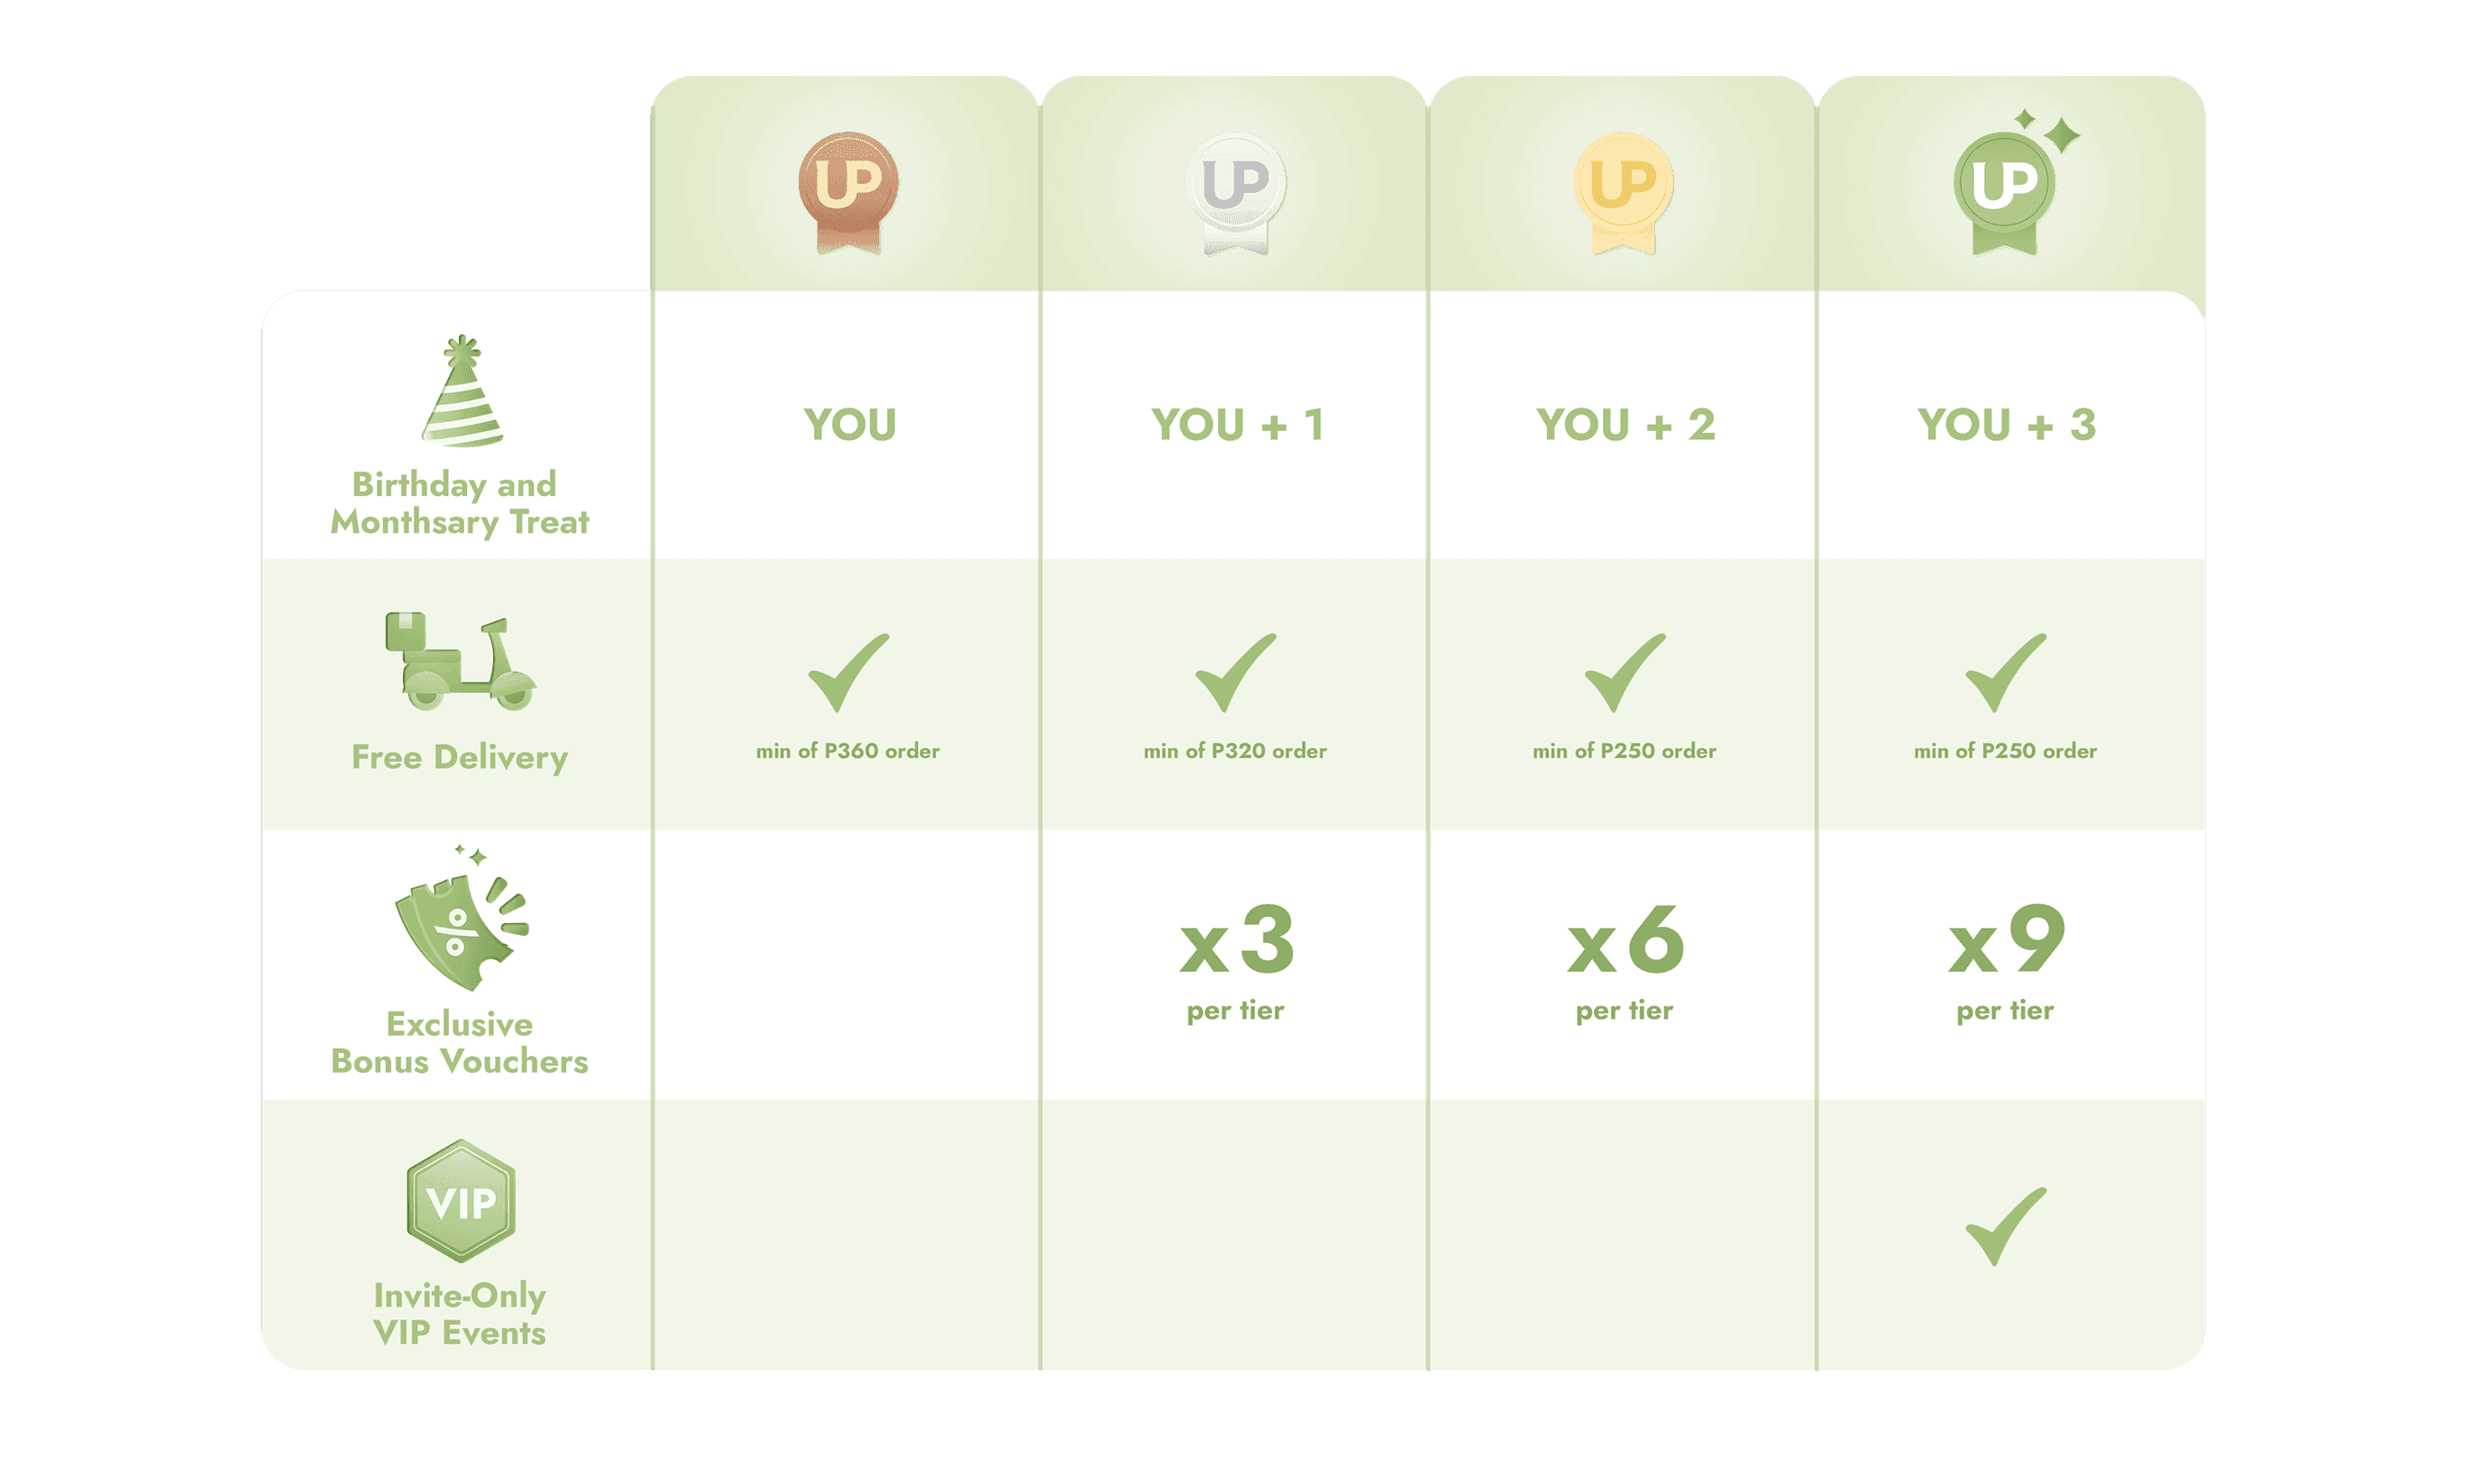

,brand_id,http_status,capture_status,evidence_file,notes
0,BFC021,200,Downloaded; inspection pending,references/website_evidence/loyalty_terms_chec...,
1,BFC002,200,Downloaded; inspection pending,references/website_evidence/loyalty_terms_chec...,
2,BFC002,200,Downloaded; inspection pending,references/website_evidence/loyalty_terms_chec...,


Evidence folder: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/loyalty_terms_check_20261023_195848_351813
No source, promotion, or loyalty records changed.


In [178]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo

import requests
import pandas as pd
from bs4 import BeautifulSoup
from IPython.display import display, Image

# 1. Locate the project.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "source_register.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

capture_folder = (
    project_root
    / "references"
    / "website_evidence"
    / f"loyalty_terms_check_{capture_label}"
)

capture_folder.mkdir(parents=True, exist_ok=True)

# 2. Capture official materials.

targets = [
    {
        "brand_id": "BFC021",
        "filename": "zus_terms.html",
        "url": "https://zuscoffee.ph/terms-and-condition/",
    },
    {
        "brand_id": "BFC002",
        "filename": "pickup_terms.html",
        "url": "https://pickup-coffee.com/terms-conditions",
    },
    {
        "brand_id": "BFC002",
        "filename": "pickup_rewards_table.png",
        "url": (
            "https://d1r9lpkrafbxq0.cloudfront.net/"
            "strapi-cms-readable-media/"
            "tier_table_8634d4cdbf_a864866d61.png"
        ),
    },
]

capture_records = []

for target in targets:
    print("\nChecking:", target["filename"], flush=True)

    record = {
        "brand_id": target["brand_id"],
        "requested_url": target["url"],
        "captured_at": datetime.now(
            ZoneInfo("Asia/Manila")
        ).isoformat(),
        "http_status": pd.NA,
        "final_url": pd.NA,
        "evidence_file": pd.NA,
        "capture_status": "Failed",
        "notes": "",
    }

    try:
        response = requests.get(
            target["url"],
            timeout=30,
        )

        record["http_status"] = response.status_code
        record["final_url"] = response.url

        response.raise_for_status()

        content_type = response.headers.get(
            "Content-Type", ""
        ).lower()

        is_image = target["filename"].endswith(".png")

        if is_image and not content_type.startswith("image/"):
            record["notes"] = (
                "Response was not identified as an image."
            )

        else:
            file_path = capture_folder / target["filename"]
            file_path.write_bytes(response.content)

            record["evidence_file"] = file_path.relative_to(
                project_root
            ).as_posix()

            record["capture_status"] = (
                "Downloaded; inspection pending"
            )

            if is_image:
                print("PICKUP rewards table:")
                display(Image(filename=str(file_path)))

            else:
                soup = BeautifulSoup(
                    response.content,
                    "html.parser",
                )

                for element in soup(
                    ["script", "style", "noscript"]
                ):
                    element.decompose()

                page_text = soup.get_text(
                    separator="\n",
                    strip=True,
                )

                file_path.with_suffix(".txt").write_text(
                    page_text,
                    encoding="utf-8",
                )

                print(
                    "Page title:",
                    soup.title.get_text(strip=True)
                    if soup.title
                    else "No title",
                )

                print("Text characters:", len(page_text))

    except requests.RequestException as error:
        record["notes"] = str(error)
        print("Capture issue:", error)

    capture_records.append(record)

    # Preserve progress after each request.
    pd.DataFrame(capture_records).to_csv(
        capture_folder / "capture_log.csv",
        index=False,
    )

capture_log = pd.DataFrame(capture_records)

display(
    capture_log[
        [
            "brand_id",
            "http_status",
            "capture_status",
            "evidence_file",
            "notes",
        ]
    ]
)

print("Evidence folder:", capture_folder)
print("No source, promotion, or loyalty records changed.")

PICKUP rewards table:


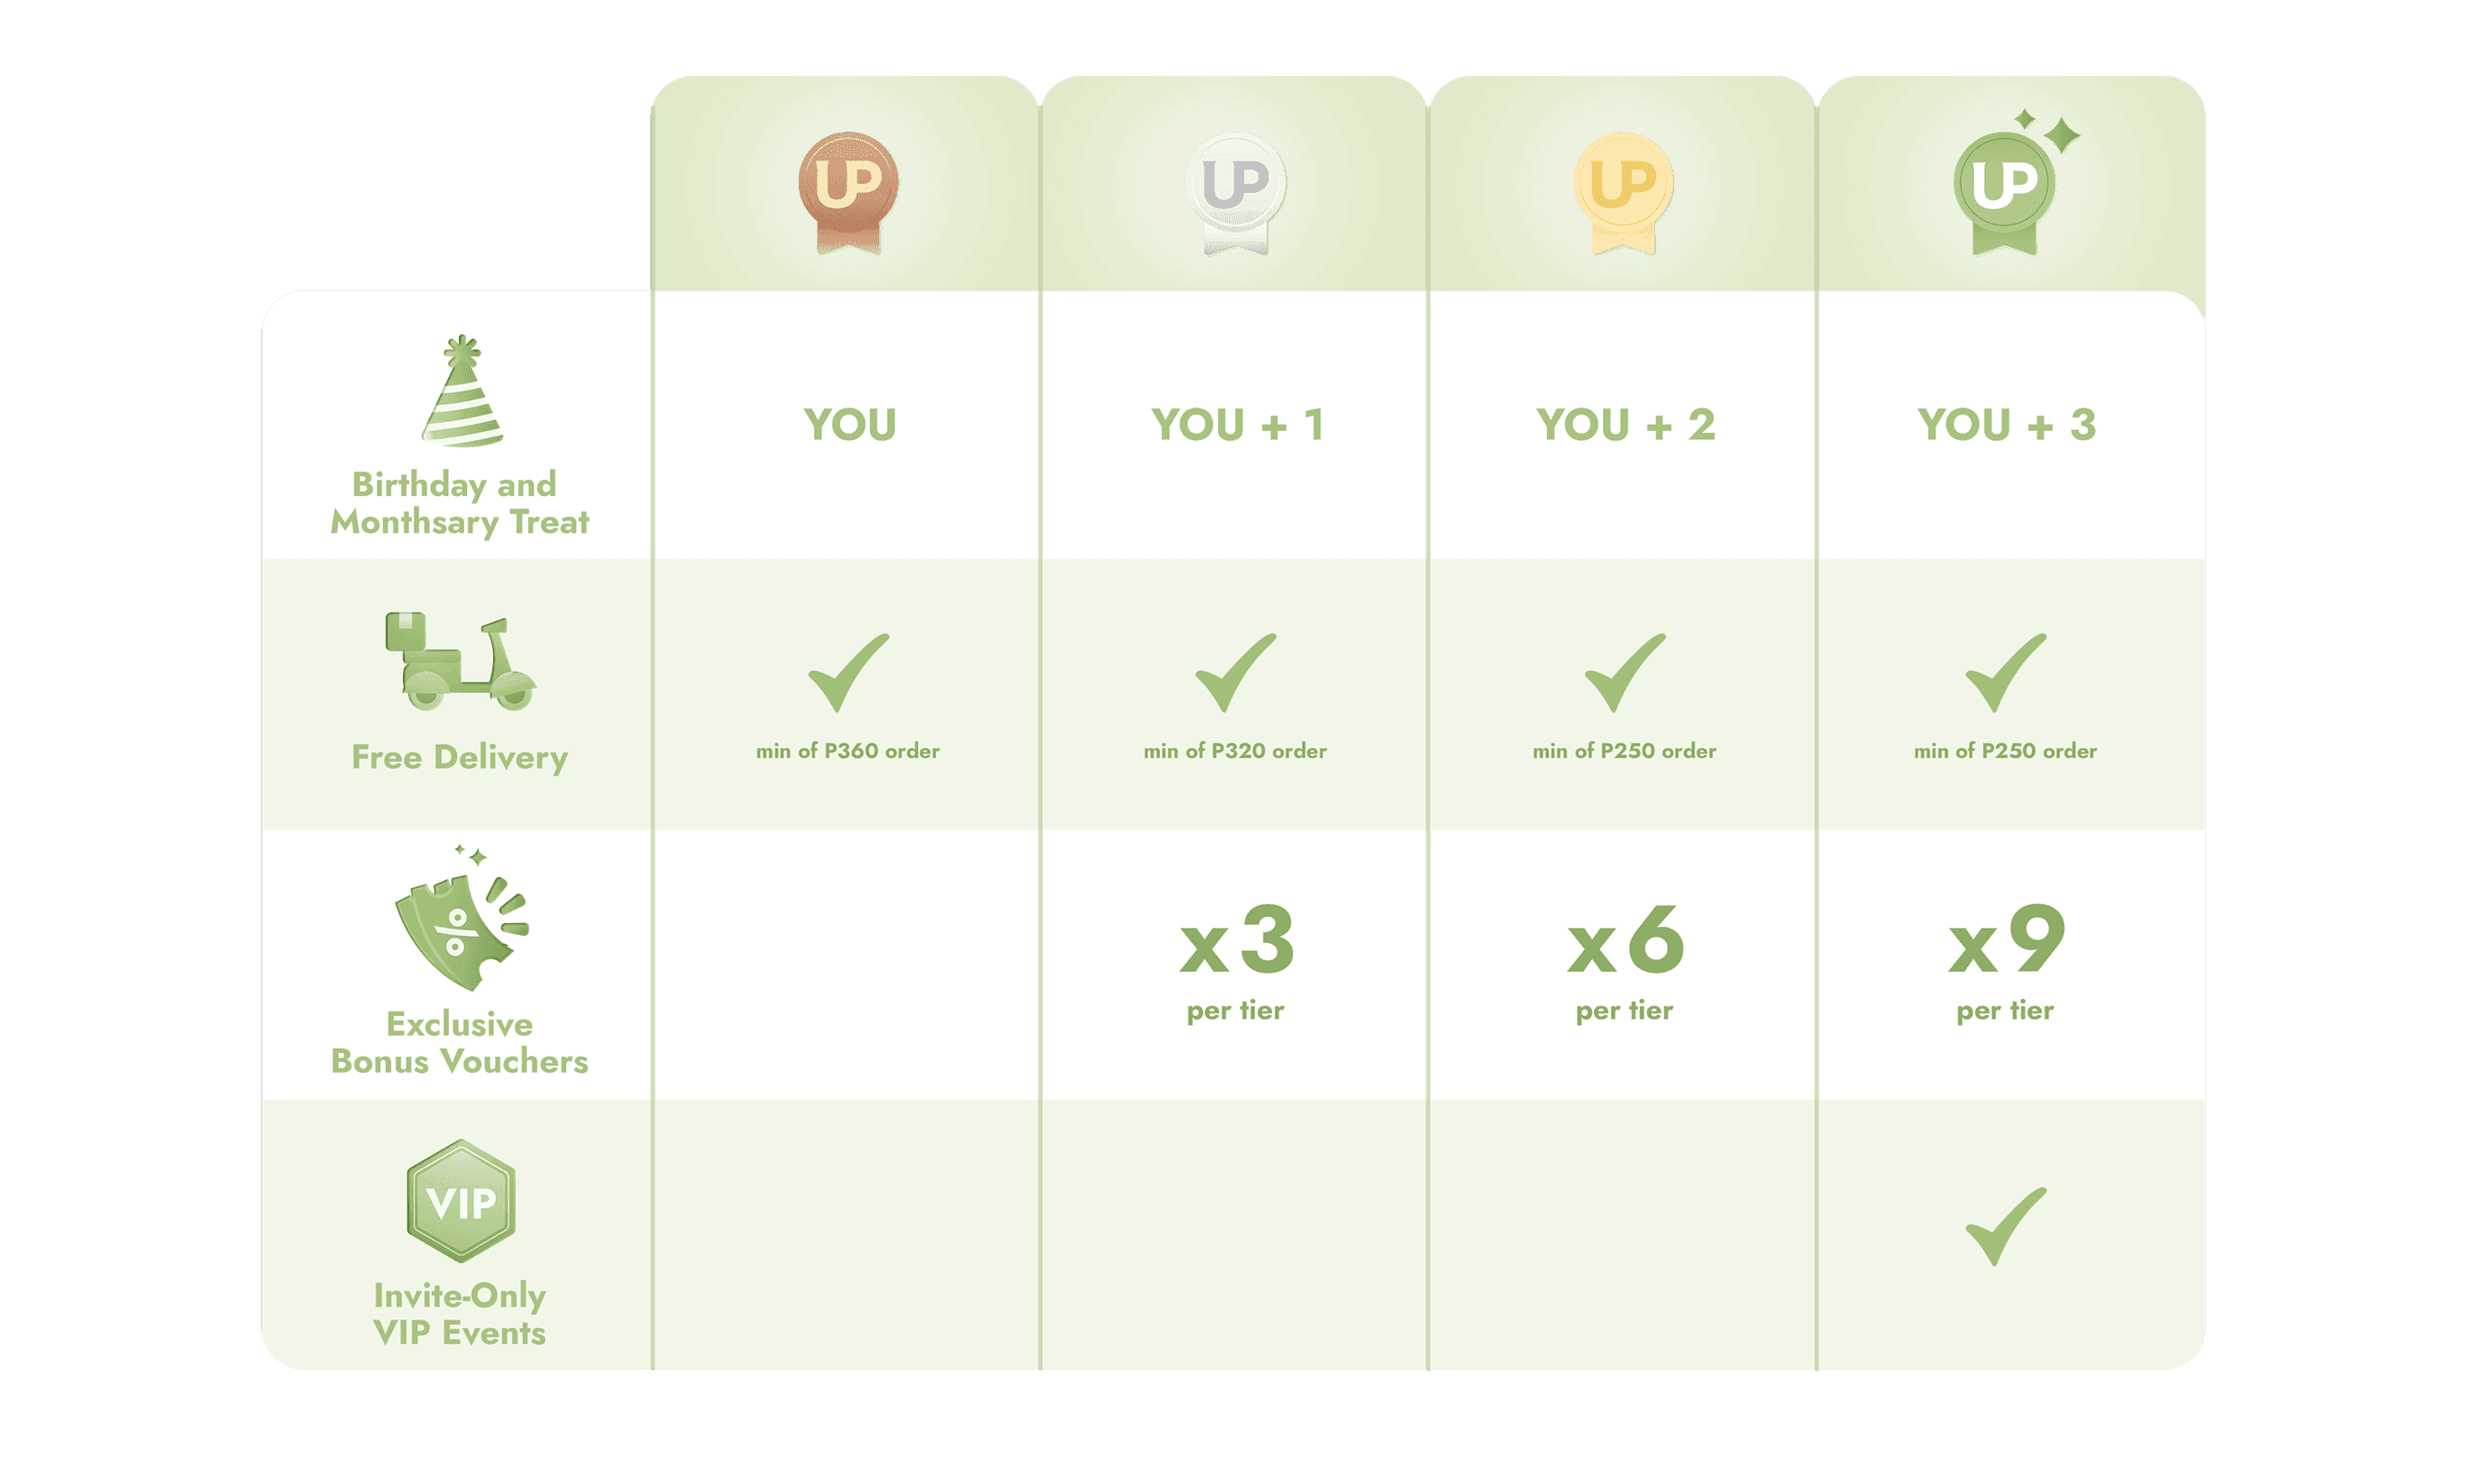


File: zus_terms.txt
Matching terms: 9

Passage 1:
 and the amount that can be reloaded for the ZUS Balance each time ranges from ₱200 to ₱2,000. These maximum and minimum amounts may be changed at any time by notifying you at the point of sale or in the Application where such changes do not constitute a variation of these Terms of Use. Payments : Loading of ZUS Balance and payments for the Service may be made directly in the Application via the addition of electronic bank transfers, credit card or debit card, or any other e-Wallet providers, receipt of ZUS Gift Card or via such 

Passage 2:
or the Company’s goods and services. Therefore, ZUS Balance is not a credit line, overdraft facility or deposit account and the monetary value associated with ZUS Balance does not earn interest, dividends or any other earnings nor is there any deposit insurance or protection relating to it. The value associated with ZUS Balance is not insured or guaranteed by any person or entity. Unauthorised Use 

In [179]:
from pathlib import Path
import re

from IPython.display import display, Image

# Use project_root established in the preceding cell.

evidence_folder = (
    project_root
    / "references"
    / "website_evidence"
    / "loyalty_terms_check_20261023_195848_351813"
)

# 1. Display the original rewards table.

image_path = evidence_folder / "pickup_rewards_table.png"

if not image_path.is_file():
    raise FileNotFoundError(f"Missing image: {image_path}")

print("PICKUP rewards table:")
display(
    Image(
        filename=str(image_path),
        width=1200,
    )
)

# 2. Inspect terms relevant to earning and redemption.

search_pattern = re.compile(
    r"\b(points?|loyalty|cashback|earn\w*|"
    r"expir\w*|voucher\w*|first[\s-]?time|"
    r"new users?|new members?|buy\s*1|"
    r"free\s*1|minimum spend)\b",
    flags=re.IGNORECASE,
)

for filename in ["zus_terms.txt", "pickup_terms.txt"]:
    file_path = evidence_folder / filename

    if not file_path.is_file():
        raise FileNotFoundError(f"Missing text file: {file_path}")

    page_text = " ".join(
        file_path.read_text(encoding="utf-8").split()
    )

    matches = list(search_pattern.finditer(page_text))

    print("\nFile:", filename)
    print("Matching terms:", len(matches))

    excerpt_ranges = []

    for match in matches:
        start = max(0, match.start() - 180)
        end = min(len(page_text), match.end() + 350)

        if excerpt_ranges and start <= excerpt_ranges[-1][1]:
            excerpt_ranges[-1][1] = max(
                excerpt_ranges[-1][1],
                end,
            )
        else:
            excerpt_ranges.append([start, end])

    if not excerpt_ranges:
        print("No selected terms found. Full document still requires review.")

    for number, (start, end) in enumerate(
        excerpt_ranges,
        start=1,
    ):
        print(f"\nPassage {number}:")
        print(page_text[start:end])

print("\nNo web requests made. No project files changed.")

In [180]:
from pathlib import Path
import pandas as pd
from IPython.display import display

# 1. Locate the project.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "source_register.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

source_path = project_root / "references" / "source_register.csv"
loyalty_path = project_root / "data" / "raw" / "loyalty_programs.csv"
promotion_path = project_root / "data" / "raw" / "promotions.csv"

evidence_folder = (
    project_root
    / "references"
    / "website_evidence"
    / "loyalty_terms_check_20261023_195848_351813"
)

source_register = pd.read_csv(source_path, dtype="string")
loyalty_programs = pd.read_csv(loyalty_path, dtype="string")
promotions = pd.read_csv(promotion_path, dtype="string")

# 2. Validate records and evidence before saving.

for dataset, id_column in [
    (source_register, "source_id"),
    (loyalty_programs, "program_version_id"),
    (promotions, "promotion_id"),
]:
    if dataset[id_column].isna().any():
        raise ValueError(f"Missing values in {id_column}.")

    if dataset[id_column].duplicated().any():
        raise ValueError(f"Duplicate values in {id_column}.")

for filename in ["zus_terms.txt", "pickup_terms.txt"]:
    if not (evidence_folder / filename).is_file():
        raise FileNotFoundError(f"Missing evidence: {filename}")

for record_id, brand_id in [
    ("LOY0001", "BFC021"),
    ("LOY0002", "BFC002"),
]:
    match = loyalty_programs["program_version_id"].eq(record_id)

    if match.sum() != 1:
        raise ValueError(f"Expected one {record_id} record.")

    if loyalty_programs.loc[match, "brand_id"].iloc[0] != brand_id:
        raise ValueError(f"Brand mismatch for {record_id}.")

promo_match = promotions["promotion_id"].eq("PRM0001")

if promo_match.sum() != 1:
    raise ValueError("Expected one PRM0001 record.")

if promotions.loc[promo_match, "brand_id"].iloc[0] != "BFC021":
    raise ValueError("PRM0001 does not belong to ZUS.")

# 3. Register the inspected original terms captures.
# Downloaded image remains unverified and is not registered here.

terms_sources = [
    {
        "brand_id": "BFC021",
        "source_title": "ZUS general application terms inspected",
        "source_url": "https://zuscoffee.ph/terms-and-condition/",
        "filename": "zus_terms.html",
        "notes": (
            "General application terms, not complete introductory "
            "offer mechanics. Promotion specific terms take precedence. "
            "Philippine company named, but Malaysia governing law "
            "reference requires clarification. Numeric earning rate "
            "and specific offer validity not established."
        ),
    },
    {
        "brand_id": "BFC002",
        "source_title": "PICKUP general voucher terms inspected",
        "source_url": "https://pickup-coffee.com/terms-conditions",
        "filename": "pickup_terms.html",
        "notes": (
            "General voucher conditions inspected. Specific voucher "
            "validity and usage conditions remain offer dependent. "
            "No numeric points earning rate or general points "
            "expiry established from these passages."
        ),
    },
]

source_numbers = pd.to_numeric(
    source_register["source_id"].str.extract(
        r"(\d+)$", expand=False
    ),
    errors="raise",
)

next_number = int(source_numbers.max()) + 1
new_sources = []
terms_source_ids = {}

for item in terms_sources:
    existing = source_register["source_title"].eq(
        item["source_title"]
    )

    if existing.any():
        terms_source_ids[item["brand_id"]] = (
            source_register.loc[existing, "source_id"].iloc[0]
        )
        continue

    html_path = evidence_folder / item["filename"]

    if not html_path.is_file():
        raise FileNotFoundError(f"Missing capture: {html_path}")

    source_id = f"SRC{next_number:04d}"
    next_number += 1
    terms_source_ids[item["brand_id"]] = source_id

    new_sources.append(
        {
            "source_id": source_id,
            "brand_id": item["brand_id"],
            "research_question_ids": "RQ03",
            "source_type": "Official website",
            "source_title": item["source_title"],
            "source_url": item["source_url"],
            "collected_date": "2026-10-23",
            "evidence_file": html_path.relative_to(
                project_root
            ).as_posix(),
            "evidence_basis": "Company statement",
            "verification_status": "Verified",
            "access_status": "Accessible",
            "historical_period": "Undetermined",
            "notes": item["notes"],
        }
    )

# 4. Append qualifications without replacing existing source links.

updates = [
    (
        loyalty_programs,
        "program_version_id",
        "LOY0001",
        (
            f"General terms inspected in {terms_source_ids['BFC021']}. "
            "Promotion specific conditions take precedence. "
            "Page contains a Malaysia governing law reference "
            "requiring clarification for Philippine applicability. "
            "Earning rate and expiry remain unresolved."
        ),
    ),
    (
        loyalty_programs,
        "program_version_id",
        "LOY0002",
        (
            f"General voucher terms inspected in "
            f"{terms_source_ids['BFC002']}. "
            "Vouchers have offer dependent validity and redemption "
            "periods and may have usage limits. Combination with "
            "other offers may be restricted. App use applies unless "
            "otherwise stated. Vouchers cannot be exchanged for cash. "
            "Points earning rate and points expiry remain unresolved."
        ),
    ),
    (
        promotions,
        "promotion_id",
        "PRM0001",
        (
            f"General terms inspected in {terms_source_ids['BFC021']}. "
            "They do not establish this offer's qualifying products, "
            "validity, minimum spend, or redemption limit. "
            "Do not infer a fixed saving percentage."
        ),
    ),
]

for dataset, id_column, record_id, note in updates:
    row_index = dataset.index[
        dataset[id_column].eq(record_id)
    ][0]

    existing_note = dataset.at[row_index, "notes"]

    if pd.isna(existing_note):
        existing_note = ""

    if note not in existing_note:
        dataset.at[row_index, "notes"] = (
            existing_note + " | " + note
        ).strip(" |")

if new_sources:
    source_register = pd.concat(
        [
            source_register,
            pd.DataFrame(new_sources).reindex(
                columns=source_register.columns
            ),
        ],
        ignore_index=True,
    )

source_register.to_csv(source_path, index=False)
loyalty_programs.to_csv(loyalty_path, index=False)
promotions.to_csv(promotion_path, index=False)

print("Sources added:", len(new_sources))
print("Total sources:", len(source_register))
print("Loyalty records:", len(loyalty_programs))
print("Promotion records:", len(promotions))

display(
    loyalty_programs[
        ["program_version_id", "brand_id", "earning_rules", "notes"]
    ]
)

print("No numeric earning rates or expiry dates were inferred.")
print("PICKUP rewards image still requires visual inspection.")

Sources added: 2
Total sources: 86
Loyalty records: 3
Promotion records: 1


,program_version_id,brand_id,earning_rules,notes
0,LOY0001,BFC021,App purchases earn points; earning rate unreso...,"Expiry, exclusions, reward values, and effecti..."
1,LOY0002,BFC002,Purchase points; earning rate unresolved,Expiry and qualifying spend unresolved. Do not...
2,LOY0003,BFC022,One Star per PHP 25 qualifying card spend in s...,Redemption levels are not membership status ti...


No numeric earning rates or expiry dates were inferred.
PICKUP rewards image still requires visual inspection.


In [181]:
from pathlib import Path
import pandas as pd
from IPython.display import display

# 1. Locate the project and load records.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "source_register.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

source_path = project_root / "references" / "source_register.csv"
loyalty_path = project_root / "data" / "raw" / "loyalty_programs.csv"

image_path = (
    project_root
    / "references"
    / "website_evidence"
    / "loyalty_terms_check_20261023_195848_351813"
    / "pickup_rewards_table.png"
)

if not image_path.is_file():
    raise FileNotFoundError(f"Missing rewards image: {image_path}")

source_register = pd.read_csv(source_path, dtype="string")
loyalty_programs = pd.read_csv(loyalty_path, dtype="string")

loyalty_mask = loyalty_programs["program_version_id"].eq("LOY0002")

if loyalty_mask.sum() != 1:
    raise ValueError("Expected exactly one LOY0002 record.")

if loyalty_programs.loc[loyalty_mask, "brand_id"].iloc[0] != "BFC002":
    raise ValueError("LOY0002 does not belong to PICKUP.")

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found.")

# 2. Register the inspected image once.

source_title = "PICKUP Club rewards table image inspected"

existing_source = source_register["source_title"].eq(source_title)
sources_added = 0

if existing_source.any():
    source_id = source_register.loc[
        existing_source, "source_id"
    ].iloc[0]

else:
    source_numbers = pd.to_numeric(
        source_register["source_id"].str.extract(
            r"(\d+)$", expand=False
        ),
        errors="raise",
    )

    source_id = f"SRC{int(source_numbers.max()) + 1:04d}"

    new_source = pd.DataFrame(
        [{
            "source_id": source_id,
            "brand_id": "BFC002",
            "research_question_ids": "RQ03",
            "source_type": "Official website rewards image",
            "source_title": source_title,
            "source_url": (
                "https://d1r9lpkrafbxq0.cloudfront.net/"
                "strapi-cms-readable-media/"
                "tier_table_8634d4cdbf_a864866d61.png"
            ),
            "collected_date": "2026-10-23",
            "evidence_file": image_path.relative_to(
                project_root
            ).as_posix(),
            "evidence_basis": "Company statement",
            "verification_status": "Verified",
            "access_status": "Accessible",
            "historical_period": "Undetermined",
            "notes": (
                "Image linked from the official PICKUP Club page. "
                "Columns interpreted in the page's Bronze, Silver, "
                "Gold, Emerald order using the matching badges. "
                "Published benefits only; redemption not tested. "
                "No numeric points earning rate shown."
            ),
        }]
    ).reindex(columns=source_register.columns)

    source_register = pd.concat(
        [source_register, new_source],
        ignore_index=True,
    )

    sources_added = 1

# 3. Append supported benefits without removing earlier findings.

row_index = loyalty_programs.index[loyalty_mask][0]

additional_benefits = (
    "Rewards table advertises free delivery with minimum orders "
    "of PHP 360 Bronze, PHP 320 Silver, PHP 250 Gold, and "
    "PHP 250 Emerald. Bonus vouchers shown: Silver 3 per tier, "
    "Gold 6 per tier, Emerald 9 per tier. "
    "Emerald marked for invite only VIP events."
)

additional_note = (
    f"Benefits image inspected in {source_id}. "
    "Blank image cells do not establish absence of benefits. "
    "Voucher values, delivery limits, validity, qualifying "
    "order rules, and points earning rate remain unresolved."
)

for column, addition in [
    ("benefits", additional_benefits),
    ("notes", additional_note),
]:
    existing_text = loyalty_programs.at[row_index, column]

    if pd.isna(existing_text):
        existing_text = ""

    if addition not in existing_text:
        loyalty_programs.at[row_index, column] = (
            existing_text + " | " + addition
        ).strip(" |")

source_register.to_csv(source_path, index=False)
loyalty_programs.to_csv(loyalty_path, index=False)

print("Sources added:", sources_added)
print("Total sources:", len(source_register))
print("Total loyalty records:", len(loyalty_programs))

display(
    loyalty_programs.loc[
        loyalty_mask,
        [
            "program_version_id",
            "source_id",
            "earning_rules",
            "benefits",
            "notes",
        ],
    ]
)

print("Earning rules, expiry rules, and effective dates unchanged.")

Sources added: 1
Total sources: 87
Total loyalty records: 3


,program_version_id,source_id,earning_rules,benefits,notes
1,LOY0002,SRC0064,Purchase points; earning rate unresolved,"Tier perks, birthday benefits, early access | ...",Expiry and qualifying spend unresolved. Do not...


Earning rules, expiry rules, and effective dates unchanged.


## Franchise Offer Collection Checkpoint

### Purpose

Assess the evidence collected for RQ08 before comparing packages.

### Comparison Rules

Compare offers within the same market and store format.

Keep franchise fees, advertised package costs, and total investment
separate. Do not treat one as another.

Unknown fees remain unknown. A published statement of no royalty
requires supporting evidence and must not be assumed from a blank field.

Published profitability or payback claims are company claims,
not independently verified investment outcomes.

### Business Implication

This checkpoint identifies missing information needed for a fair
franchise comparison. It does not rank investment attractiveness.

In [182]:
from pathlib import Path
import pandas as pd
from IPython.display import display

# 1. Locate the project and reload saved records.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "source_register.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

raw_path = project_root / "data" / "raw"

franchise_offers = pd.read_csv(
    raw_path / "franchise_offers.csv",
    dtype="string",
)

competitor_master = pd.read_csv(
    raw_path / "competitor_master.csv",
    dtype="string",
)

source_register = pd.read_csv(
    project_root / "references" / "source_register.csv",
    dtype="string",
)

# 2. Validate identifiers before joining.

for dataset, id_column in [
    (franchise_offers, "package_version_id"),
    (competitor_master, "brand_id"),
    (source_register, "source_id"),
]:
    if dataset[id_column].isna().any():
        raise ValueError(f"Missing values in {id_column}.")

    if dataset[id_column].duplicated().any():
        raise ValueError(f"Duplicate values in {id_column}.")

franchise_review = franchise_offers.merge(
    competitor_master[["brand_id", "brand_name"]],
    on="brand_id",
    how="left",
    validate="many_to_one",
)

# 3. Show the actual recorded package details.
# Print each record separately to avoid truncated tables.

detail_fields = [
    "package_version_id",
    "brand_name",
    "source_id",
    "observed_date",
    "effective_date",
    "package_name",
    "market_scope",
    "store_format",
    "currency",
    "total_investment_min",
    "total_investment_max",
    "franchise_fee",
    "investment_inclusions",
    "investment_exclusions",
    "tax_basis",
    "royalty_terms",
    "marketing_fee_terms",
    "other_recurring_fees",
    "agreement_term",
    "renewal_terms",
    "space_requirements",
    "training_support",
    "operational_support",
    "supply_obligations",
    "availability_status",
    "notes",
]

for _, record in franchise_review.iterrows():
    print("\nPackage:", record["package_version_id"])
    print("Brand:", record["brand_name"])

    for field in detail_fields[2:]:
        value = record[field]

        if pd.notna(value) and str(value).strip():
            print(f"{field}: {value}")

# 4. Report missing core comparison information.
# This is a completeness screen, not an evidence verification.

core_fields = [
    "market_scope",
    "store_format",
    "currency",
    "total_investment_min",
    "total_investment_max",
    "investment_inclusions",
    "investment_exclusions",
    "tax_basis",
    "royalty_terms",
    "marketing_fee_terms",
    "other_recurring_fees",
    "agreement_term",
    "renewal_terms",
    "space_requirements",
    "supply_obligations",
    "effective_date",
]

missing_summary = []

for field in core_fields:
    missing_count = (
        franchise_offers[field]
        .fillna("")
        .str.strip()
        .eq("")
        .sum()
    )

    missing_summary.append(
        {
            "field": field,
            "missing_records": int(missing_count),
            "total_records": len(franchise_offers),
        }
    )

print("\nMissing core field counts:")
display(pd.DataFrame(missing_summary))

# 5. Check source references and evidence paths.

unknown_sources = franchise_offers.loc[
    ~franchise_offers["source_id"].isin(
        source_register["source_id"]
    ),
    ["package_version_id", "source_id"],
]

print("\nUnknown or missing primary source references:")
display(unknown_sources)

franchise_evidence = source_register.loc[
    source_register["source_id"].isin(
        franchise_offers["source_id"]
    ),
    [
        "source_id",
        "source_title",
        "verification_status",
        "evidence_file",
    ],
].copy()

file_status = []

for evidence_file in franchise_evidence["evidence_file"]:
    if pd.isna(evidence_file) or not evidence_file.strip():
        file_status.append(False)
    else:
        file_status.append(
            (project_root / evidence_file).is_file()
        )

franchise_evidence["file_exists"] = file_status

print("\nPrimary franchise evidence:")
display(franchise_evidence)

print("\nTotal franchise records:", len(franchise_offers))
print("No web requests made. No files changed.")


Package: FRN0001
Brand: Potato Corner
source_id: SRC0060
observed_date: 2026-10-23
package_name: Philippine FAQ terms; package format unspecified
market_scope: Philippines
currency: PHP
franchise_fee: 150000
royalty_terms: Company states no royalty fees
renewal_terms: 50 percent of current franchise fee; FAQ illustration PHP 75000 for another five years
space_requirements: At least 6 square meters; frontage at least 2 meters
operational_support: Company assesses applicant proposed location
availability_status: Published inquiry; site approval required
notes: Franchise fee is not total investment. Full payment upon contract signing stated. Initial term, format, inclusions, tax basis, marketing fees, and effective date unresolved. No profitability claims accepted as verified outcomes.

Package: FRN0002
Brand: But First, Coffee
source_id: SRC0062
observed_date: 2026-10-23
package_name: Published franchise format overview
market_scope: Philippines
store_format: Inline store; kiosk; traile

,field,missing_records,total_records
0,market_scope,0,11
1,store_format,7,11
2,currency,0,11
3,total_investment_min,11,11
4,total_investment_max,11,11
5,investment_inclusions,10,11
6,investment_exclusions,11,11
7,tax_basis,11,11
8,royalty_terms,9,11
9,marketing_fee_terms,11,11



Unknown or missing primary source references:


,package_version_id,source_id



Primary franchise evidence:


,source_id,source_title,verification_status,evidence_file,file_exists
59,SRC0060,Potato Corner Philippine franchise FAQ recheck,Verified,references/website_evidence/manual_20261023/SR...,True
61,SRC0062,BFC published franchise formats and support,Verified,references/website_evidence/manual_20261023/SR...,True
66,SRC0067,Coffee First published franchise support,Verified,references/website_evidence/manual_20261023/SR...,True
67,SRC0068,Bo's Coffee Philippine franchise support,Verified,references/website_evidence/manual_20261023/SR...,True
68,SRC0069,Moonleaf franchise formats and combined brand ...,Verified,references/website_evidence/manual_20261023/SR...,True
69,SRC0070,Chatime Philippine franchise inquiry,Verified,references/website_evidence/manual_20261023/SR...,True
70,SRC0071,PICKUP franchise formats and support,Verified,references/website_evidence/manual_20261023/SR...,True
71,SRC0072,Juan Cafe published franchise fee statements,Verified,references/website_evidence/manual_20261023/SR...,True
72,SRC0073,Macao Imperial Tea franchise inquiry link,Verified,references/website_evidence/manual_20261023/SR...,True
74,SRC0075,BigBrew franchise promotion,Verified,references/website_evidence/manual_20261023/SR...,True



Total franchise records: 11
No web requests made. No files changed.


### Franchise Collection Findings

Eleven franchise records have valid primary source references
and existing evidence files.

No record currently establishes a complete total investment basis.
Published franchise fees, package starting costs, and applicant
budget categories represent different measures.

Most records describe inquiries, support, or available formats.
They are not complete franchise quotations.

### Business Implication

The evidence supports comparing published recruitment routes,
selected support descriptions, and explicitly stated terms.

It does not support ranking franchise affordability, profitability,
payback, or overall investment value.

### Remaining Collection Requirement

Obtain dated, format specific package documents covering:

1. Franchise fee and package cost
2. Total investment definition
3. Included and excluded costs
4. Taxes, construction, equipment, and initial inventory
5. Royalty, marketing, and other recurring fees
6. Agreement duration and renewal conditions
7. Space and site requirements
8. Training, operational support, and supply obligations
9. Quotation validity and location applicability

Keep company performance claims separate from independently
observed outcomes.

In [183]:
from pathlib import Path
import re

import pandas as pd
from bs4 import BeautifulSoup
from IPython.display import display

# 1. Locate the project and load saved records.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "source_register.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

source_register = pd.read_csv(
    project_root / "references" / "source_register.csv",
    dtype="string",
)

franchise_offers = pd.read_csv(
    project_root / "data" / "raw" / "franchise_offers.csv",
    dtype="string",
)

# 2. Select original official website captures for relevant brands.
# Exclude research transcriptions and customer review evidence.

official_source = source_register["source_type"].str.contains(
    "official|company website",
    case=False,
    regex=True,
    na=False,
)

transcription_source = source_register["source_type"].str.contains(
    "transcription",
    case=False,
    na=False,
)

selected_sources = source_register.loc[
    source_register["brand_id"].isin(
        franchise_offers["brand_id"].dropna()
    )
    & source_register["verification_status"].eq("Verified")
    & official_source
    & ~transcription_source
].copy()

# Match specific commercial terms.
# Currency matches alone may also return menu prices.

terms_pattern = re.compile(
    r"₱\s*[\d,]+"
    r"|\b(?:PHP|P)\s*[\d,]{3,}"
    r"|\b(?:franchise fee|package cost|investment|"
    r"royalt\w*|renewal|agreement term|contract term|"
    r"marketing fee|inclusions?|exclusions?|"
    r"VAT|tax inclusive|tax exclusive|"
    r"square meters?|sqm)\b",
    flags=re.IGNORECASE,
)

inspection_records = []

# 3. Read the saved captures and extract candidate passages.

for _, source in selected_sources.iterrows():
    record = {
        "source_id": source["source_id"],
        "brand_id": source["brand_id"],
        "source_title": source["source_title"],
        "source_url": source["source_url"],
        "inspected_file": pd.NA,
        "inspection_status": "",
        "candidate_passages": "",
    }

    if pd.isna(source["evidence_file"]):
        record["inspection_status"] = "No evidence path recorded"
        inspection_records.append(record)
        continue

    evidence_path = project_root / source["evidence_file"]
    text_path = evidence_path.with_suffix(".txt")

    if text_path.is_file():
        page_text = text_path.read_text(encoding="utf-8")
        inspected_path = text_path

    elif (
        evidence_path.is_file()
        and evidence_path.suffix.lower() in [".html", ".htm"]
    ):
        soup = BeautifulSoup(
            evidence_path.read_bytes(),
            "html.parser",
        )

        for element in soup(["script", "style", "noscript"]):
            element.decompose()

        page_text = soup.get_text(separator=" ", strip=True)
        inspected_path = evidence_path

    else:
        record["inspection_status"] = (
            "Text or HTML unavailable; PDF or image inspection may be needed"
        )
        inspection_records.append(record)
        continue

    page_text = " ".join(page_text.split())

    record["inspected_file"] = inspected_path.relative_to(
        project_root
    ).as_posix()

    matches = list(terms_pattern.finditer(page_text))

    if not matches:
        record["inspection_status"] = "No screening terms found"
        inspection_records.append(record)
        continue

    excerpt_ranges = []

    for match in matches:
        start = max(0, match.start() - 180)
        end = min(len(page_text), match.end() + 350)

        if excerpt_ranges and start <= excerpt_ranges[-1][1]:
            excerpt_ranges[-1][1] = max(
                excerpt_ranges[-1][1],
                end,
            )
        else:
            excerpt_ranges.append([start, end])

    record["candidate_passages"] = "\n\n".join(
        page_text[start:end]
        for start, end in excerpt_ranges
    )

    record["inspection_status"] = (
        "Candidate passages found; interpretation pending"
    )

    inspection_records.append(record)

franchise_evidence_review = pd.DataFrame(
    inspection_records,
    columns=[
        "source_id",
        "brand_id",
        "source_title",
        "source_url",
        "inspected_file",
        "inspection_status",
        "candidate_passages",
    ],
)

# 4. Display the evidence without truncated passage columns.

print("Original official sources screened:", len(selected_sources))

for _, record in franchise_evidence_review.iterrows():
    print("\nSource:", record["source_id"])
    print("Brand:", record["brand_id"])
    print("Title:", record["source_title"])
    print("Status:", record["inspection_status"])

    if record["candidate_passages"]:
        print("Passages:")
        print(record["candidate_passages"])

print("\nScreening summary:")

display(
    franchise_evidence_review.groupby(
        "inspection_status"
    ).size().reset_index(
        name="number_of_sources"
    )
)

print("\nNo web requests made.")
print("No franchise records or other project files changed.")

Original official sources screened: 19

Source: SRC0001
Brand: BFC001
Title: But First, Coffee franchise page
Status: Candidate passages found; interpretation pending
Passages:
ven brand, trusted support, and a vision for more. Branches Nationwide Year Founded Multi-Branch Franchisees Franchise Formats Choose a format that fits your vision, location, and investment goals. From full-service In-Line Stores to flexible Indoor/Outdoor Trailers and Indoor/Outdoor Kiosks , But First, Coffee offers scalable franchise options designed to bring your coffee business closer to your market. In-Line Store A full café experience designed for high-visibility locations, offering a spacious setup for customers to dine, work,

Source: SRC0002
Brand: BFC002
Title: PICKUP COFFEE franchise page
Status: No screening terms found

Source: SRC0003
Brand: BFC003
Title: Juan Cafe about page
Status: Candidate passages found; interpretation pending
Passages:
lipino countrymen. Our Mission In order for the vision t

,inspection_status,number_of_sources
0,Candidate passages found; interpretation pending,11
1,No screening terms found,7
2,Text or HTML unavailable; PDF or image inspect...,1



No web requests made.
No franchise records or other project files changed.


In [184]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo

import requests
import pandas as pd
from bs4 import BeautifulSoup

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

source_path = project_root / "references" / "source_register.csv"

if not source_path.is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

source_register = pd.read_csv(source_path, dtype="string")

source_match = source_register["source_id"].eq("SRC0076")

if source_match.sum() != 1:
    raise ValueError("Expected exactly one SRC0076 record.")

source = source_register.loc[source_match].iloc[0]

if source["brand_id"] != "BFC015":
    raise ValueError("SRC0076 does not belong to Famous Belgian Waffles.")

if pd.isna(source["source_url"]):
    raise ValueError("SRC0076 has no source URL.")

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

capture_folder = (
    project_root
    / "references"
    / "website_evidence"
    / f"fbw_package_check_{capture_label}"
)

capture_folder.mkdir(parents=True, exist_ok=True)

try:
    response = requests.get(
        source["source_url"],
        timeout=30,
    )

except requests.RequestException as error:
    print("Request failed:", error)

else:
    # Preserve the response without automatically accepting its content.
    (capture_folder / "response.html").write_bytes(
        response.content
    )

    pd.DataFrame(
        [{
            "requested_url": source["source_url"],
            "final_url": response.url,
            "http_status": response.status_code,
            "captured_at": capture_time.isoformat(),
            "inspection_status": "Pending",
        }]
    ).to_csv(
        capture_folder / "capture_log.csv",
        index=False,
    )

    print("HTTP status:", response.status_code)
    print("Final URL:", response.url)

    if response.status_code == 200:
        soup = BeautifulSoup(
            response.content,
            "html.parser",
        )

        for element in soup(["script", "style", "noscript"]):
            element.decompose()

        page_text = soup.get_text(
            separator="\n",
            strip=True,
        )

        (capture_folder / "page_text.txt").write_text(
            page_text,
            encoding="utf-8",
        )

        print(
            "Page title:",
            soup.title.get_text(strip=True)
            if soup.title
            else "No title",
        )

        print("\nPackage page text:\n")
        print(page_text)

    else:
        print("Unsuccessful access. Do not accept as package evidence.")

    print("\nEvidence folder:", capture_folder)

print("No source or franchise records changed.")

HTTP status: 200
Final URL: https://famousbelgianwaffles.com/franchise/
Page title: Franchise - Famous Belgian Waffles

Package page text:

Franchise - Famous Belgian Waffles
Home
Products
Opportunity
Franchise With Us
Become a Supplier Partner
Careers
Party & Events
About
Contact Us →
Menu
Home
Products
Opportunity
Franchise With Us
Become a Supplier Partner
Careers
Party & Events
About
Contact Us →
Be Part of a
Nationwide Favorite!
Start Your Own Waffle Business !
Start Your Franchise Journey !  →
Block
Be Part of a
Nationwide Favorite!
Start Your Own Waffle Business!
Start Your Franchise Journey !  →
Be Part of a
Nationwide Favorite!
Start Your Own Waffle Business !
Start Your Franchise Journey !  →
Famous Belgian Waffles Package Inclusions
We have all the tools you will need to set up your Famous Belgian Waffles franchise successfully
Use of
Trademark
Use of Trademark
Get the privilege of using our registered trademark within the duration of your contract.
Initial
Inventory
Initial

In [186]:
from pathlib import Path
import pandas as pd
from IPython.display import display

# 1. Locate the project and reload saved files.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "source_register.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

source_path = project_root / "references" / "source_register.csv"
franchise_path = project_root / "data" / "raw" / "franchise_offers.csv"

evidence_folder = (
    project_root
    / "references"
    / "website_evidence"
    / "fbw_package_check_20261023_201320_351280"
)

html_path = evidence_folder / "response.html"
text_path = evidence_folder / "page_text.txt"

for file_path in [html_path, text_path]:
    if not file_path.is_file():
        raise FileNotFoundError(f"Missing evidence: {file_path}")

source_register = pd.read_csv(source_path, dtype="string")
franchise_offers = pd.read_csv(franchise_path, dtype="string")

for dataset, id_column in [
    (source_register, "source_id"),
    (franchise_offers, "package_version_id"),
]:
    if dataset[id_column].isna().any():
        raise ValueError(f"Missing values in {id_column}.")

    if dataset[id_column].duplicated().any():
        raise ValueError(f"Duplicate values in {id_column}.")

cart_match = franchise_offers["package_version_id"].eq("FRN0011")

if cart_match.sum() != 1:
    raise ValueError("Expected exactly one FRN0011 record.")

# Store the row index before making any additions.
cart_index = franchise_offers.index[cart_match][0]

if franchise_offers.at[cart_index, "brand_id"] != "BFC015":
    raise ValueError("FRN0011 does not belong to Famous Belgian Waffles.")

# 2. Preserve a backup and add the package cost field.

backup_path = franchise_path.with_name(
    "franchise_offers_before_fbw_format_expansion.csv"
)

if not backup_path.exists():
    backup_path.write_bytes(franchise_path.read_bytes())

if "advertised_package_start_php" not in franchise_offers.columns:
    franchise_offers["advertised_package_start_php"] = pd.NA

# 3. Prepare the source record without saving yet.

source_title = "Famous Belgian Waffles five format package capture"
source_match = source_register["source_title"].eq(source_title)

if source_match.sum() > 1:
    raise ValueError("Multiple matching source records found.")

new_sources = []

if source_match.any():
    source_id = source_register.loc[
        source_match, "source_id"
    ].iloc[0]

else:
    source_numbers = pd.to_numeric(
        source_register["source_id"].str.extract(
            r"(\d+)$", expand=False
        ),
        errors="raise",
    )

    source_id = f"SRC{int(source_numbers.max()) + 1:04d}"

    new_sources.append(
        {
            "source_id": source_id,
            "brand_id": "BFC015",
            "research_question_ids": "RQ08",
            "source_type": "Official website",
            "source_title": source_title,
            "source_url": "https://famousbelgianwaffles.com/franchise/",
            "collected_date": "2026-10-23",
            "evidence_file": html_path.relative_to(
                project_root
            ).as_posix(),
            "evidence_basis": "Company statement",
            "verification_status": "Verified",
            "access_status": "Accessible",
            "historical_period": "Undetermined",
            "notes": (
                "Five formats and advertised package starting costs "
                "inspected. Not established as total investment "
                "or franchise fee. Effective date unknown."
            ),
        }
    )

# 4. Prepare common published terms.

common_values = {
    "brand_id": "BFC015",
    "source_id": source_id,
    "observed_date": "2026-10-23",
    "market_scope": "Philippines",
    "currency": "PHP",
    "agreement_term": "Three years; subject to renewal",
    "renewal_terms": "Renewal permitted; fees and conditions unresolved",
    "investment_inclusions": (
        "Page lists trademark use, starter inventory, operating "
        "system, training, lease assistance and opening support. "
        "Format specific quotation confirmation required."
    ),
    "training_support": "Initial crew training and orientation",
    "operational_support": (
        "Lease assistance, opening support and ongoing marketing. "
        "Page states opening assistance three days after opening; "
        "duration and schedule require clarification."
    ),
    "supply_obligations": (
        "Access to proprietary ingredients and packaging. "
        "Purchase obligations unresolved."
    ),
    "availability_status": (
        "Published package starting cost; inquiry required"
    ),
    "notes": (
        f"Original package capture: {source_id}; earlier Cart "
        "transcription retained in SRC0076. Starting cost is "
        "not verified total investment or franchise fee. "
        "Taxes, construction, recurring fees, site costs and "
        "exclusions unresolved. Page excludes Inline from its "
        "stated Metro Manila setup delivery benefit. "
        "Do not interpret this benefit as free store construction."
    ),
}

# 5. Update Cart before appending new rows.

cart_values = common_values.copy()
cart_values["package_name"] = "Cart advertised package starting cost"
cart_values["store_format"] = "Cart"
cart_values["advertised_package_start_php"] = "780000"
cart_values["space_requirements"] = "4 square meters"

for column, value in cart_values.items():
    franchise_offers.at[cart_index, column] = value

# 6. Prepare the four additional formats separately.

other_formats = [
    ["Small Fit In", "580000", "4 square meters"],
    ["Kiosk", "880000", "4 to 8 square meters"],
    ["Counter", "980000", "8 square meters and above"],
    ["Inline", "680000", "12 square meters and above"],
]

existing_numbers = pd.to_numeric(
    franchise_offers["package_version_id"].str.extract(
        r"(\d+)$", expand=False
    ),
    errors="raise",
)

next_number = int(existing_numbers.max()) + 1
new_records = []

for store_format, starting_cost, space in other_formats:
    package_name = f"{store_format} advertised package starting cost"

    already_recorded = (
        franchise_offers["brand_id"].eq("BFC015")
        & franchise_offers["package_name"].eq(package_name)
    ).any()

    if already_recorded:
        continue

    record = common_values.copy()

    record["package_version_id"] = f"FRN{next_number:04d}"
    record["package_name"] = package_name
    record["store_format"] = store_format
    record["advertised_package_start_php"] = starting_cost
    record["space_requirements"] = space

    new_records.append(record)
    next_number += 1

# 7. Append prepared records and validate before saving.

if new_records:
    franchise_offers = pd.concat(
        [
            franchise_offers,
            pd.DataFrame(new_records).reindex(
                columns=franchise_offers.columns
            ),
        ],
        ignore_index=True,
    )

if new_sources:
    source_register = pd.concat(
        [
            source_register,
            pd.DataFrame(new_sources).reindex(
                columns=source_register.columns
            ),
        ],
        ignore_index=True,
    )

if franchise_offers["package_version_id"].duplicated().any():
    raise ValueError("Duplicate package IDs detected. Nothing saved.")

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs detected. Nothing saved.")

# 8. Save.

source_register.to_csv(source_path, index=False)
franchise_offers.to_csv(franchise_path, index=False)

print("Sources added:", len(new_sources))
print("Franchise records added:", len(new_records))
print("Total sources:", len(source_register))
print("Total franchise records:", len(franchise_offers))

display(
    franchise_offers.loc[
        franchise_offers["brand_id"].eq("BFC015"),
        [
            "package_version_id",
            "store_format",
            "advertised_package_start_php",
            "space_requirements",
            "source_id",
        ],
    ]
)

print("No total investment or franchise fee values inferred.")

Sources added: 1
Franchise records added: 4
Total sources: 88
Total franchise records: 15


,package_version_id,store_format,advertised_package_start_php,space_requirements,source_id
10,FRN0011,Cart,780000,4 square meters,SRC0088
11,FRN0012,Small Fit In,580000,4 square meters,SRC0088
12,FRN0013,Kiosk,880000,4 to 8 square meters,SRC0088
13,FRN0014,Counter,980000,8 square meters and above,SRC0088
14,FRN0015,Inline,680000,12 square meters and above,SRC0088


No total investment or franchise fee values inferred.


In [187]:
from pathlib import Path
import pandas as pd
from IPython.display import display

# 1. Locate the project.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "source_register.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

requirements_path = (
    project_root
    / "references"
    / "franchise_information_requirements.csv"
)

# 2. Define the missing evidence for BFC's published formats.

formats = [
    "Inline store",
    "Kiosk",
    "Trailer",
]

required_information = [
    ["Offer version", "Document date, validity, and geographic applicability"],
    ["Package cost", "Customer selling price and package cost definition"],
    ["Franchise fee", "Amount and whether included in package cost"],
    ["Total investment", "Defined estimate and included cost components"],
    ["Inclusions", "Equipment, construction, inventory, and opening supplies"],
    ["Exclusions", "Rent, deposits, permits, utilities, logistics, and other costs"],
    ["Taxes", "Whether each quoted amount includes applicable taxes"],
    ["Recurring fees", "Royalty, marketing, technology, and other charges"],
    ["Agreement", "Initial duration and renewal fees and conditions"],
    ["Site requirements", "Area, frontage, utilities, and location restrictions"],
    ["Support", "Training, opening assistance, and ongoing support scope"],
    ["Supply obligations", "Required suppliers, purchasing terms, and commitments"],
]

planned_records = []

for store_format in formats:
    for information_area, evidence_needed in required_information:
        planned_records.append(
            {
                "brand_id": "BFC001",
                "existing_package_version_id": "FRN0002",
                "store_format": store_format,
                "information_area": information_area,
                "evidence_needed": evidence_needed,
                "status": "Awaiting authorized evidence",
                "source_id": pd.NA,
                "notes": (
                    "Information requirement only. "
                    "Not a confirmed package or an inquiry already sent. "
                    "Keep internal costs separate from selling prices."
                ),
            }
        )

planned_requirements = pd.DataFrame(
    planned_records
).astype("string")

# 3. Preserve existing tracking records.

key_columns = [
    "brand_id",
    "store_format",
    "information_area",
]

if requirements_path.is_file():
    franchise_information_requirements = pd.read_csv(
        requirements_path,
        dtype="string",
    )

    if franchise_information_requirements.duplicated(
        subset=key_columns
    ).any():
        raise ValueError(
            "Duplicate requirements found. Review before saving."
        )

    existing_keys = franchise_information_requirements[
        key_columns
    ]

    new_requirements = planned_requirements.merge(
        existing_keys,
        on=key_columns,
        how="left",
        indicator=True,
    )

    new_requirements = new_requirements.loc[
        new_requirements["_merge"].eq("left_only")
    ].drop(columns="_merge")

else:
    franchise_information_requirements = pd.DataFrame(
        columns=planned_requirements.columns
    )

    new_requirements = planned_requirements.copy()

franchise_information_requirements = pd.concat(
    [
        franchise_information_requirements,
        new_requirements,
    ],
    ignore_index=True,
)

franchise_information_requirements.to_csv(
    requirements_path,
    index=False,
)

print("Requirements added:", len(new_requirements))
print(
    "Total requirements:",
    len(franchise_information_requirements),
)

display(
    franchise_information_requirements.groupby(
        ["store_format", "status"]
    ).size().reset_index(
        name="number_of_requirements"
    )
)

print("Saved:", requirements_path)
print("No inquiries sent.")
print("Raw datasets and source records were not changed.")

Requirements added: 36
Total requirements: 36


,store_format,status,number_of_requirements
0,Inline store,Awaiting authorized evidence,12
1,Kiosk,Awaiting authorized evidence,12
2,Trailer,Awaiting authorized evidence,12


Saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/franchise_information_requirements.csv
No inquiries sent.
Raw datasets and source records were not changed.


In [188]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo

import requests
import pandas as pd
from bs4 import BeautifulSoup
from IPython.display import display

# 1. Locate the project.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "source_register.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

capture_label = datetime.now(
    ZoneInfo("Asia/Manila")
).strftime("%Y%m%d_%H%M%S_%f")

capture_folder = (
    project_root
    / "references"
    / "website_evidence"
    / f"commercial_offers_{capture_label}"
)

capture_folder.mkdir(parents=True, exist_ok=True)

targets = [
    {
        "brand_id": "BFC001",
        "filename": "bfc_events_package.pdf",
        "url": (
            "https://butfirstcoffee.ph/wp-content/uploads/"
            "2026/09/2026-Events-Cart-Deck.pdf"
        ),
    },
    {
        "brand_id": "BFC021",
        "filename": "zus_corporate.html",
        "url": "https://zuscoffee.ph/corporate-2/",
    },
]

capture_records = []

# 2. Capture each source and preserve access outcomes.

for target in targets:
    print("\nChecking:", target["filename"], flush=True)

    record = {
        "brand_id": target["brand_id"],
        "requested_url": target["url"],
        "captured_at": datetime.now(
            ZoneInfo("Asia/Manila")
        ).isoformat(),
        "final_url": pd.NA,
        "http_status": pd.NA,
        "evidence_file": pd.NA,
        "capture_status": "Failed",
        "notes": "",
    }

    try:
        response = requests.get(
            target["url"],
            timeout=30,
        )

        record["http_status"] = response.status_code
        record["final_url"] = response.url

        response.raise_for_status()

        is_pdf = target["filename"].endswith(".pdf")

        if is_pdf and not response.content.startswith(b"%PDF-"):
            record["notes"] = (
                "Response does not have a PDF file signature."
            )

        else:
            file_path = capture_folder / target["filename"]
            file_path.write_bytes(response.content)

            record["evidence_file"] = file_path.relative_to(
                project_root
            ).as_posix()

            record["capture_status"] = (
                "Downloaded; inspection pending"
            )

            if is_pdf:
                print("PDF saved:", file_path)
                print("File size in bytes:", len(response.content))

            else:
                soup = BeautifulSoup(
                    response.content,
                    "html.parser",
                )

                for element in soup(["script", "style", "noscript"]):
                    element.decompose()

                page_text = soup.get_text(
                    separator="\n",
                    strip=True,
                )

                file_path.with_suffix(".txt").write_text(
                    page_text,
                    encoding="utf-8",
                )

                print("Corporate page text:")
                print(page_text)

    except requests.RequestException as error:
        record["notes"] = str(error)
        print("Capture issue:", error)

    capture_records.append(record)

    pd.DataFrame(capture_records).to_csv(
        capture_folder / "capture_log.csv",
        index=False,
    )

display(pd.DataFrame(capture_records))

print("Evidence folder:", capture_folder)
print("No source or commercial development records changed.")


Checking: bfc_events_package.pdf
PDF saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/commercial_offers_20261023_202348_359857/bfc_events_package.pdf
File size in bytes: 5504599

Checking: zus_corporate.html
Corporate page text:
Corporate - ZUS Coffee
Skip to content
Our Story
Menu
ZUS App
Careers
Menu
Our Story
Menu
ZUS App
Careers
Find a Store
Contact Us
Menu
Find a Store
Contact Us
Search
Search
Search
Search
Our Story
Menu
ZUS App
Careers
Find a Store
Contact Us
Menu
Our Story
Menu
ZUS App
Careers
Find a Store
Contact Us
Corporate
Home
Corporate
Leasing Partners
(West & East Malaysia)
As we continue to serve our ever-growing community and grow across Malaysia, we are constantly on the look out for strategic locations in Malaysia. We welcome potential leasing partners to reach out to us.
Talk to Us
Bulk Purchase or Gift Cards
Catering for corporate events? Hosting office parties?
Cracking your head on how to make your clients happy?
Frappé not, weʼ

,brand_id,requested_url,captured_at,final_url,http_status,evidence_file,capture_status,notes
0,BFC001,https://butfirstcoffee.ph/wp-content/uploads/2...,2026-10-23T20:23:48.361437+08:00,https://butfirstcoffee.ph/wp-content/uploads/2...,200,references/website_evidence/commercial_offers_...,Downloaded; inspection pending,
1,BFC021,https://zuscoffee.ph/corporate-2/,2026-10-23T20:24:03.568344+08:00,https://zuscoffee.ph/corporate-2/,200,references/website_evidence/commercial_offers_...,Downloaded; inspection pending,


Evidence folder: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/commercial_offers_20261023_202348_359857
No source or commercial development records changed.


In [190]:
from pathlib import Path
import pandas as pd
from IPython.display import display

# 1. Locate the project.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "source_register.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

source_path = project_root / "references" / "source_register.csv"
development_path = (
    project_root / "data" / "raw" / "commercial_developments.csv"
)

evidence_folder = (
    project_root
    / "references"
    / "website_evidence"
    / "commercial_offers_20261023_202348_359857"
)

source_register = pd.read_csv(source_path, dtype="string")
commercial_developments = pd.read_csv(
    development_path,
    dtype="string",
)

for dataset, id_column in [
    (source_register, "source_id"),
    (commercial_developments, "development_id"),
]:
    if dataset[id_column].isna().any():
        raise ValueError(f"Missing values in {id_column}.")

    if dataset[id_column].duplicated().any():
        raise ValueError(f"Duplicate values in {id_column}.")

# 2. Prepare the inspected offers.

offers = [
    {
        "brand_id": "BFC001",
        "source_title": "BFC public event package PDF inspected",
        "source_url": (
            "https://butfirstcoffee.ph/wp-content/uploads/"
            "2026/09/2026-Events-Cart-Deck.pdf"
        ),
        "filename": "bfc_events_package.pdf",
        "source_type": "Official website PDF",
        "offer_name": "Published Signature and Matcha event packages",
        "description": (
            "Event coffee cart packages. Deck describes four hours "
            "of service, baristas, personalized menu and decorations. "
            "Menus state 12oz cups. No launch date established."
        ),
        "target_customer": "Event organizers and private or corporate clients",
        "location_scope": "Service area requires confirmation",
        "commercial_terms": (
            "Published PAX prices in PHP, ordered 50/100/150. "
            "Signature Brewed: 7500/12000/17500; "
            "Signature Espresso: 8500/13000/19000. "
            "Matcha Brewed: 8000/12500/18500; "
            "Matcha Espresso: 9000/14500/21500. "
            "Tables state prices subject to 12 percent tax. "
            "200 PAX and above require inquiry."
        ),
        "notes": (
            "Price tables visually inspected on PDF pages 9 and 11. "
            "Menu and service descriptions appear on pages 5, 6, "
            "8 and 10. Complements the earlier event overview. "
            "PAX does not independently establish cup allocation. "
            "Logistics, additional charges, booking conditions and "
            "quote validity require confirmation. Upload directory "
            "date is not treated as publication or effective date."
        ),
    },
    {
        "brand_id": "BFC021",
        "source_title": "ZUS corporate offers page with geographic ambiguity",
        "source_url": "https://zuscoffee.ph/corporate-2/",
        "filename": "zus_corporate.html",
        "source_type": "Official website",
        "offer_name": "Bulk purchase, gift card and event catering references",
        "description": (
            "Corporate page promotes bulk purchases or gift cards "
            "and mentions corporate events and office parties."
        ),
        "target_customer": "Corporate buyers and event organizers",
        "location_scope": "Philippine applicability unresolved",
        "commercial_terms": (
            "No prices, quantities, service duration or detailed "
            "package inclusions established."
        ),
        "notes": (
            "Page names the Philippine company but includes Malaysia "
            "specific leasing content. Do not assume all services "
            "apply in the Philippines. Do not use its franchise "
            "statement to resolve Philippine franchise availability. "
            "Published reference only; service availability not tested."
        ),
    },
]

# Validate both files before modifying records.

for offer in offers:
    file_path = evidence_folder / offer["filename"]

    if not file_path.is_file():
        raise FileNotFoundError(f"Missing evidence: {file_path}")

source_numbers = pd.to_numeric(
    source_register["source_id"].str.extract(
        r"(\d+)$", expand=False
    ),
    errors="raise",
)

development_numbers = pd.to_numeric(
    commercial_developments["development_id"].str.extract(
        r"(\d+)$", expand=False
    ),
    errors="raise",
)

next_source_number = int(source_numbers.max()) + 1
next_development_number = int(development_numbers.max()) + 1

new_sources = []
new_developments = []

# 3. Register each source and observation once.

for offer in offers:
    source_match = source_register["source_title"].eq(
        offer["source_title"]
    )

    if source_match.sum() > 1:
        raise ValueError("Duplicate source titles require inspection.")

    if source_match.any():
        source_id = source_register.loc[
            source_match, "source_id"
        ].iloc[0]

    else:
        source_id = f"SRC{next_source_number:04d}"
        next_source_number += 1

        new_sources.append(
            {
                "source_id": source_id,
                "brand_id": offer["brand_id"],
                "research_question_ids": "RQ09",
                "source_type": offer["source_type"],
                "source_title": offer["source_title"],
                "source_url": offer["source_url"],
                "collected_date": "2026-10-23",
                "evidence_file": (
                    evidence_folder / offer["filename"]
                ).relative_to(project_root).as_posix(),
                "evidence_basis": "Company statement",
                "verification_status": "Verified",
                "access_status": "Accessible",
                "historical_period": "Undetermined",
                "notes": offer["notes"],
            }
        )

    already_recorded = (
        commercial_developments["brand_id"].eq(offer["brand_id"])
        & commercial_developments["offer_name"].eq(offer["offer_name"])
    ).any()

    if already_recorded:
        continue

    new_developments.append(
        {
            "development_id": f"DEV{next_development_number:04d}",
            "brand_id": offer["brand_id"],
            "source_id": source_id,
            "observed_date": "2026-10-23",
            "development_type": "Published commercial offer",
            "offer_name": offer["offer_name"],
            "description": offer["description"],
            "target_customer": offer["target_customer"],
            "channel": "Official website",
            "location_scope": offer["location_scope"],
            "commercial_terms": offer["commercial_terms"],
            "evidence_basis": "Company statement",
            "notes": offer["notes"],
        }
    )

    next_development_number += 1

# 4. Append and save.

if new_sources:
    source_register = pd.concat(
        [
            source_register,
            pd.DataFrame(new_sources).reindex(
                columns=source_register.columns
            ),
        ],
        ignore_index=True,
    )

if new_developments:
    commercial_developments = pd.concat(
        [
            commercial_developments,
            pd.DataFrame(new_developments).reindex(
                columns=commercial_developments.columns
            ),
        ],
        ignore_index=True,
    )

source_register.to_csv(source_path, index=False)
commercial_developments.to_csv(development_path, index=False)

print("Sources added:", len(new_sources))
print("Commercial observations added:", len(new_developments))
print("Total sources:", len(source_register))
print("Total commercial observations:", len(commercial_developments))

display(
    commercial_developments[
        [
            "development_id",
            "brand_id",
            "offer_name",
            "source_id",
            "location_scope",
        ]
    ]
)

print("No publication or effective dates inferred.")

Sources added: 2
Commercial observations added: 2
Total sources: 90
Total commercial observations: 5


,development_id,brand_id,offer_name,source_id,location_scope
0,DEV0001,BFC015,Famous Belgian Waffles Cafe,SRC0061,Branch coverage unresolved
1,DEV0002,BFC001,Coffee catering and event carts,SRC0063,Philippine website; participating branches unr...
2,DEV0003,BFC019,Four brands in one franchise,SRC0069,Philippine website; site scope unresolved
3,DEV0004,BFC001,Published Signature and Matcha event packages,SRC0089,Service area requires confirmation
4,DEV0005,BFC021,"Bulk purchase, gift card and event catering re...",SRC0090,Philippine applicability unresolved


No publication or effective dates inferred.


## Structure Published Event Package Prices

### Purpose

Record BFC event package prices from SRC0089 for RQ09.

### Observation Unit

One advertised package, service method, and PAX combination
from a specific source version.

### Interpretation Rules

PAX records the advertised guest quantity. It does not establish
the number of cups included.

The stated 12oz size is a cup label, not verified beverage volume.

Preserve the wording that prices are subject to 12 percent tax.
Do not present calculated tax inclusive totals as quoted prices.

Logistics, additional charges, booking conditions, and package
validity require confirmation.

### Business Implication

Structured package records support later comparisons of equivalent
event offers. They do not establish profitability or final client cost.

In [191]:
from pathlib import Path
import pandas as pd
from IPython.display import display

# 1. Locate the project.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "source_register.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

source_path = project_root / "references" / "source_register.csv"
event_path = project_root / "data" / "raw" / "event_packages.csv"

source_register = pd.read_csv(
    source_path,
    dtype="string",
)

source_match = source_register["source_id"].eq("SRC0089")

if source_match.sum() != 1:
    raise ValueError("Expected exactly one SRC0089 record.")

source = source_register.loc[source_match].iloc[0]

if source["brand_id"] != "BFC001":
    raise ValueError("SRC0089 does not belong to BFC.")

if pd.isna(source["evidence_file"]):
    raise ValueError("SRC0089 has no evidence path.")

if not (project_root / source["evidence_file"]).is_file():
    raise FileNotFoundError("SRC0089 evidence file was not found.")

# 2. Define the supporting dataset.

event_columns = [
    "event_package_id",
    "brand_id",
    "development_id",
    "source_id",
    "observed_date",
    "effective_date",
    "package_name",
    "service_method",
    "pax",
    "included_cups",
    "cup_size_label",
    "service_hours",
    "advertised_price_php",
    "tax_wording",
    "location_scope",
    "inclusions",
    "additional_costs",
    "source_page",
    "notes",
]

if event_path.is_file():
    event_packages = pd.read_csv(
        event_path,
        dtype="string",
    )

    missing_columns = [
        column
        for column in event_columns
        if column not in event_packages.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Missing event dataset columns: {missing_columns}"
        )

else:
    event_packages = pd.DataFrame(
        columns=event_columns
    ).astype("string")

if event_packages["event_package_id"].isna().any():
    raise ValueError("Missing event package IDs found.")

if event_packages["event_package_id"].duplicated().any():
    raise ValueError("Duplicate event package IDs found.")

# 3. Transcribe the visually inspected price tables.
# source_page uses human readable PDF page numbers.

new_packages = pd.DataFrame(
    [
        ["Signature Bar", "Brewed", "50", "7500", "9"],
        ["Signature Bar", "Brewed", "100", "12000", "9"],
        ["Signature Bar", "Brewed", "150", "17500", "9"],
        ["Signature Bar", "Espresso", "50", "8500", "9"],
        ["Signature Bar", "Espresso", "100", "13000", "9"],
        ["Signature Bar", "Espresso", "150", "19000", "9"],
        ["Matcha Bar", "Brewed", "50", "8000", "11"],
        ["Matcha Bar", "Brewed", "100", "12500", "11"],
        ["Matcha Bar", "Brewed", "150", "18500", "11"],
        ["Matcha Bar", "Espresso", "50", "9000", "11"],
        ["Matcha Bar", "Espresso", "100", "14500", "11"],
        ["Matcha Bar", "Espresso", "150", "21500", "11"],
    ],
    columns=[
        "package_name",
        "service_method",
        "pax",
        "advertised_price_php",
        "source_page",
    ],
).astype("string")

new_packages["brand_id"] = "BFC001"
new_packages["development_id"] = "DEV0004"
new_packages["source_id"] = "SRC0089"
new_packages["observed_date"] = source["collected_date"]
new_packages["cup_size_label"] = "12oz"
new_packages["service_hours"] = "4"

new_packages["tax_wording"] = (
    "Prices are subject to 12% Tax"
)

new_packages["location_scope"] = (
    "Service area requires confirmation"
)

new_packages["inclusions"] = (
    "Deck describes event cart setup, baristas, personalized "
    "menu, claiming stubs and personalized decoration. "
    "Confirm applicability in the client quotation."
)

new_packages["additional_costs"] = (
    "Location dependent logistics and selected extras "
    "require confirmation."
)

new_packages["notes"] = (
    "Published package price, not a completed quotation. "
    "PAX is not assumed to equal included cups. "
    "12oz is a cup label, not verified beverage volume. "
    "Effective date, availability and booking conditions unresolved. "
    "Four hour service description appears on PDF pages 5 and 6; "
    "cup labels appear on pages 8 and 10. "
    "For 200 PAX or more, the deck directs clients to inquire."
)

# 4. Add only combinations not already registered.

key_columns = [
    "brand_id",
    "source_id",
    "package_name",
    "service_method",
    "pax",
]

if event_packages.duplicated(subset=key_columns).any():
    raise ValueError(
        "Duplicate package combinations found. Review before saving."
    )

new_packages = new_packages.merge(
    event_packages[key_columns],
    on=key_columns,
    how="left",
    indicator=True,
)

new_packages = new_packages.loc[
    new_packages["_merge"].eq("left_only")
].drop(columns="_merge").copy()

existing_numbers = pd.to_numeric(
    event_packages["event_package_id"].str.extract(
        r"(\d+)$",
        expand=False,
    ),
    errors="raise",
)

next_number = (
    int(existing_numbers.max()) + 1
    if not existing_numbers.empty
    else 1
)

new_packages["event_package_id"] = [
    f"EVT{number:04d}"
    for number in range(
        next_number,
        next_number + len(new_packages),
    )
]

new_packages = new_packages.reindex(
    columns=event_columns
).astype("string")

event_packages = pd.concat(
    [event_packages, new_packages],
    ignore_index=True,
)

event_packages.to_csv(
    event_path,
    index=False,
)

print("Event package records added:", len(new_packages))
print("Total event package records:", len(event_packages))

display(
    event_packages[
        [
            "event_package_id",
            "package_name",
            "service_method",
            "pax",
            "advertised_price_php",
            "service_hours",
            "source_page",
        ]
    ]
)

print("Saved:", event_path)
print("No tax inclusive totals or per cup prices calculated.")
print("Existing datasets were not changed.")

Event package records added: 12
Total event package records: 12


,event_package_id,package_name,service_method,pax,advertised_price_php,service_hours,source_page
0,EVT0001,Signature Bar,Brewed,50,7500,4,9
1,EVT0002,Signature Bar,Brewed,100,12000,4,9
2,EVT0003,Signature Bar,Brewed,150,17500,4,9
3,EVT0004,Signature Bar,Espresso,50,8500,4,9
4,EVT0005,Signature Bar,Espresso,100,13000,4,9
5,EVT0006,Signature Bar,Espresso,150,19000,4,9
6,EVT0007,Matcha Bar,Brewed,50,8000,4,11
7,EVT0008,Matcha Bar,Brewed,100,12500,4,11
8,EVT0009,Matcha Bar,Brewed,150,18500,4,11
9,EVT0010,Matcha Bar,Espresso,50,9000,4,11


Saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/data/raw/event_packages.csv
No tax inclusive totals or per cup prices calculated.
Existing datasets were not changed.


In [192]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo

import requests
import pandas as pd
from bs4 import BeautifulSoup
from urllib.parse import urljoin
from IPython.display import display

# 1. Locate the project.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "source_register.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

references_path = project_root / "references"
raw_path = project_root / "data" / "raw"

# 2. Update RQ09 using the actual saved record counts.

coverage_path = references_path / "collection_coverage_register.csv"

coverage_register = pd.read_csv(
    coverage_path,
    dtype="string",
)

commercial_developments = pd.read_csv(
    raw_path / "commercial_developments.csv",
    dtype="string",
)

event_packages = pd.read_csv(
    raw_path / "event_packages.csv",
    dtype="string",
)

rq09_mask = coverage_register["research_question_id"].eq("RQ09")

if rq09_mask.sum() != 1:
    raise ValueError("Expected exactly one RQ09 coverage record.")

coverage_register.loc[rq09_mask, "datasets"] = (
    "commercial_developments;event_packages"
)

coverage_register.loc[rq09_mask, "current_record_counts"] = (
    f"commercial_developments: {len(commercial_developments)}; "
    f"event_packages: {len(event_packages)}"
)

coverage_register.loc[rq09_mask, "coverage_status"] = (
    "Partial; BFC event prices structured, competitor packages unresolved"
)

coverage_register.loc[rq09_mask, "remaining_requirement"] = (
    "Equivalent competitor packages, quantities, service duration, "
    "taxes, logistics and booking terms. Broader corporate and "
    "supply offer coverage remains outstanding."
)

coverage_register.loc[rq09_mask, "last_reviewed_date"] = (
    datetime.now(ZoneInfo("Asia/Manila")).strftime("%Y-%m-%d")
)

coverage_register.to_csv(coverage_path, index=False)

# 3. Capture the competitor pages.

capture_label = datetime.now(
    ZoneInfo("Asia/Manila")
).strftime("%Y%m%d_%H%M%S_%f")

capture_folder = (
    references_path
    / "website_evidence"
    / f"competitor_events_{capture_label}"
)

capture_folder.mkdir(parents=True, exist_ok=True)

targets = [
    [
        "BFC002",
        "pickup_events",
        "https://pickup-coffee.com/pickup-store-locations",
    ],
    [
        "BFC014",
        "gongcha_party",
        "https://gongcha.ph/party-package/",
    ],
]

capture_records = []

for brand_id, filename, url in targets:
    print("\nChecking:", brand_id, url, flush=True)

    record = {
        "brand_id": brand_id,
        "requested_url": url,
        "captured_at": datetime.now(
            ZoneInfo("Asia/Manila")
        ).isoformat(),
        "http_status": pd.NA,
        "final_url": pd.NA,
        "capture_status": "Failed",
        "evidence_file": pd.NA,
        "notes": "",
    }

    try:
        response = requests.get(url, timeout=30)

        record["http_status"] = response.status_code
        record["final_url"] = response.url

        response.raise_for_status()

        html_path = capture_folder / f"{filename}.html"
        html_path.write_bytes(response.content)

        soup = BeautifulSoup(response.content, "html.parser")

        # List image URLs for later inspection.
        # Listing an image URL does not mean its contents were inspected.
        image_urls = []

        for image in soup.find_all("img"):
            image_url = image.get("data-src") or image.get("src")

            if image_url:
                image_urls.append(
                    urljoin(response.url, image_url)
                )

        pd.DataFrame(
            {"image_url": list(dict.fromkeys(image_urls))}
        ).to_csv(
            capture_folder / f"{filename}_images.csv",
            index=False,
        )

        for element in soup(["script", "style", "noscript"]):
            element.decompose()

        page_text = soup.get_text(separator="\n", strip=True)

        html_path.with_suffix(".txt").write_text(
            page_text,
            encoding="utf-8",
        )

        record["capture_status"] = "Downloaded; inspection pending"
        record["evidence_file"] = html_path.relative_to(
            project_root
        ).as_posix()

        if brand_id == "BFC014":
            print("\nGong cha page text:")
            print(page_text)

            print("\nImage URLs:")
            for image_url in dict.fromkeys(image_urls):
                print(image_url)

        else:
            print("Text characters:", len(page_text))
            print("Image URLs listed:", len(set(image_urls)))

    except requests.RequestException as error:
        record["notes"] = str(error)
        print("Capture issue:", error)

    capture_records.append(record)

    pd.DataFrame(capture_records).to_csv(
        capture_folder / "capture_log.csv",
        index=False,
    )

print("\nRQ09 coverage:")
display(coverage_register.loc[rq09_mask])

print("\nCapture outcomes:")
display(pd.DataFrame(capture_records))

print("Evidence folder:", capture_folder)
print("Source and raw datasets were not changed.")


Checking: BFC002 https://pickup-coffee.com/pickup-store-locations
Text characters: 1719
Image URLs listed: 25

Checking: BFC014 https://gongcha.ph/party-package/

Gong cha page text:
Party Package -
Skip to content
Home
Our Menu
Our Location
Franchise Opportunities
What’s new?
Email
Order now
Order now
Main Menu
Party Package
Please take note that each package is limited to a maximum of 4 hours in service. Full payment 1 week before the event. Php 2,000.00 transportation fee within Metro Manila and Php 3,000.00 outside Metro Manila. We accept cash or checks as a mode of payment. No refund in case of cancellation by the client.
Fill out the form
Questions? Inquiries?
Call us at 727-2412 or 09307381567
and Look for
Ms. Katrina Garana
Career Opportunities
Franchise Opportunities
Home
Our Location
Our Menu
Our Story
Party Package
Privacy Policy
What’s new?
Gong cha icon
Home
Our Menu
Our Location
What’s new?
Franchise Opportunities
Email
© 2026 Gongcha Philippines
X

Image URLs:
https://g

,research_question_id,research_area,datasets,coverage_status,remaining_requirement,current_record_counts,last_reviewed_date
8,RQ09,Other commercial offers,commercial_developments;event_packages,"Partial; BFC event prices structured, competit...","Equivalent competitor packages, quantities, se...",commercial_developments: 5; event_packages: 12,2026-10-23



Capture outcomes:


,brand_id,requested_url,captured_at,http_status,final_url,capture_status,evidence_file,notes
0,BFC002,https://pickup-coffee.com/pickup-store-locations,2026-10-23T21:35:41.589137+08:00,200,https://pickup-coffee.com/pickup-store-locations,Downloaded; inspection pending,references/website_evidence/competitor_events_...,
1,BFC014,https://gongcha.ph/party-package/,2026-10-23T21:35:43.803534+08:00,200,https://gongcha.ph/party-package/,Downloaded; inspection pending,references/website_evidence/competitor_events_...,


Evidence folder: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/competitor_events_20261023_213541_588252
Source and raw datasets were not changed.


In [193]:
from pathlib import Path
import pandas as pd
from IPython.display import display

# 1. Locate the project and evidence.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "source_register.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

source_path = project_root / "references" / "source_register.csv"
development_path = (
    project_root / "data" / "raw" / "commercial_developments.csv"
)

evidence_folder = (
    project_root
    / "references"
    / "website_evidence"
    / "competitor_events_20261023_213541_588252"
)

source_register = pd.read_csv(source_path, dtype="string")
commercial_developments = pd.read_csv(
    development_path,
    dtype="string",
)

capture_log = pd.read_csv(
    evidence_folder / "capture_log.csv",
    dtype="string",
)

for dataset, id_column in [
    (source_register, "source_id"),
    (commercial_developments, "development_id"),
]:
    if dataset[id_column].isna().any():
        raise ValueError(f"Missing values in {id_column}.")

    if dataset[id_column].duplicated().any():
        raise ValueError(f"Duplicate values in {id_column}.")

# 2. Prepare the supported observations.

offers = [
    {
        "brand_id": "BFC002",
        "filename": "pickup_events",
        "required_phrases": ["your events", "event packages"],
        "source_title": "PICKUP published event cart inquiry inspected",
        "offer_name": "Event cart booking inquiry",
        "description": (
            "Official page invites customers to inquire about "
            "event packages using a coffee cart."
        ),
        "location_scope": "Event service area unresolved",
        "commercial_terms": (
            "Inquiry route published. Package prices, quantities, "
            "duration and booking conditions not established."
        ),
        "notes": (
            "Published inquiry only. Store locations do not establish "
            "event service coverage. No availability or booking test."
        ),
    },
    {
        "brand_id": "BFC014",
        "filename": "gongcha_party",
        "required_phrases": [
            "maximum of 4 hours",
            "2,000.00",
            "3,000.00",
            "no refund",
        ],
        "source_title": "Gong cha party package booking conditions inspected",
        "offer_name": "Party service and booking conditions",
        "description": (
            "Official party page publishes a maximum service "
            "duration of four hours."
        ),
        "location_scope": (
            "Metro Manila and outside Metro Manila referenced; "
            "actual coverage requires confirmation"
        ),
        "commercial_terms": (
            "Published transportation charges: PHP 2000 within "
            "Metro Manila; PHP 3000 outside Metro Manila. "
            "Full payment one week before the event. "
            "Cash or checks accepted. Page states no refund "
            "for cancellation by the client."
        ),
        "notes": (
            "Package prices, included drink quantities, cup sizes, "
            "menu options, tax treatment and effective date unresolved. "
            "Transportation charges are not package prices. "
            "Published conditions only; current availability unconfirmed."
        ),
    },
]

# 3. Validate both captures before preparing changes.

for offer in offers:
    html_path = evidence_folder / f"{offer['filename']}.html"
    text_path = evidence_folder / f"{offer['filename']}.txt"

    if not html_path.is_file() or not text_path.is_file():
        raise FileNotFoundError(
            f"Missing evidence for {offer['brand_id']}."
        )

    page_text = " ".join(
        text_path.read_text(encoding="utf-8").lower().split()
    )

    for phrase in offer["required_phrases"]:
        if phrase not in page_text:
            raise ValueError(
                f"Expected phrase not found for {offer['brand_id']}: "
                f"{phrase}. Nothing saved."
            )

    capture_match = capture_log["brand_id"].eq(offer["brand_id"])

    if capture_match.sum() != 1:
        raise ValueError("Expected one capture log row per brand.")

# 4. Allocate IDs and register each observation once.

source_numbers = pd.to_numeric(
    source_register["source_id"].str.extract(
        r"(\d+)$", expand=False
    ),
    errors="raise",
)

development_numbers = pd.to_numeric(
    commercial_developments["development_id"].str.extract(
        r"(\d+)$", expand=False
    ),
    errors="raise",
)

next_source = int(source_numbers.max()) + 1
next_development = int(development_numbers.max()) + 1

new_sources = []
new_developments = []

for offer in offers:
    capture = capture_log.loc[
        capture_log["brand_id"].eq(offer["brand_id"])
    ].iloc[0]

    source_match = source_register["source_title"].eq(
        offer["source_title"]
    )

    if source_match.sum() > 1:
        raise ValueError("Duplicate source titles require inspection.")

    if source_match.any():
        source_id = source_register.loc[
            source_match, "source_id"
        ].iloc[0]

    else:
        source_id = f"SRC{next_source:04d}"
        next_source += 1

        new_sources.append(
            {
                "source_id": source_id,
                "brand_id": offer["brand_id"],
                "research_question_ids": "RQ09",
                "source_type": "Official website",
                "source_title": offer["source_title"],
                "source_url": capture["final_url"],
                "collected_date": capture["captured_at"][:10],
                "evidence_file": capture["evidence_file"],
                "evidence_basis": "Company statement",
                "verification_status": "Verified",
                "access_status": "Accessible",
                "historical_period": "Undetermined",
                "notes": offer["notes"],
            }
        )

    already_recorded = (
        commercial_developments["brand_id"].eq(offer["brand_id"])
        & commercial_developments["offer_name"].eq(offer["offer_name"])
    ).any()

    if already_recorded:
        continue

    new_developments.append(
        {
            "development_id": f"DEV{next_development:04d}",
            "brand_id": offer["brand_id"],
            "source_id": source_id,
            "observed_date": capture["captured_at"][:10],
            "development_type": "Published commercial offer",
            "offer_name": offer["offer_name"],
            "description": offer["description"],
            "target_customer": "Event organizers and private or corporate clients",
            "channel": "Official website",
            "location_scope": offer["location_scope"],
            "commercial_terms": offer["commercial_terms"],
            "evidence_basis": "Company statement",
            "notes": offer["notes"],
        }
    )

    next_development += 1

# 5. Save the prepared records.

if new_sources:
    source_register = pd.concat(
        [
            source_register,
            pd.DataFrame(new_sources).reindex(
                columns=source_register.columns
            ),
        ],
        ignore_index=True,
    )

if new_developments:
    commercial_developments = pd.concat(
        [
            commercial_developments,
            pd.DataFrame(new_developments).reindex(
                columns=commercial_developments.columns
            ),
        ],
        ignore_index=True,
    )

source_register.to_csv(source_path, index=False)
commercial_developments.to_csv(development_path, index=False)

print("Sources added:", len(new_sources))
print("Commercial observations added:", len(new_developments))
print("Total sources:", len(source_register))
print("Total commercial observations:", len(commercial_developments))

display(
    commercial_developments.loc[
        commercial_developments["offer_name"].isin(
            [offer["offer_name"] for offer in offers]
        ),
        [
            "development_id",
            "brand_id",
            "offer_name",
            "source_id",
            "commercial_terms",
        ],
    ]
)

print("Event package prices were not added or changed.")

Sources added: 2
Commercial observations added: 2
Total sources: 92
Total commercial observations: 7


,development_id,brand_id,offer_name,source_id,commercial_terms
5,DEV0006,BFC002,Event cart booking inquiry,SRC0091,"Inquiry route published. Package prices, quant..."
6,DEV0007,BFC014,Party service and booking conditions,SRC0092,Published transportation charges: PHP 2000 wit...


Event package prices were not added or changed.


In [194]:
from pathlib import Path
import re

import pandas as pd
from bs4 import BeautifulSoup
from IPython.display import display

# 1. Locate the project and load saved records.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "source_register.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

source_register = pd.read_csv(
    project_root / "references" / "source_register.csv",
    dtype="string",
)

ordering_channels = pd.read_csv(
    project_root / "data" / "raw" / "ordering_channels.csv",
    dtype="string",
)

print("Existing ordering observations:")

for _, record in ordering_channels.iterrows():
    print("\nRecord:", record["channel_observation_id"])

    for field in ordering_channels.columns:
        value = record[field]

        if pd.notna(value) and str(value).strip():
            print(f"{field}: {value}")

# 2. Select known terms sources.
# SRC0008: TOMORO
# SRC0085: ZUS
# SRC0086: PICKUP

selected_source_ids = ["SRC0008", "SRC0085", "SRC0086"]

selected_sources = source_register.loc[
    source_register["source_id"].isin(selected_source_ids)
].copy()

if len(selected_sources) != len(selected_source_ids):
    raise ValueError(
        "One or more expected terms sources are missing."
    )

# 3. Locate operational rules in saved evidence.

ordering_pattern = re.compile(
    r"\b(pick[\s-]?up|delivery|checkout|"
    r"payment|GCash|Maya|credit card|debit card|"
    r"minimum order|delivery fee|cancel\w*|refund\w*|"
    r"preparing order|collection|waiting time)\b",
    flags=re.IGNORECASE,
)

inspection_records = []

for _, source in selected_sources.iterrows():
    if pd.isna(source["evidence_file"]):
        print("\nNo evidence path:", source["source_id"])
        continue

    evidence_path = project_root / source["evidence_file"]
    text_path = evidence_path.with_suffix(".txt")

    if text_path.is_file():
        page_text = text_path.read_text(encoding="utf-8")

    elif (
        evidence_path.is_file()
        and evidence_path.suffix.lower() in [".html", ".htm"]
    ):
        soup = BeautifulSoup(
            evidence_path.read_bytes(),
            "html.parser",
        )

        for element in soup(["script", "style", "noscript"]):
            element.decompose()

        page_text = soup.get_text(separator=" ", strip=True)

    else:
        print("\nReadable evidence unavailable:", source["source_id"])
        continue

    page_text = " ".join(page_text.split())
    matches = list(ordering_pattern.finditer(page_text))

    excerpt_ranges = []

    for match in matches:
        start = max(0, match.start() - 160)
        end = min(len(page_text), match.end() + 350)

        if excerpt_ranges and start <= excerpt_ranges[-1][1]:
            excerpt_ranges[-1][1] = max(
                excerpt_ranges[-1][1],
                end,
            )
        else:
            excerpt_ranges.append([start, end])

    print("\nSource:", source["source_id"])
    print("Brand:", source["brand_id"])
    print("Title:", source["source_title"])

    if not excerpt_ranges:
        print("No selected ordering terms found.")

    for number, (start, end) in enumerate(
        excerpt_ranges,
        start=1,
    ):
        excerpt = page_text[start:end]

        print(f"\nPassage {number}:")
        print(excerpt)

        inspection_records.append(
            {
                "source_id": source["source_id"],
                "brand_id": source["brand_id"],
                "passage_number": number,
                "candidate_excerpt": excerpt,
                "inspection_status": "Interpretation pending",
            }
        )

ordering_evidence_review = pd.DataFrame(
    inspection_records,
    columns=[
        "source_id",
        "brand_id",
        "passage_number",
        "candidate_excerpt",
        "inspection_status",
    ],
)

print("\nPassage counts:")

if not ordering_evidence_review.empty:
    display(
        ordering_evidence_review.groupby(
            ["source_id", "brand_id"]
        ).size().reset_index(
            name="candidate_passages"
        )
    )

print("\nNo web requests made. No project files changed.")

Existing ordering observations:

Record: CHN0001
channel_observation_id: CHN0001
brand_id: BFC021
source_id: SRC0059
observed_date: 2026-10-23
channel: ZUS App
ordering_mode: Unresolved
location_scope: Philippine website; branch coverage unresolved
access_method: Official website description
availability_status: Published capability
checkout_verified: No
notes: Page describes app access to orders. Pickup and delivery modes, fees, payment options, ordering steps, and wait times not tested.

Record: CHN0002
channel_observation_id: CHN0002
brand_id: BFC002
source_id: SRC0065
observed_date: 2026-10-23
channel: PICKUP App
ordering_mode: Order ahead for branch collection
location_scope: Philippine website; participating branches unresolved
access_method: Official website description
availability_status: Published capability
ordering_steps: Company describes ordering ahead and readiness notice
checkout_verified: No
notes: Fees, payment methods, branch coverage, and actual wait times untested.

,source_id,brand_id,candidate_passages
0,SRC0008,BFC005,5
1,SRC0085,BFC021,7
2,SRC0086,BFC002,9



No web requests made. No project files changed.


In [195]:
from pathlib import Path
import pandas as pd
from IPython.display import display

# 1. Locate the project.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "source_register.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

source_path = project_root / "references" / "source_register.csv"
channel_path = project_root / "data" / "raw" / "ordering_channels.csv"

source_register = pd.read_csv(source_path, dtype="string")
ordering_channels = pd.read_csv(channel_path, dtype="string")

# 2. Validate IDs and source identities.

for dataset, id_column in [
    (source_register, "source_id"),
    (ordering_channels, "channel_observation_id"),
]:
    if dataset[id_column].isna().any():
        raise ValueError(f"Missing values in {id_column}.")

    if dataset[id_column].duplicated().any():
        raise ValueError(f"Duplicate values in {id_column}.")

expected_sources = [
    ["SRC0008", "BFC005"],
    ["SRC0085", "BFC021"],
    ["SRC0086", "BFC002"],
]

for source_id, brand_id in expected_sources:
    match = source_register["source_id"].eq(source_id)

    if match.sum() != 1:
        raise ValueError(f"Expected one {source_id} record.")

    source = source_register.loc[match].iloc[0]

    if source["brand_id"] != brand_id:
        raise ValueError(f"Brand mismatch for {source_id}.")

    if pd.isna(source["evidence_file"]):
        raise ValueError(f"No evidence path for {source_id}.")

    if not (project_root / source["evidence_file"]).is_file():
        raise FileNotFoundError(f"Evidence missing for {source_id}.")

zus_mask = ordering_channels["channel_observation_id"].eq("CHN0001")

if zus_mask.sum() != 1:
    raise ValueError("Expected one CHN0001 record.")

if ordering_channels.loc[zus_mask, "brand_id"].iloc[0] != "BFC021":
    raise ValueError("CHN0001 does not belong to ZUS.")

# 3. Prepare separate terms observations.

new_observations = pd.DataFrame(
    [
        {
            "brand_id": "BFC005",
            "source_id": "SRC0008",
            "channel": "TOMORO App",
            "ordering_mode": "Pickup and delivery described in terms",
            "location_scope": (
                "Philippine website terms; branch availability untested"
            ),
            "ordering_steps": (
                "Select pickup store; provide order information "
                "at collection. Delivery requires an accurate "
                "address before payment."
            ),
            "payment_options": (
                "Terms describe electronic money, debit and credit "
                "cards, and other provider dependent methods."
            ),
            "other_fee_terms": (
                "Published delivery rates depend on the delivery "
                "third party; no numeric fee established."
            ),
            "notes": (
                "Cancellation not permitted once Preparing Order "
                "status begins, according to the terms. Conditional "
                "refunds described as application points subject to "
                "assessment. These refund points are not evidence "
                "of a loyalty earning rate. No checkout, fee quote "
                "or service timing test performed."
            ),
        },
        {
            "brand_id": "BFC002",
            "source_id": "SRC0086",
            "channel": "PICKUP App",
            "ordering_mode": "Pickup and delivery described in terms",
            "location_scope": (
                "Philippine website terms; participating branches unresolved"
            ),
            "ordering_steps": (
                "Select location and store, choose items, review "
                "cart and order details, then place order. "
                "Terms describe email confirmation and collection time."
            ),
            "customization_options": (
                "Special instructions may be provided; compliance "
                "is not guaranteed by the published terms."
            ),
            "payment_options": (
                "GCash and Maya named; other methods may vary."
            ),
            "other_fee_terms": (
                "Minimum order may apply; amount unspecified. "
                "Delivery fees generally apply except pickup, "
                "applicable voucher, or another stated exception. "
                "App prices and offers may differ from stores."
            ),
            "notes": (
                "Terms describe a 20 minute holding period after "
                "collection time. This is not preparation or delivery "
                "time. Online order cancellation refunds depend on "
                "acceptance status; default eligible refund route "
                "described as in-app wallet. Conditions apply. "
                "No checkout, fee quote or service timing test performed."
            ),
        },
    ]
).astype("string")

new_observations["access_method"] = (
    "Inspection of saved official application terms"
)
new_observations["availability_status"] = (
    "Published terms; operational availability unverified"
)
new_observations["checkout_verified"] = "No"

# 4. Add only terms observations not already present.

existing_numbers = pd.to_numeric(
    ordering_channels["channel_observation_id"].str.extract(
        r"(\d+)$", expand=False
    ),
    errors="raise",
)

next_number = int(existing_numbers.max()) + 1
records_to_add = []

for _, observation in new_observations.iterrows():
    exists = (
        ordering_channels["brand_id"].eq(observation["brand_id"])
        & ordering_channels["source_id"].eq(observation["source_id"])
        & ordering_channels["access_method"].eq(
            observation["access_method"]
        )
    ).any()

    if exists:
        continue

    record = observation.to_dict()

    record["channel_observation_id"] = f"CHN{next_number:04d}"
    record["observed_date"] = source_register.loc[
        source_register["source_id"].eq(record["source_id"]),
        "collected_date",
    ].iloc[0]

    records_to_add.append(record)
    next_number += 1

# 5. Qualify ZUS without asserting operational payment availability.

zus_note = (
    "SRC0085 describes bank transfers, cards, e-wallets and gift "
    "card related payment methods. Philippine applicability and "
    "current availability require confirmation because the page "
    "contains geographic inconsistencies. No payment test performed."
)

zus_index = ordering_channels.index[zus_mask][0]
existing_note = ordering_channels.at[zus_index, "notes"]

if pd.isna(existing_note):
    existing_note = ""

if zus_note not in existing_note:
    ordering_channels.at[zus_index, "notes"] = (
        existing_note + " | " + zus_note
    ).strip(" |")

# 6. Add RQ06 to the existing source tags without removing other tags.

for source_id, _ in expected_sources:
    index = source_register.index[
        source_register["source_id"].eq(source_id)
    ][0]

    existing_tags = source_register.at[index, "research_question_ids"]

    tags = (
        [tag.strip() for tag in existing_tags.split(";") if tag.strip()]
        if pd.notna(existing_tags)
        else []
    )

    if "RQ06" not in tags:
        tags.append("RQ06")

    source_register.at[index, "research_question_ids"] = ";".join(tags)

if records_to_add:
    ordering_channels = pd.concat(
        [
            ordering_channels,
            pd.DataFrame(records_to_add).reindex(
                columns=ordering_channels.columns
            ),
        ],
        ignore_index=True,
    )

ordering_channels.to_csv(channel_path, index=False)
source_register.to_csv(source_path, index=False)

print("Ordering observations added:", len(records_to_add))
print("Total ordering observations:", len(ordering_channels))
print("Total sources:", len(source_register))

display(
    ordering_channels[
        [
            "channel_observation_id",
            "brand_id",
            "source_id",
            "ordering_mode",
            "access_method",
            "checkout_verified",
        ]
    ]
)

print("No numeric fees, minimum orders or wait times inferred.")

Ordering observations added: 2
Total ordering observations: 5
Total sources: 92


,channel_observation_id,brand_id,source_id,ordering_mode,access_method,checkout_verified
0,CHN0001,BFC021,SRC0059,Unresolved,Official website description,No
1,CHN0002,BFC002,SRC0065,Order ahead for branch collection,Official website description,No
2,CHN0003,BFC001,SRC0062,Unresolved,Official website outbound order link,No
3,CHN0004,BFC005,SRC0008,Pickup and delivery described in terms,Inspection of saved official application terms,No
4,CHN0005,BFC002,SRC0086,Pickup and delivery described in terms,Inspection of saved official application terms,No


No numeric fees, minimum orders or wait times inferred.


In [196]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo

import pandas as pd
from IPython.display import display

# 1. Locate the project and reload saved data.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "source_register.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

raw_path = project_root / "data" / "raw"
references_path = project_root / "references"

competitor_master = pd.read_csv(
    raw_path / "competitor_master.csv",
    dtype="string",
)

ordering_channels = pd.read_csv(
    raw_path / "ordering_channels.csv",
    dtype="string",
)

coverage_path = (
    references_path / "collection_coverage_register.csv"
)

coverage_register = pd.read_csv(
    coverage_path,
    dtype="string",
)

# 2. Update RQ06 without marking it complete.

rq06_mask = coverage_register["research_question_id"].eq("RQ06")

if rq06_mask.sum() != 1:
    raise ValueError("Expected exactly one RQ06 record.")

coverage_register.loc[rq06_mask, "current_record_counts"] = (
    f"ordering_channels: {len(ordering_channels)}"
)

coverage_register.loc[rq06_mask, "coverage_status"] = (
    "Partial; published capabilities and terms, checkout unverified"
)

coverage_register.loc[rq06_mask, "remaining_requirement"] = (
    "Branch specific availability, ordering journey, payment options, "
    "actual fee quotes and service timing. Multiple records for "
    "one brand are evidence observations, not distinct channel counts."
)

coverage_register.loc[rq06_mask, "last_reviewed_date"] = (
    datetime.now(ZoneInfo("Asia/Manila")).strftime("%Y-%m-%d")
)

coverage_register.to_csv(coverage_path, index=False)

# 3. Validate the brand directory.

if competitor_master["brand_id"].isna().any():
    raise ValueError("Missing brand IDs found.")

if competitor_master["brand_id"].duplicated().any():
    raise ValueError("Duplicate brand IDs found.")

print("RQ06 coverage:")
display(coverage_register.loc[rq06_mask])

# 4. Inspect inclusion and franchise relevance.

print("\nBrand eligibility and franchise position:")

with pd.option_context(
    "display.max_rows", 30,
    "display.max_colwidth", 100,
):
    display(
        competitor_master[
            [
                "brand_id",
                "brand_name",
                "customer_competitor",
                "franchise_investment_competitor",
                "ph_franchise_status",
                "inclusion_status",
                "inclusion_reason",
                "verification_status",
            ]
        ]
    )

# 5. Inspect Philippine start years separately from global founding.

print("\nOperating year evidence:")

display(
    competitor_master[
        [
            "brand_id",
            "brand_name",
            "global_founding_year",
            "ph_start_year",
            "source_ids",
        ]
    ]
)

missing_ph_year = (
    competitor_master["ph_start_year"]
    .fillna("")
    .str.strip()
    .eq("")
)

print("\nBrands missing a Philippine start year:")
display(
    competitor_master.loc[
        missing_ph_year,
        ["brand_id", "brand_name", "source_ids"],
    ]
)

print("\nInclusion status counts:")
display(
    competitor_master["inclusion_status"]
    .value_counts(dropna=False)
    .reset_index(name="number_of_brands")
)

print("Total brands:", len(competitor_master))
print("Missing Philippine start years:", int(missing_ph_year.sum()))
print("No operating ages or age groups assigned.")
print("Competitor master and raw datasets were not changed.")

RQ06 coverage:


,research_question_id,research_area,datasets,coverage_status,remaining_requirement,current_record_counts,last_reviewed_date
5,RQ06,Ordering and delivery,ordering_channels,"Partial; published capabilities and terms, che...","Branch specific availability, ordering journey...",ordering_channels: 5,2026-10-23



Brand eligibility and franchise position:


,brand_id,brand_name,customer_competitor,franchise_investment_competitor,ph_franchise_status,inclusion_status,inclusion_reason,verification_status
0,BFC001,"But First, Coffee",Pending,Pending,Published Philippine franchise inquiry,Reference,BFC is the reference brand for the study.,Partial
1,BFC002,PICKUP COFFEE,Yes,Yes,Published Philippine franchise inquiry,Included,Coffee offer and Philippine franchise recruitment are relevant to the study.,Partial
2,BFC003,Juan Café,Yes,Yes,Published Philippine franchise offer,Included,"Coffee, milk tea, and franchise offers are relevant to the study.",Partial
3,BFC004,TOMO Coffee,Pending,Pending,<NA>,Candidate,<NA>,Pending
4,BFC005,TOMORO COFFEE,Pending,Pending,<NA>,Candidate,<NA>,Partial
5,BFC006,Macao Imperial Tea,Yes,Yes,Published franchise promotion with group inquiry contact,Included,Beverage offer and published franchise promotion are relevant to the study.,Partial
6,BFC007,Black Scoop Cafe,Yes,Pending,<NA>,Included,"Coffee, tea, and ice cream offers are relevant to the customer comparison.",Partial
7,BFC008,Kurimi Milk Tea Bar,Yes,Pending,<NA>,Included,Milk tea offer and published store concept are relevant to the study.,Partial
8,BFC009,Dunkin',Yes,Pending,<NA>,Included,"Beverage, snack, sandwich, and combination categories are relevant to the customer comparison.",Partial
9,BFC010,Figaro Coffee,Yes,Pending,Established model described; current availability unconfirmed,Included,Published coffee offer is relevant to the customer comparison.,Partial



Operating year evidence:


...


Brands missing a Philippine start year:


,brand_id,brand_name,source_ids
0,BFC001,"But First, Coffee",SRC0001
1,BFC002,PICKUP COFFEE,SRC0002
2,BFC003,Juan Café,SRC0003
3,BFC004,TOMO Coffee,<NA>
4,BFC005,TOMORO COFFEE,<NA>
6,BFC007,Black Scoop Cafe,SRC0009
7,BFC008,Kurimi Milk Tea Bar,SRC0010
8,BFC009,Dunkin',SRC0012
10,BFC011,Bo's Coffee,SRC0014
11,BFC012,Farron Café,SRC0055



Inclusion status counts:


,inclusion_status,number_of_brands
0,Included,19
1,Candidate,3
2,Reference,1


Total brands: 23
Missing Philippine start years: 20
No operating ages or age groups assigned.
Competitor master and raw datasets were not changed.


In [197]:
from pathlib import Path
import re

import pandas as pd
from bs4 import BeautifulSoup

# 1. Locate the project and reload saved records.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "source_register.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

source_register = pd.read_csv(
    project_root / "references" / "source_register.csv",
    dtype="string",
)

competitor_master = pd.read_csv(
    project_root / "data" / "raw" / "competitor_master.csv",
    dtype="string",
)

missing_year = (
    competitor_master["ph_start_year"]
    .fillna("")
    .str.strip()
    .eq("")
)

brands_to_check = competitor_master.loc[
    missing_year, "brand_id"
]

# Select official sources for brands missing Philippine start years.

official_source = source_register["source_type"].str.contains(
    "official|company website",
    case=False,
    regex=True,
    na=False,
)

selected_sources = source_register.loc[
    source_register["brand_id"].isin(brands_to_check)
    & source_register["verification_status"].eq("Verified")
    & official_source
]

# 2. Search for origin statements, not standalone year numbers.

origin_pattern = re.compile(
    r"\b(founded|established|launched|"
    r"first\s+(?:Philippine\s+)?(?:store|branch|outlet|kiosk)|"
    r"opened|opening|began|started|born|since|"
    r"entered\s+the\s+Philippines)\b",
    flags=re.IGNORECASE,
)

year_pattern = re.compile(r"\b(?:19|20)\d{2}\b")

passage_count = 0
unreadable_sources = []

for _, source in selected_sources.iterrows():
    if pd.isna(source["evidence_file"]):
        unreadable_sources.append(
            [source["source_id"], "No evidence path"]
        )
        continue

    evidence_path = project_root / source["evidence_file"]
    text_path = evidence_path.with_suffix(".txt")

    if text_path.is_file():
        page_text = text_path.read_text(encoding="utf-8")

    elif (
        evidence_path.is_file()
        and evidence_path.suffix.lower() in [".html", ".htm"]
    ):
        soup = BeautifulSoup(
            evidence_path.read_bytes(),
            "html.parser",
        )

        for element in soup(["script", "style", "noscript"]):
            element.decompose()

        page_text = soup.get_text(separator=" ", strip=True)

    else:
        unreadable_sources.append(
            [
                source["source_id"],
                "Requires separate PDF, image, or missing file inspection",
            ]
        )
        continue

    page_text = " ".join(page_text.split())
    displayed_passages = set()

    for match in origin_pattern.finditer(page_text):
        start = max(0, match.start() - 180)
        end = min(len(page_text), match.end() + 280)
        excerpt = page_text[start:end]

        # A nearby year is only a screening signal.
        if not year_pattern.search(excerpt):
            continue

        if excerpt in displayed_passages:
            continue

        displayed_passages.add(excerpt)
        passage_count += 1

        print("\nSource:", source["source_id"])
        print("Brand:", source["brand_id"])
        print("Title:", source["source_title"])
        print("Passage:", excerpt)

print("\nSources screened:", len(selected_sources))
print("Candidate passages:", passage_count)

print("\nSources requiring separate inspection:")
for source_id, reason in unreadable_sources:
    print(source_id, ":", reason)

# 3. Show TOMORO source records for reconciliation.

print("\nTOMORO registered evidence:")

print(
    source_register.loc[
        source_register["brand_id"].eq("BFC005"),
        [
            "source_id",
            "source_title",
            "verification_status",
            "evidence_file",
        ],
    ].to_string(index=False)
)

print("\nNo web requests made. No files changed.")


Source: SRC0010
Brand: BFC008
Title: Kurimi Milk Tea Bar homepage
Passage: d tea, blended with our signature Japanese and Authentic Asian flavors. Milkin Group of Companies The Holding Company and the conglomerate for its subsidiaries. Milkin Corporation Established in 1992 as the parent company and its headquarters. The master franchise behind the pioneering brands of FIORGELATO “The Pure Italian Ice Cream” and FIORCAFE “The Real Coffee Pleasure”. Triomix Foods Corporation Established in 2016, operates the brands DONBURIMIX “Japanese Casua

Source: SRC0010
Brand: BFC008
Title: Kurimi Milk Tea Bar homepage
Passage: d its headquarters. The master franchise behind the pioneering brands of FIORGELATO “The Pure Italian Ice Cream” and FIORCAFE “The Real Coffee Pleasure”. Triomix Foods Corporation Established in 2016, operates the brands DONBURIMIX “Japanese Casual Dine-in” and DM Express “Japanese Quick Eats”. Our Company Read more Our Concept KURIMI MILK TEA BAR is The First 2D Milk Tea B

In [198]:
from pathlib import Path
import pandas as pd
from IPython.display import display

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "source_register.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

source_path = project_root / "references" / "source_register.csv"
master_path = project_root / "data" / "raw" / "competitor_master.csv"

source_register = pd.read_csv(source_path, dtype="string")
competitor_master = pd.read_csv(master_path, dtype="string")

for dataset, id_column in [
    (source_register, "source_id"),
    (competitor_master, "brand_id"),
]:
    if dataset[id_column].isna().any():
        raise ValueError(f"Missing values in {id_column}.")

    if dataset[id_column].duplicated().any():
        raise ValueError(f"Duplicate values in {id_column}.")

findings = [
    {
        "brand_id": "BFC002",
        "year": "2022",
        "title": "PICKUP official Philippine opening timeline",
        "url": "https://pickup-coffee.com/about-us",
        "statement": (
            "Official history identifies the first cloud store "
            "in Rockwell, Makati on February 25, 2022 and first "
            "physical branch in Uptown, BGC on May 14, 2022. "
            "Philippine start year recorded as 2022, including "
            "cloud store operations. Physical branch milestone "
            "retained separately in this note."
        ),
    },
    {
        "brand_id": "BFC011",
        "year": "1996",
        "title": "Bos Coffee official first Philippine store history",
        "url": (
            "https://www.boscoffee.com/blogs/news/"
            "bos-coffee-offers-all-time-fave-paskong-pinoy-delicacies"
        ),
        "statement": (
            "Official company article states that the homegrown "
            "brand was founded in 1996 and opened its first store "
            "in Cebu City. Philippine start year recorded as 1996. "
            "The article's seasonal offers are historical, "
            "not current promotions."
        ),
    },
]

# Validate target brands and any existing start years first.

for finding in findings:
    mask = competitor_master["brand_id"].eq(finding["brand_id"])

    if mask.sum() != 1:
        raise ValueError("Expected one record per target brand.")

    current_year = competitor_master.loc[mask, "ph_start_year"].iloc[0]

    if pd.notna(current_year) and current_year != finding["year"]:
        raise ValueError(
            f"Existing year conflicts for {finding['brand_id']}. "
            "Nothing saved."
        )

tomoro_mask = competitor_master["brand_id"].eq("BFC005")

if tomoro_mask.sum() != 1:
    raise ValueError("Expected one TOMORO master record.")

for source_id in ["SRC0008", "SRC0045"]:
    source_mask = source_register["source_id"].eq(source_id)

    if source_mask.sum() != 1:
        raise ValueError(f"Expected one {source_id} record.")

    if source_register.loc[source_mask, "brand_id"].iloc[0] != "BFC005":
        raise ValueError(f"Brand mismatch for {source_id}.")

backup_path = master_path.with_name(
    "competitor_master_before_operating_year_updates.csv"
)

if not backup_path.exists():
    backup_path.write_bytes(master_path.read_bytes())

source_numbers = pd.to_numeric(
    source_register["source_id"].str.extract(
        r"(\d+)$", expand=False
    ),
    errors="raise",
)

next_number = int(source_numbers.max()) + 1
new_sources = []

evidence_folder = (
    project_root / "references" / "website_evidence"
    / "research_transcriptions"
)
evidence_folder.mkdir(parents=True, exist_ok=True)

for finding in findings:
    source_match = source_register["source_title"].eq(finding["title"])

    if source_match.any():
        source_id = source_register.loc[
            source_match, "source_id"
        ].iloc[0]

    else:
        source_id = f"SRC{next_number:04d}"
        next_number += 1

        evidence_path = evidence_folder / f"{source_id}_origin.txt"

        evidence_path.write_text(
            "Research transcription of official web retrieval.\n"
            "Inspected: 2026-10-23\n"
            f"URL: {finding['url']}\n"
            f"{finding['statement']}\n"
            "This file is not an original HTML capture.\n",
            encoding="utf-8",
        )

        new_sources.append(
            {
                "source_id": source_id,
                "brand_id": finding["brand_id"],
                "research_question_ids": "RQ10",
                "source_type": "Official website research transcription",
                "source_title": finding["title"],
                "source_url": finding["url"],
                "collected_date": "2026-10-23",
                "evidence_file": evidence_path.relative_to(
                    project_root
                ).as_posix(),
                "evidence_basis": "Company statement",
                "verification_status": "Verified",
                "access_status": "Accessible",
                "historical_period": "Historical",
                "notes": finding["statement"],
            }
        )

    row_index = competitor_master.index[
        competitor_master["brand_id"].eq(finding["brand_id"])
    ][0]

    competitor_master.at[row_index, "ph_start_year"] = finding["year"]

    existing_sources = competitor_master.at[row_index, "source_ids"]
    source_ids = (
        [value.strip() for value in existing_sources.split(";") if value.strip()]
        if pd.notna(existing_sources)
        else []
    )

    if source_id not in source_ids:
        source_ids.append(source_id)

    competitor_master.at[row_index, "source_ids"] = ";".join(source_ids)

    note = f"{source_id}: {finding['statement']}"
    existing_note = competitor_master.at[row_index, "notes"]

    if pd.isna(existing_note):
        existing_note = ""

    if note not in existing_note:
        competitor_master.at[row_index, "notes"] = (
            existing_note + " | " + note
        ).strip(" |")

# Restore TOMORO source links without inferring additional fields.

tomoro_index = competitor_master.index[tomoro_mask][0]
existing_sources = competitor_master.at[tomoro_index, "source_ids"]

tomoro_sources = (
    [value.strip() for value in existing_sources.split(";") if value.strip()]
    if pd.notna(existing_sources)
    else []
)

for source_id in ["SRC0008", "SRC0045"]:
    if source_id not in tomoro_sources:
        tomoro_sources.append(source_id)

competitor_master.at[tomoro_index, "source_ids"] = ";".join(tomoro_sources)

if new_sources:
    source_register = pd.concat(
        [
            source_register,
            pd.DataFrame(new_sources).reindex(
                columns=source_register.columns
            ),
        ],
        ignore_index=True,
    )

source_register.to_csv(source_path, index=False)
competitor_master.to_csv(master_path, index=False)

print("Sources added:", len(new_sources))
print("Total sources:", len(source_register))

display(
    competitor_master.loc[
        competitor_master["brand_id"].isin(
            ["BFC002", "BFC005", "BFC011"]
        ),
        ["brand_id", "brand_name", "ph_start_year", "source_ids"],
    ]
)

print(
    "Missing Philippine start years:",
    competitor_master["ph_start_year"].isna().sum(),
)
print("No age groups, operators or franchise statuses changed.")

Sources added: 2
Total sources: 94


,brand_id,brand_name,ph_start_year,source_ids
1,BFC002,PICKUP COFFEE,2022,SRC0002;SRC0093
4,BFC005,TOMORO COFFEE,<NA>,SRC0008;SRC0045
10,BFC011,Bo's Coffee,1996,SRC0014;SRC0094


Missing Philippine start years: 18
No age groups, operators or franchise statuses changed.


In [199]:
from pathlib import Path
import pandas as pd
from IPython.display import display

# 1. Locate the project and reload saved records.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "source_register.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

source_path = project_root / "references" / "source_register.csv"
master_path = project_root / "data" / "raw" / "competitor_master.csv"

source_register = pd.read_csv(source_path, dtype="string")
competitor_master = pd.read_csv(master_path, dtype="string")

findings = [
    {
        "brand_id": "BFC016",
        "field": "ph_start_year",
        "year": "2002",
        "title": "Fruitas official first Philippine store history",
        "url": "https://fruitasholdings.com/about/",
        "statement": (
            "Official company history states that Lush Enterprises "
            "Corporation opened its first Fruitas Fresh from Babot's "
            "Farm store in 2002 at SM Manila. The predecessor "
            "company's incorporation in 2000 is a separate milestone. "
            "Group store totals are not treated as Fruitas brand totals."
        ),
    },
    {
        "brand_id": "BFC003",
        "field": "global_founding_year",
        "year": "2022",
        "title": "Juan Cafe official brand creation year inspected",
        "url": "https://juancafe.ph/about-us/",
        "statement": (
            "Official About page states that Juan Cafe was created "
            "as a brand in 2022. This supports brand founding year. "
            "A first Philippine operating date is not established "
            "by this statement alone."
        ),
    },
    {
        "brand_id": "BFC015",
        "field": "global_founding_year",
        "year": "2012",
        "title": "Famous Belgian Waffles official establishment history",
        "url": "https://famousbelgianwaffles.com/about-us/",
        "statement": (
            "Official About page states establishment on "
            "September 16, 2012. Record 2012 as brand founding year. "
            "This update does not assign a first Philippine store "
            "date or accept undated branch totals as current."
        ),
    },
]

# 2. Validate all target records before changing anything.

for dataset, id_column in [
    (source_register, "source_id"),
    (competitor_master, "brand_id"),
]:
    if dataset[id_column].isna().any():
        raise ValueError(f"Missing values in {id_column}.")

    if dataset[id_column].duplicated().any():
        raise ValueError(f"Duplicate values in {id_column}.")

for finding in findings:
    mask = competitor_master["brand_id"].eq(finding["brand_id"])

    if mask.sum() != 1:
        raise ValueError(
            f"Expected one record for {finding['brand_id']}."
        )

    existing_year = competitor_master.loc[
        mask, finding["field"]
    ].iloc[0]

    if (
        pd.notna(existing_year)
        and existing_year != finding["year"]
    ):
        raise ValueError(
            f"Conflicting existing year for {finding['brand_id']}. "
            "Nothing saved."
        )

# 3. Prepare research transcriptions and source records.

evidence_folder = (
    project_root / "references" / "website_evidence"
    / "research_transcriptions"
)
evidence_folder.mkdir(parents=True, exist_ok=True)

source_numbers = pd.to_numeric(
    source_register["source_id"].str.extract(
        r"(\d+)$", expand=False
    ),
    errors="raise",
)

next_number = int(source_numbers.max()) + 1
new_sources = []

for finding in findings:
    source_match = source_register["source_title"].eq(
        finding["title"]
    )

    if source_match.sum() > 1:
        raise ValueError("Multiple matching source titles found.")

    if source_match.any():
        source_id = source_register.loc[
            source_match, "source_id"
        ].iloc[0]

    else:
        source_id = f"SRC{next_number:04d}"
        next_number += 1

        evidence_path = evidence_folder / f"{source_id}_origin.txt"

        evidence_path.write_text(
            "Research transcription of official web retrieval.\n"
            "Inspected: 2026-10-23\n"
            f"URL: {finding['url']}\n"
            f"{finding['statement']}\n"
            "This is not an original HTML capture.\n",
            encoding="utf-8",
        )

        new_sources.append(
            {
                "source_id": source_id,
                "brand_id": finding["brand_id"],
                "research_question_ids": "RQ10",
                "source_type": "Official website research transcription",
                "source_title": finding["title"],
                "source_url": finding["url"],
                "collected_date": "2026-10-23",
                "evidence_file": evidence_path.relative_to(
                    project_root
                ).as_posix(),
                "evidence_basis": "Company statement",
                "verification_status": "Verified",
                "access_status": "Accessible",
                "historical_period": "Historical",
                "notes": finding["statement"],
            }
        )

    row_index = competitor_master.index[
        competitor_master["brand_id"].eq(finding["brand_id"])
    ][0]

    competitor_master.at[
        row_index, finding["field"]
    ] = finding["year"]

    existing_sources = competitor_master.at[
        row_index, "source_ids"
    ]

    source_ids = (
        [
            value.strip()
            for value in existing_sources.split(";")
            if value.strip()
        ]
        if pd.notna(existing_sources)
        else []
    )

    if source_id not in source_ids:
        source_ids.append(source_id)

    competitor_master.at[row_index, "source_ids"] = ";".join(source_ids)

    note = f"{source_id}: {finding['statement']}"
    existing_note = competitor_master.at[row_index, "notes"]

    if pd.isna(existing_note):
        existing_note = ""

    if note not in existing_note:
        competitor_master.at[row_index, "notes"] = (
            existing_note + " | " + note
        ).strip(" |")

# 4. Save after preparing all updates.

if new_sources:
    source_register = pd.concat(
        [
            source_register,
            pd.DataFrame(new_sources).reindex(
                columns=source_register.columns
            ),
        ],
        ignore_index=True,
    )

source_register.to_csv(source_path, index=False)
competitor_master.to_csv(master_path, index=False)

print("Sources added:", len(new_sources))
print("Total sources:", len(source_register))

display(
    competitor_master.loc[
        competitor_master["brand_id"].isin(
            ["BFC003", "BFC015", "BFC016"]
        ),
        [
            "brand_id",
            "brand_name",
            "global_founding_year",
            "ph_start_year",
            "source_ids",
        ],
    ]
)

print(
    "Missing Philippine start years:",
    competitor_master["ph_start_year"].isna().sum(),
)
print("No operating age groups assigned.")

Sources added: 3
Total sources: 97


,brand_id,brand_name,global_founding_year,ph_start_year,source_ids
2,BFC003,Juan Café,2022,<NA>,SRC0003;SRC0096
14,BFC015,Famous Belgian Waffles,2012,<NA>,SRC0019;SRC0097
15,BFC016,Fruitas,<NA>,2002,SRC0020;SRC0095


Missing Philippine start years: 17
No operating age groups assigned.


In [200]:
from pathlib import Path
import pandas as pd
from IPython.display import display

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "source_register.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

source_path = project_root / "references" / "source_register.csv"
master_path = project_root / "data" / "raw" / "competitor_master.csv"

source_register = pd.read_csv(source_path, dtype="string")
competitor_master = pd.read_csv(master_path, dtype="string")

findings = [
    {
        "brand_id": "BFC001",
        "year": "2020",
        "title": "BFC Philippine operating origins in dated industry reporting",
        "url": (
            "https://www.worldcoffeeportal.com/news/"
            "the-philippines-but-first-coffee-seeking-to-double-footprint-this-year/"
        ),
        "published_date": "2024-03-27",
        "source_type": "Industry reporting research transcription",
        "evidence_basis": "Reported company history",
        "statement": (
            "World Coffee Portal reports BFC began as an online "
            "ready-to-drink coffee business in August 2020, opened "
            "its first physical store in November 2020 and began "
            "franchising in 2021. Philippine start year uses first "
            "commercial operations, including online operations. "
            "Store counts and expansion plans in this 2024 article "
            "are not treated as current observations."
        ),
    },
    {
        "brand_id": "BFC015",
        "year": "2012",
        "title": "FBW Philippine origins corroborated by PFA profile",
        "url": (
            "https://www.pfa.org.ph/phbrands-page/famouswafflesandwich"
        ),
        "published_date": pd.NA,
        "source_type": "Franchise association research transcription",
        "evidence_basis": "Association profile statement",
        "statement": (
            "PFA identifies Famous Waffle Sandwich as Famous Belgian "
            "Waffles in the Philippines, describes its beginnings "
            "in the country in 2012 and lists establishment on "
            "September 16, 2012. Supports Philippine start year 2012. "
            "The profile's franchise term differs from the captured "
            "brand package page. Do not transfer those franchise "
            "terms or undated outlet totals into current comparisons."
        ),
    },
    {
        "brand_id": "BFC009",
        "year": "1981",
        "title": "Dunkin Philippine operating history from Inspire Brands",
        "url": (
            "https://stories.inspirebrands.com/"
            "dunkin-philippines-opens-800th-location/"
        ),
        "published_date": "2023-08-15",
        "source_type": "Official parent company research transcription",
        "evidence_basis": "Company statement",
        "statement": (
            "Inspire Brands states that Dunkin has served Filipino "
            "customers since 1981. Supports Philippine start year "
            "1981. The article's 800 location milestone relates "
            "to 2023 and is not a current branch count."
        ),
    },
]

# Validate all updates before changing the records.

for dataset, id_column in [
    (source_register, "source_id"),
    (competitor_master, "brand_id"),
]:
    if dataset[id_column].isna().any():
        raise ValueError(f"Missing values in {id_column}.")

    if dataset[id_column].duplicated().any():
        raise ValueError(f"Duplicate values in {id_column}.")

for finding in findings:
    match = competitor_master["brand_id"].eq(finding["brand_id"])

    if match.sum() != 1:
        raise ValueError("Expected one record per target brand.")

    current_year = competitor_master.loc[
        match, "ph_start_year"
    ].iloc[0]

    if pd.notna(current_year) and current_year != finding["year"]:
        raise ValueError(
            f"Conflicting existing year for {finding['brand_id']}."
        )

source_numbers = pd.to_numeric(
    source_register["source_id"].str.extract(
        r"(\d+)$", expand=False
    ),
    errors="raise",
)

next_number = int(source_numbers.max()) + 1
new_sources = []

evidence_folder = (
    project_root / "references" / "website_evidence"
    / "research_transcriptions"
)
evidence_folder.mkdir(parents=True, exist_ok=True)

for finding in findings:
    existing_source = source_register["source_title"].eq(
        finding["title"]
    )

    if existing_source.sum() > 1:
        raise ValueError("Duplicate source titles require inspection.")

    if existing_source.any():
        source_id = source_register.loc[
            existing_source, "source_id"
        ].iloc[0]

    else:
        source_id = f"SRC{next_number:04d}"
        next_number += 1

        evidence_path = evidence_folder / f"{source_id}_ph_history.txt"

        evidence_path.write_text(
            "Research transcription of web retrieval.\n"
            "Inspected: 2026-10-23\n"
            f"URL: {finding['url']}\n"
            f"{finding['statement']}\n"
            "Not an original HTML capture.\n",
            encoding="utf-8",
        )

        new_sources.append(
            {
                "source_id": source_id,
                "brand_id": finding["brand_id"],
                "research_question_ids": "RQ10",
                "source_type": finding["source_type"],
                "source_title": finding["title"],
                "source_url": finding["url"],
                "published_date": finding["published_date"],
                "collected_date": "2026-10-23",
                "evidence_file": evidence_path.relative_to(
                    project_root
                ).as_posix(),
                "evidence_basis": finding["evidence_basis"],
                "verification_status": "Verified",
                "access_status": "Accessible",
                "historical_period": "Historical",
                "notes": finding["statement"],
            }
        )

    row_index = competitor_master.index[
        competitor_master["brand_id"].eq(finding["brand_id"])
    ][0]

    competitor_master.at[
        row_index, "ph_start_year"
    ] = finding["year"]

    existing_links = competitor_master.at[row_index, "source_ids"]

    links = (
        [item.strip() for item in existing_links.split(";") if item.strip()]
        if pd.notna(existing_links)
        else []
    )

    if source_id not in links:
        links.append(source_id)

    competitor_master.at[row_index, "source_ids"] = ";".join(links)

    note = f"{source_id}: {finding['statement']}"
    existing_note = competitor_master.at[row_index, "notes"]

    if pd.isna(existing_note):
        existing_note = ""

    if note not in existing_note:
        competitor_master.at[row_index, "notes"] = (
            existing_note + " | " + note
        ).strip(" |")

if new_sources:
    source_register = pd.concat(
        [
            source_register,
            pd.DataFrame(new_sources).reindex(
                columns=source_register.columns
            ),
        ],
        ignore_index=True,
    )

source_register.to_csv(source_path, index=False)
competitor_master.to_csv(master_path, index=False)

print("Sources added:", len(new_sources))
print("Total sources:", len(source_register))

display(
    competitor_master.loc[
        competitor_master["brand_id"].isin(
            ["BFC001", "BFC009", "BFC015"]
        ),
        ["brand_id", "brand_name", "ph_start_year", "source_ids"],
    ]
)

print(
    "Missing Philippine start years:",
    competitor_master["ph_start_year"].isna().sum(),
)
print("No age groups or franchise terms changed.")

Sources added: 3
Total sources: 100


,brand_id,brand_name,ph_start_year,source_ids
0,BFC001,"But First, Coffee",2020,SRC0001;SRC0098
8,BFC009,Dunkin',1981,SRC0012;SRC0100
14,BFC015,Famous Belgian Waffles,2012,SRC0019;SRC0097;SRC0099


Missing Philippine start years: 14
No age groups or franchise terms changed.


In [201]:
from pathlib import Path
import pandas as pd
from IPython.display import display

# 1. Locate the project and reload saved files.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "source_register.csv").is_file():
    raise FileNotFoundError(
        "Run this notebook from inside the project folder."
    )

source_path = project_root / "references" / "source_register.csv"
master_path = project_root / "data" / "raw" / "competitor_master.csv"

source_register = pd.read_csv(source_path, dtype="string")
competitor_master = pd.read_csv(master_path, dtype="string")

findings = [
    {
        "brand_id": "BFC013",
        "year": "2011",
        "title": "Chatime official Philippine entry history",
        "url": "https://chatime.com.ph/about/",
        "published_date": pd.NA,
        "source_type": "Official website research transcription",
        "evidence_basis": "Company statement",
        "statement": (
            "Official Philippine About page states that Chatime "
            "was founded in Taiwan in 2005 and opened in the "
            "Philippines in 2011. Philippine start year is 2011. "
            "Global founding and Philippine entry are separate."
        ),
    },
    {
        "brand_id": "BFC005",
        "year": "2024",
        "title": "TOMORO first Philippine operations in dated reporting",
        "url": (
            "https://businessmirror.com.ph/2024/06/15/"
            "international-coffee-chain-tomoro-coffee-officially-"
            "expands-to-phl-with-over-usd10m-investment/"
        ),
        "published_date": "2024-06-15",
        "source_type": "Business reporting research transcription",
        "evidence_basis": "Reported company history",
        "statement": (
            "June 15, 2024 reporting states that TOMORO opened its "
            "first wave of Philippine stores in April 2024, followed "
            "by its Manila flagship opening on June 13, 2024. "
            "Philippine start year is 2024. Flagship opening is "
            "not treated as the first Philippine operating date. "
            "Historical expansion targets and franchise offers "
            "are not accepted as current terms."
        ),
    },
    {
        "brand_id": "BFC021",
        "year": "2023",
        "title": "ZUS Philippine debut confirmed in dated industry reporting",
        "url": (
            "https://www.worldcoffeeportal.com/news/"
            "malaysias-zus-coffee-targets-150-stores-in-the-"
            "philippines-by-the-end-of-2024/"
        ),
        "published_date": "2024-04-22",
        "source_type": "Industry reporting research transcription",
        "evidence_basis": "Reported company history",
        "statement": (
            "April 22, 2024 reporting confirms ZUS debuted in "
            "Quezon City in September 2023. Philippine start "
            "year is 2023. Malaysian founding milestones are "
            "separate. Historical store counts and expansion "
            "targets are not current observations."
        ),
    },
]

# 2. Validate all targets before changing records.

for dataset, id_column in [
    (source_register, "source_id"),
    (competitor_master, "brand_id"),
]:
    if dataset[id_column].isna().any():
        raise ValueError(f"Missing values in {id_column}.")

    if dataset[id_column].duplicated().any():
        raise ValueError(f"Duplicate values in {id_column}.")

for finding in findings:
    match = competitor_master["brand_id"].eq(finding["brand_id"])

    if match.sum() != 1:
        raise ValueError("Expected one record per target brand.")

    current_year = competitor_master.loc[
        match, "ph_start_year"
    ].iloc[0]

    if pd.notna(current_year) and current_year != finding["year"]:
        raise ValueError(
            f"Conflicting existing year for {finding['brand_id']}. "
            "Nothing saved."
        )

# 3. Register the inspected research transcriptions.

evidence_folder = (
    project_root / "references" / "website_evidence"
    / "research_transcriptions"
)
evidence_folder.mkdir(parents=True, exist_ok=True)

source_numbers = pd.to_numeric(
    source_register["source_id"].str.extract(
        r"(\d+)$", expand=False
    ),
    errors="raise",
)

next_number = int(source_numbers.max()) + 1
new_sources = []

for finding in findings:
    source_match = source_register["source_title"].eq(finding["title"])

    if source_match.sum() > 1:
        raise ValueError("Duplicate source titles require inspection.")

    if source_match.any():
        source_id = source_register.loc[
            source_match, "source_id"
        ].iloc[0]

    else:
        source_id = f"SRC{next_number:04d}"
        next_number += 1

        evidence_path = evidence_folder / f"{source_id}_ph_history.txt"

        evidence_path.write_text(
            "Research transcription of web retrieval.\n"
            "Inspected: 2026-10-23\n"
            f"URL: {finding['url']}\n"
            f"{finding['statement']}\n"
            "Not an original HTML capture.\n",
            encoding="utf-8",
        )

        new_sources.append(
            {
                "source_id": source_id,
                "brand_id": finding["brand_id"],
                "research_question_ids": "RQ10",
                "source_type": finding["source_type"],
                "source_title": finding["title"],
                "source_url": finding["url"],
                "published_date": finding["published_date"],
                "collected_date": "2026-10-23",
                "evidence_file": evidence_path.relative_to(
                    project_root
                ).as_posix(),
                "evidence_basis": finding["evidence_basis"],
                "verification_status": "Verified",
                "access_status": "Accessible",
                "historical_period": "Historical",
                "notes": finding["statement"],
            }
        )

    # Update only the supported Philippine year and source references.

    row_index = competitor_master.index[
        competitor_master["brand_id"].eq(finding["brand_id"])
    ][0]

    competitor_master.at[row_index, "ph_start_year"] = finding["year"]

    existing_links = competitor_master.at[row_index, "source_ids"]

    links = (
        [value.strip() for value in existing_links.split(";") if value.strip()]
        if pd.notna(existing_links)
        else []
    )

    if source_id not in links:
        links.append(source_id)

    competitor_master.at[row_index, "source_ids"] = ";".join(links)

    note = f"{source_id}: {finding['statement']}"
    existing_note = competitor_master.at[row_index, "notes"]

    if pd.isna(existing_note):
        existing_note = ""

    if note not in existing_note:
        competitor_master.at[row_index, "notes"] = (
            existing_note + " | " + note
        ).strip(" |")

if new_sources:
    source_register = pd.concat(
        [
            source_register,
            pd.DataFrame(new_sources).reindex(
                columns=source_register.columns
            ),
        ],
        ignore_index=True,
    )

source_register.to_csv(source_path, index=False)
competitor_master.to_csv(master_path, index=False)

print("Sources added:", len(new_sources))
print("Total sources:", len(source_register))

display(
    competitor_master.loc[
        competitor_master["brand_id"].isin(
            ["BFC013", "BFC005", "BFC021"]
        ),
        ["brand_id", "brand_name", "ph_start_year", "source_ids"],
    ]
)

print(
    "Missing Philippine start years:",
    competitor_master["ph_start_year"].isna().sum(),
)
print("No age groups or current franchise terms changed.")

Sources added: 3
Total sources: 103


,brand_id,brand_name,ph_start_year,source_ids
4,BFC005,TOMORO COFFEE,2024,SRC0008;SRC0045;SRC0102
12,BFC013,Chatime,2011,SRC0016;SRC0101
20,BFC021,ZUS Coffee,2023,SRC0025;SRC0026;SRC0103


Missing Philippine start years: 11
No age groups or current franchise terms changed.


In [202]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import re
import shutil

import pandas as pd
from IPython.display import display


# 1. Locate and load the project.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

source_path = project_root / "references" / "source_register.csv"
master_path = project_root / "data" / "raw" / "competitor_master.csv"

if not source_path.is_file():
    raise FileNotFoundError("Run this cell from inside the project.")

if not master_path.is_file():
    raise FileNotFoundError(f"Competitor master not found: {master_path}")

sources = pd.read_csv(source_path, dtype="string")
master = pd.read_csv(master_path, dtype="string")

for frame, key in [
    (sources, "source_id"),
    (master, "brand_id"),
]:
    if frame[key].isna().any() or frame[key].duplicated().any():
        raise ValueError(f"Missing or duplicate {key}. Nothing changed.")

required_master = {"brand_id", "brand_name", "ph_start_year", "source_ids", "notes"}
required_sources = {
    "source_id", "brand_id", "source_title", "source_url", "evidence_file"
}

if not required_master.issubset(master.columns):
    raise ValueError("Competitor master is missing required columns.")

if not required_sources.issubset(sources.columns):
    raise ValueError("Source register is missing required columns.")


# 2. Findings from the web research.
# These are research summaries, not original downloaded webpages.

findings = [
    {
        "brand_id": "BFC003",
        "year": 2022,
        "title": "Juan Cafe first Philippine branch history",
        "url": (
            "https://www.gmanetwork.com/news/balitambayan/talakayan/"
            "882321/negosyong-biglang-naisip-ng-magkakaibigan-pumatok-"
            "at-milyong-piso-na-ang-kinikita-ngayon/story/"
        ),
        "published_date": "2023-09-16",
        "basis": "Founder interview reported by news publisher",
        "finding": (
            "GMA's September 16, 2023 report says the first Juan Cafe "
            "branch opened the previous November. November 2022 is "
            "derived from that dated report and agrees with the official "
            "brand creation year. Exact opening day is unresolved."
        ),
    },
    {
        "brand_id": "BFC004",
        "year": None,
        "title": "TOMO Coffee conflicting establishment years",
        "url": "https://tomocoffee.ph/about/",
        "published_date": None,
        "basis": "Conflicting company and reported founder history",
        "finding": (
            "The official About page search result states Established "
            "2021. Direct page retrieval returned a 502 error during "
            "this check. A Bilyonaryo founder interview report states "
            "founded in 2022. Neither date is assigned as the Philippine "
            "operating start year pending clarification. Supporting URL: "
            "https://bnc.bilyonaryo.com/tomo-coffee-shifts-to-territorial-"
            "franchising-to-fuel-150-store-expansion/business/"
        ),
    },
    {
        "brand_id": "BFC007",
        "year": 2018,
        "title": "Black Scoop Cafe official origin timeline",
        "url": "https://www.blackscoopcafe.com/our-journey/",
        "published_date": None,
        "basis": "Company statement",
        "finding": (
            "Official journey timeline identifies Born July 2018 and "
            "a 2018 pilot branch opening in Maginhawa, Quezon City. "
            "The year 2018 is supported; the timeline does not establish "
            "an exact first trading day."
        ),
    },
    {
        "brand_id": "BFC008",
        "year": 2019,
        "title": "Kurimi Philippine concept establishment history",
        "url": "https://www.ufranchiseasia.com/philippines/food-franchise/kurimi",
        "published_date": None,
        "basis": "Franchise representative statement",
        "finding": (
            "U-Franchise identifies Kurimi as a Philippine 2D milk tea "
            "bar established in 2019. This corroborates the operator "
            "establishment statement in SRC0010. The Japanese concept "
            "origin is not assigned a global founding year."
        ),
    },
    {
        "brand_id": "BFC012",
        "year": 2010,
        "title": "Farron Cafe first Philippine food cart history",
        "url": (
            "https://www.philstar.com/business/business-as-usual/"
            "2020/03/02/1997301/young-entrepreneurs-turn-franchising-"
            "boost-business"
        ),
        "published_date": "2020-03-02",
        "basis": "Founder account reported by news publisher",
        "finding": (
            "The Philippine Star reports the first Farron Cafe food cart "
            "opened beside UE Manila in February 2010. This records "
            "operating history rather than incorporation or franchising."
        ),
    },
    {
        "brand_id": "BFC014",
        "year": 2011,
        "title": "Gong cha first Philippine branch history",
        "url": (
            "https://philjobnet.gov.ph/job-vacancies/company/"
            "gongcha-philippines-inc-910"
        ),
        "published_date": None,
        "basis": "Employer profile on government employment portal",
        "finding": (
            "Gongcha Philippines employer profile states its first "
            "Philippine branch opened at SM Mall of Asia on May 7, "
            "2011. Only the Philippine opening statement is used. "
            "The profile's conflicting global establishment statement "
            "does not replace the existing global founding year."
        ),
    },
    {
        "brand_id": "BFC017",
        "year": 1992,
        "title": "Potato Corner official Philippine opening history",
        "url": "https://potatocorner.com/history-copy/",
        "published_date": None,
        "basis": "Company statement",
        "finding": (
            "Official history states the first Philippine outlet opened "
            "in October 1992 and franchising began the following year. "
            "The operating start year is 1992, not the franchise year."
        ),
    },
    {
        "brand_id": "BFC018",
        "year": 2021,
        "title": "BigBrew founder profile and first branch history",
        "url": (
            "https://www.franchiseasiaph.com/plenary/"
            "mr.-rolando-s.-garcia,-jr.-"
        ),
        "published_date": None,
        "basis": "Franchise association conference founder profile",
        "finding": (
            "The PFA conference founder profile states BigBrew was "
            "founded in 2021. An indexed official BigBrew post states "
            "operations started January 18, 2021 and lists Maypajo, "
            "Caloocan first. These sources take precedence over "
            "unsupported third party claims of 2019. Supporting URL: "
            "https://www.facebook.com/BigBrewOfficial/posts/"
            "edited-ten-10-branches-in-less-than-a-monthwe-started-"
            "just-last-january-18-20211/183907290189165/"
        ),
    },
    {
        "brand_id": "BFC019",
        "year": 2010,
        "title": "Moonleaf Philippine origin company profile",
        "url": "https://www.linkedin.com/company/moonleaf-holdings-inc-/",
        "published_date": None,
        "basis": "Company profile statement",
        "finding": (
            "Moonleaf Holdings company profile places its beginnings "
            "in October 2010 in UP Teachers Village, Philippines. "
            "This supports the brand's Philippine history; it does "
            "not establish the current operator's incorporation date."
        ),
    },
    {
        "brand_id": "BFC020",
        "year": 2023,
        "title": "Coffee First official Cebu opening history",
        "url": "https://www.coffeefirst.ph/about",
        "published_date": None,
        "basis": "Company statement",
        "finding": (
            "Official story states established January 2023 and "
            "identifies the initial kiosk at Sugbo Sentro in Cebu "
            "IT Park. Philippine operating start year is 2023."
        ),
    },
    {
        "brand_id": "BFC023",
        "year": 2003,
        "title": "CBTL official first Philippine store timeline",
        "url": "https://www.coffeebean.com.ph/our-brand/",
        "published_date": None,
        "basis": "Company statement",
        "finding": (
            "Official Philippine heritage timeline places the first "
            "Philippine store under 2003. The separate Southern "
            "California origin date is not used as Philippine entry."
        ),
    },
]


# 3. Validate the entire batch before preparing updates.

for item in findings:
    matches = master.index[master["brand_id"].eq(item["brand_id"])]

    if len(matches) != 1:
        raise ValueError(f"Expected one master row: {item['brand_id']}")

    current = master.loc[matches[0], "ph_start_year"]

    if item["year"] is not None and pd.notna(current):
        if str(current).strip() not in {"", str(item["year"])}:
            raise ValueError(
                f"Existing year conflicts for {item['brand_id']}: {current}"
            )


def append_unique(existing, addition, separator):
    parts = [] if pd.isna(existing) else [
        part.strip()
        for part in str(existing).split(separator)
        if part.strip()
    ]
    if addition not in parts:
        parts.append(addition)
    return separator.join(parts)


source_numbers = [
    int(match.group(1))
    for value in sources["source_id"].dropna()
    if (match := re.fullmatch(r"SRC(\d+)", str(value)))
]

next_number = max(source_numbers, default=0) + 1
capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")
review_date = capture_time.strftime("%Y-%m-%d")

evidence_folder = (
    project_root / "references" / "website_evidence"
    / "research_transcriptions"
)
evidence_folder.mkdir(parents=True, exist_ok=True)

new_source_rows = []
evidence_to_write = []
summary_rows = []
years_added = 0

for item in findings:
    row_index = master.index[
        master["brand_id"].eq(item["brand_id"])
    ][0]

    existing_source = sources.loc[
        sources["brand_id"].eq(item["brand_id"])
        & sources["source_title"].eq(item["title"])
        & sources["source_url"].eq(item["url"])
    ]

    if existing_source.empty:
        source_id = f"SRC{next_number:04d}"
        next_number += 1

        evidence_path = evidence_folder / f"{source_id}_ph_history.txt"

        evidence_text = (
            "RESEARCH SUMMARY, NOT AN ORIGINAL WEBPAGE CAPTURE\n"
            f"Recorded: {capture_time.isoformat()}\n"
            f"Brand: {item['brand_id']}\n"
            f"Title: {item['title']}\n"
            f"URL: {item['url']}\n"
            f"Evidence basis: {item['basis']}\n\n"
            f"{item['finding']}\n"
        )

        evidence_to_write.append((evidence_path, evidence_text))

        new_source_rows.append({
            "source_id": source_id,
            "brand_id": item["brand_id"],
            "research_question_ids": "RQ07;RQ10",
            "source_type": "Web research summary",
            "source_title": item["title"],
            "source_url": item["url"],
            "published_date": item["published_date"],
            "collected_date": review_date,
            "evidence_file": evidence_path.relative_to(
                project_root
            ).as_posix(),
            "evidence_basis": item["basis"],
            "verification_status": (
                "Partial" if item["year"] is None else "Verified"
            ),
            "access_status": (
                "Search result inspected; direct retrieval unsuccessful"
                if item["year"] is None
                else "Public web evidence inspected"
            ),
            "historical_period": "Historical origin",
            "notes": item["finding"],
        })
    else:
        source_id = existing_source.iloc[0]["source_id"]

    if item["year"] is not None:
        current = master.loc[row_index, "ph_start_year"]
        if pd.isna(current) or not str(current).strip():
            years_added += 1
        master.loc[row_index, "ph_start_year"] = str(item["year"])

    master.loc[row_index, "source_ids"] = append_unique(
        master.loc[row_index, "source_ids"], source_id, ";"
    )

    note = f"PH history review: {item['finding']}"
    master.loc[row_index, "notes"] = append_unique(
        master.loc[row_index, "notes"], note, " | "
    )

    summary_rows.append({
        "brand_id": item["brand_id"],
        "brand_name": master.loc[row_index, "brand_name"],
        "ph_start_year": master.loc[row_index, "ph_start_year"],
        "review_result": (
            "Conflicting years; unresolved"
            if item["year"] is None
            else "Supported year recorded"
        ),
        "source_id": source_id,
    })


# 4. Back up saved files, then write the prepared batch.

backup_folder = (
    project_root / "references" / "backups"
    / f"ph_history_{capture_label}"
)
backup_folder.mkdir(parents=True, exist_ok=True)

shutil.copy2(master_path, backup_folder / master_path.name)
shutil.copy2(source_path, backup_folder / source_path.name)

for evidence_path, evidence_text in evidence_to_write:
    evidence_path.write_text(evidence_text, encoding="utf-8")

new_sources = pd.DataFrame(new_source_rows).reindex(
    columns=sources.columns
).astype("string")

updated_sources = pd.concat(
    [sources, new_sources], ignore_index=True
)

updated_sources.to_csv(source_path, index=False)
master.to_csv(master_path, index=False)


# 5. Report actual results.

missing_year = (
    master["ph_start_year"].isna()
    | master["ph_start_year"].str.strip().eq("").fillna(False)
)

print("Sources added:", len(new_sources))
print("Total sources:", len(updated_sources))
print("Philippine start years added:", years_added)
print("Missing Philippine start years:", int(missing_year.sum()))

display(pd.DataFrame(summary_rows))

print("\nBrands still requiring clarification:")
display(
    master.loc[
        missing_year,
        ["brand_id", "brand_name", "ph_start_year", "source_ids"],
    ]
)

print("\nBackups:", backup_folder)
print("No age groups or franchise statuses changed.")

Sources added: 11
Total sources: 114
Philippine start years added: 10
Missing Philippine start years: 1


,brand_id,brand_name,ph_start_year,review_result,source_id
0,BFC003,Juan Café,2022,Supported year recorded,SRC0104
1,BFC004,TOMO Coffee,NaN,Conflicting years; unresolved,SRC0105
2,BFC007,Black Scoop Cafe,2018,Supported year recorded,SRC0106
3,BFC008,Kurimi Milk Tea Bar,2019,Supported year recorded,SRC0107
4,BFC012,Farron Café,2010,Supported year recorded,SRC0108
5,BFC014,Gong cha,2011,Supported year recorded,SRC0109
6,BFC017,Potato Corner,1992,Supported year recorded,SRC0110
7,BFC018,BigBrew,2021,Supported year recorded,SRC0111
8,BFC019,Moonleaf,2010,Supported year recorded,SRC0112
9,BFC020,Coffee First,2023,Supported year recorded,SRC0113



Brands still requiring clarification:


,brand_id,brand_name,ph_start_year,source_ids
3,BFC004,TOMO Coffee,<NA>,SRC0105



Backups: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/backups/ph_history_20261023_220235_127365
No age groups or franchise statuses changed.


In [204]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import shutil

import pandas as pd
from IPython.display import display


# 1. Locate the project and load the saved files.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

source_path = project_root / "references" / "source_register.csv"
master_path = project_root / "data" / "raw" / "competitor_master.csv"

if not source_path.is_file() or not master_path.is_file():
    raise FileNotFoundError("Run this cell from inside the project.")

source_register = pd.read_csv(source_path, dtype="string")
competitor_master = pd.read_csv(master_path, dtype="string")

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found. Nothing changed.")

tomo_mask = competitor_master["brand_id"].eq("BFC004")

if tomo_mask.sum() != 1:
    raise ValueError("Expected exactly one TOMO Coffee record.")

current_year = competitor_master.loc[tomo_mask, "ph_start_year"].iloc[0]

if pd.notna(current_year):
    if str(current_year).strip() not in ["", "2022"]:
        raise ValueError(
            f"TOMO already has a different year: {current_year}. "
            "Review before replacing it."
        )


# 2. Prepare the source and research summary.

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")
review_date = capture_time.strftime("%Y-%m-%d")

source_url = "https://www.invstt.com/public/company/tomo-coffee"
source_title = "TOMO Coffee reported Philippine founding history"

research_note = (
    "Invstt company profile reports TOMO Coffee was founded in 2022 "
    "and identifies Manila, Philippines as its location. It separately "
    "lists Philippine incorporation in 2022. The profile displays an "
    "update date of June 27, 2025. Recorded as a reported Philippine "
    "founding year, not a confirmed first store opening date. "
    "The previously inspected official About page stated Established "
    "2021. This discrepancy remains unresolved."
)

existing_source = source_register.loc[
    source_register["brand_id"].eq("BFC004")
    & source_register["source_url"].eq(source_url)
    & source_register["source_title"].eq(source_title)
]

new_source = pd.DataFrame(columns=source_register.columns)
evidence_path = None

if existing_source.empty:
    source_numbers = pd.to_numeric(
        source_register["source_id"].str.extract(r"^SRC(\d+)$")[0],
        errors="coerce",
    )

    next_number = int(source_numbers.max()) + 1
    source_id = f"SRC{next_number:04d}"

    evidence_path = (
        project_root
        / "references"
        / "website_evidence"
        / "research_transcriptions"
        / f"{source_id}_tomo_history.txt"
    )

    new_source = pd.DataFrame([{
        "source_id": source_id,
        "brand_id": "BFC004",
        "research_question_ids": "RQ07;RQ10",
        "source_type": "Web research summary",
        "source_title": source_title,
        "source_url": source_url,
        "collected_date": review_date,
        "evidence_file": evidence_path.relative_to(
            project_root
        ).as_posix(),
        "evidence_basis": "Public company profile statement",
        "verification_status": "Verified",
        "access_status": "Public web evidence inspected",
        "historical_period": "Historical origin",
        "notes": research_note,
    }]).reindex(columns=source_register.columns).astype("string")

else:
    source_id = existing_source.iloc[0]["source_id"]


# 3. Update TOMO while preserving earlier source links.

competitor_master.loc[tomo_mask, "ph_start_year"] = "2022"

existing_ids = competitor_master.loc[tomo_mask, "source_ids"].iloc[0]

if pd.isna(existing_ids):
    source_ids = []
else:
    source_ids = [
        value.strip()
        for value in existing_ids.split(";")
        if value.strip()
    ]

if source_id not in source_ids:
    source_ids.append(source_id)

competitor_master.loc[tomo_mask, "source_ids"] = ";".join(source_ids)

existing_notes = competitor_master.loc[tomo_mask, "notes"].iloc[0]

if pd.isna(existing_notes) or not existing_notes.strip():
    updated_notes = research_note
elif research_note in existing_notes:
    updated_notes = existing_notes
else:
    updated_notes = existing_notes + " | " + research_note

competitor_master.loc[tomo_mask, "notes"] = updated_notes


# 4. Back up the original files and save.

backup_folder = (
    project_root
    / "references"
    / "backups"
    / f"tomo_history_{capture_label}"
)

backup_folder.mkdir(parents=True, exist_ok=True)

shutil.copy2(source_path, backup_folder / source_path.name)
shutil.copy2(master_path, backup_folder / master_path.name)

if evidence_path is not None:
    evidence_path.parent.mkdir(parents=True, exist_ok=True)

    evidence_path.write_text(
        "RESEARCH SUMMARY, NOT AN ORIGINAL WEBPAGE CAPTURE\n"
        f"Recorded: {capture_time.isoformat()}\n"
        f"URL: {source_url}\n\n"
        f"{research_note}\n",
        encoding="utf-8",
    )

source_register = pd.concat(
    [source_register, new_source],
    ignore_index=True,
)

source_register.to_csv(source_path, index=False)
competitor_master.to_csv(master_path, index=False)


# 5. Display the result and remaining gaps.

missing_year = (
    competitor_master["ph_start_year"].isna()
    | competitor_master["ph_start_year"].str.strip().eq("")
)

print("Sources added:", len(new_source))
print("Total sources:", len(source_register))

display(
    competitor_master.loc[
        tomo_mask,
        ["brand_id", "brand_name", "ph_start_year", "source_ids"],
    ]
)

print("Missing Philippine start years:", int(missing_year.sum()))

display(
    competitor_master.loc[
        missing_year,
        ["brand_id", "brand_name", "ph_start_year"],
    ]
)

print("No age groups or franchise statuses changed.")

Sources added: 1
Total sources: 115


,brand_id,brand_name,ph_start_year,source_ids
3,BFC004,TOMO Coffee,2022,SRC0105;SRC0115


Missing Philippine start years: 0


,brand_id,brand_name,ph_start_year


No age groups or franchise statuses changed.


In [205]:
from pathlib import Path
from datetime import date

import pandas as pd
from IPython.display import display


# 1. Locate the project.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

master_path = project_root / "data" / "raw" / "competitor_master.csv"
source_path = project_root / "references" / "source_register.csv"

if not master_path.is_file() or not source_path.is_file():
    raise FileNotFoundError("Run this cell from inside the project.")

competitor_master = pd.read_csv(master_path, dtype="string")
source_register = pd.read_csv(source_path, dtype="string")

# Fixed baseline keeps the results reproducible.
baseline_date = date(2026, 10, 23)
baseline_year = baseline_date.year


# 2. Check IDs and validate the recorded years.

if competitor_master["brand_id"].duplicated().any():
    raise ValueError("Duplicate brand IDs found.")

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found.")

history_audit = competitor_master[
    [
        "brand_id",
        "brand_name",
        "global_founding_year",
        "ph_start_year",
        "source_ids",
        "notes",
    ]
].copy()

history_audit["baseline_date"] = baseline_date.isoformat()

ph_year = pd.to_numeric(
    history_audit["ph_start_year"],
    errors="coerce",
)

valid_year = (
    ph_year.notna()
    & ph_year.mod(1).eq(0)
    & ph_year.between(1800, baseline_year)
)

history_audit["year_valid"] = valid_year
history_audit["ph_year_numeric"] = ph_year.where(
    valid_year
).astype("Int64")

global_year = pd.to_numeric(
    history_audit["global_founding_year"],
    errors="coerce",
)

history_audit["ph_before_global_flag"] = (
    valid_year
    & global_year.notna()
    & ph_year.lt(global_year)
)


# 3. Check that linked sources exist and belong to the same brand.
# This checks traceability, not whether every source proves the year.

source_brand = source_register.set_index("source_id")["brand_id"]
source_evidence = source_register.set_index("source_id")["evidence_file"]

history_audit["source_reference_check"] = ""
history_audit["evidence_file_check"] = ""

for row_index, row in history_audit.iterrows():
    linked_ids = []

    if pd.notna(row["source_ids"]):
        linked_ids = [
            value.strip()
            for value in row["source_ids"].split(";")
            if value.strip()
        ]

    reference_issues = []
    evidence_issues = []

    if not linked_ids:
        reference_issues.append("No linked sources")
        evidence_issues.append("No linked evidence")

    for source_id in linked_ids:
        if source_id not in source_brand.index:
            reference_issues.append(f"Unknown source: {source_id}")
            continue

        linked_brand = source_brand.loc[source_id]

        if pd.isna(linked_brand) or linked_brand != row["brand_id"]:
            reference_issues.append(
                f"Brand identity requires review: {source_id}"
            )

        evidence_file = source_evidence.loc[source_id]

        if pd.isna(evidence_file) or not evidence_file.strip():
            evidence_issues.append(
                f"No evidence path: {source_id}"
            )
        elif not (project_root / evidence_file).is_file():
            evidence_issues.append(
                f"Evidence file not found: {source_id}"
            )

    history_audit.loc[row_index, "source_reference_check"] = (
        "; ".join(reference_issues)
        if reference_issues
        else "Passed"
    )

    history_audit.loc[row_index, "evidence_file_check"] = (
        "; ".join(evidence_issues)
        if evidence_issues
        else "Passed"
    )


# 4. Calculate possible completed operating years.
# With only a start year, the anniversary may or may not have passed.

history_audit["age_min_years"] = (
    baseline_year - history_audit["ph_year_numeric"] - 1
).clip(lower=0).astype("Int64")

history_audit["age_max_years"] = (
    baseline_year - history_audit["ph_year_numeric"]
).astype("Int64")

age_bins = [-1, 0, 5, 10, float("inf")]
age_labels = [
    "Less than 1 year",
    "1 to 5 years",
    "6 to 10 years",
    "More than 10 years",
]

history_audit["youngest_possible_group"] = pd.cut(
    history_audit["age_min_years"],
    bins=age_bins,
    labels=age_labels,
).astype("string")

history_audit["oldest_possible_group"] = pd.cut(
    history_audit["age_max_years"],
    bins=age_bins,
    labels=age_labels,
).astype("string")

same_group = history_audit["youngest_possible_group"].eq(
    history_audit["oldest_possible_group"]
).fillna(False)

history_audit["age_group"] = "Opening date needed"

history_audit.loc[same_group, "age_group"] = history_audit.loc[
    same_group, "youngest_possible_group"
]

history_audit.loc[~valid_year, "age_group"] = "Invalid or missing year"


# 5. Preserve qualifications that affect interpretation.

history_audit["age_basis"] = (
    "Recorded Philippine start year; exact anniversary not established"
)

history_audit["evidence_qualification"] = (
    "Source links and files checked; founding and first operation "
    "must remain distinguishable"
)

tomo_mask = history_audit["brand_id"].eq("BFC004")

history_audit.loc[tomo_mask, "age_basis"] = (
    "Reported Philippine founding year; first store opening unconfirmed"
)

history_audit.loc[tomo_mask, "evidence_qualification"] = (
    "2022 reported founding year conflicts with an earlier "
    "official website statement of 2021"
)

history_audit.loc[tomo_mask, "age_group"] = (
    "Provisional: " + history_audit.loc[tomo_mask, "age_group"]
)


# 6. Save the audit separately from the raw data.

audit_path = (
    project_root / "references" / "operating_year_audit.csv"
)

history_audit.to_csv(audit_path, index=False)

print("Baseline date:", baseline_date)
print("Brands reviewed:", len(history_audit))
print("Valid Philippine years:", int(valid_year.sum()))
print(
    "Philippine years earlier than global founding:",
    int(history_audit["ph_before_global_flag"].sum()),
)

print("\nOperating age review:")
display(
    history_audit[
        [
            "brand_id",
            "brand_name",
            "ph_start_year",
            "age_min_years",
            "age_max_years",
            "age_group",
        ]
    ]
)

print("\nRecords requiring attention:")
attention_mask = (
    ~history_audit["year_valid"]
    | history_audit["ph_before_global_flag"]
    | history_audit["source_reference_check"].ne("Passed")
    | history_audit["evidence_file_check"].ne("Passed")
    | history_audit["age_group"].eq("Opening date needed")
    | tomo_mask
)

display(
    history_audit.loc[
        attention_mask,
        [
            "brand_id",
            "brand_name",
            "ph_start_year",
            "age_group",
            "source_reference_check",
            "evidence_file_check",
            "evidence_qualification",
        ],
    ]
)

print("\nSaved:", audit_path)
print("Raw datasets and source records were not changed.")

Baseline date: 2026-10-23
Brands reviewed: 23
Valid Philippine years: 23
Philippine years earlier than global founding: 0

Operating age review:


,brand_id,brand_name,ph_start_year,age_min_years,age_max_years,age_group
0,BFC001,"But First, Coffee",2020,5,6,Opening date needed
1,BFC002,PICKUP COFFEE,2022,3,4,1 to 5 years
2,BFC003,Juan Café,2022,3,4,1 to 5 years
3,BFC004,TOMO Coffee,2022,3,4,Provisional: 1 to 5 years
4,BFC005,TOMORO COFFEE,2024,1,2,1 to 5 years
5,BFC006,Macao Imperial Tea,2017,8,9,6 to 10 years
6,BFC007,Black Scoop Cafe,2018,7,8,6 to 10 years
7,BFC008,Kurimi Milk Tea Bar,2019,6,7,6 to 10 years
8,BFC009,Dunkin',1981,44,45,More than 10 years
9,BFC010,Figaro Coffee,1993,32,33,More than 10 years



Records requiring attention:


,brand_id,brand_name,ph_start_year,age_group,source_reference_check,evidence_file_check,evidence_qualification
0,BFC001,"But First, Coffee",2020,Opening date needed,Passed,Passed,Source links and files checked; founding and f...
3,BFC004,TOMO Coffee,2022,Provisional: 1 to 5 years,Passed,Passed,2022 reported founding year conflicts with an ...



Saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/operating_year_audit.csv
Raw datasets and source records were not changed.


In [206]:
from pathlib import Path

import pandas as pd
from IPython.display import display


# 1. Locate the project and load the saved records.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

references_path = project_root / "references"
audit_path = references_path / "operating_year_audit.csv"

source_register = pd.read_csv(
    references_path / "source_register.csv",
    dtype="string",
)

history_audit = pd.read_csv(audit_path, dtype="string")

bfc_source = source_register.loc[
    source_register["source_id"].eq("SRC0098")
    & source_register["brand_id"].eq("BFC001")
]

if len(bfc_source) != 1:
    raise ValueError("Expected one BFC history source: SRC0098.")

evidence_file = bfc_source.iloc[0]["evidence_file"]

if pd.isna(evidence_file):
    raise ValueError("SRC0098 has no evidence file.")

evidence_path = project_root / evidence_file

if not evidence_path.is_file():
    raise FileNotFoundError(evidence_path)

bfc_mask = history_audit["brand_id"].eq("BFC001")

if bfc_mask.sum() != 1:
    raise ValueError("Expected one BFC record in the operating year audit.")


# 2. Record both milestones using month precision.
# No exact opening day is assumed.

operating_milestones = pd.DataFrame([
    {
        "brand_id": "BFC001",
        "brand_name": "But First, Coffee",
        "source_id": "SRC0098",
        "milestone": "Online operations began",
        "start_month": "2020-08",
        "date_precision": "Month",
        "baseline_date": "2026-10-23",
        "completed_years": 6,
        "age_group": "6 to 10 years",
        "analytical_use": "Philippine operating history",
    },
    {
        "brand_id": "BFC001",
        "brand_name": "But First, Coffee",
        "source_id": "SRC0098",
        "milestone": "First physical store opened",
        "start_month": "2020-11",
        "date_precision": "Month",
        "baseline_date": "2026-10-23",
        "completed_years": 5,
        "age_group": "1 to 5 years",
        "analytical_use": "Physical store operating history",
    },
])


# 3. Refine the BFC audit using the online operating start.

history_audit.loc[bfc_mask, "age_min_years"] = "6"
history_audit.loc[bfc_mask, "age_max_years"] = "6"
history_audit.loc[bfc_mask, "youngest_possible_group"] = "6 to 10 years"
history_audit.loc[bfc_mask, "oldest_possible_group"] = "6 to 10 years"
history_audit.loc[bfc_mask, "age_group"] = "6 to 10 years"

history_audit.loc[bfc_mask, "age_basis"] = (
    "Online Philippine operations began August 2020; "
    "six completed years at October 23, 2026"
)

history_audit.loc[bfc_mask, "evidence_qualification"] = (
    "SRC0098 distinguishes online operations in August 2020 from "
    "the first physical store in November 2020. Physical store "
    "history is five completed years at the baseline. "
    "Exact opening days remain unspecified."
)


# 4. Save the supporting milestones and refined audit.

milestones_path = references_path / "bfc_operating_milestones.csv"

operating_milestones.to_csv(milestones_path, index=False)
history_audit.to_csv(audit_path, index=False)

display(operating_milestones)

print("\nUpdated BFC audit:")
display(
    history_audit.loc[
        bfc_mask,
        [
            "brand_id",
            "brand_name",
            "age_min_years",
            "age_max_years",
            "age_group",
            "age_basis",
        ],
    ]
)

print("\nSaved:", milestones_path)
print("Updated:", audit_path)
print("Raw datasets and source records were not changed.")
print("TOMO remains provisional.")

,brand_id,brand_name,source_id,milestone,start_month,date_precision,baseline_date,completed_years,age_group,analytical_use
0,BFC001,"But First, Coffee",SRC0098,Online operations began,2020-08,Month,2026-10-23,6,6 to 10 years,Philippine operating history
1,BFC001,"But First, Coffee",SRC0098,First physical store opened,2020-11,Month,2026-10-23,5,1 to 5 years,Physical store operating history



Updated BFC audit:


,brand_id,brand_name,age_min_years,age_max_years,age_group,age_basis
0,BFC001,"But First, Coffee",6,6,6 to 10 years,Online Philippine operations began August 2020...



Saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/bfc_operating_milestones.csv
Updated: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/operating_year_audit.csv
Raw datasets and source records were not changed.
TOMO remains provisional.


In [207]:
from pathlib import Path

import pandas as pd
from IPython.display import display


# 1. Locate the project.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

raw_data_path = project_root / "data" / "raw"

master_path = raw_data_path / "competitor_master.csv"

if not master_path.is_file():
    raise FileNotFoundError("Run this cell from inside the project.")

competitor_master = pd.read_csv(master_path, dtype="string")


# 2. Define the initial comparison sample.

selected_brand_ids = [
    "BFC001",
    "BFC002",
    "BFC021",
    "BFC022",
    "BFC023",
]

selected_brands = competitor_master.loc[
    competitor_master["brand_id"].isin(selected_brand_ids),
    ["brand_id", "brand_name"],
].copy()

if len(selected_brands) != 5:
    raise ValueError("Expected five selected brands.")

print("Initial comparison sample:")
display(selected_brands)


# 3. Count existing records for each selected brand.
# A record count does not establish complete or comparable evidence.

dataset_names = [
    "branch_directory",
    "menu_pricing",
    "promotions",
    "loyalty_programs",
    "store_assessments",
    "customer_reviews",
    "ordering_channels",
    "franchise_offers",
    "commercial_developments",
    "event_packages",
]

coverage = selected_brands.copy()
loaded_datasets = {}

for dataset_name in dataset_names:
    dataset_path = raw_data_path / f"{dataset_name}.csv"

    if not dataset_path.is_file():
        coverage[dataset_name] = pd.NA
        print("File not found:", dataset_name)
        continue

    dataset = pd.read_csv(dataset_path, dtype="string")

    if "brand_id" not in dataset.columns:
        raise ValueError(f"brand_id is missing from {dataset_name}.")

    loaded_datasets[dataset_name] = dataset

    brand_counts = dataset.groupby("brand_id").size()

    coverage[dataset_name] = (
        coverage["brand_id"]
        .map(brand_counts)
        .fillna(0)
        .astype("Int64")
    )

print("\nExisting records by brand:")
display(coverage)


# 4. Inspect the initial coffee basket.

if "menu_pricing" not in loaded_datasets:
    raise FileNotFoundError("menu_pricing.csv is required.")

menu_pricing = loaded_datasets["menu_pricing"]

comparison_groups = (
    menu_pricing["comparison_group"]
    .str.strip()
    .str.casefold()
)

basket_mask = (
    menu_pricing["brand_id"].isin(selected_brand_ids)
    & comparison_groups.isin([
        "americano",
        "cafe latte",
        "spanish latte",
    ])
)

basket_candidates = menu_pricing.loc[basket_mask].copy()

basket_candidates = basket_candidates.merge(
    selected_brands,
    on="brand_id",
    how="left",
    validate="many_to_one",
)

basket_candidates["serving_size_recorded"] = (
    basket_candidates["size_label"].notna()
    & basket_candidates["size_label"].str.strip().ne("")
)

basket_candidates["branch_id_recorded"] = (
    basket_candidates["branch_id"].notna()
    & basket_candidates["branch_id"].str.strip().ne("")
)

print("\nCoffee basket candidates, including unresolved records:")
display(
    basket_candidates[
        [
            "observation_id",
            "brand_name",
            "product_name",
            "comparison_group",
            "temperature",
            "size_label",
            "displayed_price_php",
            "price_basis",
            "channel",
            "location_scope",
            "branch_id",
            "source_id",
        ]
    ].sort_values(
        ["brand_name", "comparison_group", "temperature"]
    )
)

print("\nBasket field coverage:")
display(
    basket_candidates.groupby("brand_name").agg(
        candidate_records=("observation_id", "size"),
        records_with_size=("serving_size_recorded", "sum"),
        records_with_branch_id=("branch_id_recorded", "sum"),
    ).reset_index()
)

print(
    "\nThese are candidate observations, not an approved matched basket."
)
print("No files changed.")

Initial comparison sample:


,brand_id,brand_name
0,BFC001,"But First, Coffee"
1,BFC002,PICKUP COFFEE
20,BFC021,ZUS Coffee
21,BFC022,Starbucks
22,BFC023,The Coffee Bean & Tea Leaf



Existing records by brand:


,brand_id,brand_name,branch_directory,menu_pricing,promotions,loyalty_programs,store_assessments,customer_reviews,ordering_channels,franchise_offers,commercial_developments,event_packages
0,BFC001,"But First, Coffee",1,26,0,0,1,7,1,1,2,12
1,BFC002,PICKUP COFFEE,1,3,0,1,0,0,2,1,1,0
20,BFC021,ZUS Coffee,1,3,1,1,0,14,1,0,1,0
21,BFC022,Starbucks,1,2,0,1,0,15,0,0,0,0
22,BFC023,The Coffee Bean & Tea Leaf,1,6,0,0,0,0,0,0,0,0



Coffee basket candidates, including unresolved records:


,observation_id,brand_name,product_name,comparison_group,temperature,size_label,displayed_price_php,price_basis,channel,location_scope,branch_id,source_id
3,MNU0004,"But First, Coffee",Americano,Americano,Hot,12oz,110,Explicit variant,Official website,Not stated in captured text,<NA>,SRC0030
4,MNU0005,"But First, Coffee",Americano,Americano,Hot,16oz,120,Explicit variant,Official website,Not stated in captured text,<NA>,SRC0030
10,MNU0011,"But First, Coffee",Americano,Americano,Hot,Jar,<NA>,Explicit variant,Official website,Not stated in captured text,<NA>,SRC0030
5,MNU0006,"But First, Coffee",Americano,Americano,Iced,1L,199,Explicit variant,Official website,Not stated in captured text,<NA>,SRC0030
6,MNU0007,"But First, Coffee",Americano,Americano,Iced,Jar,165,Explicit variant,Official website,Not stated in captured text,<NA>,SRC0030
7,MNU0008,"But First, Coffee",Americano,Americano,Iced,12oz,110,Explicit variant,Official website,Not stated in captured text,<NA>,SRC0030
8,MNU0009,"But First, Coffee",Americano,Americano,Iced,16oz,120,Explicit variant,Official website,Not stated in captured text,<NA>,SRC0030
0,MNU0001,"But First, Coffee",Americano,Americano,Not stated,<NA>,110,Product card,Official website,Not stated in captured text,<NA>,SRC0029
9,MNU0010,"But First, Coffee",Americano,Americano,Not stated,1 Liter,470,Explicit variant,Official website,Not stated in captured text,<NA>,SRC0030
15,MNU0016,"But First, Coffee",Cafe Latte,Cafe latte,Hot,12oz,130,Explicit variant,Official website,Not stated in captured text,<NA>,SRC0031



Basket field coverage:


,brand_name,candidate_records,records_with_size,records_with_branch_id
0,"But First, Coffee",26,23,0
1,PICKUP COFFEE,2,0,0
2,Starbucks,2,0,0
3,The Coffee Bean & Tea Leaf,6,0,0
4,ZUS Coffee,3,3,0



These are candidate observations, not an approved matched basket.
No files changed.


In [208]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import shutil

import pandas as pd
from IPython.display import display


# 1. Locate and load the project files.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

source_path = project_root / "references" / "source_register.csv"
menu_path = project_root / "data" / "raw" / "menu_pricing.csv"

if not source_path.is_file() or not menu_path.is_file():
    raise FileNotFoundError("Run this cell from inside the project.")

source_register = pd.read_csv(source_path, dtype="string")
menu_pricing = pd.read_csv(menu_path, dtype="string")

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found.")

if menu_pricing["observation_id"].duplicated().any():
    raise ValueError("Duplicate observation IDs found.")

required_columns = [
    "displayed_price_php",
    "promo_price_php",
    "price_basis",
    "notes",
]

for column in required_columns:
    if column not in menu_pricing.columns:
        raise ValueError(f"Missing menu column: {column}")


# 2. Define the inspected research summaries.
# These summaries are not original webpage downloads.

batch_name = "Five brand Foodpanda menu research 20261023"

batch_sources = [
    {
        "brand_id": "BFC001",
        "location": "Malingap Street, Quezon City",
        "url": (
            "https://www.foodpanda.ph/restaurant/oixq/"
            "but-first-coffee-malingap-street"
        ),
        "summary": (
            "Retrieved menu identifies BFC Malingap at 48 Malingap "
            "Street, Teachers Village East, Diliman. One retrieved "
            "version shows Americano from PHP 104 beside PHP 130, "
            "Cafe Latte from PHP 120 beside PHP 150, and Spanish "
            "Latte from PHP 120 beside PHP 150. A 20 percent "
            "automatically applied offer is displayed. Other retrieved "
            "versions differ. These records preserve one version, "
            "not a verified effective or checkout price. Serving "
            "sizes and temperatures are unresolved for these cards. "
            "Higher displayed reference prices are not entered as "
            "confirmed regular prices."
        ),
    },
    {
        "brand_id": "BFC002",
        "location": "Bocobo Commercial Center, Manila",
        "url": (
            "https://www.foodpanda.ph/restaurant/cid5/"
            "pickup-coffee-bocobo-commercial-center"
        ),
        "summary": (
            "Retrieved listing identifies PICKUP Bocobo Commercial "
            "Center at 1253 Jorge Bocobo Street, Barangay 669, "
            "Ermita, Manila. Iced Americano starts at PHP 50, "
            "Iced Latte at PHP 90, and Iced Kape Kastila at PHP 80. "
            "The product title explicitly identifies Kape Kastila "
            "as Spanish Latte. Serving sizes, actual volumes and "
            "checkout prices remain unconfirmed."
        ),
    },
    {
        "brand_id": "BFC021",
        "location": "University Mall Taft, Manila",
        "url": (
            "https://www.foodpanda.ph/restaurant/gedq/"
            "zus-coffee-university-mall-taft"
        ),
        "summary": (
            "Retrieved ZUS University Mall Taft listing identifies "
            "Unit 01B Ground Floor, Taft Avenue, Malate, Manila. "
            "Regular iced Americano starts at PHP 105, Regular "
            "iced Cafe Latte at PHP 120, and Regular iced Spanish "
            "Latte at PHP 130. Regular is retained as the published "
            "label. No volume is inferred. Checkout and effective "
            "prices remain unconfirmed."
        ),
    },
    {
        "brand_id": "BFC022",
        "location": "One Ecom Center, Pasay",
        "url": (
            "https://www.foodpanda.ph/restaurant/a2kk/"
            "starbucks-one-ecom-center"
        ),
        "summary": (
            "Retrieved Starbucks listing identifies One Ecom Center, "
            "Harbour Drive, Mall of Asia Complex, Barangay 76. "
            "Caffe Americano starts at PHP 180 and Caffe Latte "
            "at PHP 190. Americano description specifies hot water. "
            "Latte description mentions hot and iced nutrition. "
            "A Tall nutrition reference does not establish the "
            "priced serving size. No separate iced variant price "
            "or checkout price is confirmed."
        ),
    },
    {
        "brand_id": "BFC023",
        "location": "SM Center Pasig, Pasig City",
        "url": (
            "https://www.foodpanda.ph/restaurant/yflq/"
            "the-coffee-bean-and-tea-leaf-sm-center-pasig"
        ),
        "summary": (
            "Retrieved CBTL listing identifies Ground Floor SM Center "
            "Pasig, Frontera Verde, C5, Barangay Ugong. Iced Americano "
            "starts at PHP 185, Iced Cafe Latte at PHP 200, and "
            "Iced Spanish Latte is listed at PHP 270. Sizes remain "
            "unresolved. The listing displays Closed. This does not "
            "establish permanent closure or product availability "
            "at checkout. Existing Cavite records remain separate."
        ),
    },
]

titles = [
    batch_name + " " + item["brand_id"]
    for item in batch_sources
]

if source_register["source_title"].isin(titles).any():
    raise ValueError(
        "This batch is already partly or fully registered. "
        "Nothing changed. Review existing records before repeating."
    )


# 3. Prepare the 14 observations.

observations = [
    ["BFC001", "Americano", "Americano",
     "Not stated", pd.NA, 104, 104],
    ["BFC001", "Cafe Latte", "Cafe latte",
     "Not stated", pd.NA, 120, 120],
    ["BFC001", "Spanish Latte", "Spanish latte",
     "Not stated", pd.NA, 120, 120],

    ["BFC002", "Iced Americano", "Americano",
     "Iced", pd.NA, 50, pd.NA],
    ["BFC002", "Iced Latte", "Cafe latte",
     "Iced", pd.NA, 90, pd.NA],
    ["BFC002", "Iced Kape Kastila (Spanish Latte)", "Spanish latte",
     "Iced", pd.NA, 80, pd.NA],

    ["BFC021", "Iced Americano - Regular", "Americano",
     "Iced", "Regular", 105, pd.NA],
    ["BFC021", "Iced Cafe Latte - Regular", "Cafe latte",
     "Iced", "Regular", 120, pd.NA],
    ["BFC021", "Iced Spanish Latte - Regular", "Spanish latte",
     "Iced", "Regular", 130, pd.NA],

    ["BFC022", "Caffe Americano", "Americano",
     "Hot", pd.NA, 180, pd.NA],
    ["BFC022", "Caffe Latte", "Cafe latte",
     "Not stated", pd.NA, 190, pd.NA],

    ["BFC023", "Iced Americano", "Americano",
     "Iced", pd.NA, 185, pd.NA],
    ["BFC023", "Iced Cafe Latte", "Cafe latte",
     "Iced", pd.NA, 200, pd.NA],
    ["BFC023", "Iced Spanish Latte", "Spanish latte",
     "Iced", pd.NA, 270, pd.NA],
]

new_menu = pd.DataFrame(
    observations,
    columns=[
        "brand_id",
        "product_name",
        "comparison_group",
        "temperature",
        "size_label",
        "displayed_price_php",
        "promo_price_php",
    ],
)

new_menu = new_menu.reindex(
    columns=menu_pricing.columns
).astype("string")


# 4. Allocate IDs and prepare evidence files.

source_numbers = pd.to_numeric(
    source_register["source_id"].str.extract(r"^SRC(\d+)$")[0],
    errors="coerce",
)

menu_numbers = pd.to_numeric(
    menu_pricing["observation_id"].str.extract(r"^MNU(\d+)$")[0],
    errors="coerce",
)

next_source_number = int(source_numbers.max()) + 1
next_menu_number = int(menu_numbers.max()) + 1

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

evidence_folder = (
    project_root / "references" / "website_evidence"
    / f"five_brand_menu_{capture_label}"
)

new_source_rows = []
evidence_records = []

for position, item in enumerate(batch_sources):
    source_id = f"SRC{next_source_number + position:04d}"
    evidence_path = evidence_folder / f"{source_id}_research.txt"

    evidence_records.append([
        evidence_path,
        (
            "RESEARCH SUMMARY, NOT AN ORIGINAL WEBPAGE CAPTURE\n"
            "Research date: 2026-10-23\n"
            f"Summary saved: {capture_time.isoformat()}\n"
            f"URL: {item['url']}\n\n"
            f"{item['summary']}\n"
        ),
    ])

    new_source_rows.append({
        "source_id": source_id,
        "brand_id": item["brand_id"],
        "research_question_ids": "RQ01;RQ02;RQ07;RQ10",
        "source_type": "Public menu web research summary",
        "source_title": batch_name + " " + item["brand_id"],
        "source_url": item["url"],
        "collected_date": "2026-10-23",
        "evidence_file": evidence_path.relative_to(
            project_root
        ).as_posix(),
        "evidence_basis": "Platform published menu",
        "verification_status": "Partial",
        "access_status": "Retrieved public text inspected",
        "historical_period": "Effective date unresolved",
        "notes": item["summary"],
    })

    brand_mask = new_menu["brand_id"].eq(item["brand_id"])

    new_menu.loc[brand_mask, "source_id"] = source_id
    new_menu.loc[brand_mask, "location_scope"] = item["location"]
    new_menu.loc[brand_mask, "notes"] = item["summary"]

new_menu["observation_id"] = [
    f"MNU{next_menu_number + position:04d}"
    for position in range(len(new_menu))
]

new_menu["observed_date"] = "2026-10-23"
new_menu["channel"] = "Foodpanda"
new_menu["product_category"] = "Coffee"
new_menu["availability_status"] = "Listed; checkout unconfirmed"
new_menu["price_basis"] = "Product card starting price"

zus_mask = new_menu["brand_id"].eq("BFC021")
new_menu.loc[
    zus_mask, "price_basis"
] = "Explicit variant starting price"

cbtl_spanish_mask = (
    new_menu["brand_id"].eq("BFC023")
    & new_menu["comparison_group"].eq("Spanish latte")
)
new_menu.loc[cbtl_spanish_mask, "price_basis"] = "Product card"

# Preserve the Closed display without assuming permanent closure.
new_menu.loc[
    new_menu["brand_id"].eq("BFC023"),
    "availability_status",
] = "Listed; page displays Closed"

new_sources = pd.DataFrame(new_source_rows).reindex(
    columns=source_register.columns
).astype("string")


# 5. Back up the original CSV files and save the batch.

backup_folder = (
    project_root / "references" / "backups"
    / f"five_brand_menu_{capture_label}"
)

backup_folder.mkdir(parents=True, exist_ok=True)
evidence_folder.mkdir(parents=True, exist_ok=True)

shutil.copy2(source_path, backup_folder / source_path.name)
shutil.copy2(menu_path, backup_folder / menu_path.name)

for evidence_path, evidence_text in evidence_records:
    evidence_path.write_text(evidence_text, encoding="utf-8")

source_register = pd.concat(
    [source_register, new_sources],
    ignore_index=True,
)

menu_pricing = pd.concat(
    [menu_pricing, new_menu],
    ignore_index=True,
)

source_register.to_csv(source_path, index=False)
menu_pricing.to_csv(menu_path, index=False)


# 6. Display the actual results.

print("Sources added:", len(new_sources))
print("Total sources:", len(source_register))
print("Menu observations added:", len(new_menu))
print("Total menu observations:", len(menu_pricing))

display(
    new_menu[
        [
            "observation_id",
            "brand_id",
            "product_name",
            "temperature",
            "size_label",
            "displayed_price_php",
            "promo_price_php",
            "location_scope",
            "source_id",
        ]
    ]
)

print("Evidence saved:", evidence_folder)
print("No existing observations replaced.")
print("No branch IDs, sizes or volumes inferred.")
print("Matched basket remains incomplete.")

Sources added: 5
Total sources: 120
Menu observations added: 14
Total menu observations: 111


,observation_id,brand_id,product_name,temperature,size_label,displayed_price_php,promo_price_php,location_scope,source_id
0,MNU0098,BFC001,Americano,Not stated,<NA>,104,104,"Malingap Street, Quezon City",SRC0116
1,MNU0099,BFC001,Cafe Latte,Not stated,<NA>,120,120,"Malingap Street, Quezon City",SRC0116
2,MNU0100,BFC001,Spanish Latte,Not stated,<NA>,120,120,"Malingap Street, Quezon City",SRC0116
3,MNU0101,BFC002,Iced Americano,Iced,<NA>,50,<NA>,"Bocobo Commercial Center, Manila",SRC0117
4,MNU0102,BFC002,Iced Latte,Iced,<NA>,90,<NA>,"Bocobo Commercial Center, Manila",SRC0117
5,MNU0103,BFC002,Iced Kape Kastila (Spanish Latte),Iced,<NA>,80,<NA>,"Bocobo Commercial Center, Manila",SRC0117
6,MNU0104,BFC021,Iced Americano - Regular,Iced,Regular,105,<NA>,"University Mall Taft, Manila",SRC0118
7,MNU0105,BFC021,Iced Cafe Latte - Regular,Iced,Regular,120,<NA>,"University Mall Taft, Manila",SRC0118
8,MNU0106,BFC021,Iced Spanish Latte - Regular,Iced,Regular,130,<NA>,"University Mall Taft, Manila",SRC0118
9,MNU0107,BFC022,Caffe Americano,Hot,<NA>,180,<NA>,"One Ecom Center, Pasay",SRC0119


Evidence saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/five_brand_menu_20261023_222321_942939
No existing observations replaced.
No branch IDs, sizes or volumes inferred.
Matched basket remains incomplete.


In [209]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import json

import pandas as pd
from IPython.display import display
from playwright.async_api import async_playwright
from playwright.async_api import TimeoutError as PlaywrightTimeoutError


# 1. Locate the project and prepare the evidence folder.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "source_register.csv").is_file():
    raise FileNotFoundError("Run this cell from inside the project.")

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

capture_folder = (
    project_root
    / "references"
    / "website_evidence"
    / f"five_brand_product_options_{capture_label}"
)

capture_folder.mkdir(parents=True, exist_ok=True)


# 2. Define the five branches and exact product labels.

targets = [
    {
        "brand_id": "BFC001",
        "vendor_code": "oixq",
        "branch_text": "Malingap",
        "url": (
            "https://www.foodpanda.ph/restaurant/oixq/"
            "but-first-coffee-malingap-street"
        ),
        "products": ["Americano", "Cafe Latte"],
    },
    {
        "brand_id": "BFC002",
        "vendor_code": "cid5",
        "branch_text": "Bocobo",
        "url": (
            "https://www.foodpanda.ph/restaurant/cid5/"
            "pickup-coffee-bocobo-commercial-center"
        ),
        "products": ["Iced Americano", "Iced Latte"],
    },
    {
        "brand_id": "BFC021",
        "vendor_code": "gedq",
        "branch_text": "University Mall Taft",
        "url": (
            "https://www.foodpanda.ph/restaurant/gedq/"
            "zus-coffee-university-mall-taft"
        ),
        "products": [
            "Iced Americano - Regular",
            "Iced Cafe Latte - Regular",
        ],
    },
    {
        "brand_id": "BFC022",
        "vendor_code": "a2kk",
        "branch_text": "One Ecom",
        "url": (
            "https://www.foodpanda.ph/restaurant/a2kk/"
            "starbucks-one-ecom-center"
        ),
        "products": ["Caffe Americano", "Caffe Latte"],
    },
    {
        "brand_id": "BFC023",
        "vendor_code": "yflq",
        "branch_text": "SM Center Pasig",
        "url": (
            "https://www.foodpanda.ph/restaurant/yflq/"
            "the-coffee-bean-and-tea-leaf-sm-center-pasig"
        ),
        "products": ["Iced Americano", "Iced Café Latte"],
    },
]


# 3. Inspect each branch through the rendered browser.

results = []

async with async_playwright() as playwright:
    browser = await playwright.chromium.launch(headless=False)

    context = await browser.new_context(
        locale="en-PH",
        viewport={"width": 1440, "height": 1000},
    )

    try:
        for target in targets:
            print("Checking:", target["brand_id"], target["branch_text"])

            page = await context.new_page()
            page.set_default_timeout(5000)

            branch_folder = capture_folder / target["brand_id"]
            branch_folder.mkdir(parents=True, exist_ok=True)

            result = {
                "brand_id": target["brand_id"],
                "requested_url": target["url"],
                "final_url": "",
                "http_status": None,
                "branch_identity_matches": False,
                "product_panels_captured": 0,
                "outcome": "",
            }

            try:
                response = await page.goto(
                    target["url"],
                    wait_until="domcontentloaded",
                    timeout=45000,
                )

                if response is not None:
                    result["http_status"] = response.status

                await page.wait_for_timeout(2000)

                result["final_url"] = page.url

                page_text = await page.locator("body").inner_text()

                (branch_folder / "initial_page.txt").write_text(
                    page_text,
                    encoding="utf-8",
                )

                if result["http_status"] in [403, 429]:
                    result["outcome"] = "Access blocked; batch stopped"
                    results.append(result)
                    print(result["outcome"])
                    break

                headings = await page.locator("h1").all_text_contents()
                heading_text = " ".join(headings)

                identity_matches = (
                    f"/restaurant/{target['vendor_code']}/" in page.url
                    and target["branch_text"].casefold()
                    in heading_text.casefold()
                )

                result["branch_identity_matches"] = identity_matches

                if not identity_matches:
                    result["outcome"] = (
                        "Branch identity mismatch or heading unavailable"
                    )
                else:
                    product_records = []

                    for product_number, product_name in enumerate(
                        target["products"], start=1
                    ):
                        product_record = {
                            "product_name": product_name,
                            "outcome": "",
                            "dialog_text": "",
                        }

                        # Dismiss an existing popup only through
                        # a visible button explicitly labelled Close.
                        visible_dialogs = page.locator(
                            ".bds-c-modal__dialog:visible"
                        )

                        if await visible_dialogs.count() > 0:
                            close_button = visible_dialogs.last.get_by_role(
                                "button",
                                name="Close",
                                exact=True,
                            )

                            if (
                                await close_button.count() == 1
                                and await close_button.is_visible()
                            ):
                                await close_button.click()
                                await page.wait_for_timeout(500)

                        if await visible_dialogs.count() > 0:
                            product_record["outcome"] = (
                                "Visible popup prevents product inspection"
                            )
                            product_record["dialog_text"] = (
                                "\n\n".join(
                                    await visible_dialogs.all_inner_texts()
                                )
                            )
                            product_records.append(product_record)
                            break

                        # Confirm branch identity again before clicking.
                        current_headings = " ".join(
                            await page.locator("h1").all_text_contents()
                        )

                        if (
                            f"/restaurant/{target['vendor_code']}/"
                            not in page.url
                            or target["branch_text"].casefold()
                            not in current_headings.casefold()
                        ):
                            product_record["outcome"] = (
                                "Branch changed before product inspection"
                            )
                            product_records.append(product_record)
                            break

                        try:
                            product = page.get_by_text(
                                product_name,
                                exact=True,
                            ).first

                            await product.click(timeout=5000)

                            dialogs = page.locator(
                                ".bds-c-modal__dialog:visible"
                            )

                            await dialogs.last.wait_for(
                                state="visible",
                                timeout=5000,
                            )

                            dialog_text = "\n\n".join(
                                await dialogs.all_inner_texts()
                            )

                            product_record["dialog_text"] = dialog_text

                            if product_name.casefold() in dialog_text.casefold():
                                product_record["outcome"] = (
                                    "Product panel captured; inspection pending"
                                )
                                result["product_panels_captured"] += 1
                            else:
                                product_record["outcome"] = (
                                    "Dialog captured; product identity unresolved"
                                )

                            await page.keyboard.press("Escape")
                            await page.wait_for_timeout(500)

                        except PlaywrightTimeoutError as error:
                            product_record["outcome"] = (
                                "Product inspection timed out"
                            )
                            product_record["error"] = str(error)[:1500]

                        product_records.append(product_record)

                    (branch_folder / "product_panels.json").write_text(
                        json.dumps(
                            product_records,
                            indent=2,
                            ensure_ascii=False,
                        ),
                        encoding="utf-8",
                    )

                    result["outcome"] = (
                        "Inspection finished; review saved panels"
                    )

                (branch_folder / "final_page.html").write_text(
                    await page.content(),
                    encoding="utf-8",
                )

            except Exception as error:
                result["outcome"] = "Inspection unsuccessful"
                result["error"] = str(error)[:1500]

            finally:
                result["final_url"] = page.url

                (branch_folder / "inspection.json").write_text(
                    json.dumps(result, indent=2, ensure_ascii=False),
                    encoding="utf-8",
                )

                await page.close()

            results.append(result)
            print(
                "Panels captured:",
                result["product_panels_captured"],
            )

    finally:
        await browser.close()


# 4. Save and display the batch outcomes.

batch_results = pd.DataFrame(results)

batch_results.to_csv(
    capture_folder / "capture_log.csv",
    index=False,
)

display(batch_results)

print("\nEvidence folder:", capture_folder)
print("No cart items added.")
print("No project datasets changed.")

Checking: BFC001 Malingap
Panels captured: 0
Checking: BFC002 Bocobo
Access blocked; batch stopped


,brand_id,requested_url,final_url,http_status,branch_identity_matches,product_panels_captured,outcome
0,BFC001,https://www.foodpanda.ph/restaurant/oixq/but-f...,https://www.foodpanda.ph/restaurant/nfx9/but-f...,200,False,0,Branch identity mismatch or heading unavailable
1,BFC002,https://www.foodpanda.ph/restaurant/cid5/picku...,https://www.foodpanda.ph/restaurant/cid5/picku...,403,False,0,Access blocked; batch stopped



Evidence folder: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/five_brand_product_options_20261023_222549_170201
No cart items added.
No project datasets changed.


In [210]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import shutil

import pandas as pd
import requests
from IPython.display import display


# 1. Locate and load the saved files.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

source_path = project_root / "references" / "source_register.csv"
menu_path = project_root / "data" / "raw" / "menu_pricing.csv"

if not source_path.is_file() or not menu_path.is_file():
    raise FileNotFoundError("Run this cell from inside the project.")

source_register = pd.read_csv(source_path, dtype="string")
menu_pricing = pd.read_csv(menu_path, dtype="string")

source_title = "CBTL official downloadable menu size and price table"

if source_register["source_title"].eq(source_title).any():
    raise ValueError("This menu batch is already registered. Nothing changed.")

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found.")

if menu_pricing["observation_id"].duplicated().any():
    raise ValueError("Duplicate observation IDs found.")


# 2. Download the original official menu.

pdf_url = (
    "https://www.coffeebean.com.ph/wp-content/uploads/"
    "2026/09/2026-CBTL-Menu.pdf"
)

response = requests.get(pdf_url, timeout=45)
response.raise_for_status()

if not response.content.startswith(b"%PDF"):
    raise ValueError("The response is not a PDF. Nothing saved.")

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

source_numbers = pd.to_numeric(
    source_register["source_id"].str.extract(r"^SRC(\d+)$")[0],
    errors="coerce",
)

menu_numbers = pd.to_numeric(
    menu_pricing["observation_id"].str.extract(r"^MNU(\d+)$")[0],
    errors="coerce",
)

source_id = f"SRC{int(source_numbers.max()) + 1:04d}"
next_menu_number = int(menu_numbers.max()) + 1

evidence_folder = (
    project_root / "references" / "website_evidence"
    / f"cbtl_official_menu_{capture_label}"
)

pdf_path = evidence_folder / f"{source_id}_cbtl_menu.pdf"


# 3. Prepare the visually inspected variants from PDF page 1.
# Listed sizes are cup labels. Actual beverage volume stays missing.

products = [
    ["Americano", "Americano", [140, 155, 170]],
    ["Cafe Latte", "Cafe latte", [135, 150, 165]],
    ["Spanish Latte", "Spanish latte", [175, 185, 200]],
]

new_rows = []

for product_name, comparison_group, prices in products:
    for temperature in ["Hot", "Iced"]:
        sizes = ["12oz", "16oz", "20oz"]

        if temperature == "Iced":
            sizes = ["12oz", "16oz", "22oz"]

        for size_label, price in zip(sizes, prices):
            new_rows.append({
                "brand_id": "BFC023",
                "source_id": source_id,
                "observed_date": "2026-10-23",
                "channel": "Official website",
                "location_scope": (
                    "Official Philippine menu; branch applicability unconfirmed"
                ),
                "product_name": product_name,
                "product_category": "Coffee",
                "comparison_group": comparison_group,
                "temperature": temperature,
                "size_label": size_label,
                "displayed_price_php": str(price),
                "price_basis": "Explicit variant",
                "availability_status": "Published; branch availability unconfirmed",
                "notes": (
                    "Visually inspected official PDF, page 1. "
                    "Size denotes the published cup label, not actual "
                    "beverage volume. Price effective date, branch "
                    "exceptions and regular or promotional classification "
                    "are unresolved. Keep separate from delivery prices. "
                    "The URL folder date is not treated as publication "
                    "or effective date."
                ),
            })

new_menu = pd.DataFrame(new_rows)

new_menu["observation_id"] = [
    f"MNU{next_menu_number + position:04d}"
    for position in range(len(new_menu))
]

new_menu = new_menu.reindex(
    columns=menu_pricing.columns
).astype("string")


# 4. Prepare the source record.

new_source = pd.DataFrame([{
    "source_id": source_id,
    "brand_id": "BFC023",
    "research_question_ids": "RQ01;RQ02;RQ10",
    "source_type": "Official website PDF menu",
    "source_title": source_title,
    "source_url": pdf_url,
    "collected_date": "2026-10-23",
    "evidence_file": pdf_path.relative_to(project_root).as_posix(),
    "evidence_basis": "Company published menu",
    "verification_status": "Verified",
    "access_status": "Accessible",
    "historical_period": "Effective date unresolved",
    "notes": (
        "Three page official menu linked from the Philippine menu page. "
        "Page 1 visually inspected for Americano, Cafe Latte and "
        "Spanish Latte sizes and prices. Eighteen variants transcribed. "
        "Verification concerns published content, not current checkout "
        "availability. Publication and effective dates remain unresolved."
    ),
}]).reindex(columns=source_register.columns).astype("string")


# 5. Back up the CSV files and save.

backup_folder = (
    project_root / "references" / "backups"
    / f"cbtl_official_menu_{capture_label}"
)

backup_folder.mkdir(parents=True, exist_ok=True)
evidence_folder.mkdir(parents=True, exist_ok=True)

shutil.copy2(source_path, backup_folder / source_path.name)
shutil.copy2(menu_path, backup_folder / menu_path.name)

pdf_path.write_bytes(response.content)

source_register = pd.concat(
    [source_register, new_source],
    ignore_index=True,
)

menu_pricing = pd.concat(
    [menu_pricing, new_menu],
    ignore_index=True,
)

source_register.to_csv(source_path, index=False)
menu_pricing.to_csv(menu_path, index=False)

print("Sources added:", len(new_source))
print("Total sources:", len(source_register))
print("Observations added:", len(new_menu))
print("Total menu observations:", len(menu_pricing))

display(
    new_menu[
        [
            "observation_id",
            "product_name",
            "temperature",
            "size_label",
            "displayed_price_php",
            "source_id",
        ]
    ]
)

print("Original PDF saved:", pdf_path)
print("Existing observations were preserved.")

Sources added: 1
Total sources: 121
Observations added: 18
Total menu observations: 129


,observation_id,product_name,temperature,size_label,displayed_price_php,source_id
0,MNU0112,Americano,Hot,12oz,140,SRC0121
1,MNU0113,Americano,Hot,16oz,155,SRC0121
2,MNU0114,Americano,Hot,20oz,170,SRC0121
3,MNU0115,Americano,Iced,12oz,140,SRC0121
4,MNU0116,Americano,Iced,16oz,155,SRC0121
5,MNU0117,Americano,Iced,22oz,170,SRC0121
6,MNU0118,Cafe Latte,Hot,12oz,135,SRC0121
7,MNU0119,Cafe Latte,Hot,16oz,150,SRC0121
8,MNU0120,Cafe Latte,Hot,20oz,165,SRC0121
9,MNU0121,Cafe Latte,Iced,12oz,135,SRC0121


Original PDF saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/cbtl_official_menu_20261023_222937_657657/SRC0121_cbtl_menu.pdf
Existing observations were preserved.


In [211]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import shutil

import pandas as pd
from IPython.display import display


# 1. Locate and load the saved datasets.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

references_path = project_root / "references"

menu_pricing = pd.read_csv(
    project_root / "data" / "raw" / "menu_pricing.csv",
    dtype="string",
)

source_register = pd.read_csv(
    references_path / "source_register.csv",
    dtype="string",
)

coverage_path = references_path / "collection_coverage_register.csv"
coverage_register = pd.read_csv(coverage_path, dtype="string")

if menu_pricing["observation_id"].duplicated().any():
    raise ValueError("Duplicate menu observation IDs found.")

if source_register["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found.")


# 2. Select the original explicit BFC variants and CBTL PDF variants.

selected_sources = ["SRC0030", "SRC0031", "SRC0032", "SRC0121"]

candidates = menu_pricing.loc[
    menu_pricing["source_id"].isin(selected_sources)
    & menu_pricing["brand_id"].isin(["BFC001", "BFC023"])
    & menu_pricing["channel"].eq("Official website")
    & menu_pricing["temperature"].isin(["Hot", "Iced"])
    & menu_pricing["size_label"].isin(["12oz", "16oz"])
    & menu_pricing["comparison_group"].isin(
        ["Americano", "Cafe latte", "Spanish latte"]
    )
    & menu_pricing["price_basis"].eq("Explicit variant")
].copy()

candidates["price_numeric"] = pd.to_numeric(
    candidates["displayed_price_php"],
    errors="coerce",
)

invalid_prices = candidates.loc[
    candidates["price_numeric"].isna()
    | candidates["price_numeric"].le(0)
]

if not invalid_prices.empty:
    display(invalid_prices)
    raise ValueError("Missing or invalid candidate prices. Nothing saved.")


# 3. Validate source identity and evidence files.

evidence_check = candidates[
    ["brand_id", "source_id"]
].drop_duplicates()

evidence_check = evidence_check.merge(
    source_register[
        ["source_id", "brand_id", "evidence_file", "verification_status"]
    ],
    on="source_id",
    how="left",
    suffixes=("_menu", "_source"),
    validate="many_to_one",
)

evidence_check["brand_matches"] = (
    evidence_check["brand_id_menu"]
    .eq(evidence_check["brand_id_source"])
    .fillna(False)
)

evidence_check["file_exists"] = False

for row_index, row in evidence_check.iterrows():
    if pd.notna(row["evidence_file"]):
        evidence_check.loc[row_index, "file_exists"] = (
            project_root / row["evidence_file"]
        ).is_file()

print("Source and evidence checks:")
display(evidence_check)

if not evidence_check["brand_matches"].all():
    raise ValueError("Source identity mismatch. Nothing saved.")

if not evidence_check["file_exists"].all():
    raise ValueError("Missing evidence file. Nothing saved.")


# 4. Identify candidate pairs using the recorded product definitions.

match_columns = [
    "comparison_group",
    "temperature",
    "size_label",
    "channel",
]

duplicate_mask = candidates.duplicated(
    subset=["brand_id"] + match_columns,
    keep=False,
)

if duplicate_mask.any():
    display(candidates.loc[duplicate_mask])
    raise ValueError("Multiple records for a candidate variant. Nothing saved.")

pair_columns = match_columns + [
    "observation_id",
    "source_id",
    "displayed_price_php",
    "observed_date",
    "location_scope",
]

bfc_candidates = candidates.loc[
    candidates["brand_id"].eq("BFC001"),
    pair_columns,
]

cbtl_candidates = candidates.loc[
    candidates["brand_id"].eq("BFC023"),
    pair_columns,
]

candidate_pairs = bfc_candidates.merge(
    cbtl_candidates,
    on=match_columns,
    how="inner",
    suffixes=("_bfc", "_cbtl"),
    validate="one_to_one",
)

candidate_pairs["comparison_status"] = (
    "Candidate only; freshness and branch applicability unresolved"
)

candidate_pairs["volume_qualification"] = (
    "Matching cup labels; actual beverage volumes unverified"
)

print("\nCandidate pairs:")
display(
    candidate_pairs[
        match_columns + [
            "observation_id_bfc",
            "displayed_price_php_bfc",
            "observation_id_cbtl",
            "displayed_price_php_cbtl",
            "comparison_status",
        ]
    ]
)

if candidate_pairs.empty:
    raise ValueError("No candidate pairs found. Nothing saved.")


# 5. Update RQ01 without marking collection complete.

rq01_mask = coverage_register["research_question_id"].eq("RQ01")

if rq01_mask.sum() != 1:
    raise ValueError("Expected exactly one RQ01 coverage record.")

review_time = datetime.now(ZoneInfo("Asia/Manila"))
review_date = review_time.strftime("%Y-%m-%d")
review_label = review_time.strftime("%Y%m%d_%H%M%S_%f")

coverage_register.loc[rq01_mask, "coverage_status"] = (
    "Partial; BFC and CBTL cup label candidate pairs identified"
)

coverage_register.loc[rq01_mask, "remaining_requirement"] = (
    "Confirm price freshness, branch applicability and product "
    "equivalence. Resolve serving sizes and selected variant prices "
    "for the other core brands. Keep official website and delivery "
    "prices separate. Actual beverage volume remains unverified."
)

coverage_register.loc[rq01_mask, "current_record_counts"] = (
    f"menu_pricing: {len(menu_pricing)}; "
    f"BFC and CBTL candidate pairs: {len(candidate_pairs)}"
)

coverage_register.loc[rq01_mask, "last_reviewed_date"] = review_date


# 6. Back up the coverage register and save the supporting review.

backup_folder = references_path / "backups" / f"pricing_review_{review_label}"
backup_folder.mkdir(parents=True, exist_ok=True)

shutil.copy2(
    coverage_path,
    backup_folder / coverage_path.name,
)

pairs_path = references_path / "pricing_candidate_pairs.csv"

# Preserve an earlier candidate review if one already exists.
if pairs_path.is_file():
    shutil.copy2(pairs_path, backup_folder / pairs_path.name)

candidate_pairs.to_csv(pairs_path, index=False)
coverage_register.to_csv(coverage_path, index=False)

print("\nMenu observations:", len(menu_pricing))
print("Candidate records validated:", len(candidates))
print("Candidate pairs identified:", len(candidate_pairs))

display(coverage_register.loc[rq01_mask])

print("Saved:", pairs_path)
print("Updated:", coverage_path)
print("Raw menu observations and source records were not changed.")

Source and evidence checks:


,brand_id_menu,source_id,brand_id_source,evidence_file,verification_status,brand_matches,file_exists
0,BFC001,SRC0030,BFC001,references/website_evidence/manual_20261023/SR...,Verified,True,True
1,BFC001,SRC0031,BFC001,references/website_evidence/manual_20261023/SR...,Verified,True,True
2,BFC001,SRC0032,BFC001,references/website_evidence/manual_20261023/SR...,Verified,True,True
3,BFC023,SRC0121,BFC023,references/website_evidence/cbtl_official_menu...,Verified,True,True



Candidate pairs:


,comparison_group,temperature,size_label,channel,observation_id_bfc,displayed_price_php_bfc,observation_id_cbtl,displayed_price_php_cbtl,comparison_status
0,Americano,Hot,12oz,Official website,MNU0004,110,MNU0112,140,Candidate only; freshness and branch applicabi...
1,Americano,Hot,16oz,Official website,MNU0005,120,MNU0113,155,Candidate only; freshness and branch applicabi...
2,Americano,Iced,12oz,Official website,MNU0008,110,MNU0115,140,Candidate only; freshness and branch applicabi...
3,Americano,Iced,16oz,Official website,MNU0009,120,MNU0116,155,Candidate only; freshness and branch applicabi...
4,Cafe latte,Iced,12oz,Official website,MNU0014,130,MNU0121,135,Candidate only; freshness and branch applicabi...
5,Cafe latte,Iced,16oz,Official website,MNU0015,140,MNU0122,150,Candidate only; freshness and branch applicabi...
6,Cafe latte,Hot,12oz,Official website,MNU0016,130,MNU0118,135,Candidate only; freshness and branch applicabi...
7,Cafe latte,Hot,16oz,Official website,MNU0017,140,MNU0119,150,Candidate only; freshness and branch applicabi...
8,Spanish latte,Iced,12oz,Official website,MNU0021,130,MNU0127,175,Candidate only; freshness and branch applicabi...
9,Spanish latte,Iced,16oz,Official website,MNU0022,140,MNU0128,185,Candidate only; freshness and branch applicabi...



Menu observations: 129
Candidate records validated: 24
Candidate pairs identified: 12


,research_question_id,research_area,datasets,coverage_status,remaining_requirement,current_record_counts,last_reviewed_date
0,RQ01,Pricing and value,menu_pricing,Partial; BFC and CBTL cup label candidate pair...,"Confirm price freshness, branch applicability ...",menu_pricing: 129; BFC and CBTL candidate pair...,2026-10-24


Saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/pricing_candidate_pairs.csv
Updated: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/collection_coverage_register.csv
Raw menu observations and source records were not changed.


In [213]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import shutil

import pandas as pd
from IPython.display import display


# 1. Locate the project.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

references_path = project_root / "references"
raw_data_path = project_root / "data" / "raw"
coverage_path = references_path / "collection_coverage_register.csv"

if not coverage_path.is_file():
    raise FileNotFoundError("Collection coverage register not found.")

coverage_register = pd.read_csv(coverage_path, dtype="string")

if coverage_register["research_question_id"].duplicated().any():
    raise ValueError("Duplicate research question IDs found.")


# 2. Load the datasets and report actual coverage.

dataset_names = [
    "competitor_master",
    "branch_directory",
    "menu_pricing",
    "promotions",
    "loyalty_programs",
    "store_assessments",
    "customer_reviews",
    "ordering_channels",
    "franchise_offers",
    "commercial_developments",
    "event_packages",
    "source_register",
]

datasets = {}
inventory_rows = []

for dataset_name in dataset_names:
    dataset_path = raw_data_path / f"{dataset_name}.csv"

    if dataset_name == "source_register":
        dataset_path = references_path / "source_register.csv"

    if not dataset_path.is_file():
        raise FileNotFoundError(
            f"Expected dataset not found: {dataset_path}"
        )

    dataset = pd.read_csv(dataset_path, dtype="string")
    datasets[dataset_name] = dataset

    brands_recorded = pd.NA

    if "brand_id" in dataset.columns:
        brands_recorded = dataset["brand_id"].nunique()

    inventory_rows.append({
        "dataset": dataset_name,
        "number_of_records": len(dataset),
        "brands_recorded": brands_recorded,
    })

inventory = pd.DataFrame(inventory_rows)

print("Current dataset inventory:")
display(inventory)


# 3. Define coverage findings from the completed collection reviews.
# Counts support the inventory, not a claim of collection completeness.

coverage_findings = [
    [
        "RQ01",
        ["menu_pricing"],
        "Partial; BFC and CBTL candidate pairs identified",
        (
            "Confirm price freshness, branch applicability and product "
            "equivalence. Resolve sizes and selected variant prices "
            "for the other core brands. Keep channels and promotional "
            "prices separate. Actual beverage volumes remain unverified."
        ),
    ],
    [
        "RQ02",
        ["menu_pricing"],
        "Partial; selected comparison products collected",
        (
            "Document systematic product and food category coverage "
            "for the selected brands. Missing observations do not "
            "establish that a product or category is absent."
        ),
    ],
    [
        "RQ03",
        ["promotions", "loyalty_programs"],
        "Partial; limited brands and offer mechanics",
        (
            "Confirm validity, eligibility, qualifying spend, reward "
            "values, expiry and exclusions. Separate published program "
            "descriptions from verified redemption experience."
        ),
    ],
    [
        "RQ04",
        ["store_assessments"],
        "Partial; published concepts only",
        (
            "Collect comparable branch observations covering store "
            "format, facilities, comfort, service layout and visit "
            "conditions. Published concepts are not branch visits."
        ),
    ],
    [
        "RQ05",
        ["customer_reviews"],
        "Partial; exploratory platform selected comments",
        (
            "Original newest review samples remain incomplete. "
            "Broader coverage and consistent selection are needed. "
            "Existing comments lack exact dates and individual ratings "
            "and support exploratory qualitative analysis only."
        ),
    ],
    [
        "RQ06",
        ["ordering_channels"],
        "Partial; published channel descriptions",
        (
            "Document comparable ordering journeys, customization, "
            "payment choices, fees, coverage and waiting times. "
            "Published features do not establish checkout availability."
        ),
    ],
    [
        "RQ07",
        ["branch_directory"],
        "Partial; listed and provisional branches",
        (
            "Resolve branch identities and aliases, verify geography, "
            "formats and operating status, and document the sample. "
            "Directory entries do not establish national network size "
            "or historical network changes."
        ),
    ],
    [
        "RQ08",
        ["franchise_offers"],
        "Partial; overviews and selected package statements",
        (
            "Confirm comparable formats, investment definitions, "
            "inclusions, exclusions, tax treatment, recurring fees, "
            "agreement terms and current Philippine availability. "
            "Inquiry pages are not complete package quotations."
        ),
    ],
    [
        "RQ09",
        ["commercial_developments", "event_packages"],
        "Partial; BFC event prices and selected competitor offers",
        (
            "Collect equivalent competitor package prices, quantities, "
            "service scope, inclusions and additional charges. "
            "Confirm Philippine applicability and effective dates."
        ),
    ],
    [
        "RQ10",
        ["source_register"],
        "Partial; baseline evidence and operating histories",
        (
            "Original 2024 baseline remains unavailable. Historical "
            "change analysis requires independently dated comparable "
            "observations. Founding histories do not establish "
            "historical price, branch or offer changes. TOMO founding "
            "year remains qualified."
        ),
    ],
]

expected_rq_ids = [row[0] for row in coverage_findings]

missing_rq_ids = set(expected_rq_ids) - set(
    coverage_register["research_question_id"]
)

if missing_rq_ids:
    raise ValueError(
        f"Research questions missing from register: {missing_rq_ids}"
    )


# 4. Refresh counts and review findings.

review_time = datetime.now(ZoneInfo("Asia/Manila"))
review_date = review_time.strftime("%Y-%m-%d")
review_label = review_time.strftime("%Y%m%d_%H%M%S_%f")

for rq_id, dataset_list, status, remaining in coverage_findings:
    rq_mask = coverage_register["research_question_id"].eq(rq_id)

    record_counts = []

    for dataset_name in dataset_list:
        record_counts.append(
            f"{dataset_name}: {len(datasets[dataset_name])}"
        )

    if rq_id == "RQ01":
        pairs_path = references_path / "pricing_candidate_pairs.csv"

        if pairs_path.is_file():
            candidate_pairs = pd.read_csv(pairs_path, dtype="string")
            record_counts.append(
                f"candidate pairs: {len(candidate_pairs)}"
            )

    coverage_register.loc[rq_mask, "datasets"] = ";".join(dataset_list)
    coverage_register.loc[rq_mask, "coverage_status"] = status
    coverage_register.loc[rq_mask, "remaining_requirement"] = remaining
    coverage_register.loc[rq_mask, "current_record_counts"] = (
        "; ".join(record_counts)
    )
    coverage_register.loc[rq_mask, "last_reviewed_date"] = review_date


# 5. Back up and save the updated coverage register.

backup_folder = (
    references_path / "backups" / f"coverage_review_{review_label}"
)

backup_folder.mkdir(parents=True, exist_ok=True)

shutil.copy2(
    coverage_path,
    backup_folder / coverage_path.name,
)

coverage_register.to_csv(coverage_path, index=False)

print("\nResearch question coverage:")
display(
    coverage_register[
        [
            "research_question_id",
            "research_area",
            "current_record_counts",
            "coverage_status",
            "remaining_requirement",
        ]
    ]
)

print("Study baseline: 2026-10-23")
print("Coverage review date:", review_date)
print("Updated:", coverage_path)
print("Raw datasets and source records were not changed.")
print("Collection remains partial. Existing data can enter cleaning.")

Current dataset inventory:


,dataset,number_of_records,brands_recorded
0,competitor_master,23,23
1,branch_directory,24,21
2,menu_pricing,129,21
3,promotions,1,1
4,loyalty_programs,3,3
5,store_assessments,3,3
6,customer_reviews,36,3
7,ordering_channels,5,4
8,franchise_offers,15,11
9,commercial_developments,7,6



Research question coverage:


,research_question_id,research_area,current_record_counts,coverage_status,remaining_requirement
0,RQ01,Pricing and value,menu_pricing: 129; candidate pairs: 12,Partial; BFC and CBTL candidate pairs identified,"Confirm price freshness, branch applicability ..."
1,RQ02,Products and food,menu_pricing: 129,Partial; selected comparison products collected,Document systematic product and food category ...
2,RQ03,Promotions and loyalty,promotions: 1; loyalty_programs: 3,Partial; limited brands and offer mechanics,"Confirm validity, eligibility, qualifying spen..."
3,RQ04,Design and store experience,store_assessments: 3,Partial; published concepts only,Collect comparable branch observations coverin...
4,RQ05,Customer feedback,customer_reviews: 36,Partial; exploratory platform selected comments,Original newest review samples remain incomple...
5,RQ06,Ordering and delivery,ordering_channels: 5,Partial; published channel descriptions,"Document comparable ordering journeys, customi..."
6,RQ07,Branch network,branch_directory: 24,Partial; listed and provisional branches,"Resolve branch identities and aliases, verify ..."
7,RQ08,Franchise comparison,franchise_offers: 15,Partial; overviews and selected package statem...,"Confirm comparable formats, investment definit..."
8,RQ09,Other commercial offers,commercial_developments: 7; event_packages: 12,Partial; BFC event prices and selected competi...,"Collect equivalent competitor package prices, ..."
9,RQ10,Historical changes and baseline,source_register: 121,Partial; baseline evidence and operating histo...,Original 2024 baseline remains unavailable. Hi...


Study baseline: 2026-10-23
Coverage review date: 2026-10-24
Updated: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/collection_coverage_register.csv
Raw datasets and source records were not changed.
Collection remains partial. Existing data can enter cleaning.


## Collection Handover

The collected snapshot contains 12 datasets, including the
source register.

Notebook 03 validates and prepares the available records.
Notebook 04 explores defined subsets and reports limitations.

The collection history is retained for traceability.
It is not an automated pipeline for rebuilding the snapshot.

New collection must preserve existing evidence, use unique
identifiers and document the actual collection date.

The fixed study baseline is October 23, 2026. Evidence collected
later must be distinguished from evidence available at that
baseline.

## Supplementary Collection: BFC App and Loyalty

### Research Alignment

RQ03: Promotions and loyalty.
RQ06: Ordering and delivery.

### Purpose

Correct the omission of BFC's published app and rewards
proposition from the initial comparison.

### Evidence Method

Research transcriptions of the official BFC website and
developer supplied Google Play listing.

These records document published capabilities.
No app transaction or redemption was tested.

### Date Treatment

This supplementary review was conducted on October 25, 2026.

It does not establish that the same information was available
at the October 23 study baseline.

### Commercial Use

The records establish a starting point for comparing qualifying
spend, reward redemption and ordering journeys.

They do not establish customer retention or program profitability.

In [214]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import shutil

import pandas as pd
from IPython.display import display

# 1. Locate and load the existing project records.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

references_path = project_root / "references"
raw_data_path = project_root / "data" / "raw"

paths = {
    "source_register": references_path / "source_register.csv",
    "loyalty_programs": raw_data_path / "loyalty_programs.csv",
    "ordering_channels": raw_data_path / "ordering_channels.csv",
}

tables = {}

for name, path in paths.items():
    tables[name] = pd.read_csv(path, dtype="string")

id_columns = {
    "source_register": "source_id",
    "loyalty_programs": "program_version_id",
    "ordering_channels": "channel_observation_id",
}

for name, table in tables.items():
    id_column = id_columns[name]

    if table[id_column].isna().any():
        raise ValueError(f"Missing identifiers: {name}")

    if table[id_column].duplicated().any():
        raise ValueError(f"Repeated identifiers: {name}")

review_date = "2026-10-25"
capture_label = datetime.now(
    ZoneInfo("Asia/Manila")
).strftime("%Y%m%d_%H%M%S_%f")

evidence_folder = (
    references_path
    / "website_evidence"
    / f"bfc_digital_supplement_{capture_label}"
)

# 2. Define the two reviewed primary sources.

source_items = [
    {
        "key": "app",
        "url": (
            "https://play.google.com/store/apps/details"
            "?id=com.rush.customer.butfirstcoffee&hl=en_US"
        ),
        "title": "BFC Google Play published rewards capabilities",
        "text": (
            "The But First, Coffee PH listing identifies Rush Technologies, "
            "Inc. as developer. It describes purchase points, reward tiers, "
            "member discounts, birthday benefits and digital reward tracking. "
            "Numeric earning rates, tier thresholds, expiry and participating "
            "branches were not established. No functionality was tested."
        ),
    },
    {
        "key": "website",
        "url": "https://butfirstcoffee.ph/",
        "title": "BFC official website app and ordering proposition",
        "text": (
            "The homepage promotes BFC app ordering, member discounts, "
            "app promotions and points redemption. It advertises coffee "
            "and delivery rewards and links to order.butfirstcoffee.ph. "
            "Availability, qualifying conditions and successful checkout "
            "were not tested."
        ),
    },
]

source_register = tables["source_register"].copy()
source_links = {}
sources_added = 0
pending_evidence = []

for item in source_items:
    # Reuse an existing source when this exact URL is already registered.
    existing = source_register.loc[
        source_register["source_url"].eq(item["url"]).fillna(False)
    ]

    if not existing.empty:
        source_links[item["key"]] = existing.iloc[-1]["source_id"]
        continue

    source_numbers = source_register["source_id"].str.extract(
        r"^SRC(\d+)$", expand=False
    )

    if source_numbers.isna().any():
        raise ValueError("Unexpected source identifier format.")

    next_number = int(pd.to_numeric(source_numbers).max()) + 1
    source_id = f"SRC{next_number:04d}"

    evidence_file = evidence_folder / f"{source_id}.txt"

    source_row = {
        "source_id": source_id,
        "brand_id": "BFC001",
        "research_question_ids": "RQ03;RQ06",
        "source_type": "Primary source research transcription",
        "source_title": item["title"],
        "source_url": item["url"],
        "collected_date": review_date,
        "evidence_file": evidence_file.relative_to(project_root).as_posix(),
        "evidence_basis": "Research transcription; published capabilities",
        "verification_status": "Partial",
        "access_status": "Content reviewed through research retrieval",
        "historical_period": "Supplement after 2026-10-23 baseline",
        "notes": (
            "Reviewed 2026-10-25. Source effective date unresolved. "
            "No original HTML capture or app transaction test."
        ),
    }

    source_register = pd.concat(
        [
            source_register,
            pd.DataFrame([source_row]).reindex(
                columns=source_register.columns
            ),
        ],
        ignore_index=True,
    )

    source_links[item["key"]] = source_id
    pending_evidence.append(
        (
            evidence_file,
            f"Review date: {review_date}\n"
            f"URL: {item['url']}\n"
            "Method: research transcription, not original page capture\n\n"
            + item["text"],
        )
    )
    sources_added += 1

tables["source_register"] = source_register

# 3. Define BFC observations without inventing numerical mechanics.

new_observations = {
    "loyalty_programs": {
        "program_name": "BFC published app rewards proposition",
        "brand_id": "BFC001",
        "source_id": source_links["app"],
        "observed_date": review_date,
        "enrollment_rules": "App based membership; requirements unresolved",
        "earning_rules": "Purchase points described; numeric rate unresolved",
        "redemption_rules": "Reward tracking and redemption described",
        "tier_rules": "Reward tiers described; thresholds unresolved",
        "benefits": "Member offers and birthday benefits described",
        "channel": "BFC branded app",
        "location_scope": "Participating Philippine branches unresolved",
        "notes": (
            "Supplement after baseline. Developer listing identifies "
            "Rush Technologies, Inc. Published claims only. "
            "Reward economics and functionality unverified."
        ),
    },
    "ordering_channels": {
        "brand_id": "BFC001",
        "source_id": source_links["website"],
        "observed_date": review_date,
        "channel": "BFC branded app and linked ordering website",
        "ordering_mode": "App ordering promoted; fulfilment modes unresolved",
        "location_scope": "Participating branches unresolved",
        "access_method": "Official homepage app promotion and outbound link",
        "availability_status": "Published; branch availability unverified",
        "checkout_verified": "No",
        "notes": (
            "Supplement after baseline. Website advertises points and "
            "app offers. Fees, minimum order, coverage and checkout "
            "functionality remain unresolved."
        ),
    },
}

prefixes = {
    "loyalty_programs": "LOY",
    "ordering_channels": "CHN",
}

added_counts = {"source_register": sources_added}

for name, row in new_observations.items():
    table = tables[name]
    id_column = id_columns[name]

    # Prevent duplicate observations when this cell is repeated.
    existing = (
        table["brand_id"].eq("BFC001")
        & table["source_id"].eq(row["source_id"])
    ).fillna(False)

    if existing.any():
        added_counts[name] = 0
        continue

    numbers = table[id_column].str.extract(
        rf"^{prefixes[name]}(\d+)$", expand=False
    )

    if numbers.isna().any():
        raise ValueError(f"Unexpected identifier format: {name}")

    next_number = int(pd.to_numeric(numbers).max()) + 1
    row[id_column] = f"{prefixes[name]}{next_number:04d}"

    tables[name] = pd.concat(
        [
            table,
            pd.DataFrame([row]).reindex(columns=table.columns),
        ],
        ignore_index=True,
    )

    added_counts[name] = 1

# 4. Back up changed registers, then save.

backup_path = references_path / "backups" / f"bfc_digital_{capture_label}"

if any(added_counts.values()):
    backup_path.mkdir(parents=True, exist_ok=True)

    for name, count in added_counts.items():
        if count > 0:
            shutil.copy2(paths[name], backup_path / paths[name].name)

    for evidence_file, text in pending_evidence:
        evidence_file.parent.mkdir(parents=True, exist_ok=True)
        evidence_file.write_text(text, encoding="utf-8")

    for name, count in added_counts.items():
        if count > 0:
            tables[name].to_csv(paths[name], index=False)

summary = pd.DataFrame(
    [
        {
            "dataset": name,
            "records_added": added_counts[name],
            "total_records": len(tables[name]),
        }
        for name in tables
    ]
)

display(summary)

print("Supplementary review date:", review_date)
print("October 23 baseline was not changed.")
print("Existing rows were not replaced.")
print("Prepared datasets and analytical outputs were not refreshed.")

,dataset,records_added,total_records
0,source_register,2,123
1,loyalty_programs,1,4
2,ordering_channels,1,6


Supplementary review date: 2026-10-25
October 23 baseline was not changed.
Existing rows were not replaced.
Prepared datasets and analytical outputs were not refreshed.


### Digital Incentive Architecture

The analysis distinguishes three commercial mechanisms:

1. Ongoing loyalty rewards intended to encourage repeat purchases.
2. Immediate promotional benefits attached to qualifying transactions.
3. Payment partner incentives with separate eligibility and funding.

BPI documents two historical BFC and VYBE promotions in 2026.
Their published validity ended before the October 23 baseline.

These offers do not establish BFC app earning or redemption rules.

Campaign effectiveness requires transaction evidence, reward costs,
partner funding terms and subsequent customer purchases.

No incremental sales or retention effect has been established.

### Digital Incentive Architecture

The analysis distinguishes three commercial mechanisms:

1. Ongoing loyalty rewards intended to encourage repeat purchases.
2. Immediate promotional benefits attached to qualifying transactions.
3. Payment partner incentives with separate eligibility and funding.

BPI documents two historical BFC and VYBE promotions in 2026.
Their published validity ended before the October 23 baseline.

These offers do not establish BFC app earning or redemption rules.

Campaign effectiveness requires transaction evidence, reward costs,
partner funding terms and subsequent customer purchases.

No incremental sales or retention effect has been established.

In [216]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import shutil

import pandas as pd
from IPython.display import display

# 1. Locate the existing registers.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

references_path = project_root / "references"
source_path = references_path / "source_register.csv"
promotion_path = project_root / "data" / "raw" / "promotions.csv"

source_register = pd.read_csv(source_path, dtype="string")
promotions = pd.read_csv(promotion_path, dtype="string")

for table, id_column in [
    (source_register, "source_id"),
    (promotions, "promotion_id"),
]:
    if table[id_column].isna().any():
        raise ValueError(f"Missing identifiers: {id_column}")

    if table[id_column].duplicated().any():
        raise ValueError(f"Repeated identifiers: {id_column}")

review_date = "2026-10-25"
capture_label = datetime.now(
    ZoneInfo("Asia/Manila")
).strftime("%Y%m%d_%H%M%S_%f")

source_url = (
    "https://www.bpi.com.ph/about-bpi/news/"
    "vybe-and-but-first-coffee-brew-up-rewards-for-coffee-lovers-nationwide"
)

existing_source = source_register.loc[
    source_register["source_url"].eq(source_url).fillna(False)
]

sources_added = 0
evidence_path = None

# 2. Register the dated partner announcement.

if existing_source.empty:
    source_numbers = source_register["source_id"].str.extract(
        r"^SRC(\d+)$", expand=False
    )

    if source_numbers.isna().any():
        raise ValueError("Unexpected source identifier format.")

    source_id = (
        f"SRC{int(pd.to_numeric(source_numbers).max()) + 1:04d}"
    )

    evidence_path = (
        references_path
        / "website_evidence"
        / f"bfc_vybe_supplement_{capture_label}"
        / f"{source_id}.txt"
    )

    source_row = {
        "source_id": source_id,
        "brand_id": "BFC001",
        "research_question_ids": "RQ03;RQ09;RQ10",
        "source_type": "Official partner announcement research transcription",
        "source_title": "BPI announcement of BFC and VYBE promotions",
        "source_url": source_url,
        "published_date": "2026-08-10",
        "collected_date": review_date,
        "evidence_file": evidence_path.relative_to(project_root).as_posix(),
        "evidence_basis": "BPI published campaign announcement",
        "verification_status": "Partial",
        "access_status": "Content reviewed through research retrieval",
        "historical_period": "2026 historical promotion",
        "notes": (
            "Retrieved after baseline. Announcement supplies historical "
            "validity periods. No redemption or performance test."
        ),
    }

    source_register = pd.concat(
        [
            source_register,
            pd.DataFrame([source_row]).reindex(
                columns=source_register.columns
            ),
        ],
        ignore_index=True,
    )

    sources_added = 1

else:
    source_id = existing_source.iloc[-1]["source_id"]

# 3. Define each offer separately.

offer_rows = [
    {
        "offer_name": "BFC VYBE PHP 150 purchase incentive",
        "offer_type": "Payment partner purchase incentive",
        "start_date": "2026-07-15",
        "end_date": "2026-09-30",
        "minimum_spend_php": 150,
        "mechanics": (
            "Spend at least PHP 150 in one receipt and pay using "
            "VYBE QR Ph. Published benefit: one eligible drink "
            "plus 100 BPI Rewards Points."
        ),
        "eligibility": (
            "VYBE payment at participating BFC branches. Present "
            "transaction confirmation immediately after payment."
        ),
        "exclusions": (
            "Eligible reward drinks: Matcha Latte, Hazelnut Latte "
            "or Cloud Nine Brew. Other restrictions unresolved."
        ),
        "notes": (
            "Partner announcement published 2026-08-10. Reviewed "
            "2026-10-25. Published validity ended before baseline. "
            "Not BFC app points. Reward value, funding and impact unresolved."
        ),
    },
    {
        "offer_name": "BFC VYBE August 11 anniversary PHP 6 offer",
        "offer_type": "Payment partner anniversary price",
        "start_date": "2026-08-11",
        "end_date": "2026-08-11",
        "mechanics": (
            "Selected 12oz drinks advertised at PHP 6 on August 11, "
            "2026, from 10 AM to 5 PM with VYBE QR Ph payment."
        ),
        "eligibility": (
            "VYBE registered mobile number at participating branches."
        ),
        "exclusions": (
            "Selected drinks only. Announcement states a mobile number "
            "and single receipt restriction. Additional drinks at "
            "regular prices. Exact repeat redemption limit unresolved."
        ),
        "notes": (
            "Partner announcement published 2026-08-10. Reviewed "
            "2026-10-25. Published validity ended before baseline. "
            "PHP 6 is an offer price, not the discount amount. "
            "No regular price or saving percentage inferred."
        ),
    },
]

promotions_added = 0

for row in offer_rows:
    existing_offer = (
        promotions["brand_id"].eq("BFC001")
        & promotions["source_id"].eq(source_id)
        & promotions["offer_name"].eq(row["offer_name"])
    ).fillna(False)

    if existing_offer.any():
        continue

    promotion_numbers = promotions["promotion_id"].str.extract(
        r"^PRM(\d+)$", expand=False
    )

    if promotion_numbers.isna().any():
        raise ValueError("Unexpected promotion identifier format.")

    next_number = int(pd.to_numeric(promotion_numbers).max()) + 1

    row.update(
        {
            "promotion_id": f"PRM{next_number:04d}",
            "brand_id": "BFC001",
            "source_id": source_id,
            "observed_date": review_date,
            "channel": "VYBE QR Ph; counter purchases",
            "location_scope": (
                "Participating Philippine BFC branches; roster unverified"
            ),
            "availability_status": "Published validity ended before baseline",
        }
    )

    promotions = pd.concat(
        [
            promotions,
            pd.DataFrame([row]).reindex(columns=promotions.columns),
        ],
        ignore_index=True,
    )

    promotions_added += 1

# 4. Back up files before writing changes.

if sources_added or promotions_added:
    backup_path = (
        references_path / "backups" / f"bfc_vybe_{capture_label}"
    )
    backup_path.mkdir(parents=True, exist_ok=True)

    if sources_added:
        shutil.copy2(source_path, backup_path / source_path.name)

        evidence_path.parent.mkdir(parents=True, exist_ok=True)
        evidence_path.write_text(
            f"Review date: {review_date}\n"
            "Publication date: 2026-08-10\n"
            f"URL: {source_url}\n"
            "Method: research transcription, not original page capture\n\n"
            "BPI describes a July 15 to September 30, 2026 offer: "
            "PHP 150 single receipt spend using VYBE QR Ph qualifies "
            "for an eligible drink and 100 BPI Rewards Points. "
            "Immediate presentation of payment confirmation is required.\n\n"
            "A separate August 11 offer advertises selected 12oz drinks "
            "at PHP 6 from 10 AM to 5 PM, with payment and transaction "
            "restrictions. Both published periods ended before baseline.\n",
            encoding="utf-8",
        )

        source_register.to_csv(source_path, index=False)

    if promotions_added:
        shutil.copy2(promotion_path, backup_path / promotion_path.name)
        promotions.to_csv(promotion_path, index=False)

display(
    promotions.loc[
        promotions["source_id"].eq(source_id),
        [
            "promotion_id",
            "offer_name",
            "start_date",
            "end_date",
            "minimum_spend_php",
            "availability_status",
        ],
    ]
)

print("Sources added:", sources_added)
print("Promotions added:", promotions_added)
print("Total sources:", len(source_register))
print("Total promotions:", len(promotions))
print("No savings or performance effects calculated.")
print("Prepared datasets and analytical outputs were not refreshed.")

,promotion_id,offer_name,start_date,end_date,minimum_spend_php,availability_status
1,PRM0002,BFC VYBE PHP 150 purchase incentive,2026-07-15,2026-09-30,150,Published validity ended before baseline
2,PRM0003,BFC VYBE August 11 anniversary PHP 6 offer,2026-08-11,2026-08-11,NaN,Published validity ended before baseline


Sources added: 1
Promotions added: 2
Total sources: 124
Total promotions: 3
No savings or performance effects calculated.
Prepared datasets and analytical outputs were not refreshed.


In [219]:
from datetime import datetime
from zoneinfo import ZoneInfo
import json

import requests
from bs4 import BeautifulSoup

# Capture the official menu without changing project datasets.

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

capture_folder = (
    project_root
    / "references"
    / "website_evidence"
    / f"pickup_menu_supplement_{capture_label}"
)

menu_url = "https://pickup-coffee.com/menu"

response = requests.get(menu_url, timeout=30)

print("HTTP status:", response.status_code)
print("Final URL:", response.url)

if response.status_code != 200:
    print("Access unsuccessful. No menu evidence accepted.")

else:
    soup = BeautifulSoup(response.text, "html.parser")

    for element in soup(["script", "style"]):
        element.decompose()

    page_text = soup.get_text(separator="\n", strip=True)

    capture_folder.mkdir(parents=True, exist_ok=True)

    (capture_folder / "page.html").write_text(
        response.text,
        encoding="utf-8",
    )

    (capture_folder / "page_text.txt").write_text(
        page_text,
        encoding="utf-8",
    )

    inspection = {
        "captured_at": capture_time.isoformat(),
        "requested_url": menu_url,
        "final_url": response.url,
        "http_status": response.status_code,
        "inspection_status": "Pending content review",
        "observations_imported": 0,
    }

    (capture_folder / "inspection.json").write_text(
        json.dumps(inspection, indent=2),
        encoding="utf-8",
    )

    print("\nCaptured page text:")
    print(page_text[:20000])

    print("\nEvidence folder:", capture_folder)

print("No source or menu records changed.")

HTTP status: 200
Final URL: https://pickup-coffee.com/menu

Captured page text:
PICKUP COFFEE
Menu
Protein
Stores
Franchise
Club
App
About Us
PH
Menu
Protein
Stores
Franchise
Club
App
About Us
PH
OUR MENU
At
,
it's always premium
expresso in every cup.
OUR SIGNATURES
KAPE KASTILA
Leche condensada with creamy milk and rich espresso. Also available hot.
OUR MENU
SIGNATURES
ESPRESSO-BASED
PISTACHIO
MILK-BASED
PURE MATCHA GOODNESS
FRUIT TEAS
YOGURT
FRAPPES
PICKUP BITES
PROTEIN UP
SUGAR-FREE
PROUDLY OURS
OATMILK
SIGNATURES
SIGNATURES
ESPRESSO-BASED
PISTACHIO
MILK-BASED
PURE MATCHA GOODNESS
FRUIT TEAS
YOGURT
FRAPPES
PICKUP BITES
PROTEIN UP
SUGAR-FREE
PROUDLY OURS
OATMILK
SIGNATURES
ESPRESSO-BASED
PISTACHIO
MILK-BASED
PURE MATCHA GOODNESS
FRUIT TEAS
YOGURT
FRAPPES
PICKUP BITES
PROTEIN UP
SUGAR-FREE
PROUDLY OURS
OATMILK
DOWNLOAD
THE
APP
Download our app to get exclusive perks that get
better with every cup.
JOIN THE
CLUB
Redeem
points to earn rewards, level up, and unlock exclusive perks per t

In [220]:
from datetime import datetime
from zoneinfo import ZoneInfo
import json

from playwright.async_api import (
    async_playwright,
    Error as PlaywrightError,
)

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

browser_folder = (
    project_root
    / "references"
    / "website_evidence"
    / f"pickup_rendered_menu_{capture_label}"
)

async with async_playwright() as playwright:
    browser = await playwright.chromium.launch(headless=True)

    try:
        page = await browser.new_page(locale="en-PH")

        response = await page.goto(
            "https://pickup-coffee.com/menu",
            wait_until="domcontentloaded",
            timeout=30000,
        )

        status = response.status if response else None
        print("HTTP status:", status)
        print("Final URL:", page.url)

        if status != 200:
            print("Access unsuccessful. No further interaction attempted.")

        else:
            # Wait for a price marker without assuming it will appear.
            inspection_note = ""

            try:
                await page.get_by_text(
                    "PHP", exact=False
                ).first.wait_for(
                    state="visible",
                    timeout=15000,
                )
            except PlaywrightError:
                inspection_note = (
                    "No visible PHP price marker found within the wait period."
                )

            page_text = await page.locator("body").inner_text()

            browser_folder.mkdir(parents=True, exist_ok=True)

            (browser_folder / "page_text.txt").write_text(
                page_text,
                encoding="utf-8",
            )

            (browser_folder / "page.html").write_text(
                await page.content(),
                encoding="utf-8",
            )

            await page.screenshot(
                path=str(browser_folder / "page.png"),
                full_page=True,
            )

            inspection = {
                "captured_at": capture_time.isoformat(),
                "final_url": page.url,
                "http_status": status,
                "inspection_note": inspection_note,
                "inspection_status": "Pending content review",
                "observations_imported": 0,
            }

            (browser_folder / "inspection.json").write_text(
                json.dumps(inspection, indent=2),
                encoding="utf-8",
            )

            print("\nRendered menu text:")
            print(page_text[:25000])

            print("\nInspection note:", inspection_note)
            print("Evidence folder:", browser_folder)

    finally:
        await browser.close()

print("No source or menu records changed.")

HTTP status: 200
Final URL: https://pickup-coffee.com/menu

Rendered menu text:
Menu
Protein
Stores
Franchise
Club
App
About Us
PH
Menu
Protein
Stores
Franchise
Club
App
About Us
PH
OUR MENU
At 
, 
it's always premium
expresso in every cup.
OUR SIGNATURES
KAPE KASTILA

Leche condensada with creamy milk and rich espresso. Also available hot.

OUR MENU
SIGNATURES
ESPRESSO-BASED
PISTACHIO
MILK-BASED
PURE MATCHA GOODNESS
FRUIT TEAS
YOGURT
FRAPPES
PICKUP BITES
PROTEIN UP
SUGAR-FREE
PROUDLY OURS
OATMILK
SIGNATURES
KAPE KASTILA

Leche condensada with creamy milk and rich espresso. Also available hot.

PHP 75

ICED WHITE MOCHA LATTE

White chocolate with our creamy milk blend and rich espresso, also available hot.

PHP 89

ICED CARAMEL MACCHIATO

Rich espresso with creamy milk and caramel, also available hot.

PHP 89

PICKUP CRÈME LATTE

A PICKUP Original Latte made with rich espresso and caramelized custard crème, topped with a Crème Brûlée foam. Proudly our crème de la crème!

PHP 95

ESPRES

In [221]:
import re
import pandas as pd
from IPython.display import display

# Read the successful rendered capture.

pickup_capture_path = (
    project_root
    / "references"
    / "website_evidence"
    / "pickup_rendered_menu_20261025_073137_267084"
)

pickup_text = (
    pickup_capture_path / "page_text.txt"
).read_text(encoding="utf-8")

lines = [
    line.strip()
    for line in pickup_text.splitlines()
    if line.strip()
]

menu_sections = [
    "SIGNATURES",
    "ESPRESSO-BASED",
    "PISTACHIO",
    "MILK-BASED",
    "PURE MATCHA GOODNESS",
    "FRUIT TEAS",
    "YOGURT",
    "FRAPPES",
    "PICKUP BITES",
    "PROTEIN UP",
    "SUGAR-FREE",
    "PROUDLY OURS",
    "OATMILK",
]

# The captured layout places the product name and description
# immediately before each PHP price. Validate this before importing.

current_section = None
candidate_rows = []

for position, line in enumerate(lines):
    if line in menu_sections:
        current_section = line

    price_match = re.fullmatch(
        r"PHP\s*([\d,]+(?:\.\d{1,2})?)",
        line,
    )

    if price_match is None:
        continue

    if position < 2 or current_section is None:
        raise ValueError("Unexpected price layout. Inspect the saved text.")

    product_name = lines[position - 2]
    description = lines[position - 1]

    if (
        product_name in menu_sections
        or product_name != product_name.upper()
        or not any(character.isalpha() for character in product_name)
    ):
        raise ValueError(
            f"Product name needs inspection near: {line}"
        )

    temperature = "Not stated"

    if product_name.startswith("ICED "):
        temperature = "Iced"
    elif product_name.startswith("HOT "):
        temperature = "Hot"

    candidate_rows.append(
        {
            "brand_id": "BFC002",
            "published_menu_section": current_section,
            "product_name": product_name,
            "product_description": description,
            "temperature": temperature,
            "displayed_price_php": float(
                price_match.group(1).replace(",", "")
            ),
        }
    )

pickup_menu_candidates = pd.DataFrame(candidate_rows)

if pickup_menu_candidates.empty:
    raise ValueError("No listings extracted. Inspect the saved text.")

if pickup_menu_candidates["product_name"].duplicated().any():
    raise ValueError(
        "Repeated product names found. Review before importing."
    )

section_summary = (
    pickup_menu_candidates.groupby("published_menu_section", sort=False)
    .agg(
        listings=("product_name", "size"),
        lowest_recorded_price=("displayed_price_php", "min"),
        highest_recorded_price=("displayed_price_php", "max"),
    )
    .reset_index()
)

print("Candidate menu listings:")
with pd.option_context(
    "display.max_rows", None,
    "display.max_colwidth", None,
):
    display(pickup_menu_candidates)

print("\nRecorded menu sections:")
display(section_summary)

print("Candidate listings extracted:", len(pickup_menu_candidates))
print("Temperature inferred only from explicit Hot or Iced product names.")
print("Section labels preserve the publisher's categories.")
print("Sizes, volumes and regular prices were not inferred.")
print("No source or menu records changed.")

Candidate menu listings:


,brand_id,published_menu_section,product_name,product_description,temperature,displayed_price_php
0,BFC002,SIGNATURES,KAPE KASTILA,Leche condensada with creamy milk and rich espresso. Also available hot.,Not stated,75.0
1,BFC002,SIGNATURES,ICED WHITE MOCHA LATTE,"White chocolate with our creamy milk blend and rich espresso, also available hot.",Iced,89.0
2,BFC002,SIGNATURES,ICED CARAMEL MACCHIATO,"Rich espresso with creamy milk and caramel, also available hot.",Iced,89.0
3,BFC002,SIGNATURES,PICKUP CRÈME LATTE,"A PICKUP Original Latte made with rich espresso and caramelized custard crème, topped with a Crème Brûlée foam. Proudly our crème de la crème!",Not stated,95.0
4,BFC002,ESPRESSO-BASED,CAPPUCCINO,Rich espresso with hot steamed milk and foam.,Not stated,75.0
5,BFC002,ESPRESSO-BASED,ICED BROWN SUGAR LATTE,"Rich espresso with creamy milk and brown molasses syrup, also available hot.",Iced,79.0
6,BFC002,ESPRESSO-BASED,SEA SALT BISCOFF LATTE,"Rich espresso with creamy milk, Biscoff cookie bits, topped with sea salt cream mousse.",Not stated,115.0
7,BFC002,ESPRESSO-BASED,ICED SEA SALT LATTE,"Rich espresso with creamy milk, topped with sea salt milk foam.",Iced,89.0
8,BFC002,ESPRESSO-BASED,VIETNAMESE LATTE,A strong blend of rich espresso with leche condensada.,Not stated,79.0
9,BFC002,ESPRESSO-BASED,ICED VANILLA LATTE,"A velvety blend of creamy vanilla with milk and rich espresso, also available hot.",Iced,85.0



Recorded menu sections:


,published_menu_section,listings,lowest_recorded_price,highest_recorded_price
0,SIGNATURES,4,75.0,95.0
1,ESPRESSO-BASED,12,30.0,115.0
2,PISTACHIO,9,99.0,129.0
3,MILK-BASED,6,70.0,99.0
4,PURE MATCHA GOODNESS,5,85.0,99.0
5,FRUIT TEAS,5,79.0,79.0
6,YOGURT,3,95.0,99.0
7,FRAPPES,8,99.0,129.0
8,PICKUP BITES,5,80.0,119.0
9,PROTEIN UP,4,145.0,155.0


Candidate listings extracted: 74
Temperature inferred only from explicit Hot or Iced product names.
Section labels preserve the publisher's categories.
Sizes, volumes and regular prices were not inferred.
No source or menu records changed.


### Menu Schema Extension

Add published_menu_section and product_description to menu_pricing.

The published section preserves the brand's own classification.
It is separate from the project's analytical product_category.

Descriptions preserve evidence about ingredients and preparation.
They do not establish measured quantities or nutritional properties.

The PICKUP capture contains 74 priced listings across 13 sections.
It is a website snapshot, not a verified branch availability list.

Analytical categories and comparison groups will be assigned
in a separate documented classification step.

In [222]:
from datetime import datetime
from zoneinfo import ZoneInfo
import json
import shutil

import pandas as pd
from IPython.display import display

# 1. Load existing records and the capture metadata.

source_path = project_root / "references" / "source_register.csv"
menu_path = project_root / "data" / "raw" / "menu_pricing.csv"

source_register = pd.read_csv(source_path, dtype="string")
menu_pricing = pd.read_csv(menu_path, dtype="string")

inspection = json.loads(
    (pickup_capture_path / "inspection.json").read_text(encoding="utf-8")
)

observed_date = pd.Timestamp(
    inspection["captured_at"]
).tz_convert("Asia/Manila").strftime("%Y-%m-%d")

evidence_file = (
    pickup_capture_path / "page.html"
).relative_to(project_root).as_posix()

if len(pickup_menu_candidates) != 74:
    raise ValueError("Expected the 74 inspected listings.")

if pickup_menu_candidates["product_name"].duplicated().any():
    raise ValueError("Repeated candidate product names.")

for table, id_column in [
    (source_register, "source_id"),
    (menu_pricing, "observation_id"),
]:
    if table[id_column].isna().any():
        raise ValueError(f"Missing identifiers: {id_column}")

    if table[id_column].duplicated().any():
        raise ValueError(f"Repeated identifiers: {id_column}")

# 2. Register this specific captured version.
# A previous capture of the same URL remains a separate source.

existing_source = source_register.loc[
    source_register["evidence_file"].eq(evidence_file).fillna(False)
]

sources_added = 0

if existing_source.empty:
    source_numbers = source_register["source_id"].str.extract(
        r"^SRC(\d+)$", expand=False
    )

    if source_numbers.isna().any():
        raise ValueError("Unexpected source identifier format.")

    source_id = (
        f"SRC{int(pd.to_numeric(source_numbers).max()) + 1:04d}"
    )

    source_row = {
        "source_id": source_id,
        "brand_id": "BFC002",
        "research_question_ids": "RQ01;RQ02;RQ10",
        "source_type": "Official website rendered browser capture",
        "source_title": "PICKUP official menu: 74 priced listings",
        "source_url": inspection["final_url"],
        "collected_date": observed_date,
        "evidence_file": evidence_file,
        "evidence_basis": "Rendered HTML, page text and screenshot",
        "verification_status": "Partial",
        "access_status": "Rendered menu inspected",
        "historical_period": "Supplement after 2026-10-23 baseline",
        "notes": (
            "74 extracted listings checked against supplied rendered text. "
            "Sizes, branch applicability and effective date unresolved. "
            "Checkout and availability not tested."
        ),
    }

    source_register = pd.concat(
        [
            source_register,
            pd.DataFrame([source_row]).reindex(
                columns=source_register.columns
            ),
        ],
        ignore_index=True,
    )

    sources_added = 1

else:
    source_id = existing_source.iloc[-1]["source_id"]

# 3. Preserve published sections and descriptions.

for column in ["published_menu_section", "product_description"]:
    if column not in menu_pricing.columns:
        menu_pricing[column] = pd.NA

existing_names = menu_pricing.loc[
    menu_pricing["source_id"].eq(source_id),
    "product_name",
]

new_candidates = pickup_menu_candidates.loc[
    ~pickup_menu_candidates["product_name"].isin(existing_names)
].copy()

menu_numbers = menu_pricing["observation_id"].str.extract(
    r"^MNU(\d+)$", expand=False
)

if menu_numbers.isna().any():
    raise ValueError("Unexpected menu identifier format.")

next_number = int(pd.to_numeric(menu_numbers).max()) + 1

new_rows = []

for _, candidate in new_candidates.iterrows():
    product_name = candidate["product_name"]
    temperature = candidate["temperature"]

    # Recognize explicit temperature words anywhere in the name.
    if "ICED" in product_name.split():
        temperature = "Iced"
    elif "HOT" in product_name.split():
        temperature = "Hot"

    new_rows.append(
        {
            "observation_id": f"MNU{next_number:04d}",
            "brand_id": "BFC002",
            "source_id": source_id,
            "observed_date": observed_date,
            "channel": "Official website",
            "location_scope": (
                "Philippine website; branch applicability unresolved"
            ),
            "product_name": product_name,
            "published_menu_section": candidate["published_menu_section"],
            "product_description": candidate["product_description"],
            "temperature": temperature,
            "displayed_price_php": candidate["displayed_price_php"],
            "price_basis": "Product listing price; size not stated",
            "availability_status": "Listed; branch availability unconfirmed",
            "notes": (
                "Supplement after baseline. Analytical category and "
                "comparison group pending classification. "
                "No size, volume, regular price or promotion inferred. "
                "Temperature recorded only when explicit in product name."
            ),
        }
    )

    next_number += 1

new_menu = pd.DataFrame(new_rows).reindex(columns=menu_pricing.columns)

# 4. Back up the registers and write changes.

capture_label = datetime.now(
    ZoneInfo("Asia/Manila")
).strftime("%Y%m%d_%H%M%S_%f")

if sources_added or not new_menu.empty:
    backup_path = (
        project_root
        / "references"
        / "backups"
        / f"pickup_menu_import_{capture_label}"
    )
    backup_path.mkdir(parents=True, exist_ok=True)

    if sources_added:
        shutil.copy2(source_path, backup_path / source_path.name)
        source_register.to_csv(source_path, index=False)

    if not new_menu.empty:
        shutil.copy2(menu_path, backup_path / menu_path.name)

        menu_pricing = pd.concat(
            [menu_pricing, new_menu],
            ignore_index=True,
        )

        menu_pricing.to_csv(menu_path, index=False)

print("Source used:", source_id)
print("Sources added:", sources_added)
print("Menu observations added:", len(new_menu))
print("Total sources:", len(source_register))
print("Total menu observations:", len(menu_pricing))
print("Observation date:", observed_date)
print("Prepared datasets and reports were not refreshed.")

Source used: SRC0125
Sources added: 1
Menu observations added: 74
Total sources: 125
Total menu observations: 203
Observation date: 2026-10-25
Prepared datasets and reports were not refreshed.


### PICKUP Product Classification

Purpose

Classify the captured products by their described composition
and preparation.

Preserve the published menu sections separately.

Classification does not establish nutritional content,
ingredient quantities, branch availability or product equivalence.

A missing coffee reference means coffee is not described.
It does not establish that the product is caffeine free.

These are analyst classifications for review.
Raw menu observations remain unchanged.

In [223]:
# Classify the saved PICKUP snapshot for inspection.
# Raw menu records remain unchanged.

pickup_product_profile = menu_pricing.loc[
    menu_pricing["source_id"].eq("SRC0125"),
    [
        "observation_id",
        "brand_id",
        "source_id",
        "observed_date",
        "published_menu_section",
        "product_name",
        "product_description",
        "displayed_price_php",
    ],
].copy()

pickup_product_profile["displayed_price_php"] = pd.to_numeric(
    pickup_product_profile["displayed_price_php"],
    errors="raise",
)

name = pickup_product_profile["product_name"].fillna("")
description = pickup_product_profile[
    "product_description"
].fillna("").str.lower()

is_food = pickup_product_profile[
    "published_menu_section"
].eq("PICKUP BITES")

has_coffee_description = description.str.contains(
    r"\bespresso\b|\bexpresso\b|\bcoffee\b",
    regex=True,
)

has_matcha = name.str.contains("MATCHA", regex=False)
has_tea = description.str.contains(
    r"\bblack tea\b",
    regex=True,
)

# Start with a broad classification, then apply explicit evidence.

pickup_product_profile["analytical_product_type"] = (
    "Other milk or dessert beverage"
)

pickup_product_profile.loc[
    has_matcha,
    "analytical_product_type",
] = "Matcha beverage"

pickup_product_profile.loc[
    has_tea,
    "analytical_product_type",
] = "Tea beverage"

pickup_product_profile.loc[
    pickup_product_profile["published_menu_section"].eq("YOGURT"),
    "analytical_product_type",
] = "Yogurt beverage"

pickup_product_profile.loc[
    has_coffee_description,
    "analytical_product_type",
] = "Coffee beverage"

pickup_product_profile.loc[
    is_food,
    "analytical_product_type",
] = "Food"

# Capture preparation separately from composition.

pickup_product_profile["preparation_type"] = "Not classified"

pickup_product_profile.loc[
    description.str.contains("ice-blended", regex=False),
    "preparation_type",
] = "Blended"

pickup_product_profile.loc[
    name.eq("ESPRESSO"),
    "preparation_type",
] = "Espresso"

pickup_product_profile.loc[
    is_food,
    "preparation_type",
] = "Baked food"

# Retain the evidence behind a potentially useful distinction.

pickup_product_profile["coffee_description_status"] = (
    "Coffee not described; not a caffeine claim"
)

pickup_product_profile.loc[
    has_coffee_description,
    "coffee_description_status",
] = "Coffee described"

pickup_product_profile["classification_status"] = (
    "Draft analyst classification"
)

product_type_summary = (
    pickup_product_profile.groupby("analytical_product_type")
    .agg(
        listing_records=("observation_id", "size"),
        lowest_recorded_price=("displayed_price_php", "min"),
        highest_recorded_price=("displayed_price_php", "max"),
    )
    .reset_index()
)

display(product_type_summary)

print("\nDetailed classifications:")
with pd.option_context(
    "display.max_rows", None,
    "display.max_colwidth", None,
):
    display(
        pickup_product_profile[
            [
                "observation_id",
                "product_name",
                "analytical_product_type",
                "preparation_type",
                "displayed_price_php",
            ]
        ]
    )

print("Listings classified:", len(pickup_product_profile))
print("Counts include temperature and recipe variants.")
print("No market share, sales mix or complete menu breadth inferred.")
print("No files changed.")

,analytical_product_type,listing_records,lowest_recorded_price,highest_recorded_price
0,Coffee beverage,31,30.0,145.0
1,Food,5,80.0,119.0
2,Matcha beverage,10,85.0,155.0
3,Other milk or dessert beverage,19,75.0,155.0
4,Tea beverage,6,70.0,79.0
5,Yogurt beverage,3,95.0,99.0



Detailed classifications:


,observation_id,product_name,analytical_product_type,preparation_type,displayed_price_php
129,MNU0130,KAPE KASTILA,Coffee beverage,Not classified,75.0
130,MNU0131,ICED WHITE MOCHA LATTE,Coffee beverage,Not classified,89.0
131,MNU0132,ICED CARAMEL MACCHIATO,Coffee beverage,Not classified,89.0
132,MNU0133,PICKUP CRÈME LATTE,Coffee beverage,Not classified,95.0
133,MNU0134,CAPPUCCINO,Coffee beverage,Not classified,75.0
134,MNU0135,ICED BROWN SUGAR LATTE,Coffee beverage,Not classified,79.0
135,MNU0136,SEA SALT BISCOFF LATTE,Coffee beverage,Not classified,115.0
136,MNU0137,ICED SEA SALT LATTE,Coffee beverage,Not classified,89.0
137,MNU0138,VIETNAMESE LATTE,Coffee beverage,Not classified,79.0
138,MNU0139,ICED VANILLA LATTE,Coffee beverage,Not classified,85.0


Listings classified: 74
Counts include temperature and recipe variants.
No market share, sales mix or complete menu breadth inferred.
No files changed.


In [224]:
from datetime import datetime
import shutil

# Flag the conflict between the product name and its description.

uncertain_product = pickup_product_profile["observation_id"].eq("MNU0150")

if uncertain_product.sum() != 1:
    raise ValueError("Expected one MNU0150 record.")

pickup_product_profile.loc[
    uncertain_product,
    "analytical_product_type",
] = "Beverage composition unresolved"

pickup_product_profile.loc[
    uncertain_product,
    "coffee_description_status",
] = "Latte name; espresso not specified in captured description"

pickup_product_profile["classification_note"] = pd.NA

pickup_product_profile.loc[
    uncertain_product,
    "classification_note",
] = (
    "Do not infer espresso from the latte name or the hot variant. "
    "Confirm the iced recipe separately."
)

# Recalculate the summary after the correction.

product_type_summary = (
    pickup_product_profile.groupby("analytical_product_type")
    .agg(
        listing_records=("observation_id", "size"),
        lowest_recorded_price=("displayed_price_php", "min"),
        highest_recorded_price=("displayed_price_php", "max"),
    )
    .reset_index()
)

# Save separately from raw and prepared datasets.

interim_path = project_root / "data" / "interim"
interim_path.mkdir(parents=True, exist_ok=True)

output_path = interim_path / "pickup_product_profile.csv"

if output_path.is_file():
    backup_label = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    backup_path = interim_path / "backups" / backup_label
    backup_path.mkdir(parents=True, exist_ok=True)

    shutil.copy2(output_path, backup_path / output_path.name)

pickup_product_profile.to_csv(output_path, index=False)

display(product_type_summary)

print("Classification records saved:", len(pickup_product_profile))
print("Saved:", output_path)
print("Classification remains draft, with composition uncertainty flagged.")
print("Raw menu descriptions and prices were not changed.")

,analytical_product_type,listing_records,lowest_recorded_price,highest_recorded_price
0,Beverage composition unresolved,1,129.0,129.0
1,Coffee beverage,31,30.0,145.0
2,Food,5,80.0,119.0
3,Matcha beverage,10,85.0,155.0
4,Other milk or dessert beverage,18,75.0,155.0
5,Tea beverage,6,70.0,79.0
6,Yogurt beverage,3,95.0,99.0


Classification records saved: 74
Saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/data/interim/pickup_product_profile.csv
Classification remains draft, with composition uncertainty flagged.
Raw menu descriptions and prices were not changed.


In [225]:
from datetime import datetime
from zoneinfo import ZoneInfo
import json

from playwright.async_api import (
    async_playwright,
    Error as PlaywrightError,
)

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

bfc_capture_folder = (
    project_root
    / "references"
    / "website_evidence"
    / f"bfc_official_ordering_{capture_label}"
)

bfc_capture_folder.mkdir(parents=True, exist_ok=True)

async with async_playwright() as playwright:
    browser = await playwright.chromium.launch(headless=True)

    try:
        page = await browser.new_page(locale="en-PH")

        status = None
        inspection_note = ""

        try:
            response = await page.goto(
                "https://order.butfirstcoffee.ph/",
                wait_until="domcontentloaded",
                timeout=30000,
            )

            status = response.status if response else None

            if status == 200:
                # Allow the initial application content to render.
                await page.wait_for_timeout(3000)

        except PlaywrightError as error:
            inspection_note = str(error)

        page_text = await page.locator("body").inner_text()

        (bfc_capture_folder / "page_text.txt").write_text(
            page_text,
            encoding="utf-8",
        )

        (bfc_capture_folder / "page.html").write_text(
            await page.content(),
            encoding="utf-8",
        )

        await page.screenshot(
            path=str(bfc_capture_folder / "page.png"),
            full_page=True,
        )

        inspection = {
            "captured_at": capture_time.isoformat(),
            "requested_url": "https://order.butfirstcoffee.ph/",
            "final_url": page.url,
            "http_status": status,
            "inspection_note": inspection_note,
            "branch_selected": False,
            "checkout_verified": False,
            "inspection_status": "Pending content review",
            "observations_imported": 0,
        }

        (bfc_capture_folder / "inspection.json").write_text(
            json.dumps(inspection, indent=2),
            encoding="utf-8",
        )

        print("HTTP status:", status)
        print("Final URL:", page.url)
        print("Page title:", await page.title())

        print("\nRendered page text:")
        print(page_text[:25000])

        print("\nInspection note:", inspection_note)
        print("Evidence folder:", bfc_capture_folder)

    finally:
        await browser.close()

print("No branch selected or cart items added.")
print("No project datasets changed.")


HTTP status: 200
Final URL: https://order.butfirstcoffee.ph/
Page title: But First, Coffee

Rendered page text:
🕗
Store Closed

Head Office is closed right now · Opens tomorrow 8:00 AM. You can browse the menu, but ordering is available during store hours.

OK
Your favorite coffee, delivered to your door
Delivery
Pickup
All
Classics
Signatures
Cloud Foam
Matcha Series
Milky Series
Auro Series
Ube Series
Greater Cup Series
Sip N'Save
Cloud Nine Brew

COMING SOON

App launching soon

Scan to download

Unlock more app-only deals.

Download now.

App Store
Play Store

SORT BY

Relevance
Price: Low to High
Price: High to Low
Popularity

PRICE RANGE

All Prices
Under ₱100
₱100 – ₱150
Above ₱150
BEST SELLER

Brewed

Classic brewed coffee

₱65.00

Vietnamese

Traditional Vietnamese coffee

₱75.00

Lattes

Hazelnut or Sweetened lattes

₱95.00

Americano

Classic Americano espresso

₱110.00

Cafe Latte

Smooth cafe latte

₱130.00

Spanish Latte

Rich Spanish-style latte

₱130.00

Caramel Macchia

In [226]:
import re
import pandas as pd
from IPython.display import display

# Read the capture already saved on disk.

bfc_text = (
    bfc_capture_folder / "page_text.txt"
).read_text(encoding="utf-8")

bfc_lines = [
    line.strip()
    for line in bfc_text.splitlines()
    if line.strip()
]

# Explicit names prevent navigation labels from becoming products.

bfc_product_names = [
    "Brewed",
    "Vietnamese",
    "Lattes",
    "Americano",
    "Cafe Latte",
    "Spanish Latte",
    "Caramel Macchiato",
    "Butterscotch Latte",
    "White Mocha Latte",
    "Salted Caramel Latte",
    "Choco Cookie Latte",
    "Marshmallow Mocha Crunch",
    "Salted Caramel Americano",
    "Matcha Latte",
    "Matcha Strawberry",
    "Dirty Matcha",
    "Milky Caramel",
    "Milky Chocolate",
    "Milky Butterscotch",
    "Milky Salted Caramel",
    "Auro Butterscotch",
    "Auro Strawberry",
    "Auro Chocolate",
    "Auro Espresso",
    "Ube Latte",
    "Ube Espresso",
    "Ube Matcha",
    "Ube Strawberry",
    "Berry Me",
    "Golden Hour",
    "Tres Leches",
    "Brown Sugar Coffee",
    "Strawberry Milk",
    "Iced Caramel Coffee",
    "Iced Chocolate Coffee",
    "Brown Sugar Milk",
    "Cloud Nine Brew",
]

candidate_rows = []

for position, line in enumerate(bfc_lines):
    if line not in bfc_product_names:
        continue

    # Allow a short description between the name and price.
    following_lines = bfc_lines[position + 1:position + 4]

    for offset, following_line in enumerate(following_lines):
        # Stop if another product starts before a price appears.
        if following_line in bfc_product_names:
            break

        price_match = re.fullmatch(
            r"₱\s*([\d,]+(?:\.\d{1,2})?)",
            following_line,
        )

        if price_match:
            description_lines = following_lines[:offset]

            candidate_rows.append(
                {
                    "brand_id": "BFC001",
                    "product_name": line,
                    "product_description": (
                        " ".join(description_lines)
                        if description_lines else pd.NA
                    ),
                    "displayed_price_php": float(
                        price_match.group(1).replace(",", "")
                    ),
                    "location_scope": (
                        "Head Office context displayed; no branch selected"
                    ),
                }
            )
            break

bfc_menu_candidates = pd.DataFrame(candidate_rows)

if bfc_menu_candidates.empty:
    raise ValueError("No listings extracted. Inspect the saved text.")

if bfc_menu_candidates["product_name"].duplicated().any():
    raise ValueError("Repeated product names. Inspect before import.")

missing_products = set(bfc_product_names) - set(
    bfc_menu_candidates["product_name"]
)

if missing_products:
    raise ValueError(f"Expected products not extracted: {missing_products}")

with pd.option_context(
    "display.max_rows", None,
    "display.max_colwidth", None,
):
    display(bfc_menu_candidates)

print("Candidate listings:", len(bfc_menu_candidates))
print(
    "Listings below PHP 100:",
    int(bfc_menu_candidates["displayed_price_php"].lt(100).sum()),
)
print("Lattes remains one listing, not two inferred products.")
print("Sizes, volumes and branch applicability remain unresolved.")
print("No source or menu records changed.")

,brand_id,product_name,product_description,displayed_price_php,location_scope
0,BFC001,Brewed,Classic brewed coffee,65.0,Head Office context displayed; no branch selected
1,BFC001,Vietnamese,Traditional Vietnamese coffee,75.0,Head Office context displayed; no branch selected
2,BFC001,Lattes,Hazelnut or Sweetened lattes,95.0,Head Office context displayed; no branch selected
3,BFC001,Americano,Classic Americano espresso,110.0,Head Office context displayed; no branch selected
4,BFC001,Cafe Latte,Smooth cafe latte,130.0,Head Office context displayed; no branch selected
5,BFC001,Spanish Latte,Rich Spanish-style latte,130.0,Head Office context displayed; no branch selected
6,BFC001,Caramel Macchiato,NaN,130.0,Head Office context displayed; no branch selected
7,BFC001,Butterscotch Latte,NaN,130.0,Head Office context displayed; no branch selected
8,BFC001,White Mocha Latte,NaN,130.0,Head Office context displayed; no branch selected
9,BFC001,Salted Caramel Latte,NaN,130.0,Head Office context displayed; no branch selected


Candidate listings: 37
Listings below PHP 100: 9
Lattes remains one listing, not two inferred products.
Sizes, volumes and branch applicability remain unresolved.
No source or menu records changed.


In [227]:
from datetime import datetime
from zoneinfo import ZoneInfo
import json
import shutil

import pandas as pd

# 1. Load the registers and capture metadata.

source_path = project_root / "references" / "source_register.csv"
menu_path = project_root / "data" / "raw" / "menu_pricing.csv"

source_register = pd.read_csv(source_path, dtype="string")
menu_pricing = pd.read_csv(menu_path, dtype="string")

inspection = json.loads(
    (bfc_capture_folder / "inspection.json").read_text(encoding="utf-8")
)

observed_date = pd.Timestamp(
    inspection["captured_at"]
).tz_convert("Asia/Manila").strftime("%Y-%m-%d")

evidence_file = (
    bfc_capture_folder / "page.html"
).relative_to(project_root).as_posix()

if len(bfc_menu_candidates) != 37:
    raise ValueError("Expected the 37 inspected BFC listings.")

if bfc_menu_candidates["product_name"].duplicated().any():
    raise ValueError("Repeated candidate product names.")

for table, id_column in [
    (source_register, "source_id"),
    (menu_pricing, "observation_id"),
]:
    if table[id_column].isna().any():
        raise ValueError(f"Missing identifiers: {id_column}")

    if table[id_column].duplicated().any():
        raise ValueError(f"Repeated identifiers: {id_column}")

# 2. Register the captured version, not merely the website URL.

existing_source = source_register.loc[
    source_register["evidence_file"].eq(evidence_file).fillna(False)
]

sources_added = 0

if existing_source.empty:
    source_numbers = source_register["source_id"].str.extract(
        r"^SRC(\d+)$", expand=False
    )

    if source_numbers.isna().any():
        raise ValueError("Unexpected source identifier format.")

    source_id = (
        f"SRC{int(pd.to_numeric(source_numbers).max()) + 1:04d}"
    )

    source_row = {
        "source_id": source_id,
        "brand_id": "BFC001",
        "research_question_ids": "RQ01;RQ02;RQ06;RQ10",
        "source_type": "Official ordering website rendered browser capture",
        "source_title": "BFC ordering website: 37 priced listings",
        "source_url": inspection["final_url"],
        "collected_date": observed_date,
        "evidence_file": evidence_file,
        "evidence_basis": "Rendered HTML, page text and screenshot",
        "verification_status": "Partial",
        "access_status": "Menu browsable; closed notice displayed",
        "historical_period": "Supplement after 2026-10-23 baseline",
        "notes": (
            "Head Office context displayed; no branch selected. "
            "Page says app launching soon, while other BFC sources "
            "promote an existing app. Relationship unresolved. "
            "No checkout, branch availability or serving size verified."
        ),
    }

    source_register = pd.concat(
        [
            source_register,
            pd.DataFrame([source_row]).reindex(
                columns=source_register.columns
            ),
        ],
        ignore_index=True,
    )

    sources_added = 1

else:
    source_id = existing_source.iloc[-1]["source_id"]

# 3. Append only listings not already imported from this capture.

existing_names = menu_pricing.loc[
    menu_pricing["source_id"].eq(source_id),
    "product_name",
]

new_candidates = bfc_menu_candidates.loc[
    ~bfc_menu_candidates["product_name"].isin(existing_names)
].copy()

menu_numbers = menu_pricing["observation_id"].str.extract(
    r"^MNU(\d+)$", expand=False
)

if menu_numbers.isna().any():
    raise ValueError("Unexpected menu identifier format.")

next_number = int(pd.to_numeric(menu_numbers).max()) + 1
new_rows = []

for _, candidate in new_candidates.iterrows():
    temperature = "Not stated"

    if "ICED" in candidate["product_name"].upper().split():
        temperature = "Iced"

    new_rows.append(
        {
            "observation_id": f"MNU{next_number:04d}",
            "brand_id": "BFC001",
            "source_id": source_id,
            "observed_date": observed_date,
            "channel": "Official ordering website",
            "location_scope": candidate["location_scope"],
            "product_name": candidate["product_name"],
            "product_description": candidate["product_description"],
            "temperature": temperature,
            "displayed_price_php": candidate["displayed_price_php"],
            "price_basis": "Product listing price; size not stated",
            "availability_status": (
                "Listed; Head Office closed notice at capture"
            ),
            "notes": (
                "Supplement after baseline. No branch selected. "
                "Serving size, volume and branch applicability unresolved. "
                "Analytical category and comparison group pending review. "
                "No regular price or promotion inferred. "
                "Published menu section not assigned from navigation tabs."
            ),
        }
    )

    next_number += 1

new_menu = pd.DataFrame(new_rows).reindex(columns=menu_pricing.columns)

# 4. Back up changed files before saving.

capture_label = datetime.now(
    ZoneInfo("Asia/Manila")
).strftime("%Y%m%d_%H%M%S_%f")

if sources_added or not new_menu.empty:
    backup_path = (
        project_root
        / "references"
        / "backups"
        / f"bfc_menu_import_{capture_label}"
    )
    backup_path.mkdir(parents=True, exist_ok=True)

    if sources_added:
        shutil.copy2(source_path, backup_path / source_path.name)
        source_register.to_csv(source_path, index=False)

    if not new_menu.empty:
        shutil.copy2(menu_path, backup_path / menu_path.name)

        menu_pricing = pd.concat(
            [menu_pricing, new_menu],
            ignore_index=True,
        )

        menu_pricing.to_csv(menu_path, index=False)

print("Source used:", source_id)
print("Sources added:", sources_added)
print("Menu observations added:", len(new_menu))
print("Total sources:", len(source_register))
print("Total menu observations:", len(menu_pricing))
print("Observation date:", observed_date)
print("Prepared datasets and reports were not refreshed.")

Source used: SRC0126
Sources added: 1
Menu observations added: 37
Total sources: 126
Total menu observations: 240
Observation date: 2026-10-25
Prepared datasets and reports were not refreshed.


### Direct Competitor Price Diagnostic

Research alignment: RQ01 and RQ02.

Compare selected corresponding product listings from the
October 25 BFC and PICKUP captures.

This diagnostic identifies price differences requiring
commercial investigation. It does not establish equivalent
recipes, serving sizes or customer value.

BFC prices come from a Head Office ordering context.
PICKUP prices come from its Philippine website menu.

Brewed coffee and espresso based Americano are kept separate.
Vietnamese offerings are excluded from this comparison because
their preparation equivalence is unresolved.

In [228]:
# Define corresponding listings explicitly.
# These are diagnostic pairs, not verified equivalent products.

comparison_products = pd.DataFrame(
    [
        ["Americano", "Americano", "AMERICANO"],
        ["Cafe latte", "Cafe Latte", "ICED LATTE"],
        ["Spanish style latte", "Spanish Latte", "KAPE KASTILA"],
        [
            "Caramel macchiato",
            "Caramel Macchiato",
            "ICED CARAMEL MACCHIATO",
        ],
        ["Matcha milk drink", "Matcha Latte", "ICED MATCHA"],
        ["Strawberry matcha", "Matcha Strawberry", "STRAWBERRY MATCHA"],
    ],
    columns=[
        "diagnostic_product_group",
        "bfc_product_name",
        "pickup_product_name",
    ],
)

menu = pd.read_csv(
    project_root / "data" / "raw" / "menu_pricing.csv",
    dtype="string",
)

selected_fields = [
    "observation_id",
    "source_id",
    "observed_date",
    "product_name",
    "product_description",
    "temperature",
    "displayed_price_php",
    "location_scope",
    "channel",
]

bfc_listings = menu.loc[
    menu["source_id"].eq("SRC0126"),
    selected_fields,
].add_prefix("bfc_")

pickup_listings = menu.loc[
    menu["source_id"].eq("SRC0125"),
    selected_fields,
].add_prefix("pickup_")

# Preserve both source records and their different contexts.

direct_price_diagnostic = comparison_products.merge(
    bfc_listings,
    on="bfc_product_name",
    how="left",
    validate="many_to_one",
)

direct_price_diagnostic = direct_price_diagnostic.merge(
    pickup_listings,
    on="pickup_product_name",
    how="left",
    validate="many_to_one",
)

if direct_price_diagnostic[
    ["bfc_observation_id", "pickup_observation_id"]
].isna().any().any():
    raise ValueError("A specified product was not found in its capture.")

for column in [
    "bfc_displayed_price_php",
    "pickup_displayed_price_php",
]:
    direct_price_diagnostic[column] = pd.to_numeric(
        direct_price_diagnostic[column],
        errors="raise",
    )

direct_price_diagnostic["bfc_minus_pickup_php"] = (
    direct_price_diagnostic["bfc_displayed_price_php"]
    - direct_price_diagnostic["pickup_displayed_price_php"]
)

direct_price_diagnostic["comparison_status"] = (
    "Diagnostic only; serving equivalence and branch applicability unresolved"
)

print("Corresponding published product listings:")
display(
    direct_price_diagnostic[
        [
            "diagnostic_product_group",
            "bfc_product_name",
            "pickup_product_name",
            "bfc_displayed_price_php",
            "pickup_displayed_price_php",
            "bfc_minus_pickup_php",
        ]
    ]
)

print("\nServing and recipe evidence:")
with pd.option_context("display.max_colwidth", None):
    display(
        direct_price_diagnostic[
            [
                "diagnostic_product_group",
                "bfc_temperature",
                "pickup_temperature",
                "bfc_product_description",
                "pickup_product_description",
            ]
        ]
    )

print("Diagnostic pairs:", len(direct_price_diagnostic))
print("Positive differences mean the recorded BFC listing is higher.")
print("No equivalent basket, savings or value ranking established.")
print("No files changed.")

Corresponding published product listings:


,diagnostic_product_group,bfc_product_name,pickup_product_name,bfc_displayed_price_php,pickup_displayed_price_php,bfc_minus_pickup_php
0,Americano,Americano,AMERICANO,110.0,50.0,60.0
1,Cafe latte,Cafe Latte,ICED LATTE,130.0,75.0,55.0
2,Spanish style latte,Spanish Latte,KAPE KASTILA,130.0,75.0,55.0
3,Caramel macchiato,Caramel Macchiato,ICED CARAMEL MACCHIATO,130.0,89.0,41.0
4,Matcha milk drink,Matcha Latte,ICED MATCHA,130.0,85.0,45.0
5,Strawberry matcha,Matcha Strawberry,STRAWBERRY MATCHA,130.0,95.0,35.0



Serving and recipe evidence:


,diagnostic_product_group,bfc_temperature,pickup_temperature,bfc_product_description,pickup_product_description
0,Americano,Not stated,Not stated,Classic Americano espresso,Rich espresso with water. Also available hot.
1,Cafe latte,Not stated,Iced,Smooth cafe latte,Rich espresso with creamy milk. Also available hot.
2,Spanish style latte,Not stated,Not stated,Rich Spanish-style latte,Leche condensada with creamy milk and rich espresso. Also available hot.
3,Caramel macchiato,Not stated,Iced,<NA>,"Rich espresso with creamy milk and caramel, also available hot."
4,Matcha milk drink,Not stated,Iced,<NA>,Matcha with creamy milk.
5,Strawberry matcha,Not stated,Not stated,<NA>,Matcha and strawberry with creamy milk.


Diagnostic pairs: 6
Positive differences mean the recorded BFC listing is higher.
No equivalent basket, savings or value ranking established.
No files changed.


In [229]:
from datetime import datetime
from zoneinfo import ZoneInfo
import json

from playwright.async_api import (
    async_playwright,
    Error as PlaywrightError,
)

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

options_folder = (
    project_root
    / "references"
    / "website_evidence"
    / f"bfc_americano_details_{capture_label}"
)

options_folder.mkdir(parents=True, exist_ok=True)

async with async_playwright() as playwright:
    browser = await playwright.chromium.launch(headless=True)

    try:
        page = await browser.new_page(locale="en-PH")
        page.set_default_timeout(10000)

        product_clicked = False
        inspection_note = ""

        try:
            response = await page.goto(
                "https://order.butfirstcoffee.ph/",
                wait_until="domcontentloaded",
                timeout=30000,
            )

            status = response.status if response else None

            if status != 200:
                raise ValueError(f"Page returned HTTP status {status}")

            await page.get_by_text(
                "Americano", exact=True
            ).first.wait_for(state="visible")

            # Dismiss the store notice through its visible control.
            notice_button = page.get_by_role(
                "button", name="OK", exact=True
            )

            if await notice_button.count() > 0:
                if await notice_button.first.is_visible():
                    await notice_button.first.click()

            await page.get_by_text(
                "Americano", exact=True
            ).first.click()

            product_clicked = True
            await page.wait_for_timeout(1000)

        except (PlaywrightError, ValueError) as error:
            inspection_note = str(error)

        page_text = await page.locator("body").inner_text()

        dialog_texts = await page.get_by_role(
            "dialog"
        ).all_inner_texts()

        (options_folder / "page_text.txt").write_text(
            page_text,
            encoding="utf-8",
        )

        (options_folder / "page.html").write_text(
            await page.content(),
            encoding="utf-8",
        )

        await page.screenshot(
            path=str(options_folder / "page.png"),
            full_page=True,
        )

        inspection = {
            "captured_at": capture_time.isoformat(),
            "final_url": page.url,
            "product_clicked": product_clicked,
            "inspection_note": inspection_note,
            "branch_selected": False,
            "cart_items_added_by_script": 0,
            "serving_details_verified": False,
        }

        (options_folder / "inspection.json").write_text(
            json.dumps(inspection, indent=2),
            encoding="utf-8",
        )

        print("Product clicked:", product_clicked)
        print("Final URL:", page.url)

        print("\nDialog text:")
        for text in dialog_texts:
            print(text)

        print("\nPage text after inspection:")
        print(page_text[:18000])

        print("\nInspection note:", inspection_note)
        print("Evidence folder:", options_folder)

    finally:
        await browser.close()

print("No cart items added by the script.")
print("No source or menu records changed.")

Product clicked: True
Final URL: https://order.butfirstcoffee.ph/

Dialog text:

Page text after inspection:
Your favorite coffee, delivered to your door
Delivery
Pickup
All
Classics
Signatures
Cloud Foam
Matcha Series
Milky Series
Auro Series
Ube Series
Greater Cup Series
Sip N'Save
Cloud Nine Brew

COMING SOON

App launching soon

Scan to download

Unlock more app-only deals.

Download now.

App Store
Play Store

SORT BY

Relevance
Price: Low to High
Price: High to Low
Popularity

PRICE RANGE

All Prices
Under ₱100
₱100 – ₱150
Above ₱150
BEST SELLER

Brewed

Classic brewed coffee

₱65.00

Vietnamese

Traditional Vietnamese coffee

₱75.00

Lattes

Hazelnut or Sweetened lattes

₱95.00

Americano

Classic Americano espresso

₱110.00

Cafe Latte

Smooth cafe latte

₱130.00

Spanish Latte

Rich Spanish-style latte

₱130.00

Caramel Macchiato

₱130.00

Butterscotch Latte

₱130.00

White Mocha Latte

₱130.00

Salted Caramel Latte

₱130.00

Choco Cookie Latte

₱180.00

Marshmallow Mocha Crun

In [230]:
from datetime import datetime
from zoneinfo import ZoneInfo
import json
import shutil

import pandas as pd
from IPython.display import display

# 1. Load existing registers and the product capture.

source_path = project_root / "references" / "source_register.csv"
menu_path = project_root / "data" / "raw" / "menu_pricing.csv"

source_register = pd.read_csv(source_path, dtype="string")
menu_pricing = pd.read_csv(menu_path, dtype="string")

inspection = json.loads(
    (options_folder / "inspection.json").read_text(encoding="utf-8")
)

observed_date = pd.Timestamp(
    inspection["captured_at"]
).tz_convert("Asia/Manila").strftime("%Y-%m-%d")

evidence_file = (
    options_folder / "page.html"
).relative_to(project_root).as_posix()

# 2. Register this product detail capture.

existing_source = source_register.loc[
    source_register["evidence_file"].eq(evidence_file).fillna(False)
]

sources_added = 0

if existing_source.empty:
    source_numbers = source_register["source_id"].str.extract(
        r"^SRC(\d+)$", expand=False
    )

    if source_numbers.isna().any():
        raise ValueError("Unexpected source identifier format.")

    source_id = (
        f"SRC{int(pd.to_numeric(source_numbers).max()) + 1:04d}"
    )

    source_row = {
        "source_id": source_id,
        "brand_id": "BFC001",
        "research_question_ids": "RQ01;RQ02;RQ06;RQ10",
        "source_type": "Official ordering website product detail capture",
        "source_title": "BFC Americano: displayed iced serving options",
        "source_url": inspection["final_url"],
        "collected_date": observed_date,
        "evidence_file": evidence_file,
        "evidence_basis": "Rendered product panel, HTML and screenshot",
        "verification_status": "Partial",
        "access_status": "Product panel inspected",
        "historical_period": "Supplement after 2026-10-23 baseline",
        "notes": (
            "Americano panel displays SIZE Iced with four labelled prices. "
            "Head Office page context; no branch selected. Hot and Bottle "
            "options were not inspected. No cart or checkout verification."
        ),
    }

    source_register = pd.concat(
        [
            source_register,
            pd.DataFrame([source_row]).reindex(
                columns=source_register.columns
            ),
        ],
        ignore_index=True,
    )

    sources_added = 1

else:
    source_id = existing_source.iloc[-1]["source_id"]

# 3. Enter the four explicitly displayed variants.

variants = [
    ["12oz", 110],
    ["16oz", 120],
    ["Jar", 165],
    ["1L", 199],
]

existing_variants = menu_pricing.loc[
    menu_pricing["source_id"].eq(source_id),
    "size_label",
].tolist()

menu_numbers = menu_pricing["observation_id"].str.extract(
    r"^MNU(\d+)$", expand=False
)

if menu_numbers.isna().any():
    raise ValueError("Unexpected menu identifier format.")

next_number = int(pd.to_numeric(menu_numbers).max()) + 1
new_rows = []

for size_label, price in variants:
    if size_label in existing_variants:
        continue

    new_rows.append(
        {
            "observation_id": f"MNU{next_number:04d}",
            "brand_id": "BFC001",
            "source_id": source_id,
            "observed_date": observed_date,
            "channel": "Official ordering website",
            "location_scope": (
                "Head Office context displayed; no branch selected"
            ),
            "product_name": "Americano",
            "product_description": "Classic Americano espresso",
            "product_category": "Coffee",
            "comparison_group": "Americano",
            "temperature": "Iced",
            "size_label": size_label,
            "displayed_price_php": price,
            "price_basis": "Explicit variant",
            "availability_status": (
                "Option displayed; branch fulfilment unverified"
            ),
            "notes": (
                "Supplement after baseline. Price labels displayed under "
                "SIZE Iced. No measured beverage volume established. "
                "Jar capacity unresolved. No cart or checkout test. "
                "Related SRC0126 listing retained for traceability; "
                "do not count it as an independent comparable price."
            ),
        }
    )

    next_number += 1

new_menu = pd.DataFrame(new_rows).reindex(columns=menu_pricing.columns)

# Validate identifiers before saving.

updated_menu = pd.concat([menu_pricing, new_menu], ignore_index=True)

for table, id_column in [
    (source_register, "source_id"),
    (updated_menu, "observation_id"),
]:
    if table[id_column].isna().any():
        raise ValueError(f"Missing identifiers: {id_column}")

    if table[id_column].duplicated().any():
        raise ValueError(f"Repeated identifiers: {id_column}")

# 4. Preserve previous register versions.

capture_label = datetime.now(
    ZoneInfo("Asia/Manila")
).strftime("%Y%m%d_%H%M%S_%f")

if sources_added or not new_menu.empty:
    backup_path = (
        project_root
        / "references"
        / "backups"
        / f"bfc_americano_variants_{capture_label}"
    )
    backup_path.mkdir(parents=True, exist_ok=True)

    if sources_added:
        shutil.copy2(source_path, backup_path / source_path.name)
        source_register.to_csv(source_path, index=False)

    if not new_menu.empty:
        shutil.copy2(menu_path, backup_path / menu_path.name)
        updated_menu.to_csv(menu_path, index=False)

display(
    updated_menu.loc[
        updated_menu["source_id"].eq(source_id),
        [
            "observation_id",
            "product_name",
            "temperature",
            "size_label",
            "displayed_price_php",
        ],
    ]
)

print("Source used:", source_id)
print("Sources added:", sources_added)
print("Variant observations added:", len(new_menu))
print("Total sources:", len(source_register))
print("Total menu observations:", len(updated_menu))
print("Prepared datasets and reports were not refreshed.")

,observation_id,product_name,temperature,size_label,displayed_price_php
240,MNU0241,Americano,Iced,12oz,110
241,MNU0242,Americano,Iced,16oz,120
242,MNU0243,Americano,Iced,Jar,165
243,MNU0244,Americano,Iced,1L,199


Source used: SRC0127
Sources added: 1
Variant observations added: 4
Total sources: 127
Total menu observations: 244
Prepared datasets and reports were not refreshed.


In [231]:
from datetime import datetime
from zoneinfo import ZoneInfo
import json

from playwright.async_api import (
    async_playwright,
    Error as PlaywrightError,
)

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

pickup_options_folder = (
    project_root
    / "references"
    / "website_evidence"
    / f"pickup_americano_details_{capture_label}"
)

pickup_options_folder.mkdir(parents=True, exist_ok=True)

async with async_playwright() as playwright:
    browser = await playwright.chromium.launch(headless=True)

    try:
        page = await browser.new_page(locale="en-PH")
        page.set_default_timeout(10000)

        product_clicked = False
        inspection_note = ""
        before_text = None

        try:
            response = await page.goto(
                "https://pickup-coffee.com/menu",
                wait_until="domcontentloaded",
                timeout=30000,
            )

            status = response.status if response else None

            if status != 200:
                raise ValueError(f"Page returned HTTP status {status}")

            product = page.get_by_text("AMERICANO", exact=True).first
            await product.wait_for(state="visible")

            before_text = await page.locator("body").inner_text()

            await product.click()
            product_clicked = True

            await page.wait_for_timeout(1000)

        except (PlaywrightError, ValueError) as error:
            inspection_note = str(error)

        after_text = await page.locator("body").inner_text()

        text_changed = (
            before_text is not None
            and after_text != before_text
        )

        (pickup_options_folder / "page_text.txt").write_text(
            after_text,
            encoding="utf-8",
        )

        (pickup_options_folder / "page.html").write_text(
            await page.content(),
            encoding="utf-8",
        )

        await page.screenshot(
            path=str(pickup_options_folder / "page.png"),
            full_page=True,
        )

        inspection = {
            "captured_at": capture_time.isoformat(),
            "final_url": page.url,
            "product_clicked": product_clicked,
            "page_text_changed": text_changed,
            "inspection_note": inspection_note,
            "size_price_link_verified": False,
            "cart_items_added_by_script": 0,
        }

        (pickup_options_folder / "inspection.json").write_text(
            json.dumps(inspection, indent=2),
            encoding="utf-8",
        )

        print("Product clicked:", product_clicked)
        print("Page text changed:", text_changed)
        print("Final URL:", page.url)

        if text_changed:
            print("\nPage text after clicking:")
            print(after_text[:22000])
        else:
            print("No additional product text established by this attempt.")

        print("\nInspection note:", inspection_note)
        print("Evidence folder:", pickup_options_folder)

    finally:
        await browser.close()

print("No cart items added by the script.")
print("No source or menu records changed.")

Product clicked: True
Page text changed: False
Final URL: https://pickup-coffee.com/menu
No additional product text established by this attempt.

Inspection note: 
Evidence folder: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/pickup_americano_details_20261025_074645_286622
No cart items added by the script.
No source or menu records changed.


In [232]:
from datetime import datetime
from zoneinfo import ZoneInfo
import json

import pandas as pd
from IPython.display import display
from playwright.async_api import (
    async_playwright,
    Error as PlaywrightError,
)

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

product_batch_folder = (
    project_root
    / "references"
    / "website_evidence"
    / f"zus_bigbrew_products_{capture_label}"
)

product_batch_folder.mkdir(parents=True, exist_ok=True)

targets = [
    {
        "brand_id": "BFC021",
        "name": "zus",
        "url": "https://zuscoffee.ph/category/drinks/",
        "tabs": ["Initial page"],
    },
    {
        "brand_id": "BFC018",
        "name": "bigbrew",
        "url": "https://bigbrew.com.ph/products",
        "tabs": ["Milk Tea", "Praf", "Coffee", "Fruit Tea", "Brosty"],
    },
]

capture_rows = []

async with async_playwright() as playwright:
    browser = await playwright.chromium.launch(headless=True)

    try:
        for target in targets:
            page = await browser.new_page(locale="en-PH")
            page.set_default_timeout(10000)

            try:
                response = await page.goto(
                    target["url"],
                    wait_until="domcontentloaded",
                    timeout=30000,
                )

                status = response.status if response else None

                print("\nBrand:", target["brand_id"])
                print("HTTP status:", status)
                print("Final URL:", page.url)

                if status != 200:
                    capture_rows.append(
                        {
                            "brand_id": target["brand_id"],
                            "section": "Initial page",
                            "http_status": status,
                            "outcome": "Access unsuccessful",
                        }
                    )
                    continue

                await page.wait_for_timeout(1500)

                for section in target["tabs"]:
                    tab_clicked = False

                    if section != "Initial page":
                        tab = page.get_by_role(
                            "button",
                            name=section,
                            exact=True,
                        )

                        if await tab.count() == 0:
                            capture_rows.append(
                                {
                                    "brand_id": target["brand_id"],
                                    "section": section,
                                    "http_status": status,
                                    "outcome": "Expected tab not found",
                                }
                            )
                            continue

                        await tab.first.click()
                        tab_clicked = True
                        await page.wait_for_timeout(800)

                    section_label = section.lower().replace(" ", "_")
                    file_prefix = f"{target['name']}_{section_label}"

                    page_text = await page.locator("body").inner_text()

                    (product_batch_folder / f"{file_prefix}.txt").write_text(
                        page_text,
                        encoding="utf-8",
                    )

                    (product_batch_folder / f"{file_prefix}.html").write_text(
                        await page.content(),
                        encoding="utf-8",
                    )

                    await page.screenshot(
                        path=str(
                            product_batch_folder / f"{file_prefix}.png"
                        ),
                        full_page=True,
                    )

                    capture_rows.append(
                        {
                            "brand_id": target["brand_id"],
                            "section": section,
                            "http_status": status,
                            "tab_clicked": tab_clicked,
                            "final_url": page.url,
                            "outcome": "Captured; content inspection pending",
                            "text_file": (
                                product_batch_folder / f"{file_prefix}.txt"
                            ).relative_to(project_root).as_posix(),
                        }
                    )

                    print(f"\nSection: {section}")
                    print(page_text[:18000])

            except PlaywrightError as error:
                capture_rows.append(
                    {
                        "brand_id": target["brand_id"],
                        "section": "Page inspection",
                        "outcome": str(error)[:500],
                    }
                )

            finally:
                await page.close()

    finally:
        await browser.close()

capture_log = pd.DataFrame(capture_rows)

capture_log.to_csv(
    product_batch_folder / "capture_log.csv",
    index=False,
)

(product_batch_folder / "inspection.json").write_text(
    json.dumps(
        {
            "captured_at": capture_time.isoformat(),
            "method": "Rendered public product pages",
            "observations_imported": 0,
            "inspection_status": "Pending content review",
        },
        indent=2,
    ),
    encoding="utf-8",
)

display(capture_log)

print("Evidence folder:", product_batch_folder)
print("No source or menu records changed.")


Brand: BFC021
HTTP status: 200
Final URL: https://zuscoffee.ph/category/drinks/

Section: Initial page
Skip to content
OUR STORY
MENU
ZUS APP
CAREERS
FIND A STORE
CONTACT US
Search
Search

DRINKS

ZUS Signature
Mocktail
Classics
Frappé
Chocolate
Tea
Kids-Friendly

FOOD

Pastry
Buns
Cakes
Hot Meals

DRINKS

DRINKS

Americano
Coffee
Australian Chocolate
Coffee-Free
Babycino
Kids-Friendly
Berry Cheesecake
Frappes
Berry Chocolate
Coffee-Free
Berry Lemonade
Kids-Friendly
Buttercrème Latté
Café Mocha
Coffee
Cafe Latté
Coffee
Caramel Macchiato
Coffee
CEO Latté
Choco Chip
Frappes
Page
1 
Page
2 
Page
3

Follow us on

Instagram
 
Facebook

Brand: BFC018
HTTP status: 200
Final URL: https://bigbrew.com.ph/products


,brand_id,section,http_status,tab_clicked,final_url,outcome,text_file
0,BFC021,Initial page,200,False,https://zuscoffee.ph/category/drinks/,Captured; content inspection pending,references/website_evidence/zus_bigbrew_produc...
1,BFC018,Milk Tea,200,NaN,NaN,Expected tab not found,NaN
2,BFC018,Praf,200,NaN,NaN,Expected tab not found,NaN
3,BFC018,Coffee,200,NaN,NaN,Expected tab not found,NaN
4,BFC018,Fruit Tea,200,NaN,NaN,Expected tab not found,NaN
5,BFC018,Brosty,200,NaN,NaN,Expected tab not found,NaN


Evidence folder: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/zus_bigbrew_products_20261025_074744_836260
No source or menu records changed.


In [233]:
from datetime import datetime
from zoneinfo import ZoneInfo
import json

from playwright.async_api import (
    async_playwright,
    Error as PlaywrightError,
)

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

bigbrew_folder = (
    project_root
    / "references"
    / "website_evidence"
    / f"bigbrew_product_check_{capture_label}"
)

bigbrew_folder.mkdir(parents=True, exist_ok=True)

sections = ["Milk Tea", "Praf", "Coffee", "Fruit Tea", "Brosty"]
inspection_rows = []

async with async_playwright() as playwright:
    browser = await playwright.chromium.launch(headless=True)

    try:
        page = await browser.new_page(locale="en-PH")
        page.set_default_timeout(10000)

        response = await page.goto(
            "https://bigbrew.com.ph/products",
            wait_until="domcontentloaded",
            timeout=30000,
        )

        status = response.status if response else None
        await page.wait_for_timeout(2000)

        # Always preserve the initial response for inspection.
        initial_text = await page.locator("body").inner_text()

        (bigbrew_folder / "initial_page.txt").write_text(
            initial_text,
            encoding="utf-8",
        )

        (bigbrew_folder / "initial_page.html").write_text(
            await page.content(),
            encoding="utf-8",
        )

        await page.screenshot(
            path=str(bigbrew_folder / "initial_page.png"),
            full_page=True,
        )

        print("HTTP status:", status)
        print("Final URL:", page.url)
        print("Page title:", await page.title())
        print("\nInitial page text:")
        print(initial_text[:18000])

        if status == 200:
            for section in sections:
                control = page.get_by_text(section, exact=True)

                if await control.count() == 0:
                    inspection_rows.append(
                        {
                            "section": section,
                            "outcome": "Category text not found",
                        }
                    )
                    continue

                try:
                    await control.first.click()
                    await page.wait_for_timeout(800)

                    section_text = await page.locator("body").inner_text()
                    label = section.lower().replace(" ", "_")

                    (bigbrew_folder / f"{label}.txt").write_text(
                        section_text,
                        encoding="utf-8",
                    )

                    (bigbrew_folder / f"{label}.html").write_text(
                        await page.content(),
                        encoding="utf-8",
                    )

                    await page.screenshot(
                        path=str(bigbrew_folder / f"{label}.png"),
                        full_page=True,
                    )

                    inspection_rows.append(
                        {
                            "section": section,
                            "outcome": "Captured; inspection pending",
                        }
                    )

                    print(f"\nSection: {section}")
                    print(section_text[:12000])

                except PlaywrightError as error:
                    inspection_rows.append(
                        {
                            "section": section,
                            "outcome": str(error)[:400],
                        }
                    )

        (bigbrew_folder / "inspection.json").write_text(
            json.dumps(
                {
                    "captured_at": capture_time.isoformat(),
                    "http_status": status,
                    "final_url": page.url,
                    "section_checks": inspection_rows,
                    "observations_imported": 0,
                },
                indent=2,
            ),
            encoding="utf-8",
        )

    finally:
        await browser.close()

display(pd.DataFrame(inspection_rows))

print("Evidence folder:", bigbrew_folder)
print("No source or menu records changed.")

HTTP status: 200
Final URL: https://bigbrew.com.ph/products
Page title: Products | Bigbrew Food and Beverage House Inc.

Initial page text:
Home
Products
Be a Franchisee
News & Articles
Careers
Contact Us
Our Products
Categories
Milk Tea
Praf
Coffee
Fruit Tea
Brosty

Dark Choco

Cookies & Cream

Okinawa

Wintermelon

Cheesecake

Matcha

Chocolate

Red Velvet

Salted Caramel

Choco Kisses

Taro

Strawberry

Bigbrew Food and Beverages Inc.

Home
Our Products
Be A Franchisee
News
Careers
Contact

© 2026 Bigbrew Food and Beverages Inc. All Systems Operational.


,section,outcome
0,Milk Tea,Locator.click: Timeout 10000ms exceeded.\nCall...
1,Praf,Locator.click: Timeout 10000ms exceeded.\nCall...
2,Coffee,Locator.click: Timeout 10000ms exceeded.\nCall...
3,Fruit Tea,Locator.click: Timeout 10000ms exceeded.\nCall...
4,Brosty,Locator.click: Timeout 10000ms exceeded.\nCall...


Evidence folder: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/bigbrew_product_check_20261025_074847_793603
No source or menu records changed.


In [234]:
from urllib.parse import urljoin, urlparse
from datetime import datetime
from zoneinfo import ZoneInfo
import json

from bs4 import BeautifulSoup
from playwright.async_api import async_playwright

# 1. Find pagination links in the saved ZUS page.

zus_initial_html = (
    product_batch_folder / "zus_initial_page.html"
).read_text(encoding="utf-8")

soup = BeautifulSoup(zus_initial_html, "html.parser")

zus_base_url = "https://zuscoffee.ph/category/drinks/"
pagination_urls = []

for link in soup.find_all("a", href=True):
    url = urljoin(zus_base_url, link["href"])
    parsed_url = urlparse(url)

    if (
        parsed_url.netloc in ["zuscoffee.ph", "www.zuscoffee.ph"]
        and "/category/drinks/page/" in parsed_url.path
        and url not in pagination_urls
    ):
        pagination_urls.append(url)

if not pagination_urls:
    raise ValueError(
        "No drink pagination links found in the saved HTML. "
        "Inspect the page links before continuing."
    )

print("Pagination URLs found:")
for url in pagination_urls:
    print(url)

# 2. Capture the remaining linked pages.

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

zus_pages_folder = (
    project_root
    / "references"
    / "website_evidence"
    / f"zus_remaining_drinks_{capture_label}"
)

zus_pages_folder.mkdir(parents=True, exist_ok=True)

page_checks = []

async with async_playwright() as playwright:
    browser = await playwright.chromium.launch(headless=True)

    try:
        for number, url in enumerate(pagination_urls, start=1):
            page = await browser.new_page(locale="en-PH")

            try:
                response = await page.goto(
                    url,
                    wait_until="domcontentloaded",
                    timeout=30000,
                )

                status = response.status if response else None
                page_text = await page.locator("body").inner_text()

                file_label = f"linked_page_{number}"

                (zus_pages_folder / f"{file_label}.txt").write_text(
                    page_text,
                    encoding="utf-8",
                )

                (zus_pages_folder / f"{file_label}.html").write_text(
                    await page.content(),
                    encoding="utf-8",
                )

                await page.screenshot(
                    path=str(zus_pages_folder / f"{file_label}.png"),
                    full_page=True,
                )

                page_checks.append(
                    {
                        "requested_url": url,
                        "final_url": page.url,
                        "http_status": status,
                        "file_label": file_label,
                        "inspection_status": "Pending content review",
                    }
                )

                print("\nHTTP status:", status)
                print("Final URL:", page.url)
                print("\nPage text:")
                print(page_text[:18000])

                if status != 200:
                    print("Access unsuccessful. Further requests stopped.")
                    break

            finally:
                await page.close()

    finally:
        await browser.close()

(zus_pages_folder / "inspection.json").write_text(
    json.dumps(
        {
            "captured_at": capture_time.isoformat(),
            "pages": page_checks,
            "observations_imported": 0,
        },
        indent=2,
    ),
    encoding="utf-8",
)

print("\nEvidence folder:", zus_pages_folder)
print("No source or menu records changed.")

Pagination URLs found:
https://zuscoffee.ph/category/drinks/page/2/
https://zuscoffee.ph/category/drinks/page/3/

HTTP status: 200
Final URL: https://zuscoffee.ph/category/drinks/page/2/

Page text:
Skip to content
Search
Search

Follow us on

Instagram
 
Facebook

HTTP status: 200
Final URL: https://zuscoffee.ph/category/drinks/page/3/

Page text:
Skip to content
Search
Search

Follow us on

Instagram
 
Facebook

Evidence folder: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/zus_remaining_drinks_20261025_074941_233154
No source or menu records changed.


In [235]:
from datetime import datetime
from zoneinfo import ZoneInfo
import json

from playwright.async_api import (
    async_playwright,
    TimeoutError as PlaywrightTimeoutError,
)

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

zus_rendered_folder = (
    project_root
    / "references"
    / "website_evidence"
    / f"zus_pagination_rendered_{capture_label}"
)

zus_rendered_folder.mkdir(parents=True, exist_ok=True)

page_checks = []

async with async_playwright() as playwright:
    browser = await playwright.chromium.launch(headless=True)

    try:
        for number, url in enumerate(pagination_urls, start=1):
            page = await browser.new_page(locale="en-PH")

            try:
                response = await page.goto(
                    url,
                    wait_until="domcontentloaded",
                    timeout=30000,
                )

                status = response.status if response else None
                inspection_note = ""

                if status == 200:
                    try:
                        await page.get_by_text(
                            "DRINKS",
                            exact=True,
                        ).first.wait_for(
                            state="visible",
                            timeout=15000,
                        )
                    except PlaywrightTimeoutError:
                        inspection_note = (
                            "DRINKS content did not become visible "
                            "within 15 seconds."
                        )

                    # Allow product content to render after navigation.
                    await page.wait_for_timeout(2000)

                page_text = await page.locator("body").inner_text()
                headings = await page.locator(
                    "h1, h2, h3"
                ).all_inner_texts()

                file_label = f"linked_page_{number}"

                (zus_rendered_folder / f"{file_label}.txt").write_text(
                    page_text,
                    encoding="utf-8",
                )

                (zus_rendered_folder / f"{file_label}.html").write_text(
                    await page.content(),
                    encoding="utf-8",
                )

                await page.screenshot(
                    path=str(zus_rendered_folder / f"{file_label}.png"),
                    full_page=True,
                )

                page_checks.append(
                    {
                        "requested_url": url,
                        "final_url": page.url,
                        "http_status": status,
                        "inspection_note": inspection_note,
                        "headings": headings,
                        "file_label": file_label,
                        "inspection_status": "Pending content review",
                    }
                )

                print("\nHTTP status:", status)
                print("Final URL:", page.url)
                print("Headings:", headings)
                print("Inspection note:", inspection_note)
                print("\nRendered page text:")
                print(page_text[:18000])

                if status != 200:
                    print("Access unsuccessful. Further requests stopped.")
                    break

            finally:
                await page.close()

    finally:
        await browser.close()

(zus_rendered_folder / "inspection.json").write_text(
    json.dumps(
        {
            "captured_at": capture_time.isoformat(),
            "pages": page_checks,
            "observations_imported": 0,
        },
        indent=2,
    ),
    encoding="utf-8",
)

print("\nEvidence folder:", zus_rendered_folder)
print("No source or menu records changed.")


HTTP status: 200
Final URL: https://zuscoffee.ph/category/drinks/page/2/
Headings: ['\n\n\t\t\t\tDRINKS\n\t\t\t', 'Espresso', 'Coffee', 'Espresso Crush', 'Frappes', 'Floral Mint Tea', 'Green Tea Latté', 'Irish Cream', 'Frappes', 'Irish Cream Chocolate', 'Coffee-Free', 'Java Chip', 'Frappes', 'Java Cocoa', 'Frappes', 'Matcha Craze', 'Frappes', 'Matcho Latté', 'Pink Black', 'Coffee', 'Rose Tea', 'Pitch Your Idea', 'Step 1', 'Step 2', 'Step 3', 'Espresso', 'Espresso Crush', 'Floral Mint Tea', 'Green Tea Latté', 'Irish Cream', 'Irish Cream Chocolate', 'Java Chip', 'Java Cocoa', 'Matcha Craze', 'Matcho Latté', 'Pink Black', 'Rose Tea']
Inspection note: DRINKS content did not become visible within 15 seconds.

Rendered page text:
Skip to content
OUR STORY
MENU
ZUS APP
CAREERS
FIND A STORE
CONTACT US
Search
Search

DRINKS

ZUS Signature
Mocktail
Classics
Frappé
Chocolate
Tea
Kids-Friendly

FOOD

Pastry
Buns
Cakes
Hot Meals

DRINKS

DRINKS

Espresso
Coffee
Espresso Crush
Frappes
Floral Mint T

In [236]:
from datetime import datetime
import shutil

import pandas as pd
from IPython.display import display

# Use the inspected captures for each page.

zus_pages = [
    {
        "page": 1,
        "url": "https://zuscoffee.ph/category/drinks/",
        "folder": product_batch_folder,
        "text_file": "zus_initial_page.txt",
        "html_file": "zus_initial_page.html",
        "products": [
            "Americano",
            "Australian Chocolate",
            "Babycino",
            "Berry Cheesecake",
            "Berry Chocolate",
            "Berry Lemonade",
            "Buttercrème Latté",
            "Café Mocha",
            "Cafe Latté",
            "Caramel Macchiato",
            "CEO Latté",
            "Choco Chip",
        ],
    },
    {
        "page": 2,
        "url": "https://zuscoffee.ph/category/drinks/page/2/",
        "folder": zus_rendered_folder,
        "text_file": "linked_page_1.txt",
        "html_file": "linked_page_1.html",
        "products": [
            "Espresso",
            "Espresso Crush",
            "Floral Mint Tea",
            "Green Tea Latté",
            "Irish Cream",
            "Irish Cream Chocolate",
            "Java Chip",
            "Java Cocoa",
            "Matcha Craze",
            "Matcho Latté",
            "Pink Black",
            "Rose Tea",
        ],
    },
    {
        "page": 3,
        "url": "https://zuscoffee.ph/category/drinks/page/3/",
        "folder": zus_rendered_folder,
        "text_file": "linked_page_2.txt",
        "html_file": "linked_page_2.html",
        "products": [
            "Salted Caramel",
            "Salted Caramel Latté",
            "Seasalt Brown Sugar",
            "Spanish Latté",
            "Thunder",
            "Triple Java Jelly",
            "Velvet Berry Honey",
            "Velvet Crème Latté",
            "White Peach Oolong Tea",
            "Zirty Matcha",
            "ZUS Gula Melaka",
            "ZUS Lemonade",
        ],
    },
]

catalog_rows = []

for page_info in zus_pages:
    text_path = page_info["folder"] / page_info["text_file"]
    html_path = page_info["folder"] / page_info["html_file"]

    page_text = text_path.read_text(encoding="utf-8")

    # Normalize spacing only for checking names.
    normalized_text = " ".join(page_text.split())

    if not html_path.is_file():
        raise FileNotFoundError(html_path)

    for product_name in page_info["products"]:
        if product_name not in normalized_text:
            raise ValueError(
                f"Product not found on page {page_info['page']}: "
                f"{product_name}"
            )

        catalog_rows.append(
            {
                "brand_id": "BFC021",
                "product_name": product_name,
                "observed_date": "2026-10-25",
                "directory_page": page_info["page"],
                "source_url": page_info["url"],
                "evidence_file": html_path.relative_to(
                    project_root
                ).as_posix(),
                "evidence_scope": "Official Philippine website directory",
                "availability_status": (
                    "Listed; branch availability unverified"
                ),
                "classification_status": (
                    "Composition and preparation not yet classified"
                ),
                "notes": (
                    "Directory listing only. Price, size, recipe and "
                    "effective date not established. "
                    "Supplement after October 23 baseline."
                ),
            }
        )

zus_product_catalog = pd.DataFrame(catalog_rows)

if zus_product_catalog["product_name"].duplicated().any():
    raise ValueError("Repeated product names found across pages.")

# Save separately from price observations.

interim_path = project_root / "data" / "interim"
interim_path.mkdir(parents=True, exist_ok=True)

output_path = interim_path / "zus_product_catalog.csv"

if output_path.is_file():
    backup_label = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    backup_path = interim_path / "backups" / backup_label
    backup_path.mkdir(parents=True, exist_ok=True)

    shutil.copy2(output_path, backup_path / output_path.name)

zus_product_catalog.to_csv(output_path, index=False)

with pd.option_context("display.max_rows", None):
    display(
        zus_product_catalog[
            ["brand_id", "product_name", "directory_page"]
        ]
    )

print("Distinct directory listings:", len(zus_product_catalog))
print("Saved:", output_path)
print("No prices, recipes or serving sizes inferred.")
print("Source register and raw menu pricing were not changed.")

,brand_id,product_name,directory_page
0,BFC021,Americano,1
1,BFC021,Australian Chocolate,1
2,BFC021,Babycino,1
3,BFC021,Berry Cheesecake,1
4,BFC021,Berry Chocolate,1
5,BFC021,Berry Lemonade,1
6,BFC021,Buttercrème Latté,1
7,BFC021,Café Mocha,1
8,BFC021,Cafe Latté,1
9,BFC021,Caramel Macchiato,1


Distinct directory listings: 36
Saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/data/interim/zus_product_catalog.csv
No prices, recipes or serving sizes inferred.
Source register and raw menu pricing were not changed.


In [237]:
from datetime import datetime
from zoneinfo import ZoneInfo
import json

import requests
import pandas as pd
from bs4 import BeautifulSoup
from IPython.display import display

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

zus_details_folder = (
    project_root
    / "references"
    / "website_evidence"
    / f"zus_product_descriptions_{capture_label}"
)

zus_details_folder.mkdir(parents=True, exist_ok=True)

products_to_check = [
    ["Zirty Matcha", "https://zuscoffee.ph/zirty-matcha/"],
    ["Thunder", "https://zuscoffee.ph/thunder/"],
    ["CEO Latté", "https://zuscoffee.ph/ceo-latte/"],
]

capture_rows = []

for product_name, url in products_to_check:
    response = requests.get(url, timeout=30)

    print("\nProduct:", product_name)
    print("HTTP status:", response.status_code)
    print("Final URL:", response.url)

    if response.status_code != 200:
        capture_rows.append(
            {
                "product_name": product_name,
                "requested_url": url,
                "http_status": response.status_code,
                "outcome": "Access unsuccessful; batch stopped",
            }
        )
        break

    soup = BeautifulSoup(response.text, "html.parser")

    page_title = (
        soup.title.get_text(strip=True)
        if soup.title else "Title unavailable"
    )

    # Prefer the main content, retaining the original HTML separately.
    content = soup.find("main")

    if content is None:
        content = soup.find("article")

    if content is None:
        content = soup.body

    if content is None:
        raise ValueError("No readable page content found.")

    for element in content.find_all(["script", "style", "nav", "footer"]):
        element.decompose()

    page_text = content.get_text(separator="\n", strip=True)
    file_label = url.rstrip("/").split("/")[-1]

    html_path = zus_details_folder / f"{file_label}.html"
    text_path = zus_details_folder / f"{file_label}.txt"

    html_path.write_text(response.text, encoding="utf-8")
    text_path.write_text(page_text, encoding="utf-8")

    capture_rows.append(
        {
            "product_name": product_name,
            "requested_url": url,
            "final_url": response.url,
            "http_status": response.status_code,
            "page_title": page_title,
            "evidence_file": html_path.relative_to(
                project_root
            ).as_posix(),
            "outcome": "Downloaded; content inspection pending",
        }
    )

    print("Page title:", page_title)
    print("\nProduct page text:")
    print(page_text[:8000])

capture_log = pd.DataFrame(capture_rows)

capture_log.to_csv(
    zus_details_folder / "capture_log.csv",
    index=False,
)

(zus_details_folder / "inspection.json").write_text(
    json.dumps(
        {
            "captured_at": capture_time.isoformat(),
            "method": "Direct public product page retrieval",
            "observations_imported": 0,
        },
        indent=2,
    ),
    encoding="utf-8",
)

display(capture_log)

print("Evidence folder:", zus_details_folder)
print("No source or menu records changed.")


Product: Zirty Matcha
HTTP status: 200
Final URL: https://zuscoffee.ph/zirty-matcha/
Page title: Zirty Matcha - ZUS Coffee

Product page text:
By
zusadmin
Posted on
October 2, 2023
October 2, 2023
Posted in
Tea
The striking green of matcha combined with the rich brown of our coffee creates a unique ‘zirty’ look, offering an unconventional and energizing beverage that wakes up your senses.
Zirty Matcha

Product: Thunder
HTTP status: 200
Final URL: https://zuscoffee.ph/thunder/
Page title: Thunder - ZUS Coffee

Product page text:
By
Pineapple Studio
Posted on
March 14, 2022
October 2, 2023
Posted in
Home Page Special Drinks
,
Mocktail
Tagged
Coffee
Awaken your senses with Thunder— a daring blend of honey lemon, espresso, and tonic water. This electrifying drink embodies ZUS’s lightning spark in a cup, offering a refreshing pick-me-up and flavor adventure all in one.
Thunder

Product: CEO Latté
HTTP status: 200
Final URL: https://zuscoffee.ph/ceo-latte/
Page title: CEO Latté - ZUS Coffee

,product_name,requested_url,final_url,http_status,page_title,evidence_file,outcome
0,Zirty Matcha,https://zuscoffee.ph/zirty-matcha/,https://zuscoffee.ph/zirty-matcha/,200,Zirty Matcha - ZUS Coffee,references/website_evidence/zus_product_descri...,Downloaded; content inspection pending
1,Thunder,https://zuscoffee.ph/thunder/,https://zuscoffee.ph/thunder/,200,Thunder - ZUS Coffee,references/website_evidence/zus_product_descri...,Downloaded; content inspection pending
2,CEO Latté,https://zuscoffee.ph/ceo-latte/,https://zuscoffee.ph/ceo-latte/,200,CEO Latté - ZUS Coffee,references/website_evidence/zus_product_descri...,Downloaded; content inspection pending


Evidence folder: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/zus_product_descriptions_20261025_075324_623228
No source or menu records changed.


In [238]:
from datetime import datetime
from zoneinfo import ZoneInfo
import shutil

import pandas as pd
from IPython.display import display

source_path = project_root / "references" / "source_register.csv"
catalog_path = project_root / "data" / "interim" / "zus_product_catalog.csv"

source_register = pd.read_csv(source_path, dtype="string")
zus_product_catalog = pd.read_csv(catalog_path, dtype="string")

description_log = pd.read_csv(
    zus_details_folder / "capture_log.csv",
    dtype="string",
)

# These are analytical summaries, not verbatim source quotations.

description_review = pd.DataFrame(
    [
        {
            "product_name": "Zirty Matcha",
            "product_description": "Published combination of matcha and coffee",
            "analytical_product_type": "Coffee and matcha beverage",
            "qualification": (
                "Candidate counterpart to BFC Dirty Matcha. "
                "BFC recipe, quantities and serving equivalence unresolved."
            ),
        },
        {
            "product_name": "Thunder",
            "product_description": (
                "Published combination of espresso, honey lemon and tonic water"
            ),
            "analytical_product_type": "Coffee mocktail",
            "qualification": (
                "Refreshing coffee occasion. No equivalent BFC product "
                "established from the inspected capture."
            ),
        },
        {
            "product_name": "CEO Latté",
            "product_description": (
                "Coffee described through strength, aroma and brand beans"
            ),
            "analytical_product_type": "Coffee beverage; recipe unspecified",
            "qualification": (
                "No shot count or ingredient quantities established. "
                "Do not infer stronger coffee than competing products."
            ),
        },
    ]
)

# Validate identifiers before preparing changes.

if source_register["source_id"].isna().any():
    raise ValueError("Missing source identifiers.")

if source_register["source_id"].duplicated().any():
    raise ValueError("Repeated source identifiers.")

source_numbers = source_register["source_id"].str.extract(
    r"^SRC(\d+)$", expand=False
)

if source_numbers.isna().any():
    raise ValueError("Unexpected source identifier format.")

next_source_number = int(pd.to_numeric(source_numbers).max()) + 1

for column in [
    "product_description",
    "description_source_id",
    "analytical_product_type",
    "description_qualification",
]:
    if column not in zus_product_catalog.columns:
        zus_product_catalog[column] = pd.NA

sources_added = 0

for _, review in description_review.iterrows():
    product_name = review["product_name"]

    capture = description_log.loc[
        description_log["product_name"].eq(product_name)
    ]

    if len(capture) != 1:
        raise ValueError(f"Expected one capture: {product_name}")

    capture = capture.iloc[0]
    evidence_file = capture["evidence_file"]

    if not (project_root / evidence_file).is_file():
        raise FileNotFoundError(evidence_file)

    product_mask = zus_product_catalog["product_name"].eq(product_name)

    if product_mask.sum() != 1:
        raise ValueError(f"Expected one catalog entry: {product_name}")

    existing_source = source_register.loc[
        source_register["evidence_file"].eq(evidence_file).fillna(False)
    ]

    if existing_source.empty:
        source_id = f"SRC{next_source_number:04d}"
        next_source_number += 1

        source_row = {
            "source_id": source_id,
            "brand_id": "BFC021",
            "research_question_ids": "RQ02;RQ10",
            "source_type": "Official website product page",
            "source_title": capture["page_title"],
            "source_url": capture["final_url"],
            "collected_date": "2026-10-25",
            "evidence_file": evidence_file,
            "evidence_basis": "Saved HTML and readable product page text",
            "verification_status": "Partial",
            "access_status": "Product description inspected",
            "historical_period": "Supplement after 2026-10-23 baseline",
            "notes": (
                "Published company description only. Page displays older "
                "dates; these are not Philippine launch or recipe effective "
                "dates. Prices, sizes and current branch availability "
                "remain unverified."
            ),
        }

        source_register = pd.concat(
            [
                source_register,
                pd.DataFrame([source_row]).reindex(
                    columns=source_register.columns
                ),
            ],
            ignore_index=True,
        )

        sources_added += 1

    else:
        source_id = existing_source.iloc[-1]["source_id"]

    zus_product_catalog.loc[
        product_mask, "product_description"
    ] = review["product_description"]

    zus_product_catalog.loc[
        product_mask, "description_source_id"
    ] = source_id

    zus_product_catalog.loc[
        product_mask, "analytical_product_type"
    ] = review["analytical_product_type"]

    zus_product_catalog.loc[
        product_mask, "description_qualification"
    ] = review["qualification"]

    zus_product_catalog.loc[
        product_mask, "classification_status"
    ] = "Published description inspected; recipe comparison remains qualified"

# Back up both files before saving.

backup_label = datetime.now(
    ZoneInfo("Asia/Manila")
).strftime("%Y%m%d_%H%M%S_%f")

backup_path = (
    project_root
    / "references"
    / "backups"
    / f"zus_description_review_{backup_label}"
)

backup_path.mkdir(parents=True, exist_ok=True)

shutil.copy2(source_path, backup_path / source_path.name)
shutil.copy2(catalog_path, backup_path / catalog_path.name)

if sources_added:
    source_register.to_csv(source_path, index=False)

zus_product_catalog.to_csv(catalog_path, index=False)

with pd.option_context("display.max_colwidth", None):
    display(
        zus_product_catalog.loc[
            zus_product_catalog["product_name"].isin(
                description_review["product_name"]
            ),
            [
                "product_name",
                "product_description",
                "description_source_id",
                "analytical_product_type",
                "description_qualification",
            ],
        ]
    )

print("Sources added:", sources_added)
print("Total sources:", len(source_register))
print("Catalog records retained:", len(zus_product_catalog))
print("Product descriptions reviewed:", len(description_review))
print("Raw menu prices and prepared datasets were not changed.")

,product_name,product_description,description_source_id,analytical_product_type,description_qualification
10,CEO Latté,"Coffee described through strength, aroma and brand beans",SRC0130,Coffee beverage; recipe unspecified,No shot count or ingredient quantities established. Do not infer stronger coffee than competing products.
28,Thunder,"Published combination of espresso, honey lemon and tonic water",SRC0129,Coffee mocktail,Refreshing coffee occasion. No equivalent BFC product established from the inspected capture.
33,Zirty Matcha,Published combination of matcha and coffee,SRC0128,Coffee and matcha beverage,"Candidate counterpart to BFC Dirty Matcha. BFC recipe, quantities and serving equivalence unresolved."


Sources added: 3
Total sources: 130
Catalog records retained: 36
Product descriptions reviewed: 3
Raw menu prices and prepared datasets were not changed.


In [239]:
from urllib.parse import urljoin, urlparse
from datetime import datetime
from zoneinfo import ZoneInfo
import json

import pandas as pd
from bs4 import BeautifulSoup
from IPython.display import display
from playwright.async_api import async_playwright

# 1. Discover food links from the saved official page.

zus_html = (
    product_batch_folder / "zus_initial_page.html"
).read_text(encoding="utf-8")

soup = BeautifulSoup(zus_html, "html.parser")

food_categories = ["Pastry", "Buns", "Cakes", "Hot Meals"]
food_targets = []

for category in food_categories:
    matched_urls = []

    for link in soup.find_all("a", href=True):
        link_text = " ".join(link.get_text(" ", strip=True).split())

        if link_text.casefold() != category.casefold():
            continue

        url = urljoin("https://zuscoffee.ph/", link["href"])
        parsed_url = urlparse(url)

        if (
            parsed_url.netloc in ["zuscoffee.ph", "www.zuscoffee.ph"]
            and "/category/" in parsed_url.path
            and url not in matched_urls
        ):
            matched_urls.append(url)

    if len(matched_urls) != 1:
        raise ValueError(
            f"Expected one category URL for {category}. "
            f"Found: {matched_urls}"
        )

    food_targets.append(
        {"category": category, "url": matched_urls[0]}
    )

display(pd.DataFrame(food_targets))

# 2. Capture each food category without ordering.

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

zus_food_folder = (
    project_root
    / "references"
    / "website_evidence"
    / f"zus_food_categories_{capture_label}"
)

zus_food_folder.mkdir(parents=True, exist_ok=True)

food_capture_rows = []

async with async_playwright() as playwright:
    browser = await playwright.chromium.launch(headless=True)

    try:
        for target in food_targets:
            page = await browser.new_page(locale="en-PH")

            try:
                response = await page.goto(
                    target["url"],
                    wait_until="domcontentloaded",
                    timeout=30000,
                )

                status = response.status if response else None

                if status == 200:
                    await page.wait_for_timeout(2000)

                page_text = await page.locator("body").inner_text()
                page_html = await page.content()

                label = target["category"].lower().replace(" ", "_")

                (zus_food_folder / f"{label}.txt").write_text(
                    page_text,
                    encoding="utf-8",
                )

                (zus_food_folder / f"{label}.html").write_text(
                    page_html,
                    encoding="utf-8",
                )

                await page.screenshot(
                    path=str(zus_food_folder / f"{label}.png"),
                    full_page=True,
                )

                food_capture_rows.append(
                    {
                        "category": target["category"],
                        "requested_url": target["url"],
                        "final_url": page.url,
                        "http_status": status,
                        "evidence_file": (
                            zus_food_folder / f"{label}.html"
                        ).relative_to(project_root).as_posix(),
                        "inspection_status": (
                            "Pending product and pagination review"
                        ),
                    }
                )

                print("\nCategory:", target["category"])
                print("HTTP status:", status)
                print("Final URL:", page.url)
                print("\nPage text:")
                print(page_text[:16000])

                if status != 200:
                    print("Access unsuccessful. Further requests stopped.")
                    break

            finally:
                await page.close()

    finally:
        await browser.close()

food_capture_log = pd.DataFrame(food_capture_rows)

food_capture_log.to_csv(
    zus_food_folder / "capture_log.csv",
    index=False,
)

(zus_food_folder / "inspection.json").write_text(
    json.dumps(
        {
            "captured_at": capture_time.isoformat(),
            "method": "Rendered official food category pages",
            "coverage": "First page of each discovered category",
            "observations_imported": 0,
        },
        indent=2,
    ),
    encoding="utf-8",
)

display(food_capture_log)

print("Evidence folder:", zus_food_folder)
print("No source or menu records changed.")

,category,url
0,Pastry,https://zuscoffee.ph/category/food/pastry/
1,Buns,https://zuscoffee.ph/category/food/buns/
2,Cakes,https://zuscoffee.ph/category/food/cakes/
3,Hot Meals,https://zuscoffee.ph/category/food/hot-meals/



Category: Pastry
HTTP status: 200
Final URL: https://zuscoffee.ph/category/food/pastry/

Page text:
Skip to content
OUR STORY
MENU
ZUS APP
CAREERS
FIND A STORE
CONTACT US
Search
Search

DRINKS

ZUS Signature
Mocktail
Classics
Frappé
Chocolate
Tea
Kids-Friendly

FOOD

Pastry
Buns
Cakes
Hot Meals

FOOD

Pastry

Chicken Puff
Ham and Cheese Croissant
Mushroom Puff
Pain au Chocolat
Sausage Roll

Follow us on

Instagram
 
Facebook

Category: Buns
HTTP status: 200
Final URL: https://zuscoffee.ph/category/food/buns/

Page text:
Skip to content
OUR STORY
MENU
ZUS APP
CAREERS
FIND A STORE
CONTACT US
Search
Search

DRINKS

ZUS Signature
Mocktail
Classics
Frappé
Chocolate
Tea
Kids-Friendly

FOOD

Pastry
Buns
Cakes
Hot Meals

FOOD

Buns

Blueberry Brioche
Chicken Katsu Sandwich
Choco Dip Donut
Creamy Ham Bun
Hawaiian Sausage Bun
Korean Garlic Cream Cheese Bun
Tuna Bun
Ube Pandesal

Follow us on

Instagram
 
Facebook

Category: Cakes
HTTP status: 200
Final URL: https://zuscoffee.ph/category/food/ca

,category,requested_url,final_url,http_status,evidence_file,inspection_status
0,Pastry,https://zuscoffee.ph/category/food/pastry/,https://zuscoffee.ph/category/food/pastry/,200,references/website_evidence/zus_food_categorie...,Pending product and pagination review
1,Buns,https://zuscoffee.ph/category/food/buns/,https://zuscoffee.ph/category/food/buns/,200,references/website_evidence/zus_food_categorie...,Pending product and pagination review
2,Cakes,https://zuscoffee.ph/category/food/cakes/,https://zuscoffee.ph/category/food/cakes/,200,references/website_evidence/zus_food_categorie...,Pending product and pagination review
3,Hot Meals,https://zuscoffee.ph/category/food/hot-meals/,https://zuscoffee.ph/category/food/hot-meals/,200,references/website_evidence/zus_food_categorie...,Pending product and pagination review


Evidence folder: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/zus_food_categories_20261025_075523_238502
No source or menu records changed.


In [240]:
from datetime import datetime
from zoneinfo import ZoneInfo
from urllib.parse import urljoin
import json
import shutil

import pandas as pd
from bs4 import BeautifulSoup
from IPython.display import display

source_path = project_root / "references" / "source_register.csv"
source_register = pd.read_csv(source_path, dtype="string")

food_capture_log = pd.read_csv(
    zus_food_folder / "capture_log.csv",
    dtype="string",
)

inspection = json.loads(
    (zus_food_folder / "inspection.json").read_text(encoding="utf-8")
)

observed_date = pd.Timestamp(
    inspection["captured_at"]
).tz_convert("Asia/Manila").strftime("%Y-%m-%d")

food_products = {
    "Pastry": [
        "Chicken Puff",
        "Ham and Cheese Croissant",
        "Mushroom Puff",
        "Pain au Chocolat",
        "Sausage Roll",
    ],
    "Buns": [
        "Blueberry Brioche",
        "Chicken Katsu Sandwich",
        "Choco Dip Donut",
        "Creamy Ham Bun",
        "Hawaiian Sausage Bun",
        "Korean Garlic Cream Cheese Bun",
        "Tuna Bun",
        "Ube Pandesal",
    ],
    "Cakes": [
        "Banana Yakigashi",
        "Chocolate Cheesecake",
        "Chocolate Yakigashi",
    ],
    "Hot Meals": [
        "Beef Lasagna",
        "Chicken Bolognese Linguine",
        "Chicken Mushroom Pesto Penne",
    ],
}

if source_register["source_id"].isna().any():
    raise ValueError("Missing source identifiers.")

if source_register["source_id"].duplicated().any():
    raise ValueError("Repeated source identifiers.")

source_numbers = source_register["source_id"].str.extract(
    r"^SRC(\d+)$", expand=False
)

if source_numbers.isna().any():
    raise ValueError("Unexpected source identifier format.")

next_source_number = int(pd.to_numeric(source_numbers).max()) + 1

food_rows = []
pagination_rows = []
sources_added = 0

for category, product_names in food_products.items():
    capture = food_capture_log.loc[
        food_capture_log["category"].eq(category)
    ]

    if len(capture) != 1:
        raise ValueError(f"Expected one capture for {category}.")

    capture = capture.iloc[0]
    html_path = project_root / capture["evidence_file"]
    text_path = html_path.with_suffix(".txt")

    page_text = " ".join(
        text_path.read_text(encoding="utf-8").split()
    )

    soup = BeautifulSoup(
        html_path.read_text(encoding="utf-8"),
        "html.parser",
    )

    # Check for further pages within this category.
    next_pages = []

    for link in soup.find_all("a", href=True):
        url = urljoin(capture["final_url"], link["href"])

        if (
            url.startswith(capture["final_url"].rstrip("/") + "/page/")
            and url not in next_pages
        ):
            next_pages.append(url)

    for url in next_pages:
        pagination_rows.append(
            {"published_menu_section": category, "uninspected_url": url}
        )

    # Verify product names before preparing any saved changes.
    for product_name in product_names:
        if product_name not in page_text:
            raise ValueError(f"Product not found: {product_name}")

    existing_source = source_register.loc[
        source_register["evidence_file"].eq(
            capture["evidence_file"]
        ).fillna(False)
    ]

    if existing_source.empty:
        source_id = f"SRC{next_source_number:04d}"
        next_source_number += 1

        source_row = {
            "source_id": source_id,
            "brand_id": "BFC021",
            "research_question_ids": "RQ02;RQ10",
            "source_type": "Official website rendered category capture",
            "source_title": f"ZUS food directory: {category}",
            "source_url": capture["final_url"],
            "collected_date": observed_date,
            "evidence_file": capture["evidence_file"],
            "evidence_basis": "Rendered HTML, text and screenshot",
            "verification_status": "Partial",
            "access_status": "Named product listings inspected",
            "historical_period": "Supplement after 2026-10-23 baseline",
            "notes": (
                "Published food directory. Prices, portions, recipes "
                "and current branch availability unverified. "
                "Category capture does not establish a complete branch menu."
            ),
        }

        source_register = pd.concat(
            [
                source_register,
                pd.DataFrame([source_row]).reindex(
                    columns=source_register.columns
                ),
            ],
            ignore_index=True,
        )

        sources_added += 1

    else:
        source_id = existing_source.iloc[-1]["source_id"]

    for product_name in product_names:
        food_rows.append(
            {
                "brand_id": "BFC021",
                "product_name": product_name,
                "published_menu_section": category,
                "observed_date": observed_date,
                "source_id": source_id,
                "source_url": capture["final_url"],
                "evidence_file": capture["evidence_file"],
                "availability_status": (
                    "Directory listed; branch availability unverified"
                ),
                "notes": (
                    "No price, portion or ingredient quantities inferred. "
                    "Supplement after October 23 baseline."
                ),
            }
        )

zus_food_catalog = pd.DataFrame(food_rows)

if zus_food_catalog["product_name"].duplicated().any():
    raise ValueError("Repeated food product names found.")

# Back up existing files before writing.

interim_path = project_root / "data" / "interim"
interim_path.mkdir(parents=True, exist_ok=True)

output_path = interim_path / "zus_food_catalog.csv"

backup_label = datetime.now(
    ZoneInfo("Asia/Manila")
).strftime("%Y%m%d_%H%M%S_%f")

backup_path = (
    project_root
    / "references"
    / "backups"
    / f"zus_food_catalog_{backup_label}"
)

backup_path.mkdir(parents=True, exist_ok=True)

if sources_added:
    shutil.copy2(source_path, backup_path / source_path.name)
    source_register.to_csv(source_path, index=False)

if output_path.is_file():
    shutil.copy2(output_path, backup_path / output_path.name)

zus_food_catalog.to_csv(output_path, index=False)

display(zus_food_catalog)

print("Sources added:", sources_added)
print("Total sources:", len(source_register))
print("Food listings saved:", len(zus_food_catalog))
print("Additional category page links found:", len(pagination_rows))

if pagination_rows:
    display(pd.DataFrame(pagination_rows))

print("Saved:", output_path)
print("Raw menu prices and prepared datasets were not changed.")

,brand_id,product_name,published_menu_section,observed_date,source_id,source_url,evidence_file,availability_status,notes
0,BFC021,Chicken Puff,Pastry,2026-10-25,SRC0131,https://zuscoffee.ph/category/food/pastry/,references/website_evidence/zus_food_categorie...,Directory listed; branch availability unverified,"No price, portion or ingredient quantities inf..."
1,BFC021,Ham and Cheese Croissant,Pastry,2026-10-25,SRC0131,https://zuscoffee.ph/category/food/pastry/,references/website_evidence/zus_food_categorie...,Directory listed; branch availability unverified,"No price, portion or ingredient quantities inf..."
2,BFC021,Mushroom Puff,Pastry,2026-10-25,SRC0131,https://zuscoffee.ph/category/food/pastry/,references/website_evidence/zus_food_categorie...,Directory listed; branch availability unverified,"No price, portion or ingredient quantities inf..."
3,BFC021,Pain au Chocolat,Pastry,2026-10-25,SRC0131,https://zuscoffee.ph/category/food/pastry/,references/website_evidence/zus_food_categorie...,Directory listed; branch availability unverified,"No price, portion or ingredient quantities inf..."
4,BFC021,Sausage Roll,Pastry,2026-10-25,SRC0131,https://zuscoffee.ph/category/food/pastry/,references/website_evidence/zus_food_categorie...,Directory listed; branch availability unverified,"No price, portion or ingredient quantities inf..."
5,BFC021,Blueberry Brioche,Buns,2026-10-25,SRC0132,https://zuscoffee.ph/category/food/buns/,references/website_evidence/zus_food_categorie...,Directory listed; branch availability unverified,"No price, portion or ingredient quantities inf..."
6,BFC021,Chicken Katsu Sandwich,Buns,2026-10-25,SRC0132,https://zuscoffee.ph/category/food/buns/,references/website_evidence/zus_food_categorie...,Directory listed; branch availability unverified,"No price, portion or ingredient quantities inf..."
7,BFC021,Choco Dip Donut,Buns,2026-10-25,SRC0132,https://zuscoffee.ph/category/food/buns/,references/website_evidence/zus_food_categorie...,Directory listed; branch availability unverified,"No price, portion or ingredient quantities inf..."
8,BFC021,Creamy Ham Bun,Buns,2026-10-25,SRC0132,https://zuscoffee.ph/category/food/buns/,references/website_evidence/zus_food_categorie...,Directory listed; branch availability unverified,"No price, portion or ingredient quantities inf..."
9,BFC021,Hawaiian Sausage Bun,Buns,2026-10-25,SRC0132,https://zuscoffee.ph/category/food/buns/,references/website_evidence/zus_food_categorie...,Directory listed; branch availability unverified,"No price, portion or ingredient quantities inf..."


Sources added: 4
Total sources: 134
Food listings saved: 19
Additional category page links found: 0
Saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/data/interim/zus_food_catalog.csv
Raw menu prices and prepared datasets were not changed.


In [241]:
import json
from IPython.display import display
import pandas as pd

# Read the results of the earlier BigBrew category inspection.

inspection_path = bigbrew_folder / "inspection.json"

if inspection_path.is_file():
    bigbrew_inspection = json.loads(
        inspection_path.read_text(encoding="utf-8")
    )

    display(
        pd.DataFrame(bigbrew_inspection.get("section_checks", []))
    )
else:
    print("No completed category inspection log found.")

# Display any category captures already preserved.

category_files = [
    "milk_tea.txt",
    "praf.txt",
    "coffee.txt",
    "fruit_tea.txt",
    "brosty.txt",
]

files_found = 0

for filename in category_files:
    file_path = bigbrew_folder / filename

    if file_path.is_file():
        files_found += 1
        print("\nCapture:", filename)
        print(file_path.read_text(encoding="utf-8")[:14000])

print("\nCategory text files found:", files_found)
print("Evidence folder:", bigbrew_folder)
print("No requests submitted. No files changed.")

,section,outcome
0,Milk Tea,Locator.click: Timeout 10000ms exceeded.\nCall...
1,Praf,Locator.click: Timeout 10000ms exceeded.\nCall...
2,Coffee,Locator.click: Timeout 10000ms exceeded.\nCall...
3,Fruit Tea,Locator.click: Timeout 10000ms exceeded.\nCall...
4,Brosty,Locator.click: Timeout 10000ms exceeded.\nCall...



Category text files found: 0
Evidence folder: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/bigbrew_product_check_20261025_074847_793603
No requests submitted. No files changed.


In [242]:
from bs4 import BeautifulSoup

bigbrew_html_path = bigbrew_folder / "initial_page.html"

soup = BeautifulSoup(
    bigbrew_html_path.read_text(encoding="utf-8"),
    "html.parser",
)

# Inspect the actual elements containing the category labels.

for section in ["Milk Tea", "Praf", "Coffee", "Fruit Tea", "Brosty"]:
    print("\nCATEGORY:", section)

    matches = soup.find_all(
        string=lambda text: text and text.strip() == section
    )

    if not matches:
        print("No exact text node found.")
        continue

    for match in matches[:3]:
        element = match.parent

        print("Element:", str(element)[:1200])
        print("Parent:", str(element.parent)[:2500])

print("\nNo requests submitted. No files changed.")


CATEGORY: Milk Tea
Element: <button class="btn mobile-cat-item category-btn active-category" id="mobileCategoryBtn8" onclick="selectCategory(this, 'cat8')" style=" font-family: 'milkyregular', sans-serif !important;  font-size: 28px !important;">
                        Milk Tea
                </button>
Parent: <div class="mobile-scroll-wrapper px-2">
<button class="btn mobile-cat-item category-btn active-category" id="mobileCategoryBtn8" onclick="selectCategory(this, 'cat8')" style=" font-family: 'milkyregular', sans-serif !important;  font-size: 28px !important;">
                        Milk Tea
                </button>
<button class="btn mobile-cat-item category-btn" id="mobileCategoryBtn9" onclick="selectCategory(this, 'cat9')" style=" font-family: 'chocoladinedemo', sans-serif !important;  font-size: 35px !important;">
                        Praf
                </button>
<button class="btn mobile-cat-item category-btn" id="mobileCategoryBtn10" onclick="selectCategory(this, '

In [243]:
from datetime import datetime
from zoneinfo import ZoneInfo
import json

import pandas as pd
from IPython.display import display
from playwright.async_api import (
    async_playwright,
    Error as PlaywrightError,
)

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

bigbrew_categories_folder = (
    project_root
    / "references"
    / "website_evidence"
    / f"bigbrew_categories_{capture_label}"
)

bigbrew_categories_folder.mkdir(parents=True, exist_ok=True)

# IDs inspected in the saved HTML.
categories = [
    ["Milk Tea", 8],
    ["Praf", 9],
    ["Coffee", 10],
    ["Fruit Tea", 11],
    ["Brosty", 12],
]

category_checks = []

async with async_playwright() as playwright:
    browser = await playwright.chromium.launch(headless=True)

    try:
        page = await browser.new_page(
            locale="en-PH",
            viewport={"width": 1366, "height": 900},
        )

        response = await page.goto(
            "https://bigbrew.com.ph/products",
            wait_until="domcontentloaded",
            timeout=30000,
        )

        status = response.status if response else None
        print("HTTP status:", status)

        if status == 200:
            for category, category_number in categories:
                try:
                    # Both IDs are observed. Choose the visible version.
                    button = page.locator(
                        f"#categoryBtn{category_number}:visible, "
                        f"#mobileCategoryBtn{category_number}:visible"
                    ).first

                    await button.wait_for(
                        state="visible",
                        timeout=10000,
                    )

                    await button.click(timeout=10000)
                    await page.wait_for_timeout(800)

                    button_class = await button.get_attribute("class")
                    selected = "active-category" in (button_class or "")

                    if not selected:
                        raise ValueError(
                            f"Selected category not confirmed: {category}"
                        )

                    page_text = await page.locator("body").inner_text()
                    label = category.lower().replace(" ", "_")

                    text_path = bigbrew_categories_folder / f"{label}.txt"
                    html_path = bigbrew_categories_folder / f"{label}.html"

                    text_path.write_text(page_text, encoding="utf-8")
                    html_path.write_text(
                        await page.content(),
                        encoding="utf-8",
                    )

                    await page.screenshot(
                        path=str(
                            bigbrew_categories_folder / f"{label}.png"
                        ),
                        full_page=True,
                    )

                    category_checks.append(
                        {
                            "category": category,
                            "selected_control_confirmed": selected,
                            "final_url": page.url,
                            "http_status": status,
                            "evidence_file": html_path.relative_to(
                                project_root
                            ).as_posix(),
                            "outcome": "Captured; product inspection pending",
                        }
                    )

                    print("\nSelected category:", category)
                    print(page_text[:18000])

                except (PlaywrightError, ValueError) as error:
                    category_checks.append(
                        {
                            "category": category,
                            "outcome": str(error),
                        }
                    )

                    print("Inspection stopped:", error)
                    break

        else:
            print("Access unsuccessful. No category clicks attempted.")

    finally:
        await browser.close()

category_capture_log = pd.DataFrame(category_checks)

category_capture_log.to_csv(
    bigbrew_categories_folder / "capture_log.csv",
    index=False,
)

(bigbrew_categories_folder / "inspection.json").write_text(
    json.dumps(
        {
            "captured_at": capture_time.isoformat(),
            "http_status": status,
            "category_checks": category_checks,
            "observations_imported": 0,
        },
        indent=2,
    ),
    encoding="utf-8",
)

display(category_capture_log)

print("Evidence folder:", bigbrew_categories_folder)
print("No source or menu records changed.")

HTTP status: 200

Selected category: Milk Tea
Home
Products
Be a Franchisee
News & Articles
Careers
Contact Us
Our Products
Categories
Milk Tea
Praf
Coffee
Fruit Tea
Brosty

Dark Choco

Cookies & Cream

Okinawa

Wintermelon

Cheesecake

Matcha

Chocolate

Red Velvet

Salted Caramel

Choco Kisses

Taro

Strawberry

Bigbrew Food and Beverages Inc.

Home
Our Products
Be A Franchisee
News
Careers
Contact

© 2026 Bigbrew Food and Beverages Inc. All Systems Operational.

Selected category: Praf
Home
Products
Be a Franchisee
News & Articles
Careers
Contact Us
Our Products
Categories
Milk Tea
Praf
Coffee
Fruit Tea
Brosty

Bigbrew Food and Beverages Inc.

Home
Our Products
Be A Franchisee
News
Careers
Contact

© 2026 Bigbrew Food and Beverages Inc. All Systems Operational.

Selected category: Coffee
Home
Products
Be a Franchisee
News & Articles
Careers
Contact Us
Our Products
Categories
Milk Tea
Praf
Coffee
Fruit Tea
Brosty

Bigbrew Food and Beverages Inc.

Home
Our Products
Be A Franchisee
New

,category,selected_control_confirmed,final_url,http_status,evidence_file,outcome
0,Milk Tea,True,https://bigbrew.com.ph/products,200,references/website_evidence/bigbrew_categories...,Captured; product inspection pending
1,Praf,True,https://bigbrew.com.ph/products,200,references/website_evidence/bigbrew_categories...,Captured; product inspection pending
2,Coffee,True,https://bigbrew.com.ph/products,200,references/website_evidence/bigbrew_categories...,Captured; product inspection pending
3,Fruit Tea,True,https://bigbrew.com.ph/products,200,references/website_evidence/bigbrew_categories...,Captured; product inspection pending
4,Brosty,True,https://bigbrew.com.ph/products,200,references/website_evidence/bigbrew_categories...,Captured; product inspection pending


Evidence folder: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/bigbrew_categories_20261025_075939_341644
No source or menu records changed.


In [245]:
import json
import shutil
from datetime import datetime
from zoneinfo import ZoneInfo

import pandas as pd
from IPython.display import display

# Read the saved inspection, not pasted website output.

inspection = json.loads(
    (bigbrew_categories_folder / "inspection.json").read_text(
        encoding="utf-8"
    )
)

observed_date = pd.Timestamp(
    inspection["captured_at"]
).tz_convert("Asia/Manila").strftime("%Y-%m-%d")

milk_tea_names = [
    "Dark Choco",
    "Cookies & Cream",
    "Okinawa",
    "Wintermelon",
    "Cheesecake",
    "Matcha",
    "Chocolate",
    "Red Velvet",
    "Salted Caramel",
    "Choco Kisses",
    "Taro",
    "Strawberry",
]

page_text = (
    bigbrew_categories_folder / "milk_tea.txt"
).read_text(encoding="utf-8")

normalized_text = " ".join(page_text.split())

for product_name in milk_tea_names:
    if product_name not in normalized_text:
        raise ValueError(f"Product not found: {product_name}")

# Load the source register.

source_path = project_root / "references" / "source_register.csv"
source_register = pd.read_csv(source_path, dtype="string")

evidence_file = (
    bigbrew_categories_folder / "milk_tea.html"
).relative_to(project_root).as_posix()

existing_source = source_register.loc[
    source_register["evidence_file"].eq(evidence_file).fillna(False)
]

sources_added = 0

if existing_source.empty:
    source_numbers = source_register["source_id"].str.extract(
        r"^SRC(\d+)$", expand=False
    )

    if (
        source_numbers.isna().any()
        or source_register["source_id"].duplicated().any()
    ):
        raise ValueError("Check source identifiers before saving.")

    source_id = (
        f"SRC{int(pd.to_numeric(source_numbers).max()) + 1:04d}"
    )

    source_row = {
        "source_id": source_id,
        "brand_id": "BFC018",
        "research_question_ids": "RQ02;RQ10",
        "source_type": "Official website rendered category inspection",
        "source_title": "BigBrew product listings and category checks",
        "source_url": "https://bigbrew.com.ph/products",
        "collected_date": observed_date,
        "evidence_file": evidence_file,
        "evidence_basis": "Rendered category captures and inspection log",
        "verification_status": "Partial",
        "access_status": "Five category controls selected successfully",
        "historical_period": "Supplement after 2026-10-23 baseline",
        "notes": (
            "Twelve names captured under Milk Tea. Other selected "
            "categories showed no product names. Contents unresolved, "
            "not absent. Category captures and capture_log.csv are in "
            "the same evidence folder. Prices and sizes unverified."
        ),
    }

    source_register = pd.concat(
        [
            source_register,
            pd.DataFrame([source_row]).reindex(
                columns=source_register.columns
            ),
        ],
        ignore_index=True,
    )

    sources_added = 1

else:
    source_id = existing_source.iloc[-1]["source_id"]

# Prepare the catalog and coverage assessment.

bigbrew_product_catalog = pd.DataFrame(
    {
        "brand_id": "BFC018",
        "product_name": milk_tea_names,
        "published_menu_section": "Milk Tea",
        "observed_date": observed_date,
        "source_id": source_id,
        "source_url": "https://bigbrew.com.ph/products",
        "evidence_file": evidence_file,
        "availability_status": (
            "Website listed; branch availability unverified"
        ),
        "notes": (
            "Publisher category retained. Ingredients, prices, sizes "
            "and effective date not established."
        ),
    }
)

bigbrew_category_coverage = pd.DataFrame(
    [
        ["Milk Tea", 12, "Named products captured"],
        ["Praf", pd.NA, "Selected; product names not captured"],
        ["Coffee", pd.NA, "Selected; product names not captured"],
        ["Fruit Tea", pd.NA, "Selected; product names not captured"],
        ["Brosty", pd.NA, "Selected; product names not captured"],
    ],
    columns=[
        "published_menu_section",
        "captured_product_count",
        "inspection_outcome",
    ],
)

bigbrew_category_coverage["brand_id"] = "BFC018"
bigbrew_category_coverage["source_id"] = source_id
bigbrew_category_coverage["observed_date"] = observed_date

bigbrew_category_coverage["captured_product_count"] = (
    bigbrew_category_coverage["captured_product_count"].astype("Int64")
)

# Back up existing files before saving.

interim_path = project_root / "data" / "interim"
interim_path.mkdir(parents=True, exist_ok=True)

outputs = {
    interim_path / "bigbrew_product_catalog.csv": bigbrew_product_catalog,
    interim_path / "bigbrew_category_coverage.csv": bigbrew_category_coverage,
}

if sources_added:
    outputs[source_path] = source_register

backup_label = datetime.now(
    ZoneInfo("Asia/Manila")
).strftime("%Y%m%d_%H%M%S_%f")

backup_path = (
    project_root
    / "references"
    / "backups"
    / f"bigbrew_catalog_{backup_label}"
)

backup_path.mkdir(parents=True, exist_ok=True)

for path, table in outputs.items():
    if path.is_file():
        shutil.copy2(path, backup_path / path.name)

    table.to_csv(path, index=False)

display(bigbrew_category_coverage)

print("Sources added:", sources_added)
print("Total sources:", len(source_register))
print("Named product records saved:", len(bigbrew_product_catalog))
print("Source used:", source_id)
print("Raw menu prices and prepared datasets were not changed.")

,published_menu_section,captured_product_count,inspection_outcome,brand_id,source_id,observed_date
0,Milk Tea,12,Named products captured,BFC018,SRC0135,2026-10-25
1,Praf,<NA>,Selected; product names not captured,BFC018,SRC0135,2026-10-25
2,Coffee,<NA>,Selected; product names not captured,BFC018,SRC0135,2026-10-25
3,Fruit Tea,<NA>,Selected; product names not captured,BFC018,SRC0135,2026-10-25
4,Brosty,<NA>,Selected; product names not captured,BFC018,SRC0135,2026-10-25


Sources added: 1
Total sources: 135
Named product records saved: 12
Source used: SRC0135
Raw menu prices and prepared datasets were not changed.


## Supplementary Commercial Findings

### Pricing and Positioning

BFC's captured entry drinks and espresso drinks occupy
different price levels.

The comparison must identify the eligible product and serving
rather than rely on one advertised entry price.

PICKUP's captured menu supports several purchase occasions,
including basic coffee, signature drinks and food combinations.

### Product and Food Competition

ZUS's directory and selected descriptions provide evidence of
drink differentiation and multiple food categories.

These listings identify comparison priorities.
They do not establish demand or confirmed gaps in BFC's offer.

BFC food coverage remains unresolved.

### Digital Competition

BFC has published app and rewards evidence.
Its ordering page also displays app launching soon.

The relationship between these messages requires clarification
before describing the customer journey as established.

### BigBrew Qualification

Twelve named Milk Tea products were captured.

Four other categories were selected successfully, but their
product names were not captured.

Their contents remain unresolved rather than absent.

### Date and Scope

Supplementary observations were collected on October 25, 2026.

They remain separate from the October 23 baseline.

Prepared datasets and earlier reports have not yet been refreshed.

In [246]:
from bs4 import BeautifulSoup
import pandas as pd
from IPython.display import display

# Inspect download controls in the saved BFC ordering page.

html_path = bfc_capture_folder / "page.html"

soup = BeautifulSoup(
    html_path.read_text(encoding="utf-8"),
    "html.parser",
)

download_controls = []

for element in soup.find_all(["a", "button"]):
    visible_text = " ".join(
        element.get_text(" ", strip=True).split()
    )

    accessible_label = element.get("aria-label", "")
    destination = element.get("href", "")

    search_text = (
        visible_text + " " + accessible_label + " " + destination
    ).lower()

    if any(
        term in search_text
        for term in [
            "app store",
            "play store",
            "download",
            "apps.apple.com",
            "play.google.com",
        ]
    ):
        download_controls.append(
            {
                "element_type": element.name,
                "visible_text": visible_text,
                "accessible_label": accessible_label,
                "destination": destination,
                "disabled_attribute_present": element.has_attr("disabled"),
            }
        )

bfc_download_controls = pd.DataFrame(download_controls)

if bfc_download_controls.empty:
    print("No matching links or buttons found in the saved HTML.")
    print("This does not establish that download controls are absent.")
else:
    with pd.option_context("display.max_colwidth", None):
        display(bfc_download_controls)

print(
    "\nPreviously identified Google Play package:",
    "com.rush.customer.butfirstcoffee",
)
print("Compare any Android destination with that package identifier.")
print("No links opened. No files changed.")

,element_type,visible_text,accessible_label,destination,disabled_attribute_present
0,button,App Store,,,False
1,button,Play Store,,,False



Previously identified Google Play package: com.rush.customer.butfirstcoffee
Compare any Android destination with that package identifier.
No links opened. No files changed.


In [248]:
from datetime import datetime
from zoneinfo import ZoneInfo
import json

import pandas as pd
from IPython.display import display
from playwright.async_api import (
    async_playwright,
    Error as PlaywrightError,
)

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S_%f")

app_check_folder = (
    project_root
    / "references"
    / "website_evidence"
    / f"bfc_download_controls_{capture_label}"
)

app_check_folder.mkdir(parents=True, exist_ok=True)

control_checks = []

async with async_playwright() as playwright:
    browser = await playwright.chromium.launch(headless=True)

    try:
        for control_name in ["App Store", "Play Store"]:
            context = await browser.new_context(
                locale="en-PH",
                accept_downloads=False,
            )
            page = await context.new_page()
            page.set_default_timeout(10000)

            clicked = False
            inspection_note = ""
            before_text = None
            before_url = None

            try:
                response = await page.goto(
                    "https://order.butfirstcoffee.ph/",
                    wait_until="domcontentloaded",
                    timeout=30000,
                )

                status = response.status if response else None

                if status != 200:
                    raise ValueError(f"HTTP status: {status}")

                control = page.get_by_role(
                    "button",
                    name=control_name,
                    exact=True,
                )

                await control.wait_for(state="visible")

                # Dismiss the observed store notice if present.
                notice = page.get_by_role(
                    "button", name="OK", exact=True
                )

                if await notice.count() > 0:
                    if await notice.first.is_visible():
                        await notice.first.click()

                before_text = await page.locator("body").inner_text()
                before_url = page.url

                await control.click()
                clicked = True

                # Capture immediate navigation or feedback.
                await page.wait_for_timeout(2000)

            except (PlaywrightError, ValueError) as error:
                inspection_note = str(error)

            open_urls = [tab.url for tab in context.pages]
            label = control_name.lower().replace(" ", "_")

            after_text = ""
            capture_error = ""

            try:
                after_text = await page.locator("body").inner_text()

                (app_check_folder / f"{label}.txt").write_text(
                    after_text,
                    encoding="utf-8",
                )

                (app_check_folder / f"{label}.html").write_text(
                    await page.content(),
                    encoding="utf-8",
                )

                await page.screenshot(
                    path=str(app_check_folder / f"{label}.png"),
                    full_page=True,
                )

            except PlaywrightError as error:
                capture_error = str(error)

            control_checks.append(
                {
                    "control": control_name,
                    "click_completed": clicked,
                    "original_url": before_url,
                    "final_original_tab_url": page.url,
                    "open_tab_urls": json.dumps(open_urls),
                    "page_text_changed": (
                        after_text != before_text
                        if before_text is not None and not capture_error
                        else None
                    ),
                    "inspection_note": inspection_note,
                    "capture_error": capture_error,
                }
            )

            await context.close()

    finally:
        await browser.close()

bfc_app_control_check = pd.DataFrame(control_checks)

bfc_app_control_check.to_csv(
    app_check_folder / "control_checks.csv",
    index=False,
)

(app_check_folder / "inspection.json").write_text(
    json.dumps(
        {
            "captured_at": capture_time.isoformat(),
            "method": "One observed button click per fresh browser context",
            "checks": control_checks,
            "app_installation_tested": False,
            "rewards_functionality_tested": False,
        },
        indent=2,
    ),
    encoding="utf-8",
)

with pd.option_context("display.max_colwidth", None):
    display(bfc_app_control_check)

print("Evidence folder:", app_check_folder)
print("No source or dataset records changed.")

,control,click_completed,original_url,final_original_tab_url,open_tab_urls,page_text_changed,inspection_note,capture_error
0,App Store,False,https://order.butfirstcoffee.ph/,https://order.butfirstcoffee.ph/,"[""https://order.butfirstcoffee.ph/""]",True,"Locator.click: Timeout 10000ms exceeded.\nCall log:\n - waiting for get_by_role(""button"", name=""App Store"", exact=True)\n - locator resolved to <button class=""flex flex-1 items-center justify-center gap-1 whitespace-nowrap rounded-lg border border-bfc-border bg-bfc-card py-1.5 text-[10px] font-semibold text-cream transition hover:border-gold/40 hover:bg-bfc-surface"">…</button>\n - attempting click action\n 2 × waiting for element to be visible, enabled and stable\n - element is visible, enabled and stable\n - scrolling into view if needed\n - done scrolling\n - <div class=""absolute inset-0 z-20 flex flex-col items-center justify-center gap-1.5 rounded-2xl bg-bfc-bg/70 backdrop-blur-[2px]"">…</div> intercepts pointer events\n - retrying click action\n - waiting 20ms\n - waiting for element to be visible, enabled and stable\n - element is visible, enabled and stable\n - scrolling into view if needed\n - done scrolling\n - <div class=""absolute inset-0 z-20 flex flex-col items-center justify-center gap-1.5 rounded-2xl bg-bfc-bg/70 backdrop-blur-[2px]"">…</div> intercepts pointer events\n 2 × retrying click action\n - waiting 100ms\n - waiting for element to be visible, enabled and stable\n - element is visible, enabled and stable\n - scrolling into view if needed\n - done scrolling\n - <div class=""absolute inset-0 bg-black/50 backdrop-blur-sm""></div> from <div class=""fixed inset-0 z-[60] flex items-center justify-center p-4"">…</div> subtree intercepts pointer events\n 18 × retrying click action\n - waiting 500ms\n - waiting for element to be visible, enabled and stable\n - element is visible, enabled and stable\n - scrolling into view if needed\n - done scrolling\n - <div class=""absolute inset-0 bg-black/50 backdrop-blur-sm""></div> from <div class=""fixed inset-0 z-[60] flex items-center justify-center p-4"">…</div> subtree intercepts pointer events\n - retrying click action\n - waiting 500ms\n",
1,Play Store,False,https://order.butfirstcoffee.ph/,https://order.butfirstcoffee.ph/,"[""https://order.butfirstcoffee.ph/""]",True,"Locator.click: Timeout 10000ms exceeded.\nCall log:\n - waiting for get_by_role(""button"", name=""Play Store"", exact=True)\n - locator resolved to <button class=""flex flex-1 items-center justify-center gap-1 whitespace-nowrap rounded-lg bg-gold py-1.5 text-[10px] font-bold text-bfc-ink transition hover:bg-gold-deep"">…</button>\n - attempting click action\n 2 × waiting for element to be visible, enabled and stable\n - element is visible, enabled and stable\n - scrolling into view if needed\n - done scrolling\n - <div class=""absolute inset-0 z-20 flex flex-col items-center justify-center gap-1.5 rounded-2xl bg-bfc-bg/70 backdrop-blur-[2px]"">…</div> intercepts pointer events\n - retrying click action\n - waiting 20ms\n - waiting for element to be visible, enabled and stable\n - element is visible, enabled and stable\n - scrolling into view if needed\n - done scrolling\n - <div class=""absolute inset-0 z-20 flex flex-col items-center justify-center gap-1.5 rounded-2xl bg-bfc-bg/70 backdrop-blur-[2px]"">…</div> intercepts pointer events\n 2 × retrying click action\n - waiting 100ms\n - waiting for element to be visible, enabled and stable\n - element is visible, enabled and stable\n - scrolling into view if needed\n - done scrolling\n - <div class=""absolute inset-0 bg-black/50 backdrop-blur-sm""></div> from <div class=""fixed inset-0 z-[60] flex items-center justify-center p-4"">…</div> subtree intercepts pointer events\n 18 × retrying click action\n - waiting 500ms\n - waiting for element to be visible, enabled and stable\n - element is visible, enabled and stable\n - scrolling into view if needed\n - done scrolling\n - <div class=""absolute i

Evidence folder: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/bfc_download_controls_20261025_140544_596315
No source or dataset records changed.


### BFC App Journey Finding

The official ordering page displays App Store and Play Store
buttons beneath an app launching soon message.

During the October 25 browser inspection, an overlay intercepted
both button clicks. No app store destination opened.

This does not establish that the existing BFC app is unavailable.
The relationship between that app and the ordering page remains
unresolved.

Page text changes during failed clicks are not treated as
successful navigation.

### Commercial Implication

The published website and app listing present messages that
require reconciliation.

A customer encountering the inspected page may be unable to
follow its advertised download route. The frequency and wider
customer impact have not been measured.

### Proposed Action

Ask the digital channel owner to confirm:

1. Which app is currently supported.
2. Whether a replacement app is being introduced.
3. The intended destination of each download control.
4. Participating branches and supported ordering modes.
5. Current earning, redemption and expiry rules.

Validate the approved journey on ordinary mobile devices.

Success means the advertised download route opens the intended
listing and the published information accurately describes the
available service.

No retention loss or revenue impact is claimed.

In [249]:
# Inspect the earlier BFC V Mapa capture for food listings.
# No website requests or dataset changes.

bfc_food_evidence_folder = (
    project_root
    / "references"
    / "website_evidence"
    / "bfc_americano_options_20261023_194807_032514"
)

text_path = bfc_food_evidence_folder / "page_text.txt"

if not text_path.is_file():
    print("Expected text file not found:", text_path)

    if bfc_food_evidence_folder.is_dir():
        print("\nAvailable text files:")
        for file_path in bfc_food_evidence_folder.glob("*.txt"):
            print(file_path.name)

else:
    saved_text = text_path.read_text(encoding="utf-8")

    print("Evidence file:", text_path)

    # The final occurrence should locate the product section
    # rather than the earlier navigation label.
    section_position = saved_text.casefold().rfind("pastries")

    if section_position >= 0:
        print("\nCaptured content around the Pastries section:")
        print(saved_text[section_position:section_position + 6000])

    else:
        print("Pastries section text not found.")

    print("\nCaptured branch references:")
    for branch_label in ["V Mapa", "Malingap"]:
        print(branch_label, ":", branch_label.casefold() in saved_text.casefold())

print("\nNo requests submitted. No files changed.")

Evidence file: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/bfc_americano_options_20261023_194807_032514/page_text.txt

Captured content around the Pastries section:
Pastries
Blueberry Cheesecake

₱ 200

Blueberry cheesecake topped with blueberries and made with lighter cream cheese

0
Taisan

₱ 80

in-house Special

0
LIMITED TIME OFFER
Ube Pumpkin Spice Latte

from ₱ 210

Ube Pumpkin Spice Series

0
Dirty Ube Pumpkin Spice Latte

from ₱ 210

Ube Pumpkin Spice Series

0
Total 0
Delivery
Pick-up
Free delivery on your first order
Add items to unlock free delivery
Total ₱ 0
Total
(incl. fees and tax)
See summary
₱ 0
Review payment and address
Similar restaurants
Mood & Coffee - UST P Annex Noval
5
(100+)
A11Y_TAG_RATING_AND_REVIEWS_PLURAL
Delivery time 20-30 min
20-30 min•
Inexpensive price range
₱•
Cuisines Coffee
Coffee
Delivery fee ₱89
₱89
Delivery fee Free for first order
Free for first order
Ad
ZUS Coffee - SM City Sta Mesa
5
(2000+)
A11Y_TAG_RATING_AN

In [250]:
from datetime import datetime
from zoneinfo import ZoneInfo
import shutil

import pandas as pd
from IPython.display import display

source_path = project_root / "references" / "source_register.csv"
menu_path = project_root / "data" / "raw" / "menu_pricing.csv"

source_register = pd.read_csv(source_path, dtype="string")
menu_pricing = pd.read_csv(menu_path, dtype="string")

evidence_path = bfc_food_evidence_folder / "page_text.txt"
evidence_file = evidence_path.relative_to(project_root).as_posix()

saved_text = evidence_path.read_text(encoding="utf-8")

if "V Mapa" not in saved_text:
    raise ValueError("Expected V Mapa branch reference not found.")

for product_name in ["Blueberry Cheesecake", "Taisan"]:
    if product_name not in saved_text:
        raise ValueError(f"Expected product not found: {product_name}")

# Register the inspected version of the preserved capture.

existing_source = source_register.loc[
    source_register["evidence_file"].eq(evidence_file).fillna(False)
]

sources_added = 0

if existing_source.empty:
    numbers = source_register["source_id"].str.extract(
        r"^SRC(\d+)$", expand=False
    )

    if numbers.isna().any():
        raise ValueError("Unexpected source identifier format.")

    source_id = f"SRC{int(pd.to_numeric(numbers).max()) + 1:04d}"

    source_row = {
        "source_id": source_id,
        "brand_id": "BFC001",
        "research_question_ids": "RQ01;RQ02;RQ10",
        "source_type": "Preserved Foodpanda browser capture",
        "source_title": "BFC V Mapa pastry listings from October 23 capture",
        "source_url": (
            "https://www.foodpanda.ph/restaurant/nfx9/"
            "but-first-coffee-v-mapa"
        ),
        "collected_date": "2026-10-23",
        "evidence_file": evidence_file,
        "evidence_basis": "Saved rendered page text",
        "verification_status": "Partial",
        "access_status": "Preserved food section inspected",
        "historical_period": "2026-10-23 baseline capture",
        "notes": (
            "Food records extracted retrospectively on 2026-10-25. "
            "Original capture redirected from Malingap to V Mapa. "
            "Assign only to the displayed V Mapa location scope. "
            "Portions, checkout and continuing availability unverified."
        ),
    }

    source_register = pd.concat(
        [
            source_register,
            pd.DataFrame([source_row]).reindex(
                columns=source_register.columns
            ),
        ],
        ignore_index=True,
    )

    sources_added = 1

else:
    source_id = existing_source.iloc[-1]["source_id"]

food_items = [
    [
        "Blueberry Cheesecake",
        200,
        "Blueberry cheesecake topped with blueberries "
        "and made with lighter cream cheese",
    ],
    ["Taisan", 80, "in-house Special"],
]

numbers = menu_pricing["observation_id"].str.extract(
    r"^MNU(\d+)$", expand=False
)

if numbers.isna().any():
    raise ValueError("Unexpected observation identifier format.")

next_number = int(pd.to_numeric(numbers).max()) + 1
new_rows = []

for product_name, price, description in food_items:
    existing = (
        menu_pricing["source_id"].eq(source_id)
        & menu_pricing["product_name"].eq(product_name)
    ).fillna(False)

    if existing.any():
        continue

    new_rows.append(
        {
            "observation_id": f"MNU{next_number:04d}",
            "brand_id": "BFC001",
            "source_id": source_id,
            "observed_date": "2026-10-23",
            "channel": "Foodpanda",
            "location_scope": "V Mapa, Manila",
            "product_name": product_name,
            "product_description": description,
            "published_menu_section": "Pastries",
            "product_category": "Pastries",
            "temperature": "Not stated",
            "displayed_price_php": price,
            "price_basis": "Product card price; portion not stated",
            "availability_status": "Listed in preserved capture",
            "notes": (
                "Extracted retrospectively on 2026-10-25. "
                "Publisher pastry category retained. Portion and "
                "recipe equivalence unresolved. Not Malingap evidence. "
                "No regular price or promotion inferred."
            ),
        }
    )

    next_number += 1

new_menu = pd.DataFrame(new_rows).reindex(columns=menu_pricing.columns)
updated_menu = pd.concat([menu_pricing, new_menu], ignore_index=True)

for table, id_column in [
    (source_register, "source_id"),
    (updated_menu, "observation_id"),
]:
    if table[id_column].isna().any() or table[id_column].duplicated().any():
        raise ValueError(f"Check identifiers: {id_column}")

# Preserve existing registers before saving.

backup_label = datetime.now(
    ZoneInfo("Asia/Manila")
).strftime("%Y%m%d_%H%M%S_%f")

if sources_added or not new_menu.empty:
    backup_path = (
        project_root
        / "references"
        / "backups"
        / f"bfc_food_extraction_{backup_label}"
    )
    backup_path.mkdir(parents=True, exist_ok=True)

    if sources_added:
        shutil.copy2(source_path, backup_path / source_path.name)
        source_register.to_csv(source_path, index=False)

    if not new_menu.empty:
        shutil.copy2(menu_path, backup_path / menu_path.name)
        updated_menu.to_csv(menu_path, index=False)

display(
    updated_menu.loc[
        updated_menu["source_id"].eq(source_id),
        [
            "observation_id",
            "product_name",
            "observed_date",
            "displayed_price_php",
            "location_scope",
        ],
    ]
)

print("Source used:", source_id)
print("Sources added:", sources_added)
print("Food observations added:", len(new_menu))
print("Total sources:", len(source_register))
print("Total menu observations:", len(updated_menu))
print("Prepared datasets and reports were not refreshed.")

,observation_id,product_name,observed_date,displayed_price_php,location_scope
244,MNU0245,Blueberry Cheesecake,2026-10-23,200,"V Mapa, Manila"
245,MNU0246,Taisan,2026-10-23,80,"V Mapa, Manila"


Source used: SRC0136
Sources added: 1
Food observations added: 2
Total sources: 136
Total menu observations: 246
Prepared datasets and reports were not refreshed.


In [251]:
import re
import pandas as pd
from IPython.display import display

# 1. Extract drink prices from the same preserved V Mapa capture.

capture_text = (
    bfc_food_evidence_folder / "page_text.txt"
).read_text(encoding="utf-8")

lines = [
    line.strip()
    for line in capture_text.splitlines()
    if line.strip()
]

drink_names = ["Americano", "Cafe Latte", "Spanish Latte"]
drink_rows = []

for product_name in drink_names:
    matches = []

    for position, line in enumerate(lines):
        if line != product_name:
            continue

        for following_line in lines[position + 1:position + 4]:
            price_match = re.fullmatch(
                r"(from\s+)?₱\s*([\d,]+(?:\.\d{1,2})?)",
                following_line,
                flags=re.IGNORECASE,
            )

            if price_match:
                matches.append(
                    {
                        "drink": product_name,
                        "drink_price_php": float(
                            price_match.group(2).replace(",", "")
                        ),
                        "drink_price_basis": (
                            "Starting price"
                            if price_match.group(1)
                            else "Displayed listing price"
                        ),
                    }
                )
                break

    if len(matches) != 1:
        raise ValueError(
            f"Expected one price for {product_name}. Found {len(matches)}."
        )

    drink_rows.append(matches[0])

vmapa_drinks = pd.DataFrame(drink_rows)

# 2. Load the food observations already registered from this capture.

menu = pd.read_csv(
    project_root / "data" / "raw" / "menu_pricing.csv",
    dtype="string",
)

vmapa_food = menu.loc[
    menu["observation_id"].isin(["MNU0245", "MNU0246"]),
    ["observation_id", "product_name", "displayed_price_php"],
].copy()

if len(vmapa_food) != 2:
    raise ValueError("Expected the two registered V Mapa food observations.")

vmapa_food["displayed_price_php"] = pd.to_numeric(
    vmapa_food["displayed_price_php"],
    errors="raise",
)

# 3. Calculate six illustrative combinations.

basket_rows = []

for _, drink in vmapa_drinks.iterrows():
    for _, food in vmapa_food.iterrows():
        basket_rows.append(
            {
                "drink": drink["drink"],
                "food": food["product_name"],
                "drink_price_php": drink["drink_price_php"],
                "food_price_php": food["displayed_price_php"],
                "listed_combination_php": (
                    drink["drink_price_php"]
                    + food["displayed_price_php"]
                ),
                "drink_price_basis": drink["drink_price_basis"],
                "food_observation_id": food["observation_id"],
                "source_id": "SRC0136",
                "observed_date": "2026-10-23",
                "channel": "Foodpanda",
                "location_scope": "V Mapa, Manila",
                "qualification": (
                    "Arithmetic combination, not an advertised bundle. "
                    "Drink size and temperature unresolved. Starting "
                    "prices do not confirm a selectable basket total. "
                    "Fees and checkout not verified."
                ),
            }
        )

vmapa_basket_diagnostic = pd.DataFrame(basket_rows)

print("Drink prices extracted from the preserved capture:")
display(vmapa_drinks)

print("\nSame branch and channel basket diagnostic:")
display(
    vmapa_basket_diagnostic[
        [
            "drink",
            "food",
            "drink_price_php",
            "food_price_php",
            "listed_combination_php",
            "drink_price_basis",
        ]
    ]
)

print("Combinations calculated:", len(vmapa_basket_diagnostic))
print("Delivery fees, discounts and optional additions are excluded.")
print("No promotional savings or profitability calculated.")
print("No files changed.")

Drink prices extracted from the preserved capture:


,drink,drink_price_php,drink_price_basis
0,Americano,145.0,Starting price
1,Cafe Latte,170.0,Starting price
2,Spanish Latte,170.0,Starting price



Same branch and channel basket diagnostic:


,drink,food,drink_price_php,food_price_php,listed_combination_php,drink_price_basis
0,Americano,Blueberry Cheesecake,145.0,200,345.0,Starting price
1,Americano,Taisan,145.0,80,225.0,Starting price
2,Cafe Latte,Blueberry Cheesecake,170.0,200,370.0,Starting price
3,Cafe Latte,Taisan,170.0,80,250.0,Starting price
4,Spanish Latte,Blueberry Cheesecake,170.0,200,370.0,Starting price
5,Spanish Latte,Taisan,170.0,80,250.0,Starting price


Combinations calculated: 6
Delivery fees, discounts and optional additions are excluded.
No promotional savings or profitability calculated.
No files changed.


### BFC Food Basket Diagnostic

Research alignment: RQ01 and RQ02.

The preserved October 23 V Mapa Foodpanda capture contains
drink starting prices and two named food products.

Arithmetic drink and Taisan combinations range from
PHP 225 to PHP 250.

Arithmetic drink and Blueberry Cheesecake combinations range
from PHP 345 to PHP 370.

These combinations use the same captured branch and channel.
They are not advertised bundles or verified checkout totals.

### Commercial Interpretation

Food presence alone does not establish an accessible breakfast
or snack proposition.

BFC should evaluate specific purchase occasions and the
customer's total spend, rather than rely on a coffee entry price.

The evidence supports investigating how existing food is
presented and paired with drinks before recommending new items.

### Comparison Limits

PICKUP website basket calculations cannot establish savings
against these Foodpanda combinations because branch, channel,
serving and product equivalence are unresolved.

Do not interpret the difference between BFC Head Office website
prices and V Mapa Foodpanda prices as an aggregator markup.
Branch and serving differences have not been controlled.

### Evidence Required for a Bundle Decision

Confirm selectable drink variants, food portions, availability,
ingredient costs, packaging costs and applicable channel charges.

Evaluate contribution per order, food attachment and waste.
Do not recommend a discount solely from competitor menu prices.

In [252]:
from datetime import datetime
import shutil

diagnostic_path = project_root / "reports" / "supplementary"
diagnostic_path.mkdir(parents=True, exist_ok=True)

output_path = diagnostic_path / "bfc_vmapa_basket_diagnostic.csv"

if output_path.is_file():
    backup_label = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    backup_path = diagnostic_path / "backups" / backup_label
    backup_path.mkdir(parents=True, exist_ok=True)

    shutil.copy2(output_path, backup_path / output_path.name)

vmapa_basket_diagnostic.to_csv(output_path, index=False)

print("Basket diagnostics saved:", len(vmapa_basket_diagnostic))
print("Saved:", output_path)
print("Raw and prepared datasets were not changed.")

Basket diagnostics saved: 6
Saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/reports/supplementary/bfc_vmapa_basket_diagnostic.csv
Raw and prepared datasets were not changed.


In [253]:
from datetime import datetime
from zoneinfo import ZoneInfo
import shutil

import pandas as pd
from IPython.display import display

# Preserve the analytical outputs before incorporating supplements.

backup_label = datetime.now(
    ZoneInfo("Asia/Manila")
).strftime("%Y%m%d_%H%M%S_%f")

snapshot_path = (
    project_root
    / "references"
    / "backups"
    / f"analysis_before_supplement_refresh_{backup_label}"
)

snapshot_path.mkdir(parents=True, exist_ok=True)

folders_to_preserve = {
    "processed": project_root / "data" / "processed",
    "reports": project_root / "reports",
}

snapshot_rows = []

for name, folder in folders_to_preserve.items():
    if not folder.is_dir():
        raise FileNotFoundError(folder)

    destination = snapshot_path / name
    shutil.copytree(folder, destination)

    snapshot_rows.append(
        {
            "folder": name,
            "files_preserved": sum(
                1 for file_path in destination.rglob("*")
                if file_path.is_file()
            ),
            "snapshot_location": destination.relative_to(
                project_root
            ).as_posix(),
        }
    )

snapshot_manifest = pd.DataFrame(snapshot_rows)

snapshot_manifest.to_csv(
    snapshot_path / "snapshot_manifest.csv",
    index=False,
)

display(snapshot_manifest)

print("Snapshot saved:", snapshot_path)
print("Existing analytical outputs were not replaced.")
print("Raw datasets were not changed.")

,folder,files_preserved,snapshot_location
0,processed,17,references/backups/analysis_before_supplement_...
1,reports,22,references/backups/analysis_before_supplement_...


Snapshot saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/backups/analysis_before_supplement_refresh_20261025_141435_290567
Existing analytical outputs were not replaced.
Raw datasets were not changed.


In [254]:
from datetime import datetime
from zoneinfo import ZoneInfo
import shutil

import pandas as pd
from IPython.display import display

source_path = project_root / "references" / "source_register.csv"
catalog_path = project_root / "data" / "interim" / "zus_product_catalog.csv"

source_register = pd.read_csv(source_path, dtype="string")
zus_product_catalog = pd.read_csv(catalog_path, dtype="string")

# Each directory capture receives its own source reference.

directory_captures = zus_product_catalog[
    ["source_url", "evidence_file", "observed_date", "directory_page"]
].drop_duplicates()

if directory_captures["evidence_file"].duplicated().any():
    raise ValueError("Conflicting metadata for a directory capture.")

source_numbers = source_register["source_id"].str.extract(
    r"^SRC(\d+)$", expand=False
)

if (
    source_numbers.isna().any()
    or source_register["source_id"].duplicated().any()
):
    raise ValueError("Check source identifiers before continuing.")

next_number = int(pd.to_numeric(source_numbers).max()) + 1
sources_added = 0
directory_links = {}

for _, capture in directory_captures.iterrows():
    evidence_file = capture["evidence_file"]

    if not (project_root / evidence_file).is_file():
        raise FileNotFoundError(evidence_file)

    existing_source = source_register.loc[
        source_register["evidence_file"].eq(evidence_file).fillna(False)
    ]

    if len(existing_source) > 1:
        raise ValueError(f"Multiple source records for {evidence_file}")

    if existing_source.empty:
        source_id = f"SRC{next_number:04d}"
        next_number += 1

        source_row = {
            "source_id": source_id,
            "brand_id": "BFC021",
            "research_question_ids": "RQ02;RQ10",
            "source_type": "Official website rendered directory capture",
            "source_title": (
                f"ZUS drink directory: page {capture['directory_page']}"
            ),
            "source_url": capture["source_url"],
            "collected_date": capture["observed_date"],
            "evidence_file": evidence_file,
            "evidence_basis": "Preserved rendered directory page",
            "verification_status": "Partial",
            "access_status": "Named directory listings inspected",
            "historical_period": "Supplement after 2026-10-23 baseline",
            "notes": (
                "Product presence only. Prices, sizes, recipes and "
                "current branch availability not established. "
                "Repeated page headings are not additional products."
            ),
        }

        source_register = pd.concat(
            [
                source_register,
                pd.DataFrame([source_row]).reindex(
                    columns=source_register.columns
                ),
            ],
            ignore_index=True,
        )

        sources_added += 1

    else:
        source_id = existing_source.iloc[0]["source_id"]

        if existing_source.iloc[0]["brand_id"] != "BFC021":
            raise ValueError("Directory source has a different brand.")

    directory_links[evidence_file] = source_id

# Preserve description_source_id as a separate reference.

zus_product_catalog["source_id"] = (
    zus_product_catalog["evidence_file"].map(directory_links)
)

if zus_product_catalog["source_id"].isna().any():
    raise ValueError("Some directory listings remain unlinked.")

# Back up existing files before saving.

backup_label = datetime.now(
    ZoneInfo("Asia/Manila")
).strftime("%Y%m%d_%H%M%S_%f")

backup_path = (
    project_root
    / "references"
    / "backups"
    / f"zus_directory_links_{backup_label}"
)

backup_path.mkdir(parents=True, exist_ok=True)

shutil.copy2(catalog_path, backup_path / catalog_path.name)

if sources_added:
    shutil.copy2(source_path, backup_path / source_path.name)
    source_register.to_csv(source_path, index=False)

zus_product_catalog.to_csv(catalog_path, index=False)

display(
    zus_product_catalog.groupby(
        ["directory_page", "source_id"]
    ).size().reset_index(name="product_listings")
)

print("Sources added:", sources_added)
print("Total sources:", len(source_register))
print("Catalog records retained:", len(zus_product_catalog))
print("Description references preserved.")
print("Raw menu prices and prepared datasets were not changed.")

,directory_page,source_id,product_listings
0,1,SRC0137,12
1,2,SRC0138,12
2,3,SRC0139,12


Sources added: 3
Total sources: 139
Catalog records retained: 36
Description references preserved.
Raw menu prices and prepared datasets were not changed.


In [255]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import shutil

import pandas as pd
from IPython.display import display

# Locate the project independently of the notebook's starting folder.

project_root = Path.cwd().resolve()

while (
    not (project_root / "references" / "source_register.csv").is_file()
    and project_root != project_root.parent
):
    project_root = project_root.parent

if not (project_root / "references" / "source_register.csv").is_file():
    raise FileNotFoundError("Run this notebook from inside the project.")

# These are study locations, not newly verified branch records.

local_study_sites = pd.DataFrame(
    [
        {
            "site_id": "LOC0001",
            "study_area": "Metro Manila",
            "branch_name": "Diliman",
            "address": "48 Malingap Street, Diliman, Quezon City",
            "city": "Quezon City",
            "province_or_area": "Metro Manila",
            "island_group": "Luzon",
            "branch_reference_url": (
                "https://www.facebook.com/butfirstcoffeediliman/"
            ),
            "menu_reference_url": (
                "https://www.foodpanda.ph/restaurant/oixq/"
                "but-first-coffee-malingap-street"
            ),
            "identity_note": (
                "Existing project evidence available. Previous Foodpanda "
                "requests redirected to V Mapa; validate every final URL."
            ),
        },
        {
            "site_id": "LOC0002",
            "study_area": "Luzon outside Metro Manila",
            "branch_name": "Molino III",
            "address": (
                "Unit 1, Ground Floor, Molino Road, Bacoor, Cavite; "
                "opposite Statefields School parking area"
            ),
            "city": "Bacoor",
            "province_or_area": "Cavite",
            "island_group": "Luzon",
            "branch_reference_url": (
                "https://www.facebook.com/butfirstcoffeemolinoiiibacoor/"
            ),
            "menu_reference_url": (
                "https://www.foodpanda.ph/restaurant/ehc8/"
                "but-first-coffee-molino-iii-bacoor"
            ),
            "identity_note": (
                "Distinguish Molino III from other BFC Bacoor locations."
            ),
        },
        {
            "site_id": "LOC0003",
            "study_area": "Visayas",
            "branch_name": "Jones",
            "address": (
                "Unit 102, Coco Mall, Osmeña Boulevard corner M. Yap Street, "
                "Barangay Capitol Site, Cebu City"
            ),
            "city": "Cebu City",
            "province_or_area": "Cebu",
            "island_group": "Visayas",
            "branch_reference_url": (
                "https://www.facebook.com/butfirstcoffeejones/"
            ),
            "menu_reference_url": (
                "https://www.foodpanda.ph/restaurant/unp1/"
                "but-first-coffee-jones"
            ),
            "identity_note": (
                "Distinguish Jones from BFC mall branches in Cebu."
            ),
        },
        {
            "site_id": "LOC0004",
            "study_area": "Mindanao",
            "branch_name": "T. Chavez",
            "address": (
                "Ground Floor, An Rae Building, T. Chaves corner Rizal Street, "
                "Barangay 1 Poblacion, Cagayan de Oro"
            ),
            "city": "Cagayan de Oro",
            "province_or_area": "Misamis Oriental",
            "island_group": "Mindanao",
            "branch_reference_url": (
                "https://www.facebook.com/tchavezcagayandeoro/"
            ),
            "menu_reference_url": (
                "https://www.foodpanda.ph/restaurant/j6yh/"
                "but-first-coffee-t-chavez-cagayan-de-oro"
            ),
            "identity_note": (
                "Retain Chavez branch label and Chaves address spelling "
                "pending identity reconciliation."
            ),
        },
    ]
)

local_study_sites["brand_id"] = "BFC001"
local_study_sites["latitude"] = pd.Series(
    pd.NA, index=local_study_sites.index, dtype="Float64"
)
local_study_sites["longitude"] = pd.Series(
    pd.NA, index=local_study_sites.index, dtype="Float64"
)
local_study_sites["pin_status"] = "Pending verification"
local_study_sites["operating_status"] = "Current operation unconfirmed"
local_study_sites["selection_method"] = "Purposeful four site case study"
local_study_sites["core_radius_km"] = 2
local_study_sites["outer_radius_km"] = 3
local_study_sites["selection_date"] = "2026-10-25"

# Validate and preserve an existing plan before replacement.

if local_study_sites["site_id"].duplicated().any():
    raise ValueError("Repeated study site identifiers.")

output_path = project_root / "references" / "local_study_sites.csv"

if output_path.is_file():
    backup_label = datetime.now(
        ZoneInfo("Asia/Manila")
    ).strftime("%Y%m%d_%H%M%S_%f")

    backup_path = (
        project_root / "references" / "backups"
        / f"local_study_sites_{backup_label}"
    )
    backup_path.mkdir(parents=True, exist_ok=True)

    shutil.copy2(output_path, backup_path / output_path.name)

local_study_sites.to_csv(output_path, index=False)

display(
    local_study_sites[
        ["site_id", "study_area", "branch_name", "city", "pin_status"]
    ]
)

print("Study sites saved:", len(local_study_sites))
print("Saved:", output_path)
print("Coordinates remain missing until verified.")
print("Branch directory and source register were not changed.")
print("No competitor counts calculated.")

,site_id,study_area,branch_name,city,pin_status
0,LOC0001,Metro Manila,Diliman,Quezon City,Pending verification
1,LOC0002,Luzon outside Metro Manila,Molino III,Bacoor,Pending verification
2,LOC0003,Visayas,Jones,Cebu City,Pending verification
3,LOC0004,Mindanao,T. Chavez,Cagayan de Oro,Pending verification


Study sites saved: 4
Saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/local_study_sites.csv
Coordinates remain missing until verified.
Branch directory and source register were not changed.
No competitor counts calculated.


In [256]:
from pathlib import Path
from datetime import datetime
from urllib.parse import urlencode
import re
import pandas as pd
from playwright.async_api import async_playwright

project = Path("/Users/jannoelvero/Documents/bfc_compcheck_2026")
sites = pd.read_csv(
    project / "references/local_study_sites.csv",
    dtype="string"
)

stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
evidence_dir = (
    project / "references/website_evidence"
    / f"local_site_map_checks_{stamp}"
)
evidence_dir.mkdir(parents=True, exist_ok=True)

results = []

async with async_playwright() as p:
    browser = await p.chromium.launch(headless=True)
    page = await browser.new_page(
        viewport={"width": 1440, "height": 1000}
    )

    for _, site in sites.iterrows():
        site_id = site["site_id"]
        query = (
            f"But First Coffee {site['branch_name']} "
            f"{site['city']} Philippines"
        )
        requested_url = (
            "https://www.google.com/maps/search/?"
            + urlencode({"api": "1", "query": query})
        )

        result = {
            "site_id": site_id,
            "branch_name": site["branch_name"],
            "city": site["city"],
            "requested_url": requested_url,
            "final_url": pd.NA,
            "listing_headings": pd.NA,
            "candidate_latitude": pd.NA,
            "candidate_longitude": pd.NA,
            "coordinate_basis": pd.NA,
            "pin_status": "Pending identity and pin review",
            "text_file": pd.NA,
            "screenshot_file": pd.NA,
            "inspection_note": pd.NA,
        }

        try:
            await page.goto(
                requested_url,
                wait_until="domcontentloaded",
                timeout=45000
            )

            try:
                await page.locator("h1").first.wait_for(
                    state="visible", timeout=15000
                )
            except Exception:
                result["inspection_note"] = (
                    "Listing heading did not become visible."
                )

            final_url = page.url
            headings = await page.locator("h1").all_text_contents()
            body_text = await page.locator("body").inner_text(
                timeout=15000
            )

            text_path = evidence_dir / f"{site_id}_map_text.txt"
            screenshot_path = evidence_dir / f"{site_id}_map.png"

            text_path.write_text(
                f"Requested URL: {requested_url}\n"
                f"Final URL: {final_url}\n\n{body_text}",
                encoding="utf-8"
            )
            await page.screenshot(path=str(screenshot_path))

            result.update({
                "final_url": final_url,
                "listing_headings": " | ".join(
                    heading.strip() for heading in headings
                    if heading.strip()
                ),
                "text_file": str(text_path.relative_to(project)),
                "screenshot_file": str(
                    screenshot_path.relative_to(project)
                ),
            })

            # Extract place coordinates only.
            # Never use the @latitude,longitude map viewport.
            pairs = re.findall(
                r"!3d(-?\d+(?:\.\d+)?)!4d(-?\d+(?:\.\d+)?)",
                final_url
            )
            unique_pairs = list(dict.fromkeys(pairs))

            if len(unique_pairs) == 1:
                lat, lon = map(float, unique_pairs[0])
                if -90 <= lat <= 90 and -180 <= lon <= 180:
                    result["candidate_latitude"] = lat
                    result["candidate_longitude"] = lon
                    result["coordinate_basis"] = (
                        "Place coordinate pair in final URL; "
                        "branch identity still requires review"
                    )
            elif len(unique_pairs) > 1:
                result["inspection_note"] = (
                    "Multiple place coordinate pairs found; "
                    "manual review required."
                )
            else:
                result["coordinate_basis"] = (
                    "No explicit business coordinate pair established"
                )

        except Exception as exc:
            result["inspection_note"] = (
                f"{type(exc).__name__}: {str(exc)[:350]}"
            )

        results.append(result)

    await browser.close()

map_checks = pd.DataFrame(results)
map_checks.to_csv(
    evidence_dir / "map_check_results.csv", index=False
)

display(map_checks[[
    "site_id", "branch_name", "city", "listing_headings",
    "candidate_latitude", "candidate_longitude",
    "pin_status", "inspection_note"
]])

print("Evidence folder:", evidence_dir)
print("Study-site coordinates were not updated.")
print("No competitor counts calculated.")

,site_id,branch_name,city,listing_headings,candidate_latitude,candidate_longitude,pin_status,inspection_note
0,LOC0001,Diliman,Quezon City,Results,<NA>,<NA>,Pending identity and pin review,<NA>
1,LOC0002,Molino III,Bacoor,"But First, Coffee (BFC) - Molino III Bacoor",<NA>,<NA>,Pending identity and pin review,<NA>
2,LOC0003,Jones,Cebu City,"But First, Coffee (BFC) - Jones",<NA>,<NA>,Pending identity and pin review,<NA>
3,LOC0004,T. Chavez,Cagayan de Oro,"But First, Coffee (BFC) - T. Chavez Cagayan de...",<NA>,<NA>,Pending identity and pin review,<NA>


Evidence folder: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/local_site_map_checks_20261025_145451_561311
Study-site coordinates were not updated.
No competitor counts calculated.


In [257]:
columns = [
    "site_id",
    "branch_name",
    "final_url",
    "text_file"
]

display(map_checks[columns])

for _, row in map_checks.iterrows():
    print("\nSite:", row["site_id"], row["branch_name"])

    if pd.notna(row["text_file"]):
        text_path = project / row["text_file"]
        text = text_path.read_text(encoding="utf-8")

        print(text[:6000])

,site_id,branch_name,final_url,text_file
0,LOC0001,Diliman,https://www.google.com/maps/search/?api=1&quer...,references/website_evidence/local_site_map_che...
1,LOC0002,Molino III,https://www.google.com/maps/search/?api=1&quer...,references/website_evidence/local_site_map_che...
2,LOC0003,Jones,https://www.google.com/maps/search/?api=1&quer...,references/website_evidence/local_site_map_che...
3,LOC0004,T. Chavez,https://www.google.com/maps/search/?api=1&quer...,references/website_evidence/local_site_map_che...



Site: LOC0001 Diliman
Requested URL: https://www.google.com/maps/search/?api=1&query=But+First+Coffee+Diliman+Quezon+City+Philippines
Final URL: https://www.google.com/maps/search/?api=1&query=But+First+Coffee+Diliman+Quezon+City+Philippines





Saved

Recents

Get app
Results


Share
But First, Coffee (BFC) - Diliman
But First, Coffee (BFC) - Diliman
4.6
Coffee shop · 48 1101 Malingap
Open · Closes 8 PM
 

Reserve a table

Order online
But First, Coffee (BFC) - UP Diliman
But First, Coffee (BFC) - UP Diliman
5.0
Coffee shop · 1F, University of the Philippines Diliman, UP Dilimall, Laurel Ave
 

Reserve a table

Order online

You've reached the end of the list.


You're seeing a limited view of Google Maps. See more

Update results when map moves

Collapse side panel
	

Site: LOC0002 Molino III
Requested URL: https://www.google.com/maps/search/?api=1&query=But+First+Coffee+Molino+III+Bacoor+Philippines
Final URL: https://www.google.com/maps/search/?api=1&query=But+Firs

In [258]:
direction_results = []

async with async_playwright() as p:
    browser = await p.chromium.launch(headless=True)
    page = await browser.new_page(
        viewport={"width": 1440, "height": 1000}
    )

    for _, row in map_checks.iterrows():
        result = {
            "site_id": row["site_id"],
            "branch_name": row["branch_name"],
            "listing_heading": pd.NA,
            "directions_url": pd.NA,
            "inspection_note": pd.NA
        }

        try:
            await page.goto(
                row["requested_url"],
                wait_until="domcontentloaded",
                timeout=45000
            )

            if row["site_id"] == "LOC0001":
                listing = page.get_by_role(
                    "link",
                    name="But First, Coffee (BFC) - Diliman",
                    exact=True
                )
                await listing.click(timeout=15000)

            directions = page.get_by_role(
                "link",
                name=re.compile(r"Directions", re.IGNORECASE)
            ).first

            await directions.wait_for(
                state="visible",
                timeout=15000
            )

            result["listing_heading"] = (
                await page.locator("h1").first.inner_text()
            )
            result["directions_url"] = (
                await directions.get_attribute("href")
            )

        except Exception as exc:
            result["inspection_note"] = (
                f"{type(exc).__name__}: {str(exc)[:300]}"
            )

        direction_results.append(result)

    await browser.close()

direction_checks = pd.DataFrame(direction_results)

direction_checks.to_csv(
    evidence_dir / "directions_link_checks.csv",
    index=False
)

for _, row in direction_checks.iterrows():
    print("\nSite:", row["site_id"], row["branch_name"])
    print("Listing:", row["listing_heading"])
    print("Directions URL:", row["directions_url"])
    print("Inspection note:", row["inspection_note"])

print("\nStudy-site coordinates remain unchanged.")


Site: LOC0001 Diliman
Listing: nan
Directions URL: nan
Inspection note: TimeoutError: Locator.wait_for: Timeout 15000ms exceeded.
Call log:
  - waiting for get_by_role("link", name=re.compile(r"Directions", re.IGNORECASE)).first to be visible


Site: LOC0002 Molino III
Listing: nan
Directions URL: nan
Inspection note: TimeoutError: Locator.wait_for: Timeout 15000ms exceeded.
Call log:
  - waiting for get_by_role("link", name=re.compile(r"Directions", re.IGNORECASE)).first to be visible


Site: LOC0003 Jones
Listing: nan
Directions URL: nan
Inspection note: TimeoutError: Locator.wait_for: Timeout 15000ms exceeded.
Call log:
  - waiting for get_by_role("link", name=re.compile(r"Directions", re.IGNORECASE)).first to be visible


Site: LOC0004 T. Chavez
Listing: nan
Directions URL: nan
Inspection note: TimeoutError: Locator.wait_for: Timeout 15000ms exceeded.
Call log:
  - waiting for get_by_role("link", name=re.compile(r"Directions", re.IGNORECASE)).first to be visible


Study-site coord

In [259]:
async with async_playwright() as p:
    browser = await p.chromium.launch(headless=True)
    page = await browser.new_page(
        viewport={"width": 1440, "height": 1000}
    )

    molino = map_checks.loc[
        map_checks["site_id"] == "LOC0002"
    ].iloc[0]

    await page.goto(
        molino["requested_url"],
        wait_until="domcontentloaded",
        timeout=45000
    )

    directions = page.locator(
        'button[aria-label*="Directions"], '
        'a[aria-label*="Directions"]'
    ).first

    try:
        await directions.wait_for(
            state="visible",
            timeout=15000
        )

        print("Directions control:")
        print(await directions.evaluate(
            "element => element.outerHTML"
        ))

        print("\nCurrent URL:")
        print(page.url)

    except Exception as exc:
        print("Directions control not established:", str(exc)[:300])

    print("\nVisible page text:")
    print(await page.locator("body").inner_text())

    await browser.close()

Directions control:
<button class="S9kvJb " jsaction="pane.wfvdle29;keydown:pane.wfvdle29;mouseover:pane.wfvdle29;mouseout:pane.wfvdle29" aria-label="Directions" data-value="Directions" jslog="13537;track:click;mutable:true;metadata:WyIyYWhVS0V3aWxnZkR0eTlTWEF4VUJoNjhCSFlPZkpQQVE4QmNvQUhvRUNBVVFBdyJd"><span class="DVeyrd "><div class="OyjIsf zemfqc"></div><span class="Cw1rxd google-symbols NhBTye G47vBd" aria-hidden="true" style="font-size: 18px;"></span></span><div class="R8c4Qb fontLabelMedium">Directions</div></button>

Current URL:
https://www.google.com/maps/search/?api=1&query=But+First+Coffee+Molino+III+Bacoor+Philippines

Visible page text:




Saved

Recents

Get app

See photos
But First, Coffee (BFC) - Molino III Bacoor
4.9
Coffee shop
 

Directions

Save

Nearby

Send to phone

Share

Order online
 
 

Unit 1 - Ground Floor 10000, Southwood, Molino Rd, Bacoor, Cavite


Open · Closes 11 PM


9XVH+F4 Bacoor, Cavite



Claim this business

 

Suggest an

In [260]:
async with async_playwright() as p:
    browser = await p.chromium.launch(headless=True)
    page = await browser.new_page(
        viewport={"width": 1440, "height": 1000}
    )

    await page.goto(
        molino["requested_url"],
        wait_until="domcontentloaded",
        timeout=45000
    )

    await page.get_by_role(
        "button",
        name="Directions",
        exact=True
    ).click(timeout=15000)

    try:
        await page.wait_for_url(
            "**/maps/dir/**",
            timeout=15000
        )
    except Exception:
        print("Maps did not expose a directions URL.")

    print("\nFinal URL:")
    print(page.url)

    print("\nDestination fields:")
    inputs = page.locator("input")

    for index in range(await inputs.count()):
        field = inputs.nth(index)
        label = await field.get_attribute("aria-label")

        if label:
            print(label, ":", await field.input_value())

    print("\nPage text:")
    print(await page.locator("body").inner_text())

    await page.screenshot(
        path=str(evidence_dir / "LOC0002_directions.png")
    )

    await browser.close()


Final URL:
https://www.google.com/maps/dir//Unit+1+-+Ground+Floor+10000,+But+First,+Coffee+(BFC)+-+Molino+III+Bacoor,+Southwood,+Molino+Rd,+Bacoor,+Cavite/@14.3936279,120.9777732,17z/data=!4m16!1m7!3m6!1s0x3397d3000c77dc5d:0xd23c963ef07bb197!2sBut+First,+Coffee+(BFC)+-+Molino+III+Bacoor!8m2!3d14.3936279!4d120.9777732!16s%2Fg%2F11ltww9kcc!4m7!1m0!1m5!1m1!1s0x3397d3000c77dc5d:0xd23c963ef07bb197!2m2!1d120.9777732!2d14.3936279?entry=ttu&g_ep=EgoyMDI2MTAyMC4wIKXMDSoASAFQAw%3D%3D

Destination fields:
Choose starting point, or click on the map... : 
Destination Unit 1 - Ground Floor 10000, But First, Coffee (BFC) - Molino III Bacoor, Southwood, Molino Rd, Bacoor, Cavite : Unit 1 - Ground Floor 10000, But First, Coffee (BFC) - Molino III Bacoor, Southwood, Molino Rd, Bacoor, Cavite

Page text:
















Saved

Recents

Get app
 
Delays

Heavy traffic in this area

 

No known road disruptions. Traffic incidents will show up here.


Collapse side panel
Sign in



 

In [261]:
pin_results = []

async with async_playwright() as p:
    browser = await p.chromium.launch(headless=True)
    page = await browser.new_page(
        viewport={"width": 1440, "height": 1000}
    )

    for _, row in map_checks.iterrows():
        result = {
            "site_id": row["site_id"],
            "branch_name": row["branch_name"],
            "destination_text": pd.NA,
            "latitude": pd.NA,
            "longitude": pd.NA,
            "directions_url": pd.NA,
            "coordinate_check": "Not established",
            "inspection_note": pd.NA
        }

        try:
            await page.goto(
                row["requested_url"],
                wait_until="domcontentloaded",
                timeout=45000
            )

            if row["site_id"] == "LOC0001":
                await page.get_by_role(
                    "link",
                    name="But First, Coffee (BFC) - Diliman",
                    exact=True
                ).click(timeout=15000)

            await page.get_by_role(
                "button",
                name="Directions",
                exact=True
            ).click(timeout=15000)

            await page.wait_for_url(
                "**/maps/dir/**",
                timeout=15000
            )

            final_url = page.url
            result["directions_url"] = final_url

            destination = page.locator(
                'input[aria-label^="Destination"]'
            ).first

            await destination.wait_for(
                state="visible",
                timeout=15000
            )
            result["destination_text"] = (
                await destination.input_value()
            )

            # Business coordinates: latitude, longitude.
            place_pairs = re.findall(
                r"!3d(-?\d+(?:\.\d+)?)!4d(-?\d+(?:\.\d+)?)",
                final_url
            )

            # Route destination: longitude, latitude.
            route_pairs = re.findall(
                r"!2m2!1d(-?\d+(?:\.\d+)?)!2d(-?\d+(?:\.\d+)?)",
                final_url
            )

            if len(place_pairs) == 1 and len(route_pairs) == 1:
                latitude, longitude = map(float, place_pairs[0])
                route_longitude, route_latitude = map(
                    float, route_pairs[0]
                )

                if (
                    abs(latitude - route_latitude) < 0.000001
                    and abs(longitude - route_longitude) < 0.000001
                    and -90 <= latitude <= 90
                    and -180 <= longitude <= 180
                ):
                    result["latitude"] = latitude
                    result["longitude"] = longitude
                    result["coordinate_check"] = (
                        "Business and destination coordinates agree"
                    )

            text_path = evidence_dir / (
                f"{row['site_id']}_destination.txt"
            )
            text_path.write_text(
                f"Directions URL: {final_url}\n"
                f"Destination: {result['destination_text']}\n\n"
                + await page.locator("body").inner_text(),
                encoding="utf-8"
            )

            await page.screenshot(
                path=str(
                    evidence_dir
                    / f"{row['site_id']}_destination.png"
                )
            )

        except Exception as exc:
            result["inspection_note"] = (
                f"{type(exc).__name__}: {str(exc)[:300]}"
            )

        pin_results.append(result)

    await browser.close()

pin_checks = pd.DataFrame(pin_results)

pin_checks.to_csv(
    evidence_dir / "destination_pin_checks.csv",
    index=False
)

display(pin_checks[[
    "site_id", "branch_name", "destination_text",
    "latitude", "longitude",
    "coordinate_check", "inspection_note"
]])

print("Evidence folder:", evidence_dir)
print("Study site register remains unchanged pending address review.")

,site_id,branch_name,destination_text,latitude,longitude,coordinate_check,inspection_note
0,LOC0001,Diliman,"But First, Coffee (BFC) - Diliman, 48 1101 Mal...",14.642773,121.06008,Business and destination coordinates agree,<NA>
1,LOC0002,Molino III,"Unit 1 - Ground Floor 10000, But First, Coffee...",14.393628,120.977773,Business and destination coordinates agree,<NA>
2,LOC0003,Jones,"Unit 102, But First, Coffee (BFC) - Jones, Coc...",10.312693,123.892331,Business and destination coordinates agree,<NA>
3,LOC0004,T. Chavez,"But First, Coffee (BFC) - T. Chavez Cagayan de...",<NA>,<NA>,Not established,<NA>


Evidence folder: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/local_site_map_checks_20261025_145451_561311
Study site register remains unchanged pending address review.


In [262]:
chavez = pin_checks.loc[
    pin_checks["site_id"] == "LOC0004"
].iloc[0]

print("Destination:")
print(chavez["destination_text"])

print("\nFull Directions URL:")
print(chavez["directions_url"])

url = chavez["directions_url"]

if pd.notna(url):
    business_pairs = re.findall(
        r"!3d(-?\d+(?:\.\d+)?)!4d(-?\d+(?:\.\d+)?)",
        url
    )

    destination_pairs = re.findall(
        r"!2m2!1d(-?\d+(?:\.\d+)?)!2d(-?\d+(?:\.\d+)?)",
        url
    )

    print("\nBusiness pairs, latitude then longitude:")
    print(business_pairs)

    print("\nDestination pairs, longitude then latitude:")
    print(destination_pairs)

Destination:
But First, Coffee (BFC) - T. Chavez Cagayan de Oro, Ground Floor, An Rae Building T. Chaves, corner Rizal St, Cagayan De Oro City, Misamis Oriental

Full Directions URL:
https://www.google.com/maps/dir//But+First,+Coffee+(BFC)+-+T.+Chavez+Cagayan+de+Oro,+Ground+Floor,+An+Rae+Building+T.+Chaves,+corner+Rizal+St,+Cagayan+De+Oro+City,+Misamis+Oriental/@8.4772397,124.6427449,17z/data=!4m16!1m7!3m6!1s0x32fff3007becc6c5:0x32f80b6ba14b948e!2sBut+First,+Coffee+(BFC)+-+T.+Chavez+Cagayan+de+Oro!8m2!3d8.4772397!4d124.6427449!16s%2Fg%2F11y45k25nt!4m7!1m0!1m5!1m1!1s0x32fff3007becc6c5:0x32f80b6ba14b948e!2m2!1d124.6427378!2d8.4772424?entry=ttu&g_ep=EgoyMDI2MTAyMC4wIKXMDSoASAFQAw%3D%3D

Business pairs, latitude then longitude:
[('8.4772397', '124.6427449')]

Destination pairs, longitude then latitude:
[('124.6427378', '8.4772424')]


In [263]:
# Use the business pin for T. Chavez.
chavez_mask = pin_checks["site_id"] == "LOC0004"

pin_checks.loc[chavez_mask, "latitude"] = 8.4772397
pin_checks.loc[chavez_mask, "longitude"] = 124.6427449
pin_checks.loc[chavez_mask, "coordinate_check"] = (
    "Business pin accepted; route destination differs by less than 1 metre"
)

site_path = project / "references/local_study_sites.csv"
sites = pd.read_csv(site_path, dtype="string")

# Check all four pins before saving.
if pin_checks["site_id"].duplicated().any():
    raise ValueError("Repeated site identifiers in pin checks.")

if set(sites["site_id"]) != set(pin_checks["site_id"]):
    raise ValueError("Study sites and pin checks do not match.")

coordinates = pin_checks[["latitude", "longitude"]].apply(
    pd.to_numeric, errors="raise"
)

if coordinates.isna().any().any():
    raise ValueError("Some study coordinates remain missing.")

if not (
    coordinates["latitude"].between(-90, 90).all()
    and coordinates["longitude"].between(-180, 180).all()
):
    raise ValueError("Coordinates outside valid ranges.")

# Preserve the previous register.
backup_dir = project / "references/backups"
backup_dir.mkdir(parents=True, exist_ok=True)

stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
backup_path = backup_dir / f"local_study_sites_before_pins_{stamp}.csv"
backup_path.write_bytes(site_path.read_bytes())

# Match pins by site identifier.
pins = pin_checks.set_index("site_id")

sites["latitude"] = pd.to_numeric(
    sites["site_id"].map(pins["latitude"])
).astype("Float64")

sites["longitude"] = pd.to_numeric(
    sites["site_id"].map(pins["longitude"])
).astype("Float64")

sites["pin_status"] = "Business map pin and destination identity reviewed"
sites["pin_verified_date"] = datetime.now().strftime("%Y-%m-%d")
sites["pin_source_url"] = sites["site_id"].map(
    pins["directions_url"]
)
sites["pin_evidence_file"] = sites["site_id"].map(
    lambda site_id: str(
        (evidence_dir / f"{site_id}_destination.txt")
        .relative_to(project)
    )
)

sites.to_csv(site_path, index=False)

pin_checks.to_csv(
    evidence_dir / "destination_pin_checks.csv",
    index=False
)

display(sites[[
    "site_id", "study_area", "branch_name", "city",
    "latitude", "longitude", "pin_status"
]])

print("Study pins saved:", len(sites))
print("Saved:", site_path)
print("Backup:", backup_path)
print("Operating status was not changed.")
print("Branch directory and source register were not changed.")

,site_id,study_area,branch_name,city,latitude,longitude,pin_status
0,LOC0001,Metro Manila,Diliman,Quezon City,14.642773,121.06008,Business map pin and destination identity revi...
1,LOC0002,Luzon outside Metro Manila,Molino III,Bacoor,14.393628,120.977773,Business map pin and destination identity revi...
2,LOC0003,Visayas,Jones,Cebu City,10.312693,123.892331,Business map pin and destination identity revi...
3,LOC0004,Mindanao,T. Chavez,Cagayan de Oro,8.47724,124.642745,Business map pin and destination identity revi...


Study pins saved: 4
Saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/local_study_sites.csv
Backup: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/backups/local_study_sites_before_pins_20261025_150246_913027.csv
Operating status was not changed.
Branch directory and source register were not changed.


In [264]:
candidate_rows = []
search_rows = []

stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
competitor_evidence_dir = (
    project / "references/website_evidence"
    / f"local_competitor_search_{stamp}"
)
competitor_evidence_dir.mkdir(parents=True, exist_ok=True)

async with async_playwright() as p:
    browser = await p.chromium.launch(headless=True)
    page = await browser.new_page(
        viewport={"width": 1440, "height": 1000}
    )

    for _, site in sites.iterrows():
        query = (
            f"coffee shops near "
            f"{site['latitude']}, {site['longitude']}"
        )
        search_url = (
            "https://www.google.com/maps/search/?"
            + urlencode({"api": "1", "query": query})
        )

        outcome = "Captured candidate listings"
        scrolls_completed = 0

        try:
            await page.goto(
                search_url,
                wait_until="domcontentloaded",
                timeout=45000
            )

            feed = page.get_by_role("feed")
            await feed.wait_for(state="visible", timeout=15000)

            # Load more results, with a fixed limit.
            for scroll_number in range(8):
                await feed.evaluate(
                    "element => element.scrollTop = element.scrollHeight"
                )
                await page.wait_for_timeout(1500)
                scrolls_completed += 1

            cards = feed.locator("div[role='article']")
            card_count = await cards.count()

            for index in range(card_count):
                card = cards.nth(index)
                place_link = card.locator(
                    'a[href*="/maps/place/"]'
                ).first

                if await place_link.count() == 0:
                    continue

                candidate_rows.append({
                    "site_id": site["site_id"],
                    "study_area": site["study_area"],
                    "site_branch_name": site["branch_name"],
                    "candidate_name": await place_link.get_attribute(
                        "aria-label"
                    ),
                    "map_url": await place_link.get_attribute("href"),
                    "listing_text": await card.inner_text(),
                    "observed_date": datetime.now().strftime("%Y-%m-%d"),
                    "distance_status": "Not calculated",
                    "identity_status": "Pending review"
                })

            if card_count == 0:
                outcome = "No listing cards extracted; inspect capture"

        except Exception as exc:
            outcome = f"{type(exc).__name__}: {str(exc)[:250]}"

        text_path = (
            competitor_evidence_dir
            / f"{site['site_id']}_search.txt"
        )

        text_path.write_text(
            f"Requested URL: {search_url}\n"
            f"Final URL: {page.url}\n\n"
            + await page.locator("body").inner_text(),
            encoding="utf-8"
        )

        await page.screenshot(
            path=str(
                competitor_evidence_dir
                / f"{site['site_id']}_search.png"
            )
        )

        search_rows.append({
            "site_id": site["site_id"],
            "search_url": search_url,
            "scrolls_completed": scrolls_completed,
            "outcome": outcome,
            "evidence_file": str(text_path.relative_to(project)),
            "coverage_status": "Exploratory search; completeness unverified"
        })

    await browser.close()

local_candidates = pd.DataFrame(
    candidate_rows,
    columns=[
        "site_id", "study_area", "site_branch_name",
        "candidate_name", "map_url", "listing_text",
        "observed_date", "distance_status", "identity_status"
    ]
)

local_candidates = local_candidates.drop_duplicates(
    subset=["site_id", "map_url"]
).reset_index(drop=True)

search_log = pd.DataFrame(search_rows)

local_candidates.to_csv(
    competitor_evidence_dir / "candidate_listings.csv",
    index=False
)
search_log.to_csv(
    competitor_evidence_dir / "search_log.csv",
    index=False
)

display(search_log[["site_id", "outcome"]])

display(
    local_candidates.groupby("site_id")
    .size()
    .reset_index(name="candidate_listings_captured")
)

print("Evidence folder:", competitor_evidence_dir)
print("Candidate listings are not verified competitor counts.")
print("Study sites, branch directory and source register were not changed.")

,site_id,outcome
0,LOC0001,Captured candidate listings
1,LOC0002,Captured candidate listings
2,LOC0003,Captured candidate listings
3,LOC0004,Captured candidate listings


,site_id,candidate_listings_captured
0,LOC0001,57
1,LOC0002,60
2,LOC0003,59
3,LOC0004,59


Evidence folder: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/local_competitor_search_20261025_150337_090492
Candidate listings are not verified competitor counts.
Study sites, branch directory and source register were not changed.


In [265]:
import numpy as np

local_candidate_distances = local_candidates.copy()

# Extract business coordinates, not the map viewport coordinates.
coordinate_pairs = local_candidate_distances["map_url"].str.findall(
    r"!3d(-?\d+(?:\.\d+)?)!4d(-?\d+(?:\.\d+)?)"
)

local_candidate_distances["coordinate_pairs_found"] = (
    coordinate_pairs.str.len()
)

local_candidate_distances["candidate_latitude"] = pd.NA
local_candidate_distances["candidate_longitude"] = pd.NA

# Accept only one coordinate pair per listing.
for index, pairs in coordinate_pairs.items():
    if len(pairs) == 1:
        latitude, longitude = map(float, pairs[0])

        if -90 <= latitude <= 90 and -180 <= longitude <= 180:
            local_candidate_distances.loc[
                index, "candidate_latitude"
            ] = latitude

            local_candidate_distances.loc[
                index, "candidate_longitude"
            ] = longitude

for column in ["candidate_latitude", "candidate_longitude"]:
    local_candidate_distances[column] = pd.to_numeric(
        local_candidate_distances[column],
        errors="coerce"
    )

# Add the corresponding BFC study centre.
site_coordinates = sites[
    ["site_id", "latitude", "longitude"]
].rename(columns={
    "latitude": "site_latitude",
    "longitude": "site_longitude"
})

local_candidate_distances = local_candidate_distances.merge(
    site_coordinates,
    on="site_id",
    how="left",
    validate="many_to_one"
)

# Calculate straight line distance using the Haversine formula.
site_latitude = np.radians(
    local_candidate_distances["site_latitude"].astype(float)
)
candidate_latitude = np.radians(
    local_candidate_distances["candidate_latitude"].astype(float)
)

latitude_difference = candidate_latitude - site_latitude
longitude_difference = np.radians(
    local_candidate_distances["candidate_longitude"].astype(float)
    - local_candidate_distances["site_longitude"].astype(float)
)

a = (
    np.sin(latitude_difference / 2) ** 2
    + np.cos(site_latitude)
    * np.cos(candidate_latitude)
    * np.sin(longitude_difference / 2) ** 2
)

local_candidate_distances["distance_km"] = (
    6371.0088 * 2 * np.arcsin(np.sqrt(a.clip(0, 1)))
)

local_candidate_distances["distance_band"] = (
    "Coordinates unresolved"
)

distance = local_candidate_distances["distance_km"]

local_candidate_distances.loc[
    distance.le(2), "distance_band"
] = "Within 2 km"

local_candidate_distances.loc[
    distance.gt(2) & distance.le(3), "distance_band"
] = "Beyond 2 through 3 km"

local_candidate_distances.loc[
    distance.gt(3), "distance_band"
] = "Outside 3 km"

local_candidate_distances["distance_status"] = np.where(
    distance.notna(),
    "Calculated from map link business coordinates",
    "Coordinates unresolved"
)

# Save separately from the original search results.
local_candidate_distances.to_csv(
    competitor_evidence_dir / "candidate_distances.csv",
    index=False
)

distance_summary = pd.crosstab(
    local_candidate_distances["site_id"],
    local_candidate_distances["distance_band"]
)

display(distance_summary)

display(
    local_candidate_distances[[
        "site_id",
        "candidate_name",
        "distance_km",
        "distance_band"
    ]]
    .sort_values(["site_id", "distance_km"])
    .head(20)
    .round({"distance_km": 3})
)

print("Candidate distance records:", len(local_candidate_distances))
print("Identity and duplicate review remain pending.")
print("Distances do not establish delivery coverage or travel time.")

distance_band,Outside 3 km
site_id,
LOC0001,57
LOC0002,60
LOC0003,59
LOC0004,59


,site_id,candidate_name,distance_km,distance_band
48,LOC0001,Hound Coffee and Studio,32.442,Outside 3 km
30,LOC0001,Coffee Near Me - Dasma,33.264,Outside 3 km
38,LOC0001,Tinatangi Cafe,33.897,Outside 3 km
28,LOC0001,He Brews She Bakes Café and Bakery,34.026,Outside 3 km
53,LOC0001,Cafe 10/23,34.097,Outside 3 km
25,LOC0001,"Sanchez Cafe - Salitran, Dasmariñas",34.617,Outside 3 km
23,LOC0001,here coffee,35.037,Outside 3 km
42,LOC0001,il mio coffee PH,35.075,Outside 3 km
10,LOC0001,Cafe Nearby,35.093,Outside 3 km
37,LOC0001,The Bloc Coffee - Salitran,35.143,Outside 3 km


Candidate distance records: 235
Identity and duplicate review remain pending.
Distances do not establish delivery coverage or travel time.


In [266]:
from urllib.parse import quote_plus

diliman = sites.loc[
    sites["site_id"] == "LOC0001"
].iloc[0]

search_query = (
    "coffee shops near 48 Malingap Street "
    "Diliman Quezon City"
)

corrected_url = (
    "https://www.google.com/maps/search/"
    + quote_plus(search_query)
    + f"/@{diliman['latitude']},{diliman['longitude']},15z"
)

diliman_test_rows = []

async with async_playwright() as p:
    browser = await p.chromium.launch(headless=True)
    page = await browser.new_page(
        viewport={"width": 1440, "height": 1000}
    )

    await page.goto(
        corrected_url,
        wait_until="domcontentloaded",
        timeout=45000
    )

    feed = page.get_by_role("feed")
    await feed.wait_for(state="visible", timeout=15000)

    cards = feed.locator("div[role='article']")

    for index in range(min(await cards.count(), 10)):
        card = cards.nth(index)
        link = card.locator('a[href*="/maps/place/"]').first

        if await link.count() > 0:
            diliman_test_rows.append({
                "candidate_name": await link.get_attribute(
                    "aria-label"
                ),
                "listing_text": await card.inner_text(),
                "map_url": await link.get_attribute("href")
            })

    print("Requested URL:", corrected_url)
    print("\nFinal URL:", page.url)

    await page.screenshot(
        path=str(
            competitor_evidence_dir
            / "LOC0001_corrected_search_test.png"
        )
    )

    await browser.close()

diliman_search_test = pd.DataFrame(diliman_test_rows)

for _, row in diliman_search_test.iterrows():
    print("\nCandidate:", row["candidate_name"])
    print(row["listing_text"])
    print("Map URL:", row["map_url"])

print("\nEarlier search captures remain preserved.")
print("No competitor counts accepted.")

Requested URL: https://www.google.com/maps/search/coffee+shops+near+48+Malingap+Street+Diliman+Quezon+City/@14.642773,121.06008,15z

Final URL: https://www.google.com/maps/search/coffee+shops+near+48+Malingap+Street+Diliman+Quezon+City/@14.642773,121.06008,15z

Candidate: But First, Coffee (BFC) - Diliman
But First, Coffee (BFC) - Diliman
But First, Coffee (BFC) - Diliman
4.6
Coffee shop · 48 1101 Malingap
Open · Closes 8 PM
 

Reserve a table

Order online
Map URL: https://www.google.com/maps/place/But+First,+Coffee+%28BFC%29+-+Diliman/data=!4m7!3m6!1s0x3397b7620999a63b:0x4a676aa594083679!8m2!3d14.642773!4d121.06008!16s%2Fg%2F11px8815zr!19sChIJO6aZCWK3lzMReTYIlKVqZ0o?authuser=0&hl=en&g_ep=EgoyMDI2MTAyMC4wIJJjKgBIAVAD&rclk=1

Candidate: Gedli Coffee
Gedli Coffee
Gedli Coffee
4.5
Coffee shop · 59 Mahiyain
Open · Closes 9 PM
Map URL: https://www.google.com/maps/place/Gedli+Coffee/data=!4m7!3m6!1s0x3397b7027c34a089:0x30b4e50dc71af9fb!8m2!3d14.6415746!4d121.0598969!16s%2Fg%2F11q46j3_00!1

In [267]:
local_search_queries = {
    "LOC0001": "coffee shops near 48 Malingap Street Diliman Quezon City",
    "LOC0002": "coffee shops near Southwood Molino Road Molino III Bacoor Cavite",
    "LOC0003": "coffee shops near Coco Mall Osmena Boulevard Cebu City",
    "LOC0004": "coffee shops near An Rae Building T Chaves Rizal Street Cagayan de Oro"
}

stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")

competitor_evidence_dir = (
    project / "references/website_evidence"
    / f"local_competitor_search_corrected_{stamp}"
)
competitor_evidence_dir.mkdir(parents=True, exist_ok=True)

candidate_rows = []
search_rows = []

async with async_playwright() as p:
    browser = await p.chromium.launch(headless=True)
    page = await browser.new_page(
        viewport={"width": 1440, "height": 1000}
    )

    for _, site in sites.iterrows():
        site_id = site["site_id"]
        query = local_search_queries[site_id]

        search_url = (
            "https://www.google.com/maps/search/"
            + quote_plus(query)
            + f"/@{site['latitude']},{site['longitude']},15z"
        )

        outcome = "Captured; geographic review pending"

        try:
            await page.goto(
                search_url,
                wait_until="domcontentloaded",
                timeout=45000
            )

            feed = page.get_by_role("feed")
            await feed.wait_for(state="visible", timeout=15000)

            for scroll_number in range(8):
                await feed.evaluate(
                    "element => element.scrollTop = element.scrollHeight"
                )
                await page.wait_for_timeout(1500)

            cards = feed.locator("div[role='article']")
            card_count = await cards.count()

            for index in range(card_count):
                card = cards.nth(index)
                link = card.locator(
                    'a[href*="/maps/place/"]'
                ).first

                if await link.count() == 0:
                    continue

                candidate_rows.append({
                    "site_id": site_id,
                    "study_area": site["study_area"],
                    "site_branch_name": site["branch_name"],
                    "candidate_name": await link.get_attribute(
                        "aria-label"
                    ),
                    "map_url": await link.get_attribute("href"),
                    "listing_text": await card.inner_text(),
                    "observed_date": datetime.now().strftime("%Y-%m-%d"),
                    "distance_status": "Not calculated",
                    "identity_status": "Pending review"
                })

            if card_count == 0:
                outcome = "No listing cards extracted"

        except Exception as exc:
            outcome = f"{type(exc).__name__}: {str(exc)[:250]}"

        text_path = competitor_evidence_dir / f"{site_id}_search.txt"

        text_path.write_text(
            f"Requested URL: {search_url}\n"
            f"Final URL: {page.url}\n\n"
            + await page.locator("body").inner_text(),
            encoding="utf-8"
        )

        await page.screenshot(
            path=str(competitor_evidence_dir / f"{site_id}_search.png")
        )

        search_rows.append({
            "site_id": site_id,
            "search_url": search_url,
            "outcome": outcome,
            "evidence_file": str(text_path.relative_to(project)),
            "coverage_status": "Exploratory; completeness unverified"
        })

    await browser.close()

local_candidates = pd.DataFrame(
    candidate_rows,
    columns=[
        "site_id", "study_area", "site_branch_name",
        "candidate_name", "map_url", "listing_text",
        "observed_date", "distance_status", "identity_status"
    ]
)

local_candidates = local_candidates.drop_duplicates(
    subset=["site_id", "map_url"]
).reset_index(drop=True)

search_log = pd.DataFrame(search_rows)

local_candidates.to_csv(
    competitor_evidence_dir / "candidate_listings.csv",
    index=False
)

search_log.to_csv(
    competitor_evidence_dir / "search_log.csv",
    index=False
)

display(search_log[["site_id", "outcome"]])

display(
    local_candidates.groupby("site_id")
    .size()
    .reset_index(name="candidate_listings_captured")
)

print("Evidence folder:", competitor_evidence_dir)
print("Earlier search files remain preserved.")
print("Distances and competitor counts remain pending.")

,site_id,outcome
0,LOC0001,Captured; geographic review pending
1,LOC0002,Captured; geographic review pending
2,LOC0003,Captured; geographic review pending
3,LOC0004,Captured; geographic review pending


,site_id,candidate_listings_captured
0,LOC0001,60
1,LOC0002,59
2,LOC0003,59
3,LOC0004,60


Evidence folder: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/local_competitor_search_corrected_20261025_151141_522231
Earlier search files remain preserved.
Distances and competitor counts remain pending.


In [268]:
local_candidate_distances = local_candidates.copy()

In [270]:
import re
import numpy as np
import pandas as pd

local_candidate_distances = local_candidates.copy()

# Extract business coordinates from each saved map link.
local_candidate_distances["candidate_latitude"] = np.nan
local_candidate_distances["candidate_longitude"] = np.nan

for index, url in local_candidate_distances["map_url"].items():
    if pd.isna(url):
        continue

    pairs = re.findall(
        r"!3d(-?\d+(?:\.\d+)?)!4d(-?\d+(?:\.\d+)?)",
        url
    )

    unique_pairs = list(dict.fromkeys(pairs))

    if len(unique_pairs) == 1:
        latitude, longitude = map(float, unique_pairs[0])

        if -90 <= latitude <= 90 and -180 <= longitude <= 180:
            local_candidate_distances.loc[
                index, "candidate_latitude"
            ] = latitude

            local_candidate_distances.loc[
                index, "candidate_longitude"
            ] = longitude

# Match each candidate to its BFC study centre.
site_coordinates = sites[
    ["site_id", "latitude", "longitude"]
].copy()

site_coordinates = site_coordinates.rename(columns={
    "latitude": "site_latitude",
    "longitude": "site_longitude"
})

local_candidate_distances = local_candidate_distances.merge(
    site_coordinates,
    on="site_id",
    how="left",
    validate="many_to_one"
)

# Convert degrees to radians for the distance calculation.
site_lat = np.radians(pd.to_numeric(
    local_candidate_distances["site_latitude"],
    errors="raise"
).astype(float))

site_lon = np.radians(pd.to_numeric(
    local_candidate_distances["site_longitude"],
    errors="raise"
).astype(float))

candidate_lat = np.radians(
    local_candidate_distances["candidate_latitude"]
)

candidate_lon = np.radians(
    local_candidate_distances["candidate_longitude"]
)

latitude_difference = candidate_lat - site_lat
longitude_difference = candidate_lon - site_lon

a = (
    np.sin(latitude_difference / 2) ** 2
    + np.cos(site_lat)
    * np.cos(candidate_lat)
    * np.sin(longitude_difference / 2) ** 2
)

local_candidate_distances["distance_km"] = (
    6371.0088 * 2 * np.arcsin(np.sqrt(a.clip(0, 1)))
)

# Assign bands using unrounded distances.
distance = local_candidate_distances["distance_km"]

local_candidate_distances["distance_band"] = (
    "Coordinates unresolved"
)

local_candidate_distances.loc[
    distance.le(2), "distance_band"
] = "Within 2 km"

local_candidate_distances.loc[
    distance.gt(2) & distance.le(3), "distance_band"
] = "Beyond 2 through 3 km"

local_candidate_distances.loc[
    distance.gt(3), "distance_band"
] = "Outside 3 km"

local_candidate_distances["distance_status"] = np.where(
    distance.notna(),
    "Calculated from map link business coordinates",
    "Coordinates unresolved"
)

# Save the corrected distance results.
local_candidate_distances.to_csv(
    competitor_evidence_dir / "candidate_distances.csv",
    index=False
)

display(pd.crosstab(
    local_candidate_distances["site_id"],
    local_candidate_distances["distance_band"]
))

nearest_candidates = (
    local_candidate_distances
    .dropna(subset=["distance_km"])
    .sort_values(["site_id", "distance_km"])
    .groupby("site_id")
    .head(5)
)

display(
    nearest_candidates[[
        "site_id",
        "candidate_name",
        "distance_km",
        "distance_band"
    ]].round({"distance_km": 3})
)

print("Distance records:", len(local_candidate_distances))
print("Saved:", competitor_evidence_dir / "candidate_distances.csv")
print("Competitor eligibility and duplicate review remain pending.")

distance_band,Beyond 2 through 3 km,Outside 3 km,Within 2 km
site_id,,,
LOC0001,10,1,49
LOC0002,9,0,50
LOC0003,12,0,47
LOC0004,2,2,56


,site_id,candidate_name,distance_km,distance_band
0,LOC0001,"But First, Coffee (BFC) - Diliman",0.000,Within 2 km
15,LOC0001,Our Little Cafe,0.074,Within 2 km
27,LOC0001,The Old Ironside Coffee - Museum,0.100,Within 2 km
5,LOC0001,SGD Coffee Bodega,0.122,Within 2 km
20,LOC0001,Kape’t Lang Cafe,0.130,Within 2 km
63,LOC0002,"But First, Coffee (BFC) - Molino III Bacoor",0.000,Within 2 km
71,LOC0002,Mood & Coffee - Bacoor Cavite,0.146,Within 2 km
96,LOC0002,CoffeeGram “Your Daily Dose of Happiness”,0.287,Within 2 km
93,LOC0002,"BellyBellesCoffee - Molino 3, Bacoor Cavite",0.312,Within 2 km
99,LOC0002,Hobi Cafe Molino,0.312,Within 2 km


Distance records: 238
Saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/local_competitor_search_corrected_20261025_151141_522231/candidate_distances.csv
Competitor eligibility and duplicate review remain pending.


In [271]:
nearest_candidates = (
    local_candidate_distances
    .sort_values(["site_id", "distance_km"])
    .groupby("site_id")
    .head(5)
)

display(
    nearest_candidates[[
        "site_id",
        "candidate_name",
        "distance_km",
        "distance_band"
    ]].round({"distance_km": 3})
)

,site_id,candidate_name,distance_km,distance_band
0,LOC0001,"But First, Coffee (BFC) - Diliman",0.000,Within 2 km
15,LOC0001,Our Little Cafe,0.074,Within 2 km
27,LOC0001,The Old Ironside Coffee - Museum,0.100,Within 2 km
5,LOC0001,SGD Coffee Bodega,0.122,Within 2 km
20,LOC0001,Kape’t Lang Cafe,0.130,Within 2 km
63,LOC0002,"But First, Coffee (BFC) - Molino III Bacoor",0.000,Within 2 km
71,LOC0002,Mood & Coffee - Bacoor Cavite,0.146,Within 2 km
96,LOC0002,CoffeeGram “Your Daily Dose of Happiness”,0.287,Within 2 km
93,LOC0002,"BellyBellesCoffee - Molino 3, Bacoor Cavite",0.312,Within 2 km
99,LOC0002,Hobi Cafe Molino,0.312,Within 2 km


In [273]:
local_competitor_review = local_candidate_distances.copy()

# Extract the business identifier from the map URL.
local_competitor_review["map_place_id"] = (
    local_competitor_review["map_url"]
    .str.extract(r"!1s([^!/?]+)", expand=False)
)

# Flag repeated business identities within each study area.
local_competitor_review["repeated_place_id"] = (
    local_competitor_review["map_place_id"].notna()
    & local_competitor_review.duplicated(
        subset=["site_id", "map_place_id"],
        keep=False
    )
)

# Identify BFC listings for separate review.
local_competitor_review["bfc_name_match"] = (
    local_competitor_review["candidate_name"]
    .str.contains(
        r"But\s*First.*Coffee",
        case=False,
        na=False,
        regex=True
    )
)

local_competitor_review["review_status"] = "Outside study radius"

local_competitor_review.loc[
    local_competitor_review["distance_km"].isna(),
    "review_status"
] = "Coordinates unresolved"

within_radius = local_competitor_review["distance_km"].le(3)

local_competitor_review.loc[
    within_radius,
    "review_status"
] = "Competitor eligibility review pending"

local_competitor_review.loc[
    within_radius & local_competitor_review["bfc_name_match"],
    "review_status"
] = "BFC listing; separate from external competitors"

local_competitor_review.loc[
    within_radius & local_competitor_review["repeated_place_id"],
    "review_status"
] = "Repeated map identity; review required"

# Leave analytical classifications open until reviewed.
local_competitor_review["competitor_type"] = pd.NA
local_competitor_review["inclusion_decision"] = pd.NA
local_competitor_review["review_note"] = pd.NA

review_path = (
    competitor_evidence_dir / "local_competitor_review.csv"
)

local_competitor_review.to_csv(review_path, index=False)

display(pd.crosstab(
    local_competitor_review["site_id"],
    local_competitor_review["review_status"]
))

# Show the first study area for business relevance review.
diliman_review = (
    local_competitor_review.loc[
        (local_competitor_review["site_id"] == "LOC0001")
        & within_radius
        & ~local_competitor_review["bfc_name_match"],
        [
            "candidate_name",
            "listing_text",
            "distance_km",
            "repeated_place_id"
        ]
    ]
    .sort_values("distance_km")
)

with pd.option_context(
    "display.max_rows", 100,
    "display.max_colwidth", 180
):
    display(diliman_review.round({"distance_km": 3}))

print("Review table saved:", review_path)
print("No listings removed. External competitor counts remain pending.")

review_status,BFC listing; separate from external competitors,Competitor eligibility review pending,Outside study radius
site_id,,,
LOC0001,1,58,1
LOC0002,1,58,0
LOC0003,2,57,0
LOC0004,1,57,2


,candidate_name,listing_text,distance_km,repeated_place_id
15,Our Little Cafe,"Our Little Cafe\nOur Little Cafe\n4.3\nCafe · Teachers Village East, 44 Malingap\nOpen · Closes 7:30 PM\n \n\nOrder online",0.074,False
27,The Old Ironside Coffee - Museum,"The Old Ironside Coffee - Museum\nThe Old Ironside Coffee - Museum\n4.5\nCoffee shop ·  · Teachers Village East, 40 Malingap\nOpen · Closes 12 AM",0.100,False
5,SGD Coffee Bodega,SGD Coffee Bodega\nSGD Coffee Bodega\n4.5\nCoffee shop ·  · 45 Maalalahanin\nOpen · Closes 9 PM,0.122,False
20,Kape’t Lang Cafe,"Kape’t Lang Cafe\nKape’t Lang Cafe\n4.4\nCoffee shop · Teachers Village, 131 Maginhawa\nOpen · Closes 10 PM",0.130,False
3,Gedli Coffee,Gedli Coffee\nGedli Coffee\n4.5\nCoffee shop · 59 Mahiyain\nOpen · Closes 9 PM,0.135,False
1,Chapter Coffee Roastery & Cafe,Chapter Coffee Roastery & Cafe\nChapter Coffee Roastery & Cafe\n4.7\nCoffee shop ·  · 143 Maginhawa\nOpen · Closes 12 AM\n \n\nOrder online,0.173,False
22,Azya Cafe,"Azya Cafe\nAzya Cafe\n4.9\nCoffee shop · Teachers Village East, 122 Maginhawa\nOpen · Closes 11:45 PM",0.200,False
49,Amberlyns Cafe (Quezon City Branch),"Amberlyns Cafe (Quezon City Branch)\nAmberlyns Cafe (Quezon City Branch)\n4.2\nCake shop · Teacher’s Village East, 120 Maginhawa\nOpen · Closes 11 PM\n \n\nOrder online",0.223,False
23,Coffee Nook Maginhawa,"Coffee Nook Maginhawa\nCoffee Nook Maginhawa\n4.4\nCoffee shop · Teachers Village East, 120 Maginhawa\nOpen · Closes 7 PM\n \n\nOrder online",0.224,False
58,Corner26,Corner26\nCorner26\n4.6\nArt cafe · 26 Maalalahanin\nOpen · Closes 10 PM,0.256,False


Review table saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/local_competitor_search_corrected_20261025_151141_522231/local_competitor_review.csv
No listings removed. External competitor counts remain pending.


In [274]:
# Record identity questions without excluding or merging listings.
identity_notes = {
    "Likom Café": (
        "Shares recorded address 22 Malingap with SUEÑO Café. "
        "Check whether separate businesses or successive occupants."
    ),
    "SUEÑO Café": (
        "Shares recorded address 22 Malingap with Likom Café. "
        "Check whether separate businesses or successive occupants."
    ),
    "Amberlyns Cafe (Quezon City Branch)": (
        "Shares recorded address 120 Maginhawa with Coffee Nook. "
        "Shared address alone does not establish duplication. "
        "Coffee offering requires confirmation."
    ),
    "Coffee Nook Maginhawa": (
        "Shares recorded address 120 Maginhawa with Amberlyns Cafe. "
        "Check separate premises or business relationship."
    ),
    "High Grounds Café": (
        "Listed as an internet cafe. Check beverage offering "
        "and relevance to the BFC purchase occasion."
    )
}

diliman_mask = local_competitor_review["site_id"].eq("LOC0001")

for name, note in identity_notes.items():
    mask = (
        diliman_mask
        & local_competitor_review["candidate_name"].eq(name)
    )
    local_competitor_review.loc[mask, "review_note"] = note

local_competitor_review.to_csv(review_path, index=False)

# Inspect nearby candidates in the other three study areas.
other_site_candidates = local_competitor_review.loc[
    local_competitor_review["site_id"].ne("LOC0001")
    & local_competitor_review["distance_km"].le(3)
    & ~local_competitor_review["bfc_name_match"]
].copy()

nearest_other_sites = (
    other_site_candidates
    .sort_values(["site_id", "distance_km"])
    .groupby("site_id")
    .head(10)
)

with pd.option_context(
    "display.max_rows", 40,
    "display.max_colwidth", 200
):
    display(
        nearest_other_sites[[
            "site_id",
            "candidate_name",
            "listing_text",
            "distance_km",
            "repeated_place_id"
        ]].round({"distance_km": 3})
    )

print("Diliman identity questions recorded.")
print("No candidates merged or excluded.")

,site_id,candidate_name,listing_text,distance_km,repeated_place_id
71,LOC0002,Mood & Coffee - Bacoor Cavite,"Mood & Coffee - Bacoor Cavite\nMood & Coffee - Bacoor Cavite\n4.5\nCoffee shop · Stall A, Patio Jacinto, 389 Molino Rd\n \n\nOrder online",0.146,False
96,LOC0002,CoffeeGram “Your Daily Dose of Happiness”,CoffeeGram “Your Daily Dose of Happiness”\nCoffeeGram “Your Daily Dose of Happiness”\n5.0\nCoffee shop · Molino 3\nClosed · Opens 8 AM Mon\n \n\nOrder online,0.287,False
93,LOC0002,"BellyBellesCoffee - Molino 3, Bacoor Cavite","BellyBellesCoffee - Molino 3, Bacoor Cavite\nBellyBellesCoffee - Molino 3, Bacoor Cavite\n5.0\nCoffee shop · 9212 Jade, 9212 Molino Rd\nOpen · Closes 8 PM",0.312,False
99,LOC0002,Hobi Cafe Molino,Hobi Cafe Molino\nHobi Cafe Molino\n5.0\nCoffee shop · 361 Molino Rd\nClosed · Opens 9 AM Mon\n \n\nOrder online,0.312,False
106,LOC0002,Coffee Park Molino,Coffee Park Molino\nCoffee Park Molino\n5.0\nCoffee shop · 360 Molino Rd\nClosed · Opens 9 AM Mon\n \n\nOrder online,0.320,False
95,LOC0002,Cafe Lanzo,"Cafe Lanzo\nCafe Lanzo\n4.3\nCafe ·  · Lagman Garcia, 120 Molino Rd\nOpen · Closes 10 PM",0.374,False
108,LOC0002,Victorious Café @ Balai Uma,Victorious Café @ Balai Uma\nVictorious Café @ Balai Uma\n5.0\nCoffee shop · 9XWJ+858\nOpen · Closes 11:59 PM,0.376,False
88,LOC0002,Cozy Yard Molino,"Cozy Yard Molino\nCozy Yard Molino\n5.0\nCafe · Block 8 Lot 15, Kaunlaran 2, Gabayno Building Apartment, Village\nOpen · Closes 10 PM",0.514,False
89,LOC0002,BURNT CAFE Molino Bacoor,"BURNT CAFE Molino Bacoor\nBURNT CAFE Molino Bacoor\n4.2\nCoffee shop · ace building, Avenida Rizal\nOpen · Closes 11 PM\n \n\nOrder online",0.568,False
64,LOC0002,Coffee Gusto Origins Molino V,"Coffee Gusto Origins Molino V\nCoffee Gusto Origins Molino V\n4.9\nCoffee shop · Bahayang Pagasa, B1 L20 Avenida Rizal\nOpen · Closes 11:30 PM",0.589,False


Diliman identity questions recorded.
No candidates merged or excluded.


In [275]:
# Record the business relevance question.
uncertain_business = (
    local_competitor_review["site_id"].eq("LOC0004")
    & local_competitor_review["candidate_name"].eq(
        "Cindyrella Beautyline"
    )
)

local_competitor_review.loc[
    uncertain_business, "review_note"
] = (
    "Business name and map category require clarification. "
    "Coffee offering and competitor relevance are unconfirmed."
)

local_competitor_review.to_csv(review_path, index=False)

# Start with external candidates inside the study radius.
eligible_for_shortlist = local_competitor_review.loc[
    local_competitor_review["distance_km"].le(3)
    & ~local_competitor_review["bfc_name_match"]
    & ~local_competitor_review["repeated_place_id"]
    & ~uncertain_business
].copy()

nearest_three = (
    eligible_for_shortlist
    .sort_values(["site_id", "distance_km", "candidate_name"])
    .groupby("site_id")
    .head(3)
    .copy()
)

nearest_three["selection_reason"] = (
    "One of the three nearest external candidates"
)

priority_brand_pattern = (
    r"PICKUP\s*COFFEE|ZUS\s*COFFEE|BIG\s*BREW|"
    r"STARBUCKS|COFFEE\s*BEAN|CBTL"
)

priority_brands = eligible_for_shortlist.loc[
    eligible_for_shortlist["candidate_name"].str.contains(
        priority_brand_pattern,
        case=False,
        na=False,
        regex=True
    )
].copy()

priority_brands["selection_reason"] = (
    "Priority brand name match within 3 km; identity review pending"
)

local_comparison_shortlist = pd.concat(
    [nearest_three, priority_brands],
    ignore_index=True
)

local_comparison_shortlist = (
    local_comparison_shortlist
    .drop_duplicates(subset=["site_id", "map_url"])
    .sort_values(["site_id", "distance_km"])
    .reset_index(drop=True)
)

local_comparison_shortlist["research_status"] = (
    "Branch identity and menu verification pending"
)

shortlist_path = (
    competitor_evidence_dir / "local_comparison_shortlist.csv"
)

local_comparison_shortlist.to_csv(
    shortlist_path,
    index=False
)

with pd.option_context(
    "display.max_rows", 100,
    "display.max_colwidth", 100
):
    display(
        local_comparison_shortlist[[
            "site_id",
            "candidate_name",
            "distance_km",
            "selection_reason"
        ]].round({"distance_km": 3})
    )

print("Shortlisted site and business pairs:",
      len(local_comparison_shortlist))
print("Saved:", shortlist_path)
print("All original candidates remain preserved.")

,site_id,candidate_name,distance_km,selection_reason
0,LOC0001,Our Little Cafe,0.074,One of the three nearest external candidates
1,LOC0001,The Old Ironside Coffee - Museum,0.100,One of the three nearest external candidates
2,LOC0001,SGD Coffee Bodega,0.122,One of the three nearest external candidates
3,LOC0001,PICKUP COFFEE - Total Kalayaan Ave.,0.765,Priority brand name match within 3 km; identity review pending
4,LOC0001,Starbucks Matalino St. Teachers Village,0.932,Priority brand name match within 3 km; identity review pending
5,LOC0001,"PICKUP COFFEE - U.P. Town Center, Quezon City",1.882,Priority brand name match within 3 km; identity review pending
6,LOC0002,Mood & Coffee - Bacoor Cavite,0.146,One of the three nearest external candidates
7,LOC0002,CoffeeGram “Your Daily Dose of Happiness”,0.287,One of the three nearest external candidates
8,LOC0002,"BellyBellesCoffee - Molino 3, Bacoor Cavite",0.312,One of the three nearest external candidates
9,LOC0002,Starbucks SM City Molino,1.109,Priority brand name match within 3 km; identity review pending


Shortlisted site and business pairs: 23
Saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/local_competitor_search_corrected_20261025_151141_522231/local_comparison_shortlist.csv
All original candidates remain preserved.


In [276]:
detail_rows = []

stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
detail_evidence_dir = (
    project / "references/website_evidence"
    / f"local_shortlist_details_{stamp}"
)
detail_evidence_dir.mkdir(parents=True, exist_ok=True)

async with async_playwright() as p:
    browser = await p.chromium.launch(headless=True)
    page = await browser.new_page(
        viewport={"width": 1440, "height": 1000}
    )

    for index, row in local_comparison_shortlist.iterrows():
        capture_id = f"DETAIL{index + 1:04d}"

        result = {
            "capture_id": capture_id,
            "site_id": row["site_id"],
            "candidate_name": row["candidate_name"],
            "distance_km": row["distance_km"],
            "requested_url": row["map_url"],
            "final_url": pd.NA,
            "listing_heading": pd.NA,
            "address_label": pd.NA,
            "website_url": pd.NA,
            "observed_date": datetime.now().strftime("%Y-%m-%d"),
            "evidence_file": pd.NA,
            "inspection_status": "Pending identity review",
            "capture_note": pd.NA
        }

        try:
            await page.goto(
                row["map_url"],
                wait_until="domcontentloaded",
                timeout=45000
            )

            await page.locator("h1").first.wait_for(
                state="visible",
                timeout=15000
            )

            result["final_url"] = page.url
            result["listing_heading"] = (
                await page.locator("h1").first.inner_text()
            )

            address = page.locator(
                'button[data-item-id="address"]'
            ).first

            if await address.count() > 0:
                result["address_label"] = (
                    await address.get_attribute("aria-label")
                )

            website = page.locator(
                'a[data-item-id="authority"]'
            ).first

            if await website.count() > 0:
                result["website_url"] = (
                    await website.get_attribute("href")
                )

            text_path = detail_evidence_dir / f"{capture_id}.txt"

            text_path.write_text(
                f"Requested URL: {row['map_url']}\n"
                f"Final URL: {page.url}\n\n"
                + await page.locator("body").inner_text(),
                encoding="utf-8"
            )

            await page.screenshot(
                path=str(
                    detail_evidence_dir / f"{capture_id}.png"
                )
            )

            result["evidence_file"] = str(
                text_path.relative_to(project)
            )

        except Exception as exc:
            result["capture_note"] = (
                f"{type(exc).__name__}: {str(exc)[:300]}"
            )

        detail_rows.append(result)
        print(capture_id, row["site_id"], row["candidate_name"])

    await browser.close()

local_shortlist_details = pd.DataFrame(detail_rows)

local_shortlist_details.to_csv(
    detail_evidence_dir / "shortlist_details.csv",
    index=False
)

with pd.option_context(
    "display.max_rows", 30,
    "display.max_colwidth", 120
):
    display(local_shortlist_details[[
        "capture_id",
        "site_id",
        "listing_heading",
        "address_label",
        "website_url",
        "capture_note"
    ]])

print("Evidence folder:", detail_evidence_dir)
print("Missing website fields do not establish that no website exists.")
print("Source register and branch directory were not changed.")

DETAIL0001 LOC0001 Our Little Cafe
DETAIL0002 LOC0001 The Old Ironside Coffee - Museum
DETAIL0003 LOC0001 SGD Coffee Bodega
DETAIL0004 LOC0001 PICKUP COFFEE - Total Kalayaan Ave.
DETAIL0005 LOC0001 Starbucks Matalino St. Teachers Village
DETAIL0006 LOC0001 PICKUP COFFEE - U.P. Town Center, Quezon City
DETAIL0007 LOC0002 Mood & Coffee - Bacoor Cavite
DETAIL0008 LOC0002 CoffeeGram “Your Daily Dose of Happiness”
DETAIL0009 LOC0002 BellyBellesCoffee - Molino 3, Bacoor Cavite
DETAIL0010 LOC0002 Starbucks SM City Molino
DETAIL0011 LOC0002 Starbucks Molino Boulevard
DETAIL0012 LOC0003 Coffee Bar Cafe Inc.
DETAIL0013 LOC0003 Norcal Coffee
DETAIL0014 LOC0003 Uncle Brew - Prime, Cebu Doctors Hospital
DETAIL0015 LOC0003 Starbucks Robinsons Cybergate
DETAIL0016 LOC0003 PICKUP COFFEE - Baseline Center
DETAIL0017 LOC0003 The Coffee Bean & Tea Leaf
DETAIL0018 LOC0003 Starbucks Primeway
DETAIL0019 LOC0003 PICKUP COFFEE - Barba Building Osmeña
DETAIL0020 LOC0004 The Cafe by Benrose Hotel
DETAIL0021 LOC

,capture_id,site_id,listing_heading,address_label,website_url,capture_note
0,DETAIL0001,LOC0001,Our Little Cafe,"Address: Teachers Village East, 44 Malingap, Diliman, Quezon City, 1101 Metro Manila",https://shopleaf.ph/collections/our-little-cafe,<NA>
1,DETAIL0002,LOC0001,The Old Ironside Coffee - Museum,"Address: Teachers Village East, 40 Malingap, Diliman, Quezon City, 1101 Metro Manila",https://www.facebook.com/profile.php?id=100092491908839,<NA>
2,DETAIL0003,LOC0001,SGD Coffee Bodega,"Address: 45 Maalalahanin, Diliman, Quezon City, 1101 Kalakhang Maynila",https://m.facebook.com/SGD.Coffee/,<NA>
3,DETAIL0004,LOC0001,PICKUP COFFEE - Total Kalayaan Ave.,"Address: 21 Kalayaan Ave, Diliman, Quezon City, 1101 Metro Manila",https://pickup-coffee.com/pickup-store-locations/,<NA>
4,DETAIL0005,LOC0001,Starbucks Matalino St. Teachers Village,"Address: Teacher's Village, 31 Matalino St, Diliman, Quezon City, 1100 Metro Manila",http://www.starbucks.ph/,<NA>
5,DETAIL0006,LOC0001,"PICKUP COFFEE - U.P. Town Center, Quezon City","Address: G/F, U.P. Town Center, Katipunan Ave, Diliman, Quezon City, Metro Manila",https://www.pickup-coffee.com/,<NA>
6,DETAIL0007,LOC0002,Mood & Coffee - Bacoor Cavite,"Address: Stall A, Patio Jacinto, 389 Molino Rd, Molino III, Bacoor, 4102 Cavite",NaN,<NA>
7,DETAIL0008,LOC0002,CoffeeGram “Your Daily Dose of Happiness”,"Address: Molino 3, Bacoor, 4102 Cavite",https://foodpanda.page.link/HmBoKfda3DDrMnAQ7,<NA>
8,DETAIL0009,LOC0002,"BellyBellesCoffee - Molino 3, Bacoor Cavite","Address: 9212 Jade, 9212 Molino Rd, Molino III, Bacoor, 4102 Cavite",https://www.facebook.com/bellybellescoffee?mibextid=ZbWKwL,<NA>
9,DETAIL0010,LOC0002,Starbucks SM City Molino,"Address: SM City Molino, Molino Rd, Bacoor",https://starbucks.ph/,<NA>


Evidence folder: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/local_shortlist_details_20261025_152336_152576
Missing website fields do not establish that no website exists.
Source register and branch directory were not changed.


In [277]:
menu_link_rows = []
menu_link_capture_rows = []

async with async_playwright() as p:
    browser = await p.chromium.launch(headless=True)
    page = await browser.new_page(
        viewport={"width": 1440, "height": 1000}
    )

    for _, row in local_shortlist_details.iterrows():
        links_found = 0
        capture_note = pd.NA

        try:
            await page.goto(
                row["requested_url"],
                wait_until="domcontentloaded",
                timeout=45000
            )

            await page.locator("h1").first.wait_for(
                state="visible",
                timeout=15000
            )

            links = page.locator("a[href]")

            for index in range(await links.count()):
                link = links.nth(index)

                href = await link.get_attribute("href")
                label = await link.get_attribute("aria-label")
                visible_text = await link.inner_text()

                link_description = (
                    f"{href} {label or ''} {visible_text}"
                ).lower()

                relevant = any(
                    term in link_description
                    for term in [
                        "foodpanda",
                        "grab.com",
                        "grabfood",
                        "order online",
                        "place an order",
                        "menu"
                    ]
                )

                if relevant:
                    menu_link_rows.append({
                        "capture_id": row["capture_id"],
                        "site_id": row["site_id"],
                        "candidate_name": row["candidate_name"],
                        "link_label": label,
                        "link_text": visible_text,
                        "destination_url": href,
                        "source_map_url": page.url,
                        "observed_date": datetime.now().strftime(
                            "%Y-%m-%d"
                        ),
                        "verification_status": (
                            "Link captured; destination not inspected"
                        )
                    })
                    links_found += 1

        except Exception as exc:
            capture_note = (
                f"{type(exc).__name__}: {str(exc)[:300]}"
            )

        menu_link_capture_rows.append({
            "capture_id": row["capture_id"],
            "site_id": row["site_id"],
            "candidate_name": row["candidate_name"],
            "matching_links_found": links_found,
            "capture_note": capture_note
        })

    await browser.close()

local_menu_links = pd.DataFrame(
    menu_link_rows,
    columns=[
        "capture_id", "site_id", "candidate_name",
        "link_label", "link_text", "destination_url",
        "source_map_url", "observed_date", "verification_status"
    ]
)

local_menu_links = local_menu_links.drop_duplicates(
    subset=["capture_id", "destination_url"]
).reset_index(drop=True)

menu_link_capture_log = pd.DataFrame(menu_link_capture_rows)

local_menu_links.to_csv(
    detail_evidence_dir / "published_menu_order_links.csv",
    index=False
)

menu_link_capture_log.to_csv(
    detail_evidence_dir / "menu_order_link_capture_log.csv",
    index=False
)

with pd.option_context(
    "display.max_rows", 100,
    "display.max_colwidth", 140
):
    display(local_menu_links[[
        "capture_id",
        "candidate_name",
        "link_label",
        "link_text",
        "destination_url"
    ]])

display(menu_link_capture_log)

print("Distinct links captured:", len(local_menu_links))
print("No menus, prices or checkout availability verified yet.")
print("No cart items added.")

,capture_id,candidate_name,link_label,link_text,destination_url
0,DETAIL0001,Our Little Cafe,NaN,\nOrder online,https://www.google.com/searchviewer/42?cvd=CLw_EicKJeICIjIgEhkiF9LX29IPEQoNL2cvMTFtNnA2MWhwchgAOgMI8A0%3D&hl=en-PH&gl=ph&fo_m=MfohQo559j...
1,DETAIL0004,PICKUP COFFEE - Total Kalayaan Ave.,NaN,\nOrder online,https://www.google.com/searchviewer/42?cvd=CLw_EicKJeICIjIgEhkiF9LX29IPEQoNL2cvMTFrcmJoYzRqZBgAOgMI8A0%3D&hl=en-PH&gl=ph&fo_m=MfohQo559j...
2,DETAIL0006,"PICKUP COFFEE - U.P. Town Center, Quezon City",NaN,\nOrder online,https://www.google.com/searchviewer/42?cvd=CLw_EicKJeICIjIgEhkiF9LX29IPEQoNL2cvMTF0d2hxODg0cRgAOgMI8A0%3D&hl=en-PH&gl=ph&fo_m=MfohQo559j...
3,DETAIL0007,Mood & Coffee - Bacoor Cavite,NaN,\nOrder online,https://www.google.com/searchviewer/42?cvd=CLw_EicKJeICIjIgEhkiF9LX29IPEQoNL2cvMTF5Mnd3bXgyeBgAOgMI8A0%3D&hl=en-PH&gl=ph&fo_m=MfohQo559j...
4,DETAIL0008,CoffeeGram “Your Daily Dose of Happiness”,NaN,\nOrder online,https://www.google.com/searchviewer/42?cvd=CLw_EicKJeICIjIgEhkiF9LX29IPEQoNL2cvMTF2NXd0eTBzMxgAOgMI8A0%3D&hl=en-PH&gl=ph&fo_m=MfohQo559j...
5,DETAIL0008,CoffeeGram “Your Daily Dose of Happiness”,Website: foodpanda.page.link,\nfoodpanda.page.link,https://foodpanda.page.link/HmBoKfda3DDrMnAQ7
6,DETAIL0010,Starbucks SM City Molino,NaN,\nOrder online,https://www.google.com/searchviewer/42?cvd=CLw_EicKJeICIjIgEhkiF9LX29IPEQoNL2cvMTFxeXZmZjZicBgAOgMI8A0%3D&hl=en-PH&gl=ph&fo_m=MfohQo559j...
7,DETAIL0014,"Uncle Brew - Prime, Cebu Doctors Hospital",NaN,\nOrder online,https://www.google.com/searchviewer/42?cvd=CLw_EicKJeICIjIgEhkiF9LX29IPEQoNL2cvMTF5NWg0eXluZBgAOgMI8A0%3D&hl=en-PH&gl=ph&fo_m=MfohQo559j...
8,DETAIL0015,Starbucks Robinsons Cybergate,NaN,\nOrder online,https://www.google.com/searchviewer/42?cvd=CLw_EicKJeICIjIgEhkiF9LX29IPEQoNL2cvMTF2NDJsZ2hfdxgAOgMI8A0%3D&hl=en-PH&gl=ph&fo_m=MfohQo559j...
9,DETAIL0016,PICKUP COFFEE - Baseline Center,NaN,\nOrder online,https://www.google.com/searchviewer/42?cvd=CLw_EicKJeICIjIgEhkiF9LX29IPEQoNL2cvMTF4bXhubnluaBgAOgMI8A0%3D&hl=en-PH&gl=ph&fo_m=MfohQo559j...


,capture_id,site_id,candidate_name,matching_links_found,capture_note
0,DETAIL0001,LOC0001,Our Little Cafe,1,<NA>
1,DETAIL0002,LOC0001,The Old Ironside Coffee - Museum,0,<NA>
2,DETAIL0003,LOC0001,SGD Coffee Bodega,0,<NA>
3,DETAIL0004,LOC0001,PICKUP COFFEE - Total Kalayaan Ave.,1,<NA>
4,DETAIL0005,LOC0001,Starbucks Matalino St. Teachers Village,0,<NA>
5,DETAIL0006,LOC0001,"PICKUP COFFEE - U.P. Town Center, Quezon City",1,<NA>
6,DETAIL0007,LOC0002,Mood & Coffee - Bacoor Cavite,1,<NA>
7,DETAIL0008,LOC0002,CoffeeGram “Your Daily Dose of Happiness”,3,<NA>
8,DETAIL0009,LOC0002,"BellyBellesCoffee - Molino 3, Bacoor Cavite",0,<NA>
9,DETAIL0010,LOC0002,Starbucks SM City Molino,1,<NA>


Distinct links captured: 14
No menus, prices or checkout availability verified yet.
No cart items added.


In [278]:
from urllib.parse import urljoin

provider_rows = []
provider_capture_rows = []

stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
provider_evidence_dir = (
    project / "references/website_evidence"
    / f"local_ordering_providers_{stamp}"
)
provider_evidence_dir.mkdir(parents=True, exist_ok=True)

async with async_playwright() as p:
    browser = await p.chromium.launch(headless=True)
    page = await browser.new_page(
        viewport={"width": 1440, "height": 1000}
    )

    for index, row in local_menu_links.iterrows():
        capture_name = f"LINK{index + 1:04d}"
        outcome = "Captured; provider and branch review pending"
        final_url = pd.NA

        try:
            await page.goto(
                row["destination_url"],
                wait_until="domcontentloaded",
                timeout=45000
            )

            # Allow the provider panel to render.
            try:
                await page.locator(
                    'a[href*="foodpanda"], a[href*="grab"]'
                ).first.wait_for(
                    state="visible",
                    timeout=10000
                )
            except Exception:
                pass

            final_url = page.url

            # Preserve a direct provider destination if redirected.
            if any(
                domain in final_url.lower()
                for domain in ["foodpanda.ph", "food.grab.com"]
            ):
                provider_rows.append({
                    "capture_id": row["capture_id"],
                    "site_id": row["site_id"],
                    "candidate_name": row["candidate_name"],
                    "provider_label": "Direct destination",
                    "provider_url": final_url,
                    "evidence_file": str(
                        (
                            provider_evidence_dir
                            / f"{capture_name}.txt"
                        ).relative_to(project)
                    ),
                    "branch_match_status": "Pending review"
                })

            links = page.locator("a[href]")

            for link_index in range(await links.count()):
                link = links.nth(link_index)
                href = await link.get_attribute("href")

                if not href:
                    continue

                if any(
                    term in href.lower()
                    for term in ["foodpanda", "grab.com", "grabfood"]
                ):
                    provider_rows.append({
                        "capture_id": row["capture_id"],
                        "site_id": row["site_id"],
                        "candidate_name": row["candidate_name"],
                        "provider_label": await link.inner_text(),
                        "provider_url": urljoin(final_url, href),
                        "evidence_file": str(
                            (
                                provider_evidence_dir
                                / f"{capture_name}.txt"
                            ).relative_to(project)
                        ),
                        "branch_match_status": "Pending review"
                    })

            text_path = provider_evidence_dir / f"{capture_name}.txt"
            text_path.write_text(
                f"Requested URL: {row['destination_url']}\n"
                f"Final URL: {final_url}\n\n"
                + await page.locator("body").inner_text(),
                encoding="utf-8"
            )

            await page.screenshot(
                path=str(
                    provider_evidence_dir / f"{capture_name}.png"
                )
            )

        except Exception as exc:
            outcome = f"{type(exc).__name__}: {str(exc)[:300]}"

        provider_capture_rows.append({
            "capture_id": row["capture_id"],
            "candidate_name": row["candidate_name"],
            "requested_url": row["destination_url"],
            "final_url": final_url,
            "outcome": outcome
        })

    await browser.close()

local_provider_links = pd.DataFrame(
    provider_rows,
    columns=[
        "capture_id", "site_id", "candidate_name",
        "provider_label", "provider_url",
        "evidence_file", "branch_match_status"
    ]
).drop_duplicates(
    subset=["capture_id", "provider_url"]
).reset_index(drop=True)

provider_capture_log = pd.DataFrame(provider_capture_rows)

local_provider_links.to_csv(
    provider_evidence_dir / "provider_links.csv",
    index=False
)

provider_capture_log.to_csv(
    provider_evidence_dir / "provider_capture_log.csv",
    index=False
)

with pd.option_context(
    "display.max_rows", 100,
    "display.max_colwidth", 160
):
    display(local_provider_links)
    display(provider_capture_log[[
        "candidate_name", "final_url", "outcome"
    ]])

print("Evidence folder:", provider_evidence_dir)
print("Provider links require branch identity review.")
print("No cart items added or project datasets updated.")

,capture_id,site_id,candidate_name,provider_label,provider_url,evidence_file,branch_match_status
0,DETAIL0001,LOC0001,Our Little Cafe,foodpanda,https://www.foodpanda.ph/food-ordering?c=ph&s=s&vc=chvv&adj_t=1naixy2v_1nsybtos&adj_campaign=google_reserve_place_order_action_CH-SEO_&adj_redirect=https%3A...,references/website_evidence/local_ordering_providers_20261025_160526_996207/LINK0001.txt,Pending review
1,DETAIL0004,LOC0001,PICKUP COFFEE - Total Kalayaan Ave.,foodpanda,https://www.foodpanda.ph/food-ordering?c=ph&s=s&vc=lwmi&adj_t=1naixy2v_1nsybtos&adj_campaign=google_reserve_place_order_action_CH-SEO_&adj_redirect=https%3A...,references/website_evidence/local_ordering_providers_20261025_160526_996207/LINK0002.txt,Pending review
2,DETAIL0006,LOC0001,"PICKUP COFFEE - U.P. Town Center, Quezon City",foodpanda,https://www.foodpanda.ph/food-ordering?c=ph&s=s&vc=ntil&adj_t=1naixy2v_1nsybtos&adj_campaign=google_reserve_place_order_action_CH-SEO_&adj_redirect=https%3A...,references/website_evidence/local_ordering_providers_20261025_160526_996207/LINK0003.txt,Pending review
3,DETAIL0007,LOC0002,Mood & Coffee - Bacoor Cavite,foodpanda,https://www.foodpanda.ph/food-ordering?c=ph&s=s&vc=ad3z&adj_t=1naixy2v_1nsybtos&adj_campaign=google_reserve_place_order_action_CH-SEO_&adj_redirect=https%3A...,references/website_evidence/local_ordering_providers_20261025_160526_996207/LINK0004.txt,Pending review
4,DETAIL0008,LOC0002,CoffeeGram “Your Daily Dose of Happiness”,grab.com,https://r.grab.com/g/6-20240609_011841_97B2FA09E378405AA9DF7BD374B15303_MEXMPS-2-C6MXVLJCHEBGG2,references/website_evidence/local_ordering_providers_20261025_160526_996207/LINK0005.txt,Pending review
5,DETAIL0008,LOC0002,CoffeeGram “Your Daily Dose of Happiness”,Direct destination,https://www.foodpanda.ph/restaurant/g20k/coffeegram,references/website_evidence/local_ordering_providers_20261025_160526_996207/LINK0006.txt,Pending review
6,DETAIL0010,LOC0002,Starbucks SM City Molino,foodpanda,https://www.foodpanda.ph/food-ordering?c=ph&s=s&vc=cte7&adj_t=1naixy2v_1nsybtos&adj_campaign=google_reserve_place_order_action_CH-SEO_&adj_redirect=https%3A...,references/website_evidence/local_ordering_providers_20261025_160526_996207/LINK0007.txt,Pending review
7,DETAIL0014,LOC0003,"Uncle Brew - Prime, Cebu Doctors Hospital",foodpanda,https://www.foodpanda.ph/food-ordering?c=ph&s=s&vc=r2h5&adj_t=1naixy2v_1nsybtos&adj_campaign=google_reserve_place_order_action_CH-SEO_&adj_redirect=https%3A...,references/website_evidence/local_ordering_providers_20261025_160526_996207/LINK0008.txt,Pending review
8,DETAIL0014,LOC0003,"Uncle Brew - Prime, Cebu Doctors Hospital",grab.com,https://r.grab.com/o/VZ7RZB7n,references/website_evidence/local_ordering_providers_20261025_160526_996207/LINK0008.txt,Pending review
9,DETAIL0015,LOC0003,Starbucks Robinsons Cybergate,foodpanda,https://www.foodpanda.ph/food-ordering?c=ph&s=s&vc=yccr&adj_t=1naixy2v_1nsybtos&adj_campaign=google_reserve_place_order_action_CH-SEO_&adj_redirect=https%3A...,references/website_evidence/local_ordering_providers_20261025_160526_996207/LINK0009.txt,Pending review


,candidate_name,final_url,outcome
0,Our Little Cafe,https://www.google.com/searchviewer/42?cvd=CLw_EicKJeICIjIgEhkiF9LX29IPEQoNL2cvMTFtNnA2MWhwchgAOgMI8A0%3D&hl=en-PH&gl=ph&fo_m=MfohQo559jFvMUOzJVpjPL1YMfZ3bI...,Captured; provider and branch review pending
1,PICKUP COFFEE - Total Kalayaan Ave.,https://www.google.com/searchviewer/42?cvd=CLw_EicKJeICIjIgEhkiF9LX29IPEQoNL2cvMTFrcmJoYzRqZBgAOgMI8A0%3D&hl=en-PH&gl=ph&fo_m=MfohQo559jFvMUOzJVpjPL1YMfZ3bI...,Captured; provider and branch review pending
2,"PICKUP COFFEE - U.P. Town Center, Quezon City",https://www.google.com/searchviewer/42?cvd=CLw_EicKJeICIjIgEhkiF9LX29IPEQoNL2cvMTF0d2hxODg0cRgAOgMI8A0%3D&hl=en-PH&gl=ph&fo_m=MfohQo559jFvMUOzJVpjPL1YMfZ3bI...,Captured; provider and branch review pending
3,Mood & Coffee - Bacoor Cavite,https://www.google.com/searchviewer/42?cvd=CLw_EicKJeICIjIgEhkiF9LX29IPEQoNL2cvMTF5Mnd3bXgyeBgAOgMI8A0%3D&hl=en-PH&gl=ph&fo_m=MfohQo559jFvMUOzJVpjPL1YMfZ3bI...,Captured; provider and branch review pending
4,CoffeeGram “Your Daily Dose of Happiness”,https://www.google.com/searchviewer/42?cvd=CLw_EicKJeICIjIgEhkiF9LX29IPEQoNL2cvMTF2NXd0eTBzMxgAOgMI8A0%3D&hl=en-PH&gl=ph&fo_m=MfohQo559jFvMUOzJVpjPL1YMfZ3bI...,Captured; provider and branch review pending
5,CoffeeGram “Your Daily Dose of Happiness”,https://www.foodpanda.ph/restaurant/g20k/coffeegram,Captured; provider and branch review pending
6,Starbucks SM City Molino,https://www.google.com/searchviewer/42?cvd=CLw_EicKJeICIjIgEhkiF9LX29IPEQoNL2cvMTFxeXZmZjZicBgAOgMI8A0%3D&hl=en-PH&gl=ph&fo_m=MfohQo559jFvMUOzJVpjPL1YMfZ3bI...,Captured; provider and branch review pending
7,"Uncle Brew - Prime, Cebu Doctors Hospital",https://www.google.com/searchviewer/42?cvd=CLw_EicKJeICIjIgEhkiF9LX29IPEQoNL2cvMTF5NWg0eXluZBgAOgMI8A0%3D&hl=en-PH&gl=ph&fo_m=MfohQo559jFvMUOzJVpjPL1YMfZ3bI...,Captured; provider and branch review pending
8,Starbucks Robinsons Cybergate,https://www.google.com/searchviewer/42?cvd=CLw_EicKJeICIjIgEhkiF9LX29IPEQoNL2cvMTF2NDJsZ2hfdxgAOgMI8A0%3D&hl=en-PH&gl=ph&fo_m=MfohQo559jFvMUOzJVpjPL1YMfZ3bI...,Captured; provider and branch review pending
9,PICKUP COFFEE - Baseline Center,https://www.google.com/searchviewer/42?cvd=CLw_EicKJeICIjIgEhkiF9LX29IPEQoNL2cvMTF4bXhubnluaBgAOgMI8A0%3D&hl=en-PH&gl=ph&fo_m=MfohQo559jFvMUOzJVpjPL1YMfZ3bI...,Captured; provider and branch review pending


Evidence folder: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/local_ordering_providers_20261025_160526_996207
Provider links require branch identity review.
No cart items added or project datasets updated.


In [280]:
from urllib.parse import urlparse, parse_qs

resolved_provider_links = local_provider_links.copy()

resolved_provider_links["menu_candidate_url"] = pd.NA
resolved_provider_links["resolution_basis"] = (
    "Original provider link retained"
)

for index, row in resolved_provider_links.iterrows():
    original_url = row["provider_url"]
    parsed_url = urlparse(original_url)

    destination_url = original_url
    parameters = parse_qs(parsed_url.query)

    # parse_qs also decodes the published redirect value.
    if "adj_redirect" in parameters:
        destination_url = parameters["adj_redirect"][0]

        resolved_provider_links.loc[
            index, "resolution_basis"
        ] = "Extracted published adj_redirect destination"

    destination = urlparse(destination_url)

    foodpanda_domain = (
        destination.hostname == "foodpanda.ph"
        or (
            destination.hostname is not None
            and destination.hostname.endswith(".foodpanda.ph")
        )
    )

    if foodpanda_domain and destination.path.startswith("/restaurant/"):
        resolved_provider_links.loc[
            index, "menu_candidate_url"
        ] = destination_url

    elif destination.hostname in ["r.grab.com", "food.grab.com"]:
        resolved_provider_links.loc[
            index, "menu_candidate_url"
        ] = destination_url

        resolved_provider_links.loc[
            index, "resolution_basis"
        ] = "Grab destination retained; final branch page unresolved"

resolved_provider_links.to_csv(
    provider_evidence_dir / "resolved_provider_links.csv",
    index=False
)

with pd.option_context(
    "display.max_rows", 30,
    "display.max_colwidth", None
):
    display(resolved_provider_links[[
        "capture_id",
        "candidate_name",
        "menu_candidate_url",
        "resolution_basis"
    ]])

print(
    "Links with a usable destination:",
    resolved_provider_links["menu_candidate_url"].notna().sum()
)
print("No web requests made.")
print("Branch identity and menu prices remain unverified.")

,capture_id,candidate_name,menu_candidate_url,resolution_basis
0,DETAIL0001,Our Little Cafe,https://foodpanda.ph/restaurant/chvv/our-little-cafe-diliman?utm_campaign=google_reserve_place_order_action_CH-SEO_,Extracted published adj_redirect destination
1,DETAIL0004,PICKUP COFFEE - Total Kalayaan Ave.,https://foodpanda.ph/restaurant/lwmi/pickup-coffee-eco-oil-kalayaan-lwmi?utm_campaign=google_reserve_place_order_action_CH-SEO_,Extracted published adj_redirect destination
2,DETAIL0006,"PICKUP COFFEE - U.P. Town Center, Quezon City",https://foodpanda.ph/restaurant/ntil/pickup-coffee-u-p-town-center?utm_campaign=google_reserve_place_order_action_CH-SEO_,Extracted published adj_redirect destination
3,DETAIL0007,Mood & Coffee - Bacoor Cavite,https://foodpanda.ph/restaurant/ad3z/mood-and-coffee-cavite?utm_campaign=google_reserve_place_order_action_CH-SEO_,Extracted published adj_redirect destination
4,DETAIL0008,CoffeeGram “Your Daily Dose of Happiness”,https://r.grab.com/g/6-20240609_011841_97B2FA09E378405AA9DF7BD374B15303_MEXMPS-2-C6MXVLJCHEBGG2,Grab destination retained; final branch page unresolved
5,DETAIL0008,CoffeeGram “Your Daily Dose of Happiness”,https://www.foodpanda.ph/restaurant/g20k/coffeegram,Original provider link retained
6,DETAIL0010,Starbucks SM City Molino,https://foodpanda.ph/restaurant/cte7/starbucks-sm-city-molino?utm_campaign=google_reserve_place_order_action_CH-SEO_,Extracted published adj_redirect destination
7,DETAIL0014,"Uncle Brew - Prime, Cebu Doctors Hospital",https://foodpanda.ph/restaurant/r2h5/uncle-brew-prime-cdu-hospital?utm_campaign=google_reserve_place_order_action_CH-SEO_,Extracted published adj_redirect destination
8,DETAIL0014,"Uncle Brew - Prime, Cebu Doctors Hospital",https://r.grab.com/o/VZ7RZB7n,Grab destination retained; final branch page unresolved
9,DETAIL0015,Starbucks Robinsons Cybergate,https://foodpanda.ph/restaurant/yccr/starbucks-robinsons-cybergate-fuente-osmena?utm_campaign=google_reserve_place_order_action_CH-SEO_,Extracted published adj_redirect destination


Links with a usable destination: 15
No web requests made.
Branch identity and menu prices remain unverified.


In [282]:
from zoneinfo import ZoneInfo

foodpanda_targets = resolved_provider_links.loc[
    resolved_provider_links["menu_candidate_url"].str.contains(
        r"foodpanda\.ph/restaurant/",
        na=False
    )
].copy()

stamp = datetime.now(
    ZoneInfo("Asia/Manila")
).strftime("%Y%m%d_%H%M%S_%f")

local_menu_evidence_dir = (
    project / "references/website_evidence"
    / f"local_foodpanda_menus_{stamp}"
)
local_menu_evidence_dir.mkdir(parents=True, exist_ok=True)

menu_capture_rows = []

async with async_playwright() as p:
    browser = await p.chromium.launch(headless=True)
    page = await browser.new_page(
        viewport={"width": 1440, "height": 1000}
    )

    for _, row in foodpanda_targets.iterrows():
        capture_id = row["capture_id"]

        result = {
            "capture_id": capture_id,
            "site_id": row["site_id"],
            "candidate_name": row["candidate_name"],
            "requested_url": row["menu_candidate_url"],
            "final_url": pd.NA,
            "http_status": pd.NA,
            "page_title": pd.NA,
            "listing_headings": pd.NA,
            "text_characters": 0,
            "evidence_file": pd.NA,
            "observed_date": datetime.now(
                ZoneInfo("Asia/Manila")
            ).strftime("%Y-%m-%d"),
            "capture_status": "Not captured",
            "branch_match_status": "Pending address review"
        }

        stop_batch = False

        try:
            response = await page.goto(
                row["menu_candidate_url"],
                wait_until="domcontentloaded",
                timeout=45000
            )

            if response is not None:
                result["http_status"] = response.status

            result["final_url"] = page.url
            result["page_title"] = await page.title()

            if result["http_status"] not in [403, 429]:
                try:
                    await page.locator("h1").first.wait_for(
                        state="visible",
                        timeout=15000
                    )
                except Exception:
                    pass

                # Inspect more of the menu without selecting products.
                for scroll_number in range(3):
                    await page.mouse.wheel(0, 900)
                    await page.wait_for_timeout(1000)

            headings = await page.locator("h1").all_text_contents()
            body_text = await page.locator("body").inner_text()

            result["listing_headings"] = " | ".join(headings)
            result["text_characters"] = len(body_text)

            text_path = (
                local_menu_evidence_dir / f"{capture_id}.txt"
            )

            text_path.write_text(
                f"Requested URL: {row['menu_candidate_url']}\n"
                f"Final URL: {page.url}\n"
                f"HTTP status: {result['http_status']}\n\n"
                + body_text,
                encoding="utf-8"
            )

            await page.screenshot(
                path=str(
                    local_menu_evidence_dir / f"{capture_id}.png"
                )
            )

            result["evidence_file"] = str(
                text_path.relative_to(project)
            )
            result["capture_status"] = (
                "Captured; menu and identity inspection pending"
            )

            blocked = (
                result["http_status"] in [403, 429]
                or "captcha" in result["page_title"].lower()
                or "verify you are human" in body_text.lower()
            )

            if blocked:
                result["capture_status"] = (
                    "Access challenge or restriction; batch stopped"
                )
                stop_batch = True

        except Exception as exc:
            result["capture_status"] = (
                f"{type(exc).__name__}: {str(exc)[:250]}"
            )

        menu_capture_rows.append(result)
        print(capture_id, result["capture_status"])

        if stop_batch:
            break

    await browser.close()

local_menu_capture_log = pd.DataFrame(menu_capture_rows)

local_menu_capture_log.to_csv(
    local_menu_evidence_dir / "menu_capture_log.csv",
    index=False
)

with pd.option_context(
    "display.max_rows", 20,
    "display.max_colwidth", 120
):
    display(local_menu_capture_log[[
        "capture_id",
        "candidate_name",
        "http_status",
        "listing_headings",
        "text_characters",
        "capture_status"
    ]])

print("Evidence folder:", local_menu_evidence_dir)
print("No cart items added.")
print("Source register and menu datasets were not changed.")

DETAIL0001 Access challenge or restriction; batch stopped


,capture_id,candidate_name,http_status,listing_headings,text_characters,capture_status
0,DETAIL0001,Our Little Cafe,403,,0,Access challenge or restriction; batch stopped


Evidence folder: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/local_foodpanda_menus_20261025_172112_649691
No cart items added.
Source register and menu datasets were not changed.


In [283]:
import requests
from bs4 import BeautifulSoup

website_url = "https://shopleaf.ph/collections/our-little-cafe"

response = requests.get(website_url, timeout=30)

print("HTTP status:", response.status_code)
print("Final URL:", response.url)

if response.status_code == 200:
    html_path = (
        local_menu_evidence_dir / "our_little_cafe_website.html"
    )
    html_path.write_text(response.text, encoding="utf-8")

    soup = BeautifulSoup(response.text, "html.parser")

    for element in soup(["script", "style", "noscript"]):
        element.decompose()

    website_text = soup.get_text(separator="\n", strip=True)

    text_path = (
        local_menu_evidence_dir / "our_little_cafe_website.txt"
    )
    text_path.write_text(
        f"Requested URL: {website_url}\n"
        f"Final URL: {response.url}\n\n{website_text}",
        encoding="utf-8"
    )

    print("\nPublished page text:")
    print(website_text[:18000])

    print("\nEvidence saved:", text_path)

else:
    print("Website content not accepted as menu evidence.")

print("\nNo source or menu records changed.")

HTTP status: 200
Final URL: https://shopleaf.ph/collections/our-little-cafe

Published page text:
OUR LITTLE CAFE
– Shopleaf Plant Studio
Skip to content
Submit
Close search
Just added to your cart
Qty:
View cart (
)
Continue shopping
Delivery Lead Time: 2-5 days within Metro Manila
Submit
Search
Cart
0
items
Home
About Us
Shop
Shop Menu
Shop
Plants
Plants Menu
Plants
ALL Plants
Pet-friendly
Pots
Pots Menu
Pots
Ecopots
Shopleaf Color Pots
Plant Care
Plant Care Menu
Plant Care
Soil
Sansi Grow Lights
Our Little Cafe
Home
About Us
Shop
Plants
ALL Plants
Pet-friendly
Pots
Ecopots
Shopleaf Color Pots
Plant Care
Soil
Sansi Grow Lights
Our Little Cafe
Collection:
OUR LITTLE CAFE
From Our Little Cafe
Homegrown recipes, lovingly pa
ssed down in our family kitchen.
Simple, comforting, and hearty dishes, now shared with you at Our Little Cafe.
Sort by
Featured
Most relevant
Best selling
Alphabetically, A-Z
Alphabetically, Z-A
Price, low to high
Price, high to low
Date, old to new
Date, new to old

In [284]:
from urllib.parse import urljoin

product_links = []

for link in soup.select('a[href*="/products/"]'):
    product_url = urljoin(response.url, link.get("href"))

    if product_url not in product_links:
        product_links.append(product_url)

print("Distinct product links:", len(product_links))

for index, product_url in enumerate(product_links, start=1):
    product_response = requests.get(product_url, timeout=30)

    print("\nProduct URL:", product_response.url)
    print("HTTP status:", product_response.status_code)

    if product_response.status_code != 200:
        print("Product content unavailable.")
        continue

    product_soup = BeautifulSoup(
        product_response.text,
        "html.parser"
    )

    # Prefer the product page content over navigation and footer.
    main_content = product_soup.find("main")

    if main_content is None:
        main_content = product_soup

    for element in main_content(
        ["script", "style", "noscript"]
    ):
        element.decompose()

    product_text = main_content.get_text(
        separator="\n",
        strip=True
    )

    product_path = (
        local_menu_evidence_dir
        / f"our_little_cafe_product_{index}.txt"
    )

    product_path.write_text(
        f"Requested URL: {product_url}\n"
        f"Final URL: {product_response.url}\n\n"
        + product_text,
        encoding="utf-8"
    )

    print(product_text[:12000])

print("\nNo source or menu records changed.")

Distinct product links: 2

Product URL: https://shopleaf.ph/collections/our-little-cafe/products/lockdown-cookie
HTTP status: 200
Lockdown Cookie
Regular price
₱900.00
Sale price
₱900.00
Sale
Unit price
/
per
Shipping
calculated at checkout.
Thick, chunky, and made to comfort.
Our well-loved cookie since day one. It's made with premium Callebaut dark chocolate callets, pretzels, and potato chips for that perfect sweet and salty pairing.
No shortcuts, just honest ingredients baked in small batches, just like we used to during the quiet lockdown days.
Available in boxes of 6 or 12.
Best enjoyed with a warm cup of coffee, or as a little treat to brighten your day (or someone else’s).
Storage & Shelf Life:
Keeps well for up to 7 days at room temperature in an airtight container.
For longer storage, refrigerate for up to 10 days or freeze for up to a month.
To enjoy warm, pop in the toaster or oven for a few minutes.
Qty
half dozen
one dozen
half dozen
one dozen
Quantity
Error
Quantity must

In [285]:
local_shop_offers = pd.DataFrame([
    {
        "capture_id": "DETAIL0001",
        "site_id": "LOC0001",
        "candidate_name": "Our Little Cafe",
        "product_name": "Lockdown Cookie",
        "displayed_price_php": 900,
        "published_pack_options": "6 pieces; 12 pieces",
        "price_variant_match": "Unresolved",
        "published_ingredients": (
            "Callebaut dark chocolate; pretzels; potato chips"
        ),
        "source_url": product_links[0],
        "evidence_file": str(
            (
                local_menu_evidence_dir
                / "our_little_cafe_product_1.txt"
            ).relative_to(project)
        )
    },
    {
        "capture_id": "DETAIL0001",
        "site_id": "LOC0001",
        "candidate_name": "Our Little Cafe",
        "product_name": "Salted Valrhona Brownie",
        "displayed_price_php": 720,
        "published_pack_options": "6 pieces; 12 pieces",
        "price_variant_match": "Unresolved",
        "published_ingredients": (
            "Valrhona and Callebaut chocolate; caramel chips; "
            "Maldon sea salt"
        ),
        "source_url": product_links[1],
        "evidence_file": str(
            (
                local_menu_evidence_dir
                / "our_little_cafe_product_2.txt"
            ).relative_to(project)
        )
    }
])

local_shop_offers["observed_date"] = datetime.now(
    ZoneInfo("Asia/Manila")
).strftime("%Y-%m-%d")

local_shop_offers["channel"] = "Published online shop"
local_shop_offers["shipping_terms"] = (
    "Shipping calculated at checkout"
)
local_shop_offers["branch_applicability"] = (
    "Malingap branch menu applicability unverified"
)
local_shop_offers["analytical_use"] = (
    "Packaged food offering only; exclude from matched cafe baskets"
)

interim_path = project / "data/interim"
interim_path.mkdir(parents=True, exist_ok=True)

shop_offer_path = interim_path / "local_shop_offers.csv"
local_shop_offers.to_csv(shop_offer_path, index=False)

display(local_shop_offers[[
    "product_name",
    "displayed_price_php",
    "published_pack_options",
    "price_variant_match",
    "analytical_use"
]])

print("Qualified shop observations saved:", len(local_shop_offers))
print("Saved:", shop_offer_path)
print("Raw menu pricing and source register were not changed.")

,product_name,displayed_price_php,published_pack_options,price_variant_match,analytical_use
0,Lockdown Cookie,900,6 pieces; 12 pieces,Unresolved,Packaged food offering only; exclude from matc...
1,Salted Valrhona Brownie,720,6 pieces; 12 pieces,Unresolved,Packaged food offering only; exclude from matc...


Qualified shop observations saved: 2
Saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/data/interim/local_shop_offers.csv
Raw menu pricing and source register were not changed.


In [286]:
local_price_review = sites[[
    "site_id",
    "branch_name",
    "city",
    "menu_reference_url"
]].copy()

review_findings = {
    "LOC0001": (
        "Retrieved menu versions differ in Americano starting "
        "amounts and serving detail."
    ),
    "LOC0002": (
        "Retrieved versions show Americano starting amounts "
        "of PHP 130 and PHP 145; latte PHP 150 and PHP 170."
    ),
    "LOC0003": (
        "Retrieved versions differ in starting prices "
        "and advertised promotion mechanics."
    ),
    "LOC0004": (
        "Retrieved version lists Americano from PHP 145; "
        "Cafe Latte and Spanish Latte from PHP 170. "
        "Serving sizes unresolved."
    )
}

local_price_review["finding"] = (
    local_price_review["site_id"].map(review_findings)
)

local_price_review["review_date"] = "2026-10-25"
local_price_review["evidence_basis"] = (
    "Assistant review of public web search retrievals; "
    "not a local browser menu capture"
)
local_price_review["checkout_verified"] = "No"
local_price_review["treatment"] = (
    "Discovery evidence only. Confirm branch, serving, "
    "price and promotion before matched comparison."
)

review_output = (
    project / "data/interim/local_branch_price_review.csv"
)
local_price_review.to_csv(review_output, index=False)

display(local_price_review[[
    "site_id", "branch_name", "finding"
]])

print("Saved:", review_output)
print("Raw menu prices and source register were not changed.")

,site_id,branch_name,finding
0,LOC0001,Diliman,Retrieved menu versions differ in Americano st...
1,LOC0002,Molino III,Retrieved versions show Americano starting amo...
2,LOC0003,Jones,Retrieved versions differ in starting prices a...
3,LOC0004,T. Chavez,Retrieved version lists Americano from PHP 145...


Saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/data/interim/local_branch_price_review.csv
Raw menu prices and source register were not changed.


In [287]:
# Prepare the four BFC study branches.
bfc_locations = sites[[
    "site_id",
    "branch_name",
    "address",
    "pin_source_url"
]].copy()

bfc_locations = bfc_locations.rename(columns={
    "branch_name": "business_name",
    "address": "reference_address",
    "pin_source_url": "reference_url"
})

bfc_locations["location_reference"] = (
    "BFC_" + bfc_locations["site_id"]
)
bfc_locations["comparison_role"] = "BFC study branch"

# Prepare the 23 competitor candidates.
competitor_locations = local_shortlist_details[[
    "capture_id",
    "site_id",
    "candidate_name",
    "address_label",
    "requested_url"
]].copy()

competitor_locations = competitor_locations.rename(columns={
    "capture_id": "location_reference",
    "candidate_name": "business_name",
    "address_label": "reference_address",
    "requested_url": "reference_url"
})

competitor_locations["comparison_role"] = (
    "Shortlisted competitor candidate"
)

locations = pd.concat(
    [bfc_locations, competitor_locations],
    ignore_index=True
)

# Apply the same product checklist to every location.
product_checks = [
    "Americano",
    "Cafe latte",
    "Spanish style latte",
    "Lowest priced coffee beverage",
    "Lowest priced individually sold food item"
]

verification_rows = []

for _, location in locations.iterrows():
    for product in product_checks:
        verification_rows.append({
            "location_reference": location["location_reference"],
            "site_id": location["site_id"],
            "business_name": location["business_name"],
            "comparison_role": location["comparison_role"],
            "reference_address": location["reference_address"],
            "reference_url": location["reference_url"],
            "product_check": product
        })

local_price_verification = pd.DataFrame(verification_rows)

# Keep evidence fields empty until documented.
evidence_fields = [
    "observed_product_name",
    "temperature",
    "size_label",
    "channel",
    "displayed_price_php",
    "price_basis",
    "promotion_terms",
    "observed_date",
    "source_url",
    "evidence_file",
    "review_note"
]

for field in evidence_fields:
    local_price_verification[field] = pd.NA

local_price_verification["displayed_price_php"] = (
    local_price_verification["displayed_price_php"].astype("Float64")
)

local_price_verification["branch_identity_status"] = (
    "Pending evidence check"
)
local_price_verification["product_status"] = "Not yet verified"
local_price_verification["verification_status"] = "Pending"

# Preserve any previously completed sheet.
verification_path = (
    project / "data/interim/local_price_verification.csv"
)

if verification_path.exists():
    backup_dir = project / "references/backups"
    backup_dir.mkdir(parents=True, exist_ok=True)

    stamp = datetime.now(
        ZoneInfo("Asia/Manila")
    ).strftime("%Y%m%d_%H%M%S_%f")

    backup_path = (
        backup_dir / f"local_price_verification_{stamp}.csv"
    )
    backup_path.write_bytes(verification_path.read_bytes())

    print("Existing sheet preserved:", backup_path)
    print("Existing sheet was not replaced.")
else:
    local_price_verification.to_csv(
        verification_path,
        index=False
    )
    print("Saved:", verification_path)

print("Locations:", len(locations))
print("Product checks per location:", len(product_checks))
print("Verification rows prepared:", len(local_price_verification))

display(local_price_verification.head(10))

Saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/data/interim/local_price_verification.csv
Locations: 27
Product checks per location: 5
Verification rows prepared: 135


,location_reference,site_id,business_name,comparison_role,reference_address,reference_url,product_check,observed_product_name,temperature,size_label,...,displayed_price_php,price_basis,promotion_terms,observed_date,source_url,evidence_file,review_note,branch_identity_status,product_status,verification_status
0,BFC_LOC0001,LOC0001,Diliman,BFC study branch,"48 Malingap Street, Diliman, Quezon City","https://www.google.com/maps/dir//But+First,+Co...",Americano,<NA>,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,Pending evidence check,Not yet verified,Pending
1,BFC_LOC0001,LOC0001,Diliman,BFC study branch,"48 Malingap Street, Diliman, Quezon City","https://www.google.com/maps/dir//But+First,+Co...",Cafe latte,<NA>,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,Pending evidence check,Not yet verified,Pending
2,BFC_LOC0001,LOC0001,Diliman,BFC study branch,"48 Malingap Street, Diliman, Quezon City","https://www.google.com/maps/dir//But+First,+Co...",Spanish style latte,<NA>,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,Pending evidence check,Not yet verified,Pending
3,BFC_LOC0001,LOC0001,Diliman,BFC study branch,"48 Malingap Street, Diliman, Quezon City","https://www.google.com/maps/dir//But+First,+Co...",Lowest priced coffee beverage,<NA>,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,Pending evidence check,Not yet verified,Pending
4,BFC_LOC0001,LOC0001,Diliman,BFC study branch,"48 Malingap Street, Diliman, Quezon City","https://www.google.com/maps/dir//But+First,+Co...",Lowest priced individually sold food item,<NA>,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,Pending evidence check,Not yet verified,Pending
5,BFC_LOC0002,LOC0002,Molino III,BFC study branch,"Unit 1, Ground Floor, Molino Road, Bacoor, Cav...",https://www.google.com/maps/dir//Unit+1+-+Grou...,Americano,<NA>,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,Pending evidence check,Not yet verified,Pending
6,BFC_LOC0002,LOC0002,Molino III,BFC study branch,"Unit 1, Ground Floor, Molino Road, Bacoor, Cav...",https://www.google.com/maps/dir//Unit+1+-+Grou...,Cafe latte,<NA>,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,Pending evidence check,Not yet verified,Pending
7,BFC_LOC0002,LOC0002,Molino III,BFC study branch,"Unit 1, Ground Floor, Molino Road, Bacoor, Cav...",https://www.google.com/maps/dir//Unit+1+-+Grou...,Spanish style latte,<NA>,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,Pending evidence check,Not yet verified,Pending
8,BFC_LOC0002,LOC0002,Molino III,BFC study branch,"Unit 1, Ground Floor, Molino Road, Bacoor, Cav...",https://www.google.com/maps/dir//Unit+1+-+Grou...,Lowest priced coffee beverage,<NA>,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,Pending evidence check,Not yet verified,Pending
9,BFC_LOC0002,LOC0002,Molino III,BFC study branch,"Unit 1, Ground Floor, Molino Road, Bacoor, Cav...",https://www.google.com/maps/dir//Unit+1+-+Grou...,Lowest priced individually sold food item,<NA>,<NA>,<NA>,...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,Pending evidence check,Not yet verified,Pending


In [288]:
import webbrowser

for _, site in sites.iterrows():
    print(
        site["site_id"],
        site["branch_name"],
        site["menu_reference_url"]
    )
    webbrowser.open_new_tab(site["menu_reference_url"])

LOC0001 Diliman https://www.foodpanda.ph/restaurant/oixq/but-first-coffee-malingap-street
LOC0002 Molino III https://www.foodpanda.ph/restaurant/ehc8/but-first-coffee-molino-iii-bacoor
LOC0003 Jones https://www.foodpanda.ph/restaurant/unp1/but-first-coffee-jones
LOC0004 T. Chavez https://www.foodpanda.ph/restaurant/j6yh/but-first-coffee-t-chavez-cagayan-de-oro


In [291]:
import pandas as pd
from datetime import datetime
from zoneinfo import ZoneInfo

verification_path = (
    project / "data/interim/local_price_verification.csv"
)

# Read text fields explicitly as strings.
local_price_verification = pd.read_csv(
    verification_path,
    dtype="string"
)

# Add fields only when missing.
for field in [
    "displayed_reference_price_php",
    "capture_reference",
    "review_date"
]:
    if field not in local_price_verification.columns:
        local_price_verification[field] = pd.Series(
            pd.NA,
            index=local_price_verification.index,
            dtype="string"
        )

# Restore numeric price fields.
for field in [
    "displayed_price_php",
    "displayed_reference_price_php"
]:
    local_price_verification[field] = pd.to_numeric(
        local_price_verification[field],
        errors="raise"
    ).astype("Float64")

# Location, product check, published name, price, adjacent amount.
updates = [
    ("BFC_LOC0001", "Americano", "Americano", 116, 145),
    ("BFC_LOC0001", "Cafe latte", "Cafe Latte", 136, 170),
    ("BFC_LOC0001", "Spanish style latte", "Spanish Latte", 136, 170),
    (
        "BFC_LOC0001", "Lowest priced coffee beverage",
        "Plain (Brewed)", 68, 85
    ),
    (
        "BFC_LOC0001", "Lowest priced individually sold food item",
        "1pc Chocolate Chip Cookie", 32, 40
    ),
    ("BFC_LOC0002", "Americano", "Americano", 145, pd.NA),
    ("BFC_LOC0002", "Cafe latte", "Cafe Latte", 170, pd.NA),
    ("BFC_LOC0002", "Spanish style latte", "Spanish Latte", 170, pd.NA),
    (
        "BFC_LOC0002", "Lowest priced coffee beverage",
        "Plain (Brewed)", 85, pd.NA
    ),
    (
        "BFC_LOC0002", "Lowest priced individually sold food item",
        "Sliced Banana Bread", 65, pd.NA
    ),
    ("BFC_LOC0004", "Americano", "Americano", 145, pd.NA),
    ("BFC_LOC0004", "Cafe latte", "Cafe Latte", 170, pd.NA),
    ("BFC_LOC0004", "Spanish style latte", "Spanish Latte", 170, pd.NA),
    (
        "BFC_LOC0004", "Lowest priced coffee beverage",
        "Plain (Brewed)", 85, pd.NA
    )
]

# Confirm each update identifies exactly one checklist row.
for location, product_check, name, price, reference_price in updates:
    mask = (
        local_price_verification["location_reference"].eq(location)
        & local_price_verification["product_check"].eq(product_check)
    )

    if mask.sum() != 1:
        raise ValueError(
            f"Expected one checklist row: {location}, {product_check}"
        )

# Apply the supported prices.
for location, product_check, name, price, reference_price in updates:
    mask = (
        local_price_verification["location_reference"].eq(location)
        & local_price_verification["product_check"].eq(product_check)
    )

    local_price_verification.loc[mask, "observed_product_name"] = name
    local_price_verification.loc[mask, "displayed_price_php"] = price
    local_price_verification.loc[
        mask, "displayed_reference_price_php"
    ] = reference_price

    local_price_verification.loc[mask, "price_basis"] = (
        "Listed food item price"
        if product_check == "Lowest priced individually sold food item"
        else "Starting price"
    )

    local_price_verification.loc[mask, "product_status"] = (
        "Listed in supplied menu"
    )
    local_price_verification.loc[mask, "verification_status"] = (
        "Qualified listing; serving and source details pending"
    )

# Apply branch level qualifications.
capture_references = {
    "BFC_LOC0001": "Pasted text(20261025-093603).txt",
    "BFC_LOC0002": "Pasted text(20261025-093603).txt",
    "BFC_LOC0004": "Pasted text(20261025-093818).txt"
}

for location, capture_reference in capture_references.items():
    mask = local_price_verification["location_reference"].eq(location)

    local_price_verification.loc[mask, "channel"] = "Foodpanda"
    local_price_verification.loc[mask, "capture_reference"] = (
        capture_reference
    )
    local_price_verification.loc[mask, "review_date"] = "2026-10-25"
    local_price_verification.loc[mask, "branch_identity_status"] = (
        "Branch heading matches; full address unverified"
    )
    local_price_verification.loc[mask, "promotion_terms"] = (
        "20% off; valid for all items; auto applied. "
        "Checkout eligibility and validity dates unverified."
        if location == "BFC_LOC0001"
        else "No numeric discount shown in supplied capture."
    )
    local_price_verification.loc[mask, "review_note"] = (
        "Generic location notice displayed. Final URL and capture "
        "time not supplied. Drink sizes and temperatures unresolved. "
        "Lowest price checks apply only to the supplied menu."
    )

food_mask = (
    local_price_verification["location_reference"].eq("BFC_LOC0004")
    & local_price_verification["product_check"].eq(
        "Lowest priced individually sold food item"
    )
)

local_price_verification.loc[food_mask, "product_status"] = (
    "Food listing not established in supplied capture"
)
local_price_verification.loc[food_mask, "verification_status"] = (
    "Unresolved"
)
local_price_verification.loc[food_mask, "review_note"] = (
    "Missing food listings do not establish product absence."
)

# Back up the saved sheet before replacing it.
backup_dir = project / "references/backups"
backup_dir.mkdir(parents=True, exist_ok=True)

stamp = datetime.now(
    ZoneInfo("Asia/Manila")
).strftime("%Y%m%d_%H%M%S_%f")

backup_path = (
    backup_dir / f"local_price_verification_before_fix_{stamp}.csv"
)
backup_path.write_bytes(verification_path.read_bytes())

local_price_verification.to_csv(
    verification_path,
    index=False
)

display(local_price_verification.loc[
    local_price_verification["location_reference"].isin(
        capture_references
    ),
    [
        "location_reference",
        "product_check",
        "observed_product_name",
        "displayed_price_php",
        "displayed_reference_price_php",
        "verification_status"
    ]
])

print("Qualified price entries updated:", len(updates))
print("T. Chavez food check remains unresolved.")
print("Total checklist rows:", len(local_price_verification))
print("Saved:", verification_path)

,location_reference,product_check,observed_product_name,displayed_price_php,displayed_reference_price_php,verification_status
0,BFC_LOC0001,Americano,Americano,116.0,145.0,Qualified listing; serving and source details ...
1,BFC_LOC0001,Cafe latte,Cafe Latte,136.0,170.0,Qualified listing; serving and source details ...
2,BFC_LOC0001,Spanish style latte,Spanish Latte,136.0,170.0,Qualified listing; serving and source details ...
3,BFC_LOC0001,Lowest priced coffee beverage,Plain (Brewed),68.0,85.0,Qualified listing; serving and source details ...
4,BFC_LOC0001,Lowest priced individually sold food item,1pc Chocolate Chip Cookie,32.0,40.0,Qualified listing; serving and source details ...
5,BFC_LOC0002,Americano,Americano,145.0,<NA>,Qualified listing; serving and source details ...
6,BFC_LOC0002,Cafe latte,Cafe Latte,170.0,<NA>,Qualified listing; serving and source details ...
7,BFC_LOC0002,Spanish style latte,Spanish Latte,170.0,<NA>,Qualified listing; serving and source details ...
8,BFC_LOC0002,Lowest priced coffee beverage,Plain (Brewed),85.0,<NA>,Qualified listing; serving and source details ...
9,BFC_LOC0002,Lowest priced individually sold food item,Sliced Banana Bread,65.0,<NA>,Qualified listing; serving and source details ...


Qualified price entries updated: 14
T. Chavez food check remains unresolved.
Total checklist rows: 135
Saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/data/interim/local_price_verification.csv


In [292]:
verification_path = (
    project / "data/interim/local_price_verification.csv"
)

local_price_verification = pd.read_csv(
    verification_path,
    dtype="string"
)

for field in [
    "displayed_price_php",
    "displayed_reference_price_php"
]:
    local_price_verification[field] = pd.to_numeric(
        local_price_verification[field],
        errors="raise"
    ).astype("Float64")

jones_checks = [
    ("Americano", "Americano", 123.25, 145),
    ("Cafe latte", "Cafe Latte", 144.50, 170),
    ("Spanish style latte", "Spanish Latte", 144.50, 170),
    (
        "Lowest priced coffee beverage",
        "Plain (Brewed)", 72.25, 85
    ),
    (
        "Lowest priced individually sold food item",
        "Revel Bar", 63.75, 75
    )
]

# Check row matches before making changes.
for product_check, name, price, reference_price in jones_checks:
    mask = (
        local_price_verification["location_reference"].eq(
            "BFC_LOC0003"
        )
        & local_price_verification["product_check"].eq(product_check)
    )

    if mask.sum() != 1:
        raise ValueError(f"Expected one Jones row: {product_check}")

for product_check, name, price, reference_price in jones_checks:
    mask = (
        local_price_verification["location_reference"].eq(
            "BFC_LOC0003"
        )
        & local_price_verification["product_check"].eq(product_check)
    )

    local_price_verification.loc[mask, "observed_product_name"] = name
    local_price_verification.loc[mask, "displayed_price_php"] = price
    local_price_verification.loc[
        mask, "displayed_reference_price_php"
    ] = reference_price

    local_price_verification.loc[mask, "price_basis"] = (
        "Listed food item price"
        if product_check == "Lowest priced individually sold food item"
        else "Starting price"
    )

branch_mask = local_price_verification[
    "location_reference"
].eq("BFC_LOC0003")

jones_fields = {
    "channel": "Foodpanda",
    "branch_identity_status": (
        "Branch heading matches; full restaurant address unverified"
    ),
    "promotion_terms": (
        "15% off; valid for all items; auto applied. "
        "Checkout eligibility and validity dates unverified."
    ),
    "capture_reference": "Pasted text(20261025-094418).txt",
    "review_date": "2026-10-25",
    "product_status": "Listed in supplied menu",
    "verification_status": (
        "Qualified listing; serving and source details pending"
    ),
    "review_note": (
        "Delivery location displays Jones Ave Cebu City 6000. "
        "Drink sizes and temperatures unresolved. Final URL and "
        "capture time not supplied. Lowest price checks apply "
        "only to the supplied menu."
    )
}

for field, value in jones_fields.items():
    if field not in local_price_verification.columns:
        local_price_verification[field] = pd.Series(
            pd.NA,
            index=local_price_verification.index,
            dtype="string"
        )

    local_price_verification.loc[branch_mask, field] = value

# Preserve the previous sheet.
backup_dir = project / "references/backups"
backup_dir.mkdir(parents=True, exist_ok=True)

stamp = datetime.now(
    ZoneInfo("Asia/Manila")
).strftime("%Y%m%d_%H%M%S_%f")

backup_path = (
    backup_dir / f"local_price_verification_before_jones_{stamp}.csv"
)
backup_path.write_bytes(verification_path.read_bytes())

local_price_verification.to_csv(
    verification_path,
    index=False
)

display(local_price_verification.loc[
    branch_mask,
    [
        "product_check",
        "observed_product_name",
        "displayed_price_php",
        "displayed_reference_price_php"
    ]
])

print("Jones entries updated: 5")
print("Total checklist rows:", len(local_price_verification))
print("Raw menu pricing and source register were not changed.")

,product_check,observed_product_name,displayed_price_php,displayed_reference_price_php
10,Americano,Americano,123.25,145.0
11,Cafe latte,Cafe Latte,144.5,170.0
12,Spanish style latte,Spanish Latte,144.5,170.0
13,Lowest priced coffee beverage,Plain (Brewed),72.25,85.0
14,Lowest priced individually sold food item,Revel Bar,63.75,75.0


Jones entries updated: 5
Total checklist rows: 135
Raw menu pricing and source register were not changed.


In [293]:
variant_path = project / "data/interim/local_variant_prices.csv"

chavez_variants = pd.DataFrame({
    "location_reference": ["BFC_LOC0004"] * 3,
    "site_id": ["LOC0004"] * 3,
    "business_name": ["But First, Coffee - T. Chavez"] * 3,
    "product_name": ["Americano"] * 3,
    "temperature": ["Hot", "Iced", "Iced"],
    "size_label": ["12oz", "12oz", "16oz"],
    "base_price_php": [145, 145, 145],
    "size_surcharge_php": [0, 0, 15]
})

chavez_variants["calculated_option_price_php"] = (
    chavez_variants["base_price_php"]
    + chavez_variants["size_surcharge_php"]
)

chavez_variants["channel"] = "Foodpanda"
chavez_variants["capture_reference"] = (
    "Pasted text(20261025-094804).txt"
)
chavez_variants["review_date"] = "2026-10-25"
chavez_variants["source_url"] = pd.NA
chavez_variants["observed_date"] = pd.NA
chavez_variants["verification_status"] = (
    "Published size options; selected total unconfirmed"
)
chavez_variants["notes"] = (
    "Base price plus published size surcharge. "
    "Optional additions and delivery charges excluded. "
    "Final URL and capture time not supplied."
)

if variant_path.exists():
    existing_variants = pd.read_csv(
        variant_path,
        dtype="string"
    )

    local_variant_prices = pd.concat(
        [existing_variants, chavez_variants.astype("string")],
        ignore_index=True
    )
else:
    local_variant_prices = chavez_variants.astype("string")

# Prevent identical entries when this cell is rerun.
local_variant_prices = local_variant_prices.drop_duplicates()

for field in [
    "base_price_php",
    "size_surcharge_php",
    "calculated_option_price_php"
]:
    local_variant_prices[field] = pd.to_numeric(
        local_variant_prices[field],
        errors="raise"
    ).astype("Float64")

local_variant_prices.to_csv(variant_path, index=False)

display(chavez_variants[[
    "temperature",
    "size_label",
    "base_price_php",
    "size_surcharge_php",
    "calculated_option_price_php"
]])

print("Saved:", variant_path)
print("Starting price checklist and raw menu pricing unchanged.")

,temperature,size_label,base_price_php,size_surcharge_php,calculated_option_price_php
0,Hot,12oz,145,0,145
1,Iced,12oz,145,0,145
2,Iced,16oz,145,15,160


Saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/data/interim/local_variant_prices.csv
Starting price checklist and raw menu pricing unchanged.


In [294]:
variant_path = project / "data/interim/local_variant_prices.csv"

malingap_variant = pd.DataFrame([{
    "location_reference": "BFC_LOC0001",
    "site_id": "LOC0001",
    "business_name": "But First Coffee - Malingap Street",
    "product_name": "Americano",
    "temperature": "Iced",
    "size_label": "16oz",
    "base_price_php": 116,
    "size_surcharge_php": 12,
    "calculated_option_price_php": 128,
    "reference_base_price_php": 145,
    "reference_size_surcharge_php": 15,
    "calculated_reference_option_price_php": 160,
    "channel": "Foodpanda",
    "capture_reference": "Pasted text(20261025-095017).txt",
    "review_date": "2026-10-25",
    "source_url": pd.NA,
    "observed_date": pd.NA,
    "verification_status": (
        "Published size options; selected total unconfirmed"
    ),
    "notes": (
        "20% off displayed. Promotional base and size surcharge "
        "added separately. Optional additions and delivery charges "
        "excluded. Final URL and capture time not supplied."
    )
}])

if variant_path.exists():
    existing_variants = pd.read_csv(
        variant_path,
        dtype="string"
    )

    backup_dir = project / "references/backups"
    backup_dir.mkdir(parents=True, exist_ok=True)

    stamp = datetime.now(
        ZoneInfo("Asia/Manila")
    ).strftime("%Y%m%d_%H%M%S_%f")

    backup_path = (
        backup_dir / f"local_variant_prices_before_malingap_{stamp}.csv"
    )
    backup_path.write_bytes(variant_path.read_bytes())

    local_variant_prices = pd.concat(
        [existing_variants, malingap_variant.astype("string")],
        ignore_index=True
    )
else:
    local_variant_prices = malingap_variant.astype("string")

local_variant_prices = local_variant_prices.drop_duplicates()

numeric_fields = [
    "base_price_php",
    "size_surcharge_php",
    "calculated_option_price_php",
    "reference_base_price_php",
    "reference_size_surcharge_php",
    "calculated_reference_option_price_php"
]

for field in numeric_fields:
    local_variant_prices[field] = pd.to_numeric(
        local_variant_prices[field],
        errors="raise"
    ).astype("Float64")

local_variant_prices.to_csv(variant_path, index=False)

display(local_variant_prices.loc[
    local_variant_prices["size_label"].eq("16oz"),
    [
        "business_name",
        "temperature",
        "size_label",
        "calculated_option_price_php",
        "calculated_reference_option_price_php"
    ]
])

print("Malingap variant saved.")
print("Starting price checklist and raw menu pricing unchanged.")

,business_name,temperature,size_label,calculated_option_price_php,calculated_reference_option_price_php
2,"But First, Coffee - T. Chavez",Iced,16oz,160.0,<NA>
3,But First Coffee - Malingap Street,Iced,16oz,128.0,160.0


Malingap variant saved.
Starting price checklist and raw menu pricing unchanged.


In [295]:
variant_path = project / "data/interim/local_variant_prices.csv"

molino_variant = pd.DataFrame([{
    "location_reference": "BFC_LOC0002",
    "site_id": "LOC0002",
    "business_name": "But First, Coffee - Molino III Bacoor",
    "product_name": "Americano",
    "temperature": "Iced",
    "size_label": "16oz",
    "base_price_php": 145,
    "size_surcharge_php": 15,
    "calculated_option_price_php": 160,
    "channel": "Foodpanda",
    "capture_reference": "Pasted text(20261025-095141).txt",
    "review_date": "2026-10-25",
    "source_url": pd.NA,
    "observed_date": pd.NA,
    "verification_status": (
        "Published size options; selected total unconfirmed"
    ),
    "notes": (
        "Base price plus published size surcharge. "
        "No numeric branch discount shown. "
        "Optional additions and delivery charges excluded. "
        "Final URL and capture time not supplied."
    )
}])

existing_variants = pd.read_csv(
    variant_path,
    dtype="string"
)

local_variant_prices = pd.concat(
    [existing_variants, molino_variant.astype("string")],
    ignore_index=True
).drop_duplicates()

numeric_fields = [
    "base_price_php",
    "size_surcharge_php",
    "calculated_option_price_php",
    "reference_base_price_php",
    "reference_size_surcharge_php",
    "calculated_reference_option_price_php"
]

for field in numeric_fields:
    if field in local_variant_prices.columns:
        local_variant_prices[field] = pd.to_numeric(
            local_variant_prices[field],
            errors="raise"
        ).astype("Float64")

backup_dir = project / "references/backups"
backup_dir.mkdir(parents=True, exist_ok=True)

stamp = datetime.now(
    ZoneInfo("Asia/Manila")
).strftime("%Y%m%d_%H%M%S_%f")

backup_path = (
    backup_dir / f"local_variant_prices_before_molino_{stamp}.csv"
)
backup_path.write_bytes(variant_path.read_bytes())

local_variant_prices.to_csv(variant_path, index=False)

display(local_variant_prices.loc[
    local_variant_prices["temperature"].eq("Iced")
    & local_variant_prices["size_label"].eq("16oz"),
    [
        "business_name",
        "base_price_php",
        "size_surcharge_php",
        "calculated_option_price_php"
    ]
])

print("Molino III variant saved.")
print("Starting price checklist and raw menu pricing unchanged.")

,business_name,base_price_php,size_surcharge_php,calculated_option_price_php
2,"But First, Coffee - T. Chavez",145.0,15.0,160.0
3,But First Coffee - Malingap Street,116.0,12.0,128.0
4,"But First, Coffee - Molino III Bacoor",145.0,15.0,160.0


Molino III variant saved.
Starting price checklist and raw menu pricing unchanged.


In [296]:
variant_path = project / "data/interim/local_variant_prices.csv"

jones_variant = pd.DataFrame([{
    "location_reference": "BFC_LOC0003",
    "site_id": "LOC0003",
    "business_name": "But First, Coffee - Jones",
    "product_name": "Americano",
    "temperature": "Iced",
    "size_label": "16oz",
    "base_price_php": 123.25,
    "size_surcharge_php": 12.75,
    "calculated_option_price_php": 136,
    "reference_base_price_php": 145,
    "reference_size_surcharge_php": 15,
    "calculated_reference_option_price_php": 160,
    "channel": "Foodpanda",
    "capture_reference": "Pasted text(20261025-095303).txt",
    "review_date": "2026-10-25",
    "source_url": pd.NA,
    "observed_date": pd.NA,
    "verification_status": (
        "Published size options; selected total unconfirmed"
    ),
    "notes": (
        "15% off displayed. Promotional base and size surcharge "
        "added separately. Optional additions and delivery charges "
        "excluded. Final URL and capture time not supplied."
    )
}])

existing_variants = pd.read_csv(
    variant_path,
    dtype="string"
)

local_variant_prices = pd.concat(
    [existing_variants, jones_variant.astype("string")],
    ignore_index=True
).drop_duplicates()

numeric_fields = [
    "base_price_php",
    "size_surcharge_php",
    "calculated_option_price_php",
    "reference_base_price_php",
    "reference_size_surcharge_php",
    "calculated_reference_option_price_php"
]

for field in numeric_fields:
    local_variant_prices[field] = pd.to_numeric(
        local_variant_prices[field],
        errors="raise"
    ).astype("Float64")

backup_dir = project / "references/backups"
backup_dir.mkdir(parents=True, exist_ok=True)

stamp = datetime.now(
    ZoneInfo("Asia/Manila")
).strftime("%Y%m%d_%H%M%S_%f")

backup_path = (
    backup_dir / f"local_variant_prices_before_jones_{stamp}.csv"
)
backup_path.write_bytes(variant_path.read_bytes())

local_variant_prices.to_csv(variant_path, index=False)

americano_comparison = local_variant_prices.loc[
    local_variant_prices["product_name"].eq("Americano")
    & local_variant_prices["temperature"].eq("Iced")
    & local_variant_prices["size_label"].eq("16oz")
].sort_values("site_id")

display(americano_comparison[[
    "site_id",
    "business_name",
    "base_price_php",
    "size_surcharge_php",
    "calculated_option_price_php",
    "calculated_reference_option_price_php"
]])

print("Jones variant saved.")
print("Four branch Americano option checks captured.")
print("Raw menu pricing and starting price checklist unchanged.")

,site_id,business_name,base_price_php,size_surcharge_php,calculated_option_price_php,calculated_reference_option_price_php
3,LOC0001,But First Coffee - Malingap Street,116.0,12.0,128.0,160.0
4,LOC0002,"But First, Coffee - Molino III Bacoor",145.0,15.0,160.0,<NA>
5,LOC0003,"But First, Coffee - Jones",123.25,12.75,136.0,160.0
2,LOC0004,"But First, Coffee - T. Chavez",145.0,15.0,160.0,<NA>


Jones variant saved.
Four branch Americano option checks captured.
Raw menu pricing and starting price checklist unchanged.


In [298]:
import json
import pandas as pd

batch_path = project / "data/interim/local_automatic_competitor_review.json"

with batch_path.open(encoding="utf-8") as file:
    local_automatic_competitor_review = pd.DataFrame(json.load(file))

for field in ["starting_price_php", "displayed_reference_start_php", "target_option_price_php"]:
    local_automatic_competitor_review[field] = pd.to_numeric(
        local_automatic_competitor_review[field], errors="raise"
    ).astype("Float64")

output_path = project / "data/interim/local_automatic_competitor_review.csv"
local_automatic_competitor_review.to_csv(output_path, index=False)

display(local_automatic_competitor_review[[
    "capture_id", "site_id", "candidate_name", "product_name",
    "starting_price_php", "collection_status"
]])
print("Locations screened:", len(local_automatic_competitor_review))
print("Starting price records:", local_automatic_competitor_review["starting_price_php"].notna().sum())
print("Exact target prices:", local_automatic_competitor_review["target_option_price_php"].notna().sum())
print("Existing checklist, variant prices and raw datasets unchanged.")



,capture_id,site_id,candidate_name,product_name,starting_price_php,collection_status
0,DETAIL0001,LOC0001,Our Little Cafe Diliman Malingap,Americano,152.0,Americano listing; size unresolved
1,DETAIL0002,LOC0001,The Old Ironside Coffee Museum Malingap,NaN,<NA>,No branch-matched price established
2,DETAIL0003,LOC0001,SGD Coffee Bodega Maalalahanin,NaN,<NA>,Menu retrieved; Americano equivalence unresolved
3,DETAIL0004,LOC0001,PICKUP Coffee Eco Oil Kalayaan,Iced Americano,50.0,Iced Americano listing; size unresolved
4,DETAIL0005,LOC0001,Starbucks Matalino Teachers Village,NaN,<NA>,No branch-matched price established
5,DETAIL0006,LOC0001,PICKUP Coffee UP Town Center,Iced Americano,50.0,Iced Americano listing; size unresolved
6,DETAIL0007,LOC0002,Mood Coffee Cavite Molino,AMERICANO,109.0,Americano listing; temperature and size unreso...
7,DETAIL0008,LOC0002,Coffeegram Molino Bacoor,NaN,<NA>,Provider page inaccessible
8,DETAIL0009,LOC0002,BellyBellesCoffee Molino,NaN,<NA>,No branch-matched price established
9,DETAIL0010,LOC0002,Starbucks SM City Molino,Caffe Americano,175.0,Hot-described Americano listing; target iced v...


Locations screened: 23
Starting price records: 12
Exact target prices: 0
Existing checklist, variant prices and raw datasets unchanged.


In [299]:
# Preserve the search labels from the automatic batch.
local_competitor_evidence_review = (
    local_automatic_competitor_review.rename(
        columns={"candidate_name": "search_label"}
    )
    .merge(
        local_shortlist_details[[
            "capture_id",
            "site_id",
            "candidate_name",
            "address_label",
            "requested_url",
            "distance_km"
        ]],
        on=["capture_id", "site_id"],
        how="left",
        validate="one_to_one"
    )
)

if local_competitor_evidence_review["candidate_name"].isna().any():
    raise ValueError("Some records did not match the original shortlist.")

# Prioritize explicitly iced Americano listings.
iced_mask = (
    local_competitor_evidence_review["temperature"].eq("Iced")
    & local_competitor_evidence_review["starting_price_php"].notna()
)

local_competitor_evidence_review["next_check"] = (
    "Resolve branch or product evidence before serving comparison"
)

local_competitor_evidence_review.loc[
    iced_mask, "next_check"
] = "Inspect serving options and exact 16oz price"

output_path = (
    project / "data/interim/local_competitor_evidence_review.csv"
)

local_competitor_evidence_review.to_csv(
    output_path,
    index=False
)

display(local_competitor_evidence_review.loc[
    iced_mask,
    [
        "capture_id",
        "site_id",
        "candidate_name",
        "distance_km",
        "starting_price_php",
        "source_url",
        "next_check"
    ]
].sort_values(["site_id", "distance_km"]))

print("Records retained:", len(local_competitor_evidence_review))
print("Explicitly iced listings prioritized:", iced_mask.sum())
print("Saved:", output_path)
print("Existing checklist and variant prices unchanged.")

,capture_id,site_id,candidate_name,distance_km,starting_price_php,source_url,next_check
3,DETAIL0004,LOC0001,PICKUP COFFEE - Total Kalayaan Ave.,0.765198,50.0,https://www.foodpanda.ph/restaurant/lwmi/picku...,Inspect serving options and exact 16oz price
5,DETAIL0006,LOC0001,"PICKUP COFFEE - U.P. Town Center, Quezon City",1.882390,50.0,https://www.foodpanda.ph/restaurant/ntil/picku...,Inspect serving options and exact 16oz price
13,DETAIL0014,LOC0003,"Uncle Brew - Prime, Cebu Doctors Hospital",0.114966,128.0,https://www.foodpanda.ph/restaurant/r2h5/uncle...,Inspect serving options and exact 16oz price
15,DETAIL0016,LOC0003,PICKUP COFFEE - Baseline Center,0.225910,50.0,https://www.foodpanda.ph/restaurant/x5jv/picku...,Inspect serving options and exact 16oz price
16,DETAIL0017,LOC0003,The Coffee Bean & Tea Leaf,0.258106,185.0,https://www.foodpanda.ph/restaurant/s1xs/the-c...,Inspect serving options and exact 16oz price
18,DETAIL0019,LOC0003,PICKUP COFFEE - Barba Building Osmeña,1.663299,50.0,https://www.foodpanda.ph/restaurant/aptd/picku...,Inspect serving options and exact 16oz price


Records retained: 23
Explicitly iced listings prioritized: 6
Saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/data/interim/local_competitor_evidence_review.csv
Existing checklist and variant prices unchanged.


In [301]:
import webbrowser

priority_menus = (
    local_competitor_evidence_review.loc[
        local_competitor_evidence_review["next_check"].eq(
            "Inspect serving options and exact 16oz price"
        )
    ]
    .sort_values(["site_id", "distance_km"])
)

for _, row in priority_menus.iterrows():
    print("\n", row["capture_id"], row["candidate_name"])
    print(row["source_url"])

    webbrowser.open_new_tab(row["source_url"])


 DETAIL0004 PICKUP COFFEE - Total Kalayaan Ave.
https://www.foodpanda.ph/restaurant/lwmi/pickup-coffee-eco-oil-kalayaan-lwmi

 DETAIL0006 PICKUP COFFEE - U.P. Town Center, Quezon City
https://www.foodpanda.ph/restaurant/ntil/pickup-coffee-u-p-town-center

 DETAIL0014 Uncle Brew - Prime, Cebu Doctors Hospital
https://www.foodpanda.ph/restaurant/r2h5/uncle-brew-prime-cdu-hospital

 DETAIL0016 PICKUP COFFEE - Baseline Center
https://www.foodpanda.ph/restaurant/x5jv/pickup-coffee-baseline-center

 DETAIL0017 The Coffee Bean & Tea Leaf
https://www.foodpanda.ph/restaurant/s1xs/the-coffee-bean-and-tea-leaf-robinsons-cybergate

 DETAIL0019 PICKUP COFFEE - Barba Building Osmeña
https://www.foodpanda.ph/restaurant/aptd/pickup-coffee-barba-building-osmena


In [302]:
import pandas as pd

local_direct_option_review = pd.DataFrame({
    "capture_id": ["DETAIL0004", "DETAIL0014"],
    "product_name": ["Iced Americano", "Iced Americano"],
    "size_label": ["Regular", "Grande"],
    "displayed_price_php": [50.0, 128.0],
    "larger_size_label": ["UPsize", "Venti"],
    "larger_size_surcharge_php": [20.0, 27.0],
    "observed_date": ["2026-10-25", "2026-10-25"],
    "verification_status": [
        "Product options inspected; ounce size unresolved",
        "Product options inspected; ounce size unresolved"
    ],
    "source_url": [
        "https://www.foodpanda.ph/restaurant/lwmi/pickup-coffee-eco-oil-kalayaan-lwmi",
        "https://www.foodpanda.ph/restaurant/r2h5/uncle-brew-prime-cdu-hospital"
    ]
})

local_direct_option_review.to_csv(
    project / "data/interim/local_direct_option_review.csv",
    index=False
)

display(local_direct_option_review)

,capture_id,product_name,size_label,displayed_price_php,larger_size_label,larger_size_surcharge_php,observed_date,verification_status,source_url
0,DETAIL0004,Iced Americano,Regular,50.0,UPsize,20.0,2026-10-25,Product options inspected; ounce size unresolved,https://www.foodpanda.ph/restaurant/lwmi/picku...
1,DETAIL0014,Iced Americano,Grande,128.0,Venti,27.0,2026-10-25,Product options inspected; ounce size unresolved,https://www.foodpanda.ph/restaurant/r2h5/uncle...


In [303]:
local_direct_option_summary = local_direct_option_review.merge(
    local_competitor_evidence_review[
        ["capture_id", "site_id", "candidate_name"]
    ],
    on="capture_id",
    how="left",
    validate="one_to_one"
)

local_direct_option_summary["larger_size_calculated_price_php"] = (
    local_direct_option_summary["displayed_price_php"]
    + local_direct_option_summary["larger_size_surcharge_php"]
)

display(
    local_direct_option_summary[
        [
            "site_id",
            "candidate_name",
            "size_label",
            "displayed_price_php",
            "larger_size_label",
            "larger_size_calculated_price_php",
            "verification_status"
        ]
    ]
)

,site_id,candidate_name,size_label,displayed_price_php,larger_size_label,larger_size_calculated_price_php,verification_status
0,LOC0001,PICKUP COFFEE - Total Kalayaan Ave.,Regular,50.0,UPsize,70.0,Product options inspected; ounce size unresolved
1,LOC0003,"Uncle Brew - Prime, Cebu Doctors Hospital",Grande,128.0,Venti,155.0,Product options inspected; ounce size unresolved


In [304]:
local_price_coverage = (
    local_price_verification
    .groupby(["site_id", "comparison_role"], dropna=False)
    .agg(
        planned_checks=("product_check", "size"),
        checks_with_recorded_prices=("displayed_price_php", "count")
    )
    .reset_index()
)

local_price_coverage["checks_without_recorded_prices"] = (
    local_price_coverage["planned_checks"]
    - local_price_coverage["checks_with_recorded_prices"]
)

local_price_coverage = local_price_coverage.merge(
    sites[["site_id", "study_area", "branch_name", "city"]],
    on="site_id",
    how="left",
    validate="many_to_one"
)

display(
    local_price_coverage[
        [
            "study_area",
            "branch_name",
            "city",
            "comparison_role",
            "planned_checks",
            "checks_with_recorded_prices",
            "checks_without_recorded_prices"
        ]
    ]
)

,study_area,branch_name,city,comparison_role,planned_checks,checks_with_recorded_prices,checks_without_recorded_prices
0,Metro Manila,Diliman,Quezon City,BFC study branch,5,5,0
1,Metro Manila,Diliman,Quezon City,Shortlisted competitor candidate,30,0,30
2,Luzon outside Metro Manila,Molino III,Bacoor,BFC study branch,5,5,0
3,Luzon outside Metro Manila,Molino III,Bacoor,Shortlisted competitor candidate,25,0,25
4,Visayas,Jones,Cebu City,BFC study branch,5,5,0
5,Visayas,Jones,Cebu City,Shortlisted competitor candidate,40,0,40
6,Mindanao,T. Chavez,Cagayan de Oro,BFC study branch,5,4,1
7,Mindanao,T. Chavez,Cagayan de Oro,Shortlisted competitor candidate,20,0,20


In [305]:
print("Competitor evidence review")
print(local_competitor_evidence_review.columns.tolist())

print("\nDirect option summary")
print(local_direct_option_summary.columns.tolist())

print("\nPrice verification checklist")
print(local_price_verification.columns.tolist())

Competitor evidence review
['capture_id', 'site_id', 'search_label', 'product_name', 'temperature', 'size_label', 'starting_price_php', 'displayed_reference_start_php', 'price_basis', 'target_product', 'target_temperature', 'target_size_label', 'target_option_price_php', 'channel', 'research_review_date', 'observed_date', 'source_url', 'source_reference', 'retrieved_address', 'collection_status', 'evidence_basis', 'note', 'initial_search_query', 'candidate_name', 'address_label', 'requested_url', 'distance_km', 'next_check']

Direct option summary
['capture_id', 'product_name', 'size_label', 'displayed_price_php', 'larger_size_label', 'larger_size_surcharge_php', 'observed_date', 'verification_status', 'source_url', 'site_id', 'candidate_name', 'larger_size_calculated_price_php']

Price verification checklist
['location_reference', 'site_id', 'business_name', 'comparison_role', 'reference_address', 'reference_url', 'product_check', 'observed_product_name', 'temperature', 'size_label', 

In [306]:
local_competitor_reconciled = local_competitor_evidence_review.merge(
    local_direct_option_summary[
        [
            "capture_id",
            "site_id",
            "size_label",
            "displayed_price_php",
            "larger_size_label",
            "larger_size_surcharge_php",
            "larger_size_calculated_price_php",
            "observed_date",
            "source_url",
            "verification_status"
        ]
    ].rename(columns={
        "size_label": "inspected_size_label",
        "displayed_price_php": "inspected_price_php",
        "observed_date": "option_observed_date",
        "source_url": "option_source_url",
        "verification_status": "option_verification_status"
    }),
    on=["capture_id", "site_id"],
    how="left",
    validate="one_to_one"
)

display(
    local_competitor_reconciled[
        [
            "site_id",
            "candidate_name",
            "starting_price_php",
            "inspected_size_label",
            "inspected_price_php",
            "larger_size_label",
            "larger_size_calculated_price_php",
            "collection_status"
        ]
    ]
)

,site_id,candidate_name,starting_price_php,inspected_size_label,inspected_price_php,larger_size_label,larger_size_calculated_price_php,collection_status
0,LOC0001,Our Little Cafe,152.0,NaN,NaN,NaN,NaN,Americano listing; size unresolved
1,LOC0001,The Old Ironside Coffee - Museum,<NA>,NaN,NaN,NaN,NaN,No branch-matched price established
2,LOC0001,SGD Coffee Bodega,<NA>,NaN,NaN,NaN,NaN,Menu retrieved; Americano equivalence unresolved
3,LOC0001,PICKUP COFFEE - Total Kalayaan Ave.,50.0,Regular,50.0,UPsize,70.0,Iced Americano listing; size unresolved
4,LOC0001,Starbucks Matalino St. Teachers Village,<NA>,NaN,NaN,NaN,NaN,No branch-matched price established
5,LOC0001,"PICKUP COFFEE - U.P. Town Center, Quezon City",50.0,NaN,NaN,NaN,NaN,Iced Americano listing; size unresolved
6,LOC0002,Mood & Coffee - Bacoor Cavite,109.0,NaN,NaN,NaN,NaN,Americano listing; temperature and size unreso...
7,LOC0002,CoffeeGram “Your Daily Dose of Happiness”,<NA>,NaN,NaN,NaN,NaN,Provider page inaccessible
8,LOC0002,"BellyBellesCoffee - Molino 3, Bacoor Cavite",<NA>,NaN,NaN,NaN,NaN,No branch-matched price established
9,LOC0002,Starbucks SM City Molino,175.0,NaN,NaN,NaN,NaN,Hot-described Americano listing; target iced v...


In [307]:
local_redirect_review = pd.DataFrame({
    "capture_id": [
        "DETAIL0006",
        "DETAIL0016",
        "DETAIL0017",
        "DETAIL0019"
    ],
    "option_inspection_outcome": [
        "Redirected to PICKUP Kalayaan",
        "Redirected to PICKUP Robinsons Cybergate Fuente Offices",
        "Redirected to CBTL Dumaguete",
        "Redirected to PICKUP Robinsons Cybergate Fuente Offices"
    ]
})

local_competitor_reconciled = local_competitor_reconciled.merge(
    local_redirect_review,
    on="capture_id",
    how="left",
    validate="one_to_one"
)

local_competitor_reconciled["option_inspection_outcome"] = (
    local_competitor_reconciled["option_inspection_outcome"]
    .fillna("No accepted product panel recorded")
)

local_competitor_reconciled.loc[
    local_competitor_reconciled["inspected_price_php"].notna(),
    "option_inspection_outcome"
] = "Intended branch retained; named size options inspected"

local_competitor_reconciled.to_csv(
    project / "data/interim/local_competitor_reconciled.csv",
    index=False
)

display(
    local_competitor_reconciled[
        [
            "site_id",
            "candidate_name",
            "starting_price_php",
            "option_inspection_outcome"
        ]
    ]
)

,site_id,candidate_name,starting_price_php,option_inspection_outcome
0,LOC0001,Our Little Cafe,152.0,No accepted product panel recorded
1,LOC0001,The Old Ironside Coffee - Museum,<NA>,No accepted product panel recorded
2,LOC0001,SGD Coffee Bodega,<NA>,No accepted product panel recorded
3,LOC0001,PICKUP COFFEE - Total Kalayaan Ave.,50.0,Intended branch retained; named size options i...
4,LOC0001,Starbucks Matalino St. Teachers Village,<NA>,No accepted product panel recorded
5,LOC0001,"PICKUP COFFEE - U.P. Town Center, Quezon City",50.0,Redirected to PICKUP Kalayaan
6,LOC0002,Mood & Coffee - Bacoor Cavite,109.0,No accepted product panel recorded
7,LOC0002,CoffeeGram “Your Daily Dose of Happiness”,<NA>,No accepted product panel recorded
8,LOC0002,"BellyBellesCoffee - Molino 3, Bacoor Cavite",<NA>,No accepted product panel recorded
9,LOC0002,Starbucks SM City Molino,175.0,No accepted product panel recorded


In [308]:
local_site_evidence_summary = (
    local_competitor_reconciled
    .groupby("site_id")
    .agg(
        shortlisted_competitors=("capture_id", "size"),
        recorded_starting_prices=("starting_price_php", "count"),
        accepted_size_panels=("inspected_price_php", "count")
    )
    .reset_index()
)

local_site_evidence_summary = sites[
    ["site_id", "study_area", "branch_name", "city"]
].merge(
    local_site_evidence_summary,
    on="site_id",
    how="left",
    validate="one_to_one"
)

display(local_site_evidence_summary)

,site_id,study_area,branch_name,city,shortlisted_competitors,recorded_starting_prices,accepted_size_panels
0,LOC0001,Metro Manila,Diliman,Quezon City,6,3,1
1,LOC0002,Luzon outside Metro Manila,Molino III,Bacoor,5,2,0
2,LOC0003,Visayas,Jones,Cebu City,8,5,1
3,LOC0004,Mindanao,T. Chavez,Cagayan de Oro,4,2,0


In [309]:
local_site_evidence_summary.to_csv(
    project / "reports/supplementary/local_site_evidence_summary.csv",
    index=False
)

print("Study areas saved:", len(local_site_evidence_summary))

Study areas saved: 4


### Local competitor evidence assessment

The four study areas contain 23 shortlisted competitor locations.
Starting prices were recorded for 12 locations. Product options were
directly inspected and accepted for two locations.

Diliman and Jones each have one accepted size panel. Molino III and
T. Chavez have no accepted competitor size panels.

The evidence supports a descriptive review of selected local offerings.
It does not yet support an equivalent 16oz price comparison or a ranking
of the four markets.

Earlier starting prices remain qualified by their collection status.
Later branch redirects are recorded separately and do not verify the
intended branch.

The shortlist is a selected sample rather than a complete count of
businesses within 3 km. Straight line distance does not establish
delivery availability.

Commercial implication: use the findings to select local competitors
for further investigation. Do not use them to support public savings
claims or national pricing decisions.

In [310]:
local_bfc_price_summary = local_price_verification.loc[
    local_price_verification["comparison_role"].eq("BFC study branch"),
    [
        "site_id",
        "product_check",
        "observed_product_name",
        "displayed_price_php",
        "displayed_reference_price_php",
        "price_basis",
        "promotion_terms",
        "verification_status"
    ]
].copy()

local_bfc_price_summary = local_bfc_price_summary.merge(
    sites[["site_id", "study_area", "branch_name", "city"]],
    on="site_id",
    how="left",
    validate="many_to_one"
)

display(
    local_bfc_price_summary[
        [
            "study_area",
            "branch_name",
            "product_check",
            "observed_product_name",
            "displayed_price_php",
            "displayed_reference_price_php",
            "price_basis",
            "promotion_terms"
        ]
    ]
)

,study_area,branch_name,product_check,observed_product_name,displayed_price_php,displayed_reference_price_php,price_basis,promotion_terms
0,Metro Manila,Diliman,Americano,Americano,116.0,145.0,Starting price,20% off; valid for all items; auto applied. Ch...
1,Metro Manila,Diliman,Cafe latte,Cafe Latte,136.0,170.0,Starting price,20% off; valid for all items; auto applied. Ch...
2,Metro Manila,Diliman,Spanish style latte,Spanish Latte,136.0,170.0,Starting price,20% off; valid for all items; auto applied. Ch...
3,Metro Manila,Diliman,Lowest priced coffee beverage,Plain (Brewed),68.0,85.0,Starting price,20% off; valid for all items; auto applied. Ch...
4,Metro Manila,Diliman,Lowest priced individually sold food item,1pc Chocolate Chip Cookie,32.0,40.0,Listed food item price,20% off; valid for all items; auto applied. Ch...
5,Luzon outside Metro Manila,Molino III,Americano,Americano,145.0,<NA>,Starting price,No numeric discount shown in supplied capture.
6,Luzon outside Metro Manila,Molino III,Cafe latte,Cafe Latte,170.0,<NA>,Starting price,No numeric discount shown in supplied capture.
7,Luzon outside Metro Manila,Molino III,Spanish style latte,Spanish Latte,170.0,<NA>,Starting price,No numeric discount shown in supplied capture.
8,Luzon outside Metro Manila,Molino III,Lowest priced coffee beverage,Plain (Brewed),85.0,<NA>,Starting price,No numeric discount shown in supplied capture.
9,Luzon outside Metro Manila,Molino III,Lowest priced individually sold food item,Sliced Banana Bread,65.0,<NA>,Listed food item price,No numeric discount shown in supplied capture.


In [311]:
local_bfc_drink_comparison = local_bfc_price_summary.loc[
    local_bfc_price_summary["product_check"].ne(
        "Lowest priced individually sold food item"
    )
].pivot(
    index="product_check",
    columns="branch_name",
    values=[
        "displayed_price_php",
        "displayed_reference_price_php"
    ]
)

display(local_bfc_drink_comparison)

displayed_price_php                     \
branch_name                               Diliman   Jones Molino III   
product_check                                                          
Americano                                   116.0  123.25      145.0   
Cafe latte                                  136.0   144.5      170.0   
Lowest priced coffee beverage                68.0   72.25       85.0   
Spanish style latte                         136.0   144.5      170.0   

                                        displayed_reference_price_php         \
branch_name                   T. Chavez                       Diliman  Jones   
product_check                                                                  
Americano                         145.0                         145.0  145.0   
Cafe latte                        170.0                         170.0  170.0   
Lowest priced coffee beverage      85.0                          85.0   85.0   
Spanish style latte               170.0                         170.0  170.0   

                                                    
branch_name                   Molino III T. Chavez  
product_check                                       
Americano                           <NA>      <NA>  
Cafe latte                          <NA>      <NA>  
Lowest priced coffee beverage       <NA>      <NA>  
Spanish style latte                 <NA>      <NA>

### BFC branch pricing interpretation

The captured common drink listings show matching price amounts before
the displayed promotions. Diliman shows a 20% promotion and Jones shows
a 15% promotion. These account for their lower displayed starting prices.

This supports reviewing promotion exposure when comparing branch prices.
It does not establish that customers paid these amounts or that serving
sizes and recipes are identical across branches.

Food comparisons require separate treatment because the lowest priced
recorded food items differ across locations. The T. Chavez food check
remains unresolved.

In [312]:
local_promotion_check = local_bfc_price_summary.loc[
    local_bfc_price_summary["displayed_reference_price_php"].notna()
].copy()

local_promotion_check["calculated_reduction_pct"] = (
    (
        local_promotion_check["displayed_reference_price_php"]
        - local_promotion_check["displayed_price_php"]
    )
    / local_promotion_check["displayed_reference_price_php"]
    * 100
).round(2)

display(
    local_promotion_check[
        [
            "branch_name",
            "observed_product_name",
            "displayed_price_php",
            "displayed_reference_price_php",
            "calculated_reduction_pct",
            "promotion_terms"
        ]
    ]
)

,branch_name,observed_product_name,displayed_price_php,displayed_reference_price_php,calculated_reduction_pct,promotion_terms
0,Diliman,Americano,116.0,145.0,20.0,20% off; valid for all items; auto applied. Ch...
1,Diliman,Cafe Latte,136.0,170.0,20.0,20% off; valid for all items; auto applied. Ch...
2,Diliman,Spanish Latte,136.0,170.0,20.0,20% off; valid for all items; auto applied. Ch...
3,Diliman,Plain (Brewed),68.0,85.0,20.0,20% off; valid for all items; auto applied. Ch...
4,Diliman,1pc Chocolate Chip Cookie,32.0,40.0,20.0,20% off; valid for all items; auto applied. Ch...
10,Jones,Americano,123.25,145.0,15.0,15% off; valid for all items; auto applied. Ch...
11,Jones,Cafe Latte,144.5,170.0,15.0,15% off; valid for all items; auto applied. Ch...
12,Jones,Spanish Latte,144.5,170.0,15.0,15% off; valid for all items; auto applied. Ch...
13,Jones,Plain (Brewed),72.25,85.0,15.0,15% off; valid for all items; auto applied. Ch...
14,Jones,Revel Bar,63.75,75.0,15.0,15% off; valid for all items; auto applied. Ch...


In [313]:
local_bfc_americano = local_bfc_price_summary.loc[
    local_bfc_price_summary["product_check"].eq("Americano"),
    [
        "site_id",
        "branch_name",
        "displayed_price_php",
        "displayed_reference_price_php"
    ]
].rename(columns={
    "branch_name": "bfc_branch",
    "displayed_price_php": "bfc_starting_price_php",
    "displayed_reference_price_php": "bfc_reference_starting_price_php"
})

local_americano_diagnostic = local_competitor_reconciled.merge(
    local_bfc_americano,
    on="site_id",
    how="left",
    validate="many_to_one"
)

display(
    local_americano_diagnostic.loc[
        local_americano_diagnostic["starting_price_php"].notna(),
        [
            "site_id",
            "bfc_branch",
            "candidate_name",
            "bfc_starting_price_php",
            "bfc_reference_starting_price_php",
            "starting_price_php",
            "collection_status",
            "option_inspection_outcome"
        ]
    ]
)

,site_id,bfc_branch,candidate_name,bfc_starting_price_php,bfc_reference_starting_price_php,starting_price_php,collection_status,option_inspection_outcome
0,LOC0001,Diliman,Our Little Cafe,116.0,145.0,152.0,Americano listing; size unresolved,No accepted product panel recorded
3,LOC0001,Diliman,PICKUP COFFEE - Total Kalayaan Ave.,116.0,145.0,50.0,Iced Americano listing; size unresolved,Intended branch retained; named size options i...
5,LOC0001,Diliman,"PICKUP COFFEE - U.P. Town Center, Quezon City",116.0,145.0,50.0,Iced Americano listing; size unresolved,Redirected to PICKUP Kalayaan
6,LOC0002,Molino III,Mood & Coffee - Bacoor Cavite,145.0,<NA>,109.0,Americano listing; temperature and size unreso...,No accepted product panel recorded
9,LOC0002,Molino III,Starbucks SM City Molino,145.0,<NA>,175.0,Hot-described Americano listing; target iced v...,No accepted product panel recorded
13,LOC0003,Jones,"Uncle Brew - Prime, Cebu Doctors Hospital",123.25,145.0,128.0,Iced Americano listing; size unresolved,Intended branch retained; named size options i...
14,LOC0003,Jones,Starbucks Robinsons Cybergate,123.25,145.0,175.0,Hot-described Americano listing; target iced v...,No accepted product panel recorded
15,LOC0003,Jones,PICKUP COFFEE - Baseline Center,123.25,145.0,50.0,Iced Americano listing; size unresolved,Redirected to PICKUP Robinsons Cybergate Fuent...
16,LOC0003,Jones,The Coffee Bean & Tea Leaf,123.25,145.0,185.0,Iced Americano listing; size unresolved,Redirected to CBTL Dumaguete
18,LOC0003,Jones,PICKUP COFFEE - Barba Building Osmeña,123.25,145.0,50.0,Iced Americano listing; size unresolved,Redirected to PICKUP Robinsons Cybergate Fuent...


In [314]:
local_americano_diagnostic.to_csv(
    project / "reports/supplementary/local_americano_diagnostic.csv",
    index=False
)

print("Competitor records saved:", len(local_americano_diagnostic))
print(
    "Records with starting prices:",
    local_americano_diagnostic["starting_price_php"].notna().sum()
)

Competitor records saved: 23
Records with starting prices: 12


### Local commercial implications

Diliman warrants further investigation of entry coffee positioning.
The inspected PICKUP Kalayaan listing starts below BFC’s recorded
Americano starting price. Cup size equivalence remains unresolved.

In Jones, the captured promotion changes the numerical relationship
between BFC’s starting price and Uncle Brew’s starting price.
This supports checking promotion exposure before interpreting price
differences. It does not establish equivalent value.

Molino III and T. Chavez require additional competitor serving evidence
before drawing conclusions about local price positioning.

Four competitor links redirected during product inspection. Their earlier
starting prices remain provisional and must not be presented as newly
verified branch prices.

No market ranking, customer demand estimate or price elasticity estimate
is supported by these observations. Elasticity analysis requires sales
quantities and price variation with appropriate controls.

In [315]:
local_bfc_basket_diagnostic = local_bfc_price_summary.loc[
    local_bfc_price_summary["product_check"].isin([
        "Lowest priced coffee beverage",
        "Lowest priced individually sold food item"
    ])
].pivot(
    index=["site_id", "study_area", "branch_name"],
    columns="product_check",
    values="displayed_price_php"
).reset_index()

local_bfc_basket_diagnostic = local_bfc_basket_diagnostic.rename(
    columns={
        "Lowest priced coffee beverage": "coffee_starting_price_php",
        "Lowest priced individually sold food item": "food_listing_price_php"
    }
)

local_bfc_basket_diagnostic["listed_combination_php"] = (
    local_bfc_basket_diagnostic["coffee_starting_price_php"]
    + local_bfc_basket_diagnostic["food_listing_price_php"]
)

display(local_bfc_basket_diagnostic)

product_check,site_id,study_area,branch_name,coffee_starting_price_php,food_listing_price_php,listed_combination_php
0,LOC0001,Metro Manila,Diliman,68.0,32.0,100.0
1,LOC0002,Luzon outside Metro Manila,Molino III,85.0,65.0,150.0
2,LOC0003,Visayas,Jones,72.25,63.75,136.0
3,LOC0004,Mindanao,T. Chavez,85.0,<NA>,<NA>


In [316]:
local_bfc_basket_diagnostic.columns.name = None

local_bfc_basket_diagnostic.to_csv(
    project / "reports/supplementary/local_bfc_basket_diagnostic.csv",
    index=False
)

print("Branch basket diagnostics saved:", len(local_bfc_basket_diagnostic))

Branch basket diagnostics saved: 4


### Entry coffee and food opportunity

The recorded listings produce possible combinations of PHP 100 in
Diliman, PHP 150 in Molino III and PHP 136 in Jones.

The food items differ: a chocolate chip cookie in Diliman, sliced banana
bread in Molino III and a Revel Bar in Jones. Diliman and Jones also
include captured promotional prices.

These combinations can guide a branch discussion about an entry coffee
and snack offer. They are not advertised bundles or equivalent baskets.

Before proposing a selling price, confirm serving details, availability,
ingredient and packaging costs, platform charges and promotion funding.

T. Chavez remains unresolved because no food price was established.

In [317]:
local_commercial_actions = pd.DataFrame({
    "site_id": ["LOC0001", "LOC0002", "LOC0003", "LOC0004"],
    "branch_name": ["Diliman", "Molino III", "Jones", "T. Chavez"],
    "proposed_action": [
        "Review entry coffee positioning against PICKUP Kalayaan.",
        "Assess a coffee and food offer using the existing assortment.",
        "Review promotion exposure and a coffee with Revel Bar offer.",
        "Verify food availability and competitor serving options."
    ],
    "validation_required": [
        "Confirm comparable serving sizes and current branch prices.",
        "Confirm item sales, costs, availability and waste.",
        "Confirm promotion funding, serving sizes and item contribution.",
        "Confirm the branch food menu and local competitor prices."
    ],
    "suggested_owner_role": [
        "Commercial with Operations",
        "Commercial with Operations and Finance",
        "Commercial with Operations and Finance",
        "Operations with Commercial"
    ],
    "success_measure": [
        "A documented comparison with matched product and serving details.",
        "A costed offer proposal supported by branch sales evidence.",
        "A costed offer proposal with documented promotion terms.",
        "A reviewed food menu and documented competitor serving prices."
    ]
})

display(local_commercial_actions)

,site_id,branch_name,proposed_action,validation_required,suggested_owner_role,success_measure
0,LOC0001,Diliman,Review entry coffee positioning against PICKUP...,Confirm comparable serving sizes and current b...,Commercial with Operations,A documented comparison with matched product a...
1,LOC0002,Molino III,Assess a coffee and food offer using the exist...,"Confirm item sales, costs, availability and wa...",Commercial with Operations and Finance,A costed offer proposal supported by branch sa...
2,LOC0003,Jones,Review promotion exposure and a coffee with Re...,"Confirm promotion funding, serving sizes and i...",Commercial with Operations and Finance,A costed offer proposal with documented promot...
3,LOC0004,T. Chavez,Verify food availability and competitor servin...,Confirm the branch food menu and local competi...,Operations with Commercial,A reviewed food menu and documented competitor...


In [318]:
local_commercial_actions["evidence_basis"] = [
    "BFC Americano starts at PHP 116; inspected PICKUP Regular is PHP 50. Serving equivalence unresolved.",
    "Recorded brewed coffee and banana bread total PHP 150. Costs and demand unresolved.",
    "Recorded brewed coffee and Revel Bar total PHP 136 using captured promotional prices.",
    "Brewed coffee starts at PHP 85. Food availability and competitor serving prices unresolved."
]

local_commercial_actions.to_csv(
    project / "reports/supplementary/local_commercial_actions.csv",
    index=False
)

print("Proposed local actions saved:", len(local_commercial_actions))

Proposed local actions saved: 4


In [319]:
ordering_channels = pd.read_csv(
    project / "data/raw/ordering_channels.csv",
    dtype="string"
)

loyalty_programs = pd.read_csv(
    project / "data/raw/loyalty_programs.csv",
    dtype="string"
)

display(ordering_channels)
display(loyalty_programs)

,channel_observation_id,brand_id,branch_id,source_id,observed_date,channel,ordering_mode,location_scope,access_method,availability_status,ordering_steps,customization_options,payment_options,minimum_order_php,delivery_fee_php,other_fee_terms,delivery_coverage,quoted_wait_minutes,checkout_verified,notes
0,CHN0001,BFC021,<NA>,SRC0059,2026-10-23,ZUS App,Unresolved,Philippine website; branch coverage unresolved,Official website description,Published capability,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,No,Page describes app access to orders. Pickup an...
1,CHN0002,BFC002,<NA>,SRC0065,2026-10-23,PICKUP App,Order ahead for branch collection,Philippine website; participating branches unr...,Official website description,Published capability,Company describes ordering ahead and readiness...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,No,"Fees, payment methods, branch coverage, and ac..."
2,CHN0003,BFC001,<NA>,SRC0062,2026-10-23,Official ordering website,Unresolved,Philippine website; participating branches unr...,Official website outbound order link,Published link,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,No,Official page links to order.butfirstcoffee.ph...
3,CHN0004,BFC005,<NA>,SRC0008,2026-10-23,TOMORO App,Pickup and delivery described in terms,Philippine website terms; branch availability ...,Inspection of saved official application terms,Published terms; operational availability unve...,Select pickup store; provide order information...,<NA>,"Terms describe electronic money, debit and cre...",<NA>,<NA>,Published delivery rates depend on the deliver...,<NA>,<NA>,No,Cancellation not permitted once Preparing Orde...
4,CHN0005,BFC002,<NA>,SRC0086,2026-10-23,PICKUP App,Pickup and delivery described in terms,Philippine website terms; participating branch...,Inspection of saved official application terms,Published terms; operational availability unve...,"Select location and store, choose items, revie...",Special instructions may be provided; complian...,GCash and Maya named; other methods may vary.,<NA>,<NA>,Minimum order may apply; amount unspecified. D...,<NA>,<NA>,No,Terms describe a 20 minute holding period afte...
5,CHN0006,BFC001,<NA>,SRC0123,2026-10-25,BFC branded app and linked ordering website,App ordering promoted; fulfilment modes unreso...,Participating branches unresolved,Official homepage app promotion and outbound link,Published; branch availability unverified,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,No,Supplement after baseline. Website advertises ...


,program_version_id,brand_id,source_id,observed_date,program_name,effective_date,enrollment_rules,earning_rules,redemption_rules,expiry_rules,tier_rules,benefits,channel,location_scope,exclusions,notes
0,LOY0001,BFC021,SRC0059,2026-10-23,ZUS Coffee Club,<NA>,Account registration automatically joins membe...,App purchases earn points; earning rate unreso...,Points redeemable for rewards including free d...,<NA>,Elite described; qualification thresholds unre...,"Rewards, vouchers, Missions, and published Eli...",ZUS App,Philippine website; participating branches unr...,<NA>,"Expiry, exclusions, reward values, and effecti..."
1,LOY0002,BFC002,SRC0064,2026-10-23,PICKUP Club,<NA>,Free membership through app registration,Purchase points; earning rate unresolved,"Vouchers, cashback, merchandise. Advertised up...",<NA>,Bronze to Silver 1500 points; Gold 6000; Emera...,"Tier perks, birthday benefits, early access | ...",PICKUP App,Philippine website; participating branches unr...,<NA>,Expiry and qualifying spend unresolved. Do not...
2,LOY0003,BFC022,SRC0066,2026-10-23,Starbucks Rewards multitier,<NA>,Registered account and card,One Star per PHP 25 qualifying card spend in s...,50 Stars: customization or selected bakery pro...,"Stars one year, anniversary expiry; vouchers 9...",<NA>,Choice of reward levels,Starbucks PH app and registered card,Philippine website; participating branches unr...,Published exclusions include ice cream based b...,Redemption levels are not membership status ti...
3,LOY0004,BFC001,SRC0122,2026-10-25,BFC published app rewards proposition,<NA>,App based membership; requirements unresolved,Purchase points described; numeric rate unreso...,Reward tracking and redemption described,<NA>,Reward tiers described; thresholds unresolved,Member offers and birthday benefits described,BFC branded app,Participating Philippine branches unresolved,<NA>,Supplement after baseline. Developer listing i...


In [320]:
digital_evidence_assessment = pd.DataFrame({
    "brand_id": ["BFC001", "BFC002", "BFC021", "BFC022"],
    "brand_name": [
        "But First, Coffee",
        "PICKUP COFFEE",
        "ZUS Coffee",
        "Starbucks Philippines"
    ],
    "ordering_evidence": [
        "Official ordering link and branded app promotion recorded",
        "Order ahead, pickup and delivery described",
        "App ordering described; fulfilment modes unresolved",
        "No ordering record in the current channel table"
    ],
    "loyalty_evidence": [
        "Points, reward tiers and member benefits described",
        "Purchase points and tier benefits described",
        "App purchase points and rewards described",
        "One Star per PHP 25 qualifying card spend recorded"
    ],
    "key_validation_needed": [
        "Reconcile app messaging; verify earning rules and branch participation",
        "Verify earning rate, qualifying spend, expiry and branch participation",
        "Verify earning rate, tier thresholds, expiry and branch participation",
        "Verify ordering capabilities and applicable reward conditions"
    ],
    "evidence_references": [
        "SRC0062;SRC0122;SRC0123;SRC0126",
        "SRC0064;SRC0065;SRC0086",
        "SRC0059",
        "SRC0066"
    ],
    "qualification": [
        "Published evidence; active use and retention effects unmeasured",
        "Published evidence; active use and retention effects unmeasured",
        "Published evidence; active use and retention effects unmeasured",
        "Published evidence; active use and retention effects unmeasured"
    ]
})

display(digital_evidence_assessment)

,brand_id,brand_name,ordering_evidence,loyalty_evidence,key_validation_needed,evidence_references,qualification
0,BFC001,"But First, Coffee",Official ordering link and branded app promoti...,"Points, reward tiers and member benefits descr...",Reconcile app messaging; verify earning rules ...,SRC0062;SRC0122;SRC0123;SRC0126,Published evidence; active use and retention e...
1,BFC002,PICKUP COFFEE,"Order ahead, pickup and delivery described",Purchase points and tier benefits described,"Verify earning rate, qualifying spend, expiry ...",SRC0064;SRC0065;SRC0086,Published evidence; active use and retention e...
2,BFC021,ZUS Coffee,App ordering described; fulfilment modes unres...,App purchase points and rewards described,"Verify earning rate, tier thresholds, expiry a...",SRC0059,Published evidence; active use and retention e...
3,BFC022,Starbucks Philippines,No ordering record in the current channel table,One Star per PHP 25 qualifying card spend reco...,Verify ordering capabilities and applicable re...,SRC0066,Published evidence; active use and retention e...


In [321]:
digital_evidence_assessment.to_csv(
    project / "reports/supplementary/digital_evidence_assessment.csv",
    index=False
)

print("Digital assessments saved:", len(digital_evidence_assessment))

Digital assessments saved: 4


### Digital ordering and loyalty implications

BFC, PICKUP and ZUS have recorded app ordering and loyalty propositions.
The available evidence does not establish a digital capability ranking.

BFC should first reconcile its published app promotion with the captured
ordering page message that the app is launching soon. Confirm which
application customers should use and which branches participate.

Numeric earning and redemption rules are needed before comparing reward
value. Tier names and advertised benefits alone do not establish the
customer spend required to receive a reward.

To evaluate commercial performance, request active members, repeat
purchase rates, order frequency, reward redemption, promotion funding
and contribution after channel costs. These measures are not available
in the current evidence.

No customer retention effect or loyalty return on investment is estimated.

In [322]:
five_forces_assessment = pd.DataFrame({
    "force": [
        "Competitive rivalry",
        "Threat of new entrants",
        "Threat of substitutes",
        "Buyer bargaining power",
        "Supplier bargaining power"
    ],
    "current_evidence": [
        "23 selected local competitors; 12 recorded Americano starting prices; varied product offerings",
        "15 franchise offer records across 11 brands; formats and investment definitions differ",
        "Milk tea, matcha, tea and other beverage listings recorded",
        "Multiple local alternatives and captured BFC promotions",
        "No supplier concentration, purchasing contracts or input cost series assessed"
    ],
    "supported_interpretation": [
        "BFC faces several observed alternatives in the selected locations",
        "Published franchise routes exist; actual entry barriers remain unresolved",
        "Alternative beverage categories exist; customer substitution is unmeasured",
        "Customers have observed alternatives; switching behaviour is unmeasured",
        "Supplier power cannot be assessed from the current evidence"
    ],
    "additional_evidence_required": [
        "Matched servings, local sales, customer preferences and complete search coverage",
        "Total opening costs, permits, site access, operating costs and closure evidence",
        "Customer choices, purchase occasions and response to relative price changes",
        "Switching behaviour, price sensitivity and concentration of major accounts",
        "Supplier shares, alternative sources, contracts, switching costs and input prices"
    ],
    "evidence_reference": [
        "local_competitor_reconciled.csv;offering_comparison.csv",
        "franchise_offers.csv",
        "pickup_product_profile.csv;zus_product_catalog.csv;bigbrew_product_catalog.csv",
        "local_competitor_reconciled.csv;local_price_verification.csv",
        "Evidence gap"
    ],
    "force_rating": ["Unrated"] * 5
})

display(five_forces_assessment)

,force,current_evidence,supported_interpretation,additional_evidence_required,evidence_reference,force_rating
0,Competitive rivalry,23 selected local competitors; 12 recorded Ame...,BFC faces several observed alternatives in the...,"Matched servings, local sales, customer prefer...",local_competitor_reconciled.csv;offering_compa...,Unrated
1,Threat of new entrants,15 franchise offer records across 11 brands; f...,Published franchise routes exist; actual entry...,"Total opening costs, permits, site access, ope...",franchise_offers.csv,Unrated
2,Threat of substitutes,"Milk tea, matcha, tea and other beverage listi...",Alternative beverage categories exist; custome...,"Customer choices, purchase occasions and respo...",pickup_product_profile.csv;zus_product_catalog...,Unrated
3,Buyer bargaining power,Multiple local alternatives and captured BFC p...,Customers have observed alternatives; switchin...,"Switching behaviour, price sensitivity and con...",local_competitor_reconciled.csv;local_price_ve...,Unrated
4,Supplier bargaining power,"No supplier concentration, purchasing contract...",Supplier power cannot be assessed from the cur...,"Supplier shares, alternative sources, contract...",Evidence gap,Unrated


In [323]:
five_forces_assessment.loc[
    five_forces_assessment["force"].eq("Threat of substitutes"),
    [
        "current_evidence",
        "supported_interpretation",
        "additional_evidence_required"
    ]
] = [
    "Alternative beverage categories recorded; instant coffee, home preparation and convenience store options not systematically assessed",
    "Category overlap is observed; substitution outside the defined coffee shop market remains unresolved",
    "Define the market boundary; collect alternative prices, purchase occasions and customer switching evidence"
]

five_forces_assessment.to_csv(
    project / "reports/supplementary/five_forces_assessment.csv",
    index=False
)

print("Five Forces assessments saved:", len(five_forces_assessment))

Five Forces assessments saved: 5


In [324]:
supplementary_report = """# BFC supplementary competitor assessment

Review date: 25 October 2026
Original baseline: 23 October 2026

## Scope

Four selected BFC locations were assessed: Diliman, Molino III,
Jones and T. Chavez. The local shortlist contains 23 competitor
locations. It is not a complete market census.

## Pricing findings

Twelve competitor Americano starting prices were recorded.
Two product panels retained the intended branch during inspection:
PICKUP Kalayaan and Uncle Brew Prime CDU Hospital.

PICKUP Kalayaan showed Regular at PHP 50 and UPsize with a PHP 20
surcharge. Uncle Brew showed Grande at PHP 128 and Venti with a
PHP 27 surcharge. Neither panel established ounce sizes.

Four other product inspections redirected to different branches.
These panels were excluded from serving verification.

BFC's captured drink reference prices in Diliman and Jones match
the displayed starting amounts in Molino III and T. Chavez.
Diliman's lower displayed amounts reflect the captured 20% promotion.
Jones's lower displayed amounts reflect the captured 15% promotion.

No equivalent 16oz comparison or price elasticity estimate is established.

## Food and assortment

Recorded entry coffee and food combinations total PHP 100 in Diliman,
PHP 150 in Molino III and PHP 136 in Jones. Food items differ.
Diliman and Jones include captured promotional prices.

These are calculated combinations, not advertised bundles.
T. Chavez food availability remains unresolved.

The captured menus establish existing BFC offerings across several
beverage and food occasions. Confirm branch availability before
treating a competitor offering as a BFC assortment gap.

## Digital ordering and loyalty

BFC, PICKUP and ZUS have recorded app and loyalty propositions.
Starbucks has a recorded numeric reward earning rule.

BFC's app promotion and captured app launching soon message require
reconciliation. Participating branches and operational availability
remain unresolved.

No digital capability ranking, retention effect or loyalty return
on investment is established.

## Five Forces

The framework documents observed rivalry and published franchise
routes. Entry barriers, substitution behaviour, buyer power and
supplier power require further evidence. All forces remain unrated.

## Proposed commercial actions

Diliman: verify matched servings and review entry coffee positioning.

Molino III: assess a coffee and food offer using item sales, costs,
availability and waste.

Jones: review promotion funding and assess a coffee with Revel Bar offer.

T. Chavez: verify food availability and competitor serving options.

## Decision limits

The four locations do not represent national market conditions.
Straight line distances do not establish delivery coverage.

Starting prices, named size prices and promotional prices must remain
distinct. Missing evidence does not establish product absence.

No sales uplift, profitability, market ranking or causal effect
is estimated.

## Supporting outputs

local_site_evidence_summary.csv
local_americano_diagnostic.csv
local_bfc_basket_diagnostic.csv
local_commercial_actions.csv
digital_evidence_assessment.csv
five_forces_assessment.csv

Supporting outputs retain evidence references and qualifications.
"""

report_path = (
    project
    / "reports/supplementary/supplementary_competitor_assessment.md"
)

report_path.write_text(supplementary_report, encoding="utf-8")

print("Saved:", report_path)

Saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/reports/supplementary/supplementary_competitor_assessment.md


In [325]:
sources = pd.read_csv(
    project / "references/source_register.csv",
    dtype="string"
)

print("Source records loaded:", len(sources))
print("Duplicate source IDs:", sources["source_id"].duplicated().sum())

Source records loaded: 139
Duplicate source IDs: 0


In [326]:
local_provenance_check = pd.DataFrame({
    "field": [
        "observed_date",
        "source_url",
        "source_reference",
        "evidence_basis"
    ],
    "missing_records": [
        local_competitor_reconciled["observed_date"].isna().sum(),
        local_competitor_reconciled["source_url"].isna().sum(),
        local_competitor_reconciled["source_reference"].isna().sum(),
        local_competitor_reconciled["evidence_basis"].isna().sum()
    ]
})

display(local_provenance_check)

display(
    local_competitor_reconciled[
        [
            "capture_id",
            "candidate_name",
            "observed_date",
            "research_review_date",
            "source_reference",
            "evidence_basis"
        ]
    ]
)

,field,missing_records
0,observed_date,23
1,source_url,9
2,source_reference,10
3,evidence_basis,0


,capture_id,candidate_name,observed_date,research_review_date,source_reference,evidence_basis
0,DETAIL0001,Our Little Cafe,None,2026-10-25,turn161view0,Research tool retrieval of published menu; may...
1,DETAIL0002,The Old Ironside Coffee - Museum,None,2026-10-25,NaN,Search discovery only; no price accepted
2,DETAIL0003,SGD Coffee Bodega,None,2026-10-25,turn160view0,Research tool retrieval of published menu; may...
3,DETAIL0004,PICKUP COFFEE - Total Kalayaan Ave.,None,2026-10-25,turn156view0,Research tool retrieval of published menu; may...
4,DETAIL0005,Starbucks Matalino St. Teachers Village,None,2026-10-25,NaN,Search discovery only; no price accepted
5,DETAIL0006,"PICKUP COFFEE - U.P. Town Center, Quezon City",None,2026-10-25,turn162view0,Research tool retrieval of published menu; may...
6,DETAIL0007,Mood & Coffee - Bacoor Cavite,None,2026-10-25,turn154view0,Research tool retrieval of published menu; may...
7,DETAIL0008,CoffeeGram “Your Daily Dose of Happiness”,None,2026-10-25,NaN,Search discovery only; no price accepted
8,DETAIL0009,"BellyBellesCoffee - Molino 3, Bacoor Cavite",None,2026-10-25,NaN,Search discovery only; no price accepted
9,DETAIL0010,Starbucks SM City Molino,None,2026-10-25,turn163view0,Research tool retrieval of published menu; may...


In [327]:
local_option_provenance = local_competitor_reconciled.loc[
    local_competitor_reconciled["inspected_price_php"].notna(),
    [
        "capture_id",
        "site_id",
        "candidate_name",
        "inspected_size_label",
        "inspected_price_php",
        "option_observed_date",
        "option_source_url",
        "option_verification_status"
    ]
].copy()

display(local_option_provenance)

,capture_id,site_id,candidate_name,inspected_size_label,inspected_price_php,option_observed_date,option_source_url,option_verification_status
3,DETAIL0004,LOC0001,PICKUP COFFEE - Total Kalayaan Ave.,Regular,50.0,2026-10-25,https://www.foodpanda.ph/restaurant/lwmi/picku...,Product options inspected; ounce size unresolved
13,DETAIL0014,LOC0003,"Uncle Brew - Prime, Cebu Doctors Hospital",Grande,128.0,2026-10-25,https://www.foodpanda.ph/restaurant/r2h5/uncle...,Product options inspected; ounce size unresolved


In [328]:
local_option_provenance.to_csv(
    project / "data/interim/local_option_provenance.csv",
    index=False
)

print("Option provenance records saved:", len(local_option_provenance))

Option provenance records saved: 2


In [329]:
print(sources.columns.tolist())
display(sources.tail(2))

['source_id', 'brand_id', 'branch_id', 'research_question_ids', 'source_type', 'source_title', 'source_url', 'published_date', 'effective_date', 'collected_date', 'evidence_file', 'evidence_basis', 'verification_status', 'access_status', 'historical_period', 'notes']


,source_id,brand_id,branch_id,research_question_ids,source_type,source_title,source_url,published_date,effective_date,collected_date,evidence_file,evidence_basis,verification_status,access_status,historical_period,notes
137,SRC0138,BFC021,<NA>,RQ02;RQ10,Official website rendered directory capture,ZUS drink directory: page 2,https://zuscoffee.ph/category/drinks/page/2/,<NA>,<NA>,2026-10-25,references/website_evidence/zus_pagination_ren...,Preserved rendered directory page,Partial,Named directory listings inspected,Supplement after 2026-10-23 baseline,"Product presence only. Prices, sizes, recipes ..."
138,SRC0139,BFC021,<NA>,RQ02;RQ10,Official website rendered directory capture,ZUS drink directory: page 3,https://zuscoffee.ph/category/drinks/page/3/,<NA>,<NA>,2026-10-25,references/website_evidence/zus_pagination_ren...,Preserved rendered directory page,Partial,Named directory listings inspected,Supplement after 2026-10-23 baseline,"Product presence only. Prices, sizes, recipes ..."


In [330]:
local_option_evidence = local_direct_option_summary.copy()

local_option_evidence["evidence_basis"] = (
    "Analyst summary of direct browser inspection on 2026-10-25"
)

local_option_evidence["qualification"] = (
    "Named sizes only; ounce volumes unresolved; checkout not verified"
)

evidence_folder = (
    project
    / "references/website_evidence/local_option_review_20261025"
)

evidence_folder.mkdir(parents=True, exist_ok=True)

local_option_evidence.to_json(
    evidence_folder / "reviewed_product_options.json",
    orient="records",
    indent=4,
    force_ascii=False
)

print("Evidence summaries saved:", len(local_option_evidence))
print("Folder:", evidence_folder)

Evidence summaries saved: 2
Folder: /Users/jannoelvero/Documents/bfc_compcheck_2026/references/website_evidence/local_option_review_20261025


In [331]:
display(
    competitor_master.loc[
        competitor_master["brand_name"].str.contains(
            "PICKUP|Uncle",
            case=False,
            na=False
        )
    ]
)

,brand_id,brand_name,operator_name,comparison_role,primary_category,customer_competitor,franchise_investment_competitor,official_website,global_founding_year,ph_start_year,price_positioning,ph_franchise_status,geographic_coverage,source_ids,verification_status,inclusion_status,inclusion_reason,last_verified_date,notes
1,BFC002,PICKUP COFFEE,<NA>,Candidate competitor,Coffee,Yes,Yes,https://pickup-coffee.com/,<NA>,2022,<NA>,Published Philippine franchise inquiry,<NA>,SRC0002;SRC0093,Partial,Included,Coffee offer and Philippine franchise recruitm...,2026-10-23,No operator statement located in the inspected...


In [332]:
pickup_option_source = pd.DataFrame([{
    "source_id": "SRC0140",
    "brand_id": "BFC002",
    "branch_id": pd.NA,
    "research_question_ids": "RQ01",
    "source_type": "Analyst summary of browser inspection",
    "source_title": "PICKUP Kalayaan iced Americano options",
    "source_url": local_option_provenance.loc[
        local_option_provenance["capture_id"].eq("DETAIL0004"),
        "option_source_url"
    ].iloc[0],
    "published_date": pd.NA,
    "effective_date": pd.NA,
    "collected_date": "2026-10-25",
    "evidence_file": (
        "references/website_evidence/local_option_review_20261025/"
        "reviewed_product_options.json"
    ),
    "evidence_basis": "Preserved analyst summary; original page capture unavailable",
    "verification_status": "Partial",
    "access_status": "Product options inspected in browser",
    "historical_period": "Supplement after 2026-10-23 baseline",
    "notes": (
        "DETAIL0004. Kalayaan listing retained during inspection. "
        "Regular PHP 50; UPsize surcharge PHP 20. "
        "Ounce size and checkout unresolved. Branch ID unassigned."
    )
}], columns=sources.columns)

if pickup_option_source["source_id"].isin(sources["source_id"]).any():
    raise ValueError("SRC0140 already exists. Reload the register before proceeding.")

display(pickup_option_source)

,source_id,brand_id,branch_id,research_question_ids,source_type,source_title,source_url,published_date,effective_date,collected_date,evidence_file,evidence_basis,verification_status,access_status,historical_period,notes
0,SRC0140,BFC002,<NA>,RQ01,Analyst summary of browser inspection,PICKUP Kalayaan iced Americano options,https://www.foodpanda.ph/restaurant/lwmi/picku...,<NA>,<NA>,2026-10-25,references/website_evidence/local_option_revie...,Preserved analyst summary; original page captu...,Partial,Product options inspected in browser,Supplement after 2026-10-23 baseline,DETAIL0004. Kalayaan listing retained during i...


In [333]:
sources = pd.read_csv(
    project / "references/source_register.csv",
    dtype="string"
)

evidence_path = project / pickup_option_source.loc[0, "evidence_file"]

if not evidence_path.is_file():
    raise FileNotFoundError("The evidence summary file was not found.")

if sources["source_id"].duplicated().any():
    raise ValueError("Duplicate source IDs found. Resolve them before saving.")

if pickup_option_source["source_id"].isin(sources["source_id"]).any():
    raise ValueError("SRC0140 already exists. No records were appended.")

sources.to_csv(
    project / "references/backups/source_register_before_SRC0140.csv",
    index=False
)

sources = pd.concat(
    [sources, pickup_option_source],
    ignore_index=True
)

sources.to_csv(
    project / "references/source_register.csv",
    index=False
)

print("Total source records:", len(sources))
print("Duplicate source IDs:", sources["source_id"].duplicated().sum())

Total source records: 140
Duplicate source IDs: 0


In [334]:
local_competitor_reconciled["option_source_id"] = pd.Series(
    pd.NA,
    index=local_competitor_reconciled.index,
    dtype="string"
)

local_competitor_reconciled.loc[
    local_competitor_reconciled["capture_id"].eq("DETAIL0004"),
    "option_source_id"
] = "SRC0140"

local_competitor_reconciled.to_csv(
    project / "data/interim/local_competitor_reconciled.csv",
    index=False
)

display(
    local_competitor_reconciled.loc[
        local_competitor_reconciled["inspected_price_php"].notna(),
        [
            "capture_id",
            "candidate_name",
            "inspected_size_label",
            "inspected_price_php",
            "option_source_id"
        ]
    ]
)

,capture_id,candidate_name,inspected_size_label,inspected_price_php,option_source_id
3,DETAIL0004,PICKUP COFFEE - Total Kalayaan Ave.,Regular,50.0,SRC0140
13,DETAIL0014,"Uncle Brew - Prime, Cebu Doctors Hospital",Grande,128.0,<NA>


In [335]:
local_option_links = local_competitor_reconciled.loc[
    local_competitor_reconciled["option_source_id"].notna(),
    ["capture_id", "candidate_name", "option_source_id"]
].copy()

local_option_links["source_exists"] = (
    local_option_links["option_source_id"].isin(sources["source_id"])
)

display(local_option_links)

,capture_id,candidate_name,option_source_id,source_exists
3,DETAIL0004,PICKUP COFFEE - Total Kalayaan Ave.,SRC0140,True


In [336]:
pending_brand_review = pd.DataFrame([{
    "candidate_brand_name": "Uncle Brew",
    "capture_id": "DETAIL0014",
    "site_id": "LOC0003",
    "observed_listing_name": "Uncle Brew - Prime CDU Hospital",
    "review_status": "Pending brand identity verification",
    "required_evidence": (
        "Confirm official brand identity, operator and relationship "
        "to the inspected branch"
    ),
    "price_evidence_status": (
        "Named size options inspected; ounce sizes unresolved; "
        "source ID not assigned"
    )
}])

pending_brand_review.to_csv(
    project / "data/interim/pending_brand_review.csv",
    index=False
)

display(pending_brand_review)

,candidate_brand_name,capture_id,site_id,observed_listing_name,review_status,required_evidence,price_evidence_status
0,Uncle Brew,DETAIL0014,LOC0003,Uncle Brew - Prime CDU Hospital,Pending brand identity verification,"Confirm official brand identity, operator and ...",Named size options inspected; ounce sizes unre...


In [337]:
white_label_review = pd.DataFrame({
    "business_name": [
        "Good Cup Coffee Supply",
        "Agross Agri Trading"
    ],
    "observed_date": [
        "2026-10-26",
        "2026-10-26"
    ],
    "published_offering": [
        "White label and private label coffee within a wholesale programme",
        "Custom coffee blends with customer branded packaging"
    ],
    "published_minimum": [
        pd.NA,
        "Printed private label bags from 50 kg per order; exact minimum subject to quotation"
    ],
    "source_url": [
        "https://supply.goodcup.ph/",
        "https://agross.ph/pages/private-label-coffee-philippines"
    ],
    "evidence_basis": [
        "Official website reviewed through web retrieval",
        "Official website reviewed through web retrieval"
    ],
    "verification_status": [
        "Published offer; commercial terms not independently verified",
        "Published offer; commercial terms not independently verified"
    ],
    "qualification": [
        "Complete customer branded cafe or cart setup package not established",
        "Complete customer branded cafe or cart setup package not established"
    ]
})

output_path = (
    project_root / "data/interim/white_label_competitor_review.csv"
)

white_label_review.to_csv(output_path, index=False)

display(white_label_review)
print("Saved:", output_path)

,business_name,observed_date,published_offering,published_minimum,source_url,evidence_basis,verification_status,qualification
0,Good Cup Coffee Supply,2026-10-26,White label and private label coffee within a ...,NaN,https://supply.goodcup.ph/,Official website reviewed through web retrieval,Published offer; commercial terms not independ...,Complete customer branded cafe or cart setup p...
1,Agross Agri Trading,2026-10-26,Custom coffee blends with customer branded pac...,Printed private label bags from 50 kg per orde...,https://agross.ph/pages/private-label-coffee-p...,Official website reviewed through web retrieval,Published offer; commercial terms not independ...,Complete customer branded cafe or cart setup p...


Saved: /Users/jannoelvero/Documents/bfc_compcheck_2026/data/interim/white_label_competitor_review.csv


### White label competitor review

Review date: October 26, 2026.

Good Cup Coffee Supply and Agross Agri Trading publish offerings
that allow businesses to sell coffee under their own branding.

The reviewed evidence establishes coffee supply and packaging offers.
It does not establish complete customer branded cafe or cart packages.

Published minimums and commercial terms require confirmation.
Missing terms remain unknown.

These businesses are supplementary supplier competitors.
Brand identities, source registration and preserved page evidence
remain pending.

The findings do not establish that BFC's proposed package is unique.

### White label competitor review

Review date: October 26, 2026.

Good Cup Coffee Supply and Agross Agri Trading publish offerings
that allow businesses to sell coffee under their own branding.

The reviewed evidence establishes coffee supply and packaging offers.
It does not establish complete customer branded cafe or cart packages.

Published minimums and commercial terms require confirmation.
Missing terms remain unknown.

These businesses are supplementary supplier competitors.
Brand identities, source registration and preserved page evidence
remain pending.

The findings do not establish that BFC's proposed package is unique.

In [340]:
import requests
from datetime import datetime
from zoneinfo import ZoneInfo

capture_time = datetime.now(ZoneInfo("Asia/Manila"))
capture_label = capture_time.strftime("%Y%m%d_%H%M%S")

evidence_folder = (
    project_root
    / "references/website_evidence"
    / f"white_label_review_{capture_label}"
)

evidence_folder.mkdir(parents=True, exist_ok=True)

capture_records = []

for index, row in white_label_review.iterrows():
    response = requests.get(
        row["source_url"],
        timeout=30
    )

    response.raise_for_status()

    filename = f"white_label_page_{index + 1}.html"
    evidence_path = evidence_folder / filename

    evidence_path.write_bytes(response.content)

    capture_records.append({
        "business_name": row["business_name"],
        "requested_url": row["source_url"],
        "final_url": response.url,
        "http_status": response.status_code,
        "collected_at": datetime.now(
            ZoneInfo("Asia/Manila")
        ).isoformat(),
        "evidence_file": str(
            evidence_path.relative_to(project_root)
        ),
        "inspection_status": "Saved; content review pending"
    })

white_label_captures = pd.DataFrame(capture_records)

white_label_captures.to_csv(
    evidence_folder / "capture_log.csv",
    index=False
)

display(white_label_captures)

HTTPError: 429 Client Error: Too Many Requests for url: https://supply.goodcup.ph/

In [341]:
failed_capture = pd.DataFrame([{
    "business_name": row["business_name"],
    "requested_url": row["source_url"],
    "final_url": response.url,
    "http_status": response.status_code,
    "collected_at": datetime.now(
        ZoneInfo("Asia/Manila")
    ).isoformat(),
    "evidence_file": pd.NA,
    "inspection_status": (
        "HTTP 429; page evidence not captured"
    )
}])

failed_capture.to_csv(
    evidence_folder / "capture_log.csv",
    index=False
)

display(failed_capture)

,business_name,requested_url,final_url,http_status,collected_at,evidence_file,inspection_status
0,Good Cup Coffee Supply,https://supply.goodcup.ph/,https://supply.goodcup.ph/,429,2026-10-26T18:43:34.602605+08:00,<NA>,HTTP 429; page evidence not captured


In [343]:
agross_url = white_label_review.loc[
    white_label_review["business_name"].eq("Agross Agri Trading"),
    "source_url"
].iloc[0]

agross_response = requests.get(agross_url, timeout=30)

print("HTTP status:", agross_response.status_code)
print("Final URL:", agross_response.url)

if agross_response.status_code == 200:
    agross_evidence_path = evidence_folder / "agross_private_label.html"
    agross_evidence_path.write_bytes(agross_response.content)

    print("Saved:", agross_evidence_path)
else:
    print("Page not accepted as evidence. Do not retry immediately.")

HTTP status: 429
Final URL: https://agross.ph/pages/private-label-coffee-philippines
Page not accepted as evidence. Do not retry immediately.


In [344]:
agross_capture_log = pd.DataFrame([{
    "business_name": "Agross Agri Trading",
    "requested_url": agross_url,
    "final_url": agross_response.url,
    "http_status": agross_response.status_code,
    "collected_at": datetime.now(
        ZoneInfo("Asia/Manila")
    ).isoformat(),
    "evidence_file": pd.NA,
    "inspection_status": "HTTP 429; page evidence not captured"
}])

capture_log = pd.read_csv(
    evidence_folder / "capture_log.csv",
    dtype="string"
)

capture_log = pd.concat(
    [capture_log, agross_capture_log],
    ignore_index=True
).drop_duplicates(
    subset=["business_name", "requested_url"],
    keep="last"
)

capture_log.to_csv(
    evidence_folder / "capture_log.csv",
    index=False
)

display(capture_log)

,business_name,requested_url,final_url,http_status,collected_at,evidence_file,inspection_status
0,Good Cup Coffee Supply,https://supply.goodcup.ph/,https://supply.goodcup.ph/,429,2026-10-26T18:43:34.602605+08:00,<NA>,HTTP 429; page evidence not captured
1,Agross Agri Trading,https://agross.ph/pages/private-label-coffee-p...,https://agross.ph/pages/private-label-coffee-p...,429,2026-10-26T18:44:37.595628+08:00,<NA>,HTTP 429; page evidence not captured
